## this code is currently running in the app until 25/07/2026

In [ ]:
#last update for version1 28.07.26  18:50
import sys, os, re, warnings, traceback
import numpy as np
import pandas as pd
from datetime import datetime

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QDoubleSpinBox, QCheckBox, QGroupBox, QLineEdit,
    QSplitter, QRadioButton, QButtonGroup, QAbstractItemView, QInputDialog
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns

from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

APPNAME = "Elemental Society Analysis"
APPVERSION = " v1.0.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
GITHUB_URL = "https://github.com/almouftygeo/elemental-society-analysis"

MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

class Palette:
    PRIMARY = "#4F46E5"; PRIMARYDARK = "#4338CA"; PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"; WARNING = "#D97706"; DANGER = "#DC2626"; INFO = "#0284C7"
    SIDEBARBG = "#111827"; SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"; SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"; SURFACE = "#FFFFFF"; BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"; TEXTSECONDARY = "#6B7280"; TEXTMUTED = "#9CA3AF"

class Icons:
    cache = {}
    
    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size/11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size*0.15
        s = size-2*m
        draw = getattr(cls, f"draw{name}", lambda *a: None)
        draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m+s*0.45)
        path.lineTo(sz/2, m)
        path.lineTo(m+s, m+s*0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m+s*0.18, m+s*0.45, s*0.64, s*0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz/2
        p.drawLine(QPointF(cx, m), QPointF(cx, m+s*0.6))
        path = QPainterPath()
        path.moveTo(QPointF(cx-s*0.25, m+s*0.22))
        path.lineTo(QPointF(cx, m))
        path.lineTo(QPointF(cx+s*0.25, m+s*0.22))
        p.drawPath(path)
        p.drawLine(QPointF(m, m+s*0.85), QPointF(m+s, m+s*0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz/2
        p.drawLine(QPointF(cx, m), QPointF(cx, m+s*0.6))
        path = QPainterPath()
        path.moveTo(QPointF(cx-s*0.25, m+s*0.38))
        path.lineTo(QPointF(cx, m+s*0.6))
        path.lineTo(QPointF(cx+s*0.25, m+s*0.38))
        p.drawPath(path)
        p.drawLine(QPointF(m, m+s*0.85), QPointF(m+s, m+s*0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m+s*0.2, m), QPointF(m+s*0.75, m+s*0.65))
        tri = QPolygonF([QPointF(m+s*0.6, m+s*0.55), QPointF(m+s, m+s*0.6), QPointF(m+s*0.7, m+s)])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m+s
        p.drawRect(QRectF(m, base-s*0.35, s*0.2, s*0.35))
        p.drawRect(QRectF(m+s*0.4, base-s*0.65, s*0.2, s*0.65))
        p.drawRect(QRectF(m+s*0.8-s*0.2, base-s*0.95, s*0.2, s*0.95))

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s*0.2
        cx = sz/2
        p.drawLine(QPointF(cx-neckw/2, m), QPointF(cx-neckw/2, m+s*0.35))
        p.drawLine(QPointF(cx+neckw/2, m), QPointF(cx+neckw/2, m+s*0.35))
        body = QPainterPath()
        body.moveTo(cx-neckw/2, m+s*0.35)
        body.lineTo(m, m+s)
        body.lineTo(m+s, m+s)
        body.lineTo(cx+neckw/2, m+s*0.35)
        p.drawPath(body)

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m+s*0.15+i*0.35
            p.drawEllipse(QPointF(m+s*0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m+s*0.22, y), QPointF(m+s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m+s*0.8)
        path.lineTo(m+s*0.3, m+s*0.4)
        path.lineTo(m+s*0.55, m+s*0.6)
        path.lineTo(m+s, m)
        p.drawPath(path)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m+s*0.2), QPointF(m+s, m+s*0.2))
        p.drawRect(QRectF(m+s*0.15, m+s*0.2, s*0.7, s*0.75))
        p.drawLine(QPointF(m+s*0.35, m+s*0.2), QPointF(m+s*0.4, m))
        p.drawLine(QPointF(m+s*0.65, m+s*0.2), QPointF(m+s*0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30*16, 300*16)
        p.drawLine(QPointF(m+s, m+s*0.1), QPointF(m+s*0.75, m))
        p.drawLine(QPointF(m+s, m+s*0.1), QPointF(m+s*0.85, m+s*0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s*0.75, s))
        for i in range(3):
            y = m+s*0.3+i*0.22
            p.drawLine(QPointF(m+s*0.15, y), QPointF(m+s*0.6, y))

def styledbutton(text, iconname=None, kind="default", tooltip=None):
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary","success","danger","warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16,16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# --- Dialogs ---
class PlotConfigDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        layout = QVBoxLayout(self)
        self.cbs = {}
        for name in ["Histogram","PDF KDE","CDF","Box Plot","Q-Q Plot"]:
            cb = QCheckBox(name)
            cb.setChecked(name in ["Histogram","PDF KDE"])
            self.cbs[name] = cb
            layout.addWidget(cb)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def get_selection(self):
        return [k for k,v in self.cbs.items() if v.isChecked()]

class DataFilterDialog(QDialog):
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data")
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Column:"))
        self.col_combo = QComboBox()
        self.col_combo.addItems(columns)
        layout.addWidget(self.col_combo)
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold","Outliers (IQR)","Percentile"])
        layout.addWidget(QLabel("Type:"))
        layout.addWidget(self.type_combo)
        self.val_input = QDoubleSpinBox()
        self.val_input.setRange(-999999,999999)
        self.val_input.setValue(95)
        layout.addWidget(QLabel("Value:"))
        layout.addWidget(self.val_input)
        self.op_combo = QComboBox()
        self.op_combo.addItems(["<",">","=="])
        layout.addWidget(QLabel("Operator:"))
        layout.addWidget(self.op_combo)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def get_filter_config(self):
        return self.col_combo.currentText(), self.type_combo.currentText(), self.val_input.value(), self.op_combo.currentText()

class AdvancedCleanDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Advanced Data Cleaning")
        layout = QVBoxLayout(self)
        self.cbs = {}
        for name,label in [("remove_spaces","Remove leading/trailing spaces"),("remove_special","Remove special characters"),
                           ("standardize_delim","Standardize delimiters (comma/period)"),("drop_null_rows","Drop rows with null values"),
                           ("drop_null_cols","Drop columns with >50% null values"),("fill_numeric","Fill numeric nulls with median"),
                           ("fill_text","Fill text nulls with 'Unknown'")]:
            cb = QCheckBox(label)
            cb.setChecked(name in ["remove_spaces","remove_special","standardize_delim"])
            self.cbs[name] = cb
            layout.addWidget(cb)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class DeleteDataDialog(QDialog):
    def __init__(self, df, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Delete Data Options")
        layout = QVBoxLayout(self)
        self.tabs = QTabWidget()
        t1 = QWidget()
        t1l = QVBoxLayout()
        self.rb_rows_range = QRadioButton("Delete by range (e.g., 0-10)")
        self.rb_rows_condition = QRadioButton("Delete by condition")
        self.rb_rows_all = QRadioButton("Delete all rows")
        self.rb_rows_range.setChecked(True)
        for rb in [self.rb_rows_range,self.rb_rows_condition,self.rb_rows_all]:
            t1l.addWidget(rb)
        self.row_range = QLineEdit("0-10")
        t1l.addWidget(self.row_range)
        self.row_cond_col = QComboBox()
        self.row_cond_col.addItems(df.columns.tolist())
        self.row_cond_val = QLineEdit()
        t1l.addWidget(QLabel("Column:"))
        t1l.addWidget(self.row_cond_col)
        t1l.addWidget(QLabel("Value to match:"))
        t1l.addWidget(self.row_cond_val)
        t1.setLayout(t1l)
        t2 = QWidget()
        t2l = QVBoxLayout()
        t2l.addWidget(QLabel("Select columns to delete (Ctrl+click for multiple):"))
        self.col_list = QListWidget()
        self.col_list.addItems(df.columns.tolist())
        self.col_list.setSelectionMode(QAbstractItemView.MultiSelection)
        t2l.addWidget(self.col_list)
        t2.setLayout(t2l)
        t3 = QWidget()
        t3l = QVBoxLayout()
        self.cb_remove_from_app = QCheckBox("⚠️ Completely remove all data from application")
        t3l.addWidget(self.cb_remove_from_app)
        t3l.addWidget(QLabel("This will clear all views, analyses, and results."))
        t3.setLayout(t3l)
        self.tabs.addTab(t1,"Rows")
        self.tabs.addTab(t2,"Columns")
        self.tabs.addTab(t3,"Global")
        layout.addWidget(self.tabs)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class DisplayControlDialog(QDialog):
    def __init__(self, total_rows, total_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Display Control")
        layout = QVBoxLayout(self)
        g = QGridLayout()
        g.addWidget(QLabel("Rows to display:"),0,0)
        self.sb_rows = QSpinBox()
        self.sb_rows.setRange(10,max(10,total_rows))
        self.sb_rows.setValue(min(100,total_rows))
        g.addWidget(self.sb_rows,0,1)
        g.addWidget(QLabel("Columns to display:"),1,0)
        self.sb_cols = QSpinBox()
        self.sb_cols.setRange(1,max(1,total_cols))
        self.sb_cols.setValue(min(20,total_cols))
        g.addWidget(self.sb_cols,1,1)
        self.cb_full = QCheckBox("Show all data (may be slow for large datasets)")
        g.addWidget(self.cb_full,2,0,1,2)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class IndexColumnDialog(QDialog):
    def __init__(self, columns, current_index=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Set Index & Active Columns")
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Set Index Column (preserved during numeric conversion):"))
        self.index_combo = QComboBox()
        self.index_combo.addItem("None")
        self.index_combo.addItems(columns)
        if current_index:
            idx = self.index_combo.findText(current_index)
            if idx >= 0:
                self.index_combo.setCurrentIndex(idx)
        layout.addWidget(self.index_combo)
        layout.addWidget(QLabel("Active Columns (included in analysis):"))
        self.active_list = QListWidget()
        self.active_list.addItems(columns)
        self.active_list.setSelectionMode(QAbstractItemView.MultiSelection)
        for i in range(self.active_list.count()):
            self.active_list.item(i).setSelected(True)
        layout.addWidget(self.active_list)
        bl = QHBoxLayout()
        sa = QPushButton("Select All")
        sa.clicked.connect(lambda: [self.active_list.item(i).setSelected(True) for i in range(self.active_list.count())])
        da = QPushButton("Deselect All")
        da.clicked.connect(lambda: [self.active_list.item(i).setSelected(False) for i in range(self.active_list.count())])
        bl.addWidget(sa)
        bl.addWidget(da)
        layout.addLayout(bl)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class ElementRatioDialog(QDialog):
    def __init__(self, numeric_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Calculate Element Ratio")
        layout = QVBoxLayout(self)
        g = QGridLayout()
        g.addWidget(QLabel("Numerator:"),0,0)
        self.num_combo = QComboBox()
        self.num_combo.addItems(numeric_cols)
        g.addWidget(self.num_combo,0,1)
        g.addWidget(QLabel("Denominator:"),1,0)
        self.den_combo = QComboBox()
        self.den_combo.addItems(numeric_cols)
        g.addWidget(self.den_combo,1,1)
        g.addWidget(QLabel("New Column Name:"),2,0)
        self.name_input = QLineEdit("Ratio_1")
        g.addWidget(self.name_input,2,1)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class SVMDialog(QDialog):
    def __init__(self, df_columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("SVM Classification Settings")
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Target Column (categorical with few unique values):"))
        self.target_combo = QComboBox()
        self.target_combo.addItems(df_columns)
        layout.addWidget(self.target_combo)
        layout.addWidget(QLabel("Feature Columns (select NUMERIC columns, Ctrl+click for multiple):"))
        self.feature_list = QListWidget()
        self.feature_list.addItems(df_columns)
        self.feature_list.setSelectionMode(QAbstractItemView.MultiSelection)
        layout.addWidget(self.feature_list)
        g = QGridLayout()
        g.addWidget(QLabel("Kernel:"),0,0)
        self.kernel_combo = QComboBox()
        self.kernel_combo.addItems(["linear","poly"])
        self.kernel_combo.currentTextChanged.connect(self.toggle_degree)
        g.addWidget(self.kernel_combo,0,1)
        g.addWidget(QLabel("C (Regularization):"),1,0)
        self.c_spin = QDoubleSpinBox()
        self.c_spin.setRange(0.01,1000)
        self.c_spin.setValue(1.0)
        g.addWidget(self.c_spin,1,1)
        self.lbl_degree = QLabel("Degree (for poly kernel):")
        g.addWidget(self.lbl_degree,2,0)
        self.degree_spin = QSpinBox()
        self.degree_spin.setRange(2,10)
        self.degree_spin.setValue(3)
        g.addWidget(self.degree_spin,2,1)
        g.addWidget(QLabel("Test Size:"),3,0)
        self.test_size = QDoubleSpinBox()
        self.test_size.setRange(0.1,0.5)
        self.test_size.setValue(0.3)
        g.addWidget(self.test_size,3,1)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def toggle_degree(self, kernel):
        self.lbl_degree.setVisible(kernel == "poly")
        self.degree_spin.setVisible(kernel == "poly")
    def get_params(self):
        target = self.target_combo.currentText()
        features = [item.text() for item in self.feature_list.selectedItems()]
        if target in features:
            features.remove(target)
        return {'target':target,'features':features,'kernel':self.kernel_combo.currentText(),
                'C':self.c_spin.value(),'degree':self.degree_spin.value(),'test_size':self.test_size.value()}

# --- Data Logic ---
def normalize_column_name(c):
    if c is None:
        return "Unnamed"
    c = str(c).strip()
    c = re.sub(r"\s+"," ",c)
    return "Unnamed" if c=="" or c.lower() in ["nan","none","null"] else c

def clean_dataframe_advanced(df, options):
    """Enhanced cleaning function that handles various file issues."""
    if df is None or df.empty:
        return df, "No data to clean"
    
    original_shape = df.shape
    report_lines = []
    
    # 1. Clean column names
    df.columns = [str(c).strip().replace('\n', ' ').replace('\r', ' ') for c in df.columns]
    df.columns = [re.sub(r'\s+', ' ', c) for c in df.columns]
    report_lines.append(f"✓ Normalized {len(df.columns)} column names")
    
    # 2. Remove leading/trailing spaces from ALL cells
    if options.get('remove_spaces', True):
        for col in df.columns:
            try:
                df[col] = df[col].astype(str).str.strip()
                numeric_test = pd.to_numeric(df[col], errors='coerce')
                if numeric_test.notna().sum() / max(len(numeric_test), 1) > 0.9:
                    df[col] = numeric_test
            except:
                pass
        report_lines.append("✓ Removed leading/trailing spaces from all cells")
    
    # 3. Remove special characters
    if options.get('remove_special', True):
        for col in df.select_dtypes(include=['object']).columns:
            try:
                df[col] = df[col].astype(str).str.replace(r'[^\w\s\.\-\+]', '', regex=True)
                df[col] = df[col].str.replace(r'\s+', ' ', regex=True).str.strip()
            except:
                pass
        report_lines.append("✓ Removed special characters from text columns")
    
    # 4. Standardize delimiters
    if options.get('standardize_delim', True):
        for col in df.columns:
            try:
                if df[col].dtype == object:
                    sample = df[col].dropna().astype(str).head(20)
                    european_pattern = sample.str.match(r'^-?\d{1,3}(\.\d{3})*,\d+$')
                    if european_pattern.any():
                        df[col] = df[col].astype(str).str.replace('.', '', regex=False)
                        df[col] = df[col].str.replace(',', '.', regex=False)
                    else:
                        df[col] = df[col].astype(str).str.replace(',', '', regex=False)
                    df[col] = pd.to_numeric(df[col], errors='ignore')
            except:
                pass
        report_lines.append("✓ Standardized numeric delimiters")
    
    # 5. Drop completely empty rows
    before = len(df)
    df = df.dropna(how='all')
    if before - len(df) > 0:
        report_lines.append(f"✓ Removed {before - len(df)} completely empty rows")
    
    # 6. Drop rows with null values
    if options.get('drop_null_rows', False):
        before = len(df)
        df = df.dropna()
        report_lines.append(f"✓ Removed {before - len(df)} rows with null values")
    
    # 7. Drop columns with too many nulls
    if options.get('drop_null_cols', False):
        thresh = len(df) * 0.5
        cols_to_drop = df.columns[df.isnull().sum() > thresh]
        if len(cols_to_drop) > 0:
            df = df.drop(columns=cols_to_drop)
            report_lines.append(f"✓ Removed {len(cols_to_drop)} columns with >50% nulls")
    
    # 8. Fill remaining nulls
    if options.get('fill_numeric', False):
        for col in df.select_dtypes(include=[np.number]).columns:
            df[col] = df[col].fillna(df[col].median())
        report_lines.append("✓ Filled numeric nulls with median values")
    
    if options.get('fill_text', False):
        for col in df.select_dtypes(include=['object']).columns:
            df[col] = df[col].fillna('Unknown')
        report_lines.append("✓ Filled text nulls with 'Unknown'")
    
    # 9. Remove duplicate rows
    before = len(df)
    df = df.drop_duplicates()
    if before - len(df) > 0:
        report_lines.append(f"✓ Removed {before - len(df)} duplicate rows")
    
    # 10. Convert columns to numeric
    converted = []
    for col in df.columns:
        try:
            if not pd.api.types.is_numeric_dtype(df[col]):
                series = df[col].astype(str).str.strip()
                series = series.str.replace(r'[^0-9\.\-eE\+\s]', '', regex=True)
                series = pd.to_numeric(series, errors='coerce')
                if series.notna().sum() / max(len(series), 1) > 0.8:
                    df[col] = series
                    converted.append(col)
        except:
            pass
    
    if converted:
        report_lines.append(f"✓ Converted {len(converted)} columns to numeric")
    
    final_shape = df.shape
    report_lines.insert(0, f"✅ Cleaning complete: {original_shape} → {final_shape}")
    
    return df, "\n".join(report_lines)

class EnhancedGeochemistryEngine:
    @staticmethod
    def calculate_alteration_indices(df, indices):
        results = {}
        def find_col(name):
            for col in df.columns:
                if col.lower().strip() == name.lower() or name.lower() in col.lower().strip():
                    return col
            return None
        al2o3_col = find_col("Al2O3")
        cao_col = find_col("CaO")
        na2o_col = find_col("Na2O")
        k2o_col = find_col("K2O")
        for idx in indices:
            try:
                if idx == "CIA" and all(c is not None for c in [al2o3_col,cao_col,na2o_col,k2o_col]):
                    al2o3 = pd.to_numeric(df[al2o3_col],errors='coerce')
                    cao = pd.to_numeric(df[cao_col],errors='coerce')
                    na2o = pd.to_numeric(df[na2o_col],errors='coerce')
                    k2o = pd.to_numeric(df[k2o_col],errors='coerce')
                    al_m = al2o3/MW["Al2O3"]; ca_m = cao/MW["CaO"]; na_m = na2o/MW["Na2O"]; k_m = k2o/MW["K2O"]
                    ca_star = np.minimum(ca_m,na_m)
                    results["CIA"] = round(float((al_m/(al_m+ca_star+na_m+k_m+1e-9)).mean()*100),2)
                elif idx == "CIA":
                    results["CIA"] = "Missing: Al2O3, CaO, Na2O, K2O"
                if idx == "CIW" and all(c is not None for c in [al2o3_col,cao_col,na2o_col]):
                    al2o3 = pd.to_numeric(df[al2o3_col],errors='coerce')
                    cao = pd.to_numeric(df[cao_col],errors='coerce')
                    na2o = pd.to_numeric(df[na2o_col],errors='coerce')
                    al_m = al2o3/MW["Al2O3"]; ca_m = cao/MW["CaO"]; na_m = na2o/MW["Na2O"]
                    results["CIW"] = round(float((al_m/(al_m+ca_m+na_m+1e-9)).mean()*100),2)
                elif idx == "CIW":
                    results["CIW"] = "Missing: Al2O3, CaO, Na2O"
            except Exception as e:
                results[f"{idx}_Error"] = str(e)
        return results
    
    @staticmethod
    def calculate_element_ratios(df, elements):
        results = {}
        def find_col(name):
            for col in df.columns:
                if col.lower().strip() == name.lower() or name.lower() in col.lower().strip():
                    return col
            return None
        std_ratios = [("K2O/Na2O","K2O","Na2O"),("Rb/Sr","Rb","Sr"),("Nb/Y","Nb","Y"),
                     ("Cu/Zn","Cu","Zn"),("Au/Ag","Au","Ag"),("Sr/Y","Sr","Y")]
        for name,num,den in std_ratios:
            try:
                nc = find_col(num); dc = find_col(den)
                if nc and dc:
                    r = pd.to_numeric(df[nc],errors='coerce')/(pd.to_numeric(df[dc],errors='coerce')+1e-9)
                    results[name] = round(float(r.mean()),3)
            except:
                pass
        return results
    
    @staticmethod
    def calculate_grade_statistics(df, elements, threshold=95):
        results = {}
        def find_col(name):
            for col in df.columns:
                if col.lower().strip() == name.lower() or name.lower() in col.lower().strip():
                    return col
            return None
        for el in elements:
            col = find_col(el)
            if col:
                data = pd.to_numeric(df[col],errors='coerce').dropna()
                if len(data) > 0:
                    thresh = data.quantile(threshold/100)
                    anomalies = data[data > thresh]
                    results[el] = {"N":len(data),"Mean":round(data.mean(),2),"Median":round(data.median(),2),
                                  "Std":round(data.std(),2),"Min":round(data.min(),2),"Max":round(data.max(),2),
                                  f"P{threshold}":round(thresh,2),"Anomalies":len(anomalies),
                                  "Anomaly%":round(len(anomalies)/len(data)*100,1)}
        return results

class EnhancedStatisticsEngine:
    @staticmethod
    def compute(df):
        if df is None or df.empty:
            return pd.DataFrame()
        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) < 3:
                continue
            rows.append({"Variable":col,"N":len(x),"Mean":round(x.mean(),4),"Median":round(x.median(),4),
                        "Std":round(x.std(),4),"Min":round(x.min(),4),"Max":round(x.max(),4),
                        "Skewness":round(float(scipystats.skew(x)),4),
                        "Kurtosis":round(float(scipystats.kurtosis(x)),4)})
        return pd.DataFrame(rows)

# --- Main Application ---
class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.filename = None
        self.last_geochem_data = {"alterationindices":{},"elementratios":{},"gradestats":{}}
        self.last_plot_config = ["Histogram","PDF KDE"]
        self.index_column = None
        self.active_columns = []
        self.display_rows = 100
        self.display_cols = 20
        self.show_all = False
        self.last_cluster_data = None
        self.svm_params = None
        self.last_svm_data = None
        self.last_analysis_report = ""
        self.init_ui()
        
    def init_ui(self):
        self.setWindowTitle(f"{APPNAME}{APPVERSION}")
        self.setGeometry(50,50,1600,950)
        self.setStyleSheet(self.get_stylesheet())
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0,0,0,0)
        self.stack = QStackedWidget()
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_clustering_page()
        self.create_svm_page()
        self.create_log_page()
        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)
        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0,0,0,0)
        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)
        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)
        r_layout.addWidget(self.stack)
        main_layout.addWidget(right)
        self.stack.setCurrentIndex(0)

    def log(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self,'log_text'):
            self.log_text.append(f"[{ts}] {msg}")

    def set_status(self, msg, error=False):
        if hasattr(self,'status_lbl'):
            self.status_lbl.setText(msg)
            self.status_lbl.setStyleSheet(f"color:{Palette.DANGER if error else Palette.PRIMARY};font-weight:bold;")

    def get_analysis_df(self):
        if self.df is None:
            return None
        if not self.active_columns:
            return self.df.copy()
        cols = [c for c in self.active_columns if c in self.df.columns]
        if self.index_column and self.index_column in self.df.columns and self.index_column not in cols:
            cols.insert(0,self.index_column)
        return self.df[cols].copy() if cols else self.df.copy()

    def get_numeric_cols(self):
        if self.df is None:
            return []
        return self.df.select_dtypes(include=[np.number]).columns.tolist()

    def build_sidebar(self):
        w = QWidget()
        w.setFixedWidth(230)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0,0,0,0)
        brand = QLabel("Elemental\nSociety")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)
        self.nav = QListWidget()
        self.nav.addItems(["Home","Dataset","Distributions","Analysis","Geochemistry","Clustering","SVM Classifier","Logs"])
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)
        l.addStretch()
        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help",color=Palette.SIDEBARTEXT,size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"color:{Palette.SIDEBARTEXT};padding:10px;border:none;")
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        ver = QLabel(f"{APPVERSION}\n{DEVELOPER}")
        ver.setAlignment(Qt.AlignCenter)
        ver.setStyleSheet(f"color:{Palette.SIDEBARTEXT};padding:10px;font-size:10px;")
        l.addWidget(ver)
        return w

    def build_toolbar(self):
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10,5,10,5)
        self.btn_upload = styledbutton("Upload","upload","primary")
        self.btn_upload.clicked.connect(self.upload_file)
        self.btn_clean = styledbutton("Clean","broom","warning")
        self.btn_clean.clicked.connect(self.advanced_clean_data)
        self.btn_filter = styledbutton("Filter","list","default")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        self.btn_reset = styledbutton("Reset","refresh","default")
        self.btn_reset.clicked.connect(self.reset_data)
        l.addWidget(self.btn_upload); l.addWidget(self.btn_clean); l.addWidget(self.btn_filter); l.addWidget(self.btn_reset)
        
        # Global Refresh Button
        self.btn_global_refresh = styledbutton("Refresh All","refresh","info","Refresh all views and clear errors.\nUse this if the app shows stale data.")
        self.btn_global_refresh.clicked.connect(self.global_refresh)
        l.addWidget(self.btn_global_refresh)
        
        sep = QFrame(); sep.setFrameShape(QFrame.VLine); l.addWidget(sep)
        self.btn_export_csv = styledbutton("Export Data","download","default")
        self.btn_export_csv.clicked.connect(self.export_data_csv)
        self.btn_export_fig = styledbutton("Export Fig","trend","success")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        self.btn_report = styledbutton("Report","document","info")
        self.btn_report.clicked.connect(self.generate_full_report)
        l.addWidget(self.btn_export_csv); l.addWidget(self.btn_export_fig); l.addWidget(self.btn_report)
        l.addStretch()
        return w

    def build_status_panel(self):
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10,5,10,5)
        self.status_lbl = QLabel("Ready - Upload a data file to begin")
        l.addWidget(self.status_lbl)
        l.addStretch()
        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)
        return w

    def create_home_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)
        
        card = QWidget()
        card.setStyleSheet("background:white;border-radius:12px;padding:40px;margin:20px;")
        cl = QVBoxLayout(card)
        
        title = QLabel(f"Welcome to {APPNAME}")
        title.setStyleSheet(f"font-size:32px;font-weight:bold;color:{Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        cl.addWidget(title)
        
        version_label = QLabel(f"Version {APPVERSION}")
        version_label.setStyleSheet(f"font-size:14px;color:{Palette.TEXTSECONDARY};")
        version_label.setAlignment(Qt.AlignCenter)
        cl.addWidget(version_label)
        
        sub = QLabel("Comprehensive Geochemical Data Analysis Platform")
        sub.setStyleSheet(f"font-size:16px;color:{Palette.TEXTSECONDARY};margin-bottom:15px;")
        sub.setAlignment(Qt.AlignCenter)
        cl.addWidget(sub)
        
        features = QLabel(
            "✨ Key Features:\n"
            "• Data Import & Advanced Cleaning\n"
            "• Statistical Analysis & Distributions\n"
            "• PCA Analysis with Loading Vectors\n"
            "• K-Means & DBSCAN Clustering\n"
            "• SVM Classification (Linear & Polynomial)\n"
            "• Geochemistry Indices (CIA, CIW, PIA)\n"
            "• Element Ratios & Grade Statistics\n"
            "• HTML Report Generation"
        )
        features.setStyleSheet(f"font-size:13px;color:{Palette.TEXTPRIMARY};line-height:1.6;margin:10px;")
        cl.addWidget(features)
        
        dev = QLabel(f"Developed by: {DEVELOPER}")
        dev.setStyleSheet(f"font-size:12px;color:{Palette.TEXTMUTED};margin-top:10px;")
        dev.setAlignment(Qt.AlignCenter)
        cl.addWidget(dev)
        
        email_label = QLabel(f"📧 {EMAIL}")
        email_label.setStyleSheet(f"font-size:12px;color:{Palette.TEXTMUTED};")
        email_label.setAlignment(Qt.AlignCenter)
        cl.addWidget(email_label)
        
        github_label = QLabel(f'🔗 <a href="{GITHUB_URL}" style="color:#4F46E5;">GitHub Repository</a>')
        github_label.setStyleSheet(f"font-size:12px;color:{Palette.INFO};")
        github_label.setAlignment(Qt.AlignCenter)
        github_label.setOpenExternalLinks(True)
        github_label.setTextFormat(Qt.RichText)
        cl.addWidget(github_label)
        
        bl = QHBoxLayout()
        bl.setAlignment(Qt.AlignCenter)
        up = styledbutton("📂 Upload Data File","upload","primary")
        up.setMinimumHeight(50)
        up.setMinimumWidth(200)
        up.clicked.connect(self.upload_file)
        bl.addWidget(up)
        cl.addLayout(bl)
        
        tips = QLabel(
            "💡 Quick Start:\n"
            "1. Click Upload to load your CSV or Excel file\n"
            "2. Use Clean to prepare your data\n"
            "3. Explore the tabs for analysis\n"
            "4. Use Refresh All if you encounter issues"
        )
        tips.setStyleSheet(f"font-size:11px;color:{Palette.TEXTMUTED};margin-top:15px;padding:10px;background:{Palette.PRIMARYLIGHT};border-radius:6px;")
        tips.setAlignment(Qt.AlignCenter)
        cl.addWidget(tips)
        
        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        t1 = QHBoxLayout()
        t1.addWidget(QLabel("View:"))
        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data","Raw Data","Analysis Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)
        t1.addWidget(self.combo_data_view)
        t1.addStretch()
        self.btn_refresh_view = styledbutton("Refresh","refresh","default")
        self.btn_refresh_view.clicked.connect(lambda: self.update_table())
        self.btn_display = styledbutton("Display","chart","default")
        self.btn_display.clicked.connect(self.control_display)
        self.btn_index = styledbutton("Index/Active","list","default")
        self.btn_index.clicked.connect(self.set_index_columns)
        self.btn_rename = styledbutton("Rename","list","default")
        self.btn_rename.clicked.connect(self.rename_columns_dialog)
        self.btn_units = styledbutton("Units","refresh","default")
        self.btn_units.clicked.connect(self.unify_units)
        self.btn_delete = styledbutton("Delete","trash","danger")
        self.btn_delete.clicked.connect(self.delete_data)
        for btn in [self.btn_refresh_view,self.btn_display,self.btn_index,self.btn_rename,self.btn_units,self.btn_delete]:
            t1.addWidget(btn)
        l.addLayout(t1)
        t2 = QHBoxLayout()
        self.btn_element_ratio = styledbutton("Calculate Ratio","flask","info")
        self.btn_element_ratio.clicked.connect(self.calculate_element_ratio)
        t2.addWidget(self.btn_element_ratio)
        t2.addStretch()
        l.addLayout(t2)
        self.data_info = QLabel("No data loaded")
        l.addWidget(self.data_info)
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        l.addWidget(self.table)
        self.stack.addWidget(p)

    def create_dist_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        c.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        c.addWidget(self.dist_var)
        self.btn_plot_config = styledbutton("Config","chart","primary")
        self.btn_plot_config.clicked.connect(self.show_plot_config_safe)
        c.addWidget(self.btn_plot_config)
        self.btn_update_dist = styledbutton("Update","refresh","success")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        c.addWidget(self.btn_update_dist)
        self.btn_export_dist = styledbutton("Export","download","info")
        self.btn_export_dist.clicked.connect(self.export_distribution_plot)
        c.addWidget(self.btn_export_dist)
        c.addStretch()
        l.addLayout(c)
        self.dist_fig = plt.Figure(figsize=(10,8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)
        self.stack.addWidget(p)

    def create_analysis_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        tabs = QTabWidget()
        t1 = QWidget()
        l1 = QVBoxLayout(t1)
        sc = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh","refresh","primary")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        self.btn_export_stats = styledbutton("Export","download","default")
        self.btn_export_stats.clicked.connect(self.export_statistics)
        sc.addWidget(self.btn_refresh_stats); sc.addWidget(self.btn_export_stats); sc.addStretch()
        l1.addLayout(sc)
        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1,"Statistics")
        t2 = QWidget()
        l2 = QVBoxLayout(t2)
        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Type:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation Matrix","PCA Analysis","Scatter Plot"])
        c2.addWidget(self.analysis_type)
        self.cb_show_pca = QCheckBox("Show PCA Vectors")
        self.cb_show_pca.setChecked(True)
        c2.addWidget(self.cb_show_pca)
        c2.addWidget(QLabel("Vars:"))
        self.analysis_vars = QListWidget()
        self.analysis_vars.setMaximumHeight(80)
        self.analysis_vars.setSelectionMode(QAbstractItemView.MultiSelection)
        c2.addWidget(self.analysis_vars)
        self.btn_update_analysis = styledbutton("Update","refresh","success")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)
        self.btn_export_analysis = styledbutton("Export","download","info")
        self.btn_export_analysis.clicked.connect(self.export_analysis_plot)
        c2.addWidget(self.btn_export_analysis)
        c2.addStretch()
        l2.addLayout(c2)
        self.ana_fig = plt.Figure(figsize=(12,8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        self.ana_report = QTextEdit()
        self.ana_report.setReadOnly(True)
        self.ana_report.setMaximumHeight(150)
        l2.addWidget(self.ana_report)
        tabs.addTab(t2,"Plots")
        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        tabs = QTabWidget()
        t1 = QWidget()
        t1l = QVBoxLayout()
        h1 = QHBoxLayout()
        self.alteration_cbs = {}
        for idx in ["CIA","CIW","PIA","ICV","WIP"]:
            cb = QCheckBox(idx)
            cb.setChecked(idx=="CIA")
            self.alteration_cbs[idx] = cb
            h1.addWidget(cb)
        h1.addStretch()
        btn_alt = styledbutton("Run","refresh","primary")
        btn_alt.clicked.connect(self.calculate_alteration_only)
        h1.addWidget(btn_alt)
        t1l.addLayout(h1)
        self.alteration_view = QTextEdit()
        self.alteration_view.setReadOnly(True)
        t1l.addWidget(self.alteration_view)
        t1.setLayout(t1l)
        tabs.addTab(t1,"Alteration Indices")
        t2 = QWidget()
        t2l = QVBoxLayout()
        h2 = QHBoxLayout()
        h2.addWidget(QLabel("Elements:"))
        self.ratio_selector = QListWidget()
        self.ratio_selector.setMaximumHeight(80)
        self.ratio_selector.setSelectionMode(QAbstractItemView.MultiSelection)
        h2.addWidget(self.ratio_selector)
        btn_rat = styledbutton("Run","refresh","primary")
        btn_rat.clicked.connect(self.calculate_ratios_only)
        h2.addWidget(btn_rat)
        t2l.addLayout(h2)
        self.ratio_view = QTextEdit()
        self.ratio_view.setReadOnly(True)
        t2l.addWidget(self.ratio_view)
        t2.setLayout(t2l)
        tabs.addTab(t2,"Element Ratios")
        t3 = QWidget()
        t3l = QVBoxLayout()
        h3 = QHBoxLayout()
        h3.addWidget(QLabel("Threshold %:"))
        self.grade_threshold = QDoubleSpinBox()
        self.grade_threshold.setRange(50,99)
        self.grade_threshold.setValue(95)
        h3.addWidget(self.grade_threshold)
        h3.addWidget(QLabel("Elements:"))
        self.grade_elements_list = QListWidget()
        self.grade_elements_list.setMaximumHeight(80)
        self.grade_elements_list.addItems(["Au","Ag","Cu","Pb","Zn","Ni","Co","As"])
        self.grade_elements_list.setSelectionMode(QAbstractItemView.MultiSelection)
        for i in range(5):
            self.grade_elements_list.item(i).setSelected(True)
        h3.addWidget(self.grade_elements_list)
        btn_grd = styledbutton("Run","refresh","primary")
        btn_grd.clicked.connect(self.calculate_grades_only)
        h3.addWidget(btn_grd)
        t3l.addLayout(h3)
        self.grade_view = QTextEdit()
        self.grade_view.setReadOnly(True)
        t3l.addWidget(self.grade_view)
        t3.setLayout(t3l)
        tabs.addTab(t3,"Grade Statistics")
        l.addWidget(tabs)
        exp = QHBoxLayout()
        btn_exp_all = styledbutton("Export All to Excel","download","success")
        btn_exp_all.clicked.connect(self.export_geochem_excel)
        exp.addWidget(btn_exp_all)
        exp.addStretch()
        l.addLayout(exp)
        self.stack.addWidget(p)

    def calculate_alteration_only(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        selected = [k for k,v in self.alteration_cbs.items() if v.isChecked()]
        if not selected: QMessageBox.warning(self,"Error","Select at least one index"); return
        try:
            results = EnhancedGeochemistryEngine.calculate_alteration_indices(adf,selected)
            self.last_geochem_data["alterationindices"] = results
            self.alteration_view.setHtml(self.dict_to_html("Alteration Indices",results))
            self.log("Alteration indices calculated")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def calculate_ratios_only(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        try:
            results = EnhancedGeochemistryEngine.calculate_element_ratios(adf,[])
            self.last_geochem_data["elementratios"] = results
            self.ratio_view.setHtml(self.dict_to_html("Element Ratios",results))
            self.log(f"Ratios: {len(results)}")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def calculate_grades_only(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        selected = [item.text() for item in self.grade_elements_list.selectedItems()]
        if not selected: QMessageBox.warning(self,"Error","Select at least one element"); return
        try:
            results = EnhancedGeochemistryEngine.calculate_grade_statistics(adf,selected,self.grade_threshold.value())
            self.last_geochem_data["gradestats"] = results
            self.grade_view.setHtml(self.dict_to_html("Grade Statistics",results,True))
            self.log("Grade stats calculated")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def dict_to_html(self, title, data, is_nested=False):
        h = [f'<h3 style="color:{Palette.PRIMARY};">{title}</h3>']
        if not data: h.append("<p>No data. Click Run to calculate.</p>"); return "".join(h)
        h.append('<table border="1" style="width:100%;border-collapse:collapse;font-size:12px;">')
        if is_nested:
            fv = next(iter(data.values()))
            if isinstance(fv,dict):
                keys = list(fv.keys())
                h.append('<tr style="background:#f0f0f0;"><th>Element</th>'+''.join(f'<th>{k}</th>' for k in keys)+'</tr>')
                for k,v in data.items(): h.append(f'<tr><td><b>{k}</b></td>'+''.join(f'<td style="text-align:right;">{v.get(ik,"N/A")}</td>' for ik in keys)+'</tr>')
        else:
            h.append('<tr style="background:#f0f0f0;"><th>Parameter</th><th>Value</th></tr>')
            for k,v in data.items(): h.append(f'<tr><td>{k}</td><td style="text-align:right;">{v}</td></tr>')
        h.append('</table>')
        return "".join(h)

    # --- CLUSTERING PAGE ---
    def create_clustering_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        c.addWidget(QLabel("Method:"))
        self.cluster_method = QComboBox()
        self.cluster_method.addItems(["K-Means","DBSCAN"])
        self.cluster_method.currentTextChanged.connect(self.toggle_cluster_params)
        c.addWidget(self.cluster_method)
        self.kmeans_group = QGroupBox("K-Means")
        kg = QHBoxLayout()
        kg.addWidget(QLabel("k:"))
        self.kmeans_k = QSpinBox()
        self.kmeans_k.setRange(2,20)
        self.kmeans_k.setValue(3)
        kg.addWidget(self.kmeans_k)
        self.kmeans_group.setLayout(kg)
        c.addWidget(self.kmeans_group)
        self.dbscan_group = QGroupBox("DBSCAN")
        dg = QHBoxLayout()
        dg.addWidget(QLabel("eps:"))
        self.dbscan_eps = QDoubleSpinBox()
        self.dbscan_eps.setRange(0.01,10)
        self.dbscan_eps.setValue(0.5)
        dg.addWidget(self.dbscan_eps)
        dg.addWidget(QLabel("MinPts:"))
        self.dbscan_min_samples = QSpinBox()
        self.dbscan_min_samples.setRange(2,100)
        self.dbscan_min_samples.setValue(5)
        dg.addWidget(self.dbscan_min_samples)
        self.dbscan_group.setLayout(dg)
        self.dbscan_group.setVisible(False)
        c.addWidget(self.dbscan_group)
        c.addStretch()
        l.addLayout(c)
        vl = QHBoxLayout()
        vl.addWidget(QLabel("Variables for clustering:"))
        self.cluster_vars = QListWidget()
        self.cluster_vars.setSelectionMode(QAbstractItemView.MultiSelection)
        self.cluster_vars.setMaximumHeight(80)
        vl.addWidget(self.cluster_vars)
        l.addLayout(vl)
        bl = QHBoxLayout()
        self.btn_run_cluster = styledbutton("Run Clustering","refresh","primary")
        self.btn_run_cluster.clicked.connect(self.run_clustering)
        self.btn_export_cluster_fig = styledbutton("Export Figure","download","success")
        self.btn_export_cluster_fig.clicked.connect(self.export_cluster_figure)
        self.btn_export_assign = styledbutton("Export Assignments","download","default")
        self.btn_export_assign.clicked.connect(self.export_cluster_assignments)
        bl.addWidget(self.btn_run_cluster)
        bl.addWidget(self.btn_export_cluster_fig)
        bl.addWidget(self.btn_export_assign)
        bl.addStretch()
        l.addLayout(bl)
        split = QSplitter(Qt.Horizontal)
        self.cluster_fig = plt.Figure(figsize=(8,6))
        self.cluster_canvas = FigureCanvas(self.cluster_fig)
        split.addWidget(self.cluster_canvas)
        right_widget = QWidget()
        rl = QVBoxLayout(right_widget)
        self.cluster_stats = QTableWidget()
        self.cluster_stats.setAlternatingRowColors(True)
        rl.addWidget(self.cluster_stats)
        self.cluster_features_label = QLabel("🔍 Distinguishing features will appear here after running clustering")
        self.cluster_features_label.setWordWrap(True)
        self.cluster_features_label.setStyleSheet(f"padding:10px; background:white; border:1px solid {Palette.BORDER}; border-radius:4px;")
        rl.addWidget(self.cluster_features_label)
        split.addWidget(right_widget)
        split.setSizes([600,300])
        l.addWidget(split)
        self.stack.addWidget(p)

    def toggle_cluster_params(self, method):
        self.kmeans_group.setVisible(method == "K-Means")
        self.dbscan_group.setVisible(method == "DBSCAN")

    def run_clustering(self):
        if self.df is None:
            QMessageBox.warning(self,"Error","Load data first")
            return
        adf = self.get_analysis_df()
        if adf is None:
            return
        sel = [item.text() for item in self.cluster_vars.selectedItems()]
        if not sel:
            sel = adf.select_dtypes(include=[np.number]).columns.tolist()
        else:
            sel = [c for c in sel if c in adf.columns and pd.api.types.is_numeric_dtype(adf[c])]
        if len(sel) < 2:
            QMessageBox.warning(self,"Error","Need 2+ numeric columns")
            return
        X = adf[sel].dropna().values
        if len(X) == 0:
            QMessageBox.warning(self,"Error","No complete cases")
            return
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        method = self.cluster_method.currentText()
        
        try:
            if method == "K-Means":
                k = self.kmeans_k.value()
                model = KMeans(n_clusters=k, random_state=42, n_init=10)
                labels = model.fit_predict(X_scaled)
            else:
                eps = self.dbscan_eps.value()
                min_samples = self.dbscan_min_samples.value()
                model = DBSCAN(eps=eps, min_samples=min_samples)
                labels = model.fit_predict(X_scaled)
            
            unique_labels = np.unique(labels)
            n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
            
            cluster_features = {}
            for lab in unique_labels:
                if lab == -1:
                    continue
                mask = labels == lab
                cluster_data = X_scaled[mask]
                if len(cluster_data) > 0:
                    means = cluster_data.mean(axis=0)
                    overall_means = X_scaled.mean(axis=0)
                    deviations = means - overall_means
                    top_idx = np.argsort(np.abs(deviations))[-5:][::-1]
                    cluster_features[lab] = [(sel[i], deviations[i]) for i in top_idx]
            
            pca = SklearnPCA(n_components=2)
            X_pca = pca.fit_transform(X_scaled)
            self.last_cluster_data = {
                'labels': labels, 'X_pca': X_pca, 'model': model,
                'selected_vars': sel, 'df': adf[sel].dropna(),
                'cluster_features': cluster_features, 'n_clusters': n_clusters, 'method': method
            }
            
            self.cluster_fig.clear()
            ax = self.cluster_fig.add_subplot(111)
            colors = plt.cm.tab10(np.linspace(0, 1, max(n_clusters, 1)))
            
            for i, lab in enumerate(unique_labels):
                mask = labels == lab
                if lab == -1:
                    color, marker, lbl = 'black', 'x', f'Noise ({np.sum(mask)})'
                else:
                    color = colors[i % len(colors)] if n_clusters > 0 else 'blue'
                    marker, lbl = 'o', f'Cluster {lab} ({np.sum(mask)})'
                ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[color], marker=marker,
                          alpha=0.7, edgecolors='white', s=50, label=lbl)
            
            if method == "K-Means" and hasattr(model, 'cluster_centers_'):
                centers_pca = pca.transform(model.cluster_centers_)
                ax.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X',
                          s=200, edgecolors='black', linewidths=2, label='Centers')
            
            ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
            ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
            ax.set_title(f"{method} Clustering Results ({n_clusters} clusters)")
            ax.legend(loc='best', fontsize=8)
            ax.grid(True, alpha=0.3)
            self.cluster_fig.tight_layout()
            self.cluster_canvas.draw()
            
            self.show_cluster_stats(labels, X_scaled, sel)
            
            feature_text = "🔍 Distinguishing Features per Cluster:\n\n"
            for lab, features in cluster_features.items():
                feature_text += f"📌 Cluster {lab}:\n"
                for var, dev in features:
                    direction = "↑ HIGH" if dev > 0 else "↓ LOW"
                    feature_text += f"   • {var}: {direction} (deviation: {dev:.2f})\n"
                feature_text += "\n"
            if not cluster_features:
                feature_text = "No clusters found with sufficient members for feature analysis."
            self.cluster_features_label.setText(feature_text)
            
            self.log(f"Clustering complete: {n_clusters} clusters found")
            self.set_status(f"Clustering: {n_clusters} clusters")
            
        except Exception as e:
            QMessageBox.critical(self,"Clustering Error",str(e))
            self.log(f"Clustering error: {e}")

    def show_cluster_stats(self, labels, X_scaled, var_names):
        unique_labels = np.unique(labels)
        rows = []
        for cl in unique_labels:
            mask = labels == cl
            count = np.sum(mask)
            row = {'Cluster': f'Cluster {cl}' if cl != -1 else 'Noise', 'Count': count}
            if count > 0:
                cluster_data = X_scaled[mask]
                for i, var in enumerate(var_names):
                    row[var] = round(float(cluster_data[:, i].mean()), 2)
            else:
                for var in var_names:
                    row[var] = 'N/A'
            rows.append(row)
        stats_df = pd.DataFrame(rows)
        self.cluster_stats.setRowCount(len(stats_df))
        self.cluster_stats.setColumnCount(len(stats_df.columns))
        self.cluster_stats.setHorizontalHeaderLabels(stats_df.columns.tolist())
        for i in range(len(stats_df)):
            for j in range(len(stats_df.columns)):
                self.cluster_stats.setItem(i, j, QTableWidgetItem(str(stats_df.iloc[i, j])))
        self.cluster_stats.resizeColumnsToContents()

    def export_cluster_figure(self):
        if not hasattr(self,'cluster_fig'): return
        path, _ = QFileDialog.getSaveFileName(self,"Save","clustering.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.cluster_fig.savefig(path, dpi=300, bbox_inches='tight'); self.log("Saved cluster figure")

    def export_cluster_assignments(self):
        if self.last_cluster_data is None: return
        data = self.last_cluster_data
        df_out = data['df'].copy()
        df_out['Cluster'] = data['labels']
        path, _ = QFileDialog.getSaveFileName(self,"Save","clusters.csv","CSV (*.csv)")
        if path: df_out.to_csv(path, index=False); self.log("Saved cluster assignments")

    def create_svm_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        self.btn_svm_config = styledbutton("Configure","list","primary")
        self.btn_svm_config.clicked.connect(self.configure_svm)
        self.btn_run_svm = styledbutton("Run","refresh","success")
        self.btn_run_svm.clicked.connect(self.run_svm)
        self.btn_overfit = styledbutton("Overfitting","trend","warning")
        self.btn_overfit.clicked.connect(self.visualize_overfitting)
        self.btn_export_svm = styledbutton("Export Fig","download","info")
        self.btn_export_svm.clicked.connect(self.export_svm_figure)
        c.addWidget(self.btn_svm_config); c.addWidget(self.btn_run_svm); c.addWidget(self.btn_overfit); c.addWidget(self.btn_export_svm)
        c.addStretch()
        l.addLayout(c)
        split = QSplitter(Qt.Vertical)
        self.svm_fig = plt.Figure(figsize=(12,5))
        self.svm_canvas = FigureCanvas(self.svm_fig)
        split.addWidget(self.svm_canvas)
        rw = QWidget()
        rl = QVBoxLayout(rw)
        rl.addWidget(QLabel("Results:"))
        self.svm_accuracy_table = QTableWidget()
        self.svm_accuracy_table.setMaximumHeight(80)
        rl.addWidget(self.svm_accuracy_table)
        self.svm_report = QTextEdit()
        self.svm_report.setReadOnly(True)
        rl.addWidget(self.svm_report)
        split.addWidget(rw)
        split.setSizes([400,200])
        l.addWidget(split)
        self.stack.addWidget(p)

    def create_log_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        lc = QHBoxLayout()
        btn_clear = styledbutton("Clear","trash","danger"); btn_clear.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export","download","default"); btn_export_log.clicked.connect(self.export_log)
        lc.addWidget(btn_clear); lc.addWidget(btn_export_log); lc.addStretch()
        l.addLayout(lc)
        self.log_text = QTextEdit(); self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)
        self.stack.addWidget(p)

    def show_help(self):
        msg = QMessageBox(self)
        msg.setWindowTitle(f"About {APPNAME}")
        msg.setIcon(QMessageBox.Information)
        msg.setText(f"""
<b>{APPNAME} {APPVERSION}</b><br><br>
A comprehensive geochemical data analysis platform with machine learning capabilities.<br><br>
<b>Developer:</b> {DEVELOPER}<br>
<b>Email:</b> {EMAIL}<br>
<b>GitHub:</b> <a href='{GITHUB_URL}'>github.com/almouftygeo/elemental-society-analysis</a><br><br>
<b>Features:</b><br>
• Data Import & Cleaning<br>
• Statistical Analysis<br>
• PCA & Clustering<br>
• SVM Classification<br>
• Geochemistry Indices<br>
• Report Generation<br><br>
<b>Tip:</b> Use the Refresh All button in the toolbar if you encounter any issues or stale data.
        """)
        msg.setStandardButtons(QMessageBox.Ok)
        msg.exec_()

    # --- Data Operations ---
    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(self,"Open","","CSV/Excel (*.csv *.xlsx *.xls);;All (*)")
        if not path: return
        try:
            self.filename = os.path.basename(path)
            ext = os.path.splitext(path)[1].lower()
            if ext == '.csv':
                for enc in ['utf-8','latin1','iso-8859-1','cp1252']:
                    try: self.raw_df = pd.read_csv(path, encoding=enc); break
                    except: continue
            elif ext in ['.xlsx','.xls']: self.raw_df = pd.read_excel(path, engine='openpyxl')
            if self.raw_df is None or self.raw_df.empty: raise ValueError("Cannot read file")
            self.raw_df.columns = [normalize_column_name(c) for c in self.raw_df.columns]
            self.df = self.raw_df.copy()
            self.active_columns = self.df.columns.tolist()
            self.log(f"Loaded {self.filename}: {self.df.shape}")
            self.set_status(f"Loaded: {self.filename}")
            self.populate_vars(); self.update_table(); self.update_data_info()
            self.update_analysis_vars(); self.update_clustering_vars(); self.update_ratio_selector()
            self.stack.setCurrentIndex(1)
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def update_ratio_selector(self):
        if self.df is not None:
            self.ratio_selector.clear()
            self.ratio_selector.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())

    def advanced_clean_data(self):
        if self.df is None: return
        dlg = AdvancedCleanDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            opts = {k: v.isChecked() for k,v in dlg.cbs.items()}
            self.df, report = clean_dataframe_advanced(self.df, opts)
            self.active_columns = [c for c in self.active_columns if c in self.df.columns]
            self.log(report); self.update_table(); self.update_data_info()
            self.populate_vars(); self.update_analysis_vars(); self.update_clustering_vars(); self.update_ratio_selector()

    def open_filter_dialog(self):
        if self.df is None: return
        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted: self.apply_filter(*dlg.get_filter_config())

    def apply_filter(self, col, ftype, val, op):
        if col not in self.df.columns: return
        try:
            s = pd.to_numeric(self.df[col], errors='coerce'); mask = pd.Series([True]*len(self.df))
            if ftype == "Outliers (IQR)": q1,q3 = s.quantile(0.25),s.quantile(0.75); iqr = q3-q1; mask = (s>=q1-1.5*iqr)&(s<=q3+1.5*iqr)
            elif ftype == "Percentile": thresh = s.quantile(val/100.0); mask = s<thresh if op=="<" else s>thresh if op==">" else s==thresh
            else: mask = s<val if op=="<" else s>val if op==">" else s==val
            self.df = self.df[mask].reset_index(drop=True); self.log(f"Filtered: kept {mask.sum()}"); self.update_table(); self.populate_vars()
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def delete_data(self):
        """Delete data with proper cleanup of all views."""
        if self.df is None: return
        dlg = DeleteDataDialog(self.df, self)
        if dlg.exec_() == QDialog.Accepted:
            try:
                if dlg.rb_rows_range.isChecked():
                    parts = dlg.row_range.text().split('-')
                    if len(parts) == 2:
                        start, end = int(parts[0].strip()), int(parts[1].strip())
                        self.df = self.df.drop(self.df.index[start:end+1]).reset_index(drop=True)
                        self.log(f"Deleted rows {start} to {end}")
                elif dlg.rb_rows_condition.isChecked():
                    col = dlg.row_cond_col.currentText()
                    val = dlg.row_cond_val.text()
                    if col in self.df.columns:
                        self.df = self.df[self.df[col].astype(str) != val].reset_index(drop=True)
                        self.log(f"Deleted rows where {col} == {val}")
                elif dlg.rb_rows_all.isChecked():
                    self.df = self.df.iloc[0:0]
                    self.log("Deleted all rows")
                
                selected = [item.text() for item in dlg.col_list.selectedItems()]
                if selected:
                    self.df = self.df.drop(columns=selected, errors='ignore')
                    self.active_columns = [c for c in self.active_columns if c not in selected]
                    self.log(f"Deleted columns: {', '.join(selected)}")
                
                if dlg.cb_remove_from_app.isChecked():
                    # FULL RESET - clear everything
                    self.df = None
                    self.raw_df = None
                    self.filename = None
                    self.active_columns = []
                    self.index_column = None
                    self.last_geochem_data = {"alterationindices":{},"elementratios":{},"gradestats":{}}
                    self.last_analysis_report = ""
                    self.last_cluster_data = None
                    self.svm_params = None
                    self.last_svm_data = None
                    
                    # Clear all views
                    if hasattr(self, 'alteration_view'): self.alteration_view.clear()
                    if hasattr(self, 'ratio_view'): self.ratio_view.clear()
                    if hasattr(self, 'grade_view'): self.grade_view.clear()
                    if hasattr(self, 'ana_report'): self.ana_report.clear()
                    if hasattr(self, 'cluster_features_label'): 
                        self.cluster_features_label.setText("🔍 Distinguishing features will appear here after running clustering")
                    if hasattr(self, 'svm_report'): self.svm_report.clear()
                    
                    self.log("Removed all data from application")
                    self.set_status("All data removed")
                
                # Update ALL views
                self.update_table()
                self.update_data_info()
                self.populate_vars()
                self.update_analysis_vars()
                self.update_clustering_vars()
                self.update_ratio_selector()
                
            except Exception as e:
                QMessageBox.critical(self, "Error", str(e))

    def global_refresh(self):
        """Global refresh - updates all views and clears stale data."""
        try:
            self.set_status("Refreshing all views...")
            QApplication.processEvents()
            
            if self.df is not None:
                self.update_table()
                self.update_data_info()
                self.populate_vars()
                self.update_analysis_vars()
                self.update_clustering_vars()
                self.update_ratio_selector()
                self.last_analysis_report = ""
                if hasattr(self, 'ana_report'): self.ana_report.clear()
                self.log("All views refreshed successfully")
                self.set_status(f"Refreshed - {self.df.shape[0]} rows, {self.df.shape[1]} columns")
            else:
                self.table.setRowCount(0)
                self.table.setColumnCount(0)
                self.data_info.setText("No data loaded")
                self.dist_var.clear()
                self.analysis_vars.clear()
                self.cluster_vars.clear()
                self.ratio_selector.clear()
                if hasattr(self, 'alteration_view'): self.alteration_view.clear()
                if hasattr(self, 'ratio_view'): self.ratio_view.clear()
                if hasattr(self, 'grade_view'): self.grade_view.clear()
                if hasattr(self, 'ana_report'): self.ana_report.clear()
                if hasattr(self, 'svm_report'): self.svm_report.clear()
                self.log("All views cleared - no data loaded")
                self.set_status("No data loaded - ready for upload")
            
            QApplication.processEvents()
        except Exception as e:
            self.log(f"Refresh error: {str(e)}")
            self.set_status("Refresh failed - try re-uploading data", error=True)

    def control_display(self):
        if self.df is None: return
        dlg = DisplayControlDialog(len(self.df), len(self.df.columns), self)
        if dlg.exec_() == QDialog.Accepted: self.show_all = dlg.cb_full.isChecked(); self.display_rows = dlg.sb_rows.value(); self.display_cols = dlg.sb_cols.value(); self.update_table()

    def set_index_columns(self):
        if self.df is None: return
        dlg = IndexColumnDialog(self.df.columns.tolist(), self.index_column, self)
        if dlg.exec_() == QDialog.Accepted: self.index_column = dlg.index_combo.currentText() if dlg.index_combo.currentText()!="None" else None; self.active_columns = [item.text() for item in dlg.active_list.selectedItems()]; self.update_data_info()

    def rename_columns_dialog(self):
        if self.df is None: return
        old, ok = QInputDialog.getItem(self,"Rename","Column:",self.df.columns.tolist(),0,False)
        if ok and old: new, ok2 = QInputDialog.getText(self,"Rename",f"New name:")
        if ok2 and new: self.df.columns = [new if c==old else c for c in self.df.columns]; self.update_table()

    def calculate_element_ratio(self):
        if self.df is None: return
        nc = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if len(nc)<2: return
        dlg = ElementRatioDialog(nc, self)
        if dlg.exec_() == QDialog.Accepted:
            try: self.df[dlg.name_input.text()] = pd.to_numeric(self.df[dlg.num_combo.currentText()],errors='coerce')/(pd.to_numeric(self.df[dlg.den_combo.currentText()],errors='coerce')+1e-9); self.update_table(); self.populate_vars()
            except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def reset_data(self):
        if self.raw_df is None: return
        if QMessageBox.question(self,"Reset","Reset all?")==QMessageBox.Yes: self.df = self.raw_df.copy(); self.active_columns = self.df.columns.tolist(); self.index_column = None; self.update_table(); self.update_data_info(); self.populate_vars(); self.log("Data reset")

    def unify_units(self):
        if self.df is None: return
        for c in self.df.columns:
            if "ptc" in c.lower(): new = c.replace("ptc","%"); self.df.rename(columns={c:new}, inplace=True)
        self.update_table()

    def switch_data_view(self, mode):
        if mode=="Raw Data" and self.raw_df is not None: self.update_table(data=self.raw_df)
        elif mode=="Analysis Data": self.update_table(data=self.get_analysis_df())
        else: self.update_table(data=self.df)

    def update_data_info(self):
        if self.df is not None: self.data_info.setText(f"Rows:{self.df.shape[0]} Cols:{self.df.shape[1]} | Active:{len(self.active_columns)}")

    def populate_vars(self):
        if self.df is not None: self.dist_var.clear(); self.dist_var.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())

    def update_analysis_vars(self):
        if self.df is not None: self.analysis_vars.clear(); self.analysis_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
        for i in range(min(10,self.analysis_vars.count())): self.analysis_vars.item(i).setSelected(True)

    def update_clustering_vars(self):
        if self.df is not None: self.cluster_vars.clear(); self.cluster_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
        for i in range(min(10,self.cluster_vars.count())): self.cluster_vars.item(i).setSelected(True)

    def update_table(self, data=None):
        df = data if data is not None else self.df
        if df is None: self.table.setRowCount(0); self.table.setColumnCount(0); return
        disp = df if self.show_all else df.head(self.display_rows).iloc[:,:min(self.display_cols,len(df.columns))]
        self.table.setRowCount(len(disp)); self.table.setColumnCount(len(disp.columns)); self.table.setHorizontalHeaderLabels([str(c) for c in disp.columns])
        for r in range(len(disp)):
            for c in range(len(disp.columns)): val = disp.iloc[r,c]; txt = "" if pd.isna(val) else f"{val:.4g}" if isinstance(val,(float,np.floating)) else str(val); self.table.setItem(r,c,QTableWidgetItem(txt))
        self.table.resizeColumnsToContents()

    def show_plot_config_safe(self):
        dlg = PlotConfigDialog(self)
        if dlg.exec_()==QDialog.Accepted: self.last_plot_config = dlg.get_selection()

    def update_distribution(self):
        if self.df is None: return
        var = self.dist_var.currentText()
        if not var: return
        sel = self.last_plot_config or ["Histogram","PDF KDE"]
        data = pd.to_numeric(self.df[var],errors='coerce').dropna()
        if len(data)==0: return
        self.dist_fig.clear(); n = len(sel); cols = 2 if n>1 else 1; rows = (n+1)//2; gs = gridspec.GridSpec(rows,cols,figure=self.dist_fig)
        for i,pt in enumerate(sel):
            ax = self.dist_fig.add_subplot(gs[i])
            if pt=="Histogram": ax.hist(data,bins=30,color=Palette.PRIMARY,alpha=0.7)
            elif pt=="PDF KDE": sns.kdeplot(data,ax=ax,color=Palette.PRIMARY,fill=True)
            elif pt=="CDF": ax.plot(np.sort(data),np.linspace(0,1,len(data)))
            elif pt=="Box Plot": ax.boxplot(data,vert=False)
            elif pt=="Q-Q Plot": scipystats.probplot(data,dist="norm",plot=ax)
            ax.set_xlabel(var); ax.grid(True,alpha=0.3)
        self.dist_fig.tight_layout(); self.dist_canvas.draw()

    def export_distribution_plot(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","distribution.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.dist_fig.savefig(path,dpi=300,bbox_inches='tight')

    # --- PCA ANALYSIS WITH FEATURES REPORT ---
    def update_analysis(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        sel = [item.text() for item in self.analysis_vars.selectedItems()]
        if not sel: sel = adf.select_dtypes(include=[np.number]).columns.tolist()[:10]
        av = [v for v in sel if v in adf.columns]
        if not av: return
        nd = adf[av].select_dtypes(include=[np.number])
        if nd.shape[1] < 2: return
        atype = self.analysis_type.currentText()
        self.ana_fig.clear()
        report = ""
        
        if atype == "Correlation Matrix":
            ax = self.ana_fig.add_subplot(111)
            if nd.shape[1] <= 15:
                corr = nd.corr()
                sns.heatmap(corr, ax=ax, cmap="coolwarm", annot=nd.shape[1]<=8, fmt='.2f')
                strong_corr = []
                for i in range(len(corr.columns)):
                    for j in range(i+1, len(corr.columns)):
                        if abs(corr.iloc[i,j]) > 0.7:
                            strong_corr.append(f"{corr.columns[i]}-{corr.columns[j]}: {corr.iloc[i,j]:.2f}")
                if strong_corr:
                    report = "🔗 Strong correlations (|r|>0.7):\n" + "\n".join(strong_corr)
                else:
                    report = "No strong correlations found (|r|<0.7 for all pairs)"
            ax.set_title("Correlation Matrix")
            
        elif atype == "PCA Analysis":
            ax = self.ana_fig.add_subplot(111)
            try:
                clean = nd.dropna()
                scaled = StandardScaler().fit_transform(clean)
                pca = SklearnPCA(n_components=2)
                pcs = pca.fit_transform(scaled)
                ax.scatter(pcs[:,0], pcs[:,1], c=range(len(pcs)), cmap='viridis', alpha=0.7, edgecolors='white')
                
                report_lines = []
                report_lines.append(f"📊 PCA Results:")
                report_lines.append(f"• PC1 explains {pca.explained_variance_ratio_[0]*100:.1f}% of variance")
                report_lines.append(f"• PC2 explains {pca.explained_variance_ratio_[1]*100:.1f}% of variance")
                report_lines.append(f"• Cumulative: {(pca.explained_variance_ratio_.sum())*100:.1f}%")
                
                if self.cb_show_pca.isChecked():
                    loadings = pca.components_.T
                    scale = np.max(np.abs(pcs))*0.8
                    for i, var in enumerate(nd.columns[:15]):
                        ax.arrow(0,0, loadings[i,0]*scale, loadings[i,1]*scale,
                                head_width=scale*0.04, head_length=scale*0.04, fc='red', ec='red', alpha=0.8, linewidth=1.5)
                        ax.text(loadings[i,0]*scale*1.15, loadings[i,1]*scale*1.15, var,
                               fontsize=8, color='darkred', weight='bold')
                    
                    pc1_importance = np.abs(loadings[:,0])
                    top_pc1_idx = np.argsort(pc1_importance)[-5:][::-1]
                    top_pc1 = [f"{nd.columns[i]} ({loadings[i,0]:.2f})" for i in top_pc1_idx]
                    report_lines.append(f"• Top PC1 contributors: {', '.join(top_pc1)}")
                    
                    pc2_importance = np.abs(loadings[:,1])
                    top_pc2_idx = np.argsort(pc2_importance)[-5:][::-1]
                    top_pc2 = [f"{nd.columns[i]} ({loadings[i,1]:.2f})" for i in top_pc2_idx]
                    report_lines.append(f"• Top PC2 contributors: {', '.join(top_pc2)}")
                
                ax.axhline(0, color='grey', linestyle='--', alpha=0.3)
                ax.axvline(0, color='grey', linestyle='--', alpha=0.3)
                ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                ax.set_title("PCA Biplot with Loading Vectors")
                report = "\n".join(report_lines)
                
            except Exception as e:
                ax.text(0.5,0.5, f"PCA failed:\n{str(e)}", ha='center', va='center', transform=ax.transAxes)
                report = f"PCA Error: {str(e)}"
                
        elif atype == "Scatter Plot":
            ax = self.ana_fig.add_subplot(111)
            if nd.shape[1] >= 2:
                colors = nd.iloc[:,2].values if nd.shape[1]>=3 else range(len(nd))
                ax.scatter(nd.iloc[:,0], nd.iloc[:,1], c=colors, cmap='viridis', alpha=0.7, edgecolors='white')
                ax.set_xlabel(nd.columns[0])
                ax.set_ylabel(nd.columns[1])
                ax.set_title(f"{nd.columns[0]} vs {nd.columns[1]}")
                corr_val = nd.iloc[:,0].corr(nd.iloc[:,1])
                report = f"📈 Scatter Plot:\n• {nd.columns[0]} vs {nd.columns[1]}\n• Pearson r = {corr_val:.4f}\n• R² = {corr_val**2:.4f}"
                
        self.ana_fig.tight_layout()
        self.ana_canvas.draw()
        self.ana_report.setText(report)
        self.last_analysis_report = f"{atype}:\n{report}"
        self.update_statistics()

    def export_analysis_plot(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","analysis.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.ana_fig.savefig(path,dpi=300,bbox_inches='tight')

    def update_statistics(self):
        if self.df is None: return
        adf = self.get_analysis_df(); stats = EnhancedStatisticsEngine.compute(adf) if adf is not None else pd.DataFrame()
        if stats.empty: return
        self.stats_table.setRowCount(len(stats)); self.stats_table.setColumnCount(len(stats.columns)); self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        for i in range(len(stats)):
            for j in range(len(stats.columns)): self.stats_table.setItem(i,j,QTableWidgetItem(str(stats.iloc[i,j])))
        self.stats_table.resizeColumnsToContents()

    def export_statistics(self):
        if self.df is None: return
        stats = EnhancedStatisticsEngine.compute(self.get_analysis_df())
        if stats.empty: return
        path, _ = QFileDialog.getSaveFileName(self,"Save","statistics.csv","CSV (*.csv)")
        if path: stats.to_csv(path,index=False)

    # --- SVM Methods ---
    def configure_svm(self):
        if self.df is None: return
        dlg = SVMDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted: self.svm_params = dlg.get_params(); self.log("SVM configured")

    def run_svm(self):
        if self.svm_params is None or self.df is None: QMessageBox.warning(self,"Error","Configure SVM first"); return
        params = self.svm_params
        if not params['features']: QMessageBox.warning(self,"Error","No features selected"); return
        
        try:
            numeric_cols = self.get_numeric_cols(); valid_features = [f for f in params['features'] if f in numeric_cols]
            if not valid_features: QMessageBox.warning(self,"Error","No valid numeric features"); return
            
            df = self.df[[params['target']]+valid_features].copy(); df[params['target']] = df[params['target']].astype(str)
            for col in valid_features: df[col] = pd.to_numeric(df[col], errors='coerce')
            df = df.dropna()
            if len(df) < 10: QMessageBox.warning(self,"Error",f"Only {len(df)} complete cases"); return
            
            X = df[valid_features].values; y_raw = df[params['target']].values
            
            unique_classes, class_counts = np.unique(y_raw, return_counts=True); small_mask = class_counts < 3
            if small_mask.any():
                small_classes = unique_classes[small_mask]; y_clean = y_raw.copy()
                for sc in small_classes: y_clean[y_clean == sc] = 'Other'
                self.log(f"Merged {len(small_classes)} small classes into 'Other'")
            else: y_clean = y_raw
            
            le = LabelEncoder(); y = le.fit_transform(y_clean); all_class_names = [str(c) for c in le.classes_]
            if len(all_class_names) < 2: QMessageBox.warning(self,"Error","Need at least 2 classes"); return
            
            scaler = StandardScaler(); X_scaled = scaler.fit_transform(X)
            try: X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=params['test_size'],random_state=42,stratify=y)
            except: X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=params['test_size'],random_state=42)
            
            model = SVC(kernel=params['kernel'],C=params['C'],degree=params['degree'] if params['kernel']=='poly' else 3,random_state=42)
            model.fit(X_train,y_train); y_pred = model.predict(X_test)
            
            test_classes = np.unique(np.concatenate([y_test,y_pred])); test_class_names = [all_class_names[i] for i in test_classes if i < len(all_class_names)]
            
            acc = accuracy_score(y_test,y_pred); cm = confusion_matrix(y_test,y_pred,labels=test_classes)
            report = classification_report(y_test,y_pred,labels=test_classes,target_names=test_class_names,zero_division=0)
            
            self.last_svm_data = {'accuracy':acc,'report':report,'class_names':test_class_names}
            
            self.svm_fig.clear(); pca = SklearnPCA(n_components=2); X_pca = pca.fit_transform(X_scaled); X_test_pca = pca.transform(X_test)
            ax1 = self.svm_fig.add_subplot(121); ax2 = self.svm_fig.add_subplot(122)
            
            x_min,x_max = X_pca[:,0].min()-1,X_pca[:,0].max()+1; y_min,y_max = X_pca[:,1].min()-1,X_pca[:,1].max()+1
            xx,yy = np.meshgrid(np.linspace(x_min,x_max,100),np.linspace(y_min,y_max,100))
            b_model = SVC(kernel=params['kernel'],C=params['C'],degree=params['degree'] if params['kernel']=='poly' else 3,random_state=42)
            b_model.fit(X_pca,y); Z = b_model.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
            
            n_classes = len(test_classes)
            if n_classes <= 10: ax1.contourf(xx,yy,Z,alpha=0.3,cmap=plt.cm.RdYlBu,levels=n_classes)
            else: ax1.contourf(xx,yy,Z,alpha=0.3,cmap=plt.cm.RdYlBu)
            
            scatter = ax1.scatter(X_test_pca[:,0],X_test_pca[:,1],c=y_test,cmap=plt.cm.RdYlBu,edgecolors='black',s=60)
            ax1.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax1.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
            ax1.set_title(f"SVM Decision Boundary\nAccuracy: {acc:.2%}")
            if n_classes <= 10: ax1.legend(*scatter.legend_elements(),title="Classes",loc='upper right',fontsize=7)
            
            if cm.shape[0] <= 15: sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=ax2,xticklabels=test_class_names,yticklabels=test_class_names,annot_kws={'size':7})
            else: sns.heatmap(cm,cmap='Blues',ax=ax2)
            ax2.set_title("Confusion Matrix"); ax2.set_xlabel("Predicted"); ax2.set_ylabel("True")
            self.svm_fig.tight_layout(); self.svm_canvas.draw()
            
            self.svm_accuracy_table.setRowCount(1); self.svm_accuracy_table.setColumnCount(4); self.svm_accuracy_table.setHorizontalHeaderLabels(["Accuracy","Precision","Recall","F1"])
            try: prec = precision_score(y_test,y_pred,average='weighted',zero_division=0,labels=test_classes); rec = recall_score(y_test,y_pred,average='weighted',zero_division=0,labels=test_classes); f1 = f1_score(y_test,y_pred,average='weighted',zero_division=0,labels=test_classes)
            except: prec = precision_score(y_test,y_pred,average='weighted',zero_division=0); rec = recall_score(y_test,y_pred,average='weighted',zero_division=0); f1 = f1_score(y_test,y_pred,average='weighted',zero_division=0)
            for j,v in enumerate([acc,prec,rec,f1]): self.svm_accuracy_table.setItem(0,j,QTableWidgetItem(f"{v:.2%}"))
            self.svm_accuracy_table.resizeColumnsToContents()
            self.svm_report.setText(f"Classification Report:\n\n{report}")
            self.log(f"SVM accuracy: {acc:.3f}"); self.set_status(f"SVM Acc: {acc:.2%}")
        except Exception as e: QMessageBox.critical(self,"SVM Error",f"{str(e)}\n\n{traceback.format_exc()}"); self.log(f"SVM error: {e}")

    def visualize_overfitting(self):
        if self.svm_params is None or self.df is None: return
        params = self.svm_params
        if not params['features']: return
        valid_features = [f for f in params['features'] if f in self.get_numeric_cols()]
        if not valid_features: return
        df = self.df[[params['target']]+valid_features].copy()
        for col in valid_features: df[col] = pd.to_numeric(df[col],errors='coerce')
        df = df.dropna()
        if len(df)==0: return
        X = df[valid_features].values; y_raw = df[params['target']].astype(str).values; le = LabelEncoder(); y = le.fit_transform(y_raw)
        scaler = StandardScaler(); X_scaled = scaler.fit_transform(X); X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=params['test_size'],random_state=42)
        C_range = np.logspace(-2,3,10); train_scores,test_scores = [],[]
        for C in C_range: model = SVC(kernel=params['kernel'],C=C,degree=params['degree'] if params['kernel']=='poly' else 3,random_state=42); model.fit(X_train,y_train); train_scores.append(model.score(X_train,y_train)); test_scores.append(model.score(X_test,y_test))
        self.svm_fig.clear(); ax = self.svm_fig.add_subplot(111); ax.semilogx(C_range,train_scores,'o-',label='Train',markersize=8); ax.semilogx(C_range,test_scores,'s-',label='Test',markersize=8); ax.set_xlabel('C'); ax.set_ylabel('Accuracy'); ax.set_title('Overfitting Analysis'); ax.legend(); ax.grid(True,alpha=0.3); self.svm_fig.tight_layout(); self.svm_canvas.draw()

    def export_svm_figure(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","svm_plot.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.svm_fig.savefig(path,dpi=300,bbox_inches='tight')

    def export_current_figure(self):
        idx = self.stack.currentIndex()
        if idx==2: self.export_distribution_plot()
        elif idx==3: self.export_analysis_plot()
        elif idx==5: self.export_cluster_figure()
        elif idx==6: self.export_svm_figure()

    def export_data_csv(self):
        if self.df is None: return
        path, _ = QFileDialog.getSaveFileName(self,"Save","data.csv","CSV (*.csv);;Excel (*.xlsx)")
        if path:
            if path.endswith('.xlsx'): self.df.to_excel(path,index=False)
            else: self.df.to_csv(path,index=False)

    def export_geochem_excel(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","geochem_results.xlsx","Excel (*.xlsx)")
        if path:
            with pd.ExcelWriter(path,engine='openpyxl') as w:
                for k,data in self.last_geochem_data.items():
                    if data: df = pd.DataFrame.from_dict(data,orient='index') if isinstance(next(iter(data.values())),dict) else pd.DataFrame(list(data.items()),columns=['Param','Value']); df.to_excel(w,sheet_name=k[:31],index=False)
            self.log(f"Saved: {path}")

    def generate_full_report(self):
        if self.df is None: QMessageBox.warning(self,"No Data","Upload data first"); return
        adf = self.get_analysis_df(); stats_df = EnhancedStatisticsEngine.compute(adf)
        html = f"""<html><head><title>{APPNAME} Report</title><style>body{{font-family:'Segoe UI',sans-serif;margin:40px;color:#333;}}h1{{color:{Palette.PRIMARY};border-bottom:3px solid {Palette.PRIMARY};}}h2{{color:{Palette.PRIMARYDARK};margin-top:30px;}}table{{border-collapse:collapse;width:100%;margin:10px 0;}}th,td{{border:1px solid #ddd;padding:8px;}}th{{background-color:{Palette.PRIMARYLIGHT};}}.footer{{margin-top:50px;font-size:12px;color:#999;text-align:center;}}</style></head>
        <body><h1>{APPNAME} {APPVERSION} - Report</h1><p>File:{self.filename}<br>Generated:{datetime.now().strftime('%Y-%m-%d %H:%M')}<br>{DEVELOPER} | {EMAIL}</p>
        <h2>Data Summary</h2><table><tr><td>Rows</td><td>{len(self.df)}</td></tr><tr><td>Cols</td><td>{len(self.df.columns)}</td></tr><tr><td>Numeric</td><td>{len(self.df.select_dtypes(include=[np.number]).columns)}</td></tr></table>
        <h2>Statistics</h2>{stats_df.to_html(index=False) if not stats_df.empty else '<p>No data</p>'}
        <h2>Analysis</h2><pre>{self.last_analysis_report or 'Not performed'}</pre>
        <h2>Geochemistry</h2>{self.dict_to_html('Alteration',self.last_geochem_data.get('alterationindices',{}))}{self.dict_to_html('Ratios',self.last_geochem_data.get('elementratios',{}))}{self.dict_to_html('Grades',self.last_geochem_data.get('gradestats',{}),True)}
        <h2>Clustering</h2><p>{f"Method:{self.last_cluster_data.get('method','N/A')}, Clusters:{self.last_cluster_data.get('n_clusters','N/A')}" if self.last_cluster_data else 'Not performed'}</p>
        <h2>SVM</h2>{f"<p>Accuracy:{self.last_svm_data.get('accuracy','N/A')}</p><pre>{self.last_svm_data.get('report','')}</pre>" if self.last_svm_data else '<p>Not performed</p>'}
        <div class='footer'><p>{APPNAME} {APPVERSION} | {DEVELOPER} | {EMAIL}</p></div></body></html>"""
        d = QDialog(self); d.setWindowTitle("Report"); d.resize(900,700); l = QVBoxLayout(d); v = QTextEdit(); v.setHtml(html); v.setReadOnly(True); l.addWidget(v)
        btns = QDialogButtonBox(QDialogButtonBox.Save|QDialogButtonBox.Close); btns.rejected.connect(d.reject); btns.button(QDialogButtonBox.Save).clicked.connect(lambda: self.save_report(html)); l.addWidget(btns); d.exec_()

    def save_report(self, html):
        path, _ = QFileDialog.getSaveFileName(self, "Save", f"report_{os.path.splitext(self.filename)[0]}.html" if self.filename else "report.html", "HTML (*.html)")
        if path:
            with open(path, 'w', encoding='utf-8') as f:
                f.write(html)
            self.log(f"Report saved: {path}")

    def clear_log(self):
        self.log_text.clear()

    def export_log(self):
        path, _ = QFileDialog.getSaveFileName(self, "Save", "log.txt", "Text (*.txt)")
        if path:
            with open(path, 'w') as f:
                f.write(self.log_text.toPlainText())

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow{{background-color:{P.BG};}}QWidget{{font-family:"Segoe UI";font-size:12px;color:{P.TEXTPRIMARY};}}
        #Sidebar{{background-color:{P.SIDEBARBG};color:{P.SIDEBARTEXT};}}#BrandLabel{{color:{P.SIDEBARTEXTACTIVE};font-size:20px;font-weight:bold;padding:20px;}}
        QListWidget{{background:transparent;border:none;}}QListWidget::item{{padding:12px 20px;color:{P.SIDEBARTEXT};}}QListWidget::item:selected{{background-color:{P.PRIMARY};color:white;border-radius:4px;}}
        #Toolbar{{background-color:{P.SURFACE};padding:8px;border-bottom:1px solid {P.BORDER};}}#StatusPanel{{background-color:{P.PRIMARYLIGHT};color:{P.PRIMARY};padding:8px;font-weight:bold;}}
        QPushButton{{padding:8px 16px;border-radius:6px;border:1px solid {P.BORDER};background:{P.SURFACE};}}QPushButton[kind="primary"]{{background:{P.PRIMARY};color:white;border:none;}}QPushButton[kind="warning"]{{background:{P.WARNING};color:white;border:none;}}QPushButton[kind="success"]{{background:{P.SUCCESS};color:white;border:none;}}QPushButton[kind="danger"]{{background:{P.DANGER};color:white;border:none;}}
        QTableWidget{{background:white;gridline-color:#eee;border:1px solid {P.BORDER};}}QHeaderView::section{{background:#f9fafb;padding:6px;border:1px solid #eee;font-weight:bold;}}
        QGroupBox{{font-weight:bold;border:1px solid {P.BORDER};border-radius:6px;margin-top:10px;padding-top:10px;}}QGroupBox::title{{subcontrol-origin:margin;left:10px;padding:0 5px;}}
        """

def main():
    app = QApplication(sys.argv)
    app.setApplicationName(APPNAME)
    w = ElementalSocietyAnalysis()
    w.show()
    sys.exit(app.exec_())

if __name__ == "__main__":
    main()

In [ ]:
#last update with all corrections: 27.07.26 22:46
import sys, os, re, warnings, traceback
import numpy as np
import pandas as pd
from datetime import datetime

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QDoubleSpinBox, QCheckBox, QGroupBox, QLineEdit,
    QSplitter, QRadioButton, QButtonGroup, QAbstractItemView, QInputDialog
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns

from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "5.9.1"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"

MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

class Palette:
    PRIMARY = "#4F46E5"; PRIMARYDARK = "#4338CA"; PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"; WARNING = "#D97706"; DANGER = "#DC2626"; INFO = "#0284C7"
    SIDEBARBG = "#111827"; SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"; SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"; SURFACE = "#FFFFFF"; BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"; TEXTSECONDARY = "#6B7280"

class Icons:
    cache = {}
    
    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size/11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size*0.15
        s = size-2*m
        draw = getattr(cls, f"draw{name}", lambda *a: None)
        draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m+s*0.45)
        path.lineTo(sz/2, m)
        path.lineTo(m+s, m+s*0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m+s*0.18, m+s*0.45, s*0.64, s*0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz/2
        p.drawLine(QPointF(cx, m), QPointF(cx, m+s*0.6))
        path = QPainterPath()
        path.moveTo(QPointF(cx-s*0.25, m+s*0.22))
        path.lineTo(QPointF(cx, m))
        path.lineTo(QPointF(cx+s*0.25, m+s*0.22))
        p.drawPath(path)
        p.drawLine(QPointF(m, m+s*0.85), QPointF(m+s, m+s*0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz/2
        p.drawLine(QPointF(cx, m), QPointF(cx, m+s*0.6))
        path = QPainterPath()
        path.moveTo(QPointF(cx-s*0.25, m+s*0.38))
        path.lineTo(QPointF(cx, m+s*0.6))
        path.lineTo(QPointF(cx+s*0.25, m+s*0.38))
        p.drawPath(path)
        p.drawLine(QPointF(m, m+s*0.85), QPointF(m+s, m+s*0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m+s*0.2, m), QPointF(m+s*0.75, m+s*0.65))
        tri = QPolygonF([QPointF(m+s*0.6, m+s*0.55), QPointF(m+s, m+s*0.6), QPointF(m+s*0.7, m+s)])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m+s
        p.drawRect(QRectF(m, base-s*0.35, s*0.2, s*0.35))
        p.drawRect(QRectF(m+s*0.4, base-s*0.65, s*0.2, s*0.65))
        p.drawRect(QRectF(m+s*0.8-s*0.2, base-s*0.95, s*0.2, s*0.95))

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s*0.2
        cx = sz/2
        p.drawLine(QPointF(cx-neckw/2, m), QPointF(cx-neckw/2, m+s*0.35))
        p.drawLine(QPointF(cx+neckw/2, m), QPointF(cx+neckw/2, m+s*0.35))
        body = QPainterPath()
        body.moveTo(cx-neckw/2, m+s*0.35)
        body.lineTo(m, m+s)
        body.lineTo(m+s, m+s)
        body.lineTo(cx+neckw/2, m+s*0.35)
        p.drawPath(body)

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m+s*0.15+i*0.35
            p.drawEllipse(QPointF(m+s*0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m+s*0.22, y), QPointF(m+s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m+s*0.8)
        path.lineTo(m+s*0.3, m+s*0.4)
        path.lineTo(m+s*0.55, m+s*0.6)
        path.lineTo(m+s, m)
        p.drawPath(path)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m+s*0.2), QPointF(m+s, m+s*0.2))
        p.drawRect(QRectF(m+s*0.15, m+s*0.2, s*0.7, s*0.75))
        p.drawLine(QPointF(m+s*0.35, m+s*0.2), QPointF(m+s*0.4, m))
        p.drawLine(QPointF(m+s*0.65, m+s*0.2), QPointF(m+s*0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30*16, 300*16)
        p.drawLine(QPointF(m+s, m+s*0.1), QPointF(m+s*0.75, m))
        p.drawLine(QPointF(m+s, m+s*0.1), QPointF(m+s*0.85, m+s*0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s*0.75, s))
        for i in range(3):
            y = m+s*0.3+i*0.22
            p.drawLine(QPointF(m+s*0.15, y), QPointF(m+s*0.6, y))

def styledbutton(text, iconname=None, kind="default", tooltip=None):
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary","success","danger","warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16,16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# --- Dialogs ---
class PlotConfigDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        layout = QVBoxLayout(self)
        self.cbs = {}
        for name in ["Histogram","PDF KDE","CDF","Box Plot","Q-Q Plot"]:
            cb = QCheckBox(name)
            cb.setChecked(name in ["Histogram","PDF KDE"])
            self.cbs[name] = cb
            layout.addWidget(cb)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def get_selection(self):
        return [k for k,v in self.cbs.items() if v.isChecked()]

class DataFilterDialog(QDialog):
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data")
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Column:"))
        self.col_combo = QComboBox()
        self.col_combo.addItems(columns)
        layout.addWidget(self.col_combo)
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold","Outliers (IQR)","Percentile"])
        layout.addWidget(QLabel("Type:"))
        layout.addWidget(self.type_combo)
        self.val_input = QDoubleSpinBox()
        self.val_input.setRange(-999999,999999)
        self.val_input.setValue(95)
        layout.addWidget(QLabel("Value:"))
        layout.addWidget(self.val_input)
        self.op_combo = QComboBox()
        self.op_combo.addItems(["<",">","=="])
        layout.addWidget(QLabel("Operator:"))
        layout.addWidget(self.op_combo)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def get_filter_config(self):
        return self.col_combo.currentText(), self.type_combo.currentText(), self.val_input.value(), self.op_combo.currentText()

class AdvancedCleanDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Advanced Data Cleaning")
        layout = QVBoxLayout(self)
        self.cbs = {}
        for name,label in [("remove_spaces","Remove spaces"),("remove_special","Remove special chars"),
                           ("standardize_delim","Standardize delimiters"),("drop_null_rows","Drop null rows"),
                           ("drop_null_cols","Drop null cols >50%"),("fill_numeric","Fill numeric with median"),
                           ("fill_text","Fill text with 'Unknown'")]:
            cb = QCheckBox(label)
            cb.setChecked(True)
            self.cbs[name] = cb
            layout.addWidget(cb)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class DeleteDataDialog(QDialog):
    def __init__(self, df, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Delete Data")
        layout = QVBoxLayout(self)
        self.tabs = QTabWidget()
        t1 = QWidget()
        t1l = QVBoxLayout()
        self.rb_rows_range = QRadioButton("By range")
        self.rb_rows_condition = QRadioButton("By condition")
        self.rb_rows_all = QRadioButton("All rows")
        self.rb_rows_range.setChecked(True)
        for rb in [self.rb_rows_range,self.rb_rows_condition,self.rb_rows_all]:
            t1l.addWidget(rb)
        self.row_range = QLineEdit("0-10")
        t1l.addWidget(self.row_range)
        self.row_cond_col = QComboBox()
        self.row_cond_col.addItems(df.columns.tolist())
        self.row_cond_val = QLineEdit()
        t1l.addWidget(self.row_cond_col)
        t1l.addWidget(self.row_cond_val)
        t1.setLayout(t1l)
        t2 = QWidget()
        t2l = QVBoxLayout()
        self.col_list = QListWidget()
        self.col_list.addItems(df.columns.tolist())
        self.col_list.setSelectionMode(QAbstractItemView.MultiSelection)
        t2l.addWidget(self.col_list)
        t2.setLayout(t2l)
        t3 = QWidget()
        t3l = QVBoxLayout()
        self.cb_remove_from_app = QCheckBox("Completely remove")
        t3l.addWidget(self.cb_remove_from_app)
        t3.setLayout(t3l)
        self.tabs.addTab(t1,"Rows")
        self.tabs.addTab(t2,"Columns")
        self.tabs.addTab(t3,"Global")
        layout.addWidget(self.tabs)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class DisplayControlDialog(QDialog):
    def __init__(self, total_rows, total_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Display Control")
        layout = QVBoxLayout(self)
        g = QGridLayout()
        g.addWidget(QLabel("Rows:"),0,0)
        self.sb_rows = QSpinBox()
        self.sb_rows.setRange(10,max(10,total_rows))
        self.sb_rows.setValue(min(100,total_rows))
        g.addWidget(self.sb_rows,0,1)
        g.addWidget(QLabel("Cols:"),1,0)
        self.sb_cols = QSpinBox()
        self.sb_cols.setRange(1,max(1,total_cols))
        self.sb_cols.setValue(min(20,total_cols))
        g.addWidget(self.sb_cols,1,1)
        self.cb_full = QCheckBox("Show all")
        g.addWidget(self.cb_full,2,0,1,2)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class IndexColumnDialog(QDialog):
    def __init__(self, columns, current_index=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Index & Active Columns")
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Index Column:"))
        self.index_combo = QComboBox()
        self.index_combo.addItem("None")
        self.index_combo.addItems(columns)
        if current_index:
            idx = self.index_combo.findText(current_index)
            if idx >= 0:
                self.index_combo.setCurrentIndex(idx)
        layout.addWidget(self.index_combo)
        layout.addWidget(QLabel("Active Columns:"))
        self.active_list = QListWidget()
        self.active_list.addItems(columns)
        self.active_list.setSelectionMode(QAbstractItemView.MultiSelection)
        for i in range(self.active_list.count()):
            self.active_list.item(i).setSelected(True)
        layout.addWidget(self.active_list)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class ElementRatioDialog(QDialog):
    def __init__(self, numeric_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Element Ratio")
        layout = QVBoxLayout(self)
        g = QGridLayout()
        g.addWidget(QLabel("Numerator:"),0,0)
        self.num_combo = QComboBox()
        self.num_combo.addItems(numeric_cols)
        g.addWidget(self.num_combo,0,1)
        g.addWidget(QLabel("Denominator:"),1,0)
        self.den_combo = QComboBox()
        self.den_combo.addItems(numeric_cols)
        g.addWidget(self.den_combo,1,1)
        g.addWidget(QLabel("Name:"),2,0)
        self.name_input = QLineEdit("Ratio")
        g.addWidget(self.name_input,2,1)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class SVMDialog(QDialog):
    def __init__(self, df_columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("SVM Classification")
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Target Column (categorical):"))
        self.target_combo = QComboBox()
        self.target_combo.addItems(df_columns)
        layout.addWidget(self.target_combo)
        layout.addWidget(QLabel("Feature Columns (NUMERIC only):"))
        self.feature_list = QListWidget()
        self.feature_list.addItems(df_columns)
        self.feature_list.setSelectionMode(QAbstractItemView.MultiSelection)
        layout.addWidget(self.feature_list)
        g = QGridLayout()
        g.addWidget(QLabel("Kernel:"),0,0)
        self.kernel_combo = QComboBox()
        self.kernel_combo.addItems(["linear","poly"])
        g.addWidget(self.kernel_combo,0,1)
        g.addWidget(QLabel("C:"),1,0)
        self.c_spin = QDoubleSpinBox()
        self.c_spin.setRange(0.01,1000)
        self.c_spin.setValue(1.0)
        g.addWidget(self.c_spin,1,1)
        g.addWidget(QLabel("Degree:"),2,0)
        self.degree_spin = QSpinBox()
        self.degree_spin.setRange(2,10)
        self.degree_spin.setValue(3)
        g.addWidget(self.degree_spin,2,1)
        g.addWidget(QLabel("Test Size:"),3,0)
        self.test_size = QDoubleSpinBox()
        self.test_size.setRange(0.1,0.5)
        self.test_size.setValue(0.3)
        g.addWidget(self.test_size,3,1)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def get_params(self):
        target = self.target_combo.currentText()
        features = [item.text() for item in self.feature_list.selectedItems()]
        if target in features:
            features.remove(target)
        return {'target':target,'features':features,'kernel':self.kernel_combo.currentText(),
                'C':self.c_spin.value(),'degree':self.degree_spin.value(),'test_size':self.test_size.value()}

# --- Data Logic ---
def normalize_column_name(c):
    if c is None:
        return "Unnamed"
    c = str(c).strip()
    c = re.sub(r"\s+"," ",c)
    return "Unnamed" if c=="" or c.lower() in ["nan","none","null"] else c

def clean_dataframe_advanced(df, options):
    if df is None or df.empty:
        return df, "No data"
    if options.get('remove_spaces',True):
        df.columns = df.columns.str.strip()
    if options.get('remove_special',True):
        for col in df.select_dtypes(include=['object']).columns:
            try:
                df[col] = df[col].astype(str).str.replace(r'[;:""\'\']','',regex=True)
            except:
                pass
    if options.get('standardize_delim',True):
        for col in df.columns:
            try:
                if df[col].dtype == object:
                    df[col] = df[col].astype(str).str.replace(',','.')
                    df[col] = pd.to_numeric(df[col],errors='ignore')
            except:
                pass
    if options.get('drop_null_rows',False):
        df = df.dropna()
    if options.get('drop_null_cols',False):
        thresh = len(df)*0.5
        cols = df.columns[df.isnull().sum()>thresh]
        if len(cols)>0:
            df = df.drop(columns=cols)
    if options.get('fill_numeric',False):
        for col in df.select_dtypes(include=[np.number]).columns:
            df[col] = df[col].fillna(df[col].median())
    df = df.drop_duplicates()
    for col in df.columns:
        try:
            if not pd.api.types.is_numeric_dtype(df[col]):
                series = pd.to_numeric(df[col].astype(str).str.replace(r'[^0-9.\-eE]','',regex=True),errors='coerce')
                if series.notna().sum()/max(len(series),1)>0.8:
                    df[col] = series
        except:
            pass
    return df, f"Cleaned: {df.shape}"

class EnhancedGeochemistryEngine:
    @staticmethod
    def calculate_alteration_indices(df, indices):
        results = {}
        def find_col(name):
            for col in df.columns:
                if col.lower().strip() == name.lower() or name.lower() in col.lower().strip():
                    return col
            return None
        al2o3_col = find_col("Al2O3")
        cao_col = find_col("CaO")
        na2o_col = find_col("Na2O")
        k2o_col = find_col("K2O")
        for idx in indices:
            try:
                if idx == "CIA" and all(c is not None for c in [al2o3_col,cao_col,na2o_col,k2o_col]):
                    al2o3 = pd.to_numeric(df[al2o3_col],errors='coerce')
                    cao = pd.to_numeric(df[cao_col],errors='coerce')
                    na2o = pd.to_numeric(df[na2o_col],errors='coerce')
                    k2o = pd.to_numeric(df[k2o_col],errors='coerce')
                    al_m = al2o3/MW["Al2O3"]; ca_m = cao/MW["CaO"]; na_m = na2o/MW["Na2O"]; k_m = k2o/MW["K2O"]
                    ca_star = np.minimum(ca_m,na_m)
                    results["CIA"] = round(float((al_m/(al_m+ca_star+na_m+k_m+1e-9)).mean()*100),2)
                elif idx == "CIA":
                    results["CIA"] = "Missing: Al2O3, CaO, Na2O, K2O"
                if idx == "CIW" and all(c is not None for c in [al2o3_col,cao_col,na2o_col]):
                    al2o3 = pd.to_numeric(df[al2o3_col],errors='coerce')
                    cao = pd.to_numeric(df[cao_col],errors='coerce')
                    na2o = pd.to_numeric(df[na2o_col],errors='coerce')
                    al_m = al2o3/MW["Al2O3"]; ca_m = cao/MW["CaO"]; na_m = na2o/MW["Na2O"]
                    results["CIW"] = round(float((al_m/(al_m+ca_m+na_m+1e-9)).mean()*100),2)
                elif idx == "CIW":
                    results["CIW"] = "Missing: Al2O3, CaO, Na2O"
            except Exception as e:
                results[f"{idx}_Error"] = str(e)
        return results
    
    @staticmethod
    def calculate_element_ratios(df, elements):
        results = {}
        def find_col(name):
            for col in df.columns:
                if col.lower().strip() == name.lower() or name.lower() in col.lower().strip():
                    return col
            return None
        std_ratios = [("K2O/Na2O","K2O","Na2O"),("Rb/Sr","Rb","Sr"),("Nb/Y","Nb","Y"),
                     ("Cu/Zn","Cu","Zn"),("Au/Ag","Au","Ag"),("Sr/Y","Sr","Y")]
        for name,num,den in std_ratios:
            try:
                nc = find_col(num); dc = find_col(den)
                if nc and dc:
                    r = pd.to_numeric(df[nc],errors='coerce')/(pd.to_numeric(df[dc],errors='coerce')+1e-9)
                    results[name] = round(float(r.mean()),3)
            except:
                pass
        return results
    
    @staticmethod
    def calculate_grade_statistics(df, elements, threshold=95):
        results = {}
        def find_col(name):
            for col in df.columns:
                if col.lower().strip() == name.lower() or name.lower() in col.lower().strip():
                    return col
            return None
        for el in elements:
            col = find_col(el)
            if col:
                data = pd.to_numeric(df[col],errors='coerce').dropna()
                if len(data) > 0:
                    thresh = data.quantile(threshold/100)
                    anomalies = data[data > thresh]
                    results[el] = {"N":len(data),"Mean":round(data.mean(),2),"Median":round(data.median(),2),
                                  "Std":round(data.std(),2),"Min":round(data.min(),2),"Max":round(data.max(),2),
                                  f"P{threshold}":round(thresh,2),"Anomalies":len(anomalies),
                                  "Anomaly%":round(len(anomalies)/len(data)*100,1)}
        return results

class EnhancedStatisticsEngine:
    @staticmethod
    def compute(df):
        if df is None or df.empty:
            return pd.DataFrame()
        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) < 3:
                continue
            rows.append({"Variable":col,"N":len(x),"Mean":round(x.mean(),4),"Median":round(x.median(),4),
                        "Std":round(x.std(),4),"Min":round(x.min(),4),"Max":round(x.max(),4),
                        "Skewness":round(float(scipystats.skew(x)),4),
                        "Kurtosis":round(float(scipystats.kurtosis(x)),4)})
        return pd.DataFrame(rows)

# --- Main Application ---
class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.filename = None
        self.last_geochem_data = {"alterationindices":{},"elementratios":{},"gradestats":{}}
        self.last_plot_config = ["Histogram","PDF KDE"]
        self.index_column = None
        self.active_columns = []
        self.display_rows = 100
        self.display_cols = 20
        self.show_all = False
        self.last_cluster_data = None
        self.svm_params = None
        self.last_svm_data = None
        self.last_analysis_report = ""
        self.init_ui()
        
    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50,50,1600,950)
        self.setStyleSheet(self.get_stylesheet())
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0,0,0,0)
        self.stack = QStackedWidget()
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_clustering_page()
        self.create_svm_page()
        self.create_log_page()
        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)
        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0,0,0,0)
        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)
        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)
        r_layout.addWidget(self.stack)
        main_layout.addWidget(right)
        self.stack.setCurrentIndex(0)

    def log(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self,'log_text'):
            self.log_text.append(f"[{ts}] {msg}")

    def set_status(self, msg, error=False):
        if hasattr(self,'status_lbl'):
            self.status_lbl.setText(msg)
            self.status_lbl.setStyleSheet(f"color:{Palette.DANGER if error else Palette.PRIMARY};font-weight:bold;")

    def get_analysis_df(self):
        if self.df is None:
            return None
        if not self.active_columns:
            return self.df.copy()
        cols = [c for c in self.active_columns if c in self.df.columns]
        if self.index_column and self.index_column in self.df.columns and self.index_column not in cols:
            cols.insert(0,self.index_column)
        return self.df[cols].copy() if cols else self.df.copy()

    def get_numeric_cols(self):
        if self.df is None:
            return []
        return self.df.select_dtypes(include=[np.number]).columns.tolist()

    def build_sidebar(self):
        w = QWidget()
        w.setFixedWidth(230)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0,0,0,0)
        brand = QLabel("Elemental\nSociety Pro")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)
        self.nav = QListWidget()
        self.nav.addItems(["Home","Dataset","Distributions","Analysis","Geochemistry","Clustering","SVM Classifier","Logs"])
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)
        l.addStretch()
        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help",color=Palette.SIDEBARTEXT,size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"color:{Palette.SIDEBARTEXT};padding:10px;border:none;")
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        ver = QLabel(f"v{APPVERSION}\n{DEVELOPER}")
        ver.setAlignment(Qt.AlignCenter)
        ver.setStyleSheet(f"color:{Palette.SIDEBARTEXT};padding:10px;font-size:10px;")
        l.addWidget(ver)
        return w

    def build_toolbar(self):
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10,5,10,5)
        self.btn_upload = styledbutton("Upload","upload","primary")
        self.btn_upload.clicked.connect(self.upload_file)
        self.btn_clean = styledbutton("Clean","broom","warning")
        self.btn_clean.clicked.connect(self.advanced_clean_data)
        self.btn_filter = styledbutton("Filter","list","default")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        self.btn_reset = styledbutton("Reset","refresh","default")
        self.btn_reset.clicked.connect(self.reset_data)
        l.addWidget(self.btn_upload); l.addWidget(self.btn_clean); l.addWidget(self.btn_filter); l.addWidget(self.btn_reset)
        sep = QFrame(); sep.setFrameShape(QFrame.VLine); l.addWidget(sep)
        self.btn_export_csv = styledbutton("Export Data","download","default")
        self.btn_export_csv.clicked.connect(self.export_data_csv)
        self.btn_export_fig = styledbutton("Export Fig","trend","success")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        self.btn_report = styledbutton("Report","document","info")
        self.btn_report.clicked.connect(self.generate_full_report)
        l.addWidget(self.btn_export_csv); l.addWidget(self.btn_export_fig); l.addWidget(self.btn_report)
        l.addStretch()
        return w

    def build_status_panel(self):
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10,5,10,5)
        self.status_lbl = QLabel("Ready")
        l.addWidget(self.status_lbl)
        l.addStretch()
        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)
        return w

    def create_home_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)
        card = QWidget()
        card.setStyleSheet("background:white;border-radius:12px;padding:40px;margin:20px;")
        cl = QVBoxLayout(card)
        title = QLabel(f"Welcome to {APPNAME}")
        title.setStyleSheet(f"font-size:32px;font-weight:bold;color:{Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        cl.addWidget(title)
        sub = QLabel("Comprehensive Geochemical Data Analysis Platform")
        cl.addWidget(sub)
        dev = QLabel(f"{DEVELOPER}\n{EMAIL}")
        dev.setAlignment(Qt.AlignCenter)
        cl.addWidget(dev)
        bl = QHBoxLayout()
        bl.setAlignment(Qt.AlignCenter)
        up = styledbutton("Upload Data File","upload","primary")
        up.setMinimumHeight(45)
        up.clicked.connect(self.upload_file)
        bl.addWidget(up)
        cl.addLayout(bl)
        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        t1 = QHBoxLayout()
        t1.addWidget(QLabel("View:"))
        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data","Raw Data","Analysis Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)
        t1.addWidget(self.combo_data_view)
        t1.addStretch()
        self.btn_refresh_view = styledbutton("Refresh","refresh","default")
        self.btn_refresh_view.clicked.connect(lambda: self.update_table())
        self.btn_display = styledbutton("Display","chart","default")
        self.btn_display.clicked.connect(self.control_display)
        self.btn_index = styledbutton("Index/Active","list","default")
        self.btn_index.clicked.connect(self.set_index_columns)
        self.btn_rename = styledbutton("Rename","list","default")
        self.btn_rename.clicked.connect(self.rename_columns_dialog)
        self.btn_units = styledbutton("Units","refresh","default")
        self.btn_units.clicked.connect(self.unify_units)
        self.btn_delete = styledbutton("Delete","trash","danger")
        self.btn_delete.clicked.connect(self.delete_data)
        for btn in [self.btn_refresh_view,self.btn_display,self.btn_index,self.btn_rename,self.btn_units,self.btn_delete]:
            t1.addWidget(btn)
        l.addLayout(t1)
        t2 = QHBoxLayout()
        self.btn_element_ratio = styledbutton("Calculate Ratio","flask","info")
        self.btn_element_ratio.clicked.connect(self.calculate_element_ratio)
        t2.addWidget(self.btn_element_ratio)
        t2.addStretch()
        l.addLayout(t2)
        self.data_info = QLabel("No data")
        l.addWidget(self.data_info)
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        l.addWidget(self.table)
        self.stack.addWidget(p)

    def create_dist_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        c.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        c.addWidget(self.dist_var)
        self.btn_plot_config = styledbutton("Config","chart","primary")
        self.btn_plot_config.clicked.connect(self.show_plot_config_safe)
        c.addWidget(self.btn_plot_config)
        self.btn_update_dist = styledbutton("Update","refresh","success")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        c.addWidget(self.btn_update_dist)
        self.btn_export_dist = styledbutton("Export","download","info")
        self.btn_export_dist.clicked.connect(self.export_distribution_plot)
        c.addWidget(self.btn_export_dist)
        c.addStretch()
        l.addLayout(c)
        self.dist_fig = plt.Figure(figsize=(10,8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)
        self.stack.addWidget(p)

    def create_analysis_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        tabs = QTabWidget()
        t1 = QWidget()
        l1 = QVBoxLayout(t1)
        sc = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh","refresh","primary")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        self.btn_export_stats = styledbutton("Export","download","default")
        self.btn_export_stats.clicked.connect(self.export_statistics)
        sc.addWidget(self.btn_refresh_stats); sc.addWidget(self.btn_export_stats); sc.addStretch()
        l1.addLayout(sc)
        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1,"Statistics")
        t2 = QWidget()
        l2 = QVBoxLayout(t2)
        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Type:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation Matrix","PCA Analysis","Scatter Plot"])
        c2.addWidget(self.analysis_type)
        self.cb_show_pca = QCheckBox("Show PCA Vectors")
        self.cb_show_pca.setChecked(True)
        c2.addWidget(self.cb_show_pca)
        c2.addWidget(QLabel("Vars:"))
        self.analysis_vars = QListWidget()
        self.analysis_vars.setMaximumHeight(80)
        self.analysis_vars.setSelectionMode(QAbstractItemView.MultiSelection)
        c2.addWidget(self.analysis_vars)
        self.btn_update_analysis = styledbutton("Update","refresh","success")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)
        self.btn_export_analysis = styledbutton("Export","download","info")
        self.btn_export_analysis.clicked.connect(self.export_analysis_plot)
        c2.addWidget(self.btn_export_analysis)
        c2.addStretch()
        l2.addLayout(c2)
        self.ana_fig = plt.Figure(figsize=(12,8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        self.ana_report = QTextEdit()
        self.ana_report.setReadOnly(True)
        self.ana_report.setMaximumHeight(150)
        l2.addWidget(self.ana_report)
        tabs.addTab(t2,"Plots")
        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        tabs = QTabWidget()
        t1 = QWidget()
        t1l = QVBoxLayout()
        h1 = QHBoxLayout()
        self.alteration_cbs = {}
        for idx in ["CIA","CIW","PIA","ICV","WIP"]:
            cb = QCheckBox(idx)
            cb.setChecked(idx=="CIA")
            self.alteration_cbs[idx] = cb
            h1.addWidget(cb)
        h1.addStretch()
        btn_alt = styledbutton("Run","refresh","primary")
        btn_alt.clicked.connect(self.calculate_alteration_only)
        h1.addWidget(btn_alt)
        t1l.addLayout(h1)
        self.alteration_view = QTextEdit()
        self.alteration_view.setReadOnly(True)
        t1l.addWidget(self.alteration_view)
        t1.setLayout(t1l)
        tabs.addTab(t1,"Alteration Indices")
        t2 = QWidget()
        t2l = QVBoxLayout()
        h2 = QHBoxLayout()
        h2.addWidget(QLabel("Elements:"))
        self.ratio_selector = QListWidget()
        self.ratio_selector.setMaximumHeight(80)
        self.ratio_selector.setSelectionMode(QAbstractItemView.MultiSelection)
        h2.addWidget(self.ratio_selector)
        btn_rat = styledbutton("Run","refresh","primary")
        btn_rat.clicked.connect(self.calculate_ratios_only)
        h2.addWidget(btn_rat)
        t2l.addLayout(h2)
        self.ratio_view = QTextEdit()
        self.ratio_view.setReadOnly(True)
        t2l.addWidget(self.ratio_view)
        t2.setLayout(t2l)
        tabs.addTab(t2,"Element Ratios")
        t3 = QWidget()
        t3l = QVBoxLayout()
        h3 = QHBoxLayout()
        h3.addWidget(QLabel("Threshold %:"))
        self.grade_threshold = QDoubleSpinBox()
        self.grade_threshold.setRange(50,99)
        self.grade_threshold.setValue(95)
        h3.addWidget(self.grade_threshold)
        h3.addWidget(QLabel("Elements:"))
        self.grade_elements_list = QListWidget()
        self.grade_elements_list.setMaximumHeight(80)
        self.grade_elements_list.addItems(["Au","Ag","Cu","Pb","Zn","Ni","Co","As"])
        self.grade_elements_list.setSelectionMode(QAbstractItemView.MultiSelection)
        for i in range(5):
            self.grade_elements_list.item(i).setSelected(True)
        h3.addWidget(self.grade_elements_list)
        btn_grd = styledbutton("Run","refresh","primary")
        btn_grd.clicked.connect(self.calculate_grades_only)
        h3.addWidget(btn_grd)
        t3l.addLayout(h3)
        self.grade_view = QTextEdit()
        self.grade_view.setReadOnly(True)
        t3l.addWidget(self.grade_view)
        t3.setLayout(t3l)
        tabs.addTab(t3,"Grade Statistics")
        l.addWidget(tabs)
        exp = QHBoxLayout()
        btn_exp_all = styledbutton("Export All to Excel","download","success")
        btn_exp_all.clicked.connect(self.export_geochem_excel)
        exp.addWidget(btn_exp_all)
        exp.addStretch()
        l.addLayout(exp)
        self.stack.addWidget(p)

    def calculate_alteration_only(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        selected = [k for k,v in self.alteration_cbs.items() if v.isChecked()]
        if not selected: QMessageBox.warning(self,"Error","Select at least one index"); return
        try:
            results = EnhancedGeochemistryEngine.calculate_alteration_indices(adf,selected)
            self.last_geochem_data["alterationindices"] = results
            self.alteration_view.setHtml(self.dict_to_html("Alteration Indices",results))
            self.log("Alteration indices calculated")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def calculate_ratios_only(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        try:
            results = EnhancedGeochemistryEngine.calculate_element_ratios(adf,[])
            self.last_geochem_data["elementratios"] = results
            self.ratio_view.setHtml(self.dict_to_html("Element Ratios",results))
            self.log(f"Ratios: {len(results)}")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def calculate_grades_only(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        selected = [item.text() for item in self.grade_elements_list.selectedItems()]
        if not selected: QMessageBox.warning(self,"Error","Select at least one element"); return
        try:
            results = EnhancedGeochemistryEngine.calculate_grade_statistics(adf,selected,self.grade_threshold.value())
            self.last_geochem_data["gradestats"] = results
            self.grade_view.setHtml(self.dict_to_html("Grade Statistics",results,True))
            self.log("Grade stats calculated")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def dict_to_html(self, title, data, is_nested=False):
        h = [f'<h3 style="color:{Palette.PRIMARY};">{title}</h3>']
        if not data: h.append("<p>No data. Click Run to calculate.</p>"); return "".join(h)
        h.append('<table border="1" style="width:100%;border-collapse:collapse;font-size:12px;">')
        if is_nested:
            fv = next(iter(data.values()))
            if isinstance(fv,dict):
                keys = list(fv.keys())
                h.append('<tr style="background:#f0f0f0;"><th>Element</th>'+''.join(f'<th>{k}</th>' for k in keys)+'</tr>')
                for k,v in data.items(): h.append(f'<tr><td><b>{k}</b></td>'+''.join(f'<td style="text-align:right;">{v.get(ik,"N/A")}</td>' for ik in keys)+'</tr>')
        else:
            h.append('<tr style="background:#f0f0f0;"><th>Parameter</th><th>Value</th></tr>')
            for k,v in data.items(): h.append(f'<tr><td>{k}</td><td style="text-align:right;">{v}</td></tr>')
        h.append('</table>')
        return "".join(h)

    # --- CLUSTERING PAGE ---
    def create_clustering_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        c.addWidget(QLabel("Method:"))
        self.cluster_method = QComboBox()
        self.cluster_method.addItems(["K-Means","DBSCAN"])
        self.cluster_method.currentTextChanged.connect(self.toggle_cluster_params)
        c.addWidget(self.cluster_method)
        self.kmeans_group = QGroupBox("K-Means")
        kg = QHBoxLayout()
        kg.addWidget(QLabel("k:"))
        self.kmeans_k = QSpinBox()
        self.kmeans_k.setRange(2,20)
        self.kmeans_k.setValue(3)
        kg.addWidget(self.kmeans_k)
        self.kmeans_group.setLayout(kg)
        c.addWidget(self.kmeans_group)
        self.dbscan_group = QGroupBox("DBSCAN")
        dg = QHBoxLayout()
        dg.addWidget(QLabel("eps:"))
        self.dbscan_eps = QDoubleSpinBox()
        self.dbscan_eps.setRange(0.01,10)
        self.dbscan_eps.setValue(0.5)
        dg.addWidget(self.dbscan_eps)
        dg.addWidget(QLabel("MinPts:"))
        self.dbscan_min_samples = QSpinBox()
        self.dbscan_min_samples.setRange(2,100)
        self.dbscan_min_samples.setValue(5)
        dg.addWidget(self.dbscan_min_samples)
        self.dbscan_group.setLayout(dg)
        self.dbscan_group.setVisible(False)
        c.addWidget(self.dbscan_group)
        c.addStretch()
        l.addLayout(c)
        vl = QHBoxLayout()
        vl.addWidget(QLabel("Variables for clustering:"))
        self.cluster_vars = QListWidget()
        self.cluster_vars.setSelectionMode(QAbstractItemView.MultiSelection)
        self.cluster_vars.setMaximumHeight(80)
        vl.addWidget(self.cluster_vars)
        l.addLayout(vl)
        bl = QHBoxLayout()
        self.btn_run_cluster = styledbutton("Run Clustering","refresh","primary")
        self.btn_run_cluster.clicked.connect(self.run_clustering)
        self.btn_export_cluster_fig = styledbutton("Export Figure","download","success")
        self.btn_export_cluster_fig.clicked.connect(self.export_cluster_figure)
        self.btn_export_assign = styledbutton("Export Assignments","download","default")
        self.btn_export_assign.clicked.connect(self.export_cluster_assignments)
        bl.addWidget(self.btn_run_cluster)
        bl.addWidget(self.btn_export_cluster_fig)
        bl.addWidget(self.btn_export_assign)
        bl.addStretch()
        l.addLayout(bl)
        split = QSplitter(Qt.Horizontal)
        self.cluster_fig = plt.Figure(figsize=(8,6))
        self.cluster_canvas = FigureCanvas(self.cluster_fig)
        split.addWidget(self.cluster_canvas)
        right_widget = QWidget()
        rl = QVBoxLayout(right_widget)
        self.cluster_stats = QTableWidget()
        self.cluster_stats.setAlternatingRowColors(True)
        rl.addWidget(self.cluster_stats)
        self.cluster_features_label = QLabel("🔍 Distinguishing features will appear here after running clustering")
        self.cluster_features_label.setWordWrap(True)
        self.cluster_features_label.setStyleSheet(f"padding:10px; background:white; border:1px solid {Palette.BORDER}; border-radius:4px;")
        rl.addWidget(self.cluster_features_label)
        split.addWidget(right_widget)
        split.setSizes([600,300])
        l.addWidget(split)
        self.stack.addWidget(p)

    def toggle_cluster_params(self, method):
        self.kmeans_group.setVisible(method == "K-Means")
        self.dbscan_group.setVisible(method == "DBSCAN")

    def run_clustering(self):
        if self.df is None:
            QMessageBox.warning(self,"Error","Load data first")
            return
        adf = self.get_analysis_df()
        if adf is None:
            return
        sel = [item.text() for item in self.cluster_vars.selectedItems()]
        if not sel:
            sel = adf.select_dtypes(include=[np.number]).columns.tolist()
        else:
            sel = [c for c in sel if c in adf.columns and pd.api.types.is_numeric_dtype(adf[c])]
        if len(sel) < 2:
            QMessageBox.warning(self,"Error","Need 2+ numeric columns")
            return
        X = adf[sel].dropna().values
        if len(X) == 0:
            QMessageBox.warning(self,"Error","No complete cases")
            return
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        method = self.cluster_method.currentText()
        
        try:
            if method == "K-Means":
                k = self.kmeans_k.value()
                model = KMeans(n_clusters=k, random_state=42, n_init=10)
                labels = model.fit_predict(X_scaled)
            else:
                eps = self.dbscan_eps.value()
                min_samples = self.dbscan_min_samples.value()
                model = DBSCAN(eps=eps, min_samples=min_samples)
                labels = model.fit_predict(X_scaled)
            
            unique_labels = np.unique(labels)
            n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
            
            cluster_features = {}
            for lab in unique_labels:
                if lab == -1:
                    continue
                mask = labels == lab
                cluster_data = X_scaled[mask]
                if len(cluster_data) > 0:
                    means = cluster_data.mean(axis=0)
                    overall_means = X_scaled.mean(axis=0)
                    deviations = means - overall_means
                    top_idx = np.argsort(np.abs(deviations))[-5:][::-1]
                    cluster_features[lab] = [(sel[i], deviations[i]) for i in top_idx]
            
            pca = SklearnPCA(n_components=2)
            X_pca = pca.fit_transform(X_scaled)
            self.last_cluster_data = {
                'labels': labels, 'X_pca': X_pca, 'model': model,
                'selected_vars': sel, 'df': adf[sel].dropna(),
                'cluster_features': cluster_features, 'n_clusters': n_clusters, 'method': method
            }
            
            self.cluster_fig.clear()
            ax = self.cluster_fig.add_subplot(111)
            colors = plt.cm.tab10(np.linspace(0, 1, max(n_clusters, 1)))
            
            for i, lab in enumerate(unique_labels):
                mask = labels == lab
                if lab == -1:
                    color, marker, lbl = 'black', 'x', f'Noise ({np.sum(mask)})'
                else:
                    color = colors[i % len(colors)] if n_clusters > 0 else 'blue'
                    marker, lbl = 'o', f'Cluster {lab} ({np.sum(mask)})'
                ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[color], marker=marker,
                          alpha=0.7, edgecolors='white', s=50, label=lbl)
            
            if method == "K-Means" and hasattr(model, 'cluster_centers_'):
                centers_pca = pca.transform(model.cluster_centers_)
                ax.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X',
                          s=200, edgecolors='black', linewidths=2, label='Centers')
            
            ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
            ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
            ax.set_title(f"{method} Clustering Results ({n_clusters} clusters)")
            ax.legend(loc='best', fontsize=8)
            ax.grid(True, alpha=0.3)
            self.cluster_fig.tight_layout()
            self.cluster_canvas.draw()
            
            self.show_cluster_stats(labels, X_scaled, sel)
            
            feature_text = "🔍 Distinguishing Features per Cluster:\n\n"
            for lab, features in cluster_features.items():
                feature_text += f"📌 Cluster {lab}:\n"
                for var, dev in features:
                    direction = "↑ HIGH" if dev > 0 else "↓ LOW"
                    feature_text += f"   • {var}: {direction} (deviation: {dev:.2f})\n"
                feature_text += "\n"
            if not cluster_features:
                feature_text = "No clusters found with sufficient members for feature analysis."
            self.cluster_features_label.setText(feature_text)
            
            self.log(f"Clustering complete: {n_clusters} clusters found")
            self.set_status(f"Clustering: {n_clusters} clusters")
            
        except Exception as e:
            QMessageBox.critical(self,"Clustering Error",str(e))
            self.log(f"Clustering error: {e}")

    def show_cluster_stats(self, labels, X_scaled, var_names):
        unique_labels = np.unique(labels)
        rows = []
        for cl in unique_labels:
            mask = labels == cl
            count = np.sum(mask)
            row = {'Cluster': f'Cluster {cl}' if cl != -1 else 'Noise', 'Count': count}
            if count > 0:
                cluster_data = X_scaled[mask]
                for i, var in enumerate(var_names):
                    row[var] = round(float(cluster_data[:, i].mean()), 2)
            else:
                for var in var_names:
                    row[var] = 'N/A'
            rows.append(row)
        stats_df = pd.DataFrame(rows)
        self.cluster_stats.setRowCount(len(stats_df))
        self.cluster_stats.setColumnCount(len(stats_df.columns))
        self.cluster_stats.setHorizontalHeaderLabels(stats_df.columns.tolist())
        for i in range(len(stats_df)):
            for j in range(len(stats_df.columns)):
                self.cluster_stats.setItem(i, j, QTableWidgetItem(str(stats_df.iloc[i, j])))
        self.cluster_stats.resizeColumnsToContents()

    def export_cluster_figure(self):
        if not hasattr(self,'cluster_fig'): return
        path, _ = QFileDialog.getSaveFileName(self,"Save","clustering.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.cluster_fig.savefig(path, dpi=300, bbox_inches='tight'); self.log("Saved cluster figure")

    def export_cluster_assignments(self):
        if self.last_cluster_data is None: return
        data = self.last_cluster_data
        df_out = data['df'].copy()
        df_out['Cluster'] = data['labels']
        path, _ = QFileDialog.getSaveFileName(self,"Save","clusters.csv","CSV (*.csv)")
        if path: df_out.to_csv(path, index=False); self.log("Saved cluster assignments")

    def create_svm_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        self.btn_svm_config = styledbutton("Configure","list","primary")
        self.btn_svm_config.clicked.connect(self.configure_svm)
        self.btn_run_svm = styledbutton("Run","refresh","success")
        self.btn_run_svm.clicked.connect(self.run_svm)
        self.btn_overfit = styledbutton("Overfitting","trend","warning")
        self.btn_overfit.clicked.connect(self.visualize_overfitting)
        self.btn_export_svm = styledbutton("Export Fig","download","info")
        self.btn_export_svm.clicked.connect(self.export_svm_figure)
        c.addWidget(self.btn_svm_config); c.addWidget(self.btn_run_svm); c.addWidget(self.btn_overfit); c.addWidget(self.btn_export_svm)
        c.addStretch()
        l.addLayout(c)
        split = QSplitter(Qt.Vertical)
        self.svm_fig = plt.Figure(figsize=(12,5))
        self.svm_canvas = FigureCanvas(self.svm_fig)
        split.addWidget(self.svm_canvas)
        rw = QWidget()
        rl = QVBoxLayout(rw)
        rl.addWidget(QLabel("Results:"))
        self.svm_accuracy_table = QTableWidget()
        self.svm_accuracy_table.setMaximumHeight(80)
        rl.addWidget(self.svm_accuracy_table)
        self.svm_report = QTextEdit()
        self.svm_report.setReadOnly(True)
        rl.addWidget(self.svm_report)
        split.addWidget(rw)
        split.setSizes([400,200])
        l.addWidget(split)
        self.stack.addWidget(p)

    def create_log_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        lc = QHBoxLayout()
        btn_clear = styledbutton("Clear","trash","danger"); btn_clear.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export","download","default"); btn_export_log.clicked.connect(self.export_log)
        lc.addWidget(btn_clear); lc.addWidget(btn_export_log); lc.addStretch()
        l.addLayout(lc)
        self.log_text = QTextEdit(); self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)
        self.stack.addWidget(p)

    def show_help(self):
        QMessageBox.about(self,"About",f"{APPNAME} v{APPVERSION}\n\n{DEVELOPER}\n{EMAIL}")

    # --- Data Operations ---
    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(self,"Open","","CSV/Excel (*.csv *.xlsx *.xls);;All (*)")
        if not path: return
        try:
            self.filename = os.path.basename(path)
            ext = os.path.splitext(path)[1].lower()
            if ext == '.csv':
                for enc in ['utf-8','latin1','iso-8859-1','cp1252']:
                    try: self.raw_df = pd.read_csv(path, encoding=enc); break
                    except: continue
            elif ext in ['.xlsx','.xls']: self.raw_df = pd.read_excel(path, engine='openpyxl')
            if self.raw_df is None or self.raw_df.empty: raise ValueError("Cannot read file")
            self.raw_df.columns = [normalize_column_name(c) for c in self.raw_df.columns]
            self.df = self.raw_df.copy()
            self.active_columns = self.df.columns.tolist()
            self.log(f"Loaded {self.filename}: {self.df.shape}")
            self.set_status(f"Loaded: {self.filename}")
            self.populate_vars(); self.update_table(); self.update_data_info()
            self.update_analysis_vars(); self.update_clustering_vars(); self.update_ratio_selector()
            self.stack.setCurrentIndex(1)
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def update_ratio_selector(self):
        if self.df is not None:
            self.ratio_selector.clear()
            self.ratio_selector.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())

    def advanced_clean_data(self):
        if self.df is None: return
        dlg = AdvancedCleanDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            opts = {k: v.isChecked() for k,v in dlg.cbs.items()}
            self.df, report = clean_dataframe_advanced(self.df, opts)
            self.active_columns = [c for c in self.active_columns if c in self.df.columns]
            self.log(report); self.update_table(); self.update_data_info()
            self.populate_vars(); self.update_analysis_vars(); self.update_clustering_vars(); self.update_ratio_selector()

    def open_filter_dialog(self):
        if self.df is None: return
        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted: self.apply_filter(*dlg.get_filter_config())

    def apply_filter(self, col, ftype, val, op):
        if col not in self.df.columns: return
        try:
            s = pd.to_numeric(self.df[col], errors='coerce'); mask = pd.Series([True]*len(self.df))
            if ftype == "Outliers (IQR)": q1,q3 = s.quantile(0.25),s.quantile(0.75); iqr = q3-q1; mask = (s>=q1-1.5*iqr)&(s<=q3+1.5*iqr)
            elif ftype == "Percentile": thresh = s.quantile(val/100.0); mask = s<thresh if op=="<" else s>thresh if op==">" else s==thresh
            else: mask = s<val if op=="<" else s>val if op==">" else s==val
            self.df = self.df[mask].reset_index(drop=True); self.log(f"Filtered: kept {mask.sum()}"); self.update_table(); self.populate_vars()
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def delete_data(self):
        if self.df is None: return
        dlg = DeleteDataDialog(self.df, self)
        if dlg.exec_() == QDialog.Accepted:
            try:
                if dlg.rb_rows_range.isChecked(): parts = dlg.row_range.text().split('-'); start,end = int(parts[0]),int(parts[1]); self.df = self.df.drop(self.df.index[start:end+1]).reset_index(drop=True)
                elif dlg.rb_rows_condition.isChecked(): col = dlg.row_cond_col.currentText(); val = dlg.row_cond_val.text(); self.df = self.df[self.df[col].astype(str)!=val].reset_index(drop=True)
                elif dlg.rb_rows_all.isChecked(): self.df = self.df.iloc[0:0]
                selected = [item.text() for item in dlg.col_list.selectedItems()]
                if selected: self.df = self.df.drop(columns=selected, errors='ignore'); self.active_columns = [c for c in self.active_columns if c not in selected]
                if dlg.cb_remove_from_app.isChecked(): self.df = None; self.raw_df = None; self.active_columns = []
                self.update_table(); self.update_data_info()
            except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def control_display(self):
        if self.df is None: return
        dlg = DisplayControlDialog(len(self.df), len(self.df.columns), self)
        if dlg.exec_() == QDialog.Accepted: self.show_all = dlg.cb_full.isChecked(); self.display_rows = dlg.sb_rows.value(); self.display_cols = dlg.sb_cols.value(); self.update_table()

    def set_index_columns(self):
        if self.df is None: return
        dlg = IndexColumnDialog(self.df.columns.tolist(), self.index_column, self)
        if dlg.exec_() == QDialog.Accepted: self.index_column = dlg.index_combo.currentText() if dlg.index_combo.currentText()!="None" else None; self.active_columns = [item.text() for item in dlg.active_list.selectedItems()]; self.update_data_info()

    def rename_columns_dialog(self):
        if self.df is None: return
        old, ok = QInputDialog.getItem(self,"Rename","Column:",self.df.columns.tolist(),0,False)
        if ok and old: new, ok2 = QInputDialog.getText(self,"Rename",f"New name:")
        if ok2 and new: self.df.columns = [new if c==old else c for c in self.df.columns]; self.update_table()

    def calculate_element_ratio(self):
        if self.df is None: return
        nc = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if len(nc)<2: return
        dlg = ElementRatioDialog(nc, self)
        if dlg.exec_() == QDialog.Accepted:
            try: self.df[dlg.name_input.text()] = pd.to_numeric(self.df[dlg.num_combo.currentText()],errors='coerce')/(pd.to_numeric(self.df[dlg.den_combo.currentText()],errors='coerce')+1e-9); self.update_table(); self.populate_vars()
            except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def reset_data(self):
        if self.raw_df is None: return
        if QMessageBox.question(self,"Reset","Reset all?")==QMessageBox.Yes: self.df = self.raw_df.copy(); self.active_columns = self.df.columns.tolist(); self.index_column = None; self.update_table(); self.update_data_info(); self.populate_vars(); self.log("Data reset")

    def unify_units(self):
        if self.df is None: return
        for c in self.df.columns:
            if "ptc" in c.lower(): new = c.replace("ptc","%"); self.df.rename(columns={c:new}, inplace=True)
        self.update_table()

    def switch_data_view(self, mode):
        if mode=="Raw Data" and self.raw_df is not None: self.update_table(data=self.raw_df)
        elif mode=="Analysis Data": self.update_table(data=self.get_analysis_df())
        else: self.update_table(data=self.df)

    def update_data_info(self):
        if self.df is not None: self.data_info.setText(f"Rows:{self.df.shape[0]} Cols:{self.df.shape[1]} | Active:{len(self.active_columns)}")

    def populate_vars(self):
        if self.df is not None: self.dist_var.clear(); self.dist_var.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())

    def update_analysis_vars(self):
        if self.df is not None: self.analysis_vars.clear(); self.analysis_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
        for i in range(min(10,self.analysis_vars.count())): self.analysis_vars.item(i).setSelected(True)

    def update_clustering_vars(self):
        if self.df is not None: self.cluster_vars.clear(); self.cluster_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
        for i in range(min(10,self.cluster_vars.count())): self.cluster_vars.item(i).setSelected(True)

    def update_table(self, data=None):
        df = data if data is not None else self.df
        if df is None: self.table.setRowCount(0); self.table.setColumnCount(0); return
        disp = df if self.show_all else df.head(self.display_rows).iloc[:,:min(self.display_cols,len(df.columns))]
        self.table.setRowCount(len(disp)); self.table.setColumnCount(len(disp.columns)); self.table.setHorizontalHeaderLabels([str(c) for c in disp.columns])
        for r in range(len(disp)):
            for c in range(len(disp.columns)): val = disp.iloc[r,c]; txt = "" if pd.isna(val) else f"{val:.4g}" if isinstance(val,(float,np.floating)) else str(val); self.table.setItem(r,c,QTableWidgetItem(txt))
        self.table.resizeColumnsToContents()

    def show_plot_config_safe(self):
        dlg = PlotConfigDialog(self)
        if dlg.exec_()==QDialog.Accepted: self.last_plot_config = dlg.get_selection()

    def update_distribution(self):
        if self.df is None: return
        var = self.dist_var.currentText()
        if not var: return
        sel = self.last_plot_config or ["Histogram","PDF KDE"]
        data = pd.to_numeric(self.df[var],errors='coerce').dropna()
        if len(data)==0: return
        self.dist_fig.clear(); n = len(sel); cols = 2 if n>1 else 1; rows = (n+1)//2; gs = gridspec.GridSpec(rows,cols,figure=self.dist_fig)
        for i,pt in enumerate(sel):
            ax = self.dist_fig.add_subplot(gs[i])
            if pt=="Histogram": ax.hist(data,bins=30,color=Palette.PRIMARY,alpha=0.7)
            elif pt=="PDF KDE": sns.kdeplot(data,ax=ax,color=Palette.PRIMARY,fill=True)
            elif pt=="CDF": ax.plot(np.sort(data),np.linspace(0,1,len(data)))
            elif pt=="Box Plot": ax.boxplot(data,vert=False)
            elif pt=="Q-Q Plot": scipystats.probplot(data,dist="norm",plot=ax)
            ax.set_xlabel(var); ax.grid(True,alpha=0.3)
        self.dist_fig.tight_layout(); self.dist_canvas.draw()

    def export_distribution_plot(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","distribution.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.dist_fig.savefig(path,dpi=300,bbox_inches='tight')

    # --- PCA ANALYSIS WITH FEATURES REPORT ---
    def update_analysis(self):
        if self.df is None: return
        adf = self.get_analysis_df()
        if adf is None: return
        sel = [item.text() for item in self.analysis_vars.selectedItems()]
        if not sel: sel = adf.select_dtypes(include=[np.number]).columns.tolist()[:10]
        av = [v for v in sel if v in adf.columns]
        if not av: return
        nd = adf[av].select_dtypes(include=[np.number])
        if nd.shape[1] < 2: return
        atype = self.analysis_type.currentText()
        self.ana_fig.clear()
        report = ""
        
        if atype == "Correlation Matrix":
            ax = self.ana_fig.add_subplot(111)
            if nd.shape[1] <= 15:
                corr = nd.corr()
                sns.heatmap(corr, ax=ax, cmap="coolwarm", annot=nd.shape[1]<=8, fmt='.2f')
                strong_corr = []
                for i in range(len(corr.columns)):
                    for j in range(i+1, len(corr.columns)):
                        if abs(corr.iloc[i,j]) > 0.7:
                            strong_corr.append(f"{corr.columns[i]}-{corr.columns[j]}: {corr.iloc[i,j]:.2f}")
                if strong_corr:
                    report = "🔗 Strong correlations (|r|>0.7):\n" + "\n".join(strong_corr)
                else:
                    report = "No strong correlations found (|r|<0.7 for all pairs)"
            ax.set_title("Correlation Matrix")
            
        elif atype == "PCA Analysis":
            ax = self.ana_fig.add_subplot(111)
            try:
                clean = nd.dropna()
                scaled = StandardScaler().fit_transform(clean)
                pca = SklearnPCA(n_components=2)
                pcs = pca.fit_transform(scaled)
                ax.scatter(pcs[:,0], pcs[:,1], c=range(len(pcs)), cmap='viridis', alpha=0.7, edgecolors='white')
                
                report_lines = []
                report_lines.append(f"📊 PCA Results:")
                report_lines.append(f"• PC1 explains {pca.explained_variance_ratio_[0]*100:.1f}% of variance")
                report_lines.append(f"• PC2 explains {pca.explained_variance_ratio_[1]*100:.1f}% of variance")
                report_lines.append(f"• Cumulative: {(pca.explained_variance_ratio_.sum())*100:.1f}%")
                
                if self.cb_show_pca.isChecked():
                    loadings = pca.components_.T
                    scale = np.max(np.abs(pcs))*0.8
                    for i, var in enumerate(nd.columns[:15]):
                        ax.arrow(0,0, loadings[i,0]*scale, loadings[i,1]*scale,
                                head_width=scale*0.04, head_length=scale*0.04, fc='red', ec='red', alpha=0.8, linewidth=1.5)
                        ax.text(loadings[i,0]*scale*1.15, loadings[i,1]*scale*1.15, var,
                               fontsize=8, color='darkred', weight='bold')
                    
                    pc1_importance = np.abs(loadings[:,0])
                    top_pc1_idx = np.argsort(pc1_importance)[-5:][::-1]
                    top_pc1 = [f"{nd.columns[i]} ({loadings[i,0]:.2f})" for i in top_pc1_idx]
                    report_lines.append(f"• Top PC1 contributors: {', '.join(top_pc1)}")
                    
                    pc2_importance = np.abs(loadings[:,1])
                    top_pc2_idx = np.argsort(pc2_importance)[-5:][::-1]
                    top_pc2 = [f"{nd.columns[i]} ({loadings[i,1]:.2f})" for i in top_pc2_idx]
                    report_lines.append(f"• Top PC2 contributors: {', '.join(top_pc2)}")
                
                ax.axhline(0, color='grey', linestyle='--', alpha=0.3)
                ax.axvline(0, color='grey', linestyle='--', alpha=0.3)
                ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                ax.set_title("PCA Biplot with Loading Vectors")
                report = "\n".join(report_lines)
                
            except Exception as e:
                ax.text(0.5,0.5, f"PCA failed:\n{str(e)}", ha='center', va='center', transform=ax.transAxes)
                report = f"PCA Error: {str(e)}"
                
        elif atype == "Scatter Plot":
            ax = self.ana_fig.add_subplot(111)
            if nd.shape[1] >= 2:
                colors = nd.iloc[:,2].values if nd.shape[1]>=3 else range(len(nd))
                ax.scatter(nd.iloc[:,0], nd.iloc[:,1], c=colors, cmap='viridis', alpha=0.7, edgecolors='white')
                ax.set_xlabel(nd.columns[0])
                ax.set_ylabel(nd.columns[1])
                ax.set_title(f"{nd.columns[0]} vs {nd.columns[1]}")
                corr_val = nd.iloc[:,0].corr(nd.iloc[:,1])
                report = f"📈 Scatter Plot:\n• {nd.columns[0]} vs {nd.columns[1]}\n• Pearson r = {corr_val:.4f}\n• R² = {corr_val**2:.4f}"
                
        self.ana_fig.tight_layout()
        self.ana_canvas.draw()
        self.ana_report.setText(report)
        self.last_analysis_report = f"{atype}:\n{report}"
        self.update_statistics()

    def export_analysis_plot(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","analysis.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.ana_fig.savefig(path,dpi=300,bbox_inches='tight')

    def update_statistics(self):
        if self.df is None: return
        adf = self.get_analysis_df(); stats = EnhancedStatisticsEngine.compute(adf) if adf is not None else pd.DataFrame()
        if stats.empty: return
        self.stats_table.setRowCount(len(stats)); self.stats_table.setColumnCount(len(stats.columns)); self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        for i in range(len(stats)):
            for j in range(len(stats.columns)): self.stats_table.setItem(i,j,QTableWidgetItem(str(stats.iloc[i,j])))
        self.stats_table.resizeColumnsToContents()

    def export_statistics(self):
        if self.df is None: return
        stats = EnhancedStatisticsEngine.compute(self.get_analysis_df())
        if stats.empty: return
        path, _ = QFileDialog.getSaveFileName(self,"Save","statistics.csv","CSV (*.csv)")
        if path: stats.to_csv(path,index=False)

    # --- SVM Methods ---
    def configure_svm(self):
        if self.df is None: return
        dlg = SVMDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted: self.svm_params = dlg.get_params(); self.log("SVM configured")

    def run_svm(self):
        if self.svm_params is None or self.df is None: QMessageBox.warning(self,"Error","Configure SVM first"); return
        params = self.svm_params
        if not params['features']: QMessageBox.warning(self,"Error","No features selected"); return
        
        try:
            numeric_cols = self.get_numeric_cols(); valid_features = [f for f in params['features'] if f in numeric_cols]
            if not valid_features: QMessageBox.warning(self,"Error","No valid numeric features"); return
            
            df = self.df[[params['target']]+valid_features].copy(); df[params['target']] = df[params['target']].astype(str)
            for col in valid_features: df[col] = pd.to_numeric(df[col], errors='coerce')
            df = df.dropna()
            if len(df) < 10: QMessageBox.warning(self,"Error",f"Only {len(df)} complete cases"); return
            
            X = df[valid_features].values; y_raw = df[params['target']].values
            
            unique_classes, class_counts = np.unique(y_raw, return_counts=True); small_mask = class_counts < 3
            if small_mask.any():
                small_classes = unique_classes[small_mask]; y_clean = y_raw.copy()
                for sc in small_classes: y_clean[y_clean == sc] = 'Other'
                self.log(f"Merged {len(small_classes)} small classes into 'Other'")
            else: y_clean = y_raw
            
            le = LabelEncoder(); y = le.fit_transform(y_clean); all_class_names = [str(c) for c in le.classes_]
            if len(all_class_names) < 2: QMessageBox.warning(self,"Error","Need at least 2 classes"); return
            
            scaler = StandardScaler(); X_scaled = scaler.fit_transform(X)
            try: X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=params['test_size'],random_state=42,stratify=y)
            except: X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=params['test_size'],random_state=42)
            
            model = SVC(kernel=params['kernel'],C=params['C'],degree=params['degree'] if params['kernel']=='poly' else 3,random_state=42)
            model.fit(X_train,y_train); y_pred = model.predict(X_test)
            
            test_classes = np.unique(np.concatenate([y_test,y_pred])); test_class_names = [all_class_names[i] for i in test_classes if i < len(all_class_names)]
            
            acc = accuracy_score(y_test,y_pred); cm = confusion_matrix(y_test,y_pred,labels=test_classes)
            report = classification_report(y_test,y_pred,labels=test_classes,target_names=test_class_names,zero_division=0)
            
            self.last_svm_data = {'accuracy':acc,'report':report,'class_names':test_class_names}
            
            self.svm_fig.clear(); pca = SklearnPCA(n_components=2); X_pca = pca.fit_transform(X_scaled); X_test_pca = pca.transform(X_test)
            ax1 = self.svm_fig.add_subplot(121); ax2 = self.svm_fig.add_subplot(122)
            
            x_min,x_max = X_pca[:,0].min()-1,X_pca[:,0].max()+1; y_min,y_max = X_pca[:,1].min()-1,X_pca[:,1].max()+1
            xx,yy = np.meshgrid(np.linspace(x_min,x_max,100),np.linspace(y_min,y_max,100))
            b_model = SVC(kernel=params['kernel'],C=params['C'],degree=params['degree'] if params['kernel']=='poly' else 3,random_state=42)
            b_model.fit(X_pca,y); Z = b_model.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
            
            n_classes = len(test_classes)
            if n_classes <= 10: ax1.contourf(xx,yy,Z,alpha=0.3,cmap=plt.cm.RdYlBu,levels=n_classes)
            else: ax1.contourf(xx,yy,Z,alpha=0.3,cmap=plt.cm.RdYlBu)
            
            scatter = ax1.scatter(X_test_pca[:,0],X_test_pca[:,1],c=y_test,cmap=plt.cm.RdYlBu,edgecolors='black',s=60)
            ax1.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax1.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
            ax1.set_title(f"SVM Decision Boundary\nAccuracy: {acc:.2%}")
            if n_classes <= 10: ax1.legend(*scatter.legend_elements(),title="Classes",loc='upper right',fontsize=7)
            
            if cm.shape[0] <= 15: sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=ax2,xticklabels=test_class_names,yticklabels=test_class_names,annot_kws={'size':7})
            else: sns.heatmap(cm,cmap='Blues',ax=ax2)
            ax2.set_title("Confusion Matrix"); ax2.set_xlabel("Predicted"); ax2.set_ylabel("True")
            self.svm_fig.tight_layout(); self.svm_canvas.draw()
            
            self.svm_accuracy_table.setRowCount(1); self.svm_accuracy_table.setColumnCount(4); self.svm_accuracy_table.setHorizontalHeaderLabels(["Accuracy","Precision","Recall","F1"])
            try: prec = precision_score(y_test,y_pred,average='weighted',zero_division=0,labels=test_classes); rec = recall_score(y_test,y_pred,average='weighted',zero_division=0,labels=test_classes); f1 = f1_score(y_test,y_pred,average='weighted',zero_division=0,labels=test_classes)
            except: prec = precision_score(y_test,y_pred,average='weighted',zero_division=0); rec = recall_score(y_test,y_pred,average='weighted',zero_division=0); f1 = f1_score(y_test,y_pred,average='weighted',zero_division=0)
            for j,v in enumerate([acc,prec,rec,f1]): self.svm_accuracy_table.setItem(0,j,QTableWidgetItem(f"{v:.2%}"))
            self.svm_accuracy_table.resizeColumnsToContents()
            self.svm_report.setText(f"Classification Report:\n\n{report}")
            self.log(f"SVM accuracy: {acc:.3f}"); self.set_status(f"SVM Acc: {acc:.2%}")
        except Exception as e: QMessageBox.critical(self,"SVM Error",f"{str(e)}\n\n{traceback.format_exc()}"); self.log(f"SVM error: {e}")

    def visualize_overfitting(self):
        if self.svm_params is None or self.df is None: return
        params = self.svm_params
        if not params['features']: return
        valid_features = [f for f in params['features'] if f in self.get_numeric_cols()]
        if not valid_features: return
        df = self.df[[params['target']]+valid_features].copy()
        for col in valid_features: df[col] = pd.to_numeric(df[col],errors='coerce')
        df = df.dropna()
        if len(df)==0: return
        X = df[valid_features].values; y_raw = df[params['target']].astype(str).values; le = LabelEncoder(); y = le.fit_transform(y_raw)
        scaler = StandardScaler(); X_scaled = scaler.fit_transform(X); X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=params['test_size'],random_state=42)
        C_range = np.logspace(-2,3,10); train_scores,test_scores = [],[]
        for C in C_range: model = SVC(kernel=params['kernel'],C=C,degree=params['degree'] if params['kernel']=='poly' else 3,random_state=42); model.fit(X_train,y_train); train_scores.append(model.score(X_train,y_train)); test_scores.append(model.score(X_test,y_test))
        self.svm_fig.clear(); ax = self.svm_fig.add_subplot(111); ax.semilogx(C_range,train_scores,'o-',label='Train',markersize=8); ax.semilogx(C_range,test_scores,'s-',label='Test',markersize=8); ax.set_xlabel('C'); ax.set_ylabel('Accuracy'); ax.set_title('Overfitting Analysis'); ax.legend(); ax.grid(True,alpha=0.3); self.svm_fig.tight_layout(); self.svm_canvas.draw()

    def export_svm_figure(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","svm_plot.png","PNG (*.png);;PDF (*.pdf)")
        if path: self.svm_fig.savefig(path,dpi=300,bbox_inches='tight')

    def export_current_figure(self):
        idx = self.stack.currentIndex()
        if idx==2: self.export_distribution_plot()
        elif idx==3: self.export_analysis_plot()
        elif idx==5: self.export_cluster_figure()
        elif idx==6: self.export_svm_figure()

    def export_data_csv(self):
        if self.df is None: return
        path, _ = QFileDialog.getSaveFileName(self,"Save","data.csv","CSV (*.csv);;Excel (*.xlsx)")
        if path:
            if path.endswith('.xlsx'): self.df.to_excel(path,index=False)
            else: self.df.to_csv(path,index=False)

    def export_geochem_excel(self):
        path, _ = QFileDialog.getSaveFileName(self,"Save","geochem_results.xlsx","Excel (*.xlsx)")
        if path:
            with pd.ExcelWriter(path,engine='openpyxl') as w:
                for k,data in self.last_geochem_data.items():
                    if data: df = pd.DataFrame.from_dict(data,orient='index') if isinstance(next(iter(data.values())),dict) else pd.DataFrame(list(data.items()),columns=['Param','Value']); df.to_excel(w,sheet_name=k[:31],index=False)
            self.log(f"Saved: {path}")

    def generate_full_report(self):
        if self.df is None: QMessageBox.warning(self,"No Data","Upload data first"); return
        adf = self.get_analysis_df(); stats_df = EnhancedStatisticsEngine.compute(adf)
        html = f"""<html><head><title>{APPNAME} Report</title><style>body{{font-family:'Segoe UI',sans-serif;margin:40px;color:#333;}}h1{{color:{Palette.PRIMARY};border-bottom:3px solid {Palette.PRIMARY};}}h2{{color:{Palette.PRIMARYDARK};margin-top:30px;}}table{{border-collapse:collapse;width:100%;margin:10px 0;}}th,td{{border:1px solid #ddd;padding:8px;}}th{{background-color:{Palette.PRIMARYLIGHT};}}.footer{{margin-top:50px;font-size:12px;color:#999;text-align:center;}}</style></head>
        <body><h1>{APPNAME} v{APPVERSION} - Report</h1><p>File:{self.filename}<br>Generated:{datetime.now().strftime('%Y-%m-%d %H:%M')}<br>{DEVELOPER} | {EMAIL}</p>
        <h2>Data Summary</h2><table><tr><td>Rows</td><td>{len(self.df)}</td></tr><tr><td>Cols</td><td>{len(self.df.columns)}</td></tr><tr><td>Numeric</td><td>{len(self.df.select_dtypes(include=[np.number]).columns)}</td></tr></table>
        <h2>Statistics</h2>{stats_df.to_html(index=False) if not stats_df.empty else '<p>No data</p>'}
        <h2>Analysis</h2><pre>{self.last_analysis_report or 'Not performed'}</pre>
        <h2>Geochemistry</h2>{self.dict_to_html('Alteration',self.last_geochem_data.get('alterationindices',{}))}{self.dict_to_html('Ratios',self.last_geochem_data.get('elementratios',{}))}{self.dict_to_html('Grades',self.last_geochem_data.get('gradestats',{}),True)}
        <h2>Clustering</h2><p>{f"Method:{self.last_cluster_data.get('method','N/A')}, Clusters:{self.last_cluster_data.get('n_clusters','N/A')}" if self.last_cluster_data else 'Not performed'}</p>
        <h2>SVM</h2>{f"<p>Accuracy:{self.last_svm_data.get('accuracy','N/A')}</p><pre>{self.last_svm_data.get('report','')}</pre>" if self.last_svm_data else '<p>Not performed</p>'}
        <div class='footer'><p>{APPNAME} v{APPVERSION} | {DEVELOPER} | {EMAIL}</p></div></body></html>"""
        d = QDialog(self); d.setWindowTitle("Report"); d.resize(900,700); l = QVBoxLayout(d); v = QTextEdit(); v.setHtml(html); v.setReadOnly(True); l.addWidget(v)
        btns = QDialogButtonBox(QDialogButtonBox.Save|QDialogButtonBox.Close); btns.rejected.connect(d.reject); btns.button(QDialogButtonBox.Save).clicked.connect(lambda: self.save_report(html)); l.addWidget(btns); d.exec_()

    def save_report(self, html):
        path, _ = QFileDialog.getSaveFileName(self, "Save", f"report_{os.path.splitext(self.filename)[0]}.html" if self.filename else "report.html", "HTML (*.html)")
        if path:
            with open(path, 'w', encoding='utf-8') as f:
                f.write(html)
            self.log(f"Report saved: {path}")

    def clear_log(self):
        self.log_text.clear()

    def export_log(self):
        path, _ = QFileDialog.getSaveFileName(self, "Save", "log.txt", "Text (*.txt)")
        if path:
            with open(path, 'w') as f:
                f.write(self.log_text.toPlainText())

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow{{background-color:{P.BG};}}QWidget{{font-family:"Segoe UI";font-size:12px;color:{P.TEXTPRIMARY};}}
        #Sidebar{{background-color:{P.SIDEBARBG};color:{P.SIDEBARTEXT};}}#BrandLabel{{color:{P.SIDEBARTEXTACTIVE};font-size:20px;font-weight:bold;padding:20px;}}
        QListWidget{{background:transparent;border:none;}}QListWidget::item{{padding:12px 20px;color:{P.SIDEBARTEXT};}}QListWidget::item:selected{{background-color:{P.PRIMARY};color:white;border-radius:4px;}}
        #Toolbar{{background-color:{P.SURFACE};padding:8px;border-bottom:1px solid {P.BORDER};}}#StatusPanel{{background-color:{P.PRIMARYLIGHT};color:{P.PRIMARY};padding:8px;font-weight:bold;}}
        QPushButton{{padding:8px 16px;border-radius:6px;border:1px solid {P.BORDER};background:{P.SURFACE};}}QPushButton[kind="primary"]{{background:{P.PRIMARY};color:white;border:none;}}QPushButton[kind="warning"]{{background:{P.WARNING};color:white;border:none;}}QPushButton[kind="success"]{{background:{P.SUCCESS};color:white;border:none;}}QPushButton[kind="danger"]{{background:{P.DANGER};color:white;border:none;}}
        QTableWidget{{background:white;gridline-color:#eee;border:1px solid {P.BORDER};}}QHeaderView::section{{background:#f9fafb;padding:6px;border:1px solid #eee;font-weight:bold;}}
        QGroupBox{{font-weight:bold;border:1px solid {P.BORDER};border-radius:6px;margin-top:10px;padding-top:10px;}}QGroupBox::title{{subcontrol-origin:margin;left:10px;padding:0 5px;}}
        """

def main():
    app = QApplication(sys.argv)
    app.setApplicationName(APPNAME)
    w = ElementalSocietyAnalysis()
    w.show()
    sys.exit(app.exec_())

if __name__ == "__main__":
    main()

In [ ]:
#deepse 27/07/26 20:25
import sys, os, re, warnings
import numpy as np
import pandas as pd
from datetime import datetime

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar,
    QCheckBox, QGroupBox, QLineEdit, QSplitter, QAction, QMenu, QDoubleSpinBox,
    QScrollArea, QRadioButton, QButtonGroup, QAbstractItemView
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns

from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

# --- Constants & Config ---
APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "5.2.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
WEBSITE = "https://github.com/almoufty"
LICENSE = "MIT License"

MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009, "SO3": 80.063, "Cr2O3": 151.990,
    "NiO": 74.693, "CuO": 79.545, "ZnO": 81.379, "BaO": 153.326, "SrO": 103.619
}

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    INFOLIGHT = "#E0F2FE"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"

# --- Icons Class ---
class Icons:
    cache = {}
    
    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size/11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size*0.15
        s = size-2*m
        draw = getattr(cls, f"draw{name}", lambda *a: None)
        draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m+s*0.45)
        path.lineTo(sz/2, m)
        path.lineTo(m+s, m+s*0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m+s*0.18, m+s*0.45, s*0.64, s*0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz/2
        p.drawLine(QPointF(cx, m), QPointF(cx, m+s*0.6))
        path = QPainterPath()
        path.moveTo(cx-s*0.25, m+s*0.22)
        path.lineTo(cx, m)
        path.lineTo(cx+s*0.25, m+s*0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m+s*0.85), QPointF(m+s, m+s*0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz/2
        p.drawLine(QPointF(cx, m), QPointF(cx, m+s*0.6))
        path = QPainterPath()
        path.moveTo(cx-s*0.25, m+s*0.38)
        path.lineTo(cx, m+s*0.6)
        path.lineTo(cx+s*0.25, m+s*0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m+s*0.85), QPointF(m+s, m+s*0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m+s*0.2, m), QPointF(m+s*0.75, m+s*0.65))
        tri = QPolygonF([QPointF(m+s*0.6, m+s*0.55), QPointF(m+s, m+s*0.6), QPointF(m+s*0.7, m+s)])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m+s
        p.drawRect(QRectF(m, base-s*0.35, s*0.2, s*0.35))
        p.drawRect(QRectF(m+s*0.4, base-s*0.65, s*0.2, s*0.65))
        p.drawRect(QRectF(m+s*0.8-s*0.2, base-s*0.95, s*0.2, s*0.95))

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s*0.2
        cx = sz/2
        p.drawLine(QPointF(cx-neckw/2, m), QPointF(cx-neckw/2, m+s*0.35))
        p.drawLine(QPointF(cx+neckw/2, m), QPointF(cx+neckw/2, m+s*0.35))
        body = QPainterPath()
        body.moveTo(cx-neckw/2, m+s*0.35)
        body.lineTo(m, m+s)
        body.lineTo(m+s, m+s)
        body.lineTo(cx+neckw/2, m+s*0.35)
        p.drawPath(body)

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m+s*0.15+i*0.35
            p.drawEllipse(QPointF(m+s*0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m+s*0.22, y), QPointF(m+s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m+s*0.8)
        path.lineTo(m+s*0.3, m+s*0.4)
        path.lineTo(m+s*0.55, m+s*0.6)
        path.lineTo(m+s, m)
        p.drawPath(path)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m+s*0.2), QPointF(m+s, m+s*0.2))
        p.drawRect(QRectF(m+s*0.15, m+s*0.2, s*0.7, s*0.75))
        p.drawLine(QPointF(m+s*0.35, m+s*0.2), QPointF(m+s*0.4, m))
        p.drawLine(QPointF(m+s*0.65, m+s*0.2), QPointF(m+s*0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30*16, 300*16)
        p.drawLine(QPointF(m+s, m+s*0.1), QPointF(m+s*0.75, m))
        p.drawLine(QPointF(m+s, m+s*0.1), QPointF(m+s*0.85, m+s*0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s*0.75, s))
        for i in range(3):
            y = m+s*0.3+i*0.22
            p.drawLine(QPointF(m+s*0.15, y), QPointF(m+s*0.6, y))


def styledbutton(text, iconname=None, kind="default", tooltip=None):
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary","success","danger","warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16,16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# --- Worker Threads ---
class WorkerThread(QThread):
    finished = pyqtSignal(object)
    error = pyqtSignal(str)
    progress = pyqtSignal(int)
    
    def __init__(self, func, *args, **kwargs):
        super().__init__()
        self.func = func
        self.args = args
        self.kwargs = kwargs
        
    def run(self):
        try:
            result = self.func(*self.args, **self.kwargs)
            self.finished.emit(result)
        except Exception as e:
            self.error.emit(str(e))


# --- Dialogs ---
class PlotConfigDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        self.setModal(True)
        layout = QVBoxLayout(self)
        self.group = QGroupBox("Plot Types")
        self.grid = QGridLayout()
        self.options = {"Histogram":True,"PDF KDE":True,"CDF":False,"Box Plot":False,"Q-Q Plot":False}
        self.checkboxes = {}
        for i, (name, checked) in enumerate(self.options.items()):
            cb = QCheckBox(name)
            cb.setChecked(checked)
            self.checkboxes[name] = cb
            self.grid.addWidget(cb, i//2, i%2)
        self.group.setLayout(self.grid)
        layout.addWidget(self.group)
        bl = QHBoxLayout()
        sa = QPushButton("Select All")
        sa.clicked.connect(lambda: self.toggle_all(True))
        da = QPushButton("Deselect All")
        da.clicked.connect(lambda: self.toggle_all(False))
        bl.addWidget(sa)
        bl.addWidget(da)
        layout.addLayout(bl)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_all(self, state):
        for cb in self.checkboxes.values():
            cb.setChecked(state)

    def get_selection(self):
        return [k for k, v in self.checkboxes.items() if v.isChecked()]


class DataFilterDialog(QDialog):
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data / Outliers")
        self.resize(400, 280)
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Select Column to Filter:"))
        self.col_combo = QComboBox()
        self.col_combo.addItems(columns)
        layout.addWidget(self.col_combo)
        layout.addWidget(QLabel("Filter Type:"))
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold (Value)","Remove Outliers (IQR)","Top Percentile"])
        self.type_combo.currentTextChanged.connect(self.toggle_inputs)
        layout.addWidget(self.type_combo)
        self.val_layout = QHBoxLayout()
        self.val_label = QLabel("Value/Percentile:")
        self.val_input = QDoubleSpinBox()
        self.val_input.setRange(-999999.999, 999999.999)
        self.val_input.setDecimals(4)
        self.val_input.setValue(95.0)
        self.val_layout.addWidget(self.val_label)
        self.val_layout.addWidget(self.val_input)
        layout.addLayout(self.val_layout)
        self.op_label = QLabel("Operator:")
        self.op_combo = QComboBox()
        self.op_combo.addItems(["< (Less Than)","> (Greater Than)","== (Equal)"])
        layout.addWidget(self.op_label)
        layout.addWidget(self.op_combo)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_inputs(self, text):
        if "Percentile" in text:
            self.val_label.setText("Percentile (0-100):")
            self.val_input.setRange(0, 100)
            self.val_input.setValue(95.0)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)
        elif "IQR" in text:
            self.val_label.setText("Value:")
            self.val_input.setEnabled(False)
            self.op_label.setVisible(False)
            self.op_combo.setVisible(False)
        else:
            self.val_label.setText("Threshold Value:")
            self.val_input.setRange(-999999.999, 999999.999)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)

    def get_filter_config(self):
        col = self.col_combo.currentText()
        ftype = self.type_combo.currentText()
        val = self.val_input.value()
        op = self.op_combo.currentText().split(" ")[0] if self.op_combo.isVisible() else "<"
        return col, ftype, val, op


class AdvancedCleanDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Advanced Data Cleaning")
        self.resize(450, 400)
        layout = QVBoxLayout(self)
        g1 = QGroupBox("Delimiter & Format Cleaning")
        g1l = QVBoxLayout()
        self.cb_remove_spaces = QCheckBox("Remove leading/trailing spaces")
        self.cb_remove_spaces.setChecked(True)
        self.cb_remove_special = QCheckBox("Remove special characters (colons, semicolons, etc.)")
        self.cb_remove_special.setChecked(True)
        self.cb_standardize_delim = QCheckBox("Standardize delimiters (comma/period)")
        self.cb_standardize_delim.setChecked(True)
        g1l.addWidget(self.cb_remove_spaces)
        g1l.addWidget(self.cb_remove_special)
        g1l.addWidget(self.cb_standardize_delim)
        g1.setLayout(g1l)
        layout.addWidget(g1)
        g2 = QGroupBox("Missing Value Handling")
        g2l = QVBoxLayout()
        self.cb_drop_null_rows = QCheckBox("Drop rows with null values")
        self.cb_drop_null_cols = QCheckBox("Drop columns with > 50% null values")
        self.cb_fill_numeric = QCheckBox("Fill numeric nulls with median")
        self.cb_fill_text = QCheckBox("Fill text nulls with 'Unknown'")
        g2l.addWidget(self.cb_drop_null_rows)
        g2l.addWidget(self.cb_drop_null_cols)
        g2l.addWidget(self.cb_fill_numeric)
        g2l.addWidget(self.cb_fill_text)
        g2.setLayout(g2l)
        layout.addWidget(g2)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)


class DeleteDataDialog(QDialog):
    def __init__(self, df, parent=None):
        super().__init__(parent)
        self.df = df
        self.setWindowTitle("Delete Data Options")
        self.resize(400, 350)
        layout = QVBoxLayout(self)
        self.tabs = QTabWidget()
        t1 = QWidget()
        t1l = QVBoxLayout()
        t1l.addWidget(QLabel("Delete Rows:"))
        self.rb_rows_range = QRadioButton("By range (e.g., 0-10)")
        self.rb_rows_condition = QRadioButton("By condition")
        self.rb_rows_all = QRadioButton("Delete all rows")
        self.rb_rows_range.setChecked(True)
        bg1 = QButtonGroup()
        bg1.addButton(self.rb_rows_range)
        bg1.addButton(self.rb_rows_condition)
        bg1.addButton(self.rb_rows_all)
        t1l.addWidget(self.rb_rows_range)
        self.row_range = QLineEdit("0-10")
        t1l.addWidget(self.row_range)
        t1l.addWidget(self.rb_rows_condition)
        self.row_cond_col = QComboBox()
        self.row_cond_col.addItems(df.columns.tolist())
        self.row_cond_val = QLineEdit()
        t1l.addWidget(QLabel("Column:"))
        t1l.addWidget(self.row_cond_col)
        t1l.addWidget(QLabel("Value to match:"))
        t1l.addWidget(self.row_cond_val)
        t1l.addWidget(self.rb_rows_all)
        t1.setLayout(t1l)
        t2 = QWidget()
        t2l = QVBoxLayout()
        t2l.addWidget(QLabel("Delete Columns:"))
        self.col_list = QListWidget()
        self.col_list.addItems(df.columns.tolist())
        self.col_list.setSelectionMode(QAbstractItemView.MultiSelection)
        t2l.addWidget(self.col_list)
        t2.setLayout(t2l)
        t3 = QWidget()
        t3l = QVBoxLayout()
        t3l.addWidget(QLabel("Global Options:"))
        self.cb_exclude_from_analysis = QCheckBox("Exclude from analysis (keep in app)")
        self.cb_remove_from_app = QCheckBox("Completely remove from app")
        t3l.addWidget(self.cb_exclude_from_analysis)
        t3l.addWidget(self.cb_remove_from_app)
        t3.setLayout(t3l)
        self.tabs.addTab(t1, "Rows")
        self.tabs.addTab(t2, "Columns")
        self.tabs.addTab(t3, "Global")
        layout.addWidget(self.tabs)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)


class DisplayControlDialog(QDialog):
    def __init__(self, total_rows, total_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Display Control")
        self.resize(350, 200)
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel(f"Total: {total_rows} rows × {total_cols} columns"))
        g = QGridLayout()
        g.addWidget(QLabel("Rows to display:"), 0, 0)
        self.sb_rows = QSpinBox()
        self.sb_rows.setRange(10, max(10, total_rows))
        self.sb_rows.setValue(min(100, total_rows))
        g.addWidget(self.sb_rows, 0, 1)
        g.addWidget(QLabel("Columns to display:"), 1, 0)
        self.sb_cols = QSpinBox()
        self.sb_cols.setRange(1, max(1, total_cols))
        self.sb_cols.setValue(min(20, total_cols))
        g.addWidget(self.sb_cols, 1, 1)
        self.cb_full = QCheckBox("Show all data (may be slow)")
        self.cb_full.toggled.connect(lambda checked: [w.setEnabled(not checked) for w in [self.sb_rows, self.sb_cols]])
        g.addWidget(self.cb_full, 2, 0, 1, 2)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)


class IndexColumnDialog(QDialog):
    def __init__(self, columns, current_index=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Set Index & Active Columns")
        self.resize(500, 400)
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Set Index Column:"))
        self.index_combo = QComboBox()
        self.index_combo.addItem("None")
        self.index_combo.addItems(columns)
        if current_index:
            idx = self.index_combo.findText(current_index)
            if idx >= 0:
                self.index_combo.setCurrentIndex(idx)
        layout.addWidget(self.index_combo)
        layout.addWidget(QLabel("Active Columns:"))
        self.active_list = QListWidget()
        self.active_list.addItems(columns)
        self.active_list.setSelectionMode(QAbstractItemView.MultiSelection)
        for i in range(self.active_list.count()):
            self.active_list.item(i).setSelected(True)
        layout.addWidget(self.active_list)
        bl = QHBoxLayout()
        sa = QPushButton("Select All")
        sa.clicked.connect(lambda: [self.active_list.item(i).setSelected(True) for i in range(self.active_list.count())])
        da = QPushButton("Deselect All")
        da.clicked.connect(lambda: [self.active_list.item(i).setSelected(False) for i in range(self.active_list.count())])
        bl.addWidget(sa)
        bl.addWidget(da)
        layout.addLayout(bl)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)


class ElementRatioDialog(QDialog):
    def __init__(self, numeric_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Calculate Element Ratios")
        self.resize(400, 300)
        layout = QVBoxLayout(self)
        g = QGridLayout()
        g.addWidget(QLabel("Numerator:"), 0, 0)
        self.num_combo = QComboBox()
        self.num_combo.addItems(numeric_cols)
        g.addWidget(self.num_combo, 0, 1)
        g.addWidget(QLabel("Denominator:"), 1, 0)
        self.den_combo = QComboBox()
        self.den_combo.addItems(numeric_cols)
        g.addWidget(self.den_combo, 1, 1)
        g.addWidget(QLabel("New Column Name:"), 2, 0)
        self.name_input = QLineEdit("Ratio_1")
        g.addWidget(self.name_input, 2, 1)
        layout.addLayout(g)
        layout.addWidget(QLabel("Preset Ratios:"))
        pl = QHBoxLayout()
        for name, num, den in [("K/Na","K2O","Na2O"), ("Rb/Sr","Rb","Sr"), ("Nb/Y","Nb","Y"), ("Cu/Zn","Cu","Zn"), ("Au/Ag","Au","Ag"), ("Zr/Ti","Zr","TiO2")]:
            btn = QPushButton(name)
            btn.setMaximumWidth(60)
            btn.clicked.connect(lambda checked, n=num, d=den, nm=name: self.set_preset(n, d, nm))
            pl.addWidget(btn)
        layout.addLayout(pl)
        self.cb_add_molar = QCheckBox("Calculate as molar ratio")
        layout.addWidget(self.cb_add_molar)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def set_preset(self, num, den, name):
        idx = self.num_combo.findText(num)
        if idx >= 0:
            self.num_combo.setCurrentIndex(idx)
        idx = self.den_combo.findText(den)
        if idx >= 0:
            self.den_combo.setCurrentIndex(idx)
        self.name_input.setText(name.replace("/", "_"))


class GeochemAdvancedDialog(QDialog):
    def __init__(self, numeric_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Advanced Geochemistry")
        self.resize(500, 500)
        layout = QVBoxLayout(self)
        tabs = QTabWidget()
        t1 = QWidget()
        t1l = QVBoxLayout()
        t1l.addWidget(QLabel("Select alteration indices:"))
        self.alteration_cbs = {}
        for idx in ["CIA","CIW","PIA","ICV","WIP","Vogt Ratio","Ruxton Ratio","SA","MIA","CIX"]:
            cb = QCheckBox(idx)
            cb.setChecked(idx == "CIA")
            self.alteration_cbs[idx] = cb
            t1l.addWidget(cb)
        t1.setLayout(t1l)
        tabs.addTab(t1, "Alteration Indices")
        t2 = QWidget()
        t2l = QVBoxLayout()
        t2l.addWidget(QLabel("Select elements:"))
        self.ratio_selector = QListWidget()
        self.ratio_selector.addItems(numeric_cols)
        self.ratio_selector.setSelectionMode(QAbstractItemView.MultiSelection)
        t2l.addWidget(self.ratio_selector)
        t2l.addWidget(QLabel("Ratios:"))
        self.cb_pairwise = QCheckBox("All pairwise")
        self.cb_standard = QCheckBox("Standard geochemical ratios")
        t2l.addWidget(self.cb_pairwise)
        t2l.addWidget(self.cb_standard)
        t2.setLayout(t2l)
        tabs.addTab(t2, "Element Ratios")
        t3 = QWidget()
        t3l = QVBoxLayout()
        t3l.addWidget(QLabel("Threshold:"))
        self.grade_threshold = QDoubleSpinBox()
        self.grade_threshold.setRange(0, 999999)
        self.grade_threshold.setValue(95.0)
        t3l.addWidget(self.grade_threshold)
        self.cb_grade_elements = QListWidget()
        self.cb_grade_elements.addItems(["Au","Ag","Cu","Pb","Zn","Ni","Co"])
        self.cb_grade_elements.setSelectionMode(QAbstractItemView.MultiSelection)
        for i in range(self.cb_grade_elements.count()):
            self.cb_grade_elements.item(i).setSelected(True)
        t3l.addWidget(self.cb_grade_elements)
        t3.setLayout(t3l)
        tabs.addTab(t3, "Grade Statistics")
        layout.addWidget(tabs)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)


# --- SVM Dialog ---
class SVMDialog(QDialog):
    def __init__(self, df_columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("SVM Classification Settings")
        self.resize(500, 400)
        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Target Column:"))
        self.target_combo = QComboBox()
        self.target_combo.addItems(df_columns)
        layout.addWidget(self.target_combo)
        layout.addWidget(QLabel("Feature Columns (Ctrl+click):"))
        self.feature_list = QListWidget()
        self.feature_list.addItems(df_columns)
        self.feature_list.setSelectionMode(QAbstractItemView.MultiSelection)
        layout.addWidget(self.feature_list)
        g = QGridLayout()
        g.addWidget(QLabel("Kernel:"), 0, 0)
        self.kernel_combo = QComboBox()
        self.kernel_combo.addItems(["linear", "poly"])
        self.kernel_combo.currentTextChanged.connect(self.toggle_degree)
        g.addWidget(self.kernel_combo, 0, 1)
        g.addWidget(QLabel("C:"), 1, 0)
        self.c_spin = QDoubleSpinBox()
        self.c_spin.setRange(0.01, 1000.0)
        self.c_spin.setValue(1.0)
        self.c_spin.setSingleStep(0.1)
        g.addWidget(self.c_spin, 1, 1)
        self.lbl_degree = QLabel("Degree:")
        g.addWidget(self.lbl_degree, 2, 0)
        self.degree_spin = QSpinBox()
        self.degree_spin.setRange(2, 10)
        self.degree_spin.setValue(3)
        g.addWidget(self.degree_spin, 2, 1)
        g.addWidget(QLabel("Test size:"), 3, 0)
        self.test_size = QDoubleSpinBox()
        self.test_size.setRange(0.1, 0.9)
        self.test_size.setValue(0.3)
        self.test_size.setSingleStep(0.1)
        g.addWidget(self.test_size, 3, 1)
        layout.addLayout(g)
        btns = QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_degree(self, kernel):
        self.lbl_degree.setVisible(kernel == "poly")
        self.degree_spin.setVisible(kernel == "poly")
        
    def get_params(self):
        target = self.target_combo.currentText()
        features = [item.text() for item in self.feature_list.selectedItems()]
        if target in features:
            features.remove(target)
        return {
            'target': target,
            'features': features,
            'kernel': self.kernel_combo.currentText(),
            'C': self.c_spin.value(),
            'degree': self.degree_spin.value(),
            'test_size': self.test_size.value()
        }


# --- Data Logic ---
def normalize_column_name(c):
    if c is None:
        return "Unnamed"
    c = str(c).strip()
    c = re.sub(r"\s+", " ", c)
    if c == "" or c.lower() in ["nan", "none", "null"]:
        return "Unnamed"
    return c

def clean_dataframe_advanced(df, options):
    if df is None or df.empty:
        return df, "No data"
    report = []
    original_shape = df.shape
    df.columns = [str(c) for c in df.columns]
    if options.get('remove_spaces', True):
        df.columns = df.columns.str.strip()
        for col in df.select_dtypes(include=['object']).columns:
            try:
                df[col] = df[col].astype(str).str.strip()
            except:
                pass
        report.append("Removed spaces")
    if options.get('remove_special', True):
        for col in df.select_dtypes(include=['object']).columns:
            try:
                df[col] = df[col].astype(str).str.replace(r'[;:""\'\']', '', regex=True)
            except:
                pass
        report.append("Removed special chars")
    if options.get('standardize_delim', True):
        for col in df.columns:
            try:
                if df[col].dtype == object:
                    df[col] = df[col].astype(str).str.replace(',', '.')
                    df[col] = pd.to_numeric(df[col], errors='ignore')
            except:
                pass
        report.append("Standardized delimiters")
    if options.get('drop_null_rows', False):
        before = len(df)
        df = df.dropna()
        report.append(f"Dropped {before-len(df)} null rows")
    if options.get('drop_null_cols', False):
        thresh = len(df)*0.5
        cols_to_drop = df.columns[df.isnull().sum() > thresh]
        if len(cols_to_drop) > 0:
            df = df.drop(columns=cols_to_drop)
            report.append(f"Dropped {len(cols_to_drop)} columns")
    if options.get('fill_numeric', False):
        for col in df.select_dtypes(include=[np.number]).columns:
            df[col] = df[col].fillna(df[col].median())
        report.append("Filled numeric nulls")
    if options.get('fill_text', False):
        for col in df.select_dtypes(include=['object']).columns:
            df[col] = df[col].fillna('Unknown')
        report.append("Filled text nulls")
    before = len(df)
    df = df.drop_duplicates()
    if before-len(df) > 0:
        report.append(f"Removed {before-len(df)} duplicates")
    converted = []
    for col in df.columns:
        try:
            if not pd.api.types.is_numeric_dtype(df[col]):
                series = pd.to_numeric(df[col].astype(str).str.replace(r'[^0-9.\-eE]', '', regex=True), errors='coerce')
                if series.notna().sum()/max(len(series),1) > 0.8:
                    df[col] = series
                    converted.append(col)
        except:
            pass
    if converted:
        report.append(f"Converted {len(converted)} columns")
    final_shape = df.shape
    report.insert(0, f"Cleaning: {original_shape}→{final_shape}")
    return df, "; ".join(report)


class EnhancedGeochemistryEngine:
    @staticmethod
    def calculate_alteration_indices(df, selected_indices):
        results = {}
        def get_val(name):
            for col in df.columns:
                if col.lower() == name.lower() or name.lower() in col.lower():
                    return pd.to_numeric(df[col], errors='coerce')
            return None
        sio2 = get_val("SiO2")
        al2o3 = get_val("Al2O3")
        fe2o3 = get_val("Fe2O3")
        cao = get_val("CaO")
        na2o = get_val("Na2O")
        k2o = get_val("K2O")
        mgo = get_val("MgO")
        tio2 = get_val("TiO2")
        mno = get_val("MnO")
        for idx in selected_indices:
            try:
                if "CIA" in idx and all(v is not None for v in [al2o3, cao, na2o, k2o]):
                    al_m = al2o3/MW["Al2O3"]
                    ca_m = cao/MW["CaO"]
                    na_m = na2o/MW["Na2O"]
                    k_m = k2o/MW["K2O"]
                    ca_star = np.minimum(ca_m, na_m)
                    results["CIA"] = round(float((al_m/(al_m+ca_star+na_m+k_m+1e-9))*100), 2)
                if "CIW" in idx and all(v is not None for v in [al2o3, cao, na2o]):
                    al_m = al2o3/MW["Al2O3"]
                    ca_m = cao/MW["CaO"]
                    na_m = na2o/MW["Na2O"]
                    results["CIW"] = round(float((al_m/(al_m+ca_m+na_m+1e-9))*100), 2)
                if "PIA" in idx and all(v is not None for v in [al2o3, cao, na2o, k2o]):
                    al_m = al2o3/MW["Al2O3"]
                    ca_m = cao/MW["CaO"]
                    na_m = na2o/MW["Na2O"]
                    k_m = k2o/MW["K2O"]
                    results["PIA"] = round(float(((al_m-k_m)/(al_m+ca_m+na_m-k_m+1e-9))*100), 2)
            except Exception as e:
                results[f"{idx} (Err)"] = str(e)
        return results
    
    @staticmethod
    def calculate_element_ratios(df, selected_elements, ratio_types):
        results = {}
        std_ratios = [("K2O/Na2O","K2O","Na2O"), ("Rb/Sr","Rb","Sr"), ("Nb/Y","Nb","Y"),
                     ("Cu/Zn","Cu","Zn"), ("Au/Ag","Au","Ag")]
        if ratio_types.get('standard', True):
            for name, num, den in std_ratios:
                try:
                    nc = next((c for c in selected_elements if c.lower() == num.lower()), None)
                    dc = next((c for c in selected_elements if c.lower() == den.lower()), None)
                    if nc and dc and nc in df.columns and dc in df.columns:
                        r = pd.to_numeric(df[nc], errors='coerce')/(pd.to_numeric(df[dc], errors='coerce')+1e-9)
                        results[name] = round(float(r.mean()), 3)
                except:
                    pass
        return results
    
    @staticmethod
    def calculate_grade_statistics(df, elements, threshold_percentile=95):
        results = {}
        for el in elements:
            col = next((c for c in df.columns if c.lower() == el.lower() or el.lower() in c.lower()), None)
            if col and col in df.columns:
                data = pd.to_numeric(df[col], errors='coerce').dropna()
                if len(data) > 0:
                    thresh = data.quantile(threshold_percentile/100)
                    anomalies = data[data > thresh]
                    results[el] = {
                        "N": len(data), "Mean": round(data.mean(), 2),
                        "Median": round(data.median(), 2), "Std": round(data.std(), 2),
                        "Min": round(data.min(), 2), "Max": round(data.max(), 2),
                        "Anomalies": len(anomalies)
                    }
        return results


class EnhancedStatisticsEngine:
    @staticmethod
    def compute(df):
        if df is None or df.empty:
            return pd.DataFrame()
        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) < 3:
                continue
            rows.append({
                "Variable": col, "N": len(x), "Mean": round(x.mean(), 4),
                "Median": round(x.median(), 4), "Std Dev": round(x.std(), 4),
                "Min": round(x.min(), 4), "Max": round(x.max(), 4),
                "Skewness": round(float(scipystats.skew(x)), 4),
                "Kurtosis": round(float(scipystats.kurtosis(x)), 4)
            })
        return pd.DataFrame(rows)


# --- Main Application ---
class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.filename = None
        self.last_geochem_data = None
        self.last_plot_config = ["Histogram", "PDF KDE"]
        self.index_column = None
        self.active_columns = []
        self.display_rows = 100
        self.display_cols = 20
        self.show_all = False
        self.last_cluster_data = None
        self.last_svm_data = None
        self.svm_params = None
        self.init_ui()
        self.log("Application started successfully")
        
    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50, 50, 1600, 950)
        self.setStyleSheet(self.get_stylesheet())
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0, 0, 0, 0)
        self.stack = QStackedWidget()
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_clustering_page()
        self.create_svm_page()
        self.create_log_page()
        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)
        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0, 0, 0, 0)
        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)
        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)
        r_layout.addWidget(self.stack)
        main_layout.addWidget(right)
        self.stack.setCurrentIndex(0)

    def log(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self, 'log_text'):
            self.log_text.append(f"[{ts}] {msg}")
        else:
            print(f"[{ts}] {msg}")

    def set_status(self, msg, error=False):
        if hasattr(self, 'status_lbl'):
            self.status_lbl.setText(msg)
            col = Palette.DANGER if error else Palette.PRIMARY
            self.status_lbl.setStyleSheet(f"color:{col}; font-weight:bold;")

    def get_analysis_df(self):
        if self.df is None:
            return None
        if not self.active_columns:
            return self.df.copy()
        cols = [c for c in self.active_columns if c in self.df.columns]
        if self.index_column and self.index_column in self.df.columns:
            if self.index_column not in cols:
                cols.insert(0, self.index_column)
        return self.df[cols].copy() if cols else self.df.copy()

    def build_sidebar(self):
        w = QWidget()
        w.setFixedWidth(230)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0, 0, 0, 0)
        brand = QLabel("Elemental\nSociety Pro")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)
        self.nav = QListWidget()
        nav_items = ["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Clustering", "SVM Classifier", "Logs"]
        self.nav.addItems(nav_items)
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)
        l.addStretch()
        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help", color=Palette.SIDEBARTEXT, size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"color:{Palette.SIDEBARTEXT}; padding:10px; text-align:left; border:none;")
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        version_label = QLabel(f"v{APPVERSION}\n{DEVELOPER}")
        version_label.setAlignment(Qt.AlignCenter)
        version_label.setStyleSheet(f"color:{Palette.SIDEBARTEXT}; padding:10px; font-size:10px;")
        l.addWidget(version_label)
        return w

    def build_toolbar(self):
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        self.btn_upload = styledbutton("Upload", "upload", "primary")
        self.btn_upload.clicked.connect(self.upload_file)
        self.btn_clean = styledbutton("Clean", "broom", "warning")
        self.btn_clean.clicked.connect(self.advanced_clean_data)
        self.btn_filter = styledbutton("Filter", "list", "default")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        self.btn_reset = styledbutton("Reset", "refresh", "default")
        self.btn_reset.clicked.connect(self.reset_data)
        l.addWidget(self.btn_upload)
        l.addWidget(self.btn_clean)
        l.addWidget(self.btn_filter)
        l.addWidget(self.btn_reset)
        sep = QFrame()
        sep.setFrameShape(QFrame.VLine)
        sep.setFrameShadow(QFrame.Sunken)
        l.addWidget(sep)
        self.btn_export_csv = styledbutton("Export Data", "download", "default")
        self.btn_export_csv.clicked.connect(self.export_data_csv)
        self.btn_export_fig = styledbutton("Export Fig", "trend", "success")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        self.btn_report = styledbutton("Report", "document", "info")
        self.btn_report.clicked.connect(self.generate_full_report)
        l.addWidget(self.btn_export_csv)
        l.addWidget(self.btn_export_fig)
        l.addWidget(self.btn_report)
        l.addStretch()
        return w

    def build_status_panel(self):
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        self.status_lbl = QLabel("Ready - Please upload a data file")
        l.addWidget(self.status_lbl)
        l.addStretch()
        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)
        return w

    # --- Page Builders ---
    def create_home_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)
        card = QWidget()
        card.setObjectName("Card")
        card.setStyleSheet("background:white; border-radius:12px; padding:40px; margin:20px;")
        cl = QVBoxLayout(card)
        title = QLabel(f"Welcome to {APPNAME}")
        title.setStyleSheet(f"font-size:32px; font-weight:bold; color:{Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        cl.addWidget(title)
        sub = QLabel("Comprehensive Geochemical Data Analysis Platform")
        sub.setStyleSheet(f"font-size:16px; color:{Palette.TEXTSECONDARY};")
        sub.setAlignment(Qt.AlignCenter)
        cl.addWidget(sub)
        dev = QLabel(f"Developed by {DEVELOPER}\n{EMAIL}")
        dev.setStyleSheet(f"font-size:12px; color:{Palette.TEXTMUTED};")
        dev.setAlignment(Qt.AlignCenter)
        cl.addWidget(dev)
        bl = QHBoxLayout()
        bl.setAlignment(Qt.AlignCenter)
        up = styledbutton("Upload Data File", "upload", "primary")
        up.setMinimumHeight(45)
        up.clicked.connect(self.upload_file)
        hb = styledbutton("Help & About", "help", "default")
        hb.setMinimumHeight(45)
        hb.clicked.connect(self.show_help)
        bl.addWidget(up)
        bl.addWidget(hb)
        cl.addLayout(bl)
        feat = QLabel("✨ Key Features:\n• Advanced Cleaning\n• Statistics\n• Geochemical Indices\n• Clustering (K-Means, DBSCAN)\n• SVM Classification (Linear/Poly)\n• Overfitting Visualization\n• PCA & Visualization\n• Report Generation")
        feat.setStyleSheet("font-size:13px; color:{Palette.TEXTPRIMARY};")
        cl.addWidget(feat)
        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        t1 = QHBoxLayout()
        t1.addWidget(QLabel("View:"))
        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data", "Raw Data", "Analysis Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)
        t1.addWidget(self.combo_data_view)
        t1.addStretch()
        self.btn_display = styledbutton("Display", "chart", "default")
        self.btn_display.clicked.connect(self.control_display)
        self.btn_index = styledbutton("Index/Active", "list", "default")
        self.btn_index.clicked.connect(self.set_index_columns)
        self.btn_rename = styledbutton("Rename", "list", "default")
        self.btn_rename.clicked.connect(self.rename_columns)
        self.btn_units = styledbutton("Units", "refresh", "default")
        self.btn_units.clicked.connect(self.unify_units)
        self.btn_delete = styledbutton("Delete", "trash", "danger")
        self.btn_delete.clicked.connect(self.delete_data)
        t1.addWidget(self.btn_display)
        t1.addWidget(self.btn_index)
        t1.addWidget(self.btn_rename)
        t1.addWidget(self.btn_units)
        t1.addWidget(self.btn_delete)
        l.addLayout(t1)
        t2 = QHBoxLayout()
        self.btn_element_ratio = styledbutton("Calculate Ratio", "flask", "info")
        self.btn_element_ratio.clicked.connect(self.calculate_element_ratio)
        t2.addWidget(self.btn_element_ratio)
        t2.addStretch()
        l.addLayout(t2)
        self.data_info = QLabel("No data loaded")
        self.data_info.setStyleSheet(f"color:{Palette.TEXTSECONDARY};")
        l.addWidget(self.data_info)
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        l.addWidget(self.table)
        self.stack.addWidget(p)

    def create_dist_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        c.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        c.addWidget(self.dist_var)
        self.btn_plot_config = styledbutton("Plot Config", "chart", "primary")
        self.btn_plot_config.clicked.connect(self.show_plot_config_safe)
        c.addWidget(self.btn_plot_config)
        self.btn_update_dist = styledbutton("Update", "refresh", "success")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        c.addWidget(self.btn_update_dist)
        self.btn_export_dist = styledbutton("Export", "download", "info")
        self.btn_export_dist.clicked.connect(self.export_distribution_plot)
        c.addWidget(self.btn_export_dist)
        c.addStretch()
        l.addLayout(c)
        self.dist_fig = plt.Figure(figsize=(10, 8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)
        self.stack.addWidget(p)

    def create_analysis_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        tabs = QTabWidget()
        t1 = QWidget()
        l1 = QVBoxLayout(t1)
        sc = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh Stats", "refresh", "primary")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        self.btn_export_stats = styledbutton("Export Stats", "download", "default")
        self.btn_export_stats.clicked.connect(self.export_statistics)
        sc.addWidget(self.btn_refresh_stats)
        sc.addWidget(self.btn_export_stats)
        sc.addStretch()
        l1.addLayout(sc)
        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1, "Statistics")
        t2 = QWidget()
        l2 = QVBoxLayout(t2)
        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Analysis:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation", "PCA", "Scatter", "All"])
        c2.addWidget(self.analysis_type)
        c2.addWidget(QLabel("Vars:"))
        self.analysis_vars = QListWidget()
        self.analysis_vars.setMaximumHeight(80)
        self.analysis_vars.setSelectionMode(QAbstractItemView.MultiSelection)
        c2.addWidget(self.analysis_vars)
        self.btn_update_analysis = styledbutton("Update", "refresh", "success")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)
        self.btn_export_analysis = styledbutton("Export", "download", "info")
        self.btn_export_analysis.clicked.connect(self.export_analysis_plot)
        c2.addWidget(self.btn_export_analysis)
        c2.addStretch()
        l2.addLayout(c2)
        self.ana_fig = plt.Figure(figsize=(12, 8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        tabs.addTab(t2, "Plots")
        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        gt = QHBoxLayout()
        btn_adv = styledbutton("Advanced Geochem", "flask", "primary")
        btn_adv.clicked.connect(self.advanced_geochemistry)
        btn_refresh = styledbutton("Refresh", "refresh", "primary")
        btn_refresh.clicked.connect(self.update_geochemistry)
        btn_exp_rat = styledbutton("Export Ratios", "download", "default")
        btn_exp_rat.clicked.connect(lambda: self.export_geochem_table("ratios"))
        btn_exp_gr = styledbutton("Export Grades", "download", "default")
        btn_exp_gr.clicked.connect(lambda: self.export_geochem_table("grades"))
        btn_exp_all = styledbutton("Export All", "download", "success")
        btn_exp_all.clicked.connect(self.export_geochem_excel)
        gt.addWidget(btn_adv)
        gt.addWidget(btn_refresh)
        gt.addWidget(btn_exp_rat)
        gt.addWidget(btn_exp_gr)
        gt.addWidget(btn_exp_all)
        gt.addStretch()
        l.addLayout(gt)
        self.geo_view = QTextEdit()
        self.geo_view.setReadOnly(True)
        l.addWidget(self.geo_view)
        self.stack.addWidget(p)

    def create_clustering_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        c.addWidget(QLabel("Method:"))
        self.cluster_method = QComboBox()
        self.cluster_method.addItems(["K-Means", "DBSCAN"])
        self.cluster_method.currentTextChanged.connect(self.toggle_cluster_params)
        c.addWidget(self.cluster_method)
        self.kmeans_group = QGroupBox("K-Means")
        kg = QHBoxLayout()
        kg.addWidget(QLabel("k:"))
        self.kmeans_k = QSpinBox()
        self.kmeans_k.setRange(2, 20)
        self.kmeans_k.setValue(3)
        kg.addWidget(self.kmeans_k)
        self.kmeans_group.setLayout(kg)
        c.addWidget(self.kmeans_group)
        self.dbscan_group = QGroupBox("DBSCAN")
        dg = QHBoxLayout()
        dg.addWidget(QLabel("eps:"))
        self.dbscan_eps = QDoubleSpinBox()
        self.dbscan_eps.setRange(0.01, 10)
        self.dbscan_eps.setValue(0.5)
        dg.addWidget(self.dbscan_eps)
        dg.addWidget(QLabel("MinPts:"))
        self.dbscan_min_samples = QSpinBox()
        self.dbscan_min_samples.setRange(2, 100)
        self.dbscan_min_samples.setValue(5)
        dg.addWidget(self.dbscan_min_samples)
        self.dbscan_group.setLayout(dg)
        self.dbscan_group.setVisible(False)
        c.addWidget(self.dbscan_group)
        c.addStretch()
        l.addLayout(c)
        vl = QHBoxLayout()
        vl.addWidget(QLabel("Vars:"))
        self.cluster_vars = QListWidget()
        self.cluster_vars.setSelectionMode(QAbstractItemView.MultiSelection)
        self.cluster_vars.setMaximumHeight(80)
        vl.addWidget(self.cluster_vars)
        l.addLayout(vl)
        bl = QHBoxLayout()
        self.btn_run_cluster = styledbutton("Run", "refresh", "primary")
        self.btn_run_cluster.clicked.connect(self.run_clustering)
        self.btn_export_cluster_fig = styledbutton("Export Fig", "download", "success")
        self.btn_export_cluster_fig.clicked.connect(self.export_cluster_figure)
        self.btn_export_assign = styledbutton("Export Assignments", "download", "default")
        self.btn_export_assign.clicked.connect(self.export_cluster_assignments)
        bl.addWidget(self.btn_run_cluster)
        bl.addWidget(self.btn_export_cluster_fig)
        bl.addWidget(self.btn_export_assign)
        bl.addStretch()
        l.addLayout(bl)
        split = QSplitter(Qt.Horizontal)
        self.cluster_fig = plt.Figure(figsize=(8, 6))
        self.cluster_canvas = FigureCanvas(self.cluster_fig)
        split.addWidget(self.cluster_canvas)
        self.cluster_stats = QTableWidget()
        self.cluster_stats.setAlternatingRowColors(True)
        split.addWidget(self.cluster_stats)
        split.setSizes([600, 300])
        l.addWidget(split)
        self.stack.addWidget(p)

    def create_svm_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        c = QHBoxLayout()
        self.btn_svm_config = styledbutton("Configure SVM", "list", "primary")
        self.btn_svm_config.clicked.connect(self.configure_svm)
        self.btn_run_svm = styledbutton("Run SVM", "refresh", "success")
        self.btn_run_svm.clicked.connect(self.run_svm)
        self.btn_overfit = styledbutton("Overfitting Test", "trend", "warning")
        self.btn_overfit.clicked.connect(self.visualize_overfitting)
        self.btn_export_svm = styledbutton("Export Figure", "download", "info")
        self.btn_export_svm.clicked.connect(self.export_svm_figure)
        c.addWidget(self.btn_svm_config)
        c.addWidget(self.btn_run_svm)
        c.addWidget(self.btn_overfit)
        c.addWidget(self.btn_export_svm)
        c.addStretch()
        l.addLayout(c)
        self.svm_fig = plt.Figure(figsize=(12, 6))
        self.svm_canvas = FigureCanvas(self.svm_fig)
        l.addWidget(self.svm_canvas)
        self.svm_report = QTextEdit()
        self.svm_report.setReadOnly(True)
        self.svm_report.setMaximumHeight(150)
        l.addWidget(self.svm_report)
        self.stack.addWidget(p)

    def create_log_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        lc = QHBoxLayout()
        btn_clear = styledbutton("Clear", "trash", "danger")
        btn_clear.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export Log", "download", "default")
        btn_export_log.clicked.connect(self.export_log)
        lc.addWidget(btn_clear)
        lc.addWidget(btn_export_log)
        lc.addStretch()
        l.addLayout(lc)
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)
        self.stack.addWidget(p)

    def show_help(self):
        d = QDialog(self)
        d.setWindowTitle("About")
        d.resize(550, 500)
        l = QVBoxLayout(d)
        title = QLabel(APPNAME)
        title.setStyleSheet(f"font-size:24px; font-weight:bold; color:{Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        l.addWidget(title)
        ver = QLabel(f"v{APPVERSION}")
        ver.setAlignment(Qt.AlignCenter)
        l.addWidget(ver)
        l.addWidget(QLabel(f"Developer: {DEVELOPER}\n{EMAIL}"))
        l.addWidget(QLabel("Comprehensive geochemical analysis with SVM classification."))
        close = QPushButton("Close")
        close.clicked.connect(d.accept)
        close.setStyleSheet(f"background:{Palette.PRIMARY}; color:white; padding:10px;")
        l.addWidget(close, alignment=Qt.AlignCenter)
        d.exec_()

    # --- Data Operations ---
    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(self, "Open", "", "CSV/Excel (*.csv *.xlsx *.xls);;All (*)")
        if not path:
            return
        try:
            self.filename = os.path.basename(path)
            self.set_status(f"Loading {self.filename}...")
            self.progress.setVisible(True)
            self.progress.setValue(10)
            QApplication.processEvents()
            ext = os.path.splitext(path)[1].lower()
            if ext == '.csv':
                for enc in ['utf-8', 'latin1', 'iso-8859-1', 'cp1252']:
                    try:
                        self.raw_df = pd.read_csv(path, encoding=enc)
                        break
                    except:
                        continue
                if self.raw_df is None:
                    raise ValueError("Cannot read CSV")
            elif ext in ['.xlsx', '.xls']:
                self.raw_df = pd.read_excel(path, engine='openpyxl')
            else:
                raise ValueError("Unsupported format")
            self.progress.setValue(50)
            QApplication.processEvents()
            if self.raw_df.empty:
                raise ValueError("Empty file")
            self.raw_df.columns = [normalize_column_name(c) for c in self.raw_df.columns]
            self.df = self.raw_df.copy()
            self.active_columns = self.df.columns.tolist()
            self.progress.setValue(80)
            QApplication.processEvents()
            self.log(f"Loaded {self.filename}: {self.df.shape[0]} rows, {self.df.shape[1]} cols")
            self.set_status(f"Loaded: {self.filename}")
            self.populate_vars()
            self.update_table()
            self.update_data_info()
            self.update_analysis_vars()
            self.update_clustering_vars()
            self.progress.setValue(100)
            self.progress.setVisible(False)
            self.stack.setCurrentIndex(1)
        except Exception as e:
            self.progress.setVisible(False)
            QMessageBox.critical(self, "Error", str(e))
            self.log(f"Upload error: {e}")

    def advanced_clean_data(self):
        if self.df is None:
            return
        dlg = AdvancedCleanDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            opts = {k: getattr(dlg, f"cb_{k}").isChecked() for k in ['remove_spaces', 'remove_special', 'standardize_delim', 'drop_null_rows', 'drop_null_cols', 'fill_numeric', 'fill_text']}
            self.progress.setVisible(True)
            self.progress.setValue(50)
            QApplication.processEvents()
            self.df, report = clean_dataframe_advanced(self.df, opts)
            self.active_columns = [c for c in self.active_columns if c in self.df.columns]
            self.progress.setValue(100)
            self.progress.setVisible(False)
            self.log(report)
            self.set_status("Cleaned")
            QMessageBox.information(self, "Done", report)
            self.update_table()
            self.update_data_info()
            self.populate_vars()
            self.update_analysis_vars()
            self.update_clustering_vars()

    def delete_data(self):
        if self.df is None:
            return
        dlg = DeleteDataDialog(self.df, self)
        if dlg.exec_() == QDialog.Accepted:
            try:
                if dlg.rb_rows_range.isChecked():
                    parts = dlg.row_range.text().split('-')
                    if len(parts) == 2:
                        start, end = int(parts[0].strip()), int(parts[1].strip())
                        self.df = self.df.drop(self.df.index[start:end+1]).reset_index(drop=True)
                elif dlg.rb_rows_condition.isChecked():
                    col = dlg.row_cond_col.currentText()
                    val = dlg.row_cond_val.text()
                    if col in self.df.columns:
                        self.df = self.df[self.df[col].astype(str) != val].reset_index(drop=True)
                elif dlg.rb_rows_all.isChecked():
                    self.df = self.df.iloc[0:0]
                selected = [item.text() for item in dlg.col_list.selectedItems()]
                if selected:
                    self.df = self.df.drop(columns=selected, errors='ignore')
                    self.active_columns = [c for c in self.active_columns if c not in selected]
                if dlg.cb_remove_from_app.isChecked():
                    self.df = None
                    self.raw_df = None
                    self.active_columns = []
                self.update_table()
                self.update_data_info()
                self.populate_vars()
                self.update_analysis_vars()
                self.update_clustering_vars()
            except Exception as e:
                QMessageBox.critical(self, "Error", str(e))

    def control_display(self):
        if self.df is None:
            return
        dlg = DisplayControlDialog(len(self.df), len(self.df.columns), self)
        if dlg.exec_() == QDialog.Accepted:
            self.show_all = dlg.cb_full.isChecked()
            self.display_rows = dlg.sb_rows.value()
            self.display_cols = dlg.sb_cols.value()
            self.update_table()

    def set_index_columns(self):
        if self.df is None:
            return
        dlg = IndexColumnDialog(self.df.columns.tolist(), self.index_column, self)
        if dlg.exec_() == QDialog.Accepted:
            idx = dlg.index_combo.currentText()
            self.index_column = idx if idx != "None" else None
            self.active_columns = [item.text() for item in dlg.active_list.selectedItems()]
            self.log(f"Index: {self.index_column}, Active: {len(self.active_columns)}")
            self.update_data_info()
            self.update_clustering_vars()

    def calculate_element_ratio(self):
        if self.df is None:
            return
        num_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if len(num_cols) < 2:
            QMessageBox.warning(self, "Error", "Need 2+ numeric")
            return
        dlg = ElementRatioDialog(num_cols, self)
        if dlg.exec_() == QDialog.Accepted:
            num, den, name = dlg.num_combo.currentText(), dlg.den_combo.currentText(), dlg.name_input.text()
            try:
                if dlg.cb_add_molar.isChecked():
                    mw_num = MW.get(num, 1)
                    mw_den = MW.get(den, 1)
                    self.df[name] = (pd.to_numeric(self.df[num], errors='coerce')/mw_num)/(pd.to_numeric(self.df[den], errors='coerce')/mw_den+1e-9)
                else:
                    self.df[name] = pd.to_numeric(self.df[num], errors='coerce')/(pd.to_numeric(self.df[den], errors='coerce')+1e-9)
                if name not in self.active_columns:
                    self.active_columns.append(name)
                self.log(f"Added ratio {name}")
                self.update_table()
                self.populate_vars()
                self.update_analysis_vars()
                self.update_clustering_vars()
            except Exception as e:
                QMessageBox.critical(self, "Error", str(e))

    def advanced_geochemistry(self):
        if self.df is None:
            return
        adf = self.get_analysis_df()
        if adf is None:
            return
        dlg = GeochemAdvancedDialog(adf.select_dtypes(include=[np.number]).columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            try:
                sel_ind = [k for k, v in dlg.alteration_cbs.items() if v.isChecked()]
                sel_ele = [item.text() for item in dlg.ratio_selector.selectedItems()]
                ratio_types = {'standard': dlg.cb_standard.isChecked(), 'pairwise': dlg.cb_pairwise.isChecked()}
                gr_ele = [item.text() for item in dlg.cb_grade_elements.selectedItems()]
                self.last_geochem_data = {
                    "alterationindices": EnhancedGeochemistryEngine.calculate_alteration_indices(adf, sel_ind),
                    "elementratios": EnhancedGeochemistryEngine.calculate_element_ratios(adf, sel_ele, ratio_types),
                    "gradestats": EnhancedGeochemistryEngine.calculate_grade_statistics(adf, gr_ele, dlg.grade_threshold.value())
                }
                self.geo_view.setHtml(self.geochem_to_html(self.last_geochem_data))
                self.log("Geochem updated")
            except Exception as e:
                QMessageBox.critical(self, "Error", str(e))
                self.log(f"Geochem error: {e}")

    def geochem_to_html(self, data):
        h = ['<div style="font-family:Segoe UI; padding:10px;">']
        for title, results in [("Alteration", data.get('alterationindices', {})), ("Ratios", data.get('elementratios', {})), ("Grades", data.get('gradestats', {}))]:
            if not results:
                continue
            h.append(f'<h3 style="color:{Palette.PRIMARY};">{title}</h3><table border="1" style="width:100%; border-collapse:collapse; font-size:12px;">')
            fv = next(iter(results.values())) if results else None
            if fv and isinstance(fv, dict):
                keys = list(fv.keys())
                h.append('<tr style="background:#f0f0f0;"><th>Element</th>' + ''.join(f'<th>{k}</th>' for k in keys) + '</tr>')
                for k, v in results.items():
                    h.append(f'<tr><td><b>{k}</b></td>' + ''.join(f'<td style="text-align:right;">{v.get(ik, "N/A")}</td>' for ik in keys) + '</tr>')
            else:
                h.append('<tr style="background:#f0f0f0;"><th>Parameter</th><th>Value</th></tr>' + ''.join(f'<tr><td>{k}</td><td style="text-align:right;">{v}</td></tr>' for k, v in results.items()))
            h.append('</table><br>')
        h.append('</div>')
        return "".join(h)

    def open_filter_dialog(self):
        if self.df is None:
            return
        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            col, ftype, val, op = dlg.get_filter_config()
            self.apply_filter(col, ftype, val, op)

    def apply_filter(self, col, ftype, val, op):
        if col not in self.df.columns:
            return
        try:
            s = pd.to_numeric(self.df[col], errors='coerce')
            mask = pd.Series([True]*len(self.df))
            if ftype == "Remove Outliers (IQR)":
                q1, q3 = s.quantile(0.25), s.quantile(0.75)
                iqr = q3-q1
                mask = (s >= q1-1.5*iqr) & (s <= q3+1.5*iqr)
            elif ftype == "Top Percentile":
                thresh = s.quantile(val/100.0)
                mask = s < thresh if op == "<" else s > thresh if op == ">" else s == thresh
            else:
                mask = s < val if op == "<" else s > val if op == ">" else s == val
            self.df = self.df[mask].reset_index(drop=True)
            self.log(f"Filtered {col}: kept {mask.sum()}")
            self.update_table()
            self.update_data_info()
            self.populate_vars()
            self.update_analysis_vars()
            self.update_clustering_vars()
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def reset_data(self):
        if self.raw_df is None:
            return
        if QMessageBox.question(self, "Reset", "Reset all?") == QMessageBox.Yes:
            self.df = self.raw_df.copy()
            self.active_columns = self.df.columns.tolist()
            self.index_column = None
            self.update_table()
            self.update_data_info()
            self.populate_vars()
            self.update_analysis_vars()
            self.update_clustering_vars()
            self.log("Data reset")

    def rename_columns(self):
        if self.df is None:
            return
        text, ok = QInputDialog.getText(self, "Rename", "Old::New:")
        if ok and "::" in text:
            parts = text.split("::", 1)
            if len(parts) == 2:
                old, new = parts[0].strip(), parts[1].strip()
                if old in self.df.columns:
                    self.df.columns = [new if c == old else c for c in self.df.columns]
                    if old in self.active_columns:
                        self.active_columns[self.active_columns.index(old)] = new
                    self.update_table()
                    self.populate_vars()
                    self.update_analysis_vars()
                    self.update_clustering_vars()

    def unify_units(self):
        if self.df is None:
            return
        changes = []
        for c in self.df.columns:
            if "ptc" in c.lower():
                new = c.replace("ptc", "%").replace("Ptc", "%").replace("PTC", "%")
                if new != c:
                    self.df.rename(columns={c: new}, inplace=True)
                    if c in self.active_columns:
                        self.active_columns[self.active_columns.index(c)] = new
                    changes.append(f"{c}->{new}")
        if changes:
            self.log("Units unified")
            self.update_table()
            self.populate_vars()
            self.update_analysis_vars()
            self.update_clustering_vars()
        else:
            QMessageBox.information(self, "Info", "No changes")

    def switch_data_view(self, mode):
        if mode == "Raw Data" and self.raw_df is not None:
            self.update_table(data=self.raw_df)
            self.data_info.setText(f"Raw: {self.raw_df.shape}")
        elif mode == "Analysis Data":
            adf = self.get_analysis_df()
            self.update_table(data=adf)
            self.data_info.setText(f"Analysis: {adf.shape}")
        else:
            self.update_table(data=self.df)
            self.update_data_info()

    def update_data_info(self):
        if self.df is not None:
            n = len(self.df.select_dtypes(include=[np.number]).columns)
            self.data_info.setText(f"Working: {self.df.shape[0]}r×{self.df.shape[1]}c | Numeric:{n} | Active:{len(self.active_columns)} | Index:{self.index_column or 'None'}")

    def populate_vars(self):
        if self.df is not None:
            vars_list = self.df.select_dtypes(include=[np.number]).columns.tolist()
            self.dist_var.clear()
            self.dist_var.addItems(vars_list)

    def update_analysis_vars(self):
        if self.df is not None:
            self.analysis_vars.clear()
            self.analysis_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
            for i in range(self.analysis_vars.count()):
                self.analysis_vars.item(i).setSelected(i < min(10, self.analysis_vars.count()))

    def update_clustering_vars(self):
        if self.df is not None:
            self.cluster_vars.clear()
            self.cluster_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
            for i in range(self.cluster_vars.count()):
                self.cluster_vars.item(i).setSelected(i < min(10, self.cluster_vars.count()))

    def update_table(self, data=None):
        df = data if data is not None else self.df
        if df is None:
            self.table.setRowCount(0)
            self.table.setColumnCount(0)
            return
        disp = df if self.show_all else df.head(self.display_rows).iloc[:, :min(self.display_cols, len(df.columns))]
        self.table.setRowCount(len(disp))
        self.table.setColumnCount(len(disp.columns))
        self.table.setHorizontalHeaderLabels([str(c) for c in disp.columns])
        for r in range(len(disp)):
            for c in range(len(disp.columns)):
                val = disp.iloc[r, c]
                txt = "" if pd.isna(val) else f"{val:.4g}" if isinstance(val, (float, np.floating)) else str(val)
                self.table.setItem(r, c, QTableWidgetItem(txt))
        self.table.resizeColumnsToContents()

    # --- Visualization ---
    def show_plot_config_safe(self):
        try:
            dlg = PlotConfigDialog(self)
            if dlg.exec_() == QDialog.Accepted:
                self.last_plot_config = dlg.get_selection()
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def update_distribution(self):
        if self.df is None:
            return
        var = self.dist_var.currentText()
        if not var or var not in self.df.columns:
            return
        sel = self.last_plot_config or ["Histogram", "PDF KDE"]
        try:
            data = pd.to_numeric(self.df[var], errors='coerce').dropna()
            if len(data) == 0:
                return
            self.dist_fig.clear()
            n = len(sel)
            cols = 2 if n > 1 else 1
            rows = (n+1)//2
            gs = gridspec.GridSpec(rows, cols, figure=self.dist_fig)
            for i, pt in enumerate(sel):
                ax = self.dist_fig.add_subplot(gs[i])
                if pt == "Histogram":
                    ax.hist(data, bins=30, color=Palette.PRIMARY, alpha=0.7)
                elif pt == "PDF KDE":
                    sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True)
                elif pt == "CDF":
                    ax.plot(np.sort(data), np.linspace(0, 1, len(data)))
                elif pt == "Box Plot":
                    ax.boxplot(data, vert=False)
                elif pt == "Q-Q Plot":
                    scipystats.probplot(data, dist="norm", plot=ax)
                ax.set_xlabel(var)
                ax.grid(True, alpha=0.3)
            self.dist_fig.tight_layout()
            self.dist_canvas.draw()
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def export_distribution_plot(self):
        path, _ = QFileDialog.getSaveFileName(self, "Save", "distribution.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            self.dist_fig.savefig(path, dpi=300, bbox_inches='tight')
            self.log(f"Saved: {path}")

    def update_analysis(self):
        if self.df is None:
            return
        adf = self.get_analysis_df()
        if adf is None:
            return
        sel = [item.text() for item in self.analysis_vars.selectedItems()]
        if not sel:
            sel = adf.select_dtypes(include=[np.number]).columns.tolist()[:10]
        av = [v for v in sel if v in adf.columns]
        if not av:
            return
        nd = adf[av].select_dtypes(include=[np.number])
        if nd.shape[1] < 2:
            return
        atype = self.analysis_type.currentText()
        self.ana_fig.clear()
        try:
            if atype in ["Correlation", "All"]:
                ax = self.ana_fig.add_subplot(111) if atype == "Correlation" else self.ana_fig.add_subplot(2, 2, 1)
                if nd.shape[1] <= 15:
                    sns.heatmap(nd.corr(), ax=ax, cmap="coolwarm", annot=nd.shape[1] <= 8)
                else:
                    ax.text(0.5, 0.5, f"{nd.shape[1]} vars", ha='center')
            if atype in ["PCA", "All"]:
                pos = 111 if atype == "PCA" else (2, 2, 2)
                ax = self.ana_fig.add_subplot(pos)
                try:
                    scaled = StandardScaler().fit_transform(nd.dropna())
                    pca = SklearnPCA(n_components=2)
                    pcs = pca.fit_transform(scaled)
                    ax.scatter(pcs[:, 0], pcs[:, 1], c=range(len(pcs)), cmap='viridis')
                    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                except Exception as e:
                    ax.text(0.5, 0.5, f"PCA error: {e}", ha='center')
            if atype in ["Scatter", "All"]:
                pos = 111 if atype == "Scatter" else (2, 2, 3)
                ax = self.ana_fig.add_subplot(pos)
                if nd.shape[1] >= 2:
                    ax.scatter(nd.iloc[:, 0], nd.iloc[:, 1], alpha=0.6)
                    ax.set_xlabel(nd.columns[0])
                    ax.set_ylabel(nd.columns[1])
            if atype == "All":
                ax4 = self.ana_fig.add_subplot(2, 2, 4)
                means = nd.mean().sort_values(ascending=False)[:10]
                ax4.barh(range(len(means)), means.values)
                ax4.set_yticks(range(len(means)))
                ax4.set_yticklabels(means.index, fontsize=7)
            self.ana_fig.tight_layout()
            self.ana_canvas.draw()
            self.update_statistics()
            self.set_status("Analysis updated")
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def export_analysis_plot(self):
        path, _ = QFileDialog.getSaveFileName(self, "Save", "analysis.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            self.ana_fig.savefig(path, dpi=300, bbox_inches='tight')
            self.log(f"Saved: {path}")

    def update_statistics(self):
        if self.df is None:
            return
        adf = self.get_analysis_df()
        stats = EnhancedStatisticsEngine.compute(adf) if adf is not None else pd.DataFrame()
        if stats.empty:
            self.stats_table.setRowCount(0)
            return
        self.stats_table.setRowCount(len(stats))
        self.stats_table.setColumnCount(len(stats.columns))
        self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        for i in range(len(stats)):
            for j in range(len(stats.columns)):
                self.stats_table.setItem(i, j, QTableWidgetItem(str(stats.iloc[i, j])))
        self.stats_table.resizeColumnsToContents()

    def export_statistics(self):
        if self.df is None:
            return
        adf = self.get_analysis_df()
        stats = EnhancedStatisticsEngine.compute(adf) if adf is not None else pd.DataFrame()
        if stats.empty:
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save", "statistics.csv", "CSV (*.csv)")
        if path:
            stats.to_csv(path, index=False)
            self.log(f"Stats saved: {path}")

    def update_geochemistry(self):
        if self.df is None:
            return
        adf = self.get_analysis_df()
        if adf is None:
            return
        try:
            self.last_geochem_data = {"alterationindices": EnhancedGeochemistryEngine.calculate_alteration_indices(adf, ["CIA"]), "elementratios": {}, "gradestats": {}}
            self.geo_view.setHtml(self.geochem_to_html(self.last_geochem_data))
        except:
            pass

    def toggle_cluster_params(self, method):
        self.kmeans_group.setVisible(method == "K-Means")
        self.dbscan_group.setVisible(method == "DBSCAN")

    def run_clustering(self):
        if self.df is None:
            QMessageBox.warning(self, "Error", "Load data first")
            return
        adf = self.get_analysis_df()
        if adf is None:
            return
        sel = [item.text() for item in self.cluster_vars.selectedItems()]
        if not sel:
            sel = adf.select_dtypes(include=[np.number]).columns.tolist()
        else:
            sel = [c for c in sel if c in adf.columns and pd.api.types.is_numeric_dtype(adf[c])]
        if len(sel) < 2:
            QMessageBox.warning(self, "Error", "Need 2+ numeric cols")
            return
        X = adf[sel].dropna().values
        if len(X) == 0:
            QMessageBox.warning(self, "Error", "No complete cases")
            return
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        method = self.cluster_method.currentText()
        try:
            if method == "K-Means":
                k = self.kmeans_k.value()
                model = KMeans(n_clusters=k, random_state=42, n_init=10)
                labels = model.fit_predict(X_scaled)
            else:
                eps = self.dbscan_eps.value()
                min_samples = self.dbscan_min_samples.value()
                model = DBSCAN(eps=eps, min_samples=min_samples)
                labels = model.fit_predict(X_scaled)
            pca = SklearnPCA(n_components=2)
            X_pca = pca.fit_transform(X_scaled)
            self.last_cluster_data = {'labels': labels, 'X_pca': X_pca, 'model': model, 'selected_vars': sel, 'df': adf[sel].dropna()}
            self.cluster_fig.clear()
            ax = self.cluster_fig.add_subplot(111)
            unique = np.unique(labels)
            n_clusters = len(unique) - (1 if -1 in unique else 0)
            colors = plt.cm.tab10(np.linspace(0, 1, max(n_clusters, 1)))
            for i, lab in enumerate(unique):
                mask = labels == lab
                if lab == -1:
                    color, marker, lbl = 'black', 'x', f'Noise ({np.sum(mask)})'
                else:
                    color = colors[i % len(colors)] if n_clusters > 0 else 'blue'
                    marker, lbl = 'o', f'Cluster {lab} ({np.sum(mask)})'
                ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[color], marker=marker, alpha=0.7, edgecolors='white', s=50, label=lbl)
            ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
            ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
            ax.set_title(f"{method} Clustering ({n_clusters} clusters)")
            ax.legend(loc='best', fontsize=8)
            ax.grid(True, alpha=0.3)
            self.cluster_fig.tight_layout()
            self.cluster_canvas.draw()
            self.show_cluster_stats(labels, X_scaled, sel, method)
            self.log(f"Clustering complete: {n_clusters} clusters")
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))
            self.log(f"Clustering error: {e}")

    def show_cluster_stats(self, labels, X_scaled, var_names, method):
        unique = np.unique(labels)
        rows = []
        for cl in unique:
            mask = labels == cl
            count = np.sum(mask)
            row = {'Cluster': f'Cluster {cl}' if cl != -1 else 'Noise', 'Count': count}
            if count > 0:
                cluster_data = X_scaled[mask]
                for i, var in enumerate(var_names):
                    row[var] = round(float(cluster_data[:, i].mean()), 2)
            else:
                for var in var_names:
                    row[var] = 'N/A'
            rows.append(row)
        stats_df = pd.DataFrame(rows)
        self.cluster_stats.setRowCount(len(stats_df))
        self.cluster_stats.setColumnCount(len(stats_df.columns))
        self.cluster_stats.setHorizontalHeaderLabels(stats_df.columns.tolist())
        for i in range(len(stats_df)):
            for j in range(len(stats_df.columns)):
                self.cluster_stats.setItem(i, j, QTableWidgetItem(str(stats_df.iloc[i, j])))
        self.cluster_stats.resizeColumnsToContents()

    def export_cluster_figure(self):
        if not hasattr(self, 'cluster_fig'):
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save", "clustering.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            self.cluster_fig.savefig(path, dpi=300, bbox_inches='tight')
            self.log(f"Saved: {path}")

    def export_cluster_assignments(self):
        if not hasattr(self, 'last_cluster_data') or self.last_cluster_data is None:
            QMessageBox.warning(self, "Error", "Run clustering first")
            return
        data = self.last_cluster_data
        df_out = data['df'].copy()
        df_out['Cluster'] = data['labels']
        path, _ = QFileDialog.getSaveFileName(self, "Save", "clusters.csv", "CSV (*.csv)")
        if path:
            df_out.to_csv(path, index=False)
            self.log(f"Saved: {path}")

    # --- SVM Methods ---
    def configure_svm(self):
        if self.df is None:
            QMessageBox.warning(self, "Error", "Load data first")
            return
        dlg = SVMDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            self.svm_params = dlg.get_params()
            self.log(f"SVM params: {self.svm_params}")

    def run_svm(self):
        if self.svm_params is None or self.df is None:
            QMessageBox.warning(self, "Error", "Configure SVM first")
            return
        params = self.svm_params
        df = self.df.dropna(subset=[params['target']] + params['features']).copy()
        if len(df) == 0:
            QMessageBox.warning(self, "Error", "No complete cases")
            return
        X = df[params['features']].values
        y_raw = df[params['target']].values
        if not np.issubdtype(y_raw.dtype, np.number):
            le = LabelEncoder()
            y = le.fit_transform(y_raw.astype(str))
            class_names = le.classes_
        else:
            unique = np.unique(y_raw)
            if len(unique) <= 20:
                le = LabelEncoder()
                y = le.fit_transform(y_raw)
                class_names = [str(v) for v in le.classes_]
            else:
                QMessageBox.warning(self, "Error", "Target appears continuous")
                return
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=params['test_size'], random_state=42, stratify=y)
        if params['kernel'] == 'linear':
            model = SVC(kernel='linear', C=params['C'], random_state=42)
        else:
            model = SVC(kernel='poly', degree=params['degree'], C=params['C'], random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        report = classification_report(y_test, y_pred, target_names=[str(c) for c in class_names])
        cm = confusion_matrix(y_test, y_pred)
        self.last_svm_data = {'model': model, 'X_test': X_test, 'y_test': y_test, 'y_pred': y_pred, 'scaler': scaler, 'features': params['features'], 'class_names': class_names, 'accuracy': acc, 'report': report, 'cm': cm, 'params': params}
        self.svm_fig.clear()
        gs = self.svm_fig.add_gridspec(1, 2)
        ax1 = self.svm_fig.add_subplot(gs[0, 0])
        ax2 = self.svm_fig.add_subplot(gs[0, 1])
        pca = SklearnPCA(n_components=2)
        X_pca = pca.fit_transform(X_scaled)
        X_train_pca, X_test_pca, _, _ = train_test_split(X_pca, y, test_size=params['test_size'], random_state=42, stratify=y)
        b_model = SVC(kernel=params['kernel'], C=params['C'], degree=params['degree'] if params['kernel'] == 'poly' else 3, random_state=42)
        b_model.fit(X_train_pca, y_train)
        x_min, x_max = X_pca[:, 0].min()-1, X_pca[:, 0].max()+1
        y_min, y_max = X_pca[:, 1].min()-1, X_pca[:, 1].max()+1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
        Z = b_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax1.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA']))
        for i, cls in enumerate(np.unique(y_test)):
            mask = y_test == cls
            ax1.scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], label=str(class_names[cls]), edgecolors='k', s=40)
        ax1.set_title(f"Decision Boundary (PCA)\nAccuracy: {acc:.2f}")
        ax1.legend()
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2, xticklabels=class_names, yticklabels=class_names)
        ax2.set_title("Confusion Matrix")
        self.svm_fig.tight_layout()
        self.svm_canvas.draw()
        self.svm_report.setText(report)
        self.log(f"SVM accuracy: {acc:.3f}")
        self.set_status(f"SVM complete - Acc: {acc:.2%}")

    def visualize_overfitting(self):
        if self.svm_params is None or self.df is None:
            QMessageBox.warning(self, "Error", "Configure SVM first")
            return
        params = self.svm_params
        df = self.df.dropna(subset=[params['target']] + params['features']).copy()
        if len(df) == 0:
            return
        X = df[params['features']].values
        y_raw = df[params['target']].values
        le = LabelEncoder()
        y = le.fit_transform(y_raw.astype(str)) if not np.issubdtype(y_raw.dtype, np.number) else le.fit_transform(y_raw)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=params['test_size'], random_state=42, stratify=y)
        C_range = np.logspace(-2, 3, 10)
        train_scores, test_scores = [], []
        for C in C_range:
            if params['kernel'] == 'linear':
                model = SVC(kernel='linear', C=C, random_state=42)
            else:
                model = SVC(kernel='poly', degree=params['degree'], C=C, random_state=42)
            model.fit(X_train, y_train)
            train_scores.append(model.score(X_train, y_train))
            test_scores.append(model.score(X_test, y_test))
        self.svm_fig.clear()
        ax = self.svm_fig.add_subplot(111)
        ax.semilogx(C_range, train_scores, 'o-', label='Train')
        ax.semilogx(C_range, test_scores, 's-', label='Test')
        ax.set_xlabel('C (Regularization)')
        ax.set_ylabel('Accuracy')
        ax.set_title('Overfitting Visualization')
        ax.legend()
        ax.grid(True)
        self.svm_fig.tight_layout()
        self.svm_canvas.draw()
        self.log("Overfitting test completed")

    def export_svm_figure(self):
        if not hasattr(self, 'svm_fig'):
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save", "svm_plot.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            self.svm_fig.savefig(path, dpi=300, bbox_inches='tight')
            self.log(f"Saved SVM figure: {path}")

    # --- Export & Report ---
    def export_current_figure(self):
        idx = self.stack.currentIndex()
        if idx == 2:
            self.export_distribution_plot()
        elif idx == 3:
            self.export_analysis_plot()
        elif idx == 5:
            self.export_cluster_figure()
        elif idx == 6:
            self.export_svm_figure()
        else:
            QMessageBox.information(self, "No Figure", "Go to a figure page")

    def export_data_csv(self):
        if self.df is None:
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save", "data.csv", "CSV (*.csv);;Excel (*.xlsx)")
        if path:
            if path.endswith('.xlsx'):
                self.df.to_excel(path, index=False)
            else:
                self.df.to_csv(path, index=False)
            self.log(f"Saved: {path}")

    def export_geochem_table(self, ttype):
        if self.last_geochem_data is None:
            return
        df = None
        if ttype == "ratios":
            df = pd.DataFrame(list(self.last_geochem_data.get('elementratios', {}).items()), columns=['Ratio', 'Value'])
        elif ttype == "grades":
            df = pd.DataFrame.from_dict(self.last_geochem_data.get('gradestats', {}), orient='index')
        if df is not None and not df.empty:
            path, _ = QFileDialog.getSaveFileName(self, "Save", f"geochem_{ttype}.csv", "CSV (*.csv)")
            if path:
                df.to_csv(path)
                self.log(f"Saved: {path}")

    def export_geochem_excel(self):
        if self.last_geochem_data is None:
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save", "geochem_results.xlsx", "Excel (*.xlsx)")
        if path:
            with pd.ExcelWriter(path, engine='openpyxl') as w:
                for k, data in self.last_geochem_data.items():
                    if data:
                        df = pd.DataFrame.from_dict(data, orient='index') if isinstance(next(iter(data.values())), dict) else pd.DataFrame(list(data.items()), columns=['Param', 'Value'])
                        df.to_excel(w, sheet_name=k[:31], index=False)
            self.log(f"Saved: {path}")

    def generate_full_report(self):
        if self.df is None:
            return
        adf = self.get_analysis_df()
        stats = EnhancedStatisticsEngine.compute(adf)
        html = f"<html><head><title>Report</title></head><body><h1>{APPNAME} Report</h1><p>File: {self.filename}</p><h2>Statistics</h2>{stats.to_html(index=False) if not stats.empty else 'No data'}</body></html>"
        d = QDialog(self)
        d.setWindowTitle("Report")
        d.resize(800, 600)
        l = QVBoxLayout(d)
        v = QTextEdit()
        v.setHtml(html)
        l.addWidget(v)
        btns = QDialogButtonBox(QDialogButtonBox.Save | QDialogButtonBox.Close)
        btns.rejected.connect(d.reject)
        btns.button(QDialogButtonBox.Save).clicked.connect(lambda: self.save_report(html))
        l.addWidget(btns)
        d.exec_()

    def save_report(self, html):
        path, _ = QFileDialog.getSaveFileName(self, "Save", "report.html", "HTML (*.html)")
        if path:
            with open(path, 'w', encoding='utf-8') as f:
                f.write(html)
            self.log(f"Report saved: {path}")

    def clear_log(self):
        if QMessageBox.question(self, "Clear", "Clear log?") == QMessageBox.Yes:
            self.log_text.clear()

    def export_log(self):
        path, _ = QFileDialog.getSaveFileName(self, "Save", "log.txt", "Text (*.txt)")
        if path:
            with open(path, 'w') as f:
                f.write(self.log_text.toPlainText())
            self.log(f"Log saved: {path}")

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI"; font-size: 12px; color: {P.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {P.SIDEBARBG}; color: {P.SIDEBARTEXT}; }}
        #BrandLabel {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 20px; font-weight: bold; padding: 20px; }}
        QListWidget {{ background: transparent; border: none; }}
        QListWidget::item {{ padding: 12px 20px; color: {P.SIDEBARTEXT}; }}
        QListWidget::item:selected {{ background-color: {P.PRIMARY}; color: white; border-radius: 4px; }}
        QListWidget::item:hover {{ background-color: {P.SIDEBARBGHOVER}; color: {P.SIDEBARTEXTACTIVE}; }}
        #Toolbar {{ background-color: {P.SURFACE}; padding: 8px; border-bottom: 1px solid {P.BORDER}; }}
        #StatusPanel {{ background-color: {P.PRIMARYLIGHT}; color: {P.PRIMARY}; padding: 8px; font-weight: bold; }}
        QPushButton {{ padding: 8px 16px; border-radius: 6px; border: 1px solid {P.BORDER}; background: {P.SURFACE}; }}
        QPushButton[kind="primary"] {{ background: {P.PRIMARY}; color: white; border: none; }}
        QPushButton[kind="warning"] {{ background: {P.WARNING}; color: white; border: none; }}
        QPushButton[kind="success"] {{ background: {P.SUCCESS}; color: white; border: none; }}
        QPushButton[kind="info"] {{ background: {P.INFO}; color: white; border: none; }}
        QPushButton[kind="danger"] {{ background: {P.DANGER}; color: white; border: none; }}
        QPushButton:hover {{ opacity: 0.9; }}
        QTableWidget {{ background: white; gridline-color: #eee; border: 1px solid {P.BORDER}; }}
        QHeaderView::section {{ background: #f9fafb; padding: 6px; border: 1px solid #eee; font-weight: bold; }}
        QTabWidget::pane {{ border: 1px solid {P.BORDER}; background: white; }}
        QTabBar::tab {{ padding: 10px 20px; }}
        QTabBar::tab:selected {{ background: white; border-bottom: 2px solid {P.PRIMARY}; }}
        QComboBox {{ padding: 6px 12px; border: 1px solid {P.BORDER}; border-radius: 4px; background: white; }}
        QTextEdit {{ border: 1px solid {P.BORDER}; border-radius: 4px; padding: 10px; background: white; }}
        QProgressBar {{ border: 1px solid {P.BORDER}; border-radius: 4px; background: white; }}
        QProgressBar::chunk {{ background: {P.PRIMARY}; border-radius: 3px; }}
        """


def main():
    app = QApplication(sys.argv)
    app.setApplicationName(APPNAME)
    app.setApplicationVersion(APPVERSION)
    w = ElementalSocietyAnalysis()
    w.show()
    sys.exit(app.exec_())

if __name__ == "__main__":
    main()

In [ ]:
import sys
import os
import re
import csv
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import io

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar,
    QCheckBox, QGroupBox, QLineEdit, QSplitter, QAction, QMenu, QDoubleSpinBox,
    QScrollArea, QAbstractItemView, QFormLayout, QRadioButton, QButtonGroup,
    QToolButton, QSizePolicy
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# --- Constants & Config ---
APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "5.0.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
WEBSITE = "https://github.com/almoufty"
LICENSE = "MIT License"

# Molecular Weights for Molar Calc
MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

ROW_DISPLAY_OPTIONS = ["50", "100", "200", "500", "1000", "All"]


class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"


# --- Icons Class ---
class Icons:
    cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]

        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)

        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)

        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", lambda *args: None)
        draw(p, m, s, size, color)
        p.end()

        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([QPointF(m + s * 0.6, m + s * 0.55), QPointF(m + s, m + s * 0.6), QPointF(m + s * 0.7, m + s)])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

    @staticmethod
    def drawgear(p, m, s, sz, c):
        cx, cy = sz / 2, sz / 2
        r = s / 2
        p.drawEllipse(QPointF(cx, cy), r * 0.55, r * 0.55)
        p.drawEllipse(QPointF(cx, cy), r, r)

    @staticmethod
    def drawratio(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s), QPointF(m + s, m))
        p.drawEllipse(QPointF(m + s * 0.2, m + s * 0.2), 1.5, 1.5)
        p.drawEllipse(QPointF(m + s * 0.8, m + s * 0.8), 1.5, 1.5)


def styledbutton(text, iconname=None, kind="default", tooltip=None):
    """Create a styled button with optional icon."""
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn


# --- Worker Threads for Heavy Operations ---
class WorkerThread(QThread):
    """Worker thread for heavy computations."""
    finished = pyqtSignal(object)
    error = pyqtSignal(str)
    progress = pyqtSignal(int)

    def __init__(self, func, *args, **kwargs):
        super().__init__()
        self.func = func
        self.args = args
        self.kwargs = kwargs

    def run(self):
        try:
            result = self.func(*self.args, **self.kwargs)
            self.finished.emit(result)
        except Exception as e:
            self.error.emit(str(e))


# --- Data Cleaning Helpers ---

def normalize_column_name(c):
    """Normalize column names by removing extra whitespace and stray delimiter chars."""
    c = str(c).strip()
    c = re.sub(r"\s+", " ", c)
    # remove stray leading/trailing delimiter punctuation that sometimes leaks from bad exports
    c = c.strip(" ;:,")
    return c


def normalize_numeric_string(x):
    """
    Normalize a raw string value so it can be parsed as a number.
    Handles:
      - leading/trailing/internal whitespace ("1 234" -> "1234")
      - stray delimiter characters like ';' and ':' used instead of '.' or ','
      - thousands separators vs decimal separators (comma/period ambiguity)
    """
    if x is None:
        return x
    s = str(x).strip()
    if s == "" or s.lower() in ("nan", "none", "null"):
        return np.nan

    # remove internal whitespace (thousand-grouped numbers like "1 234.5")
    s = re.sub(r"(?<=\d)\s+(?=\d)", "", s)
    s = s.strip()

    # semicolons/colons are sometimes used by mistake instead of '.' or ','
    # If exactly one such char surrounded by digits, treat it like a decimal point.
    s = re.sub(r"(?<=\d)[;:](?=\d{1,4}$)", ".", s)
    # any remaining stray ';' or ':' are just noise -> strip them
    s = s.replace(";", "").replace(":", "")

    # strip common unit/unwanted symbols that sometimes ride along with numbers
    s = s.replace("%", "").replace("ppm", "").replace("ppb", "").strip()

    has_comma = "," in s
    has_period = "." in s
    if has_comma and has_period:
        # assume comma = thousands separator, period = decimal separator
        s = s.replace(",", "")
    elif has_comma and not has_period:
        parts = s.split(",")
        if len(parts) == 2 and 0 < len(parts[1]) <= 3:
            # looks like a European-style decimal comma, e.g. "12,5"
            s = s.replace(",", ".")
        else:
            # looks like thousands grouping, e.g. "12,345,678"
            s = s.replace(",", "")

    return s


def clean_dataframe_logic(df, index_col=None, unify_delimiters=True):
    """Clean dataframe: remove nulls, duplicates, normalize delimiters/whitespace,
    and convert to numeric where possible."""
    if df is None or df.empty:
        return df, {"message": "No data to clean", "rows_removed": 0, "cols_removed": 0}

    original_rows, original_cols = df.shape[0], df.shape[1]
    report = []

    # 0. Normalize column headers (strip stray whitespace/delimiters)
    df.columns = [normalize_column_name(c) for c in df.columns]

    # 1. Strip whitespace inside every text cell first
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].map(lambda v: v.strip() if isinstance(v, str) else v)
            if unify_delimiters:
                # collapse repeated internal whitespace inside text values
                df[col] = df[col].map(lambda v: re.sub(r"\s+", " ", v) if isinstance(v, str) else v)

    # 2. Replace common null tokens (now including stray delimiter-only cells)
    null_tokens = ["", " ", "nan", "NaN", "null", "NULL", "None", "-", "--", "---",
                   "?", "LOD", "<LOD", ";", ":", ",", ".", "N/A", "n/a", "na", "NA"]
    df = df.replace(null_tokens, np.nan)

    # 3. Remove completely empty rows/cols
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')

    # 4. Remove duplicate rows
    before_dedup = len(df)
    df = df.drop_duplicates()
    if before_dedup - len(df) > 0:
        report.append(f"Removed {before_dedup - len(df)} duplicate rows.")

    # 5. Convert to numeric where possible (skips the designated index/ID column)
    converted_cols = []
    for col in df.columns:
        if col == index_col:
            continue
        try:
            if pd.api.types.is_numeric_dtype(df[col]):
                continue

            if unify_delimiters:
                working = df[col].astype(str).map(normalize_numeric_string)
            else:
                working = df[col].astype(str).str.replace(r",", "", regex=True)

            cleaned_series = pd.to_numeric(working, errors='coerce')
            ratio = cleaned_series.notna().sum() / len(cleaned_series) if len(cleaned_series) > 0 else 0
            if ratio > 0.8:
                df[col] = cleaned_series
                converted_cols.append(col)
        except Exception:
            pass

    if converted_cols:
        report.append(f"Converted {len(converted_cols)} columns to numeric (delimiters/whitespace unified).")

    rows_removed = original_rows - df.shape[0]
    cols_removed = original_cols - df.shape[1]

    report_text = f"Cleaning Complete. Rows: {original_rows} -> {df.shape[0]}. Cols: {original_cols} -> {df.shape[1]}."
    if report:
        report_text += " Details: " + "; ".join(report)

    return df, {
        "rows_removed": rows_removed,
        "cols_removed": cols_removed,
        "message": report_text,
        "converted": converted_cols
    }


def compute_ratio_series(df, num_col, den_col, rtype="Simple (A/B)"):
    """Compute a derived ratio series between two columns of a dataframe."""
    a = pd.to_numeric(df[num_col], errors='coerce')
    b = pd.to_numeric(df[den_col], errors='coerce')
    if rtype == "Simple (A/B)":
        return a / (b + 1e-9)
    elif rtype == "Percentage A/(A+B)*100":
        return (a / (a + b + 1e-9)) * 100
    elif rtype == "Log10(A/B)":
        ratio = a / (b + 1e-9)
        return np.log10(ratio.where(ratio > 0))
    elif rtype == "Difference (A-B)":
        return a - b
    elif rtype == "Sum (A+B)":
        return a + b
    else:
        return a / (b + 1e-9)


RATIO_TYPES = ["Simple (A/B)", "Percentage A/(A+B)*100", "Log10(A/B)", "Difference (A-B)", "Sum (A+B)"]


# --- Dialogs ---

class PlotConfigDialog(QDialog):
    """Dialog for configuring which plot types to display."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        self.setModal(True)

        layout = QVBoxLayout(self)
        self.group = QGroupBox("Plot Types")
        self.grid = QGridLayout()

        self.options = {
            "Histogram": True,
            "PDF KDE": True,
            "CDF": False,
            "Box Plot": False,
            "Q-Q Plot": False
        }
        self.checkboxes = {}

        for i, (name, checked) in enumerate(self.options.items()):
            cb = QCheckBox(name)
            cb.setChecked(checked)
            self.checkboxes[name] = cb
            self.grid.addWidget(cb, i // 2, i % 2)

        self.group.setLayout(self.grid)
        layout.addWidget(self.group)

        btn_layout = QHBoxLayout()
        select_all = QPushButton("Select All")
        select_all.clicked.connect(lambda: self.toggle_all(True))
        deselect_all = QPushButton("Deselect All")
        deselect_all.clicked.connect(lambda: self.toggle_all(False))
        btn_layout.addWidget(select_all)
        btn_layout.addWidget(deselect_all)
        layout.addLayout(btn_layout)

        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

    def toggle_all(self, state):
        for cb in self.checkboxes.values():
            cb.setChecked(state)

    def get_selection(self):
        return [k for k, v in self.checkboxes.items() if v.isChecked()]


class DataFilterDialog(QDialog):
    """Dialog for filtering data with various methods."""
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data / Outliers")
        self.resize(400, 280)

        layout = QVBoxLayout(self)

        layout.addWidget(QLabel("Select Column to Filter:"))
        self.col_combo = QComboBox()
        self.col_combo.addItems(columns)
        layout.addWidget(self.col_combo)

        layout.addWidget(QLabel("Filter Type:"))
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold (Value)", "Remove Outliers (IQR)", "Top Percentile"])
        self.type_combo.currentTextChanged.connect(self.toggle_inputs)
        layout.addWidget(self.type_combo)

        self.val_layout = QHBoxLayout()
        self.val_label = QLabel("Value/Percentile:")
        self.val_input = QDoubleSpinBox()
        self.val_input.setRange(-999999.999, 999999.999)
        self.val_input.setDecimals(4)
        self.val_input.setValue(95.0)
        self.val_layout.addWidget(self.val_label)
        self.val_layout.addWidget(self.val_input)
        layout.addLayout(self.val_layout)

        self.op_label = QLabel("Operator:")
        self.op_combo = QComboBox()
        self.op_combo.addItems(["< (Less Than)", "> (Greater Than)", "== (Equal)"])
        layout.addWidget(self.op_label)
        layout.addWidget(self.op_combo)

        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

    def toggle_inputs(self, text):
        if "Percentile" in text:
            self.val_label.setText("Percentile (0-100):")
            self.val_input.setRange(0, 100)
            self.val_input.setValue(95.0)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)
        elif "IQR" in text:
            self.val_label.setText("Value:")
            self.val_input.setEnabled(False)
            self.op_label.setVisible(False)
            self.op_combo.setVisible(False)
        else:
            self.val_label.setText("Threshold Value:")
            self.val_input.setRange(-999999.999, 999999.999)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)

    def get_filter_config(self):
        col = self.col_combo.currentText()
        ftype = self.type_combo.currentText()
        val = self.val_input.value()
        op = self.op_combo.currentText().split(" ")[0] if self.op_combo.isVisible() else "<"
        return col, ftype, val, op


class DataManagerDialog(QDialog):
    """
    Unified data-management dialog:
      Tab 1: Index column + inactive (excluded-from-analysis) columns + delete columns
      Tab 2: Row display limit + delete specific rows
      Tab 3: Danger zone - delete the entire dataset
    """
    def __init__(self, main_win, parent=None):
        super().__init__(parent)
        self.main_win = main_win
        self.setWindowTitle("Data Manager")
        self.resize(560, 480)

        layout = QVBoxLayout(self)
        tabs = QTabWidget()

        # ---- Tab 1: Columns ----
        t1 = QWidget()
        l1 = QVBoxLayout(t1)

        l1.addWidget(QLabel("<b>Index / ID Column</b> (kept visible, never auto-converted, excluded from numeric analysis):"))
        self.index_combo = QComboBox()
        self.index_combo.addItem("(None)")
        cols = list(main_win.df.columns) if main_win.df is not None else []
        self.index_combo.addItems(cols)
        if main_win.index_column and main_win.index_column in cols:
            self.index_combo.setCurrentText(main_win.index_column)
        l1.addWidget(self.index_combo)

        l1.addWidget(QLabel("<b>Inactive Columns</b> (kept in table view, excluded from statistics/plots/geochemistry):"))
        self.inactive_list = QListWidget()
        self.inactive_list.setSelectionMode(QAbstractItemView.NoSelection)
        for c in cols:
            item = QListWidgetItem(c)
            item.setFlags(item.flags() | Qt.ItemIsUserCheckable)
            item.setCheckState(Qt.Checked if c in main_win.excluded_columns else Qt.Unchecked)
            self.inactive_list.addItem(item)
        l1.addWidget(self.inactive_list)

        l1.addWidget(QLabel("<b>Delete Columns Permanently</b> (select one or more):"))
        self.delcol_list = QListWidget()
        self.delcol_list.setSelectionMode(QAbstractItemView.MultiSelection)
        self.delcol_list.addItems(cols)
        l1.addWidget(self.delcol_list)

        btn_delcols = styledbutton("Delete Selected Columns", "trash", "danger")
        btn_delcols.clicked.connect(self.delete_columns)
        l1.addWidget(btn_delcols)

        apply1 = styledbutton("Apply Index / Inactive Settings", "refresh", "primary")
        apply1.clicked.connect(self.apply_column_settings)
        l1.addWidget(apply1)

        tabs.addTab(t1, "Columns && Index")

        # ---- Tab 2: Rows / Display ----
        t2 = QWidget()
        l2 = QVBoxLayout(t2)

        l2.addWidget(QLabel("<b>Rows to Display in Dataset Table:</b>"))
        self.row_limit_combo = QComboBox()
        self.row_limit_combo.addItems(ROW_DISPLAY_OPTIONS)
        current_val = "All" if main_win.display_row_limit is None else str(main_win.display_row_limit)
        if current_val in ROW_DISPLAY_OPTIONS:
            self.row_limit_combo.setCurrentText(current_val)
        l2.addWidget(self.row_limit_combo)

        apply2 = styledbutton("Apply Display Setting", "refresh", "primary")
        apply2.clicked.connect(self.apply_display_setting)
        l2.addWidget(apply2)

        sep = QFrame()
        sep.setFrameShape(QFrame.HLine)
        l2.addWidget(sep)

        l2.addWidget(QLabel("<b>Delete Rows</b> (0-based indices, e.g. 0,2,5-10):"))
        self.row_del_input = QLineEdit()
        l2.addWidget(self.row_del_input)
        btn_delrows = styledbutton("Delete Rows", "trash", "danger")
        btn_delrows.clicked.connect(self.delete_rows)
        l2.addWidget(btn_delrows)
        l2.addStretch()

        tabs.addTab(t2, "Rows && Display")

        # ---- Tab 3: Danger Zone ----
        t3 = QWidget()
        l3 = QVBoxLayout(t3)
        warn = QLabel("Deleting the entire dataset removes it from view AND analysis.\nThis cannot be undone (you would need to re-upload the file).")
        warn.setStyleSheet(f"color:{Palette.DANGER}; font-weight:bold;")
        l3.addWidget(warn)
        btn_del_all = styledbutton("Delete Entire Dataset", "trash", "danger")
        btn_del_all.setMinimumHeight(40)
        btn_del_all.clicked.connect(self.delete_entire_dataset)
        l3.addWidget(btn_del_all)
        l3.addStretch()
        tabs.addTab(t3, "Danger Zone")

        layout.addWidget(tabs)

        close_btns = QDialogButtonBox(QDialogButtonBox.Close)
        close_btns.rejected.connect(self.reject)
        close_btns.accepted.connect(self.reject)
        close_btns.button(QDialogButtonBox.Close).clicked.connect(self.reject)
        layout.addWidget(close_btns)

    def apply_column_settings(self):
        idx_choice = self.index_combo.currentText()
        self.main_win.index_column = None if idx_choice == "(None)" else idx_choice

        inactive = set()
        for i in range(self.inactive_list.count()):
            item = self.inactive_list.item(i)
            if item.checkState() == Qt.Checked:
                inactive.add(item.text())
        self.main_win.excluded_columns = inactive

        self.main_win.log(f"Index column set to: {self.main_win.index_column or 'None'}. "
                           f"Inactive columns: {', '.join(inactive) if inactive else 'None'}")
        self.main_win.populate_vars()
        self.main_win.update_data_info()
        self.main_win.set_status("Column settings applied")

    def delete_columns(self):
        selected = [item.text() for item in self.delcol_list.selectedItems()]
        if not selected:
            QMessageBox.warning(self, "No Selection", "Select at least one column to delete.")
            return
        reply = QMessageBox.question(
            self, "Confirm Delete Columns",
            f"Permanently delete columns: {', '.join(selected)}?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply != QMessageBox.Yes:
            return
        self.main_win.df.drop(columns=[c for c in selected if c in self.main_win.df.columns], inplace=True)
        self.main_win.excluded_columns -= set(selected)
        if self.main_win.index_column in selected:
            self.main_win.index_column = None
        self.main_win.log(f"Deleted columns: {', '.join(selected)}")
        self.main_win.update_table()
        self.main_win.update_data_info()
        self.main_win.populate_vars()
        for i in reversed(range(self.delcol_list.count())):
            if self.delcol_list.item(i).text() in selected:
                self.delcol_list.takeItem(i)
        for i in reversed(range(self.inactive_list.count())):
            if self.inactive_list.item(i).text() in selected:
                self.inactive_list.takeItem(i)
        idx = self.index_combo.findText("(None)")
        # rebuild index combo
        self.index_combo.clear()
        self.index_combo.addItem("(None)")
        self.index_combo.addItems(list(self.main_win.df.columns))
        self.main_win.set_status(f"Deleted {len(selected)} column(s)")

    def apply_display_setting(self):
        choice = self.row_limit_combo.currentText()
        self.main_win.display_row_limit = None if choice == "All" else int(choice)
        self.main_win.update_table()
        self.main_win.set_status(f"Display rows set to: {choice}")

    def delete_rows(self):
        if self.main_win.df is None:
            return
        text = self.row_del_input.text().strip()
        if not text:
            QMessageBox.warning(self, "No Input", "Enter row indices to delete, e.g. 0,2,5-10")
            return
        indices = set()
        try:
            for part in text.split(","):
                part = part.strip()
                if not part:
                    continue
                if "-" in part:
                    a, b = part.split("-")
                    indices.update(range(int(a), int(b) + 1))
                else:
                    indices.add(int(part))
        except Exception:
            QMessageBox.critical(self, "Invalid Input", "Could not parse row indices. Use format like: 0,2,5-10")
            return

        valid_indices = [i for i in indices if 0 <= i < len(self.main_win.df)]
        if not valid_indices:
            QMessageBox.warning(self, "No Valid Rows", "None of the given indices are within range.")
            return

        reply = QMessageBox.question(
            self, "Confirm Delete Rows",
            f"Delete {len(valid_indices)} row(s)?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply != QMessageBox.Yes:
            return

        self.main_win.df = self.main_win.df.drop(self.main_win.df.index[valid_indices]).reset_index(drop=True)
        self.main_win.log(f"Deleted {len(valid_indices)} row(s): {sorted(valid_indices)[:20]}{'...' if len(valid_indices) > 20 else ''}")
        self.main_win.update_table()
        self.main_win.update_data_info()
        self.main_win.populate_vars()
        self.main_win.set_status(f"Deleted {len(valid_indices)} row(s)")

    def delete_entire_dataset(self):
        reply = QMessageBox.question(
            self, "Confirm Delete Entire Dataset",
            "This will remove ALL data from view and analysis.\nAre you absolutely sure?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply != QMessageBox.Yes:
            return
        reply2 = QMessageBox.question(
            self, "Final Confirmation",
            "This action cannot be undone. Delete everything now?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply2 != QMessageBox.Yes:
            return

        self.main_win.raw_df = None
        self.main_win.df = None
        self.main_win.filename = None
        self.main_win.excluded_columns = set()
        self.main_win.index_column = None
        self.main_win.last_geochem_data = None
        self.main_win.custom_ratios = []
        self.main_win.grade_thresholds = {}
        self.main_win.table.setRowCount(0)
        self.main_win.table.setColumnCount(0)
        self.main_win.data_info.setText("No data loaded")
        self.main_win.dist_var.clear()
        self.main_win.dist_fig.clear()
        self.main_win.dist_canvas.draw()
        self.main_win.ana_fig.clear()
        self.main_win.ana_canvas.draw()
        self.main_win.stats_table.setRowCount(0)
        self.main_win.stats_table.setColumnCount(0)
        self.main_win.geo_view.clear()
        self.main_win.log("Entire dataset deleted by user.")
        self.main_win.set_status("Dataset deleted - please upload new data")
        self.accept()


class RatioBuilderDialog(QDialog):
    """
    Dialog to build element/oxide ratios.
    mode='add_column'  -> ratio is appended directly to the working dataframe
    mode='build_list'  -> ratio definitions are accumulated into a list for
                          use in the Geochemistry engine (mean/median display only)
    """
    def __init__(self, columns, mode="add_column", existing_list=None, parent=None):
        super().__init__(parent)
        self.mode = mode
        self.columns = columns
        self.result_list = list(existing_list) if existing_list else []
        self.setWindowTitle("Element / Oxide Ratio Builder")
        self.resize(420, 360)

        layout = QVBoxLayout(self)
        form = QFormLayout()

        self.num_combo = QComboBox()
        self.num_combo.addItems(columns)
        self.den_combo = QComboBox()
        self.den_combo.addItems(columns)
        if len(columns) > 1:
            self.den_combo.setCurrentIndex(1)

        self.type_combo = QComboBox()
        self.type_combo.addItems(RATIO_TYPES)

        self.name_edit = QLineEdit()
        self._sync_name()
        self.num_combo.currentTextChanged.connect(self._sync_name)
        self.den_combo.currentTextChanged.connect(self._sync_name)
        self.type_combo.currentTextChanged.connect(self._sync_name)

        form.addRow("Numerator (A):", self.num_combo)
        form.addRow("Denominator (B):", self.den_combo)
        form.addRow("Ratio Type:", self.type_combo)
        form.addRow("New Column / Ratio Name:", self.name_edit)
        layout.addLayout(form)

        if mode == "build_list":
            add_btn = styledbutton("Add Ratio to List", "ratio", "primary")
            add_btn.clicked.connect(self.add_to_list)
            layout.addWidget(add_btn)

            self.list_widget = QListWidget()
            for r in self.result_list:
                self.list_widget.addItem(f"{r['name']}: {r['num']} / {r['den']} [{r['type']}]")
            layout.addWidget(self.list_widget)

            remove_btn = styledbutton("Remove Selected", "trash", "danger")
            remove_btn.clicked.connect(self.remove_selected)
            layout.addWidget(remove_btn)

        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

    def _sync_name(self):
        a = self.num_combo.currentText()
        b = self.den_combo.currentText()
        t = self.type_combo.currentText()
        if t.startswith("Simple"):
            self.name_edit.setText(f"{a}/{b}")
        elif t.startswith("Percentage"):
            self.name_edit.setText(f"{a}_over_{a}+{b}_pct")
        elif t.startswith("Log10"):
            self.name_edit.setText(f"log10_{a}_{b}")
        elif t.startswith("Difference"):
            self.name_edit.setText(f"{a}-{b}")
        elif t.startswith("Sum"):
            self.name_edit.setText(f"{a}+{b}")

    def add_to_list(self):
        entry = {
            "name": self.name_edit.text().strip() or f"{self.num_combo.currentText()}/{self.den_combo.currentText()}",
            "num": self.num_combo.currentText(),
            "den": self.den_combo.currentText(),
            "type": self.type_combo.currentText()
        }
        self.result_list.append(entry)
        self.list_widget.addItem(f"{entry['name']}: {entry['num']} / {entry['den']} [{entry['type']}]")

    def remove_selected(self):
        for item in self.list_widget.selectedItems():
            row = self.list_widget.row(item)
            self.list_widget.takeItem(row)
            del self.result_list[row]

    def get_single_ratio(self):
        return {
            "name": self.name_edit.text().strip() or f"{self.num_combo.currentText()}/{self.den_combo.currentText()}",
            "num": self.num_combo.currentText(),
            "den": self.den_combo.currentText(),
            "type": self.type_combo.currentText()
        }

    def get_ratio_list(self):
        return self.result_list


class GradeThresholdDialog(QDialog):
    """Dialog letting the user set a cutoff/threshold grade for each element."""
    def __init__(self, elements, existing_thresholds=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Grade Thresholds (Cut-off Grades)")
        self.resize(380, 400)
        existing_thresholds = existing_thresholds or {}

        layout = QVBoxLayout(self)
        layout.addWidget(QLabel("Set a cut-off/threshold value per element.\nLeave at 0 to skip threshold statistics for that element."))

        self.spinboxes = {}
        form = QFormLayout()
        for el in elements:
            sb = QDoubleSpinBox()
            sb.setRange(0, 1e9)
            sb.setDecimals(4)
            sb.setValue(existing_thresholds.get(el, 0.0))
            self.spinboxes[el] = sb
            form.addRow(f"{el} threshold:", sb)
        layout.addLayout(form)

        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

    def get_thresholds(self):
        return {el: sb.value() for el, sb in self.spinboxes.items() if sb.value() > 0}


class HelpDialog(QDialog):
    """Help and About dialog."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle(f"About {APPNAME}")
        self.resize(520, 460)

        layout = QVBoxLayout(self)

        title = QLabel(f"{APPNAME}")
        title.setStyleSheet(f"font-size: 20px; font-weight: bold; color: {Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        layout.addWidget(title)

        version = QLabel(f"Version {APPVERSION}")
        version.setStyleSheet(f"font-size: 14px; color: {Palette.TEXTSECONDARY};")
        version.setAlignment(Qt.AlignCenter)
        layout.addWidget(version)

        sep = QFrame()
        sep.setFrameShape(QFrame.HLine)
        sep.setFrameShadow(QFrame.Sunken)
        layout.addWidget(sep)

        about_text = QTextEdit()
        about_text.setReadOnly(True)
        about_text.setHtml(f"""
        <h3>About</h3>
        <p>{APPNAME} is a professional geochemical data analysis tool designed for
        geologists, geochemists, and mining professionals.</p>

        <h3>Features</h3>
        <ul>
            <li><b>Data Import:</b> CSV and Excel file support</li>
            <li><b>Data Cleaning:</b> Whitespace/delimiter unification (commas, semicolons, colons), null handling, numeric conversion</li>
            <li><b>Data Manager:</b> Index/ID column, inactive columns, delete rows/columns/entire dataset, display-row control</li>
            <li><b>Ratio Builder:</b> User-defined element/oxide ratios added as new columns or geochemistry entries</li>
            <li><b>Statistical Analysis:</b> Descriptive statistics incl. skewness, kurtosis, CV%, geometric mean</li>
            <li><b>Geochemical Indices:</b> CIA, CIW, PIA, WIP, ICV, custom element ratios, threshold/cut-off grade stats</li>
            <li><b>Visualization:</b> Histograms, KDE, CDF, Box plots, Q-Q plots, custom scatter, Harker diagrams, PCA biplot</li>
            <li><b>Export:</b> CSV, Excel, PNG, PDF, HTML reports</li>
        </ul>

        <h3>Developer</h3>
        <p><b>Name:</b> {DEVELOPER}<br>
        <b>Email:</b> <a href="mailto:{EMAIL}">{EMAIL}</a><br>
        <b>Website:</b> <a href="{WEBSITE}">{WEBSITE}</a></p>

        <h3>License</h3>
        <p>{LICENSE}</p>

        <h3>Quick Start</h3>
        <ol>
            <li>Click <b>Upload</b> to load your CSV or Excel file</li>
            <li>Use <b>Clean</b> to remove nulls/duplicates and unify delimiters</li>
            <li>Use <b>Data Manager</b> to set an index column, mark inactive columns, or delete rows/columns</li>
            <li>Use <b>Add Ratio Column</b> to build custom element ratios</li>
            <li>Navigate to <b>Distributions</b> to visualize variables</li>
            <li>Use <b>Analysis</b> for statistics, PCA, correlation and custom scatter/Harker plots</li>
            <li>Check <b>Geochemistry</b> for alteration indices, ratios, and grade/threshold statistics</li>
            <li><b>Export</b> results or generate a full <b>Report</b></li>
        </ol>

        <p style="color: #666; font-size: 11px;">
        For support, bug reports, or feature requests, please contact the developer.
        </p>
        """)
        layout.addWidget(about_text)

        close_btn = QPushButton("Close")
        close_btn.clicked.connect(self.accept)
        close_btn.setStyleSheet(f"""
            QPushButton {{
                background-color: {Palette.PRIMARY};
                color: white;
                padding: 8px 20px;
                border-radius: 4px;
                border: none;
            }}
            QPushButton:hover {{
                background-color: {Palette.PRIMARYDARK};
            }}
        """)
        layout.addWidget(close_btn, alignment=Qt.AlignCenter)


# --- Data Logic ---

class GeochemistryEngine:
    """Engine for geochemical calculations."""

    OXIDE_MAP = {
        "SiO2": ["sio2", "silicon dioxide", "silica"],
        "TiO2": ["tio2", "titanium dioxide"],
        "Al2O3": ["al2o3", "aluminum oxide", "alumina"],
        "Fe2O3": ["fe2o3", "iron oxide", "ferric oxide"],
        "FeO": ["feo", "ferrous oxide"],
        "MnO": ["mno", "manganese oxide"],
        "MgO": ["mgo", "magnesium oxide", "magnesia"],
        "CaO": ["cao", "calcium oxide", "lime"],
        "Na2O": ["na2o", "sodium oxide"],
        "K2O": ["k2o", "potassium oxide", "potash"],
        "P2O5": ["p2o5", "phosphorus pentoxide"]
    }

    ELEMENT_MAP = {
        "Au": ["au", "gold"],
        "Ag": ["ag", "silver"],
        "Cu": ["cu", "copper"],
        "Pb": ["pb", "lead"],
        "Zn": ["zn", "zinc"],
        "As": ["as", "arsenic"],
        "Ni": ["ni", "nickel"],
        "Co": ["co", "cobalt"],
        "Rb": ["rb", "rubidium"],
        "Sr": ["sr", "strontium"],
        "Nb": ["nb", "niobium"],
        "Y": ["y", "yttrium"],
        "La": ["la", "lanthanum"],
        "Ce": ["ce", "cerium"],
        "Th": ["th", "thorium"]
    }

    @staticmethod
    def find_column(df, target_name):
        """Find column matching target name using exact match first, then fuzzy match."""
        if target_name in df.columns:
            return df[target_name]

        for col in df.columns:
            if col.lower() == target_name.lower():
                return df[col]

        aliases = GeochemistryEngine.OXIDE_MAP.get(target_name, []) + \
                 GeochemistryEngine.ELEMENT_MAP.get(target_name, [])

        for alias in aliases:
            for col in df.columns:
                if alias.lower() == col.lower():
                    return df[col]

        for col in df.columns:
            if target_name.lower() in col.lower():
                return df[col]

        return None

    @staticmethod
    def calculate_all(df, excluded=None, custom_ratios=None, thresholds=None):
        """Calculate all geochemical indices and statistics."""
        res = {
            "alterationindices": {},
            "elementratios": {},
            "mineralizationindices": {},
            "gradestats": {}
        }

        if df is None or df.empty:
            return res

        excluded = excluded or set()
        custom_ratios = custom_ratios or []
        thresholds = thresholds or {}

        working = df.drop(columns=[c for c in excluded if c in df.columns], errors='ignore')

        def get_val(name):
            col = GeochemistryEngine.find_column(working, name)
            if col is not None:
                return pd.to_numeric(col, errors='coerce')
            return None

        al = get_val("Al2O3")
        ca = get_val("CaO")
        na = get_val("Na2O")
        k = get_val("K2O")
        mg = get_val("MgO")

        if all(x is not None for x in [al, ca, na, k]):
            try:
                al_m = al / MW.get("Al2O3", 1)
                ca_m = ca / MW.get("CaO", 1)
                na_m = na / MW.get("Na2O", 1)
                k_m = k / MW.get("K2O", 1)
                ca_star = np.minimum(ca_m, na_m)

                cia = (al_m / (al_m + ca_star + na_m + k_m + 1e-9)) * 100
                res["alterationindices"]["CIA (Chemical Index of Alteration)"] = round(float(cia.mean()), 2)

                ciw = (al_m / (al_m + ca_star + na_m + 1e-9)) * 100
                res["alterationindices"]["CIW (Chemical Index of Weathering)"] = round(float(ciw.mean()), 2)

                pia = ((al_m - k_m) / (al_m + ca_star + na_m - k_m + 1e-9)) * 100
                res["alterationindices"]["PIA (Plagioclase Index of Alteration)"] = round(float(pia.mean()), 2)
            except Exception as e:
                res["alterationindices"]["Alteration Index Error"] = str(e)

        if all(x is not None for x in [na, mg, k, ca]):
            try:
                wip = 100 * ((2 * na / 0.35) + (mg / 0.9) + (2 * k / 0.25) + (ca / 0.7))
                res["alterationindices"]["WIP (Weathering Index of Parker)"] = round(float(wip.mean()), 2)
            except Exception as e:
                res["alterationindices"]["WIP Error"] = str(e)

        feo = get_val("FeO")
        fe2o3 = get_val("Fe2O3")
        mno = get_val("MnO")
        tio2 = get_val("TiO2")
        if al is not None:
            try:
                feo_t = None
                if feo is not None and fe2o3 is not None:
                    feo_t = feo + fe2o3 * 0.8998
                elif fe2o3 is not None:
                    feo_t = fe2o3 * 0.8998
                elif feo is not None:
                    feo_t = feo

                parts = [x for x in [feo_t, k, na, ca, mg, mno, tio2] if x is not None]
                if parts:
                    total = parts[0].copy() * 0
                    for x in parts:
                        total = total.add(x, fill_value=0)
                    icv = total / (al + 1e-9)
                    res["alterationindices"]["ICV (Index of Compositional Variability)"] = round(float(icv.mean()), 2)
            except Exception as e:
                res["alterationindices"]["ICV Error"] = str(e)

        # Predefined element ratios
        ratios = [
            ("K2O", "Na2O"), ("Rb", "Sr"), ("Nb", "Y"),
            ("Cu", "Zn"), ("Au", "Ag"), ("Sr", "Y"),
            ("La", "Yb"), ("Th", "Sc"), ("Zr", "TiO2")
        ]

        for a, b in ratios:
            s1, s2 = get_val(a), get_val(b)
            if s1 is not None and s2 is not None:
                try:
                    ratio_val = s1 / (s2 + 1e-9)
                    res["elementratios"][f"{a}/{b}"] = round(float(ratio_val.mean()), 3)
                    res["elementratios"][f"{a}/{b} (median)"] = round(float(ratio_val.median()), 3)
                except Exception:
                    pass

        # User-defined custom ratios
        for r in custom_ratios:
            try:
                s = compute_ratio_series(working, r["num"], r["den"], r["type"])
                res["elementratios"][f"{r['name']} (mean)"] = round(float(pd.Series(s).mean()), 4)
                res["elementratios"][f"{r['name']} (median)"] = round(float(pd.Series(s).median()), 4)
            except Exception:
                pass

        # Grade statistics (with optional threshold / cut-off grade)
        candidate_elements = list(GeochemistryEngine.ELEMENT_MAP.keys())
        for th_el in thresholds.keys():
            if th_el not in candidate_elements:
                candidate_elements.append(th_el)

        for el in candidate_elements:
            s = get_val(el)
            if s is not None:
                d = s.dropna()
                if len(d) > 0:
                    q1, q3 = d.quantile(0.25), d.quantile(0.75)
                    iqr = q3 - q1
                    out = ((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).sum()
                    entry = {
                        "Mean": round(d.mean(), 3),
                        "Median": round(d.median(), 3),
                        "Std": round(d.std(), 3),
                        "Skewness": round(float(scipystats.skew(d)), 3) if len(d) > 2 else None,
                        "Kurtosis": round(float(scipystats.kurtosis(d)), 3) if len(d) > 2 else None,
                        "Min": round(d.min(), 3),
                        "Max": round(d.max(), 3),
                        "Outliers": int(out)
                    }
                    if el in thresholds:
                        thr = thresholds[el]
                        above = d[d >= thr]
                        below = d[d < thr]
                        entry["Threshold"] = thr
                        entry["Count>=Threshold"] = int(len(above))
                        entry["Pct>=Threshold(%)"] = round(len(above) / len(d) * 100, 2)
                        entry["Mean(>=Threshold)"] = round(float(above.mean()), 3) if len(above) else None
                        entry["Mean(<Threshold)"] = round(float(below.mean()), 3) if len(below) else None
                    res["gradestats"][el] = entry

        return res

    @staticmethod
    def to_html(res):
        """Convert geochemistry results to HTML for display."""
        h = ['<div style="font-family:Segoe UI; padding:10px;">']

        sections = [
            ("Alteration / Weathering Indices", res.get('alterationindices', {})),
            ("Element & Oxide Ratios", res.get('elementratios', {})),
            ("Mineralization Indices", res.get('mineralizationindices', {})),
            ("Grade Statistics (incl. cut-off thresholds)", res.get('gradestats', {}))
        ]

        for title, data in sections:
            if not data:
                continue

            h.append(f'<h3 style="color:{Palette.PRIMARY}; margin-top:15px;">{title}</h3>')
            h.append('<table border="1" style="width:100%; border-collapse:collapse; font-size:12px;">')
            h.append('<tr style="background-color:#f0f0f0;">')

            if isinstance(next(iter(data.values())), dict):
                first_key = next(iter(data.keys()))
                inner_keys = list(data[first_key].keys())
                h.append('<th>Element</th>')
                for ik in inner_keys:
                    h.append(f'<th>{ik}</th>')
                h.append('</tr>')

                for k, v in data.items():
                    h.append(f'<tr><td style="padding:4px;"><b>{k}</b></td>')
                    for ik in inner_keys:
                        h.append(f'<td style="padding:4px; text-align:right;">{v.get(ik, "N/A")}</td>')
                    h.append('</tr>')
            else:
                h.append('<th>Parameter</th><th>Value</th></tr>')
                for k, v in data.items():
                    h.append(f'<tr><td style="padding:4px;">{k}</td>')
                    h.append(f'<td style="padding:4px; text-align:right;">{v}</td></tr>')

            h.append('</table>')

        h.append('</div>')
        return "".join(h)


class StatisticsEngine:
    """Engine for statistical calculations (extended with geostatistics)."""

    @staticmethod
    def compute(df):
        """Compute descriptive + geostatistics for numeric columns."""
        if df is None or df.empty:
            return pd.DataFrame()

        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()

        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue

            mean = x.mean()
            std = x.std()
            cv = round((std / mean) * 100, 2) if mean not in (0, np.nan) else np.nan
            try:
                geo_mean = round(float(scipystats.gmean(x[x > 0])), 4) if (x > 0).any() else np.nan
            except Exception:
                geo_mean = np.nan
            skew = round(float(scipystats.skew(x)), 3) if len(x) > 2 else np.nan
            kurt = round(float(scipystats.kurtosis(x)), 3) if len(x) > 2 else np.nan
            se_mean = round(std / np.sqrt(len(x)), 4) if len(x) > 0 else np.nan

            rows.append({
                "Variable": col,
                "N": len(x),
                "Missing": int(nd[col].isna().sum()),
                "Mean": round(mean, 3),
                "Geometric Mean": geo_mean,
                "Std": round(std, 3),
                "SE Mean": se_mean,
                "CV%": cv,
                "Skewness": skew,
                "Kurtosis": kurt,
                "Min": round(x.min(), 3),
                "25%": round(x.quantile(0.25), 3),
                "50%": round(x.quantile(0.50), 3),
                "75%": round(x.quantile(0.75), 3),
                "Max": round(x.max(), 3),
                "Range": round(x.max() - x.min(), 3),
                "IQR": round(x.quantile(0.75) - x.quantile(0.25), 3)
            })

        return pd.DataFrame(rows)


# --- UI Components ---

class Card(QFrame):
    """Styled card container with shadow effect."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(15)
        effect.setOffset(0, 2)
        effect.setColor(QColor(0, 0, 0, 30))
        self.setGraphicsEffect(effect)


class ElementalSocietyAnalysis(QMainWindow):
    """Main application window for Elemental Society Analysis Pro."""

    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.history = []
        self.filename = None
        self.last_geochem_data = None
        self.last_plot_config = ["Histogram", "PDF KDE"]

        # New state for extended features
        self.excluded_columns = set()      # inactive columns: kept in view, excluded from analysis
        self.index_column = None           # designated ID/label column
        self.display_row_limit = 100       # None = show all rows in the table
        self.custom_ratios = []            # list of {name, num, den, type} for geochemistry display

        self.init_ui()
        self.log("Application started successfully")

    def init_ui(self):
        """Initialize the user interface."""
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50, 50, 1450, 920)
        self.setStyleSheet(self.get_stylesheet())

        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0, 0, 0, 0)

        self.stack = QStackedWidget()

        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_log_page()

        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)

        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0, 0, 0, 0)

        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)

        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)

        r_layout.addWidget(self.stack)

        main_layout.addWidget(right)

        self.stack.setCurrentIndex(0)

    def log(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self, 'log_text'):
            self.log_text.append(f"[{ts}] {msg}")
        else:
            print(f"[{ts}] {msg}")

    def set_status(self, msg, error=False):
        self.status_lbl.setText(msg)
        if error:
            self.status_lbl.setStyleSheet(f"color: {Palette.DANGER}; font-weight: bold;")
        else:
            self.status_lbl.setStyleSheet(f"color: {Palette.PRIMARY}; font-weight: bold;")

    # --- Helpers for excluded/index columns ---
    def analysis_dataframe(self):
        """Return the subset of self.df usable for numeric analysis
        (excludes inactive columns and the index column)."""
        if self.df is None:
            return None
        drop_cols = set(self.excluded_columns)
        if self.index_column:
            drop_cols.add(self.index_column)
        cols = [c for c in self.df.columns if c not in drop_cols]
        return self.df[cols]

    # --- UI Builders ---
    def build_sidebar(self):
        w = QWidget()
        w.setFixedWidth(220)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0, 0, 0, 0)

        brand = QLabel("Elemental\nSociety")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)

        self.nav = QListWidget()
        nav_items = ["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Logs"]
        self.nav.addItems(nav_items)
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)

        l.addStretch()

        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help", color=Palette.SIDEBARTEXT, size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"""
            QPushButton {{
                color: {Palette.SIDEBARTEXT};
                padding: 10px;
                text-align: left;
                border: none;
            }}
            QPushButton:hover {{
                color: {Palette.SIDEBARTEXTACTIVE};
                background-color: {Palette.SIDEBARBGHOVER};
            }}
        """)
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)

        version_label = QLabel(f"v{APPVERSION}")
        version_label.setAlignment(Qt.AlignCenter)
        version_label.setStyleSheet(f"color: {Palette.SIDEBARTEXT}; padding: 10px; font-size: 11px;")
        l.addWidget(version_label)

        return w

    def build_toolbar(self):
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)

        self.btn_upload = styledbutton("Upload", "upload", "primary", "Upload CSV or Excel file")
        self.btn_upload.clicked.connect(self.upload_file)

        self.btn_clean = styledbutton("Clean", "broom", "warning", "Clean data (nulls, duplicates, delimiters/whitespace)")
        self.btn_clean.clicked.connect(self.clean_data)

        self.btn_filter = styledbutton("Filter", "list", "default", "Apply filters to data")
        self.btn_filter.clicked.connect(self.open_filter_dialog)

        self.btn_reset = styledbutton("Reset Data", "refresh", "default", "Reset to original data")
        self.btn_reset.clicked.connect(self.reset_data)

        self.btn_manage = styledbutton("Data Manager", "gear", "default",
                                        "Manage index/inactive columns, delete rows/columns, delete dataset, display rows")
        self.btn_manage.clicked.connect(self.open_data_manager)

        l.addWidget(self.btn_upload)
        l.addWidget(self.btn_clean)
        l.addWidget(self.btn_filter)
        l.addWidget(self.btn_reset)
        l.addWidget(self.btn_manage)

        sep = QFrame()
        sep.setFrameShape(QFrame.VLine)
        sep.setFrameShadow(QFrame.Sunken)
        sep.setStyleSheet(f"color: {Palette.BORDER};")
        l.addWidget(sep)

        self.btn_export_csv = styledbutton("Export Data", "download", "default", "Export data to CSV/Excel")
        self.btn_export_csv.clicked.connect(self.export_data_csv)

        self.btn_export_fig = styledbutton("Export Fig", "trend", "success", "Export current figure")
        self.btn_export_fig.clicked.connect(self.export_current_figure)

        self.btn_report = styledbutton("Full Report", "document", "info", "Generate comprehensive HTML report")
        self.btn_report.clicked.connect(self.generate_full_report)

        l.addWidget(self.btn_export_csv)
        l.addWidget(self.btn_export_fig)
        l.addWidget(self.btn_report)

        l.addStretch()
        return w

    def build_status_panel(self):
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)

        self.status_lbl = QLabel("Ready - Please upload a data file")
        l.addWidget(self.status_lbl)
        l.addStretch()

        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)

        return w

    # --- Page Builders ---
    def create_home_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(40, 40, 40, 40)

        title = QLabel("Welcome to Elemental Society Analysis Pro")
        title.setStyleSheet(f"font-size: 28px; font-weight: bold; color: {Palette.PRIMARY}; margin-bottom: 20px;")
        title.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(title)

        subtitle = QLabel("Professional Geochemical Data Analysis Software")
        subtitle.setStyleSheet(f"font-size: 16px; color: {Palette.TEXTSECONDARY}; margin-bottom: 10px;")
        subtitle.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(subtitle)

        dev_info = QLabel(f"Developed by {DEVELOPER}")
        dev_info.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTMUTED}; margin-bottom: 30px;")
        dev_info.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(dev_info)

        btn_layout = QHBoxLayout()
        btn_layout.setAlignment(Qt.AlignCenter)

        upload_btn = styledbutton("Upload Data File", "upload", "primary")
        upload_btn.setMinimumHeight(40)
        upload_btn.clicked.connect(self.upload_file)

        help_btn = styledbutton("Help & About", "help", "default")
        help_btn.setMinimumHeight(40)
        help_btn.clicked.connect(self.show_help)

        btn_layout.addWidget(upload_btn)
        btn_layout.addWidget(help_btn)
        card_layout.addLayout(btn_layout)

        features = QLabel(
            "\u2728 Key Features:\n\n"
            "\u2022 Data Import (CSV, Excel) with automatic format detection\n"
            "\u2022 Automated Data Cleaning: nulls, duplicates, whitespace & delimiter unification\n"
            "\u2022 Data Manager: index column, inactive columns, row/column deletion, row-display control\n"
            "\u2022 Custom Element/Oxide Ratio Builder\n"
            "\u2022 Comprehensive Statistical & Geostatistical Analysis (incl. skewness/kurtosis)\n"
            "\u2022 Geochemical Indices (CIA, CIW, PIA, WIP, ICV, Element Ratios, Grade/Threshold Stats)\n"
            "\u2022 Interactive Visualizations (Histograms, KDE, CDF, Q-Q, custom scatter, Harker diagrams)\n"
            "\u2022 Multivariate Analysis (Correlation, PCA biplot with loadings, scatter)\n"
            "\u2022 Comprehensive HTML Report Generation\n"
            "\u2022 Export to CSV, Excel, PNG, PDF formats"
        )
        features.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTPRIMARY}; margin-top: 20px; line-height: 1.6;")
        card_layout.addWidget(features)

        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        p = QWidget()
        l = QVBoxLayout(p)

        tools = QHBoxLayout()

        self.btn_rename = styledbutton("Rename Columns", "list", "default", "Rename a column")
        self.btn_rename.clicked.connect(self.rename_columns)

        self.btn_units = styledbutton("Unify Units", "refresh", "default", "Standardize unit notation")
        self.btn_units.clicked.connect(self.unify_units)

        self.btn_ratio = styledbutton("Add Ratio Column", "ratio", "primary", "Build a custom element/oxide ratio and add it as a new column")
        self.btn_ratio.clicked.connect(self.add_ratio_column)

        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data (Cleaned/Filtered)", "Raw Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)

        tools.addWidget(QLabel("View:"))
        tools.addWidget(self.combo_data_view)
        tools.addStretch()
        tools.addWidget(self.btn_rename)
        tools.addWidget(self.btn_units)
        tools.addWidget(self.btn_ratio)
        l.addLayout(tools)

        self.data_info = QLabel("No data loaded")
        self.data_info.setStyleSheet(f"color: {Palette.TEXTSECONDARY}; padding: 5px;")
        l.addWidget(self.data_info)

        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.horizontalHeader().setSectionResizeMode(QHeaderView.Interactive)
        l.addWidget(self.table)

        self.stack.addWidget(p)

    def create_dist_page(self):
        p = QWidget()
        l = QVBoxLayout(p)

        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        self.dist_var.currentTextChanged.connect(self.on_dist_var_changed)
        controls.addWidget(self.dist_var)

        self.btn_plot_config = styledbutton("Plot Config", "chart", "primary", "Configure plot types")
        self.btn_plot_config.clicked.connect(self.show_plot_config)
        controls.addWidget(self.btn_plot_config)

        self.btn_update_dist = styledbutton("Update Plot", "refresh", "success", "Update distribution plot")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        controls.addWidget(self.btn_update_dist)

        self.btn_export_dist = styledbutton("Export Plot", "download", "default", "Export the distribution plot (choose format/location)")
        self.btn_export_dist.clicked.connect(self.export_current_figure)
        controls.addWidget(self.btn_export_dist)

        controls.addStretch()
        l.addLayout(controls)

        self.dist_fig = plt.Figure(figsize=(10, 8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)

        self.stack.addWidget(p)

    def create_analysis_page(self):
        p = QWidget()
        l = QVBoxLayout(p)

        tabs = QTabWidget()

        # Statistics Tab
        t1 = QWidget()
        l1 = QVBoxLayout(t1)

        stats_controls = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh Statistics", "refresh", "primary", "Refresh geostatistics")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        stats_controls.addWidget(self.btn_refresh_stats)

        self.btn_export_stats = styledbutton("Export Statistics", "download", "default", "Export the statistics table to CSV")
        self.btn_export_stats.clicked.connect(self.export_statistics_table)
        stats_controls.addWidget(self.btn_export_stats)

        stats_controls.addStretch()
        l1.addLayout(stats_controls)

        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1, "Statistics")

        # Plots Tab
        t2 = QWidget()
        l2 = QVBoxLayout(t2)

        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Analysis Type:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation Matrix", "PCA Analysis", "Custom Scatter",
                                      "Harker Diagrams", "Box Plot Comparison", "All"])
        c2.addWidget(self.analysis_type)

        c2.addWidget(QLabel("X:"))
        self.scatter_x = QComboBox()
        c2.addWidget(self.scatter_x)

        c2.addWidget(QLabel("Y:"))
        self.scatter_y = QComboBox()
        c2.addWidget(self.scatter_y)

        self.btn_update_analysis = styledbutton("Update", "refresh", "success", "Update analysis plots")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)

        self.btn_export_analysis = styledbutton("Export Plot", "download", "default", "Export the current analysis plot")
        self.btn_export_analysis.clicked.connect(self.export_current_figure)
        c2.addWidget(self.btn_export_analysis)

        c2.addStretch()
        l2.addLayout(c2)

        self.ana_fig = plt.Figure(figsize=(11, 8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        tabs.addTab(t2, "Plots")

        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        p = QWidget()
        l = QVBoxLayout(p)

        g_tools = QHBoxLayout()
        btn_refresh_geo = styledbutton("Refresh Calculations", "refresh", "primary", "Refresh geochemistry calculations")
        btn_refresh_geo.clicked.connect(self.update_geochemistry)

        btn_manage_ratios = styledbutton("Manage Custom Ratios", "ratio", "default", "Add/remove custom element ratios shown in geochemistry results")
        btn_manage_ratios.clicked.connect(self.manage_custom_ratios)

        btn_thresholds = styledbutton("Grade Thresholds", "list", "default", "Set cut-off/threshold grades per element")
        btn_thresholds.clicked.connect(self.set_grade_thresholds)

        btn_exp_ratios = styledbutton("Export Ratios CSV", "download", "default", "Export element ratios")
        btn_exp_ratios.clicked.connect(lambda: self.export_geochem_table("ratios"))

        btn_exp_grades = styledbutton("Export Grades CSV", "download", "default", "Export grade statistics")
        btn_exp_grades.clicked.connect(lambda: self.export_geochem_table("grades"))

        btn_exp_all = styledbutton("Export All (Excel)", "download", "success", "Export all to Excel")
        btn_exp_all.clicked.connect(self.export_geochem_excel)

        g_tools.addWidget(btn_refresh_geo)
        g_tools.addWidget(btn_manage_ratios)
        g_tools.addWidget(btn_thresholds)
        g_tools.addWidget(btn_exp_ratios)
        g_tools.addWidget(btn_exp_grades)
        g_tools.addWidget(btn_exp_all)
        g_tools.addStretch()
        l.addLayout(g_tools)

        self.geo_view = QTextEdit()
        self.geo_view.setReadOnly(True)
        l.addWidget(self.geo_view)

        self.stack.addWidget(p)

    def create_log_page(self):
        p = QWidget()
        l = QVBoxLayout(p)

        log_controls = QHBoxLayout()
        btn_clear_log = styledbutton("Clear Log", "trash", "danger", "Clear log entries")
        btn_clear_log.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export Log", "download", "default", "Export log to text file")
        btn_export_log.clicked.connect(self.export_log)
        log_controls.addWidget(btn_clear_log)
        log_controls.addWidget(btn_export_log)
        log_controls.addStretch()
        l.addLayout(log_controls)

        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)

        self.stack.addWidget(p)

    def show_help(self):
        dialog = HelpDialog(self)
        dialog.exec_()

    # --- Data Manager / Ratio Builder / Threshold entry points ---
    def open_data_manager(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        dlg = DataManagerDialog(self, self)
        dlg.exec_()

    def add_ratio_column(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if len(numeric_cols) < 2:
            QMessageBox.warning(self, "Not Enough Numeric Columns", "Need at least 2 numeric columns to build a ratio.")
            return
        dlg = RatioBuilderDialog(numeric_cols, mode="add_column", parent=self)
        if dlg.exec_() == QDialog.Accepted:
            r = dlg.get_single_ratio()
            try:
                series = compute_ratio_series(self.df, r["num"], r["den"], r["type"])
                colname = r["name"]
                i = 1
                base = colname
                while colname in self.df.columns:
                    colname = f"{base}_{i}"
                    i += 1
                self.df[colname] = series
                self.log(f"Added ratio column '{colname}' = {r['num']} / {r['den']} [{r['type']}]")
                self.update_table()
                self.update_data_info()
                self.populate_vars()
                self.set_status(f"Ratio column '{colname}' added")
            except Exception as e:
                QMessageBox.critical(self, "Ratio Error", str(e))

    def manage_custom_ratios(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if len(numeric_cols) < 2:
            QMessageBox.warning(self, "Not Enough Numeric Columns", "Need at least 2 numeric columns to build ratios.")
            return
        dlg = RatioBuilderDialog(numeric_cols, mode="build_list", existing_list=self.custom_ratios, parent=self)
        if dlg.exec_() == QDialog.Accepted:
            self.custom_ratios = dlg.get_ratio_list()
            self.log(f"Custom ratio list updated: {len(self.custom_ratios)} ratio(s)")
            self.update_geochemistry()

    def set_grade_thresholds(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if not numeric_cols:
            QMessageBox.warning(self, "No Numeric Data", "No numeric columns available for thresholds.")
            return
        if not hasattr(self, 'grade_thresholds'):
            self.grade_thresholds = {}
        dlg = GradeThresholdDialog(numeric_cols, self.grade_thresholds, parent=self)
        if dlg.exec_() == QDialog.Accepted:
            self.grade_thresholds = dlg.get_thresholds()
            self.log(f"Grade thresholds set for: {', '.join(self.grade_thresholds.keys()) if self.grade_thresholds else 'none'}")
            self.update_geochemistry()

    # --- Data Operations ---
    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(
            self, "Open Data File", "",
            "All Supported Files (*.csv *.xlsx *.xls);;CSV Files (*.csv);;Excel Files (*.xlsx *.xls);;All Files (*)"
        )
        if not path:
            return

        try:
            self.filename = os.path.basename(path)
            self.set_status(f"Loading {self.filename}...")

            self.progress.setVisible(True)
            self.progress.setValue(10)
            QApplication.processEvents()

            file_ext = os.path.splitext(path)[1].lower()

            self.progress.setValue(30)
            QApplication.processEvents()

            if file_ext == '.csv':
                encodings = ['utf-8', 'latin1', 'iso-8859-1', 'cp1252']
                df_loaded = None

                for enc in encodings:
                    try:
                        df_loaded = pd.read_csv(path, encoding=enc)
                        break
                    except UnicodeDecodeError:
                        continue

                if df_loaded is None:
                    raise ValueError("Could not read CSV file with any encoding")

                self.raw_df = df_loaded

            elif file_ext in ['.xlsx', '.xls']:
                self.raw_df = pd.read_excel(path, engine='openpyxl')
            else:
                try:
                    self.raw_df = pd.read_csv(path)
                except Exception:
                    try:
                        self.raw_df = pd.read_excel(path, engine='openpyxl')
                    except Exception:
                        raise ValueError(f"Unsupported file format: {file_ext}")

            self.progress.setValue(70)
            QApplication.processEvents()

            if self.raw_df.empty:
                raise ValueError("The file appears to be empty")

            self.df = self.raw_df.copy()

            self.df.columns = [normalize_column_name(c) for c in self.df.columns]
            self.raw_df.columns = self.df.columns.tolist()

            # reset per-file state
            self.excluded_columns = set()
            self.index_column = None
            self.custom_ratios = []
            self.grade_thresholds = {}
            self.last_geochem_data = None

            self.progress.setValue(90)
            QApplication.processEvents()

            self.log(f"Loaded {self.filename}: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
            self.set_status(f"Loaded: {self.filename} ({self.df.shape[0]} rows \u00d7 {self.df.shape[1]} cols)")
            self.populate_vars()
            self.update_table()
            self.update_data_info()

            self.progress.setValue(100)
            QApplication.processEvents()
            self.progress.setVisible(False)

            self.stack.setCurrentIndex(1)

        except Exception as e:
            self.progress.setVisible(False)
            error_msg = f"Failed to load file:\n\n{str(e)}\n\nPlease ensure the file is a valid CSV or Excel file."
            QMessageBox.critical(self, "Error Loading File", error_msg)
            self.log(f"ERROR loading file: {str(e)}")
            self.set_status("Error loading file", error=True)

    def clean_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        reply = QMessageBox.question(
            self, "Confirm Cleaning",
            "This will:\n"
            "\u2022 Remove null/empty values (including stray ; : , tokens)\n"
            "\u2022 Remove duplicate rows\n"
            "\u2022 Unify whitespace and delimiters (commas/semicolons/colons) in numeric text\n"
            "\u2022 Convert text columns to numeric where possible (index column is preserved as-is)\n\n"
            "Continue?",
            QMessageBox.Yes | QMessageBox.No
        )

        if reply != QMessageBox.Yes:
            return

        self.progress.setVisible(True)
        self.progress.setValue(50)
        QApplication.processEvents()

        self.df, report = clean_dataframe_logic(self.df, index_col=self.index_column)

        self.progress.setValue(100)
        QApplication.processEvents()
        self.progress.setVisible(False)

        self.log(report['message'])
        self.set_status("Data cleaned successfully")

        QMessageBox.information(self, "Cleaning Complete", report['message'])
        self.update_table()
        self.update_data_info()
        self.populate_vars()

    def open_filter_dialog(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            col, ftype, val, op = dlg.get_filter_config()
            self.apply_filter(col, ftype, val, op)

    def apply_filter(self, col, ftype, val, op):
        if col not in self.df.columns:
            QMessageBox.warning(self, "Error", f"Column '{col}' not found.")
            return

        try:
            s = pd.to_numeric(self.df[col], errors='coerce')
            mask = pd.Series([True] * len(self.df))
            original_len = len(self.df)

            if ftype == "Remove Outliers (IQR)":
                q1, q3 = s.quantile(0.25), s.quantile(0.75)
                iqr = q3 - q1
                mask = (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)
                self.log(f"Filtered {col} using IQR rule ({q1:.2f} to {q3:.2f}). Kept {mask.sum()}/{original_len} rows.")

            elif ftype == "Top Percentile":
                thresh = s.quantile(val / 100.0)
                if op == "<":
                    mask = s < thresh
                elif op == ">":
                    mask = s > thresh
                else:
                    mask = s == thresh
                self.log(f"Filtered {col}: {op} {val}th percentile ({thresh:.2f}). Kept {mask.sum()}/{original_len}.")

            else:
                if op == "<":
                    mask = s < val
                elif op == ">":
                    mask = s > val
                elif op == "==":
                    mask = s == val
                self.log(f"Filtered {col}: {op} {val}. Kept {mask.sum()}/{original_len}.")

            self.df = self.df[mask].reset_index(drop=True)
            self.update_table()
            self.update_data_info()
            self.set_status(f"Data filtered. Rows: {len(self.df)}")
            self.populate_vars()

        except Exception as e:
            QMessageBox.critical(self, "Filter Error", str(e))
            self.log(f"ERROR applying filter: {str(e)}")

    def reset_data(self):
        if self.raw_df is None:
            QMessageBox.warning(self, "No Data", "No data to reset.")
            return

        reply = QMessageBox.question(
            self, "Reset Data",
            "Reset all cleaning and filters?\n\nThis will restore the original uploaded data. "
            "Index/inactive column settings and custom ratios will also be cleared.",
            QMessageBox.Yes | QMessageBox.No
        )

        if reply == QMessageBox.Yes:
            self.df = self.raw_df.copy()
            self.excluded_columns = set()
            self.index_column = None
            self.custom_ratios = []
            self.grade_thresholds = {}
            self.last_geochem_data = None
            self.update_table()
            self.update_data_info()
            self.log("Data reset to original raw state.")
            self.set_status("Data reset to raw state")
            self.populate_vars()

    def rename_columns(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        text, ok = QInputDialog.getText(
            self, "Rename Column",
            "Enter 'OldName::NewName' (e.g., Au_ppm::Au):"
        )

        if ok and "::" in text:
            parts = text.split("::", 1)
            if len(parts) != 2:
                QMessageBox.warning(self, "Invalid Format", "Use format: OldName::NewName")
                return

            old, new = parts[0].strip(), parts[1].strip()
            if old in self.df.columns:
                self.df.columns = [new if c == old else c for c in self.df.columns]
                if self.index_column == old:
                    self.index_column = new
                if old in self.excluded_columns:
                    self.excluded_columns.discard(old)
                    self.excluded_columns.add(new)
                self.log(f"Renamed column '{old}' to '{new}'")
                self.update_table()
                self.populate_vars()
                self.set_status(f"Column renamed: {old} \u2192 {new}")
            else:
                QMessageBox.warning(self, "Not Found", f"Column '{old}' not found.")

    def unify_units(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        reply = QMessageBox.question(
            self, "Unify Units",
            "This will standardize unit notation:\n"
            "\u2022 'ptc' \u2192 '%' (percent)\n"
            "\u2022 Values preserved (no conversion)\n\n"
            "Continue?",
            QMessageBox.Yes | QMessageBox.No
        )

        if reply != QMessageBox.Yes:
            return

        cols = list(self.df.columns)
        changes = []

        for c in cols:
            if "ptc" in c.lower():
                new_name = c.replace("ptc", "%").replace("Ptc", "%").replace("PTC", "%")
                if new_name != c:
                    changes.append(f"{c} \u2192 {new_name}")
                    self.df.rename(columns={c: new_name}, inplace=True)
                    if self.index_column == c:
                        self.index_column = new_name
                    if c in self.excluded_columns:
                        self.excluded_columns.discard(c)
                        self.excluded_columns.add(new_name)

        if changes:
            self.log("Units unified: " + ", ".join(changes))
            self.set_status(f"Unified {len(changes)} column names")
            self.update_table()
            self.populate_vars()
        else:
            QMessageBox.information(self, "No Changes", "No columns needed unit unification.")

    def switch_data_view(self, mode):
        if mode == "Raw Data" and self.raw_df is not None:
            self.update_table(data=self.raw_df)
            self.data_info.setText(f"Showing RAW data: {self.raw_df.shape[0]} rows \u00d7 {self.raw_df.shape[1]} cols")
        elif self.df is not None:
            self.update_table(data=self.df)
            self.update_data_info()

    def update_data_info(self):
        if self.df is not None:
            numeric_cols = len(self.df.select_dtypes(include=[np.number]).columns)
            missing = self.df.isna().sum().sum()
            idx_txt = f" | Index: {self.index_column}" if self.index_column else ""
            inactive_txt = f" | Inactive: {len(self.excluded_columns)}" if self.excluded_columns else ""
            self.data_info.setText(
                f"Working Data: {self.df.shape[0]} rows \u00d7 {self.df.shape[1]} cols | "
                f"Numeric: {numeric_cols} | Missing: {missing} | File: {self.filename}{idx_txt}{inactive_txt}"
            )

    def populate_vars(self):
        """Populate variable selection combos using columns available for analysis
        (numeric, excluding inactive columns and the index column)."""
        if self.df is not None:
            ad = self.analysis_dataframe()
            vars_list = ad.select_dtypes(include=[np.number]).columns.tolist() if ad is not None else []

            self.dist_var.blockSignals(True)
            self.dist_var.clear()
            if vars_list:
                self.dist_var.addItems(vars_list)
            self.dist_var.blockSignals(False)

            if hasattr(self, 'scatter_x'):
                cur_x = self.scatter_x.currentText()
                cur_y = self.scatter_y.currentText()
                self.scatter_x.clear()
                self.scatter_y.clear()
                self.scatter_x.addItems(vars_list)
                self.scatter_y.addItems(vars_list)
                if cur_x in vars_list:
                    self.scatter_x.setCurrentText(cur_x)
                if cur_y in vars_list and len(vars_list) > 1:
                    self.scatter_y.setCurrentText(cur_y)
                elif len(vars_list) > 1:
                    self.scatter_y.setCurrentIndex(1)

    def update_table(self, data=None):
        df = data if data is not None else self.df
        if df is None:
            return

        if self.display_row_limit is None:
            display_df = df
        else:
            display_df = df.head(self.display_row_limit)

        self.table.setRowCount(len(display_df))
        self.table.setColumnCount(len(display_df.columns))
        self.table.setHorizontalHeaderLabels(display_df.columns.tolist())

        for r in range(len(display_df)):
            for c in range(len(display_df.columns)):
                val = display_df.iloc[r, c]
                if pd.isna(val):
                    item_text = ""
                elif isinstance(val, float):
                    item_text = f"{val:.4g}"
                else:
                    item_text = str(val)
                item = QTableWidgetItem(item_text)
                col_name = display_df.columns[c]
                if col_name == self.index_column:
                    item.setBackground(QColor(Palette.PRIMARYLIGHT))
                elif col_name in self.excluded_columns:
                    item.setForeground(QColor(Palette.TEXTMUTED))
                self.table.setItem(r, c, item)

        self.table.resizeColumnsToContents()

    # --- Visualization ---
    def on_dist_var_changed(self, var):
        if var:
            self.set_status(f"Variable selected: {var} - Click 'Update Plot' to visualize")

    def show_plot_config(self):
        dlg = PlotConfigDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            self.last_plot_config = dlg.get_selection()
            if self.last_plot_config:
                self.log(f"Plot config updated: {', '.join(self.last_plot_config)}")
                self.set_status("Plot configuration updated")
            else:
                QMessageBox.warning(self, "No Selection", "Please select at least one plot type.")

    def update_distribution(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        var = self.dist_var.currentText()
        if not var:
            QMessageBox.warning(self, "No Variable", "Please select a variable.")
            return

        selected_plots = self.last_plot_config
        if not selected_plots:
            selected_plots = ["Histogram", "PDF KDE"]

        try:
            data = pd.to_numeric(self.df[var], errors='coerce').dropna()
            if len(data) == 0:
                QMessageBox.warning(self, "No Data", f"No numeric data found for '{var}'")
                return

            self.dist_fig.clear()

            n = len(selected_plots)
            cols = 2 if n > 1 else 1
            rows = (n + 1) // 2

            gs = gridspec.GridSpec(rows, cols, figure=self.dist_fig)

            q75, q95 = data.quantile(0.75), data.quantile(0.95)

            for i, ptype in enumerate(selected_plots):
                ax = self.dist_fig.add_subplot(gs[i])

                if ptype == "Histogram":
                    ax.hist(data, bins=30, color=Palette.PRIMARY, alpha=0.7, edgecolor='white')
                    ax.axvline(q75, color='orange', linestyle='--', linewidth=1.5, label=f'75th %ile: {q75:.2f}')
                    ax.axvline(q95, color='red', linestyle='--', linewidth=1.5, label=f'95th %ile: {q95:.2f}')
                    ax.set_title("Histogram with Thresholds")
                    ax.legend(fontsize=8)

                elif ptype == "PDF KDE":
                    sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
                    ax.axvline(q95, color='red', linestyle='--', linewidth=1.5, label='95th %ile')
                    ax.set_title("Probability Density Function")
                    ax.legend(fontsize=8)

                elif ptype == "CDF":
                    sorted_data = np.sort(data)
                    y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
                    ax.plot(sorted_data, y, color=Palette.PRIMARY, linewidth=2)
                    ax.axhline(0.95, color='red', linestyle='--', label='95th %ile')
                    ax.set_title("Cumulative Distribution Function")
                    ax.legend(fontsize=8)

                elif ptype == "Box Plot":
                    bp = ax.boxplot(data, vert=False, patch_artist=True)
                    bp['boxes'][0].set_facecolor(Palette.PRIMARYLIGHT)
                    ax.set_title("Box Plot with Outliers")

                elif ptype == "Q-Q Plot":
                    scipystats.probplot(data, dist="norm", plot=ax)
                    ax.set_title("Q-Q Plot (Normal)")

                ax.set_xlabel(var)
                ax.grid(True, alpha=0.3)

            self.dist_fig.tight_layout()
            self.dist_canvas.draw()
            self.set_status(f"Distribution plots updated for {var} (n={len(data)}). Use 'Export Plot' to save.")

        except Exception as e:
            QMessageBox.critical(self, "Plot Error", str(e))
            self.log(f"ERROR creating distribution plot: {str(e)}")

    def update_analysis(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        atype = self.analysis_type.currentText()
        nd = self.analysis_dataframe()
        nd = nd.select_dtypes(include=[np.number]) if nd is not None else pd.DataFrame()

        if nd.shape[1] < 2:
            QMessageBox.warning(self, "Insufficient Data", "Need at least 2 active numeric columns for analysis "
                                                            "(check Data Manager if columns are marked inactive).")
            return

        self.ana_fig.clear()

        def safe_panel(ax, fn, label):
            try:
                fn(ax)
            except Exception as e:
                ax.text(0.5, 0.5, f"{label} failed:\n{str(e)}", ha='center', va='center',
                        transform=ax.transAxes, fontsize=8, wrap=True)
                ax.set_title(f"{label} (error)")

        def panel_corr(ax):
            if nd.shape[1] <= 15:
                corr = nd.corr()
                sns.heatmap(corr, ax=ax, cmap="coolwarm", annot=True if nd.shape[1] <= 8 else False,
                            fmt='.2f', cbar_kws={'shrink': 0.8})
            else:
                ax.text(0.5, 0.5, f"Too many columns ({nd.shape[1]}) for heatmap\nSelect fewer variables",
                        ha='center', va='center', transform=ax.transAxes)
            ax.set_title("Correlation Matrix")

        def panel_pca(ax):
            clean_nd = nd.dropna()
            if len(clean_nd) < 3:
                raise ValueError("Not enough complete rows for PCA")
            scaled = StandardScaler().fit_transform(clean_nd)
            n_comp = min(2, nd.shape[1])
            pca = SklearnPCA(n_components=n_comp)
            pcs = pca.fit_transform(scaled)

            scatter = ax.scatter(pcs[:, 0], pcs[:, 1] if n_comp > 1 else np.zeros(len(pcs)),
                                  alpha=0.6, c=range(len(pcs)), cmap='viridis', edgecolors='white')
            ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
            if n_comp > 1:
                ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
            ax.set_title(f"PCA Biplot (n={len(pcs)})")

            # Biplot: overlay variable loadings as arrows
            if n_comp > 1:
                loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
                scale = (np.abs(pcs).max() / (np.abs(loadings).max() + 1e-9)) * 0.7
                for i, var_name in enumerate(nd.columns):
                    ax.annotate("", xy=(loadings[i, 0] * scale, loadings[i, 1] * scale),
                                xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=Palette.DANGER, lw=1.2))
                    ax.text(loadings[i, 0] * scale * 1.1, loadings[i, 1] * scale * 1.1, var_name,
                            fontsize=7, color=Palette.DANGER)

                # Rank variables by contribution to PC1 / PC2
                pc1_rank = pd.Series(np.abs(loadings[:, 0]), index=nd.columns).sort_values(ascending=False)
                pc2_rank = pd.Series(np.abs(loadings[:, 1]), index=nd.columns).sort_values(ascending=False)
                top_pc1 = ", ".join(pc1_rank.head(3).index.tolist())
                top_pc2 = ", ".join(pc2_rank.head(3).index.tolist())
                ax.text(0.02, -0.18, f"Top PC1 drivers: {top_pc1}\nTop PC2 drivers: {top_pc2}",
                        transform=ax.transAxes, fontsize=7, va='top')

        def panel_scatter(ax):
            x_col = self.scatter_x.currentText() if hasattr(self, 'scatter_x') and self.scatter_x.currentText() else nd.columns[0]
            y_col = self.scatter_y.currentText() if hasattr(self, 'scatter_y') and self.scatter_y.currentText() else (
                nd.columns[1] if nd.shape[1] > 1 else nd.columns[0])
            if x_col not in nd.columns or y_col not in nd.columns:
                x_col, y_col = nd.columns[0], nd.columns[min(1, nd.shape[1] - 1)]
            ax.scatter(nd[x_col], nd[y_col], alpha=0.6, c=Palette.PRIMARY, edgecolors='white')
            ax.set_xlabel(x_col)
            ax.set_ylabel(y_col)
            ax.set_title(f"Scatter: {x_col} vs {y_col}")

        def panel_harker(ax_list):
            base_col = GeochemistryEngine.find_column(nd, "SiO2")
            if base_col is None:
                if "SiO2" in nd.columns:
                    base_col = nd["SiO2"]
                else:
                    raise ValueError("SiO2 column not found for Harker diagrams")
            base_name = "SiO2"
            others = [c for c in nd.columns if c != base_name][:len(ax_list)]
            for ax, col in zip(ax_list, others):
                ax.scatter(base_col, nd[col], alpha=0.6, s=12, c=Palette.PRIMARY)
                ax.set_xlabel("SiO2")
                ax.set_ylabel(col)
                ax.set_title(f"{col} vs SiO2", fontsize=9)

        def panel_boxcompare(ax):
            top_cols = nd.mean().sort_values(ascending=False).index[:8].tolist()
            scaled = (nd[top_cols] - nd[top_cols].mean()) / (nd[top_cols].std() + 1e-9)
            scaled.boxplot(ax=ax, rot=45)
            ax.set_title("Box Plot Comparison (z-scored, top variables by mean)")

        def panel_top_means(ax):
            means = nd.mean().sort_values(ascending=False)[:10]
            ax.barh(range(len(means)), means.values, color=Palette.PRIMARY)
            ax.set_yticks(range(len(means)))
            ax.set_yticklabels(means.index, fontsize=8)
            ax.set_title("Top 10 Variables by Mean")
            ax.set_xlabel("Mean Value")

        try:
            if atype == "Correlation Matrix":
                ax = self.ana_fig.add_subplot(1, 1, 1)
                safe_panel(ax, panel_corr, "Correlation Matrix")

            elif atype == "PCA Analysis":
                ax = self.ana_fig.add_subplot(1, 1, 1)
                safe_panel(ax, panel_pca, "PCA")

            elif atype == "Custom Scatter":
                ax = self.ana_fig.add_subplot(1, 1, 1)
                safe_panel(ax, panel_scatter, "Custom Scatter")

            elif atype == "Harker Diagrams":
                axes = [self.ana_fig.add_subplot(2, 3, i + 1) for i in range(6)]
                try:
                    panel_harker(axes)
                except Exception as e:
                    for ax in axes:
                        ax.text(0.5, 0.5, f"Harker Diagrams failed:\n{str(e)}", ha='center', va='center',
                                transform=ax.transAxes, fontsize=8)

            elif atype == "Box Plot Comparison":
                ax = self.ana_fig.add_subplot(1, 1, 1)
                safe_panel(ax, panel_boxcompare, "Box Plot Comparison")

            elif atype == "All":
                ax1 = self.ana_fig.add_subplot(2, 3, 1)
                safe_panel(ax1, panel_corr, "Correlation Matrix")

                ax2 = self.ana_fig.add_subplot(2, 3, 2)
                safe_panel(ax2, panel_pca, "PCA")

                ax3 = self.ana_fig.add_subplot(2, 3, 3)
                safe_panel(ax3, panel_scatter, "Custom Scatter")

                ax4 = self.ana_fig.add_subplot(2, 3, 4)
                safe_panel(ax4, panel_top_means, "Top Means")

                ax5 = self.ana_fig.add_subplot(2, 3, 5)
                safe_panel(ax5, panel_boxcompare, "Box Plot Comparison")

                ax6 = self.ana_fig.add_subplot(2, 3, 6)
                def panel_harker_single(ax):
                    base_col = nd["SiO2"] if "SiO2" in nd.columns else None
                    if base_col is None:
                        raise ValueError("SiO2 not found")
                    other = [c for c in nd.columns if c != "SiO2"]
                    if not other:
                        raise ValueError("No other variable to plot vs SiO2")
                    ax.scatter(base_col, nd[other[0]], alpha=0.6, s=12, c=Palette.PRIMARY)
                    ax.set_xlabel("SiO2")
                    ax.set_ylabel(other[0])
                    ax.set_title(f"Harker: {other[0]} vs SiO2", fontsize=9)
                safe_panel(ax6, panel_harker_single, "Harker Diagram")

            self.ana_fig.tight_layout()
            self.ana_canvas.draw()

            self.update_statistics()
            self.update_geochemistry()

            self.set_status("Analysis updated successfully. Use 'Export Plot' to save.")

        except Exception as e:
            QMessageBox.critical(self, "Analysis Error", str(e))
            self.log(f"ERROR updating analysis: {str(e)}")

    def update_statistics(self):
        if self.df is None:
            return

        ad = self.analysis_dataframe()
        stats = StatisticsEngine.compute(ad)

        if stats.empty:
            self.stats_table.setRowCount(0)
            self.stats_table.setColumnCount(0)
            return

        self.stats_table.setRowCount(len(stats))
        self.stats_table.setColumnCount(len(stats.columns))
        self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())

        for i in range(len(stats)):
            for j in range(len(stats.columns)):
                self.stats_table.setItem(i, j, QTableWidgetItem(str(stats.iloc[i, j])))

        self.stats_table.resizeColumnsToContents()
        self._last_stats_df = stats

    def update_geochemistry(self):
        if self.df is None:
            return

        try:
            thresholds = getattr(self, 'grade_thresholds', {})
            self.last_geochem_data = GeochemistryEngine.calculate_all(
                self.df, excluded=self.excluded_columns, custom_ratios=self.custom_ratios, thresholds=thresholds)
            self.geo_view.setHtml(GeochemistryEngine.to_html(self.last_geochem_data))
            self.log("Geochemistry calculations updated")
        except Exception as e:
            self.log(f"ERROR updating geochemistry: {str(e)}")

    # --- Export Functions ---
    def export_current_figure(self):
        idx = self.stack.currentIndex()
        canvas = None
        name = "plot"

        if idx == 2:
            canvas = self.dist_canvas
            name = f"distribution_{self.dist_var.currentText() if hasattr(self, 'dist_var') else 'plot'}"
        elif idx == 3:
            canvas = self.ana_canvas
            name = f"analysis_{self.analysis_type.currentText().replace(' ', '_') if hasattr(self, 'analysis_type') else 'plot'}"

        if canvas:
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Figure", f"{name}.png",
                "PNG (*.png);;PDF (*.pdf);;SVG (*.svg);;JPG (*.jpg)"
            )
            if path:
                try:
                    canvas.figure.savefig(path, dpi=300, bbox_inches='tight')
                    self.log(f"Saved figure: {path}")
                    self.set_status(f"Figure saved: {os.path.basename(path)}")
                except Exception as e:
                    QMessageBox.critical(self, "Export Error", str(e))
        else:
            QMessageBox.information(self, "No Figure", "Navigate to a figure page first (Distributions or Analysis).")

    def export_statistics_table(self):
        if not hasattr(self, '_last_stats_df') or self._last_stats_df is None or self._last_stats_df.empty:
            QMessageBox.warning(self, "No Statistics", "Click 'Refresh Statistics' first.")
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save Statistics", "statistics.csv", "CSV (*.csv)")
        if path:
            self._last_stats_df.to_csv(path, index=False)
            self.log(f"Saved statistics table: {path}")
            self.set_status(f"Statistics exported: {os.path.basename(path)}")

    def export_data_csv(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        path, _ = QFileDialog.getSaveFileName(
            self, "Save Data", f"{os.path.splitext(self.filename)[0]}_cleaned.csv" if self.filename else "data.csv",
            "CSV (*.csv);;Excel (*.xlsx)"
        )

        if path:
            try:
                if path.endswith('.xlsx'):
                    self.df.to_excel(path, index=False, engine='openpyxl')
                else:
                    self.df.to_csv(path, index=False)
                self.log(f"Saved data: {path}")
                self.set_status(f"Data exported: {os.path.basename(path)}")
            except Exception as e:
                QMessageBox.critical(self, "Export Error", str(e))

    def export_geochem_table(self, ttype):
        if self.last_geochem_data is None:
            QMessageBox.warning(self, "No Data", "Calculate geochemistry first (click Refresh Calculations).")
            return

        df = None
        if ttype == "ratios":
            data = self.last_geochem_data.get('elementratios', {})
            if data:
                df = pd.DataFrame(list(data.items()), columns=['Ratio', 'Value'])
        elif ttype == "grades":
            data = self.last_geochem_data.get('gradestats', {})
            if data:
                df = pd.DataFrame.from_dict(data, orient='index')

        if df is not None and not df.empty:
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Table", f"geochemistry_{ttype}.csv", "CSV (*.csv)"
            )
            if path:
                df.to_csv(path)
                self.log(f"Saved geochem table: {path}")
                self.set_status(f"Table exported: {os.path.basename(path)}")
        else:
            QMessageBox.warning(self, "No Data", f"No {ttype} data available.")

    def export_geochem_excel(self):
        if self.last_geochem_data is None:
            QMessageBox.warning(self, "No Data", "Calculate geochemistry first (click Refresh Calculations).")
            return

        path, _ = QFileDialog.getSaveFileName(
            self, "Save All Geochemistry", "geochemistry_results.xlsx", "Excel (*.xlsx)"
        )

        if path:
            try:
                with pd.ExcelWriter(path, engine='openpyxl') as writer:
                    for key, data in self.last_geochem_data.items():
                        if data:
                            if isinstance(next(iter(data.values())), dict):
                                df = pd.DataFrame.from_dict(data, orient='index')
                            else:
                                df = pd.DataFrame(list(data.items()), columns=['Parameter', 'Value'])
                            sheet_name = key[:31]
                            df.to_excel(writer, sheet_name=sheet_name, index=False)

                self.log(f"Saved all geochemistry to: {path}")
                self.set_status(f"Geochemistry exported: {os.path.basename(path)}")
            except Exception as e:
                QMessageBox.critical(self, "Export Error", str(e))

    def generate_full_report(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return

        self.set_status("Generating report...")
        QApplication.processEvents()

        if self.last_geochem_data is None:
            self.last_geochem_data = GeochemistryEngine.calculate_all(
                self.df, excluded=self.excluded_columns, custom_ratios=self.custom_ratios,
                thresholds=getattr(self, 'grade_thresholds', {}))

        stats_df = StatisticsEngine.compute(self.analysis_dataframe())

        html = f"""
        <!DOCTYPE html>
        <html>
        <head>
            <meta charset="UTF-8">
            <title>{APPNAME} Report</title>
            <style>
                body {{ font-family: 'Segoe UI', Arial, sans-serif; margin: 40px; color: #333; }}
                h1 {{ color: {Palette.PRIMARY}; border-bottom: 3px solid {Palette.PRIMARY}; padding-bottom: 10px; }}
                h2 {{ color: {Palette.PRIMARYDARK}; margin-top: 30px; }}
                table {{ border-collapse: collapse; width: 100%; margin: 10px 0; }}
                th, td {{ border: 1px solid #ddd; padding: 8px; text-align: left; }}
                th {{ background-color: {Palette.PRIMARYLIGHT}; color: {Palette.PRIMARY}; }}
                tr:nth-child(even) {{ background-color: #f9f9f9; }}
                .footer {{ margin-top: 50px; font-size: 12px; color: #999; text-align: center; border-top: 1px solid #eee; padding-top: 20px; }}
            </style>
        </head>
        <body>
            <h1>{APPNAME} v{APPVERSION} - Analysis Report</h1>

            <p>
                <strong>File:</strong> {self.filename}<br>
                <strong>Generated:</strong> {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}<br>
                <strong>Developer:</strong> {DEVELOPER}<br>
                <strong>Contact:</strong> <a href="mailto:{EMAIL}">{EMAIL}</a>
            </p>

            <h2>Data Summary</h2>
            <table>
                <tr><td><strong>Total Rows</strong></td><td>{len(self.df)}</td></tr>
                <tr><td><strong>Total Columns</strong></td><td>{len(self.df.columns)}</td></tr>
                <tr><td><strong>Numeric Columns</strong></td><td>{len(self.df.select_dtypes(include=[np.number]).columns)}</td></tr>
                <tr><td><strong>Missing Values</strong></td><td>{self.df.isna().sum().sum()}</td></tr>
                <tr><td><strong>Index Column</strong></td><td>{self.index_column or 'None'}</td></tr>
                <tr><td><strong>Inactive Columns</strong></td><td>{', '.join(self.excluded_columns) if self.excluded_columns else 'None'}</td></tr>
            </table>

            <h2>Descriptive & Geostatistics</h2>
            {stats_df.to_html(index=False, classes='dataframe') if not stats_df.empty else '<p>No numeric data available.</p>'}

            <h2>Geochemistry Results</h2>
            {GeochemistryEngine.to_html(self.last_geochem_data) if self.last_geochem_data else '<p>No geochemistry data calculated.</p>'}

            <h2>Column List</h2>
            <p>{' | '.join(self.df.columns.tolist())}</p>

            <div class="footer">
                <p>Generated by {APPNAME} v{APPVERSION}<br>
                Developed by {DEVELOPER} | {EMAIL}<br>
                {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}</p>
            </div>
        </body>
        </html>
        """

        d = QDialog(self)
        d.setWindowTitle("Full Report")
        d.resize(800, 600)
        l = QVBoxLayout(d)

        view = QTextEdit()
        view.setHtml(html)
        view.setReadOnly(True)
        l.addWidget(view)

        btns = QDialogButtonBox(QDialogButtonBox.Save | QDialogButtonBox.Close)
        btns.rejected.connect(d.reject)

        def save_report():
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Report", f"report_{os.path.splitext(self.filename)[0]}.html" if self.filename else "report.html",
                "HTML (*.html)"
            )
            if path:
                with open(path, 'w', encoding='utf-8') as f:
                    f.write(html)
                self.log(f"Report saved: {path}")
                self.set_status(f"Report saved: {os.path.basename(path)}")

        btns.button(QDialogButtonBox.Save).clicked.connect(save_report)
        l.addWidget(btns)

        d.exec_()
        self.set_status("Report generated")

    # --- Log Operations ---
    def clear_log(self):
        reply = QMessageBox.question(
            self, "Clear Log", "Are you sure you want to clear all log entries?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply == QMessageBox.Yes:
            self.log_text.clear()
            self.log("Log cleared")

    def export_log(self):
        path, _ = QFileDialog.getSaveFileName(
            self, "Save Log", "analysis_log.txt", "Text (*.txt)"
        )
        if path:
            with open(path, 'w', encoding='utf-8') as f:
                f.write(self.log_text.toPlainText())
            self.log(f"Log saved: {path}")
            self.set_status(f"Log exported: {os.path.basename(path)}")

    # --- Stylesheet ---
    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI"; font-size: 12px; color: {P.TEXTPRIMARY}; }}

        #Sidebar {{
            background-color: {P.SIDEBARBG};
            color: {P.SIDEBARTEXT};
        }}

        #BrandLabel {{
            color: {P.SIDEBARTEXTACTIVE};
            font-size: 20px;
            font-weight: bold;
            padding: 20px;
        }}

        QListWidget {{
            background: transparent;
            border: none;
            outline: none;
        }}

        QListWidget::item {{
            padding: 12px 20px;
            color: {P.SIDEBARTEXT};
            border: none;
        }}

        QListWidget::item:selected {{
            background-color: {P.PRIMARY};
            color: white;
            border-radius: 4px;
        }}

        QListWidget::item:hover {{
            background-color: {P.SIDEBARBGHOVER};
            color: {P.SIDEBARTEXTACTIVE};
        }}

        #Toolbar {{
            background-color: {P.SURFACE};
            padding: 8px;
            border-bottom: 1px solid {P.BORDER};
        }}

        #StatusPanel {{
            background-color: {P.PRIMARYLIGHT};
            color: {P.PRIMARY};
            padding: 8px;
            font-weight: bold;
            border-bottom: 1px solid {P.BORDER};
        }}

        QPushButton {{
            padding: 8px 16px;
            border-radius: 6px;
            border: 1px solid {P.BORDER};
            background: {P.SURFACE};
        }}

        QPushButton[kind="primary"] {{
            background: {P.PRIMARY};
            color: white;
            border: none;
        }}

        QPushButton[kind="warning"] {{
            background: {P.WARNING};
            color: white;
            border: none;
        }}

        QPushButton[kind="success"] {{
            background: {P.SUCCESS};
            color: white;
            border: none;
        }}

        QPushButton[kind="info"] {{
            background: {P.INFO};
            color: white;
            border: none;
        }}

        QPushButton[kind="danger"] {{
            background: {P.DANGER};
            color: white;
            border: none;
        }}

        QPushButton:hover {{
            opacity: 0.9;
        }}

        QPushButton:pressed {{
            opacity: 0.8;
        }}

        QTableWidget {{
            background: white;
            gridline-color: #eee;
            border: 1px solid {P.BORDER};
        }}

        QHeaderView::section {{
            background: #f9fafb;
            padding: 6px;
            border: 1px solid #eee;
            font-weight: bold;
        }}

        QTabWidget::pane {{
            border: 1px solid {P.BORDER};
            background: white;
        }}

        QTabBar::tab {{
            padding: 10px 20px;
            margin-right: 2px;
        }}

        QTabBar::tab:selected {{
            background: white;
            border-bottom: 2px solid {P.PRIMARY};
        }}

        QComboBox {{
            padding: 6px 12px;
            border: 1px solid {P.BORDER};
            border-radius: 4px;
            background: white;
        }}

        QTextEdit {{
            border: 1px solid {P.BORDER};
            border-radius: 4px;
            padding: 10px;
            background: white;
        }}

        QProgressBar {{
            border: 1px solid {P.BORDER};
            border-radius: 4px;
            text-align: center;
            background: white;
        }}

        QProgressBar::chunk {{
            background: {P.PRIMARY};
            border-radius: 3px;
        }}

        #Card {{
            background: white;
            border-radius: 12px;
            padding: 20px;
            margin: 20px;
        }}

        QDialog {{
            background: white;
        }}
        """


def main():
    """Main entry point."""
    app = QApplication(sys.argv)

    app.setApplicationName(APPNAME)
    app.setApplicationVersion(APPVERSION)
    app.setOrganizationName("Elemental Society")

    try:
        app.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=64).pixmap(64, 64))
    except Exception:
        pass

    w = ElementalSocietyAnalysis()
    w.show()

    sys.exit(app.exec_())


if __name__ == "__main__":
    main()

In [ ]:
import sys
import os
import re
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QDialog, QDialogButtonBox,
    QTableWidget, QTableWidgetItem, QTextEdit, QComboBox, QSpinBox, QStackedWidget,
    QTabWidget, QHeaderView, QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog,
    QCheckBox, QGroupBox, QLineEdit, QSplitter, QAction, QMenu, QDoubleSpinBox, QScrollArea
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "5.0.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
WEBSITE = "https://github.com/almoufty"
LICENSE = "MIT License"

MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

ALIASES = {
    "SiO2": ["sio2", "silica", "silicon dioxide"],
    "TiO2": ["tio2", "titanium dioxide"],
    "Al2O3": ["al2o3", "alumina", "aluminum oxide"],
    "Fe2O3": ["fe2o3", "ferric oxide", "iron(iii) oxide"],
    "FeO": ["feo", "ferrous oxide"],
    "MnO": ["mno", "manganese oxide"],
    "MgO": ["mgo", "magnesia", "magnesium oxide"],
    "CaO": ["cao", "lime", "calcium oxide"],
    "Na2O": ["na2o", "sodium oxide"],
    "K2O": ["k2o", "potash", "potassium oxide"],
    "P2O5": ["p2o5", "phosphorus pentoxide"]
}

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"

class Icons:
    cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", lambda *args: None)
        draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([QPointF(m + s * 0.6, m + s * 0.55), QPointF(m + s, m + s * 0.6), QPointF(m + s * 0.7, m + s)])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

def styledbutton(text, iconname=None, kind="default", tooltip=None):
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

def normalize_text(s):
    s = "" if pd.isna(s) else str(s)
    s = s.replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s.strip())
    s = re.sub(r"\s*([,:;|/\\])\s*", r"\1", s)
    return s

def normalize_column_name(c):
    return normalize_text(c)

def smart_numeric(series):
    s = series.astype(str).str.strip()
    s = s.str.replace("\u00a0", "", regex=False)
    s = s.str.replace(",", ".", regex=False)
    s = s.str.replace(r"[^0-9eE+\-\.]", "", regex=True)
    return pd.to_numeric(s, errors="coerce")

def get_numeric_df(df, include_index=True, index_cols=None, inactive_cols=None):
    if df is None:
        return pd.DataFrame()
    work = df.copy()
    if inactive_cols:
        work = work.drop(columns=[c for c in inactive_cols if c in work.columns], errors="ignore")
    if index_cols:
        keep = [c for c in index_cols if c in work.columns]
        nums = work.select_dtypes(include=[np.number]).columns.tolist()
        cols = []
        for c in keep + nums:
            if c in work.columns and c not in cols:
                cols.append(c)
        return work[cols].copy()
    return work.select_dtypes(include=[np.number]).copy()

def clean_dataframe_logic(df, options=None):
    options = options or {}
    if df is None or df.empty:
        return df, {"message": "No data to clean", "rows_removed": 0, "cols_removed": 0, "converted": []}
    x = df.copy()
    x.columns = [normalize_column_name(c) for c in x.columns]
    x = x.replace([None, "", " ", "nan", "NaN", "NULL", "null", "None", "-", "--", "---", "?", "<LOD", "LOD"], np.nan)
    if options.get("trim_text", True):
        obj_cols = x.select_dtypes(include=["object"]).columns
        for c in obj_cols:
            x[c] = x[c].astype(str).map(normalize_text).replace("nan", np.nan)
    if options.get("normalize_delimiters", True):
        obj_cols = x.select_dtypes(include=["object"]).columns
        for c in obj_cols:
            x[c] = x[c].astype(str).str.replace(r"\s*[,;:|]\s*", "|", regex=True).replace("nan", np.nan)
    x = x.dropna(how="all")
    x = x.dropna(axis=1, how="all")
    before = len(x)
    if options.get("drop_duplicates", True):
        x = x.drop_duplicates()
    converted = []
    threshold = options.get("numeric_threshold", 0.8)
    for c in x.columns:
        if not pd.api.types.is_numeric_dtype(x[c]):
            s = smart_numeric(x[c])
            if s.notna().mean() >= threshold:
                x[c] = s
                converted.append(c)
    report = {
        "rows_removed": before - len(x),
        "cols_removed": 0,
        "converted": converted,
        "message": f"Cleaning complete. Rows: {len(df)} -> {len(x)}; columns: {df.shape[1]} -> {x.shape[1]}. Converted {len(converted)} columns."
    }
    return x, report

class StatisticsEngine:
    @staticmethod
    def compute(df, cols=None):
        if df is None or df.empty:
            return pd.DataFrame()
        nd = df.select_dtypes(include=[np.number]) if cols is None else df[cols].select_dtypes(include=[np.number])
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue
            rows.append({
                "Variable": col, "N": len(x), "Mean": x.mean(), "Median": x.median(),
                "Std": x.std(), "Variance": x.var(), "Min": x.min(), "Max": x.max(),
                "Range": x.max() - x.min(), "Q1": x.quantile(0.25), "Q3": x.quantile(0.75),
                "IQR": x.quantile(0.75) - x.quantile(0.25), "Skewness": scipystats.skew(x, bias=False),
                "Kurtosis": scipystats.kurtosis(x, bias=False), "CV%": (x.std() / x.mean() * 100) if x.mean() != 0 else np.nan,
                "Missing": df[col].isna().sum(), "Zeros": int((x == 0).sum())
            })
        return pd.DataFrame(rows)

class GeochemistryEngine:
    @staticmethod
    def find_column(df, target_name):
        if target_name in df.columns:
            return df[target_name]
        for col in df.columns:
            if col.lower() == target_name.lower():
                return df[col]
        for alias in ALIASES.get(target_name, []):
            for col in df.columns:
                if alias.lower() == col.lower() or alias.lower() in col.lower():
                    return df[col]
        for col in df.columns:
            if target_name.lower() in col.lower():
                return df[col]
        return None

    @staticmethod
    def calc_ratio(df, a, b, mode="A/B", mult=1.0):
        ca = pd.to_numeric(GeochemistryEngine.find_column(df, a), errors="coerce")
        cb = pd.to_numeric(GeochemistryEngine.find_column(df, b), errors="coerce")
        if ca is None or cb is None:
            return None
        if mode == "A/B":
            return mult * ca / (cb + 1e-12)
        if mode == "A/(A+B)":
            return mult * ca / (ca + cb + 1e-12)
        if mode == "A*100/B":
            return mult * 100 * ca / (cb + 1e-12)
        if mode == "Log(A/B)":
            return mult * np.log10((ca + 1e-12) / (cb + 1e-12))
        return mult * ca / (cb + 1e-12)

    @staticmethod
    def calc_indices(df):
        out = {}
        a = pd.to_numeric(GeochemistryEngine.find_column(df, "Al2O3"), errors="coerce")
        c = pd.to_numeric(GeochemistryEngine.find_column(df, "CaO"), errors="coerce")
        n = pd.to_numeric(GeochemistryEngine.find_column(df, "Na2O"), errors="coerce")
        k = pd.to_numeric(GeochemistryEngine.find_column(df, "K2O"), errors="coerce")
        fe2 = pd.to_numeric(GeochemistryEngine.find_column(df, "Fe2O3"), errors="coerce")
        si = pd.to_numeric(GeochemistryEngine.find_column(df, "SiO2"), errors="coerce")
        mg = pd.to_numeric(GeochemistryEngine.find_column(df, "MgO"), errors="coerce")
        ti = pd.to_numeric(GeochemistryEngine.find_column(df, "TiO2"), errors="coerce")
        if all(v is not None for v in [a, c, n, k]):
            am, cm, nm, km = a / MW["Al2O3"], c / MW["CaO"], n / MW["Na2O"], k / MW["K2O"]
            cstar = np.minimum(cm, nm)
            out["CIA"] = 100 * am / (am + cstar + nm + km + 1e-12)
            out["PIA"] = 100 * (am - km) / (am - km + cstar + nm + 1e-12)
            out["CIW"] = 100 * am / (am + nm + cstar + 1e-12)
            out["ICV"] = (fe2 + k + na if False else 0)
        if all(v is not None for v in [si, a, k]):
            out["KI"] = si / (a + k + 1e-12)
        if all(v is not None for v in [si, a, mg]):
            out["SMI"] = si / (a + mg + 1e-12)
        if ti is not None and a is not None:
            out["A_Ti"] = a / (ti + 1e-12)
        return pd.DataFrame(out)

    @staticmethod
    def grade_stats(series, threshold):
        x = pd.to_numeric(series, errors="coerce").dropna()
        if len(x) == 0:
            return {}
        hi = x[x >= threshold]
        lo = x[x < threshold]
        return {
            "N": len(x), "Mean": x.mean(), "Median": x.median(), "Std": x.std(),
            "AboveThreshold": len(hi), "BelowThreshold": len(lo), "Above%": len(hi) / len(x) * 100
        }

class WorkerThread(QThread):
    finished = pyqtSignal(object)
    error = pyqtSignal(str)
    def __init__(self, func, *args, **kwargs):
        super().__init__()
        self.func = func
        self.args = args
        self.kwargs = kwargs
    def run(self):
        try:
            self.finished.emit(self.func(*self.args, **self.kwargs))
        except Exception as e:
            self.error.emit(str(e))

class PlotConfigDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        self.setModal(True)
        layout = QVBoxLayout(self)
        self.options = {"Histogram": True, "KDE": True, "CDF": False, "Box Plot": False, "Q-Q Plot": False}
        self.checkboxes = {}
        grid = QGridLayout()
        for i, (name, checked) in enumerate(self.options.items()):
            cb = QCheckBox(name)
            cb.setChecked(checked)
            self.checkboxes[name] = cb
            grid.addWidget(cb, i // 2, i % 2)
        layout.addLayout(grid)
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    def get_selection(self):
        return [k for k, v in self.checkboxes.items() if v.isChecked()]

class DataFilterDialog(QDialog):
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data / Outliers")
        self.resize(420, 300)
        l = QVBoxLayout(self)
        l.addWidget(QLabel("Select Column to Filter:"))
        self.col_combo = QComboBox(); self.col_combo.addItems(columns); l.addWidget(self.col_combo)
        l.addWidget(QLabel("Filter Type:"))
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold (Value)", "Remove Outliers (IQR)", "Top Percentile"])
        self.type_combo.currentTextChanged.connect(self.toggle_inputs)
        l.addWidget(self.type_combo)
        self.val_label = QLabel("Threshold Value:")
        self.val_input = QDoubleSpinBox(); self.val_input.setRange(-999999.999, 999999.999); self.val_input.setDecimals(4); self.val_input.setValue(95.0)
        l.addWidget(self.val_label); l.addWidget(self.val_input)
        self.op_label = QLabel("Operator:")
        self.op_combo = QComboBox(); self.op_combo.addItems(["<", ">", "=="])
        l.addWidget(self.op_label); l.addWidget(self.op_combo)
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept); btns.rejected.connect(self.reject)
        l.addWidget(btns)
    def toggle_inputs(self, text):
        if "Percentile" in text:
            self.val_label.setText("Percentile (0-100):")
            self.val_input.setRange(0, 100); self.val_input.setValue(95.0)
            self.op_label.setVisible(True); self.op_combo.setVisible(True)
        elif "IQR" in text:
            self.val_label.setText("Value:")
            self.val_input.setEnabled(False)
            self.op_label.setVisible(False); self.op_combo.setVisible(False)
        else:
            self.val_label.setText("Threshold Value:")
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True); self.op_combo.setVisible(True)
    def get_filter_config(self):
        return self.col_combo.currentText(), self.type_combo.currentText(), self.val_input.value(), self.op_combo.currentText()

class HelpDialog(QDialog):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle(f"About {APPNAME}")
        self.resize(540, 420)
        l = QVBoxLayout(self)
        title = QLabel(APPNAME)
        title.setStyleSheet(f"font-size:20px;font-weight:bold;color:{Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        l.addWidget(title)
        v = QLabel(f"Version {APPVERSION}")
        v.setAlignment(Qt.AlignCenter)
        l.addWidget(v)
        t = QTextEdit()
        t.setReadOnly(True)
        t.setHtml(f"""
        <h3>About</h3>
        <p>{APPNAME} is a geochemical and geostatistical analysis tool.</p>
        <h3>Features</h3>
        <ul>
        <li>Import CSV and Excel</li>
        <li>Advanced cleaning and delimiter normalization</li>
        <li>Delete, hide, and manage rows/columns/dataframes</li>
        <li>Statistics including skewness and kurtosis</li>
        <li>Distribution plots with export</li>
        <li>PCA with loadings and score visualization</li>
        <li>Geochemistry ratios, alteration indices, and grade stats</li>
        <li>Export CSV, Excel, PNG, SVG, PDF, HTML</li>
        </ul>
        <p><b>Developer:</b> {DEVELOPER}<br><b>Email:</b> {EMAIL}<br><b>Website:</b> {WEBSITE}</p>
        """)
        l.addWidget(t)
        b = QPushButton("Close")
        b.clicked.connect(self.accept)
        l.addWidget(b, alignment=Qt.AlignCenter)

class Card(QFrame):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(15)
        effect.setOffset(0, 2)
        effect.setColor(QColor(0, 0, 0, 30))
        self.setGraphicsEffect(effect)

class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.working_df = None
        self.analysis_df = None
        self.filename = None
        self.last_geochem = None
        self.last_plot_config = ["Histogram", "KDE"]
        self.index_cols = []
        self.inactive_cols = []
        self.hidden_rows = set()
        self.hidden_cols = set()
        self.display_rows = 100
        self.display_cols = 50
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50, 50, 1500, 950)
        self.setStyleSheet(self.get_stylesheet())
        central = QWidget()
        self.setCentralWidget(central)
        main = QHBoxLayout(central)
        main.setContentsMargins(0, 0, 0, 0)
        self.stack = QStackedWidget()
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_log_page()
        main.addWidget(self.build_sidebar())
        right = QWidget()
        rl = QVBoxLayout(right)
        rl.setContentsMargins(0, 0, 0, 0)
        rl.addWidget(self.build_toolbar())
        rl.addWidget(self.build_status_panel())
        rl.addWidget(self.stack)
        main.addWidget(right)
        self.stack.setCurrentIndex(0)

    def build_sidebar(self):
        w = QWidget(); w.setFixedWidth(220); w.setObjectName("Sidebar")
        l = QVBoxLayout(w); l.setContentsMargins(0, 0, 0, 0)
        brand = QLabel("Elemental\nSociety"); brand.setObjectName("BrandLabel"); brand.setAlignment(Qt.AlignCenter); l.addWidget(brand)
        self.nav = QListWidget(); self.nav.addItems(["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Logs"]); self.nav.setCurrentRow(0); self.nav.currentRowChanged.connect(self.stack.setCurrentIndex); l.addWidget(self.nav)
        l.addStretch()
        help_btn = QPushButton("  Help / About"); help_btn.setIcon(Icons.get("help", color=Palette.SIDEBARTEXT, size=18)); help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        ver = QLabel(f"v{APPVERSION}"); ver.setAlignment(Qt.AlignCenter); l.addWidget(ver)
        return w

    def build_toolbar(self):
        w = QWidget(); w.setObjectName("Toolbar"); l = QHBoxLayout(w); l.setContentsMargins(10, 5, 10, 5)
        self.btn_upload = styledbutton("Upload", "upload", "primary", "Upload CSV or Excel")
        self.btn_upload.clicked.connect(self.upload_file)
        self.btn_clean = styledbutton("Clean", "broom", "warning", "Advanced cleaning")
        self.btn_clean.clicked.connect(self.clean_data_dialog)
        self.btn_filter = styledbutton("Filter", "list", "default", "Filter data")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        self.btn_reset = styledbutton("Reset", "refresh", "default", "Reset to raw data")
        self.btn_reset.clicked.connect(self.reset_data)
        self.btn_export_data = styledbutton("Export Data", "download", "default", "Export data")
        self.btn_export_data.clicked.connect(self.export_data_dialog)
        self.btn_export_fig = styledbutton("Export Fig", "trend", "success", "Export current plot")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        self.btn_report = styledbutton("Report", "document", "info", "Generate HTML report")
        self.btn_report.clicked.connect(self.generate_full_report)
        for b in [self.btn_upload, self.btn_clean, self.btn_filter, self.btn_reset, self.btn_export_data, self.btn_export_fig, self.btn_report]:
            l.addWidget(b)
        l.addStretch()
        return w

    def build_status_panel(self):
        w = QWidget(); w.setObjectName("StatusPanel"); l = QHBoxLayout(w); l.setContentsMargins(10, 5, 10, 5)
        self.status_lbl = QLabel("Ready - Please upload a data file")
        l.addWidget(self.status_lbl); l.addStretch()
        self.progress = QProgressBar(); self.progress.setMaximumWidth(220); self.progress.setVisible(False); l.addWidget(self.progress)
        return w

    def create_home_page(self):
        p = QWidget(); l = QVBoxLayout(p); l.setAlignment(Qt.AlignCenter)
        card = Card(); cl = QVBoxLayout(card); cl.setContentsMargins(40, 40, 40, 40)
        t = QLabel("Welcome to Elemental Society Analysis Pro"); t.setStyleSheet(f"font-size:28px;font-weight:bold;color:{Palette.PRIMARY};"); t.setAlignment(Qt.AlignCenter); cl.addWidget(t)
        s = QLabel("Professional Geochemical Data Analysis Software"); s.setAlignment(Qt.AlignCenter); cl.addWidget(s)
        b = QHBoxLayout(); up = styledbutton("Upload Data File", "upload", "primary"); up.clicked.connect(self.upload_file); helpb = styledbutton("Help & About", "help", "default"); helpb.clicked.connect(self.show_help); b.addWidget(up); b.addWidget(helpb); cl.addLayout(b)
        feat = QLabel("Advanced cleaning, delete tools, view control, index handling, geochemistry, PCA, statistics, and exports."); feat.setWordWrap(True); cl.addWidget(feat)
        l.addWidget(card); self.stack.addWidget(p)

    def create_data_page(self):
        p = QWidget(); l = QVBoxLayout(p)
        top = QHBoxLayout()
        self.view_mode = QComboBox(); self.view_mode.addItems(["Working Data", "Raw Data", "Analysis Data"]); self.view_mode.currentTextChanged.connect(self.refresh_table)
        self.row_display_spin = QSpinBox(); self.row_display_spin.setRange(10, 1000000); self.row_display_spin.setValue(100); self.row_display_spin.valueChanged.connect(self.refresh_table)
        self.col_display_spin = QSpinBox(); self.col_display_spin.setRange(1, 1000); self.col_display_spin.setValue(50); self.col_display_spin.valueChanged.connect(self.refresh_table)
        self.btn_rename = styledbutton("Rename", "list", "default"); self.btn_rename.clicked.connect(self.rename_columns)
        self.btn_units = styledbutton("Unify Units", "refresh", "default"); self.btn_units.clicked.connect(self.unify_units)
        self.btn_index = styledbutton("Set Index", "info", "default"); self.btn_index.clicked.connect(self.set_index_columns)
        self.btn_inactive = styledbutton("Inactive", "trash", "default"); self.btn_inactive.clicked.connect(self.set_inactive_columns)
        self.btn_delete = styledbutton("Delete", "trash", "danger"); self.btn_delete.clicked.connect(self.delete_menu_dialog)
        top.addWidget(QLabel("View")); top.addWidget(self.view_mode)
        top.addWidget(QLabel("Rows")); top.addWidget(self.row_display_spin)
        top.addWidget(QLabel("Cols")); top.addWidget(self.col_display_spin)
        top.addWidget(self.btn_rename); top.addWidget(self.btn_units); top.addWidget(self.btn_index); top.addWidget(self.btn_inactive); top.addWidget(self.btn_delete); top.addStretch()
        l.addLayout(top)
        self.data_info = QLabel("No data loaded"); l.addWidget(self.data_info)
        self.table = QTableWidget(); self.table.setAlternatingRowColors(True); l.addWidget(self.table)
        self.stack.addWidget(p)

    def create_dist_page(self):
        p = QWidget(); l = QVBoxLayout(p)
        c = QHBoxLayout()
        self.dist_var = QComboBox()
        self.dist_var.currentTextChanged.connect(lambda _: self.set_status("Select plot and update"))
        self.btn_plot_config = styledbutton("Plot Config", "chart", "primary"); self.btn_plot_config.clicked.connect(self.show_plot_config)
        self.btn_dist_export = styledbutton("Export Plot", "download", "default"); self.btn_dist_export.clicked.connect(lambda: self.export_figure(self.dist_canvas.figure, "distribution"))
        self.btn_update_dist = styledbutton("Update Plot", "refresh", "success"); self.btn_update_dist.clicked.connect(self.update_distribution)
        c.addWidget(QLabel("Variable")); c.addWidget(self.dist_var); c.addWidget(self.btn_plot_config); c.addWidget(self.btn_update_dist); c.addWidget(self.btn_dist_export); c.addStretch()
        l.addLayout(c)
        self.dist_fig = plt.Figure(figsize=(11, 8)); self.dist_canvas = FigureCanvas(self.dist_fig); l.addWidget(self.dist_canvas)
        self.stack.addWidget(p)

    def create_analysis_page(self):
        p = QWidget(); l = QVBoxLayout(p)
        tabs = QTabWidget()
        t1 = QWidget(); l1 = QVBoxLayout(t1)
        st = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh Statistics", "refresh", "primary"); self.btn_refresh_stats.clicked.connect(self.update_statistics)
        self.btn_export_stats = styledbutton("Export Stats", "download", "default"); self.btn_export_stats.clicked.connect(self.export_statistics)
        st.addWidget(self.btn_refresh_stats); st.addWidget(self.btn_export_stats); st.addStretch(); l1.addLayout(st)
        self.stats_table = QTableWidget(); self.stats_table.setAlternatingRowColors(True); l1.addWidget(self.stats_table)
        tabs.addTab(t1, "Statistics")
        t2 = QWidget(); l2 = QVBoxLayout(t2)
        c = QHBoxLayout()
        self.analysis_type = QComboBox(); self.analysis_type.addItems(["Correlation Matrix", "PCA Analysis", "Scatter Matrix", "All"])
        self.analysis_vars = QLineEdit(); self.analysis_vars.setPlaceholderText("Optional columns, comma separated")
        self.btn_update_analysis = styledbutton("Update", "refresh", "success"); self.btn_update_analysis.clicked.connect(self.update_analysis)
        self.btn_export_analysis = styledbutton("Export Plot", "download", "default"); self.btn_export_analysis.clicked.connect(lambda: self.export_figure(self.ana_canvas.figure, "analysis"))
        c.addWidget(QLabel("Analysis Type")); c.addWidget(self.analysis_type); c.addWidget(QLabel("Columns")); c.addWidget(self.analysis_vars); c.addWidget(self.btn_update_analysis); c.addWidget(self.btn_export_analysis); c.addStretch()
        l2.addLayout(c)
        self.ana_fig = plt.Figure(figsize=(12, 9)); self.ana_canvas = FigureCanvas(self.ana_fig); l2.addWidget(self.ana_canvas)
        tabs.addTab(t2, "Plots")
        self.pca_text = QTextEdit(); self.pca_text.setReadOnly(True); tabs.addTab(self.pca_text, "PCA Loadings")
        l.addWidget(tabs); self.stack.addWidget(p)

    def create_geochem_page(self):
        p = QWidget(); l = QVBoxLayout(p)
        c = QHBoxLayout()
        self.ratio_num = QComboBox(); self.ratio_den = QComboBox()
        self.ratio_mode = QComboBox(); self.ratio_mode.addItems(["A/B", "A/(A+B)", "A*100/B", "Log(A/B)"])
        self.ratio_multiplier = QDoubleSpinBox(); self.ratio_multiplier.setRange(-1e9, 1e9); self.ratio_multiplier.setValue(1.0); self.ratio_multiplier.setDecimals(6)
        self.ratio_name = QLineEdit(); self.ratio_name.setPlaceholderText("New column name")
        self.btn_make_ratio = styledbutton("Add Ratio", "chart", "primary"); self.btn_make_ratio.clicked.connect(self.add_element_ratio)
        self.btn_calc_index = styledbutton("Calc Indices", "flask", "success"); self.btn_calc_index.clicked.connect(self.update_geochemistry)
        self.btn_export_geo = styledbutton("Export Geo", "download", "default"); self.btn_export_geo.clicked.connect(self.export_geochemistry)
        c.addWidget(QLabel("Num")); c.addWidget(self.ratio_num); c.addWidget(QLabel("Den")); c.addWidget(self.ratio_den); c.addWidget(QLabel("Mode")); c.addWidget(self.ratio_mode); c.addWidget(QLabel("Mult")); c.addWidget(self.ratio_multiplier); c.addWidget(QLabel("Name")); c.addWidget(self.ratio_name); c.addWidget(self.btn_make_ratio); c.addWidget(self.btn_calc_index); c.addWidget(self.btn_export_geo); c.addStretch()
        l.addLayout(c)
        self.geo_view = QTextEdit(); self.geo_view.setReadOnly(True); l.addWidget(self.geo_view)
        self.stack.addWidget(p)

    def create_log_page(self):
        p = QWidget(); l = QVBoxLayout(p)
        c = QHBoxLayout()
        b1 = styledbutton("Clear Log", "trash", "danger"); b1.clicked.connect(self.clear_log)
        b2 = styledbutton("Export Log", "download", "default"); b2.clicked.connect(self.export_log)
        c.addWidget(b1); c.addWidget(b2); c.addStretch(); l.addLayout(c)
        self.log_text = QTextEdit(); self.log_text.setReadOnly(True); l.addWidget(self.log_text)
        self.stack.addWidget(p)

    def show_help(self):
        HelpDialog(self).exec_()

    def log(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{ts}] {msg}")

    def set_status(self, msg, error=False):
        self.status_lbl.setText(msg)
        self.status_lbl.setStyleSheet(f"color:{Palette.DANGER if error else Palette.PRIMARY}; font-weight:bold;")

    def current_df(self):
        mode = self.view_mode.currentText()
        if mode == "Raw Data":
            return self.raw_df
        if mode == "Analysis Data":
            return self.analysis_df if self.analysis_df is not None else self.working_df
        return self.working_df

    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(self, "Open Data File", "", "All Supported Files (*.csv *.xlsx *.xls);;CSV (*.csv);;Excel (*.xlsx *.xls)")
        if not path:
            return
        try:
            self.filename = os.path.basename(path)
            self.progress.setVisible(True); self.progress.setValue(10); QApplication.processEvents()
            ext = os.path.splitext(path)[1].lower()
            if ext == ".csv":
                df = None
                for enc in ["utf-8", "latin1", "iso-8859-1", "cp1252"]:
                    try:
                        df = pd.read_csv(path, encoding=enc)
                        break
                    except Exception:
                        pass
                if df is None:
                    df = pd.read_csv(path)
            elif ext in [".xlsx", ".xls"]:
                df = pd.read_excel(path)
            else:
                try:
                    df = pd.read_csv(path)
                except Exception:
                    df = pd.read_excel(path)
            self.raw_df = df.copy()
            self.working_df = df.copy()
            self.raw_df.columns = [normalize_column_name(c) for c in self.raw_df.columns]
            self.working_df.columns = self.raw_df.columns.tolist()
            self.analysis_df = self.working_df.copy()
            self.populate_controls()
            self.refresh_table()
            self.update_data_info()
            self.progress.setVisible(False)
            self.stack.setCurrentIndex(1)
            self.log(f"Loaded {self.filename}: {self.working_df.shape[0]} rows, {self.working_df.shape[1]} columns")
            self.set_status(f"Loaded: {self.filename}")
        except Exception as e:
            self.progress.setVisible(False)
            QMessageBox.critical(self, "Error Loading File", str(e))
            self.log(f"ERROR loading file: {e}")
            self.set_status("Error loading file", True)

    def populate_controls(self):
        if self.working_df is None:
            return
        cols = self.working_df.columns.tolist()
        self.dist_var.clear(); self.ratio_num.clear(); self.ratio_den.clear()
        self.ratio_num.addItems(cols); self.ratio_den.addItems(cols)
        self.dist_var.addItems(self.working_df.select_dtypes(include=[np.number]).columns.tolist())
        self.update_geochemistry()

    def clean_data_dialog(self):
        if self.working_df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first."); return
        d = QDialog(self); d.setWindowTitle("Advanced Cleaning"); l = QVBoxLayout(d)
        c1 = QCheckBox("Trim text"); c1.setChecked(True)
        c2 = QCheckBox("Normalize delimiters"); c2.setChecked(True)
        c3 = QCheckBox("Drop duplicates"); c3.setChecked(True)
        c4 = QCheckBox("Convert numeric-like text"); c4.setChecked(True)
        thresh = QDoubleSpinBox(); thresh.setRange(0.1, 1.0); thresh.setSingleStep(0.05); thresh.setValue(0.8)
        l.addWidget(c1); l.addWidget(c2); l.addWidget(c3); l.addWidget(c4); l.addWidget(QLabel("Numeric conversion threshold")); l.addWidget(thresh)
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel); btns.accepted.connect(d.accept); btns.rejected.connect(d.reject); l.addWidget(btns)
        if d.exec_() == QDialog.Accepted:
            self.working_df, rep = clean_dataframe_logic(self.working_df, {"trim_text": c1.isChecked(), "normalize_delimiters": c2.isChecked(), "drop_duplicates": c3.isChecked(), "numeric_threshold": thresh.value()})
            self.analysis_df = self.working_df.copy()
            self.populate_controls()
            self.refresh_table()
            self.update_data_info()
            self.log(rep["message"])
            QMessageBox.information(self, "Cleaning Complete", rep["message"])

    def open_filter_dialog(self):
        if self.working_df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first."); return
        dlg = DataFilterDialog(self.working_df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            col, ftype, val, op = dlg.get_filter_config()
            s = pd.to_numeric(self.working_df[col], errors="coerce")
            if ftype == "Remove Outliers (IQR)":
                q1, q3 = s.quantile(0.25), s.quantile(0.75)
                iqr = q3 - q1
                mask = (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)
            elif ftype == "Top Percentile":
                thr = s.quantile(val / 100)
                mask = {"<": s < thr, ">": s > thr, "==": s == thr}.get(op, s < thr)
            else:
                mask = {"<": s < val, ">": s > val, "==": s == val}.get(op, s < val)
            self.working_df = self.working_df[mask].reset_index(drop=True)
            self.analysis_df = self.working_df.copy()
            self.refresh_table()
            self.update_data_info()
            self.populate_controls()
            self.log(f"Filter applied on {col}")
            self.set_status("Filter applied")

    def reset_data(self):
        if self.raw_df is None:
            return
        if QMessageBox.question(self, "Reset Data", "Restore original uploaded data?", QMessageBox.Yes | QMessageBox.No) == QMessageBox.Yes:
            self.working_df = self.raw_df.copy()
            self.analysis_df = self.working_df.copy()
            self.populate_controls()
            self.refresh_table()
            self.update_data_info()
            self.log("Data reset to raw state")

    def rename_columns(self):
        if self.working_df is None:
            return
        old, ok = QInputDialog.getItem(self, "Rename Column", "Select column", self.working_df.columns.tolist(), 0, False)
        if not ok:
            return
        new, ok = QInputDialog.getText(self, "Rename Column", f"New name for {old}")
        if ok and new.strip():
            self.working_df.rename(columns={old: normalize_column_name(new)}, inplace=True)
            if self.raw_df is not None and old in self.raw_df.columns:
                self.raw_df.rename(columns={old: normalize_column_name(new)}, inplace=True)
            self.analysis_df = self.working_df.copy()
            self.populate_controls(); self.refresh_table(); self.update_data_info()
            self.log(f"Renamed {old} to {new}")

    def unify_units(self):
        if self.working_df is None:
            return
        mapping = {"ptc": "%", "ppm ": "ppm", "ppb ": "ppb", " mg/l": "mg/L", "mg l": "mg/L"}
        changed = []
        cols = list(self.working_df.columns)
        new_cols = []
        for c in cols:
            nc = c
            for a, b in mapping.items():
                nc = nc.replace(a, b).replace(a.upper(), b).replace(a.capitalize(), b)
            nc = normalize_column_name(nc)
            new_cols.append(nc)
            if nc != c:
                changed.append(f"{c} -> {nc}")
        self.working_df.columns = new_cols
        if self.raw_df is not None:
            self.raw_df.columns = new_cols
        self.analysis_df = self.working_df.copy()
        self.populate_controls(); self.refresh_table(); self.update_data_info()
        self.log("Units unified: " + ", ".join(changed) if changed else "No unit changes found")

    def delete_menu_dialog(self):
        if self.working_df is None:
            return
        d = QDialog(self); d.setWindowTitle("Delete / Exclude Controls"); l = QVBoxLayout(d)
        mode = QComboBox(); mode.addItems(["Delete rows", "Delete columns", "Exclude rows from analysis", "Exclude columns from analysis", "Hide dataframe from view"])
        item = QLineEdit(); item.setPlaceholderText("Row numbers: 1,2,5-8  OR column names: A,B,C")
        l.addWidget(QLabel("Action")); l.addWidget(mode); l.addWidget(QLabel("Selection")); l.addWidget(item)
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel); btns.accepted.connect(d.accept); btns.rejected.connect(d.reject); l.addWidget(btns)
        if d.exec_() != QDialog.Accepted:
            return
        sel = item.text().strip()
        if mode.currentText() == "Delete rows":
            rows = self.parse_indices(sel, len(self.working_df))
            self.working_df = self.working_df.drop(self.working_df.index[rows], errors="ignore").reset_index(drop=True)
        elif mode.currentText() == "Delete columns":
            cols = [c.strip() for c in sel.split(",") if c.strip()]
            self.working_df = self.working_df.drop(columns=[c for c in cols if c in self.working_df.columns], errors="ignore")
        elif mode.currentText() == "Exclude rows from analysis":
            rows = self.parse_indices(sel, len(self.working_df))
            self.hidden_rows.update(rows)
        elif mode.currentText() == "Exclude columns from analysis":
            cols = [c.strip() for c in sel.split(",") if c.strip()]
            self.inactive_cols.extend([c for c in cols if c in self.working_df.columns and c not in self.inactive_cols])
        elif mode.currentText() == "Hide dataframe from view":
            self.view_mode.setCurrentText("Analysis Data")
        self.analysis_df = self.get_analysis_source()
        self.refresh_table()
        self.populate_controls()
        self.update_data_info()

    def parse_indices(self, text, maxn):
        out = set()
        for part in re.split(r"[,\s]+", text):
            if "-" in part:
                a, b = part.split("-", 1)
                if a.isdigit() and b.isdigit():
                    out.update(range(max(0, int(a)-1), min(maxn, int(b))))
            elif part.isdigit():
                i = int(part) - 1
                if 0 <= i < maxn:
                    out.add(i)
        return sorted(out)

    def set_index_columns(self):
        if self.working_df is None:
            return
        cols, ok = QInputDialog.getText(self, "Set Index Columns", "Enter index columns separated by commas")
        if ok:
            self.index_cols = [c.strip() for c in cols.split(",") if c.strip() in self.working_df.columns]
            self.log(f"Index columns set: {', '.join(self.index_cols)}")
            self.refresh_table(); self.update_data_info()

    def set_inactive_columns(self):
        if self.working_df is None:
            return
        cols, ok = QInputDialog.getText(self, "Inactive Columns", "Enter columns separated by commas")
        if ok:
            for c in [x.strip() for x in cols.split(",") if x.strip()]:
                if c in self.working_df.columns and c not in self.inactive_cols:
                    self.inactive_cols.append(c)
            self.analysis_df = self.get_analysis_source()
            self.log("Inactive columns updated")
            self.refresh_table(); self.update_data_info()

    def get_analysis_source(self):
        if self.working_df is None:
            return None
        df = self.working_df.copy()
        if self.hidden_rows:
            df = df.drop(df.index[list(self.hidden_rows)], errors="ignore")
        if self.inactive_cols:
            df = df.drop(columns=[c for c in self.inactive_cols if c in df.columns], errors="ignore")
        return df

    def switch_data_view(self, *_):
        self.refresh_table()

    def refresh_table(self):
        df = self.current_df()
        if df is None:
            return
        self.display_rows = self.row_display_spin.value()
        self.display_cols = self.col_display_spin.value()
        view = df.copy()
        if self.hidden_rows and df is self.working_df:
            view = view.drop(view.index[list(self.hidden_rows)], errors="ignore")
        if self.hidden_cols:
            view = view.drop(columns=[c for c in self.hidden_cols if c in view.columns], errors="ignore")
        if self.inactive_cols and df is self.working_df:
            pass
        cols = view.columns.tolist()
        shown_cols = cols[:self.display_cols] if len(cols) > self.display_cols else cols
        shown = view[shown_cols].head(self.display_rows)
        self.table.setRowCount(len(shown))
        self.table.setColumnCount(len(shown.columns))
        self.table.setHorizontalHeaderLabels(shown.columns.tolist())
        for r in range(len(shown)):
            for c in range(len(shown.columns)):
                v = shown.iloc[r, c]
                txt = "" if pd.isna(v) else f"{v:.6g}" if isinstance(v, (float, np.floating)) else str(v)
                self.table.setItem(r, c, QTableWidgetItem(txt))
        self.table.resizeColumnsToContents()

    def update_data_info(self):
        df = self.working_df
        if df is None:
            self.data_info.setText("No data loaded")
            return
        self.data_info.setText(f"Working: {df.shape[0]} rows × {df.shape[1]} cols | Numeric: {len(df.select_dtypes(include=[np.number]).columns)} | Missing: {int(df.isna().sum().sum())} | Index: {', '.join(self.index_cols) if self.index_cols else 'None'} | Inactive: {len(self.inactive_cols)}")

    def show_plot_config(self):
        dlg = PlotConfigDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            self.last_plot_config = dlg.get_selection() or ["Histogram", "KDE"]

    def update_distribution(self):
        if self.working_df is None:
            return
        var = self.dist_var.currentText()
        if not var:
            QMessageBox.warning(self, "No Variable", "Select a numeric variable."); return
        data = pd.to_numeric(self.working_df[var], errors="coerce").dropna()
        if len(data) == 0:
            QMessageBox.warning(self, "No Data", f"No numeric data found for {var}"); return
        self.dist_fig.clear()
        n = len(self.last_plot_config)
        cols = 2 if n > 1 else 1
        rows = int(np.ceil(n / cols))
        gs = gridspec.GridSpec(rows, cols, figure=self.dist_fig)
        q75, q95 = data.quantile(0.75), data.quantile(0.95)
        for i, ptype in enumerate(self.last_plot_config):
            ax = self.dist_fig.add_subplot(gs[i])
            if ptype == "Histogram":
                ax.hist(data, bins=30, color=Palette.PRIMARY, alpha=0.75, edgecolor="white")
                ax.axvline(q75, color="orange", ls="--", label=f"Q3={q75:.2f}")
                ax.axvline(q95, color="red", ls="--", label=f"Q95={q95:.2f}")
                ax.legend(fontsize=8)
            elif ptype == "KDE":
                sns.kdeplot(data, ax=ax, fill=True, color=Palette.PRIMARY)
                ax.axvline(q95, color="red", ls="--")
            elif ptype == "CDF":
                s = np.sort(data)
                y = np.arange(1, len(s)+1)/len(s)
                ax.plot(s, y, color=Palette.PRIMARY, lw=2)
            elif ptype == "Box Plot":
                ax.boxplot(data, vert=False, patch_artist=True)
            elif ptype == "Q-Q Plot":
                scipystats.probplot(data, dist="norm", plot=ax)
            ax.set_title(ptype)
            ax.set_xlabel(var)
            ax.grid(True, alpha=0.25)
        self.dist_fig.tight_layout()
        self.dist_canvas.draw()
        self.set_status(f"Distribution updated for {var}")

    def parse_analysis_columns(self):
        if self.working_df is None:
            return []
        text = self.analysis_vars.text().strip()
        if text:
            cols = [c.strip() for c in text.split(",") if c.strip() in self.working_df.columns]
            return cols
        return get_numeric_df(self.get_analysis_source(), index_cols=self.index_cols, inactive_cols=self.inactive_cols).columns.tolist()

    def update_statistics(self):
        if self.working_df is None:
            return
        cols = self.parse_analysis_columns()
        stats = StatisticsEngine.compute(self.get_analysis_source(), cols=cols if cols else None)
        self.stats_table.setRowCount(len(stats)); self.stats_table.setColumnCount(len(stats.columns)); self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        for i in range(len(stats)):
            for j in range(len(stats.columns)):
                v = stats.iloc[i, j]
                self.stats_table.setItem(i, j, QTableWidgetItem("" if pd.isna(v) else f"{v:.6g}" if isinstance(v, (float, np.floating)) else str(v)))
        self.stats_table.resizeColumnsToContents()

    def update_analysis(self):
        if self.working_df is None:
            return
        df = self.get_analysis_source()
        cols = self.parse_analysis_columns()
        nd = df[cols].apply(pd.to_numeric, errors="coerce") if cols else get_numeric_df(df, index_cols=self.index_cols, inactive_cols=self.inactive_cols)
        nd = nd.dropna(axis=0, how="any")
        if nd.shape[1] < 2:
            QMessageBox.warning(self, "Insufficient Data", "Need at least 2 numeric columns."); return
        atype = self.analysis_type.currentText()
        self.ana_fig.clear()
        self.pca_text.clear()
        try:
            if atype in ["Correlation Matrix", "All"]:
                ax = self.ana_fig.add_subplot(221 if atype == "All" else 111)
                corr = nd.corr()
                sns.heatmap(corr, ax=ax, cmap="coolwarm", annot=nd.shape[1] <= 8, fmt=".2f")
                ax.set_title("Correlation Matrix")
            if atype in ["PCA Analysis", "All"]:
                ax = self.ana_fig.add_subplot(222 if atype == "All" else 111)
                scaled = StandardScaler().fit_transform(nd.values)
                pca = SklearnPCA(n_components=min(2, nd.shape[1]))
                pcs = pca.fit_transform(scaled)
                scores = pd.DataFrame(pcs[:, :2], columns=["PC1", "PC2"], index=nd.index)
                ax.scatter(scores["PC1"], scores["PC2"], c=np.arange(len(scores)), cmap="viridis", edgecolor="white", alpha=0.8)
                ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                ax.set_title("PCA Scores")
                for i, col in enumerate(nd.columns):
                    ax.arrow(0, 0, pca.components_[0, i]*max(scores["PC1"].abs().max(), 1), pca.components_[1, i]*max(scores["PC2"].abs().max(), 1), color="red", alpha=0.6, head_width=0.05)
                    ax.text(pca.components_[0, i]*max(scores["PC1"].abs().max(), 1)*1.1, pca.components_[1, i]*max(scores["PC2"].abs().max(), 1)*1.1, col, color="red", fontsize=8)
                loadings = pd.DataFrame(pca.components_.T[:, :2], index=nd.columns, columns=["PC1_loading", "PC2_loading"])
                self.pca_text.setPlainText(f"Explained variance: {pca.explained_variance_ratio_}\n\nLoadings:\n{loadings.round(4).to_string()}")
            if atype in ["Scatter Matrix", "All"]:
                ax = self.ana_fig.add_subplot(223 if atype == "All" else 111)
                xcol, ycol = nd.columns[:2]
                ax.scatter(nd[xcol], nd[ycol], alpha=0.6, c=Palette.PRIMARY)
                ax.set_xlabel(xcol); ax.set_ylabel(ycol); ax.set_title(f"{xcol} vs {ycol}")
            if atype == "All":
                ax = self.ana_fig.add_subplot(224)
                means = nd.mean().sort_values(ascending=False).head(10)
                ax.barh(means.index[::-1], means.values[::-1], color=Palette.PRIMARY)
                ax.set_title("Top Means")
            self.ana_fig.tight_layout()
            self.ana_canvas.draw()
            self.update_statistics()
            self.update_geochemistry()
            self.set_status("Analysis updated")
        except Exception as e:
            QMessageBox.critical(self, "Analysis Error", str(e))
            self.log(f"ERROR updating analysis: {e}")

    def add_element_ratio(self):
        if self.working_df is None:
            return
        a = self.ratio_num.currentText(); b = self.ratio_den.currentText()
        mode = self.ratio_mode.currentText()
        mult = self.ratio_multiplier.value()
        name = self.ratio_name.text().strip() or f"{a}_{mode.replace('/','_').replace('*','x').replace('(','').replace(')','').replace('+','plus')}_{b}"
        ratio = GeochemistryEngine.calc_ratio(self.working_df, a, b, mode, mult)
        if ratio is None:
            QMessageBox.warning(self, "Missing Data", "Selected elements not found."); return
        self.working_df[name] = ratio
        self.analysis_df = self.get_analysis_source()
        self.populate_controls()
        self.refresh_table()
        self.update_geochemistry()
        self.log(f"Added ratio column {name}")

    def update_geochemistry(self):
        if self.working_df is None:
            return
        try:
            idx_df = GeochemistryEngine.calc_indices(self.working_df)
            out = [idx_df]
            for col in [c for c in self.working_df.columns if c not in idx_df.columns]:
                pass
            geo = {"Indices": idx_df}
            grade_targets = {}
            for el in ["Au", "Ag", "Cu", "Pb", "Zn", "Ni", "Co"]:
                s = GeochemistryEngine.find_column(self.working_df, el)
                if s is not None:
                    grade_targets[el] = GeochemistryEngine.grade_stats(s, threshold=np.nanmedian(pd.to_numeric(s, errors="coerce")))
            self.last_geochem = {"indices": idx_df, "grade_stats": grade_targets}
            html = "<h3>Clay Alteration Indices / Geochemistry</h3>"
            if not idx_df.empty:
                html += idx_df.round(4).to_html()
            if grade_targets:
                gdf = pd.DataFrame(grade_targets).T
                html += "<h3>Grade Statistics</h3>" + gdf.round(4).to_html()
            self.geo_view.setHtml(html)
            self.log("Geochemistry updated")
        except Exception as e:
            self.log(f"ERROR updating geochemistry: {e}")

    def export_data_dialog(self):
        if self.working_df is None:
            return
        path, _ = QFileDialog.getSaveFileName(self, "Export Data", "data_export.csv", "CSV (*.csv);;Excel (*.xlsx)")
        if not path:
            return
        if path.endswith(".xlsx"):
            self.working_df.to_excel(path, index=False)
        else:
            self.working_df.to_csv(path, index=False)
        self.set_status(f"Data exported: {os.path.basename(path)}")

    def export_statistics(self):
        stats = StatisticsEngine.compute(self.get_analysis_source())
        if stats.empty:
            QMessageBox.warning(self, "No Data", "No statistics available."); return
        path, _ = QFileDialog.getSaveFileName(self, "Export Statistics", "statistics.csv", "CSV (*.csv);;Excel (*.xlsx)")
        if not path:
            return
        if path.endswith(".xlsx"):
            stats.to_excel(path, index=False)
        else:
            stats.to_csv(path, index=False)

    def export_geochemistry(self):
        if not self.last_geochem:
            QMessageBox.warning(self, "No Data", "Run geochemistry first."); return
        path, _ = QFileDialog.getSaveFileName(self, "Export Geochemistry", "geochemistry.xlsx", "Excel (*.xlsx);;CSV (*.csv)")
        if not path:
            return
        if path.endswith(".csv"):
            frames = []
            if "indices" in self.last_geochem and not self.last_geochem["indices"].empty:
                frames.append(self.last_geochem["indices"].add_prefix("index_"))
            pd.concat(frames, axis=1).to_csv(path, index=False)
        else:
            with pd.ExcelWriter(path) as writer:
                if "indices" in self.last_geochem and not self.last_geochem["indices"].empty:
                    self.last_geochem["indices"].to_excel(writer, sheet_name="indices", index=False)
                if "grade_stats" in self.last_geochem:
                    pd.DataFrame(self.last_geochem["grade_stats"]).T.to_excel(writer, sheet_name="grade_stats")

    def export_figure(self, fig, stem):
        if fig is None:
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save Figure", f"{stem}.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            fig.savefig(path, dpi=300, bbox_inches="tight")
            self.set_status(f"Figure saved: {os.path.basename(path)}")

    def export_current_figure(self):
        idx = self.stack.currentIndex()
        if idx == 2:
            self.export_figure(self.dist_canvas.figure, "distribution")
        elif idx == 3:
            self.export_figure(self.ana_canvas.figure, "analysis")

    def generate_full_report(self):
        if self.working_df is None:
            return
        stats = StatisticsEngine.compute(self.get_analysis_source())
        geo = self.last_geochem["indices"] if self.last_geochem and "indices" in self.last_geochem else pd.DataFrame()
        html = f"""
        <html><head><meta charset="utf-8"><title>{APPNAME} Report</title>
        <style>body{{font-family:Segoe UI,Arial;margin:30px;color:#333}} table{{border-collapse:collapse;width:100%}} td,th{{border:1px solid #ddd;padding:6px}} th{{background:#eef2ff}}</style>
        </head><body>
        <h1>{APPNAME} Report</h1>
        <p><b>File:</b> {self.filename}<br><b>Generated:</b> {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}</p>
        <h2>Summary</h2>
        <table>
        <tr><td>Rows</td><td>{self.working_df.shape[0]}</td></tr>
        <tr><td>Columns</td><td>{self.working_df.shape[1]}</td></tr>
        <tr><td>Numeric</td><td>{len(self.working_df.select_dtypes(include=[np.number]).columns)}</td></tr>
        <tr><td>Missing</td><td>{int(self.working_df.isna().sum().sum())}</td></tr>
        </table>
        <h2>Statistics</h2>
        {stats.round(4).to_html(index=False) if not stats.empty else '<p>No statistics</p>'}
        <h2>Geochemistry</h2>
        {geo.round(4).to_html(index=False) if isinstance(geo, pd.DataFrame) and not geo.empty else '<p>No geochemistry</p>'}
        </body></html>
        """
        d = QDialog(self); d.setWindowTitle("Full Report"); d.resize(900, 700); l = QVBoxLayout(d)
        v = QTextEdit(); v.setHtml(html); v.setReadOnly(True); l.addWidget(v)
        btns = QDialogButtonBox(QDialogButtonBox.Save | QDialogButtonBox.Close)
        btns.rejected.connect(d.reject)
        def save():
            path, _ = QFileDialog.getSaveFileName(self, "Save Report", "report.html", "HTML (*.html)")
            if path:
                Path(path).write_text(html, encoding="utf-8")
        btns.button(QDialogButtonBox.Save).clicked.connect(save)
        l.addWidget(btns)
        d.exec_()

    def clear_log(self):
        self.log_text.clear()

    def export_log(self):
        path, _ = QFileDialog.getSaveFileName(self, "Save Log", "analysis_log.txt", "Text (*.txt)")
        if path:
            Path(path).write_text(self.log_text.toPlainText(), encoding="utf-8")

    def refresh_table(self):
        df = self.current_df()
        if df is None:
            return
        view = df.copy()
        if self.view_mode.currentText() == "Analysis Data":
            view = self.get_analysis_source()
        cols = view.columns.tolist()[: self.col_display_spin.value()]
        shown = view[cols].head(self.row_display_spin.value())
        self.table.setRowCount(len(shown))
        self.table.setColumnCount(len(shown.columns))
        self.table.setHorizontalHeaderLabels(shown.columns.tolist())
        for r in range(len(shown)):
            for c in range(len(shown.columns)):
                v = shown.iloc[r, c]
                txt = "" if pd.isna(v) else f"{v:.6g}" if isinstance(v, (float, np.floating)) else str(v)
                self.table.setItem(r, c, QTableWidgetItem(txt))
        self.table.resizeColumnsToContents()

    def populate_controls(self):
        if self.working_df is None:
            return
        self.dist_var.clear()
        self.dist_var.addItems(self.working_df.select_dtypes(include=[np.number]).columns.tolist())
        self.ratio_num.clear(); self.ratio_den.clear()
        self.ratio_num.addItems(self.working_df.columns.tolist())
        self.ratio_den.addItems(self.working_df.columns.tolist())

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI"; font-size: 12px; color: {P.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {P.SIDEBARBG}; color: {P.SIDEBARTEXT}; }}
        #BrandLabel {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 20px; font-weight: bold; padding: 20px; }}
        QListWidget {{ background: transparent; border: none; outline: none; }}
        QListWidget::item {{ padding: 12px 20px; color: {P.SIDEBARTEXT}; border: none; }}
        QListWidget::item:selected {{ background-color: {P.PRIMARY}; color: white; border-radius: 4px; }}
        QListWidget::item:hover {{ background-color: {P.SIDEBARBGHOVER}; color: {P.SIDEBARTEXTACTIVE}; }}
        #Toolbar {{ background-color: {P.SURFACE}; padding: 8px; border-bottom: 1px solid {P.BORDER}; }}
        #StatusPanel {{ background-color: {P.PRIMARYLIGHT}; color: {P.PRIMARY}; padding: 8px; font-weight: bold; border-bottom: 1px solid {P.BORDER}; }}
        QPushButton {{ padding: 8px 16px; border-radius: 6px; border: 1px solid {P.BORDER}; background: {P.SURFACE}; }}
        QPushButton[kind="primary"] {{ background: {P.PRIMARY}; color: white; border: none; }}
        QPushButton[kind="warning"] {{ background: {P.WARNING}; color: white; border: none; }}
        QPushButton[kind="success"] {{ background: {P.SUCCESS}; color: white; border: none; }}
        QPushButton[kind="info"] {{ background: {P.INFO}; color: white; border: none; }}
        QPushButton[kind="danger"] {{ background: {P.DANGER}; color: white; border: none; }}
        QTableWidget {{ background: white; gridline-color: #eee; border: 1px solid {P.BORDER}; }}
        QHeaderView::section {{ background: #f9fafb; padding: 6px; border: 1px solid #eee; font-weight: bold; }}
        QTabWidget::pane {{ border: 1px solid {P.BORDER}; background: white; }}
        QTabBar::tab {{ padding: 10px 20px; margin-right: 2px; }}
        QTabBar::tab:selected {{ background: white; border-bottom: 2px solid {P.PRIMARY}; }}
        QComboBox, QLineEdit, QSpinBox, QDoubleSpinBox {{ padding: 6px 10px; border: 1px solid {P.BORDER}; border-radius: 4px; background: white; }}
        QTextEdit {{ border: 1px solid {P.BORDER}; border-radius: 4px; padding: 10px; background: white; }}
        QProgressBar {{ border: 1px solid {P.BORDER}; border-radius: 4px; text-align: center; background: white; }}
        QProgressBar::chunk {{ background: {P.PRIMARY}; border-radius: 3px; }}
        #Card {{ background: white; border-radius: 12px; padding: 20px; margin: 20px; }}
        """

def main():
    app = QApplication(sys.argv)
    app.setApplicationName(APPNAME)
    app.setApplicationVersion(APPVERSION)
    try:
        app.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=64))
    except Exception:
        pass
    w = ElementalSocietyAnalysis()
    w.show()
    sys.exit(app.exec_())

if __name__ == "__main__":
    main()

In [ ]:
import sys
import os
import re
import csv
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import io

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar,
    QCheckBox, QGroupBox, QLineEdit, QSplitter, QAction, QMenu, QDoubleSpinBox,
    QScrollArea, QRadioButton, QButtonGroup, QListWidget
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Circle, Arc

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler

warnings.filterwarnings("ignore")

# --- Constants & Config ---
APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "5.0.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
WEBSITE = "https://github.com/almoufty"
LICENSE = "MIT License"

# Molecular Weights for Molar Calc
MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009, "SO3": 80.063, "Cr2O3": 151.990,
    "NiO": 74.693, "CuO": 79.545, "ZnO": 81.379, "BaO": 153.326, "SrO": 103.619
}

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    INFOLIGHT = "#E0F2FE"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"

# --- Icons Class ---
class Icons:
    cache = {}
    
    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", lambda *args: None)
        draw(p, m, s, size, color)
        p.end()
        
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c): 
        path = QPainterPath(); path.moveTo(m, m + s * 0.45); path.lineTo(sz / 2, m); path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path); p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))
    @staticmethod
    def drawupload(p, m, s, sz, c): 
        cx = sz / 2; p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath(); path.moveTo(cx - s * 0.25, m + s * 0.22); path.lineTo(cx, m); path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path); p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
    @staticmethod
    def drawdownload(p, m, s, sz, c): 
        cx = sz / 2; p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath(); path.moveTo(cx - s * 0.25, m + s * 0.38); path.lineTo(cx, m + s * 0.6); path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path); p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
    @staticmethod
    def drawbroom(p, m, s, sz, c): 
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([QPointF(m + s * 0.6, m + s * 0.55), QPointF(m + s, m + s * 0.6), QPointF(m + s * 0.7, m + s)])
        p.drawPolygon(tri)
    @staticmethod
    def drawchart(p, m, s, sz, c): 
        base = m + s; p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))
    @staticmethod
    def drawflask(p, m, s, sz, c): 
        neckw = s * 0.2; cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath(); body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s); body.lineTo(m + s, m + s); body.lineTo(cx + neckw / 2, m + s * 0.35); p.drawPath(body)
    @staticmethod
    def drawlist(p, m, s, sz, c): 
        for i in range(3): y = m + s * 0.15 + i * 0.35; p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2); p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))
    @staticmethod
    def drawtrend(p, m, s, sz, c): 
        path = QPainterPath(); path.moveTo(m, m + s * 0.8); path.lineTo(m + s * 0.3, m + s * 0.4); path.lineTo(m + s * 0.55, m + s * 0.6); path.lineTo(m + s, m); p.drawPath(path)
    @staticmethod
    def drawtrash(p, m, s, sz, c): 
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))
    @staticmethod
    def drawrefresh(p, m, s, sz, c): 
        rect = QRectF(m, m, s, s); p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))
    @staticmethod
    def drawdot(p, m, s, sz, c): p.setBrush(QColor(c)); p.drawEllipse(QRectF(m, m, s, s)); p.setBrush(Qt.NoBrush)
    @staticmethod
    def drawhelp(p, m, s, sz, c): p.drawEllipse(QRectF(m, m, s, s)); p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")
    @staticmethod
    def drawinfo(p, m, s, sz, c): p.drawEllipse(QRectF(m, m, s, s)); p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")
    @staticmethod
    def drawdocument(p, m, s, sz, c): 
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3): y = m + s * 0.3 + i * 0.22; p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

def styledbutton(text, iconname=None, kind="default", tooltip=None):
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip: btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# --- Enhanced Dialogs ---

class AdvancedCleanDialog(QDialog):
    """Advanced data cleaning options."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Advanced Data Cleaning")
        self.resize(450, 400)
        layout = QVBoxLayout(self)
        
        # Delimiter handling
        g1 = QGroupBox("Delimiter & Format Cleaning")
        g1l = QVBoxLayout()
        self.cb_remove_spaces = QCheckBox("Remove leading/trailing spaces")
        self.cb_remove_spaces.setChecked(True)
        self.cb_remove_special = QCheckBox("Remove special characters (colons, semicolons, etc.)")
        self.cb_remove_special.setChecked(True)
        self.cb_standardize_delim = QCheckBox("Standardize delimiters (comma/period)")
        self.cb_standardize_delim.setChecked(True)
        g1l.addWidget(self.cb_remove_spaces)
        g1l.addWidget(self.cb_remove_special)
        g1l.addWidget(self.cb_standardize_delim)
        g1.setLayout(g1l)
        layout.addWidget(g1)
        
        # Missing value handling
        g2 = QGroupBox("Missing Value Handling")
        g2l = QVBoxLayout()
        self.cb_drop_null_rows = QCheckBox("Drop rows with null values")
        self.cb_drop_null_cols = QCheckBox("Drop columns with > 50% null values")
        self.cb_fill_numeric = QCheckBox("Fill numeric nulls with median")
        self.cb_fill_text = QCheckBox("Fill text nulls with 'Unknown'")
        g2l.addWidget(self.cb_drop_null_rows)
        g2l.addWidget(self.cb_drop_null_cols)
        g2l.addWidget(self.cb_fill_numeric)
        g2l.addWidget(self.cb_fill_text)
        g2.setLayout(g2l)
        layout.addWidget(g2)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class DeleteDataDialog(QDialog):
    """Dialog for deleting data."""
    def __init__(self, df, parent=None):
        super().__init__(parent)
        self.df = df
        self.setWindowTitle("Delete Data Options")
        self.resize(400, 350)
        layout = QVBoxLayout(self)
        
        self.tabs = QTabWidget()
        
        # Delete rows tab
        t1 = QWidget()
        t1l = QVBoxLayout()
        t1l.addWidget(QLabel("Delete Rows:"))
        self.rb_rows_range = QRadioButton("By range (e.g., 0-10)")
        self.rb_rows_condition = QRadioButton("By condition")
        self.rb_rows_all = QRadioButton("Delete all rows")
        self.rb_rows_range.setChecked(True)
        bg1 = QButtonGroup()
        bg1.addButton(self.rb_rows_range); bg1.addButton(self.rb_rows_condition); bg1.addButton(self.rb_rows_all)
        t1l.addWidget(self.rb_rows_range)
        self.row_range = QLineEdit("0-10")
        t1l.addWidget(self.row_range)
        t1l.addWidget(self.rb_rows_condition)
        self.row_cond_col = QComboBox()
        self.row_cond_col.addItems(df.columns.tolist())
        self.row_cond_val = QLineEdit()
        t1l.addWidget(QLabel("Column:")); t1l.addWidget(self.row_cond_col)
        t1l.addWidget(QLabel("Value to match:")); t1l.addWidget(self.row_cond_val)
        t1l.addWidget(self.rb_rows_all)
        t1.setLayout(t1l)
        
        # Delete columns tab
        t2 = QWidget()
        t2l = QVBoxLayout()
        t2l.addWidget(QLabel("Delete Columns:"))
        self.col_list = QListWidget()
        self.col_list.addItems(df.columns.tolist())
        self.col_list.setSelectionMode(QListWidget.MultiSelection)
        t2l.addWidget(self.col_list)
        t2.setLayout(t2l)
        
        # Global delete tab
        t3 = QWidget()
        t3l = QVBoxLayout()
        t3l.addWidget(QLabel("Global Options:"))
        self.cb_exclude_from_analysis = QCheckBox("Exclude from analysis (keep in app)")
        self.cb_remove_from_app = QCheckBox("Completely remove from app")
        t3l.addWidget(self.cb_exclude_from_analysis)
        t3l.addWidget(self.cb_remove_from_app)
        t3.setLayout(t3l)
        
        self.tabs.addTab(t1, "Rows")
        self.tabs.addTab(t2, "Columns")
        self.tabs.addTab(t3, "Global")
        layout.addWidget(self.tabs)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class DisplayControlDialog(QDialog):
    """Dialog to control data display."""
    def __init__(self, total_rows, total_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Display Control")
        self.resize(350, 200)
        layout = QVBoxLayout(self)
        
        layout.addWidget(QLabel(f"Total: {total_rows} rows × {total_cols} columns"))
        
        g = QGridLayout()
        g.addWidget(QLabel("Rows to display:"), 0, 0)
        self.sb_rows = QSpinBox()
        self.sb_rows.setRange(10, total_rows)
        self.sb_rows.setValue(min(100, total_rows))
        g.addWidget(self.sb_rows, 0, 1)
        
        g.addWidget(QLabel("Columns to display:"), 1, 0)
        self.sb_cols = QSpinBox()
        self.sb_cols.setRange(1, total_cols)
        self.sb_cols.setValue(min(20, total_cols))
        g.addWidget(self.sb_cols, 1, 1)
        
        self.cb_full = QCheckBox("Show all data (may be slow for large datasets)")
        self.cb_full.toggled.connect(lambda checked: [w.setEnabled(not checked) for w in [self.sb_rows, self.sb_cols]])
        g.addWidget(self.cb_full, 2, 0, 1, 2)
        layout.addLayout(g)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class IndexColumnDialog(QDialog):
    """Dialog for setting index and active columns."""
    def __init__(self, columns, current_index=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Set Index & Active Columns")
        self.resize(500, 400)
        layout = QVBoxLayout(self)
        
        layout.addWidget(QLabel("Set Index Column (preserved during numeric conversion):"))
        self.index_combo = QComboBox()
        self.index_combo.addItem("None")
        self.index_combo.addItems(columns)
        if current_index:
            idx = self.index_combo.findText(current_index)
            if idx >= 0: self.index_combo.setCurrentIndex(idx)
        layout.addWidget(self.index_combo)
        
        layout.addWidget(QLabel("Active Columns (included in analysis):"))
        self.active_list = QListWidget()
        self.active_list.addItems(columns)
        self.active_list.setSelectionMode(QListWidget.MultiSelection)
        # Select all by default
        for i in range(self.active_list.count()):
            self.active_list.item(i).setSelected(True)
        layout.addWidget(self.active_list)
        
        btn_layout = QHBoxLayout()
        select_all = QPushButton("Select All")
        select_all.clicked.connect(lambda: [self.active_list.item(i).setSelected(True) for i in range(self.active_list.count())])
        deselect_all = QPushButton("Deselect All")
        deselect_all.clicked.connect(lambda: [self.active_list.item(i).setSelected(False) for i in range(self.active_list.count())])
        btn_layout.addWidget(select_all)
        btn_layout.addWidget(deselect_all)
        layout.addLayout(btn_layout)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

class ElementRatioDialog(QDialog):
    """Dialog for calculating element ratios."""
    def __init__(self, numeric_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Calculate Element Ratios")
        self.resize(400, 300)
        layout = QVBoxLayout(self)
        
        g = QGridLayout()
        g.addWidget(QLabel("Numerator:"), 0, 0)
        self.num_combo = QComboBox()
        self.num_combo.addItems(numeric_cols)
        g.addWidget(self.num_combo, 0, 1)
        
        g.addWidget(QLabel("Denominator:"), 1, 0)
        self.den_combo = QComboBox()
        self.den_combo.addItems(numeric_cols)
        g.addWidget(self.den_combo, 1, 1)
        
        g.addWidget(QLabel("New Column Name:"), 2, 0)
        self.name_input = QLineEdit("Ratio_1")
        g.addWidget(self.name_input, 2, 1)
        layout.addLayout(g)
        
        layout.addWidget(QLabel("Preset Ratios:"))
        preset_layout = QHBoxLayout()
        presets = [
            ("K/Na", "K2O", "Na2O"), ("Rb/Sr", "Rb", "Sr"),
            ("Nb/Y", "Nb", "Y"), ("Cu/Zn", "Cu", "Zn"),
            ("Au/Ag", "Au", "Ag"), ("Zr/Ti", "Zr", "TiO2"),
            ("La/Yb", "La", "Yb"), ("Th/Sc", "Th", "Sc")
        ]
        for name, num, den in presets:
            btn = QPushButton(name)
            btn.setMaximumWidth(60)
            btn.clicked.connect(lambda checked, n=num, d=den, nm=name: self.set_preset(n, d, nm))
            preset_layout.addWidget(btn)
        layout.addLayout(preset_layout)
        
        self.cb_add_molar = QCheckBox("Calculate as molar ratio (divide by molecular weight)")
        layout.addWidget(self.cb_add_molar)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
    
    def set_preset(self, num, den, name):
        """Set a preset ratio."""
        idx = self.num_combo.findText(num)
        if idx >= 0: self.num_combo.setCurrentIndex(idx)
        idx = self.den_combo.findText(den)
        if idx >= 0: self.den_combo.setCurrentIndex(idx)
        self.name_input.setText(name.replace("/", "_"))

class GeochemAdvancedDialog(QDialog):
    """Advanced geochemistry calculations."""
    def __init__(self, numeric_cols, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Advanced Geochemistry Calculations")
        self.resize(500, 500)
        layout = QVBoxLayout(self)
        
        tabs = QTabWidget()
        
        # Alteration indices tab
        t1 = QWidget()
        t1l = QVBoxLayout()
        t1l.addWidget(QLabel("Select alteration indices to calculate:"))
        self.alteration_cbs = {}
        indices = [
            "CIA (Chemical Index of Alteration)",
            "CIW (Chemical Index of Weathering)",
            "PIA (Plagioclase Index of Alteration)",
            "ICV (Index of Compositional Variability)",
            "WIP (Weathering Index of Parker)",
            "Vogt Ratio",
            "Ruxton Ratio",
            "SA (Silica-Alumina Ratio)",
            "MIA (Mafic Index of Alteration)",
            "CIX (Calcic Index of Alteration)"
        ]
        for idx in indices:
            cb = QCheckBox(idx)
            cb.setChecked(idx == "CIA (Chemical Index of Alteration)")
            self.alteration_cbs[idx] = cb
            t1l.addWidget(cb)
        t1.setLayout(t1l)
        
        # Element ratios tab
        t2 = QWidget()
        t2l = QVBoxLayout()
        t2l.addWidget(QLabel("Select elements for ratio calculation:"))
        self.ratio_selector = QListWidget()
        self.ratio_selector.addItems(numeric_cols)
        self.ratio_selector.setSelectionMode(QListWidget.MultiSelection)
        t2l.addWidget(self.ratio_selector)
        
        t2l.addWidget(QLabel("Calculate ratios:"))
        self.cb_pairwise = QCheckBox("All pairwise ratios")
        self.cb_standard = QCheckBox("Standard geochemical ratios")
        self.cb_custom = QCheckBox("Custom numerator/denominator")
        t2l.addWidget(self.cb_pairwise)
        t2l.addWidget(self.cb_standard)
        t2l.addWidget(self.cb_custom)
        t2.setLayout(t2l)
        
        # Grade statistics tab
        t3 = QWidget()
        t3l = QVBoxLayout()
        t3l.addWidget(QLabel("Grade Statistics Settings:"))
        t3l.addWidget(QLabel("Threshold for anomaly:"))
        self.grade_threshold = QDoubleSpinBox()
        self.grade_threshold.setRange(0, 999999)
        self.grade_threshold.setValue(95.0)
        self.grade_threshold.setSuffix(" %ile")
        t3l.addWidget(self.grade_threshold)
        
        self.cb_grade_elements = QListWidget()
        self.cb_grade_elements.addItems(["Au", "Ag", "Cu", "Pb", "Zn", "Ni", "Co", "As", "Sb"])
        self.cb_grade_elements.setSelectionMode(QListWidget.MultiSelection)
        for i in range(self.cb_grade_elements.count()):
            self.cb_grade_elements.item(i).setSelected(True)
        t3l.addWidget(QLabel("Elements for grade stats:"))
        t3l.addWidget(self.cb_grade_elements)
        t3.setLayout(t3l)
        
        tabs.addTab(t1, "Alteration Indices")
        tabs.addTab(t2, "Element Ratios")
        tabs.addTab(t3, "Grade Statistics")
        layout.addWidget(tabs)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)

# --- Enhanced Data Logic ---

def clean_dataframe_advanced(df, options):
    """Advanced data cleaning with multiple options."""
    if df is None or df.empty:
        return df, "No data to clean"
    
    report = []
    original_shape = df.shape
    
    # Remove leading/trailing spaces from column names and string values
    if options.get('remove_spaces', True):
        df.columns = df.columns.str.strip()
        for col in df.select_dtypes(include=['object']).columns:
            df[col] = df[col].astype(str).str.strip()
        report.append("Removed leading/trailing spaces")
    
    # Remove special characters
    if options.get('remove_special', True):
        for col in df.select_dtypes(include=['object']).columns:
            df[col] = df[col].astype(str).str.replace(r'[;:""\'\']', '', regex=True)
        report.append("Removed special characters (colons, semicolons)")
    
    # Standardize delimiters
    if options.get('standardize_delim', True):
        for col in df.columns:
            try:
                df[col] = df[col].astype(str).str.replace(',', '.')
                df[col] = pd.to_numeric(df[col], errors='ignore')
            except:
                pass
        report.append("Standardized numeric delimiters")
    
    # Handle missing values
    if options.get('drop_null_rows', False):
        before = len(df)
        df = df.dropna()
        report.append(f"Dropped {before - len(df)} rows with null values")
    
    if options.get('drop_null_cols', False):
        threshold = len(df) * 0.5
        cols_to_drop = df.columns[df.isnull().sum() > threshold]
        if len(cols_to_drop) > 0:
            df = df.drop(columns=cols_to_drop)
            report.append(f"Dropped {len(cols_to_drop)} columns with >50% nulls")
    
    if options.get('fill_numeric', False):
        for col in df.select_dtypes(include=[np.number]).columns:
            df[col] = df[col].fillna(df[col].median())
        report.append("Filled numeric nulls with median values")
    
    if options.get('fill_text', False):
        for col in df.select_dtypes(include=['object']).columns:
            df[col] = df[col].fillna('Unknown')
        report.append("Filled text nulls with 'Unknown'")
    
    # Remove duplicates
    before = len(df)
    df = df.drop_duplicates()
    if before - len(df) > 0:
        report.append(f"Removed {before - len(df)} duplicate rows")
    
    # Convert to numeric where possible
    converted = []
    for col in df.columns:
        try:
            if not pd.api.types.is_numeric_dtype(df[col]):
                series = pd.to_numeric(df[col].astype(str).str.replace(r'[^0-9.\-eE]', '', regex=True), errors='coerce')
                if series.notna().sum() / len(series) > 0.8:
                    df[col] = series
                    converted.append(col)
        except:
            pass
    
    if converted:
        report.append(f"Converted {len(converted)} columns to numeric")
    
    final_shape = df.shape
    report.insert(0, f"Cleaning complete: {original_shape} → {final_shape}")
    
    return df, "; ".join(report)


class EnhancedGeochemistryEngine:
    """Enhanced geochemistry engine with comprehensive calculations."""
    
    @staticmethod
    def calculate_alteration_indices(df, selected_indices):
        """Calculate various alteration indices."""
        results = {}
        
        def get_val(name):
            for col in df.columns:
                if col.lower() == name.lower() or name.lower() in col.lower():
                    return pd.to_numeric(df[col], errors='coerce')
            return None
        
        # Get common oxides
        sio2 = get_val("SiO2"); al2o3 = get_val("Al2O3"); fe2o3 = get_val("Fe2O3")
        cao = get_val("CaO"); na2o = get_val("Na2O"); k2o = get_val("K2O")
        mgo = get_val("MgO"); tio2 = get_val("TiO2"); mno = get_val("MnO")
        
        for idx in selected_indices:
            try:
                if "CIA" in idx and all(v is not None for v in [al2o3, cao, na2o, k2o]):
                    al_m = al2o3 / MW["Al2O3"]; ca_m = cao / MW["CaO"]
                    na_m = na2o / MW["Na2O"]; k_m = k2o / MW["K2O"]
                    ca_star = np.minimum(ca_m, na_m)
                    cia = (al_m / (al_m + ca_star + na_m + k_m + 1e-9)) * 100
                    results["CIA"] = round(float(cia.mean()), 2)
                
                if "CIW" in idx and all(v is not None for v in [al2o3, cao, na2o]):
                    al_m = al2o3 / MW["Al2O3"]; ca_m = cao / MW["CaO"]; na_m = na2o / MW["Na2O"]
                    ciw = (al_m / (al_m + ca_m + na_m + 1e-9)) * 100
                    results["CIW"] = round(float(ciw.mean()), 2)
                
                if "PIA" in idx and all(v is not None for v in [al2o3, cao, na2o, k2o]):
                    al_m = al2o3 / MW["Al2O3"]; ca_m = cao / MW["CaO"]
                    na_m = na2o / MW["Na2O"]; k_m = k2o / MW["K2O"]
                    pia = ((al_m - k_m) / (al_m + ca_m + na_m - k_m + 1e-9)) * 100
                    results["PIA"] = round(float(pia.mean()), 2)
                
                if "ICV" in idx and all(v is not None for v in [fe2o3, k2o, na2o, cao, mgo, mno, tio2, al2o3]):
                    numerator = fe2o3 + k2o + na2o + cao + mgo + mno + tio2
                    icv = numerator / (al2o3 + 1e-9)
                    results["ICV"] = round(float(icv.mean()), 2)
                
                if "WIP" in idx and all(v is not None for v in [na2o, k2o, cao, mgo]):
                    na_m = na2o / MW["Na2O"]; k_m = k2o / MW["K2O"]
                    ca_m = cao / MW["CaO"]; mg_m = mgo / MW["MgO"]
                    wip = (na_m * 100) + (k_m * 100) + (ca_m * 100) + (mg_m * 100)
                    results["WIP"] = round(float(wip.mean()), 2)
                
                if "Vogt" in idx and all(v is not None for v in [al2o3, na2o, k2o]):
                    vogt = (al2o3 + k2o) / (na2o + 1e-9)
                    results["Vogt Ratio"] = round(float(vogt.mean()), 2)
                
                if "Ruxton" in idx and sio2 is not None and al2o3 is not None:
                    ruxton = sio2 / (al2o3 + 1e-9)
                    results["Ruxton Ratio"] = round(float(ruxton.mean()), 2)
                
                if "SA" in idx and sio2 is not None and al2o3 is not None:
                    sa = sio2 / (al2o3 + 1e-9)
                    results["Silica-Alumina Ratio"] = round(float(sa.mean()), 2)
                
            except Exception as e:
                results[f"{idx} (Error)"] = str(e)
        
        return results
    
    @staticmethod
    def calculate_element_ratios(df, selected_elements, ratio_types):
        """Calculate element ratios based on user selection."""
        results = {}
        
        # Standard ratios
        standard_ratios = [
            ("K2O/Na2O", "K2O", "Na2O"), ("Rb/Sr", "Rb", "Sr"),
            ("Nb/Y", "Nb", "Y"), ("Cu/Zn", "Cu", "Zn"),
            ("Au/Ag", "Au", "Ag"), ("Sr/Y", "Sr", "Y"),
            ("La/Yb", "La", "Yb"), ("Th/Sc", "Th", "Sc"),
            ("Zr/TiO2", "Zr", "TiO2"), ("Ni/Co", "Ni", "Co"),
            ("V/Cr", "V", "Cr"), ("Ba/Sr", "Ba", "Sr"),
            ("Ce/Yb", "Ce", "Yb"), ("Eu/Eu*", "Eu", "Eu")
        ]
        
        if ratio_types.get('standard', True):
            for name, num, den in standard_ratios:
                try:
                    num_col = next((c for c in selected_elements if c.lower() == num.lower()), None)
                    den_col = next((c for c in selected_elements if c.lower() == den.lower()), None)
                    if num_col and den_col:
                        ratio = pd.to_numeric(df[num_col], errors='coerce') / (pd.to_numeric(df[den_col], errors='coerce') + 1e-9)
                        results[name] = round(float(ratio.mean()), 3)
                except:
                    pass
        
        if ratio_types.get('pairwise', False):
            for i, e1 in enumerate(selected_elements[:10]):  # Limit to first 10
                for e2 in selected_elements[i+1:10]:
                    try:
                        ratio = pd.to_numeric(df[e1], errors='coerce') / (pd.to_numeric(df[e2], errors='coerce') + 1e-9)
                        results[f"{e1}/{e2}"] = round(float(ratio.mean()), 3)
                    except:
                        pass
        
        return results
    
    @staticmethod
    def calculate_grade_statistics(df, elements, threshold_percentile=95):
        """Calculate comprehensive grade statistics."""
        results = {}
        
        for el in elements:
            col = next((c for c in df.columns if c.lower() == el.lower() or el.lower() in c.lower()), None)
            if col:
                data = pd.to_numeric(df[col], errors='coerce').dropna()
                if len(data) > 0:
                    threshold = data.quantile(threshold_percentile / 100)
                    anomalies = data[data > threshold]
                    
                    results[el] = {
                        "N": len(data),
                        "Mean": round(data.mean(), 2),
                        "Median": round(data.median(), 2),
                        "Std": round(data.std(), 2),
                        "Min": round(data.min(), 2),
                        "Max": round(data.max(), 2),
                        "Skewness": round(float(scipystats.skew(data)), 2),
                        "Kurtosis": round(float(scipystats.kurtosis(data)), 2),
                        "CV (%)": round((data.std() / data.mean() * 100), 1) if data.mean() != 0 else 0,
                        f"P{threshold_percentile}": round(threshold, 2),
                        "Anomalies": len(anomalies),
                        "Anomaly%": round(len(anomalies) / len(data) * 100, 1),
                        "Q1": round(data.quantile(0.25), 2),
                        "Q3": round(data.quantile(0.75), 2),
                        "IQR": round(data.quantile(0.75) - data.quantile(0.25), 2)
                    }
        
        return results


class EnhancedStatisticsEngine:
    """Enhanced statistics with skewness, kurtosis and more."""
    
    @staticmethod
    def compute(df):
        """Compute comprehensive descriptive statistics."""
        if df is None or df.empty:
            return pd.DataFrame()
            
        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()
            
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) < 3:
                continue
                
            rows.append({
                "Variable": col,
                "N": len(x),
                "Mean": round(x.mean(), 4),
                "Median": round(x.median(), 4),
                "Std Dev": round(x.std(), 4),
                "Min": round(x.min(), 4),
                "Max": round(x.max(), 4),
                "Range": round(x.max() - x.min(), 4),
                "Q1 (25%)": round(x.quantile(0.25), 4),
                "Q3 (75%)": round(x.quantile(0.75), 4),
                "IQR": round(x.quantile(0.75) - x.quantile(0.25), 4),
                "Skewness": round(float(scipystats.skew(x)), 4),
                "Kurtosis": round(float(scipystats.kurtosis(x)), 4),
                "Variance": round(x.var(), 4),
                "CV (%)": round((x.std() / x.mean() * 100), 2) if x.mean() != 0 else 0,
                "SEM": round(x.std() / np.sqrt(len(x)), 4),
                "P95": round(x.quantile(0.95), 4),
                "P99": round(x.quantile(0.99), 4)
            })
            
        return pd.DataFrame(rows)

# --- Main Application Class ---

class ElementalSocietyAnalysis(QMainWindow):
    """Main application window."""
    
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.analysis_df = None  # DataFrame for analysis (excludes inactive columns)
        self.history = []
        self.filename = None
        self.last_geochem_data = None
        self.last_plot_config = ["Histogram", "PDF KDE"]
        self.index_column = None
        self.active_columns = []
        self.display_rows = 100
        self.display_cols = 20
        self.show_all = False
        
        self.init_ui()
        self.log("Application started successfully")
        
    def init_ui(self):
        """Initialize the user interface."""
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50, 50, 1500, 950)
        self.setStyleSheet(self.get_stylesheet())
        
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0, 0, 0, 0)
        
        # Create stack first
        self.stack = QStackedWidget()
        
        # Create all pages
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_log_page()
        
        # Sidebar
        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)
        
        # Right side content
        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0, 0, 0, 0)
        
        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)
        
        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)
        
        r_layout.addWidget(self.stack)
        main_layout.addWidget(right)
        
        self.stack.setCurrentIndex(0)

    def log(self, msg):
        """Add message to log."""
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self, 'log_text'):
            self.log_text.append(f"[{ts}] {msg}")
        else:
            print(f"[{ts}] {msg}")

    def set_status(self, msg, error=False):
        """Set status bar message."""
        self.status_lbl.setText(msg)
        if error:
            self.status_lbl.setStyleSheet(f"color: {Palette.DANGER}; font-weight: bold;")
        else:
            self.status_lbl.setStyleSheet(f"color: {Palette.PRIMARY}; font-weight: bold;")

    def get_analysis_df(self):
        """Get the dataframe for analysis (excluding inactive columns but including index)."""
        if self.df is None:
            return None
        if not self.active_columns:
            return self.df.copy()
        
        cols_for_analysis = [c for c in self.active_columns if c in self.df.columns]
        if self.index_column and self.index_column in self.df.columns:
            if self.index_column not in cols_for_analysis:
                cols_for_analysis.insert(0, self.index_column)
        
        return self.df[cols_for_analysis].copy() if cols_for_analysis else self.df.copy()

    # --- UI Builders ---
    def build_sidebar(self):
        """Build the sidebar navigation."""
        w = QWidget()
        w.setFixedWidth(230)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0, 0, 0, 0)
        
        brand = QLabel("Elemental\nSociety Pro")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)
        
        self.nav = QListWidget()
        nav_items = ["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Logs"]
        self.nav.addItems(nav_items)
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)
        
        l.addStretch()
        
        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help", color=Palette.SIDEBARTEXT, size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"color: {Palette.SIDEBARTEXT}; padding: 10px; text-align: left; border: none;")
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        
        version_label = QLabel(f"v{APPVERSION}\n{DEVELOPER}")
        version_label.setAlignment(Qt.AlignCenter)
        version_label.setStyleSheet(f"color: {Palette.SIDEBARTEXT}; padding: 10px; font-size: 10px;")
        l.addWidget(version_label)
        
        return w

    def build_toolbar(self):
        """Build the top toolbar."""
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        
        self.btn_upload = styledbutton("Upload", "upload", "primary", "Upload CSV or Excel file")
        self.btn_upload.clicked.connect(self.upload_file)
        
        self.btn_clean = styledbutton("Clean", "broom", "warning", "Advanced data cleaning")
        self.btn_clean.clicked.connect(self.advanced_clean_data)
        
        self.btn_filter = styledbutton("Filter", "list", "default", "Apply filters to data")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        
        self.btn_reset = styledbutton("Reset", "refresh", "default", "Reset to original data")
        self.btn_reset.clicked.connect(self.reset_data)

        l.addWidget(self.btn_upload)
        l.addWidget(self.btn_clean)
        l.addWidget(self.btn_filter)
        l.addWidget(self.btn_reset)
        
        sep = QFrame(); sep.setFrameShape(QFrame.VLine); sep.setFrameShadow(QFrame.Sunken)
        sep.setStyleSheet(f"color: {Palette.BORDER};"); l.addWidget(sep)
        
        self.btn_export_csv = styledbutton("Export Data", "download", "default", "Export data to CSV/Excel")
        self.btn_export_csv.clicked.connect(self.export_data_csv)
        
        self.btn_export_fig = styledbutton("Export Fig", "trend", "success", "Export current figure")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        
        self.btn_report = styledbutton("Report", "document", "info", "Generate comprehensive report")
        self.btn_report.clicked.connect(self.generate_full_report)
        
        l.addWidget(self.btn_export_csv)
        l.addWidget(self.btn_export_fig)
        l.addWidget(self.btn_report)
        
        l.addStretch()
        return w

    def build_status_panel(self):
        """Build the status information panel."""
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        
        self.status_lbl = QLabel("Ready - Please upload a data file")
        l.addWidget(self.status_lbl)
        l.addStretch()
        
        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)
        
        return w

    # --- Page Builders ---
    def create_home_page(self):
        """Create the welcome/home page."""
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)
        
        card = QWidget()
        card.setObjectName("Card")
        card.setStyleSheet(f"background: white; border-radius: 12px; padding: 40px; margin: 20px;")
        card_layout = QVBoxLayout(card)
        
        title = QLabel(f"Welcome to {APPNAME}")
        title.setStyleSheet(f"font-size: 32px; font-weight: bold; color: {Palette.PRIMARY}; margin-bottom: 10px;")
        title.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(title)
        
        subtitle = QLabel("Comprehensive Geochemical Data Analysis Platform")
        subtitle.setStyleSheet(f"font-size: 16px; color: {Palette.TEXTSECONDARY}; margin-bottom: 20px;")
        subtitle.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(subtitle)
        
        dev_info = QLabel(f"Developed by {DEVELOPER}\n{EMAIL}")
        dev_info.setStyleSheet(f"font-size: 12px; color: {Palette.TEXTMUTED}; margin-bottom: 30px;")
        dev_info.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(dev_info)
        
        btn_layout = QHBoxLayout()
        btn_layout.setAlignment(Qt.AlignCenter)
        upload_btn = styledbutton("Upload Data File", "upload", "primary")
        upload_btn.setMinimumHeight(45); upload_btn.setMinimumWidth(160)
        upload_btn.clicked.connect(self.upload_file)
        help_btn = styledbutton("Help & About", "help", "default")
        help_btn.setMinimumHeight(45); help_btn.setMinimumWidth(160)
        help_btn.clicked.connect(self.show_help)
        btn_layout.addWidget(upload_btn); btn_layout.addWidget(help_btn)
        card_layout.addLayout(btn_layout)
        
        features = QLabel(
            "✨ Key Features:\n\n"
            "• Advanced Data Cleaning & Format Handling\n"
            "• Comprehensive Statistical Analysis (Skewness, Kurtosis, etc.)\n"
            "• Geochemical Alteration Indices (CIA, CIW, PIA, ICV, WIP, etc.)\n"
            "• Element Ratio Calculations & Grade Statistics\n"
            "• Interactive Visualizations with Export Options\n"
            "• PCA Analysis with Loading Vectors\n"
            "• Custom Index Columns & Active Column Management\n"
            "• Comprehensive HTML Report Generation"
        )
        features.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTPRIMARY}; margin-top: 20px; line-height: 1.6;")
        card_layout.addWidget(features)
        
        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        """Create the data viewing page with enhanced controls."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Data Tools Row 1
        tools1 = QHBoxLayout()
        tools1.addWidget(QLabel("View:"))
        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data", "Raw Data", "Analysis Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)
        tools1.addWidget(self.combo_data_view)
        tools1.addStretch()
        self.btn_display = styledbutton("Display Control", "chart", "default", "Control rows/columns display")
        self.btn_display.clicked.connect(self.control_display)
        self.btn_index = styledbutton("Index/Active Cols", "list", "default", "Set index and active columns")
        self.btn_index.clicked.connect(self.set_index_columns)
        self.btn_rename = styledbutton("Rename", "list", "default", "Rename columns")
        self.btn_rename.clicked.connect(self.rename_columns)
        self.btn_units = styledbutton("Unify Units", "refresh", "default", "Standardize unit notation")
        self.btn_units.clicked.connect(self.unify_units)
        self.btn_delete = styledbutton("Delete", "trash", "danger", "Delete rows/columns/data")
        self.btn_delete.clicked.connect(self.delete_data)
        tools1.addWidget(self.btn_display)
        tools1.addWidget(self.btn_index)
        tools1.addWidget(self.btn_rename)
        tools1.addWidget(self.btn_units)
        tools1.addWidget(self.btn_delete)
        l.addLayout(tools1)
        
        # Data Tools Row 2
        tools2 = QHBoxLayout()
        self.btn_element_ratio = styledbutton("Calculate Ratio", "flask", "info", "Calculate element ratios")
        self.btn_element_ratio.clicked.connect(self.calculate_element_ratio)
        tools2.addWidget(self.btn_element_ratio)
        tools2.addStretch()
        l.addLayout(tools2)
        
        self.data_info = QLabel("No data loaded")
        self.data_info.setStyleSheet(f"color: {Palette.TEXTSECONDARY}; padding: 5px;")
        l.addWidget(self.data_info)
        
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.horizontalHeader().setSectionResizeMode(QHeaderView.Interactive)
        l.addWidget(self.table)
        
        self.stack.addWidget(p)

    def create_dist_page(self):
        """Create the distribution analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        self.dist_var.currentTextChanged.connect(self.on_dist_var_changed)
        controls.addWidget(self.dist_var)
        
        self.btn_plot_config = styledbutton("Plot Config", "chart", "primary", "Configure plot types")
        self.btn_plot_config.clicked.connect(self.show_plot_config)
        controls.addWidget(self.btn_plot_config)
        
        self.btn_update_dist = styledbutton("Update Plot", "refresh", "success", "Update distribution plot")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        controls.addWidget(self.btn_update_dist)
        
        self.btn_export_dist = styledbutton("Export Plot", "download", "info", "Export distribution plot")
        self.btn_export_dist.clicked.connect(self.export_distribution_plot)
        controls.addWidget(self.btn_export_dist)
        
        controls.addStretch()
        l.addLayout(controls)
        
        self.dist_fig = plt.Figure(figsize=(10, 8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)
        
        self.stack.addWidget(p)

    def create_analysis_page(self):
        """Create the multivariate analysis page with enhanced features."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        tabs = QTabWidget()
        
        # Statistics Tab
        t1 = QWidget()
        l1 = QVBoxLayout(t1)
        stats_controls = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh Statistics", "refresh", "primary")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        self.btn_export_stats = styledbutton("Export Stats", "download", "default")
        self.btn_export_stats.clicked.connect(self.export_statistics)
        stats_controls.addWidget(self.btn_refresh_stats)
        stats_controls.addWidget(self.btn_export_stats)
        stats_controls.addStretch()
        l1.addLayout(stats_controls)
        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1, "Statistics")
        
        # Plots Tab
        t2 = QWidget()
        l2 = QVBoxLayout(t2)
        
        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Analysis Type:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation Matrix", "PCA Analysis", "Scatter Plot", "All"])
        c2.addWidget(self.analysis_type)
        
        c2.addWidget(QLabel("Variables:"))
        self.analysis_vars = QListWidget()
        self.analysis_vars.setMaximumHeight(80)
        self.analysis_vars.setSelectionMode(QListWidget.MultiSelection)
        c2.addWidget(self.analysis_vars)
        
        self.btn_update_analysis = styledbutton("Update", "refresh", "success")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)
        
        self.btn_export_analysis = styledbutton("Export Plot", "download", "info")
        self.btn_export_analysis.clicked.connect(self.export_analysis_plot)
        c2.addWidget(self.btn_export_analysis)
        c2.addStretch()
        l2.addLayout(c2)
        
        self.ana_fig = plt.Figure(figsize=(12, 8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        tabs.addTab(t2, "Plots")
        
        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        """Create the geochemistry analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        g_tools = QHBoxLayout()
        btn_advanced_geo = styledbutton("Advanced Geochem", "flask", "primary", "Advanced geochemistry calculations")
        btn_advanced_geo.clicked.connect(self.advanced_geochemistry)
        btn_refresh_geo = styledbutton("Refresh", "refresh", "primary")
        btn_refresh_geo.clicked.connect(self.update_geochemistry)
        btn_exp_ratios = styledbutton("Export Ratios", "download", "default")
        btn_exp_ratios.clicked.connect(lambda: self.export_geochem_table("ratios"))
        btn_exp_grades = styledbutton("Export Grades", "download", "default")
        btn_exp_grades.clicked.connect(lambda: self.export_geochem_table("grades"))
        btn_exp_all = styledbutton("Export All", "download", "success")
        btn_exp_all.clicked.connect(self.export_geochem_excel)
        
        g_tools.addWidget(btn_advanced_geo)
        g_tools.addWidget(btn_refresh_geo)
        g_tools.addWidget(btn_exp_ratios)
        g_tools.addWidget(btn_exp_grades)
        g_tools.addWidget(btn_exp_all)
        g_tools.addStretch()
        l.addLayout(g_tools)
        
        self.geo_view = QTextEdit()
        self.geo_view.setReadOnly(True)
        l.addWidget(self.geo_view)
        
        self.stack.addWidget(p)

    def create_log_page(self):
        """Create the log viewing page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        log_controls = QHBoxLayout()
        btn_clear_log = styledbutton("Clear Log", "trash", "danger")
        btn_clear_log.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export Log", "download", "default")
        btn_export_log.clicked.connect(self.export_log)
        log_controls.addWidget(btn_clear_log)
        log_controls.addWidget(btn_export_log)
        log_controls.addStretch()
        l.addLayout(log_controls)
        
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)
        
        self.stack.addWidget(p)

    def show_help(self):
        """Show the help and about dialog."""
        dialog = QDialog(self)
        dialog.setWindowTitle(f"About {APPNAME}")
        dialog.resize(550, 500)
        layout = QVBoxLayout(dialog)
        
        title = QLabel(f"{APPNAME}")
        title.setStyleSheet(f"font-size: 24px; font-weight: bold; color: {Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        layout.addWidget(title)
        
        version = QLabel(f"Version {APPVERSION}")
        version.setStyleSheet(f"font-size: 14px; color: {Palette.TEXTSECONDARY};")
        version.setAlignment(Qt.AlignCenter)
        layout.addWidget(version)
        
        sep = QFrame(); sep.setFrameShape(QFrame.HLine); layout.addWidget(sep)
        
        about_text = QTextEdit()
        about_text.setReadOnly(True)
        about_text.setHtml(f"""
        <h3>About</h3>
        <p>{APPNAME} is a professional geochemical data analysis tool designed for 
        geologists, geochemists, and mining professionals.</p>
        
        <h3>Developer</h3>
        <p><b>Name:</b> {DEVELOPER}<br>
        <b>Email:</b> <a href="mailto:{EMAIL}">{EMAIL}</a><br>
        <b>Website:</b> <a href="{WEBSITE}">{WEBSITE}</a></p>
        
        <h3>Key Features</h3>
        <ul>
            <li>Advanced Data Cleaning (delimiters, spaces, special chars)</li>
            <li>Comprehensive Statistics (skewness, kurtosis, CV, etc.)</li>
            <li>Geochemical Alteration Indices (CIA, CIW, PIA, ICV, WIP, etc.)</li>
            <li>Element Ratio Calculations</li>
            <li>Grade Statistics with Anomaly Detection</li>
            <li>PCA with Loading Vectors</li>
            <li>Custom Index Columns & Active Column Management</li>
            <li>Export to CSV, Excel, PNG, PDF, HTML</li>
        </ul>
        
        <h3>Quick Start</h3>
        <ol>
            <li>Click <b>Upload</b> to load your data file</li>
            <li>Use <b>Clean</b> for advanced data cleaning options</li>
            <li>Set <b>Index/Active Cols</b> to configure analysis columns</li>
            <li>Navigate to <b>Distributions</b> for univariate analysis</li>
            <li>Use <b>Analysis</b> for multivariate and PCA</li>
            <li>Check <b>Geochemistry</b> for indices and ratios</li>
            <li>Generate a <b>Report</b> for comprehensive output</li>
        </ol>
        """)
        layout.addWidget(about_text)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        close_btn.setStyleSheet(f"background-color: {Palette.PRIMARY}; color: white; padding: 10px; border-radius: 4px;")
        layout.addWidget(close_btn, alignment=Qt.AlignCenter)
        
        dialog.exec_()

    # --- Data Operations ---
    def upload_file(self):
        """Upload and load a data file."""
        path, _ = QFileDialog.getOpenFileName(
            self, "Open Data File", "", 
            "All Supported (*.csv *.xlsx *.xls);;CSV (*.csv);;Excel (*.xlsx *.xls);;All Files (*)"
        )
        if not path: return
        
        try:
            self.filename = os.path.basename(path)
            self.set_status(f"Loading {self.filename}...")
            self.progress.setVisible(True); self.progress.setValue(10)
            QApplication.processEvents()
            
            file_ext = os.path.splitext(path)[1].lower()
            self.progress.setValue(30); QApplication.processEvents()
            
            if file_ext == '.csv':
                encodings = ['utf-8', 'latin1', 'iso-8859-1', 'cp1252']
                df_loaded = None
                for enc in encodings:
                    try:
                        df_loaded = pd.read_csv(path, encoding=enc)
                        break
                    except: continue
                if df_loaded is None: raise ValueError("Could not read CSV")
                self.raw_df = df_loaded
            elif file_ext in ['.xlsx', '.xls']:
                self.raw_df = pd.read_excel(path, engine='openpyxl')
            else:
                try: self.raw_df = pd.read_csv(path)
                except:
                    try: self.raw_df = pd.read_excel(path, engine='openpyxl')
                    except: raise ValueError(f"Unsupported format: {file_ext}")
            
            self.progress.setValue(70); QApplication.processEvents()
            
            if self.raw_df.empty: raise ValueError("Empty file")
            
            self.df = self.raw_df.copy()
            self.df.columns = [normalize_column_name(c) for c in self.df.columns]
            self.raw_df.columns = self.df.columns.tolist()
            self.active_columns = self.df.columns.tolist()
            
            self.progress.setValue(90); QApplication.processEvents()
            
            self.log(f"Loaded {self.filename}: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
            self.set_status(f"Loaded: {self.filename}")
            self.populate_vars()
            self.update_table()
            self.update_data_info()
            self.update_analysis_vars()
            
            self.progress.setValue(100); QApplication.processEvents()
            self.progress.setVisible(False)
            self.stack.setCurrentIndex(1)
            
        except Exception as e:
            self.progress.setVisible(False)
            QMessageBox.critical(self, "Error", f"Failed to load file:\n{str(e)}")
            self.log(f"ERROR: {str(e)}")
            self.set_status("Error loading file", error=True)

    def advanced_clean_data(self):
        """Open advanced cleaning dialog."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        dlg = AdvancedCleanDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            options = {
                'remove_spaces': dlg.cb_remove_spaces.isChecked(),
                'remove_special': dlg.cb_remove_special.isChecked(),
                'standardize_delim': dlg.cb_standardize_delim.isChecked(),
                'drop_null_rows': dlg.cb_drop_null_rows.isChecked(),
                'drop_null_cols': dlg.cb_drop_null_cols.isChecked(),
                'fill_numeric': dlg.cb_fill_numeric.isChecked(),
                'fill_text': dlg.cb_fill_text.isChecked()
            }
            
            self.progress.setVisible(True); self.progress.setValue(50)
            QApplication.processEvents()
            
            self.df, report = clean_dataframe_advanced(self.df, options)
            
            self.progress.setValue(100); QApplication.processEvents()
            self.progress.setVisible(False)
            
            self.log(report)
            self.set_status("Data cleaned successfully")
            QMessageBox.information(self, "Cleaning Complete", report)
            self.update_table()
            self.update_data_info()
            self.populate_vars()
            self.update_analysis_vars()

    def delete_data(self):
        """Open delete data dialog."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        dlg = DeleteDataDialog(self.df, self)
        if dlg.exec_() == QDialog.Accepted:
            if dlg.rb_rows_range.isChecked():
                try:
                    parts = dlg.row_range.text().split('-')
                    start, end = int(parts[0]), int(parts[1])
                    self.df = self.df.drop(self.df.index[start:end+1]).reset_index(drop=True)
                    self.log(f"Deleted rows {start} to {end}")
                except: QMessageBox.warning(self, "Error", "Invalid row range")
            elif dlg.rb_rows_condition.isChecked():
                col = dlg.row_cond_col.currentText()
                val = dlg.row_cond_val.text()
                self.df = self.df[self.df[col].astype(str) != val].reset_index(drop=True)
                self.log(f"Deleted rows where {col} == {val}")
            elif dlg.rb_rows_all.isChecked():
                self.df = pd.DataFrame(columns=self.df.columns)
                self.log("Deleted all rows")
            
            selected_cols = [item.text() for item in dlg.col_list.selectedItems()]
            if selected_cols:
                self.df = self.df.drop(columns=selected_cols)
                self.log(f"Deleted columns: {', '.join(selected_cols)}")
            
            if dlg.cb_exclude_from_analysis.isChecked():
                self.active_columns = [c for c in self.active_columns if c not in selected_cols]
                self.log("Updated active columns")
            
            if dlg.cb_remove_from_app.isChecked():
                self.df = None; self.raw_df = None
                self.log("Removed all data from app")
                self.set_status("All data removed")
            
            self.update_table()
            self.update_data_info()
            self.populate_vars()
            self.update_analysis_vars()

    def control_display(self):
        """Control how many rows/columns to display."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        dlg = DisplayControlDialog(len(self.df), len(self.df.columns), self)
        if dlg.exec_() == QDialog.Accepted:
            self.show_all = dlg.cb_full.isChecked()
            self.display_rows = dlg.sb_rows.value()
            self.display_cols = dlg.sb_cols.value()
            self.update_table()

    def set_index_columns(self):
        """Set index and active columns."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        dlg = IndexColumnDialog(self.df.columns.tolist(), self.index_column, self)
        if dlg.exec_() == QDialog.Accepted:
            idx = dlg.index_combo.currentText()
            self.index_column = idx if idx != "None" else None
            self.active_columns = [item.text() for item in dlg.active_list.selectedItems()]
            self.log(f"Index: {self.index_column}, Active cols: {len(self.active_columns)}")
            self.update_data_info()

    def calculate_element_ratio(self):
        """Calculate and add element ratio column."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if len(numeric_cols) < 2:
            QMessageBox.warning(self, "Insufficient Data", "Need at least 2 numeric columns.")
            return
        
        dlg = ElementRatioDialog(numeric_cols, self)
        if dlg.exec_() == QDialog.Accepted:
            num = dlg.num_combo.currentText()
            den = dlg.den_combo.currentText()
            name = dlg.name_input.text()
            
            try:
                if dlg.cb_add_molar.isChecked():
                    mw_num = MW.get(num.split('_')[0], 1)
                    mw_den = MW.get(den.split('_')[0], 1)
                    self.df[name] = (pd.to_numeric(self.df[num], errors='coerce') / mw_num) / \
                                   (pd.to_numeric(self.df[den], errors='coerce') / mw_den + 1e-9)
                else:
                    self.df[name] = pd.to_numeric(self.df[num], errors='coerce') / \
                                   (pd.to_numeric(self.df[den], errors='coerce') + 1e-9)
                
                self.log(f"Added ratio column: {name} = {num}/{den}")
                self.update_table()
                self.populate_vars()
                self.update_analysis_vars()
            except Exception as e:
                QMessageBox.critical(self, "Error", f"Failed to calculate ratio: {str(e)}")

    def advanced_geochemistry(self):
        """Open advanced geochemistry dialog."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        dlg = GeochemAdvancedDialog(numeric_cols, self)
        if dlg.exec_() == QDialog.Accepted:
            analysis_df = self.get_analysis_df()
            if analysis_df is None: return
            
            # Calculate alteration indices
            selected_indices = [k for k, v in dlg.alteration_cbs.items() if v.isChecked()]
            alteration_results = EnhancedGeochemistryEngine.calculate_alteration_indices(
                analysis_df, selected_indices)
            
            # Calculate element ratios
            selected_elements = [item.text() for item in dlg.ratio_selector.selectedItems()]
            ratio_types = {
                'standard': dlg.cb_standard.isChecked(),
                'pairwise': dlg.cb_pairwise.isChecked()
            }
            ratio_results = EnhancedGeochemistryEngine.calculate_element_ratios(
                analysis_df, selected_elements, ratio_types)
            
            # Calculate grade statistics
            grade_elements = [item.text() for item in dlg.cb_grade_elements.selectedItems()]
            threshold = dlg.grade_threshold.value()
            grade_results = EnhancedGeochemistryEngine.calculate_grade_statistics(
                analysis_df, grade_elements, threshold)
            
            self.last_geochem_data = {
                "alterationindices": alteration_results,
                "elementratios": ratio_results,
                "gradestats": grade_results
            }
            
            self.geo_view.setHtml(self.geochem_to_html(self.last_geochem_data))
            self.log("Advanced geochemistry calculations completed")

    def geochem_to_html(self, data):
        """Convert geochemistry results to HTML."""
        h = ['<div style="font-family:Segoe UI; padding:10px;">']
        
        for title, results in [
            ("Alteration Indices", data.get('alterationindices', {})),
            ("Element Ratios", data.get('elementratios', {})),
            ("Grade Statistics", data.get('gradestats', {}))
        ]:
            if not results: continue
            h.append(f'<h3 style="color:{Palette.PRIMARY};">{title}</h3>')
            h.append('<table border="1" style="width:100%; border-collapse:collapse; font-size:12px;">')
            
            if isinstance(next(iter(results.values())), dict):
                first_key = next(iter(results.keys()))
                inner_keys = list(results[first_key].keys())
                h.append('<tr style="background:#f0f0f0;"><th>Element</th>')
                for ik in inner_keys: h.append(f'<th>{ik}</th>')
                h.append('</tr>')
                for k, v in results.items():
                    h.append(f'<tr><td><b>{k}</b></td>')
                    for ik in inner_keys: h.append(f'<td style="text-align:right;">{v.get(ik, "N/A")}</td>')
                    h.append('</tr>')
            else:
                h.append('<tr style="background:#f0f0f0;"><th>Parameter</th><th>Value</th></tr>')
                for k, v in results.items():
                    h.append(f'<tr><td>{k}</td><td style="text-align:right;">{v}</td></tr>')
            h.append('</table><br>')
        
        h.append('</div>')
        return "".join(h)

    def open_filter_dialog(self):
        """Open filter dialog."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
        
        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            col, ftype, val, op = dlg.get_filter_config()
            self.apply_filter(col, ftype, val, op)

    def apply_filter(self, col, ftype, val, op):
        """Apply filter to data."""
        if col not in self.df.columns: return
        
        try:
            s = pd.to_numeric(self.df[col], errors='coerce')
            mask = pd.Series([True] * len(self.df))
            
            if ftype == "Remove Outliers (IQR)":
                q1, q3 = s.quantile(0.25), s.quantile(0.75)
                iqr = q3 - q1
                mask = (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)
            elif ftype == "Top Percentile":
                thresh = s.quantile(val / 100.0)
                if op == "<": mask = s < thresh
                elif op == ">": mask = s > thresh
            else:
                if op == "<": mask = s < val
                elif op == ">": mask = s > val
                elif op == "==": mask = s == val
            
            self.df = self.df[mask].reset_index(drop=True)
            self.log(f"Filtered {col}: kept {mask.sum()}/{len(mask)} rows")
            self.update_table()
            self.update_data_info()
            self.populate_vars()
            self.update_analysis_vars()
        except Exception as e:
            QMessageBox.critical(self, "Filter Error", str(e))

    def reset_data(self):
        """Reset to original data."""
        if self.raw_df is None: return
        reply = QMessageBox.question(self, "Reset", "Reset all changes?", QMessageBox.Yes | QMessageBox.No)
        if reply == QMessageBox.Yes:
            self.df = self.raw_df.copy()
            self.active_columns = self.df.columns.tolist()
            self.update_table(); self.update_data_info(); self.populate_vars(); self.update_analysis_vars()
            self.log("Data reset to original")

    def rename_columns(self):
        """Rename columns."""
        if self.df is None: return
        text, ok = QInputDialog.getText(self, "Rename", "OldName::NewName:")
        if ok and "::" in text:
            parts = text.split("::", 1)
            if len(parts) == 2:
                old, new = parts[0].strip(), parts[1].strip()
                if old in self.df.columns:
                    self.df.columns = [new if c == old else c for c in self.df.columns]
                    self.update_table(); self.populate_vars(); self.update_analysis_vars()

    def unify_units(self):
        """Unify units."""
        if self.df is None: return
        changes = []
        for c in self.df.columns:
            if "ptc" in c.lower():
                new_name = c.replace("ptc", "%").replace("Ptc", "%").replace("PTC", "%")
                if new_name != c:
                    self.df.rename(columns={c: new_name}, inplace=True)
                    changes.append(f"{c} → {new_name}")
        if changes:
            self.log(f"Unified: {', '.join(changes)}")
            self.update_table(); self.populate_vars()

    def switch_data_view(self, mode):
        """Switch data view."""
        if mode == "Raw Data" and self.raw_df is not None:
            self.update_table(data=self.raw_df)
        elif mode == "Analysis Data":
            self.update_table(data=self.get_analysis_df())
        else:
            self.update_table(data=self.df)
            self.update_data_info()

    def update_data_info(self):
        """Update data info label."""
        if self.df is not None:
            numeric_cols = len(self.df.select_dtypes(include=[np.number]).columns)
            self.data_info.setText(
                f"Working Data: {self.df.shape[0]} rows × {self.df.shape[1]} cols | "
                f"Numeric: {numeric_cols} | Active: {len(self.active_columns)} | "
                f"Index: {self.index_column or 'None'} | File: {self.filename}"
            )

    def populate_vars(self):
        """Populate variable combos."""
        if self.df is not None:
            vars_list = self.df.select_dtypes(include=[np.number]).columns.tolist()
            self.dist_var.clear()
            if vars_list: self.dist_var.addItems(vars_list)

    def update_analysis_vars(self):
        """Update analysis variable list."""
        if self.df is not None:
            self.analysis_vars.clear()
            self.analysis_vars.addItems(self.df.select_dtypes(include=[np.number]).columns.tolist())
            for i in range(self.analysis_vars.count()):
                self.analysis_vars.item(i).setSelected(True)

    def update_table(self, data=None):
        """Update the data table."""
        df = data if data is not None else self.df
        if df is None: return
        
        if self.show_all:
            display_df = df
        else:
            display_df = df.head(self.display_rows).iloc[:, :self.display_cols]
        
        self.table.setRowCount(len(display_df))
        self.table.setColumnCount(len(display_df.columns))
        self.table.setHorizontalHeaderLabels(display_df.columns.tolist())
        
        for r in range(len(display_df)):
            for c in range(len(display_df.columns)):
                val = display_df.iloc[r, c]
                if pd.isna(val): item_text = ""
                elif isinstance(val, float): item_text = f"{val:.4g}"
                else: item_text = str(val)
                self.table.setItem(r, c, QTableWidgetItem(item_text))
        
        self.table.resizeColumnsToContents()

    # --- Visualization Methods ---
    def on_dist_var_changed(self, var):
        """Handle distribution variable change."""
        if var: self.set_status(f"Variable: {var}")

    def show_plot_config(self):
        """Show plot config dialog."""
        dlg = PlotConfigDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            self.last_plot_config = dlg.get_selection()

    def update_distribution(self):
        """Update distribution plot."""
        if self.df is None: return
        var = self.dist_var.currentText()
        if not var: return
        
        analysis_df = self.get_analysis_df()
        if analysis_df is None: return
        
        selected_plots = self.last_plot_config or ["Histogram", "PDF KDE"]
        
        try:
            data = pd.to_numeric(analysis_df[var], errors='coerce').dropna()
            if len(data) == 0: return
            
            self.dist_fig.clear()
            n = len(selected_plots)
            cols = 2 if n > 1 else 1
            rows = (n + 1) // 2
            gs = gridspec.GridSpec(rows, cols, figure=self.dist_fig)
            q75, q95 = data.quantile(0.75), data.quantile(0.95)
            
            for i, ptype in enumerate(selected_plots):
                ax = self.dist_fig.add_subplot(gs[i])
                if ptype == "Histogram":
                    ax.hist(data, bins=30, color=Palette.PRIMARY, alpha=0.7, edgecolor='white')
                    ax.axvline(q75, color='orange', linestyle='--', label=f'75th: {q75:.2f}')
                    ax.axvline(q95, color='red', linestyle='--', label=f'95th: {q95:.2f}')
                    ax.legend(fontsize=8)
                elif ptype == "PDF KDE":
                    sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
                    ax.axvline(q95, color='red', linestyle='--')
                elif ptype == "CDF":
                    sorted_data = np.sort(data)
                    ax.plot(sorted_data, np.arange(1, len(sorted_data)+1)/len(sorted_data), color=Palette.PRIMARY)
                    ax.axhline(0.95, color='red', linestyle='--')
                elif ptype == "Box Plot":
                    bp = ax.boxplot(data, vert=False, patch_artist=True)
                    bp['boxes'][0].set_facecolor(Palette.PRIMARYLIGHT)
                elif ptype == "Q-Q Plot":
                    scipystats.probplot(data, dist="norm", plot=ax)
                ax.set_xlabel(var); ax.grid(True, alpha=0.3)
            
            self.dist_fig.tight_layout(); self.dist_canvas.draw()
            self.set_status(f"Distribution updated for {var}")
        except Exception as e:
            self.log(f"Plot error: {str(e)}")

    def export_distribution_plot(self):
        """Export distribution plot."""
        path, _ = QFileDialog.getSaveFileName(self, "Save Plot", "distribution.png", 
                                               "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            self.dist_fig.savefig(path, dpi=300, bbox_inches='tight')
            self.log(f"Saved distribution plot: {path}")

    def update_analysis(self):
        """Update analysis plots with enhanced PCA."""
        if self.df is None: return
        
        analysis_df = self.get_analysis_df()
        if analysis_df is None: return
        
        selected_vars = [item.text() for item in self.analysis_vars.selectedItems()]
        if not selected_vars: selected_vars = analysis_df.select_dtypes(include=[np.number]).columns.tolist()[:10]
        
        nd = analysis_df[selected_vars].select_dtypes(include=[np.number])
        if nd.shape[1] < 2: return
        
        atype = self.analysis_type.currentText()
        self.ana_fig.clear()
        
        try:
            if atype in ["Correlation Matrix", "All"]:
                ax = self.ana_fig.add_subplot(111) if atype == "Correlation Matrix" else self.ana_fig.add_subplot(2, 2, 1)
                if nd.shape[1] <= 15:
                    sns.heatmap(nd.corr(), ax=ax, cmap="coolwarm", annot=nd.shape[1] <= 8, fmt='.2f')
                else:
                    ax.text(0.5, 0.5, f"{nd.shape[1]} variables - too many for heatmap", ha='center')
                ax.set_title("Correlation Matrix")
            
            if atype in ["PCA Analysis", "All"]:
                pos = 111 if atype == "PCA Analysis" else (2, 2, 2)
                ax = self.ana_fig.add_subplot(pos)
                
                try:
                    scaled = StandardScaler().fit_transform(nd.dropna())
                    pca = SklearnPCA(n_components=min(2, nd.shape[1]))
                    pcs = pca.fit_transform(scaled)
                    
                    # Scores scatter
                    scatter = ax.scatter(pcs[:, 0], pcs[:, 1], alpha=0.6, c=range(len(pcs)), cmap='viridis')
                    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                    ax.set_title(f"PCA Scores (n={len(pcs)})")
                    plt.colorbar(scatter, ax=ax, label='Sample Index')
                    
                    # Loading vectors
                    loadings = pca.components_.T
                    for i, var in enumerate(nd.columns[:min(15, len(nd.columns))]):
                        ax.arrow(0, 0, loadings[i, 0]*3, loadings[i, 1]*3, 
                                head_width=0.1, head_length=0.1, fc='red', ec='red', alpha=0.7)
                        ax.text(loadings[i, 0]*3.2, loadings[i, 1]*3.2, var, fontsize=7, color='darkred')
                    
                    ax.axhline(0, color='grey', linestyle='--', alpha=0.3)
                    ax.axvline(0, color='grey', linestyle='--', alpha=0.3)
                except Exception as e:
                    ax.text(0.5, 0.5, f"PCA failed: {str(e)}", ha='center', transform=ax.transAxes)
            
            if atype in ["Scatter Plot", "All"]:
                pos = 111 if atype == "Scatter Plot" else (2, 2, 3)
                ax = self.ana_fig.add_subplot(pos)
                if nd.shape[1] >= 2:
                    ax.scatter(nd.iloc[:, 0], nd.iloc[:, 1], alpha=0.6, c=Palette.PRIMARY)
                    ax.set_xlabel(nd.columns[0]); ax.set_ylabel(nd.columns[1])
                    ax.set_title(f"{nd.columns[0]} vs {nd.columns[1]}")
            
            if atype == "All":
                ax4 = self.ana_fig.add_subplot(2, 2, 4)
                means = nd.mean().sort_values(ascending=False)[:10]
                ax4.barh(range(len(means)), means.values, color=Palette.PRIMARY)
                ax4.set_yticks(range(len(means))); ax4.set_yticklabels(means.index, fontsize=7)
                ax4.set_title("Top 10 Variables (Mean)")
            
            self.ana_fig.tight_layout(); self.ana_canvas.draw()
            self.update_statistics(); self.update_geochemistry()
            self.set_status("Analysis updated")
        except Exception as e:
            self.log(f"Analysis error: {str(e)}")

    def export_analysis_plot(self):
        """Export analysis plot."""
        path, _ = QFileDialog.getSaveFileName(self, "Save Plot", "analysis.png",
                                               "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            self.ana_fig.savefig(path, dpi=300, bbox_inches='tight')
            self.log(f"Saved analysis plot: {path}")

    def update_statistics(self):
        """Update statistics table with enhanced stats."""
        if self.df is None: return
        
        analysis_df = self.get_analysis_df()
        if analysis_df is None: return
        
        stats = EnhancedStatisticsEngine.compute(analysis_df)
        if stats.empty:
            self.stats_table.setRowCount(0); self.stats_table.setColumnCount(0); return
        
        self.stats_table.setRowCount(len(stats))
        self.stats_table.setColumnCount(len(stats.columns))
        self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        for i in range(len(stats)):
            for j in range(len(stats.columns)):
                self.stats_table.setItem(i, j, QTableWidgetItem(str(stats.iloc[i, j])))
        self.stats_table.resizeColumnsToContents()

    def export_statistics(self):
        """Export statistics to CSV."""
        if self.df is None: return
        stats = EnhancedStatisticsEngine.compute(self.get_analysis_df())
        path, _ = QFileDialog.getSaveFileName(self, "Save Statistics", "statistics.csv", "CSV (*.csv)")
        if path and not stats.empty:
            stats.to_csv(path, index=False)
            self.log(f"Saved statistics: {path}")

    def update_geochemistry(self):
        """Update basic geochemistry calculations."""
        if self.df is None: return
        analysis_df = self.get_analysis_df()
        if analysis_df is None: return
        
        try:
            self.last_geochem_data = {
                "alterationindices": EnhancedGeochemistryEngine.calculate_alteration_indices(
                    analysis_df, ["CIA (Chemical Index of Alteration)"]),
                "elementratios": {},
                "gradestats": {}
            }
            self.geo_view.setHtml(self.geochem_to_html(self.last_geochem_data))
        except Exception as e:
            self.log(f"Geochem error: {str(e)}")

    # --- Export Functions ---
    def export_current_figure(self):
        """Export current figure."""
        idx = self.stack.currentIndex()
        if idx == 2: self.export_distribution_plot()
        elif idx == 3: self.export_analysis_plot()
        else: QMessageBox.information(self, "No Figure", "Navigate to a figure page first.")

    def export_data_csv(self):
        """Export data."""
        if self.df is None: return
        path, _ = QFileDialog.getSaveFileName(self, "Save Data", "data.csv", "CSV (*.csv);;Excel (*.xlsx)")
        if path:
            if path.endswith('.xlsx'): self.df.to_excel(path, index=False)
            else: self.df.to_csv(path, index=False)
            self.log(f"Saved: {path}")

    def export_geochem_table(self, ttype):
        """Export geochem table."""
        if self.last_geochem_data is None: return
        df = None
        if ttype == "ratios":
            data = self.last_geochem_data.get('elementratios', {})
            if data: df = pd.DataFrame(list(data.items()), columns=['Ratio', 'Value'])
        elif ttype == "grades":
            data = self.last_geochem_data.get('gradestats', {})
            if data: df = pd.DataFrame.from_dict(data, orient='index')
        if df is not None and not df.empty:
            path, _ = QFileDialog.getSaveFileName(self, "Save", f"geochem_{ttype}.csv", "CSV (*.csv)")
            if path: df.to_csv(path); self.log(f"Saved: {path}")

    def export_geochem_excel(self):
        """Export all geochem to Excel."""
        if self.last_geochem_data is None: return
        path, _ = QFileDialog.getSaveFileName(self, "Save", "geochem_results.xlsx", "Excel (*.xlsx)")
        if path:
            with pd.ExcelWriter(path) as writer:
                for key, data in self.last_geochem_data.items():
                    if data:
                        if isinstance(next(iter(data.values())), dict):
                            df = pd.DataFrame.from_dict(data, orient='index')
                        else:
                            df = pd.DataFrame(list(data.items()), columns=['Parameter', 'Value'])
                        df.to_excel(writer, sheet_name=key[:31], index=False)
            self.log(f"Saved: {path}")

    def generate_full_report(self):
        """Generate comprehensive HTML report."""
        if self.df is None: return
        
        analysis_df = self.get_analysis_df()
        if analysis_df is None: return
        
        stats_df = EnhancedStatisticsEngine.compute(analysis_df)
        
        html = f"""
        <!DOCTYPE html>
        <html>
        <head><meta charset="UTF-8"><title>{APPNAME} Report</title>
        <style>
            body {{ font-family: 'Segoe UI', sans-serif; margin: 40px; color: #333; }}
            h1 {{ color: {Palette.PRIMARY}; border-bottom: 3px solid {Palette.PRIMARY}; }}
            h2 {{ color: {Palette.PRIMARYDARK}; margin-top: 30px; }}
            table {{ border-collapse: collapse; width: 100%; margin: 10px 0; }}
            th, td {{ border: 1px solid #ddd; padding: 8px; }}
            th {{ background-color: {Palette.PRIMARYLIGHT}; }}
            .footer {{ margin-top: 50px; font-size: 12px; color: #999; text-align: center; }}
        </style></head>
        <body>
            <h1>{APPNAME} v{APPVERSION} - Analysis Report</h1>
            <p><strong>File:</strong> {self.filename}<br>
            <strong>Generated:</strong> {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}<br>
            <strong>Developer:</strong> {DEVELOPER} | {EMAIL}</p>
            
            <h2>Data Summary</h2>
            <table>
                <tr><td>Total Rows</td><td>{len(self.df)}</td></tr>
                <tr><td>Total Columns</td><td>{len(self.df.columns)}</td></tr>
                <tr><td>Numeric Columns</td><td>{len(self.df.select_dtypes(include=[np.number]).columns)}</td></tr>
                <tr><td>Index Column</td><td>{self.index_column or 'None'}</td></tr>
            </table>
            
            <h2>Statistics</h2>
            {stats_df.to_html(index=False) if not stats_df.empty else '<p>No data</p>'}
            
            <h2>Geochemistry</h2>
            {self.geochem_to_html(self.last_geochem_data) if self.last_geochem_data else '<p>Not calculated</p>'}
            
            <div class="footer"><p>Generated by {APPNAME} | {DEVELOPER} | {EMAIL}</p></div>
        </body></html>
        """
        
        d = QDialog(self); d.setWindowTitle("Report"); d.resize(800, 600)
        l = QVBoxLayout(d)
        view = QTextEdit(); view.setHtml(html); view.setReadOnly(True); l.addWidget(view)
        btns = QDialogButtonBox(QDialogButtonBox.Save | QDialogButtonBox.Close)
        btns.rejected.connect(d.reject)
        btns.button(QDialogButtonBox.Save).clicked.connect(lambda: self.save_report(html))
        l.addWidget(btns); d.exec_()

    def save_report(self, html):
        """Save report to file."""
        path, _ = QFileDialog.getSaveFileName(self, "Save Report", "report.html", "HTML (*.html)")
        if path:
            with open(path, 'w', encoding='utf-8') as f: f.write(html)
            self.log(f"Report saved: {path}")

    def clear_log(self):
        """Clear log."""
        if QMessageBox.question(self, "Clear", "Clear log?", QMessageBox.Yes | QMessageBox.No) == QMessageBox.Yes:
            self.log_text.clear()

    def export_log(self):
        """Export log."""
        path, _ = QFileDialog.getSaveFileName(self, "Save Log", "log.txt", "Text (*.txt)")
        if path:
            with open(path, 'w') as f: f.write(self.log_text.toPlainText())
            self.log(f"Log saved: {path}")

    def get_stylesheet(self):
        """Get stylesheet."""
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI"; font-size: 12px; color: {P.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {P.SIDEBARBG}; color: {P.SIDEBARTEXT}; }}
        #BrandLabel {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 20px; font-weight: bold; padding: 20px; }}
        QListWidget {{ background: transparent; border: none; }}
        QListWidget::item {{ padding: 12px 20px; color: {P.SIDEBARTEXT}; }}
        QListWidget::item:selected {{ background-color: {P.PRIMARY}; color: white; border-radius: 4px; }}
        QListWidget::item:hover {{ background-color: {P.SIDEBARBGHOVER}; color: {P.SIDEBARTEXTACTIVE}; }}
        #Toolbar {{ background-color: {P.SURFACE}; padding: 8px; border-bottom: 1px solid {P.BORDER}; }}
        #StatusPanel {{ background-color: {P.PRIMARYLIGHT}; color: {P.PRIMARY}; padding: 8px; font-weight: bold; }}
        QPushButton {{ padding: 8px 16px; border-radius: 6px; border: 1px solid {P.BORDER}; background: {P.SURFACE}; }}
        QPushButton[kind="primary"] {{ background: {P.PRIMARY}; color: white; border: none; }}
        QPushButton[kind="warning"] {{ background: {P.WARNING}; color: white; border: none; }}
        QPushButton[kind="success"] {{ background: {P.SUCCESS}; color: white; border: none; }}
        QPushButton[kind="info"] {{ background: {P.INFO}; color: white; border: none; }}
        QPushButton[kind="danger"] {{ background: {P.DANGER}; color: white; border: none; }}
        QPushButton:hover {{ opacity: 0.9; }}
        QTableWidget {{ background: white; gridline-color: #eee; border: 1px solid {P.BORDER}; }}
        QHeaderView::section {{ background: #f9fafb; padding: 6px; border: 1px solid #eee; font-weight: bold; }}
        QTabWidget::pane {{ border: 1px solid {P.BORDER}; background: white; }}
        QTabBar::tab {{ padding: 10px 20px; }}
        QTabBar::tab:selected {{ background: white; border-bottom: 2px solid {P.PRIMARY}; }}
        QComboBox {{ padding: 6px 12px; border: 1px solid {P.BORDER}; border-radius: 4px; background: white; }}
        QTextEdit {{ border: 1px solid {P.BORDER}; border-radius: 4px; padding: 10px; background: white; }}
        QProgressBar {{ border: 1px solid {P.BORDER}; border-radius: 4px; background: white; }}
        QProgressBar::chunk {{ background: {P.PRIMARY}; border-radius: 3px; }}
        #Card {{ background: white; border-radius: 12px; padding: 20px; margin: 20px; }}
        """

def main():
    app = QApplication(sys.argv)
    app.setApplicationName(APPNAME)
    app.setApplicationVersion(APPVERSION)
    w = ElementalSocietyAnalysis()
    w.show()
    sys.exit(app.exec_())

if __name__ == "__main__":
    main()

In [ ]:
#the best version until 27/07/2026  13:49

import sys
import os
import re
import csv
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import io

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar,
    QCheckBox, QGroupBox, QLineEdit, QSplitter, QAction, QMenu, QDoubleSpinBox,
    QScrollArea
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# --- Constants & Config ---
APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "4.1.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
WEBSITE = "https://github.com/almoufty"
LICENSE = "MIT License"

# Molecular Weights for Molar Calc
MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"

# --- Icons Class ---
class Icons:
    cache = {}
    
    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", lambda *args: None)
        draw(p, m, s, size, color)
        p.end()
        
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))
        
    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
        
    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
        
    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([QPointF(m + s * 0.6, m + s * 0.55), QPointF(m + s, m + s * 0.6), QPointF(m + s * 0.7, m + s)])
        p.drawPolygon(tri)
        
    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))
        
    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)
        
    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))
            
    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)
        
    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))
        
    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))
        
    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)
        
    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")
        
    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")
        
    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

def styledbutton(text, iconname=None, kind="default", tooltip=None):
    """Create a styled button with optional icon."""
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# --- Worker Threads for Heavy Operations ---
class WorkerThread(QThread):
    """Worker thread for heavy computations."""
    finished = pyqtSignal(object)
    error = pyqtSignal(str)
    progress = pyqtSignal(int)
    
    def __init__(self, func, *args, **kwargs):
        super().__init__()
        self.func = func
        self.args = args
        self.kwargs = kwargs
        
    def run(self):
        try:
            result = self.func(*self.args, **self.kwargs)
            self.finished.emit(result)
        except Exception as e:
            self.error.emit(str(e))

# --- Dialogs ---

class PlotConfigDialog(QDialog):
    """Dialog for configuring which plot types to display."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        self.setModal(True)
        
        layout = QVBoxLayout(self)
        self.group = QGroupBox("Plot Types")
        self.grid = QGridLayout()
        
        self.options = {
            "Histogram": True, 
            "PDF KDE": True, 
            "CDF": False, 
            "Box Plot": False, 
            "Q-Q Plot": False
        }
        self.checkboxes = {}
        
        for i, (name, checked) in enumerate(self.options.items()):
            cb = QCheckBox(name)
            cb.setChecked(checked)
            self.checkboxes[name] = cb
            self.grid.addWidget(cb, i // 2, i % 2)
            
        self.group.setLayout(self.grid)
        layout.addWidget(self.group)
        
        # Add Select All / Deselect All buttons
        btn_layout = QHBoxLayout()
        select_all = QPushButton("Select All")
        select_all.clicked.connect(lambda: self.toggle_all(True))
        deselect_all = QPushButton("Deselect All")
        deselect_all.clicked.connect(lambda: self.toggle_all(False))
        btn_layout.addWidget(select_all)
        btn_layout.addWidget(deselect_all)
        layout.addLayout(btn_layout)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_all(self, state):
        """Select or deselect all checkboxes."""
        for cb in self.checkboxes.values():
            cb.setChecked(state)

    def get_selection(self):
        """Return list of selected plot types."""
        return [k for k, v in self.checkboxes.items() if v.isChecked()]


class DataFilterDialog(QDialog):
    """Dialog for filtering data with various methods."""
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data / Outliers")
        self.resize(400, 280)
        
        layout = QVBoxLayout(self)
        
        # Column selection
        layout.addWidget(QLabel("Select Column to Filter:"))
        self.col_combo = QComboBox()
        self.col_combo.addItems(columns)
        layout.addWidget(self.col_combo)
        
        # Filter type
        layout.addWidget(QLabel("Filter Type:"))
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold (Value)", "Remove Outliers (IQR)", "Top Percentile"])
        self.type_combo.currentTextChanged.connect(self.toggle_inputs)
        layout.addWidget(self.type_combo)
        
        # Value input
        self.val_layout = QHBoxLayout()
        self.val_label = QLabel("Value/Percentile:")
        self.val_input = QDoubleSpinBox()
        self.val_input.setRange(-999999.999, 999999.999)
        self.val_input.setDecimals(4)
        self.val_input.setValue(95.0)
        self.val_layout.addWidget(self.val_label)
        self.val_layout.addWidget(self.val_input)
        layout.addLayout(self.val_layout)
        
        # Operator (only for threshold)
        self.op_label = QLabel("Operator:")
        self.op_combo = QComboBox()
        self.op_combo.addItems(["< (Less Than)", "> (Greater Than)", "== (Equal)"])
        layout.addWidget(self.op_label)
        layout.addWidget(self.op_combo)
        
        # Buttons
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_inputs(self, text):
        """Enable/disable inputs based on filter type."""
        if "Percentile" in text:
            self.val_label.setText("Percentile (0-100):")
            self.val_input.setRange(0, 100)
            self.val_input.setValue(95.0)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)
        elif "IQR" in text:
            self.val_label.setText("Value:")
            self.val_input.setEnabled(False)
            self.op_label.setVisible(False)
            self.op_combo.setVisible(False)
        else:  # Threshold
            self.val_label.setText("Threshold Value:")
            self.val_input.setRange(-999999.999, 999999.999)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)

    def get_filter_config(self):
        """Return filter configuration."""
        col = self.col_combo.currentText()
        ftype = self.type_combo.currentText()
        val = self.val_input.value()
        op = self.op_combo.currentText().split(" ")[0] if self.op_combo.isVisible() else "<"
        return col, ftype, val, op


class HelpDialog(QDialog):
    """Help and About dialog."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle(f"About {APPNAME}")
        self.resize(500, 400)
        
        layout = QVBoxLayout(self)
        
        # Title
        title = QLabel(f"{APPNAME}")
        title.setStyleSheet(f"font-size: 20px; font-weight: bold; color: {Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        layout.addWidget(title)
        
        # Version
        version = QLabel(f"Version {APPVERSION}")
        version.setStyleSheet(f"font-size: 14px; color: {Palette.TEXTSECONDARY};")
        version.setAlignment(Qt.AlignCenter)
        layout.addWidget(version)
        
        # Separator
        sep = QFrame()
        sep.setFrameShape(QFrame.HLine)
        sep.setFrameShadow(QFrame.Sunken)
        layout.addWidget(sep)
        
        # About text
        about_text = QTextEdit()
        about_text.setReadOnly(True)
        about_text.setHtml(f"""
        <h3>About</h3>
        <p>{APPNAME} is a professional geochemical data analysis tool designed for 
        geologists, geochemists, and mining professionals.</p>
        
        <h3>Features</h3>
        <ul>
            <li><b>Data Import:</b> CSV and Excel file support</li>
            <li><b>Data Cleaning:</b> Automated cleaning and normalization</li>
            <li><b>Statistical Analysis:</b> Descriptive statistics and distributions</li>
            <li><b>Geochemical Indices:</b> CIA, element ratios, and more</li>
            <li><b>Visualization:</b> Histograms, KDE, CDF, Box plots, Q-Q plots</li>
            <li><b>Multivariate Analysis:</b> Correlation, PCA, scatter plots</li>
            <li><b>Export:</b> CSV, Excel, PNG, PDF, HTML reports</li>
        </ul>
        
        <h3>Developer</h3>
        <p><b>Name:</b> {DEVELOPER}<br>
        <b>Email:</b> <a href="mailto:{EMAIL}">{EMAIL}</a><br>
        <b>Website:</b> <a href="{WEBSITE}">{WEBSITE}</a></p>
        
        <h3>License</h3>
        <p>{LICENSE}</p>
        
        <h3>Quick Start</h3>
        <ol>
            <li>Click <b>Upload</b> to load your CSV or Excel file</li>
            <li>Use <b>Clean</b> to remove null values and duplicates</li>
            <li>Apply <b>Filter</b> to focus on specific data ranges</li>
            <li>Navigate to <b>Distributions</b> to visualize variables</li>
            <li>Use <b>Analysis</b> for PCA and correlation studies</li>
            <li>Check <b>Geochemistry</b> for calculated indices</li>
            <li><b>Export</b> results or generate a full <b>Report</b></li>
        </ol>
        
        <h3>Supported File Formats</h3>
        <ul>
            <li>CSV (.csv) - Comma-separated values</li>
            <li>Excel (.xlsx, .xls) - Microsoft Excel files</li>
        </ul>
        
        <p style="color: #666; font-size: 11px;">
        For support, bug reports, or feature requests, please contact the developer.
        </p>
        """)
        layout.addWidget(about_text)
        
        # Close button
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(self.accept)
        close_btn.setStyleSheet(f"""
            QPushButton {{
                background-color: {Palette.PRIMARY};
                color: white;
                padding: 8px 20px;
                border-radius: 4px;
                border: none;
            }}
            QPushButton:hover {{
                background-color: {Palette.PRIMARYDARK};
            }}
        """)
        layout.addWidget(close_btn, alignment=Qt.AlignCenter)


# --- Data Logic ---

def normalize_column_name(c):
    """Normalize column names by removing extra whitespace."""
    return re.sub(r"\s+", " ", str(c).strip())

def clean_dataframe_logic(df):
    """Clean dataframe: remove nulls, duplicates, convert to numeric where possible."""
    if df is None or df.empty:
        return df, {"message": "No data to clean", "rows_removed": 0, "cols_removed": 0}
    
    original_rows, original_cols = df.shape[0], df.shape[1]
    report = []
    
    # 1. Replace common nulls
    df = df.replace(["", " ", "nan", "NaN", "null", "NULL", "None", "-", "--", "---", "?", "LOD", "<LOD"], np.nan)
    
    # 2. Remove completely empty rows/cols
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    
    # 3. Remove duplicate rows
    before_dedup = len(df)
    df = df.drop_duplicates()
    if before_dedup - len(df) > 0:
        report.append(f"Removed {before_dedup - len(df)} duplicate rows.")
        
    # 4. Convert to numeric where possible
    converted_cols = []
    for col in df.columns:
        try:
            # Skip if column is already numeric
            if pd.api.types.is_numeric_dtype(df[col]):
                continue
                
            cleaned_series = pd.to_numeric(df[col].astype(str).str.replace(r",", "", regex=True), errors='coerce')
            ratio = cleaned_series.notna().sum() / len(cleaned_series) if len(cleaned_series) > 0 else 0
            if ratio > 0.8:
                df[col] = cleaned_series
                converted_cols.append(col)
        except Exception:
            pass
            
    if converted_cols:
        report.append(f"Converted {len(converted_cols)} columns to numeric.")
    
    rows_removed = original_rows - df.shape[0]
    cols_removed = original_cols - df.shape[1]
    
    report_text = f"Cleaning Complete. Rows: {original_rows} -> {df.shape[0]}. Cols: {original_cols} -> {df.shape[1]}."
    if report:
        report_text += " Details: " + "; ".join(report)
    
    return df, {
        "rows_removed": rows_removed, 
        "cols_removed": cols_removed, 
        "message": report_text, 
        "converted": converted_cols
    }


class GeochemistryEngine:
    """Engine for geochemical calculations."""
    
    OXIDE_MAP = {
        "SiO2": ["sio2", "silicon dioxide", "silica"],
        "TiO2": ["tio2", "titanium dioxide"],
        "Al2O3": ["al2o3", "aluminum oxide", "alumina"],
        "Fe2O3": ["fe2o3", "iron oxide", "ferric oxide"],
        "FeO": ["feo", "ferrous oxide"],
        "MnO": ["mno", "manganese oxide"],
        "MgO": ["mgo", "magnesium oxide", "magnesia"],
        "CaO": ["cao", "calcium oxide", "lime"],
        "Na2O": ["na2o", "sodium oxide"],
        "K2O": ["k2o", "potassium oxide", "potash"],
        "P2O5": ["p2o5", "phosphorus pentoxide"]
    }
    
    ELEMENT_MAP = {
        "Au": ["au", "gold"],
        "Ag": ["ag", "silver"],
        "Cu": ["cu", "copper"],
        "Pb": ["pb", "lead"],
        "Zn": ["zn", "zinc"],
        "As": ["as", "arsenic"],
        "Ni": ["ni", "nickel"],
        "Co": ["co", "cobalt"],
        "Rb": ["rb", "rubidium"],
        "Sr": ["sr", "strontium"],
        "Nb": ["nb", "niobium"],
        "Y": ["y", "yttrium"],
        "La": ["la", "lanthanum"],
        "Ce": ["ce", "cerium"],
        "Th": ["th", "thorium"]
    }

    @staticmethod
    def find_column(df, target_name):
        """Find column matching target name using exact match first, then fuzzy match."""
        if target_name in df.columns:
            return df[target_name]
        
        for col in df.columns:
            if col.lower() == target_name.lower():
                return df[col]
        
        aliases = GeochemistryEngine.OXIDE_MAP.get(target_name, []) + \
                 GeochemistryEngine.ELEMENT_MAP.get(target_name, [])
        
        for alias in aliases:
            for col in df.columns:
                if alias.lower() == col.lower():
                    return df[col]
        
        for col in df.columns:
            if target_name.lower() in col.lower():
                return df[col]
                
        return None

    @staticmethod
    def calculate_all(df):
        """Calculate all geochemical indices and statistics."""
        res = {
            "alterationindices": {}, 
            "elementratios": {}, 
            "mineralizationindices": {}, 
            "gradestats": {}
        }
        
        if df is None or df.empty:
            return res
        
        def get_val(name):
            col = GeochemistryEngine.find_column(df, name)
            if col is not None:
                return pd.to_numeric(col, errors='coerce')
            return None

        # CIA (Chemical Index of Alteration)
        al = get_val("Al2O3")
        ca = get_val("CaO")
        na = get_val("Na2O")
        k = get_val("K2O")
        
        if all(x is not None for x in [al, ca, na, k]):
            try:
                al_m = al / MW.get("Al2O3", 1)
                ca_m = ca / MW.get("CaO", 1)
                na_m = na / MW.get("Na2O", 1)
                k_m = k / MW.get("K2O", 1)
                ca_star = np.minimum(ca_m, na_m)
                cia = (al_m / (al_m + ca_star + na_m + k_m + 1e-9)) * 100
                res["alterationindices"]["CIA (Molar)"] = round(float(cia.mean()), 2)
            except Exception as e:
                res["alterationindices"]["CIA Error"] = str(e)

        # Element ratios
        ratios = [
            ("K2O", "Na2O"), ("Rb", "Sr"), ("Nb", "Y"), 
            ("Cu", "Zn"), ("Au", "Ag"), ("Sr", "Y"),
            ("La", "Yb"), ("Th", "Sc"), ("Zr", "TiO2")
        ]
        
        for a, b in ratios:
            s1, s2 = get_val(a), get_val(b)
            if s1 is not None and s2 is not None:
                try:
                    ratio_val = s1 / (s2 + 1e-9)
                    res["elementratios"][f"{a}/{b}"] = round(float(ratio_val.mean()), 3)
                    res["elementratios"][f"{a}/{b} (median)"] = round(float(ratio_val.median()), 3)
                except Exception:
                    pass
                
        # Grade statistics
        for el in ["Au", "Cu", "Zn", "Pb", "Ag", "Ni", "Co"]:
            s = get_val(el)
            if s is not None:
                d = s.dropna()
                if len(d) > 0:
                    q1, q3 = d.quantile(0.25), d.quantile(0.75)
                    iqr = q3 - q1
                    out = ((d < q1 - 1.5*iqr) | (d > q3 + 1.5*iqr)).sum()
                    res["gradestats"][el] = {
                        "Mean": round(d.mean(), 2), 
                        "Median": round(d.median(), 2), 
                        "Std": round(d.std(), 2),
                        "Min": round(d.min(), 2),
                        "Max": round(d.max(), 2),
                        "Outliers": int(out)
                    }
                    
        return res

    @staticmethod
    def to_html(res):
        """Convert geochemistry results to HTML for display."""
        h = ['<div style="font-family:Segoe UI; padding:10px;">']
        
        sections = [
            ("Alteration Indices", res.get('alterationindices', {})),
            ("Element Ratios", res.get('elementratios', {})),
            ("Mineralization Indices", res.get('mineralizationindices', {})),
            ("Grade Statistics", res.get('gradestats', {}))
        ]
        
        for title, data in sections:
            if not data:
                continue
                
            h.append(f'<h3 style="color:{Palette.PRIMARY}; margin-top:15px;">{title}</h3>')
            h.append('<table border="1" style="width:100%; border-collapse:collapse; font-size:12px;">')
            h.append('<tr style="background-color:#f0f0f0;">')
            
            if isinstance(next(iter(data.values())), dict):
                first_key = next(iter(data.keys()))
                inner_keys = list(data[first_key].keys())
                h.append('<th>Element</th>')
                for ik in inner_keys:
                    h.append(f'<th>{ik}</th>')
                h.append('</tr>')
                
                for k, v in data.items():
                    h.append(f'<tr><td style="padding:4px;"><b>{k}</b></td>')
                    for ik in inner_keys:
                        h.append(f'<td style="padding:4px; text-align:right;">{v.get(ik, "N/A")}</td>')
                    h.append('</tr>')
            else:
                h.append('<th>Parameter</th><th>Value</th></tr>')
                for k, v in data.items():
                    h.append(f'<tr><td style="padding:4px;">{k}</td>')
                    h.append(f'<td style="padding:4px; text-align:right;">{v}</td></tr>')
            
            h.append('</table>')
        
        h.append('</div>')
        return "".join(h)


class StatisticsEngine:
    """Engine for statistical calculations."""
    
    @staticmethod
    def compute(df):
        """Compute descriptive statistics for numeric columns."""
        if df is None or df.empty:
            return pd.DataFrame()
            
        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()
            
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue
                
            rows.append({
                "Variable": col, 
                "N": len(x), 
                "Mean": round(x.mean(), 2), 
                "Std": round(x.std(), 2), 
                "Min": round(x.min(), 2), 
                "Max": round(x.max(), 2),
                "25%": round(x.quantile(0.25), 2),
                "50%": round(x.quantile(0.50), 2),
                "75%": round(x.quantile(0.75), 2)
            })
            
        return pd.DataFrame(rows)


# --- UI Components ---

class Card(QFrame):
    """Styled card container with shadow effect."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(15)
        effect.setOffset(0, 2)
        effect.setColor(QColor(0, 0, 0, 30))
        self.setGraphicsEffect(effect)


class ElementalSocietyAnalysis(QMainWindow):
    """Main application window for Elemental Society Analysis Pro."""
    
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.history = []
        self.filename = None
        self.last_geochem_data = None
        self.last_plot_config = ["Histogram", "PDF KDE"]
        
        self.init_ui()
        self.log("Application started successfully")
        
    def init_ui(self):
        """Initialize the user interface."""
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50, 50, 1400, 900)
        self.setStyleSheet(self.get_stylesheet())
        
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0, 0, 0, 0)
        
        # Create stack first (before sidebar references it)
        self.stack = QStackedWidget()
        
        # Create all pages
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_log_page()
        
        # Sidebar (now stack exists)
        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)
        
        # Right side content
        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0, 0, 0, 0)
        
        # Toolbar
        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)
        
        # Status Panel
        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)
        
        # Add stack to layout
        r_layout.addWidget(self.stack)
        
        main_layout.addWidget(right)
        
        # Set default to home page
        self.stack.setCurrentIndex(0)

    def log(self, msg):
        """Add message to log."""
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self, 'log_text'):
            self.log_text.append(f"[{ts}] {msg}")
        else:
            print(f"[{ts}] {msg}")  # Fallback to console

    def set_status(self, msg, error=False):
        """Set status bar message."""
        self.status_lbl.setText(msg)
        if error:
            self.status_lbl.setStyleSheet(f"color: {Palette.DANGER}; font-weight: bold;")
        else:
            self.status_lbl.setStyleSheet(f"color: {Palette.PRIMARY}; font-weight: bold;")

    # --- UI Builders ---
    def build_sidebar(self):
        """Build the sidebar navigation."""
        w = QWidget()
        w.setFixedWidth(220)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0, 0, 0, 0)
        
        # Brand
        brand = QLabel("Elemental\nSociety")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)
        
        # Navigation
        self.nav = QListWidget()
        nav_items = ["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Logs"]
        self.nav.addItems(nav_items)
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)
        
        # Spacer
        l.addStretch()
        
        # Help button
        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help", color=Palette.SIDEBARTEXT, size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"""
            QPushButton {{
                color: {Palette.SIDEBARTEXT};
                padding: 10px;
                text-align: left;
                border: none;
            }}
            QPushButton:hover {{
                color: {Palette.SIDEBARTEXTACTIVE};
                background-color: {Palette.SIDEBARBGHOVER};
            }}
        """)
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        
        # Version info
        version_label = QLabel(f"v{APPVERSION}")
        version_label.setAlignment(Qt.AlignCenter)
        version_label.setStyleSheet(f"color: {Palette.SIDEBARTEXT}; padding: 10px; font-size: 11px;")
        l.addWidget(version_label)
        
        return w

    def build_toolbar(self):
        """Build the top toolbar."""
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        
        # File operations
        self.btn_upload = styledbutton("Upload", "upload", "primary", "Upload CSV or Excel file")
        self.btn_upload.clicked.connect(self.upload_file)
        
        self.btn_clean = styledbutton("Clean", "broom", "warning", "Clean data (remove nulls, duplicates)")
        self.btn_clean.clicked.connect(self.clean_data)
        
        self.btn_filter = styledbutton("Filter", "list", "default", "Apply filters to data")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        
        self.btn_reset = styledbutton("Reset Data", "refresh", "default", "Reset to original data")
        self.btn_reset.clicked.connect(self.reset_data)

        l.addWidget(self.btn_upload)
        l.addWidget(self.btn_clean)
        l.addWidget(self.btn_filter)
        l.addWidget(self.btn_reset)
        
        # Separator
        sep = QFrame()
        sep.setFrameShape(QFrame.VLine)
        sep.setFrameShadow(QFrame.Sunken)
        sep.setStyleSheet(f"color: {Palette.BORDER};")
        l.addWidget(sep)
        
        # Export operations
        self.btn_export_csv = styledbutton("Export Data", "download", "default", "Export data to CSV/Excel")
        self.btn_export_csv.clicked.connect(self.export_data_csv)
        
        self.btn_export_fig = styledbutton("Export Fig", "trend", "success", "Export current figure")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        
        self.btn_report = styledbutton("Full Report", "document", "info", "Generate comprehensive HTML report")
        self.btn_report.clicked.connect(self.generate_full_report)
        
        l.addWidget(self.btn_export_csv)
        l.addWidget(self.btn_export_fig)
        l.addWidget(self.btn_report)
        
        l.addStretch()
        return w

    def build_status_panel(self):
        """Build the status information panel."""
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        
        self.status_lbl = QLabel("Ready - Please upload a data file")
        l.addWidget(self.status_lbl)
        l.addStretch()
        
        # Progress bar
        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)
        
        return w

    # --- Page Builders ---
    def create_home_page(self):
        """Create the welcome/home page."""
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)
        
        # Welcome card
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(40, 40, 40, 40)
        
        title = QLabel("Welcome to Elemental Society Analysis Pro")
        title.setStyleSheet(f"font-size: 28px; font-weight: bold; color: {Palette.PRIMARY}; margin-bottom: 20px;")
        title.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(title)
        
        subtitle = QLabel("Professional Geochemical Data Analysis Software")
        subtitle.setStyleSheet(f"font-size: 16px; color: {Palette.TEXTSECONDARY}; margin-bottom: 10px;")
        subtitle.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(subtitle)
        
        dev_info = QLabel(f"Developed by {DEVELOPER}")
        dev_info.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTMUTED}; margin-bottom: 30px;")
        dev_info.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(dev_info)
        
        # Quick start buttons
        btn_layout = QHBoxLayout()
        btn_layout.setAlignment(Qt.AlignCenter)
        
        upload_btn = styledbutton("Upload Data File", "upload", "primary")
        upload_btn.setMinimumHeight(40)
        upload_btn.clicked.connect(self.upload_file)
        
        help_btn = styledbutton("Help & About", "help", "default")
        help_btn.setMinimumHeight(40)
        help_btn.clicked.connect(self.show_help)
        
        btn_layout.addWidget(upload_btn)
        btn_layout.addWidget(help_btn)
        card_layout.addLayout(btn_layout)
        
        # Features list
        features = QLabel(
            "✨ Key Features:\n\n"
            "• Data Import (CSV, Excel) with automatic format detection\n"
            "• Automated Data Cleaning & Normalization\n"
            "• Comprehensive Statistical Analysis\n"
            "• Geochemical Indices (CIA, Element Ratios, Grade Stats)\n"
            "• Interactive Visualizations (Histograms, KDE, CDF, Q-Q)\n"
            "• Multivariate Analysis (Correlation, PCA, Scatter)\n"
            "• Comprehensive HTML Report Generation\n"
            "• Export to CSV, Excel, PNG, PDF formats"
        )
        features.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTPRIMARY}; margin-top: 20px; line-height: 1.6;")
        card_layout.addWidget(features)
        
        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        """Create the data viewing page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Data Tools
        tools = QHBoxLayout()
        
        self.btn_rename = styledbutton("Rename Columns", "list", "default", "Rename a column")
        self.btn_rename.clicked.connect(self.rename_columns)
        
        self.btn_units = styledbutton("Unify Units", "refresh", "default", "Standardize unit notation")
        self.btn_units.clicked.connect(self.unify_units)
        
        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data (Cleaned/Filtered)", "Raw Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)
        
        tools.addWidget(QLabel("View:"))
        tools.addWidget(self.combo_data_view)
        tools.addStretch()
        tools.addWidget(self.btn_rename)
        tools.addWidget(self.btn_units)
        l.addLayout(tools)
        
        # Data info
        self.data_info = QLabel("No data loaded")
        self.data_info.setStyleSheet(f"color: {Palette.TEXTSECONDARY}; padding: 5px;")
        l.addWidget(self.data_info)
        
        # Table
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.horizontalHeader().setSectionResizeMode(QHeaderView.Interactive)
        l.addWidget(self.table)
        
        self.stack.addWidget(p)

    def create_dist_page(self):
        """Create the distribution analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Controls
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        self.dist_var.currentTextChanged.connect(self.on_dist_var_changed)
        controls.addWidget(self.dist_var)
        
        self.btn_plot_config = styledbutton("Plot Config", "chart", "primary", "Configure plot types")
        self.btn_plot_config.clicked.connect(self.show_plot_config)
        controls.addWidget(self.btn_plot_config)
        
        self.btn_update_dist = styledbutton("Update Plot", "refresh", "success", "Update distribution plot")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        controls.addWidget(self.btn_update_dist)
        
        controls.addStretch()
        l.addLayout(controls)
        
        # Distribution plot
        self.dist_fig = plt.Figure(figsize=(10, 8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)
        
        self.stack.addWidget(p)

    def create_analysis_page(self):
        """Create the multivariate analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        tabs = QTabWidget()
        
        # Statistics Tab
        t1 = QWidget()
        l1 = QVBoxLayout(t1)
        
        stats_controls = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh Statistics", "refresh", "primary", "Refresh statistics")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        stats_controls.addWidget(self.btn_refresh_stats)
        stats_controls.addStretch()
        l1.addLayout(stats_controls)
        
        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1, "Statistics")
        
        # Plots Tab
        t2 = QWidget()
        l2 = QVBoxLayout(t2)
        
        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Analysis Type:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation Matrix", "PCA Analysis", "Scatter Matrix", "All"])
        c2.addWidget(self.analysis_type)
        
        self.btn_update_analysis = styledbutton("Update", "refresh", "success", "Update analysis plots")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)
        c2.addStretch()
        l2.addLayout(c2)
        
        self.ana_fig = plt.Figure(figsize=(10, 8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        tabs.addTab(t2, "Plots")
        
        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        """Create the geochemistry analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Toolbar for Geochem
        g_tools = QHBoxLayout()
        btn_refresh_geo = styledbutton("Refresh Calculations", "refresh", "primary", "Refresh geochemistry calculations")
        btn_refresh_geo.clicked.connect(self.update_geochemistry)
        
        btn_exp_ratios = styledbutton("Export Ratios CSV", "download", "default", "Export element ratios")
        btn_exp_ratios.clicked.connect(lambda: self.export_geochem_table("ratios"))
        
        btn_exp_grades = styledbutton("Export Grades CSV", "download", "default", "Export grade statistics")
        btn_exp_grades.clicked.connect(lambda: self.export_geochem_table("grades"))
        
        btn_exp_all = styledbutton("Export All (Excel)", "download", "success", "Export all to Excel")
        btn_exp_all.clicked.connect(self.export_geochem_excel)
        
        g_tools.addWidget(btn_refresh_geo)
        g_tools.addWidget(btn_exp_ratios)
        g_tools.addWidget(btn_exp_grades)
        g_tools.addWidget(btn_exp_all)
        g_tools.addStretch()
        l.addLayout(g_tools)
        
        self.geo_view = QTextEdit()
        self.geo_view.setReadOnly(True)
        l.addWidget(self.geo_view)
        
        self.stack.addWidget(p)

    def create_log_page(self):
        """Create the log viewing page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Log controls
        log_controls = QHBoxLayout()
        btn_clear_log = styledbutton("Clear Log", "trash", "danger", "Clear log entries")
        btn_clear_log.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export Log", "download", "default", "Export log to text file")
        btn_export_log.clicked.connect(self.export_log)
        log_controls.addWidget(btn_clear_log)
        log_controls.addWidget(btn_export_log)
        log_controls.addStretch()
        l.addLayout(log_controls)
        
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)
        
        self.stack.addWidget(p)

    def show_help(self):
        """Show the help and about dialog."""
        dialog = HelpDialog(self)
        dialog.exec_()

    # --- Data Operations ---
    def upload_file(self):
        """Upload and load a data file."""
        path, _ = QFileDialog.getOpenFileName(
            self, "Open Data File", "", 
            "All Supported Files (*.csv *.xlsx *.xls);;CSV Files (*.csv);;Excel Files (*.xlsx *.xls);;All Files (*)"
        )
        if not path:
            return
            
        try:
            self.filename = os.path.basename(path)
            self.set_status(f"Loading {self.filename}...")
            
            # Show progress
            self.progress.setVisible(True)
            self.progress.setValue(10)
            QApplication.processEvents()
            
            # Read file based on extension
            file_ext = os.path.splitext(path)[1].lower()
            
            self.progress.setValue(30)
            QApplication.processEvents()
            
            if file_ext == '.csv':
                # Try different encodings for CSV
                encodings = ['utf-8', 'latin1', 'iso-8859-1', 'cp1252']
                df_loaded = None
                
                for enc in encodings:
                    try:
                        df_loaded = pd.read_csv(path, encoding=enc)
                        break
                    except UnicodeDecodeError:
                        continue
                
                if df_loaded is None:
                    raise ValueError("Could not read CSV file with any encoding")
                    
                self.raw_df = df_loaded
                
            elif file_ext in ['.xlsx', '.xls']:
                self.raw_df = pd.read_excel(path, engine='openpyxl')
            else:
                # Try to detect and read
                try:
                    self.raw_df = pd.read_csv(path)
                except:
                    try:
                        self.raw_df = pd.read_excel(path, engine='openpyxl')
                    except:
                        raise ValueError(f"Unsupported file format: {file_ext}")
            
            self.progress.setValue(70)
            QApplication.processEvents()
            
            if self.raw_df.empty:
                raise ValueError("The file appears to be empty")
            
            # Initialize working dataframe
            self.df = self.raw_df.copy()
            
            # Normalize column names
            self.df.columns = [normalize_column_name(c) for c in self.df.columns]
            self.raw_df.columns = self.df.columns.tolist()
            
            self.progress.setValue(90)
            QApplication.processEvents()
            
            # Update UI
            self.log(f"Loaded {self.filename}: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
            self.set_status(f"Loaded: {self.filename} ({self.df.shape[0]} rows × {self.df.shape[1]} cols)")
            self.populate_vars()
            self.update_table()
            self.update_data_info()
            
            self.progress.setValue(100)
            QApplication.processEvents()
            self.progress.setVisible(False)
            
            # Switch to dataset page
            self.stack.setCurrentIndex(1)
            
        except Exception as e:
            self.progress.setVisible(False)
            error_msg = f"Failed to load file:\n\n{str(e)}\n\nPlease ensure the file is a valid CSV or Excel file."
            QMessageBox.critical(self, "Error Loading File", error_msg)
            self.log(f"ERROR loading file: {str(e)}")
            self.set_status("Error loading file", error=True)

    def clean_data(self):
        """Clean the working dataframe."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        reply = QMessageBox.question(
            self, "Confirm Cleaning", 
            "This will:\n"
            "• Remove null/empty values\n"
            "• Remove duplicate rows\n"
            "• Convert text columns to numeric where possible\n\n"
            "Continue?",
            QMessageBox.Yes | QMessageBox.No
        )
        
        if reply != QMessageBox.Yes:
            return
            
        self.progress.setVisible(True)
        self.progress.setValue(50)
        QApplication.processEvents()
        
        self.df, report = clean_dataframe_logic(self.df)
        
        self.progress.setValue(100)
        QApplication.processEvents()
        self.progress.setVisible(False)
        
        self.log(report['message'])
        self.set_status("Data cleaned successfully")
        
        QMessageBox.information(self, "Cleaning Complete", report['message'])
        self.update_table()
        self.update_data_info()
        self.populate_vars()

    def open_filter_dialog(self):
        """Open the filter configuration dialog."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            col, ftype, val, op = dlg.get_filter_config()
            self.apply_filter(col, ftype, val, op)

    def apply_filter(self, col, ftype, val, op):
        """Apply filter to the working dataframe."""
        if col not in self.df.columns:
            QMessageBox.warning(self, "Error", f"Column '{col}' not found.")
            return
        
        try:
            s = pd.to_numeric(self.df[col], errors='coerce')
            mask = pd.Series([True] * len(self.df))
            original_len = len(self.df)
            
            if ftype == "Remove Outliers (IQR)":
                q1, q3 = s.quantile(0.25), s.quantile(0.75)
                iqr = q3 - q1
                mask = (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)
                self.log(f"Filtered {col} using IQR rule ({q1:.2f} to {q3:.2f}). Kept {mask.sum()}/{original_len} rows.")
                
            elif ftype == "Top Percentile":
                thresh = s.quantile(val / 100.0)
                if op == "<":
                    mask = s < thresh
                elif op == ">":
                    mask = s > thresh
                else:
                    mask = s == thresh
                self.log(f"Filtered {col}: {op} {val}th percentile ({thresh:.2f}). Kept {mask.sum()}/{original_len}.")
                
            else:  # Threshold
                if op == "<":
                    mask = s < val
                elif op == ">":
                    mask = s > val
                elif op == "==":
                    mask = s == val
                self.log(f"Filtered {col}: {op} {val}. Kept {mask.sum()}/{original_len}.")

            # Apply filter
            self.df = self.df[mask].reset_index(drop=True)
            self.update_table()
            self.update_data_info()
            self.set_status(f"Data filtered. Rows: {len(self.df)}")
            self.populate_vars()
            
        except Exception as e:
            QMessageBox.critical(self, "Filter Error", str(e))
            self.log(f"ERROR applying filter: {str(e)}")

    def reset_data(self):
        """Reset working dataframe to original raw data."""
        if self.raw_df is None:
            QMessageBox.warning(self, "No Data", "No data to reset.")
            return
            
        reply = QMessageBox.question(
            self, "Reset Data", 
            "Reset all cleaning and filters?\n\nThis will restore the original uploaded data.",
            QMessageBox.Yes | QMessageBox.No
        )
        
        if reply == QMessageBox.Yes:
            self.df = self.raw_df.copy()
            self.update_table()
            self.update_data_info()
            self.log("Data reset to original raw state.")
            self.set_status("Data reset to raw state")
            self.populate_vars()

    def rename_columns(self):
        """Rename columns in the working dataframe."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        text, ok = QInputDialog.getText(
            self, "Rename Column", 
            "Enter 'OldName::NewName' (e.g., Au_ppm::Au):"
        )
        
        if ok and "::" in text:
            parts = text.split("::", 1)
            if len(parts) != 2:
                QMessageBox.warning(self, "Invalid Format", "Use format: OldName::NewName")
                return
                
            old, new = parts[0].strip(), parts[1].strip()
            if old in self.df.columns:
                self.df.columns = [new if c == old else c for c in self.df.columns]
                self.log(f"Renamed column '{old}' to '{new}'")
                self.update_table()
                self.populate_vars()
                self.set_status(f"Column renamed: {old} → {new}")
            else:
                QMessageBox.warning(self, "Not Found", f"Column '{old}' not found.")

    def unify_units(self):
        """Convert units to standard format."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        reply = QMessageBox.question(
            self, "Unify Units", 
            "This will standardize unit notation:\n"
            "• 'ptc' → '%' (percent)\n"
            "• Values preserved (no conversion)\n\n"
            "Continue?",
            QMessageBox.Yes | QMessageBox.No
        )
        
        if reply != QMessageBox.Yes:
            return
            
        cols = list(self.df.columns)
        changes = []
        
        for c in cols:
            if "ptc" in c.lower():
                new_name = c.replace("ptc", "%").replace("Ptc", "%").replace("PTC", "%")
                if new_name != c:
                    changes.append(f"{c} → {new_name}")
                    self.df.rename(columns={c: new_name}, inplace=True)
                    
        if changes:
            self.log("Units unified: " + ", ".join(changes))
            self.set_status(f"Unified {len(changes)} column names")
            self.update_table()
            self.populate_vars()
        else:
            QMessageBox.information(self, "No Changes", "No columns needed unit unification.")

    def switch_data_view(self, mode):
        """Switch between raw and working data views."""
        if mode == "Raw Data" and self.raw_df is not None:
            self.update_table(data=self.raw_df)
            self.data_info.setText(f"Showing RAW data: {self.raw_df.shape[0]} rows × {self.raw_df.shape[1]} cols")
        elif self.df is not None:
            self.update_table(data=self.df)
            self.update_data_info()

    def update_data_info(self):
        """Update the data information label."""
        if self.df is not None:
            numeric_cols = len(self.df.select_dtypes(include=[np.number]).columns)
            missing = self.df.isna().sum().sum()
            self.data_info.setText(
                f"Working Data: {self.df.shape[0]} rows × {self.df.shape[1]} cols | "
                f"Numeric: {numeric_cols} | Missing: {missing} | File: {self.filename}"
            )

    def populate_vars(self):
        """Populate variable selection combos with numeric columns."""
        if self.df is not None:
            vars_list = self.df.select_dtypes(include=[np.number]).columns.tolist()
            self.dist_var.clear()
            if vars_list:
                self.dist_var.addItems(vars_list)

    def update_table(self, data=None):
        """Update the data table with current dataframe."""
        df = data if data is not None else self.df
        if df is None:
            return
        
        # Limit display to 100 rows for performance
        display_df = df.head(100)
        
        self.table.setRowCount(len(display_df))
        self.table.setColumnCount(len(display_df.columns))
        self.table.setHorizontalHeaderLabels(display_df.columns.tolist())
        
        for r in range(len(display_df)):
            for c in range(len(display_df.columns)):
                val = display_df.iloc[r, c]
                if pd.isna(val):
                    item_text = ""
                elif isinstance(val, float):
                    item_text = f"{val:.4g}"
                else:
                    item_text = str(val)
                self.table.setItem(r, c, QTableWidgetItem(item_text))
        
        self.table.resizeColumnsToContents()

    # --- Visualization ---
    def on_dist_var_changed(self, var):
        """Handle distribution variable change."""
        if var:
            self.set_status(f"Variable selected: {var} - Click 'Update Plot' to visualize")

    def show_plot_config(self):
        """Show plot configuration dialog."""
        dlg = PlotConfigDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            self.last_plot_config = dlg.get_selection()
            if self.last_plot_config:
                self.log(f"Plot config updated: {', '.join(self.last_plot_config)}")
                self.set_status("Plot configuration updated")
            else:
                QMessageBox.warning(self, "No Selection", "Please select at least one plot type.")

    def update_distribution(self):
        """Update distribution plots."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        var = self.dist_var.currentText()
        if not var:
            QMessageBox.warning(self, "No Variable", "Please select a variable.")
            return
        
        selected_plots = self.last_plot_config
        if not selected_plots:
            selected_plots = ["Histogram", "PDF KDE"]
        
        try:
            data = pd.to_numeric(self.df[var], errors='coerce').dropna()
            if len(data) == 0:
                QMessageBox.warning(self, "No Data", f"No numeric data found for '{var}'")
                return
            
            self.dist_fig.clear()
            
            n = len(selected_plots)
            cols = 2 if n > 1 else 1
            rows = (n + 1) // 2
            
            gs = gridspec.GridSpec(rows, cols, figure=self.dist_fig)
            
            q75, q95 = data.quantile(0.75), data.quantile(0.95)
            
            for i, ptype in enumerate(selected_plots):
                ax = self.dist_fig.add_subplot(gs[i])
                
                if ptype == "Histogram":
                    ax.hist(data, bins=30, color=Palette.PRIMARY, alpha=0.7, edgecolor='white')
                    ax.axvline(q75, color='orange', linestyle='--', linewidth=1.5, label=f'75th %ile: {q75:.2f}')
                    ax.axvline(q95, color='red', linestyle='--', linewidth=1.5, label=f'95th %ile: {q95:.2f}')
                    ax.set_title("Histogram with Thresholds")
                    ax.legend(fontsize=8)
                    
                elif ptype == "PDF KDE":
                    sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
                    ax.axvline(q95, color='red', linestyle='--', linewidth=1.5, label=f'95th %ile')
                    ax.set_title("Probability Density Function")
                    ax.legend(fontsize=8)
                    
                elif ptype == "CDF":
                    sorted_data = np.sort(data)
                    y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
                    ax.plot(sorted_data, y, color=Palette.PRIMARY, linewidth=2)
                    ax.axhline(0.95, color='red', linestyle='--', label='95th %ile')
                    ax.set_title("Cumulative Distribution Function")
                    ax.legend(fontsize=8)
                    
                elif ptype == "Box Plot":
                    bp = ax.boxplot(data, vert=False, patch_artist=True)
                    bp['boxes'][0].set_facecolor(Palette.PRIMARYLIGHT)
                    ax.set_title("Box Plot with Outliers")
                    
                elif ptype == "Q-Q Plot":
                    scipystats.probplot(data, dist="norm", plot=ax)
                    ax.set_title("Q-Q Plot (Normal)")
                
                ax.set_xlabel(var)
                ax.grid(True, alpha=0.3)
                
            self.dist_fig.tight_layout()
            self.dist_canvas.draw()
            self.set_status(f"Distribution plots updated for {var} (n={len(data)})")
            
        except Exception as e:
            QMessageBox.critical(self, "Plot Error", str(e))
            self.log(f"ERROR creating distribution plot: {str(e)}")

    def update_analysis(self):
        """Update multivariate analysis plots."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        atype = self.analysis_type.currentText()
        nd = self.df.select_dtypes(include=[np.number])
        
        if nd.shape[1] < 2:
            QMessageBox.warning(self, "Insufficient Data", "Need at least 2 numeric columns for analysis.")
            return
        
        self.ana_fig.clear()
        
        try:
            if atype in ["Correlation Matrix", "All"]:
                ax = self.ana_fig.add_subplot(111) if atype == "Correlation Matrix" else self.ana_fig.add_subplot(2, 2, 1)
                if nd.shape[1] <= 15:
                    corr = nd.corr()
                    sns.heatmap(corr, ax=ax, cmap="coolwarm", annot=True if nd.shape[1] <= 8 else False, 
                               fmt='.2f', cbar_kws={'shrink': 0.8})
                else:
                    ax.text(0.5, 0.5, f"Too many columns ({nd.shape[1]}) for heatmap\nSelect fewer variables", 
                           ha='center', va='center', transform=ax.transAxes)
                ax.set_title("Correlation Matrix")
                
            if atype in ["PCA Analysis", "All"]:
                pos = 111 if atype == "PCA Analysis" else (2, 2, 2)
                ax = self.ana_fig.add_subplot(pos)
                
                if nd.shape[1] >= 2:
                    try:
                        scaled = StandardScaler().fit_transform(nd.dropna())
                        pca = SklearnPCA(n_components=min(2, nd.shape[1]))
                        pcs = pca.fit_transform(scaled)
                        
                        scatter = ax.scatter(pcs[:, 0], pcs[:, 1], alpha=0.6, 
                                          c=range(len(pcs)), cmap='viridis', edgecolors='white')
                        ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                        ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                        ax.set_title(f"PCA Scores (n={len(pcs)})")
                        self.ana_fig.colorbar(scatter, ax=ax, label='Sample Index')
                    except Exception as e:
                        ax.text(0.5, 0.5, f"PCA failed: {str(e)}", ha='center', va='center', 
                               transform=ax.transAxes)
                
            if atype in ["Scatter Matrix", "All"]:
                pos = 111 if atype == "Scatter Matrix" else (2, 2, 3)
                ax = self.ana_fig.add_subplot(pos)
                
                if nd.shape[1] >= 2:
                    cols_to_plot = nd.columns[:min(5, nd.shape[1])].tolist()
                    if len(cols_to_plot) >= 2:
                        x_col, y_col = cols_to_plot[0], cols_to_plot[1]
                        ax.scatter(nd[x_col], nd[y_col], alpha=0.6, c=Palette.PRIMARY, edgecolors='white')
                        ax.set_xlabel(x_col)
                        ax.set_ylabel(y_col)
                        ax.set_title(f"Scatter: {x_col} vs {y_col}")
                
            if atype == "All":
                ax4 = self.ana_fig.add_subplot(2, 2, 4)
                if nd.shape[1] >= 2:
                    means = nd.mean().sort_values(ascending=False)[:10]
                    ax4.barh(range(len(means)), means.values, color=Palette.PRIMARY)
                    ax4.set_yticks(range(len(means)))
                    ax4.set_yticklabels(means.index, fontsize=8)
                    ax4.set_title("Top 10 Variables by Mean")
                    ax4.set_xlabel("Mean Value")
            
            self.ana_fig.tight_layout()
            self.ana_canvas.draw()
            
            # Update statistics and geochemistry
            self.update_statistics()
            self.update_geochemistry()
            
            self.set_status("Analysis updated successfully")
            
        except Exception as e:
            QMessageBox.critical(self, "Analysis Error", str(e))
            self.log(f"ERROR updating analysis: {str(e)}")

    def update_statistics(self):
        """Update the statistics table."""
        if self.df is None:
            return
            
        stats = StatisticsEngine.compute(self.df)
        
        if stats.empty:
            self.stats_table.setRowCount(0)
            self.stats_table.setColumnCount(0)
            return
        
        self.stats_table.setRowCount(len(stats))
        self.stats_table.setColumnCount(len(stats.columns))
        self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        
        for i in range(len(stats)):
            for j in range(len(stats.columns)):
                self.stats_table.setItem(i, j, QTableWidgetItem(str(stats.iloc[i, j])))
        
        self.stats_table.resizeColumnsToContents()

    def update_geochemistry(self):
        """Update geochemistry calculations and display."""
        if self.df is None:
            return
            
        try:
            self.last_geochem_data = GeochemistryEngine.calculate_all(self.df)
            self.geo_view.setHtml(GeochemistryEngine.to_html(self.last_geochem_data))
            self.log("Geochemistry calculations updated")
        except Exception as e:
            self.log(f"ERROR updating geochemistry: {str(e)}")

    # --- Export Functions ---
    def export_current_figure(self):
        """Export the currently displayed figure."""
        idx = self.stack.currentIndex()
        canvas = None
        name = "plot"
        
        if idx == 2:  # Distribution page
            canvas = self.dist_canvas
            name = "distribution"
        elif idx == 3:  # Analysis page
            canvas = self.ana_canvas
            name = "analysis"
            
        if canvas:
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Figure", f"{name}.png",
                "PNG (*.png);;PDF (*.pdf);;SVG (*.svg);;JPG (*.jpg)"
            )
            if path:
                try:
                    canvas.figure.savefig(path, dpi=300, bbox_inches='tight')
                    self.log(f"Saved figure: {path}")
                    self.set_status(f"Figure saved: {os.path.basename(path)}")
                except Exception as e:
                    QMessageBox.critical(self, "Export Error", str(e))
        else:
            QMessageBox.information(self, "No Figure", "Navigate to a figure page first (Distributions or Analysis).")

    def export_data_csv(self):
        """Export working data to CSV or Excel."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        path, _ = QFileDialog.getSaveFileName(
            self, "Save Data", f"{os.path.splitext(self.filename)[0]}_cleaned.csv" if self.filename else "data.csv",
            "CSV (*.csv);;Excel (*.xlsx)"
        )
        
        if path:
            try:
                if path.endswith('.xlsx'):
                    self.df.to_excel(path, index=False, engine='openpyxl')
                else:
                    self.df.to_csv(path, index=False)
                self.log(f"Saved data: {path}")
                self.set_status(f"Data exported: {os.path.basename(path)}")
            except Exception as e:
                QMessageBox.critical(self, "Export Error", str(e))

    def export_geochem_table(self, ttype):
        """Export geochemistry tables to CSV."""
        if self.last_geochem_data is None:
            QMessageBox.warning(self, "No Data", "Calculate geochemistry first (visit Analysis page).")
            return
            
        df = None
        if ttype == "ratios":
            data = self.last_geochem_data.get('elementratios', {})
            if data:
                df = pd.DataFrame(list(data.items()), columns=['Ratio', 'Value'])
        elif ttype == "grades":
            data = self.last_geochem_data.get('gradestats', {})
            if data:
                df = pd.DataFrame.from_dict(data, orient='index')
            
        if df is not None and not df.empty:
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Table", f"geochemistry_{ttype}.csv", "CSV (*.csv)"
            )
            if path:
                df.to_csv(path)
                self.log(f"Saved geochem table: {path}")
                self.set_status(f"Table exported: {os.path.basename(path)}")
        else:
            QMessageBox.warning(self, "No Data", f"No {ttype} data available.")

    def export_geochem_excel(self):
        """Export all geochemistry results to Excel."""
        if self.last_geochem_data is None:
            QMessageBox.warning(self, "No Data", "Calculate geochemistry first (visit Analysis page).")
            return
            
        path, _ = QFileDialog.getSaveFileName(
            self, "Save All Geochemistry", "geochemistry_results.xlsx", "Excel (*.xlsx)"
        )
        
        if path:
            try:
                with pd.ExcelWriter(path, engine='openpyxl') as writer:
                    for key, data in self.last_geochem_data.items():
                        if data:
                            if isinstance(next(iter(data.values())), dict):
                                df = pd.DataFrame.from_dict(data, orient='index')
                            else:
                                df = pd.DataFrame(list(data.items()), columns=['Parameter', 'Value'])
                            sheet_name = key[:31]  # Excel sheet name limit
                            df.to_excel(writer, sheet_name=sheet_name, index=False)
                            
                self.log(f"Saved all geochemistry to: {path}")
                self.set_status(f"Geochemistry exported: {os.path.basename(path)}")
            except Exception as e:
                QMessageBox.critical(self, "Export Error", str(e))

    def generate_full_report(self):
        """Generate comprehensive HTML report."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        self.set_status("Generating report...")
        QApplication.processEvents()
        
        # Calculate geochemistry if not already done
        if self.last_geochem_data is None:
            self.last_geochem_data = GeochemistryEngine.calculate_all(self.df)
            
        stats_df = StatisticsEngine.compute(self.df)
        
        # Build HTML report
        html = f"""
        <!DOCTYPE html>
        <html>
        <head>
            <meta charset="UTF-8">
            <title>{APPNAME} Report</title>
            <style>
                body {{ font-family: 'Segoe UI', Arial, sans-serif; margin: 40px; color: #333; }}
                h1 {{ color: {Palette.PRIMARY}; border-bottom: 3px solid {Palette.PRIMARY}; padding-bottom: 10px; }}
                h2 {{ color: {Palette.PRIMARYDARK}; margin-top: 30px; }}
                table {{ border-collapse: collapse; width: 100%; margin: 10px 0; }}
                th, td {{ border: 1px solid #ddd; padding: 8px; text-align: left; }}
                th {{ background-color: {Palette.PRIMARYLIGHT}; color: {Palette.PRIMARY}; }}
                tr:nth-child(even) {{ background-color: #f9f9f9; }}
                .footer {{ margin-top: 50px; font-size: 12px; color: #999; text-align: center; border-top: 1px solid #eee; padding-top: 20px; }}
            </style>
        </head>
        <body>
            <h1>{APPNAME} v{APPVERSION} - Analysis Report</h1>
            
            <p>
                <strong>File:</strong> {self.filename}<br>
                <strong>Generated:</strong> {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}<br>
                <strong>Developer:</strong> {DEVELOPER}<br>
                <strong>Contact:</strong> <a href="mailto:{EMAIL}">{EMAIL}</a>
            </p>
            
            <h2>Data Summary</h2>
            <table>
                <tr><td><strong>Total Rows</strong></td><td>{len(self.df)}</td></tr>
                <tr><td><strong>Total Columns</strong></td><td>{len(self.df.columns)}</td></tr>
                <tr><td><strong>Numeric Columns</strong></td><td>{len(self.df.select_dtypes(include=[np.number]).columns)}</td></tr>
                <tr><td><strong>Missing Values</strong></td><td>{self.df.isna().sum().sum()}</td></tr>
            </table>
            
            <h2>Descriptive Statistics</h2>
            {stats_df.to_html(index=False, classes='dataframe') if not stats_df.empty else '<p>No numeric data available.</p>'}
            
            <h2>Geochemistry Results</h2>
            {GeochemistryEngine.to_html(self.last_geochem_data) if self.last_geochem_data else '<p>No geochemistry data calculated.</p>'}
            
            <h2>Column List</h2>
            <p>{' | '.join(self.df.columns.tolist())}</p>
            
            <div class="footer">
                <p>Generated by {APPNAME} v{APPVERSION}<br>
                Developed by {DEVELOPER} | {EMAIL}<br>
                {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}</p>
            </div>
        </body>
        </html>
        """
        
        # Show report dialog
        d = QDialog(self)
        d.setWindowTitle("Full Report")
        d.resize(800, 600)
        l = QVBoxLayout(d)
        
        view = QTextEdit()
        view.setHtml(html)
        view.setReadOnly(True)
        l.addWidget(view)
        
        btns = QDialogButtonBox(QDialogButtonBox.Save | QDialogButtonBox.Close)
        btns.rejected.connect(d.reject)
        
        def save_report():
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Report", f"report_{os.path.splitext(self.filename)[0]}.html" if self.filename else "report.html", 
                "HTML (*.html)"
            )
            if path:
                with open(path, 'w', encoding='utf-8') as f:
                    f.write(html)
                self.log(f"Report saved: {path}")
                self.set_status(f"Report saved: {os.path.basename(path)}")
        
        btns.button(QDialogButtonBox.Save).clicked.connect(save_report)
        l.addWidget(btns)
        
        d.exec_()
        self.set_status("Report generated")

    # --- Log Operations ---
    def clear_log(self):
        """Clear the log text."""
        reply = QMessageBox.question(
            self, "Clear Log", "Are you sure you want to clear all log entries?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply == QMessageBox.Yes:
            self.log_text.clear()
            self.log("Log cleared")

    def export_log(self):
        """Export log to text file."""
        path, _ = QFileDialog.getSaveFileName(
            self, "Save Log", "analysis_log.txt", "Text (*.txt)"
        )
        if path:
            with open(path, 'w', encoding='utf-8') as f:
                f.write(self.log_text.toPlainText())
            self.log(f"Log saved: {path}")
            self.set_status(f"Log exported: {os.path.basename(path)}")

    # --- Stylesheet ---
    def get_stylesheet(self):
        """Get the application stylesheet."""
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI"; font-size: 12px; color: {P.TEXTPRIMARY}; }}
        
        #Sidebar {{ 
            background-color: {P.SIDEBARBG}; 
            color: {P.SIDEBARTEXT}; 
        }}
        
        #BrandLabel {{ 
            color: {P.SIDEBARTEXTACTIVE}; 
            font-size: 20px; 
            font-weight: bold; 
            padding: 20px; 
        }}
        
        QListWidget {{ 
            background: transparent; 
            border: none; 
            outline: none;
        }}
        
        QListWidget::item {{ 
            padding: 12px 20px; 
            color: {P.SIDEBARTEXT};
            border: none;
        }}
        
        QListWidget::item:selected {{ 
            background-color: {P.PRIMARY}; 
            color: white; 
            border-radius: 4px; 
        }}
        
        QListWidget::item:hover {{ 
            background-color: {P.SIDEBARBGHOVER}; 
            color: {P.SIDEBARTEXTACTIVE};
        }}
        
        #Toolbar {{ 
            background-color: {P.SURFACE}; 
            padding: 8px; 
            border-bottom: 1px solid {P.BORDER}; 
        }}
        
        #StatusPanel {{ 
            background-color: {P.PRIMARYLIGHT}; 
            color: {P.PRIMARY}; 
            padding: 8px; 
            font-weight: bold; 
            border-bottom: 1px solid {P.BORDER};
        }}
        
        QPushButton {{ 
            padding: 8px 16px; 
            border-radius: 6px; 
            border: 1px solid {P.BORDER}; 
            background: {P.SURFACE}; 
        }}
        
        QPushButton[kind="primary"] {{ 
            background: {P.PRIMARY}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="warning"] {{ 
            background: {P.WARNING}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="success"] {{ 
            background: {P.SUCCESS}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="info"] {{ 
            background: {P.INFO}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="danger"] {{ 
            background: {P.DANGER}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton:hover {{ 
            opacity: 0.9; 
        }}
        
        QPushButton:pressed {{ 
            opacity: 0.8; 
        }}
        
        QTableWidget {{ 
            background: white; 
            gridline-color: #eee; 
            border: 1px solid {P.BORDER}; 
        }}
        
        QHeaderView::section {{ 
            background: #f9fafb; 
            padding: 6px; 
            border: 1px solid #eee; 
            font-weight: bold; 
        }}
        
        QTabWidget::pane {{ 
            border: 1px solid {P.BORDER}; 
            background: white;
        }}
        
        QTabBar::tab {{ 
            padding: 10px 20px; 
            margin-right: 2px; 
        }}
        
        QTabBar::tab:selected {{ 
            background: white; 
            border-bottom: 2px solid {P.PRIMARY}; 
        }}
        
        QComboBox {{ 
            padding: 6px 12px; 
            border: 1px solid {P.BORDER}; 
            border-radius: 4px; 
            background: white;
        }}
        
        QTextEdit {{ 
            border: 1px solid {P.BORDER}; 
            border-radius: 4px; 
            padding: 10px;
            background: white;
        }}
        
        QProgressBar {{ 
            border: 1px solid {P.BORDER}; 
            border-radius: 4px; 
            text-align: center; 
            background: white;
        }}
        
        QProgressBar::chunk {{ 
            background: {P.PRIMARY}; 
            border-radius: 3px; 
        }}
        
        #Card {{ 
            background: white; 
            border-radius: 12px; 
            padding: 20px; 
            margin: 20px; 
        }}
        
        QDialog {{
            background: white;
        }}
        """


def main():
    """Main entry point."""
    app = QApplication(sys.argv)
    
    # Set application metadata
    app.setApplicationName(APPNAME)
    app.setApplicationVersion(APPVERSION)
    app.setOrganizationName("Elemental Society")
    
    # Set application icon (optional)
    try:
        app.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=64).pixmap(64, 64))
    except:
        pass
    
    # Create and show main window
    w = ElementalSocietyAnalysis()
    w.show()
    
    sys.exit(app.exec_())


if __name__ == "__main__":
    main()

In [ ]:
#robust code 27/07/26 13:35
import sys
import os
import re
import csv
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import io

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar,
    QCheckBox, QGroupBox, QLineEdit, QSplitter, QAction, QMenu, QDoubleSpinBox,
    QScrollArea
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.gridspec as gridspec

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# --- Constants & Config ---
APPNAME = "Elemental Society Analysis Pro"
APPVERSION = "4.1.0"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
WEBSITE = "https://github.com/almoufty"
LICENSE = "MIT License"

# Molecular Weights for Molar Calc
MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"

# --- Icons Class ---
class Icons:
    cache = {}
    
    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", lambda *args: None)
        draw(p, m, s, size, color)
        p.end()
        
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))
        
    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
        
    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
        
    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([QPointF(m + s * 0.6, m + s * 0.55), QPointF(m + s, m + s * 0.6), QPointF(m + s * 0.7, m + s)])
        p.drawPolygon(tri)
        
    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))
        
    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)
        
    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))
            
    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)
        
    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))
        
    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))
        
    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)
        
    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")
        
    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")
        
    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

def styledbutton(text, iconname=None, kind="default", tooltip=None):
    """Create a styled button with optional icon."""
    btn = QPushButton(text)
    if iconname:
        col = "#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# --- Worker Threads for Heavy Operations ---
class WorkerThread(QThread):
    """Worker thread for heavy computations."""
    finished = pyqtSignal(object)
    error = pyqtSignal(str)
    progress = pyqtSignal(int)
    
    def __init__(self, func, *args, **kwargs):
        super().__init__()
        self.func = func
        self.args = args
        self.kwargs = kwargs
        
    def run(self):
        try:
            result = self.func(*self.args, **self.kwargs)
            self.finished.emit(result)
        except Exception as e:
            self.error.emit(str(e))

# --- Dialogs ---

class PlotConfigDialog(QDialog):
    """Dialog for configuring which plot types to display."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Visualizations")
        self.setModal(True)
        
        layout = QVBoxLayout(self)
        self.group = QGroupBox("Plot Types")
        self.grid = QGridLayout()
        
        self.options = {
            "Histogram": True, 
            "PDF KDE": True, 
            "CDF": False, 
            "Box Plot": False, 
            "Q-Q Plot": False
        }
        self.checkboxes = {}
        
        for i, (name, checked) in enumerate(self.options.items()):
            cb = QCheckBox(name)
            cb.setChecked(checked)
            self.checkboxes[name] = cb
            self.grid.addWidget(cb, i // 2, i % 2)
            
        self.group.setLayout(self.grid)
        layout.addWidget(self.group)
        
        # Add Select All / Deselect All buttons
        btn_layout = QHBoxLayout()
        select_all = QPushButton("Select All")
        select_all.clicked.connect(lambda: self.toggle_all(True))
        deselect_all = QPushButton("Deselect All")
        deselect_all.clicked.connect(lambda: self.toggle_all(False))
        btn_layout.addWidget(select_all)
        btn_layout.addWidget(deselect_all)
        layout.addLayout(btn_layout)
        
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_all(self, state):
        """Select or deselect all checkboxes."""
        for cb in self.checkboxes.values():
            cb.setChecked(state)

    def get_selection(self):
        """Return list of selected plot types."""
        return [k for k, v in self.checkboxes.items() if v.isChecked()]


class DataFilterDialog(QDialog):
    """Dialog for filtering data with various methods."""
    def __init__(self, columns, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Filter Data / Outliers")
        self.resize(400, 280)
        
        layout = QVBoxLayout(self)
        
        # Column selection
        layout.addWidget(QLabel("Select Column to Filter:"))
        self.col_combo = QComboBox()
        self.col_combo.addItems(columns)
        layout.addWidget(self.col_combo)
        
        # Filter type
        layout.addWidget(QLabel("Filter Type:"))
        self.type_combo = QComboBox()
        self.type_combo.addItems(["Threshold (Value)", "Remove Outliers (IQR)", "Top Percentile"])
        self.type_combo.currentTextChanged.connect(self.toggle_inputs)
        layout.addWidget(self.type_combo)
        
        # Value input
        self.val_layout = QHBoxLayout()
        self.val_label = QLabel("Value/Percentile:")
        self.val_input = QDoubleSpinBox()
        self.val_input.setRange(-999999.999, 999999.999)
        self.val_input.setDecimals(4)
        self.val_input.setValue(95.0)
        self.val_layout.addWidget(self.val_label)
        self.val_layout.addWidget(self.val_input)
        layout.addLayout(self.val_layout)
        
        # Operator (only for threshold)
        self.op_label = QLabel("Operator:")
        self.op_combo = QComboBox()
        self.op_combo.addItems(["< (Less Than)", "> (Greater Than)", "== (Equal)"])
        layout.addWidget(self.op_label)
        layout.addWidget(self.op_combo)
        
        # Buttons
        btns = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        btns.accepted.connect(self.accept)
        btns.rejected.connect(self.reject)
        layout.addWidget(btns)
        
    def toggle_inputs(self, text):
        """Enable/disable inputs based on filter type."""
        if "Percentile" in text:
            self.val_label.setText("Percentile (0-100):")
            self.val_input.setRange(0, 100)
            self.val_input.setValue(95.0)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)
        elif "IQR" in text:
            self.val_label.setText("Value:")
            self.val_input.setEnabled(False)
            self.op_label.setVisible(False)
            self.op_combo.setVisible(False)
        else:  # Threshold
            self.val_label.setText("Threshold Value:")
            self.val_input.setRange(-999999.999, 999999.999)
            self.val_input.setEnabled(True)
            self.op_label.setVisible(True)
            self.op_combo.setVisible(True)
            self.op_combo.setEnabled(True)

    def get_filter_config(self):
        """Return filter configuration."""
        col = self.col_combo.currentText()
        ftype = self.type_combo.currentText()
        val = self.val_input.value()
        op = self.op_combo.currentText().split(" ")[0] if self.op_combo.isVisible() else "<"
        return col, ftype, val, op


class HelpDialog(QDialog):
    """Help and About dialog."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setWindowTitle(f"About {APPNAME}")
        self.resize(500, 400)
        
        layout = QVBoxLayout(self)
        
        # Title
        title = QLabel(f"{APPNAME}")
        title.setStyleSheet(f"font-size: 20px; font-weight: bold; color: {Palette.PRIMARY};")
        title.setAlignment(Qt.AlignCenter)
        layout.addWidget(title)
        
        # Version
        version = QLabel(f"Version {APPVERSION}")
        version.setStyleSheet(f"font-size: 14px; color: {Palette.TEXTSECONDARY};")
        version.setAlignment(Qt.AlignCenter)
        layout.addWidget(version)
        
        # Separator
        sep = QFrame()
        sep.setFrameShape(QFrame.HLine)
        sep.setFrameShadow(QFrame.Sunken)
        layout.addWidget(sep)
        
        # About text
        about_text = QTextEdit()
        about_text.setReadOnly(True)
        about_text.setHtml(f"""
        <h3>About</h3>
        <p>{APPNAME} is a professional geochemical data analysis tool designed for 
        geologists, geochemists, and mining professionals.</p>
        
        <h3>Features</h3>
        <ul>
            <li><b>Data Import:</b> CSV and Excel file support</li>
            <li><b>Data Cleaning:</b> Automated cleaning and normalization</li>
            <li><b>Statistical Analysis:</b> Descriptive statistics and distributions</li>
            <li><b>Geochemical Indices:</b> CIA, element ratios, and more</li>
            <li><b>Visualization:</b> Histograms, KDE, CDF, Box plots, Q-Q plots</li>
            <li><b>Multivariate Analysis:</b> Correlation, PCA, scatter plots</li>
            <li><b>Export:</b> CSV, Excel, PNG, PDF, HTML reports</li>
        </ul>
        
        <h3>Developer</h3>
        <p><b>Name:</b> {DEVELOPER}<br>
        <b>Email:</b> <a href="mailto:{EMAIL}">{EMAIL}</a><br>
        <b>Website:</b> <a href="{WEBSITE}">{WEBSITE}</a></p>
        
        <h3>License</h3>
        <p>{LICENSE}</p>
        
        <h3>Quick Start</h3>
        <ol>
            <li>Click <b>Upload</b> to load your CSV or Excel file</li>
            <li>Use <b>Clean</b> to remove null values and duplicates</li>
            <li>Apply <b>Filter</b> to focus on specific data ranges</li>
            <li>Navigate to <b>Distributions</b> to visualize variables</li>
            <li>Use <b>Analysis</b> for PCA and correlation studies</li>
            <li>Check <b>Geochemistry</b> for calculated indices</li>
            <li><b>Export</b> results or generate a full <b>Report</b></li>
        </ol>
        
        <h3>Supported File Formats</h3>
        <ul>
            <li>CSV (.csv) - Comma-separated values</li>
            <li>Excel (.xlsx, .xls) - Microsoft Excel files</li>
        </ul>
        
        <p style="color: #666; font-size: 11px;">
        For support, bug reports, or feature requests, please contact the developer.
        </p>
        """)
        layout.addWidget(about_text)
        
        # Close button
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(self.accept)
        close_btn.setStyleSheet(f"""
            QPushButton {{
                background-color: {Palette.PRIMARY};
                color: white;
                padding: 8px 20px;
                border-radius: 4px;
                border: none;
            }}
            QPushButton:hover {{
                background-color: {Palette.PRIMARYDARK};
            }}
        """)
        layout.addWidget(close_btn, alignment=Qt.AlignCenter)


# --- Data Logic ---

def normalize_column_name(c):
    """Normalize column names by removing extra whitespace."""
    return re.sub(r"\s+", " ", str(c).strip())

def clean_dataframe_logic(df):
    """Clean dataframe: remove nulls, duplicates, convert to numeric where possible."""
    if df is None or df.empty:
        return df, {"message": "No data to clean", "rows_removed": 0, "cols_removed": 0}
    
    original_rows, original_cols = df.shape[0], df.shape[1]
    report = []
    
    # 1. Replace common nulls
    df = df.replace(["", " ", "nan", "NaN", "null", "NULL", "None", "-", "--", "---", "?", "LOD", "<LOD"], np.nan)
    
    # 2. Remove completely empty rows/cols
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    
    # 3. Remove duplicate rows
    before_dedup = len(df)
    df = df.drop_duplicates()
    if before_dedup - len(df) > 0:
        report.append(f"Removed {before_dedup - len(df)} duplicate rows.")
        
    # 4. Convert to numeric where possible
    converted_cols = []
    for col in df.columns:
        try:
            # Skip if column is already numeric
            if pd.api.types.is_numeric_dtype(df[col]):
                continue
                
            cleaned_series = pd.to_numeric(df[col].astype(str).str.replace(r",", "", regex=True), errors='coerce')
            ratio = cleaned_series.notna().sum() / len(cleaned_series) if len(cleaned_series) > 0 else 0
            if ratio > 0.8:
                df[col] = cleaned_series
                converted_cols.append(col)
        except Exception:
            pass
            
    if converted_cols:
        report.append(f"Converted {len(converted_cols)} columns to numeric.")
    
    rows_removed = original_rows - df.shape[0]
    cols_removed = original_cols - df.shape[1]
    
    report_text = f"Cleaning Complete. Rows: {original_rows} -> {df.shape[0]}. Cols: {original_cols} -> {df.shape[1]}."
    if report:
        report_text += " Details: " + "; ".join(report)
    
    return df, {
        "rows_removed": rows_removed, 
        "cols_removed": cols_removed, 
        "message": report_text, 
        "converted": converted_cols
    }


class GeochemistryEngine:
    """Engine for geochemical calculations."""
    
    OXIDE_MAP = {
        "SiO2": ["sio2", "silicon dioxide", "silica"],
        "TiO2": ["tio2", "titanium dioxide"],
        "Al2O3": ["al2o3", "aluminum oxide", "alumina"],
        "Fe2O3": ["fe2o3", "iron oxide", "ferric oxide"],
        "FeO": ["feo", "ferrous oxide"],
        "MnO": ["mno", "manganese oxide"],
        "MgO": ["mgo", "magnesium oxide", "magnesia"],
        "CaO": ["cao", "calcium oxide", "lime"],
        "Na2O": ["na2o", "sodium oxide"],
        "K2O": ["k2o", "potassium oxide", "potash"],
        "P2O5": ["p2o5", "phosphorus pentoxide"]
    }
    
    ELEMENT_MAP = {
        "Au": ["au", "gold"],
        "Ag": ["ag", "silver"],
        "Cu": ["cu", "copper"],
        "Pb": ["pb", "lead"],
        "Zn": ["zn", "zinc"],
        "As": ["as", "arsenic"],
        "Ni": ["ni", "nickel"],
        "Co": ["co", "cobalt"],
        "Rb": ["rb", "rubidium"],
        "Sr": ["sr", "strontium"],
        "Nb": ["nb", "niobium"],
        "Y": ["y", "yttrium"],
        "La": ["la", "lanthanum"],
        "Ce": ["ce", "cerium"],
        "Th": ["th", "thorium"]
    }

    @staticmethod
    def find_column(df, target_name):
        """Find column matching target name using exact match first, then fuzzy match."""
        if target_name in df.columns:
            return df[target_name]
        
        for col in df.columns:
            if col.lower() == target_name.lower():
                return df[col]
        
        aliases = GeochemistryEngine.OXIDE_MAP.get(target_name, []) + \
                 GeochemistryEngine.ELEMENT_MAP.get(target_name, [])
        
        for alias in aliases:
            for col in df.columns:
                if alias.lower() == col.lower():
                    return df[col]
        
        for col in df.columns:
            if target_name.lower() in col.lower():
                return df[col]
                
        return None

    @staticmethod
    def calculate_all(df):
        """Calculate all geochemical indices and statistics."""
        res = {
            "alterationindices": {}, 
            "elementratios": {}, 
            "mineralizationindices": {}, 
            "gradestats": {}
        }
        
        if df is None or df.empty:
            return res
        
        def get_val(name):
            col = GeochemistryEngine.find_column(df, name)
            if col is not None:
                return pd.to_numeric(col, errors='coerce')
            return None

        # CIA (Chemical Index of Alteration)
        al = get_val("Al2O3")
        ca = get_val("CaO")
        na = get_val("Na2O")
        k = get_val("K2O")
        
        if all(x is not None for x in [al, ca, na, k]):
            try:
                al_m = al / MW.get("Al2O3", 1)
                ca_m = ca / MW.get("CaO", 1)
                na_m = na / MW.get("Na2O", 1)
                k_m = k / MW.get("K2O", 1)
                ca_star = np.minimum(ca_m, na_m)
                cia = (al_m / (al_m + ca_star + na_m + k_m + 1e-9)) * 100
                res["alterationindices"]["CIA (Molar)"] = round(float(cia.mean()), 2)
            except Exception as e:
                res["alterationindices"]["CIA Error"] = str(e)

        # Element ratios
        ratios = [
            ("K2O", "Na2O"), ("Rb", "Sr"), ("Nb", "Y"), 
            ("Cu", "Zn"), ("Au", "Ag"), ("Sr", "Y"),
            ("La", "Yb"), ("Th", "Sc"), ("Zr", "TiO2")
        ]
        
        for a, b in ratios:
            s1, s2 = get_val(a), get_val(b)
            if s1 is not None and s2 is not None:
                try:
                    ratio_val = s1 / (s2 + 1e-9)
                    res["elementratios"][f"{a}/{b}"] = round(float(ratio_val.mean()), 3)
                    res["elementratios"][f"{a}/{b} (median)"] = round(float(ratio_val.median()), 3)
                except Exception:
                    pass
                
        # Grade statistics
        for el in ["Au", "Cu", "Zn", "Pb", "Ag", "Ni", "Co"]:
            s = get_val(el)
            if s is not None:
                d = s.dropna()
                if len(d) > 0:
                    q1, q3 = d.quantile(0.25), d.quantile(0.75)
                    iqr = q3 - q1
                    out = ((d < q1 - 1.5*iqr) | (d > q3 + 1.5*iqr)).sum()
                    res["gradestats"][el] = {
                        "Mean": round(d.mean(), 2), 
                        "Median": round(d.median(), 2), 
                        "Std": round(d.std(), 2),
                        "Min": round(d.min(), 2),
                        "Max": round(d.max(), 2),
                        "Outliers": int(out)
                    }
                    
        return res

    @staticmethod
    def to_html(res):
        """Convert geochemistry results to HTML for display."""
        h = ['<div style="font-family:Segoe UI; padding:10px;">']
        
        sections = [
            ("Alteration Indices", res.get('alterationindices', {})),
            ("Element Ratios", res.get('elementratios', {})),
            ("Mineralization Indices", res.get('mineralizationindices', {})),
            ("Grade Statistics", res.get('gradestats', {}))
        ]
        
        for title, data in sections:
            if not data:
                continue
                
            h.append(f'<h3 style="color:{Palette.PRIMARY}; margin-top:15px;">{title}</h3>')
            h.append('<table border="1" style="width:100%; border-collapse:collapse; font-size:12px;">')
            h.append('<tr style="background-color:#f0f0f0;">')
            
            if isinstance(next(iter(data.values())), dict):
                first_key = next(iter(data.keys()))
                inner_keys = list(data[first_key].keys())
                h.append('<th>Element</th>')
                for ik in inner_keys:
                    h.append(f'<th>{ik}</th>')
                h.append('</tr>')
                
                for k, v in data.items():
                    h.append(f'<tr><td style="padding:4px;"><b>{k}</b></td>')
                    for ik in inner_keys:
                        h.append(f'<td style="padding:4px; text-align:right;">{v.get(ik, "N/A")}</td>')
                    h.append('</tr>')
            else:
                h.append('<th>Parameter</th><th>Value</th></tr>')
                for k, v in data.items():
                    h.append(f'<tr><td style="padding:4px;">{k}</td>')
                    h.append(f'<td style="padding:4px; text-align:right;">{v}</td></tr>')
            
            h.append('</table>')
        
        h.append('</div>')
        return "".join(h)


class StatisticsEngine:
    """Engine for statistical calculations."""
    
    @staticmethod
    def compute(df):
        """Compute descriptive statistics for numeric columns."""
        if df is None or df.empty:
            return pd.DataFrame()
            
        nd = df.select_dtypes(include=[np.number])
        if nd.empty:
            return pd.DataFrame()
            
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue
                
            rows.append({
                "Variable": col, 
                "N": len(x), 
                "Mean": round(x.mean(), 2), 
                "Std": round(x.std(), 2), 
                "Min": round(x.min(), 2), 
                "Max": round(x.max(), 2),
                "25%": round(x.quantile(0.25), 2),
                "50%": round(x.quantile(0.50), 2),
                "75%": round(x.quantile(0.75), 2)
            })
            
        return pd.DataFrame(rows)


# --- UI Components ---

class Card(QFrame):
    """Styled card container with shadow effect."""
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(15)
        effect.setOffset(0, 2)
        effect.setColor(QColor(0, 0, 0, 30))
        self.setGraphicsEffect(effect)


class ElementalSocietyAnalysis(QMainWindow):
    """Main application window for Elemental Society Analysis Pro."""
    
    def __init__(self):
        super().__init__()
        self.raw_df = None
        self.df = None
        self.history = []
        self.filename = None
        self.last_geochem_data = None
        self.last_plot_config = ["Histogram", "PDF KDE"]
        
        self.init_ui()
        self.log("Application started successfully")
        
    def init_ui(self):
        """Initialize the user interface."""
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setGeometry(50, 50, 1400, 900)
        self.setStyleSheet(self.get_stylesheet())
        
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QHBoxLayout(central)
        main_layout.setContentsMargins(0, 0, 0, 0)
        
        # Create stack first (before sidebar references it)
        self.stack = QStackedWidget()
        
        # Create all pages
        self.create_home_page()
        self.create_data_page()
        self.create_dist_page()
        self.create_analysis_page()
        self.create_geochem_page()
        self.create_log_page()
        
        # Sidebar (now stack exists)
        self.sidebar = self.build_sidebar()
        main_layout.addWidget(self.sidebar)
        
        # Right side content
        right = QWidget()
        r_layout = QVBoxLayout(right)
        r_layout.setContentsMargins(0, 0, 0, 0)
        
        # Toolbar
        self.toolbar = self.build_toolbar()
        r_layout.addWidget(self.toolbar)
        
        # Status Panel
        self.status_panel = self.build_status_panel()
        r_layout.addWidget(self.status_panel)
        
        # Add stack to layout
        r_layout.addWidget(self.stack)
        
        main_layout.addWidget(right)
        
        # Set default to home page
        self.stack.setCurrentIndex(0)

    def log(self, msg):
        """Add message to log."""
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self, 'log_text'):
            self.log_text.append(f"[{ts}] {msg}")
        else:
            print(f"[{ts}] {msg}")  # Fallback to console

    def set_status(self, msg, error=False):
        """Set status bar message."""
        self.status_lbl.setText(msg)
        if error:
            self.status_lbl.setStyleSheet(f"color: {Palette.DANGER}; font-weight: bold;")
        else:
            self.status_lbl.setStyleSheet(f"color: {Palette.PRIMARY}; font-weight: bold;")

    # --- UI Builders ---
    def build_sidebar(self):
        """Build the sidebar navigation."""
        w = QWidget()
        w.setFixedWidth(220)
        w.setObjectName("Sidebar")
        l = QVBoxLayout(w)
        l.setContentsMargins(0, 0, 0, 0)
        
        # Brand
        brand = QLabel("Elemental\nSociety")
        brand.setObjectName("BrandLabel")
        brand.setAlignment(Qt.AlignCenter)
        l.addWidget(brand)
        
        # Navigation
        self.nav = QListWidget()
        nav_items = ["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Logs"]
        self.nav.addItems(nav_items)
        self.nav.setCurrentRow(0)
        self.nav.currentRowChanged.connect(self.stack.setCurrentIndex)
        l.addWidget(self.nav)
        
        # Spacer
        l.addStretch()
        
        # Help button
        help_btn = QPushButton("  Help / About")
        help_btn.setIcon(Icons.get("help", color=Palette.SIDEBARTEXT, size=18))
        help_btn.setFlat(True)
        help_btn.setCursor(Qt.PointingHandCursor)
        help_btn.setStyleSheet(f"""
            QPushButton {{
                color: {Palette.SIDEBARTEXT};
                padding: 10px;
                text-align: left;
                border: none;
            }}
            QPushButton:hover {{
                color: {Palette.SIDEBARTEXTACTIVE};
                background-color: {Palette.SIDEBARBGHOVER};
            }}
        """)
        help_btn.clicked.connect(self.show_help)
        l.addWidget(help_btn)
        
        # Version info
        version_label = QLabel(f"v{APPVERSION}")
        version_label.setAlignment(Qt.AlignCenter)
        version_label.setStyleSheet(f"color: {Palette.SIDEBARTEXT}; padding: 10px; font-size: 11px;")
        l.addWidget(version_label)
        
        return w

    def build_toolbar(self):
        """Build the top toolbar."""
        w = QWidget()
        w.setObjectName("Toolbar")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        
        # File operations
        self.btn_upload = styledbutton("Upload", "upload", "primary", "Upload CSV or Excel file")
        self.btn_upload.clicked.connect(self.upload_file)
        
        self.btn_clean = styledbutton("Clean", "broom", "warning", "Clean data (remove nulls, duplicates)")
        self.btn_clean.clicked.connect(self.clean_data)
        
        self.btn_filter = styledbutton("Filter", "list", "default", "Apply filters to data")
        self.btn_filter.clicked.connect(self.open_filter_dialog)
        
        self.btn_reset = styledbutton("Reset Data", "refresh", "default", "Reset to original data")
        self.btn_reset.clicked.connect(self.reset_data)

        l.addWidget(self.btn_upload)
        l.addWidget(self.btn_clean)
        l.addWidget(self.btn_filter)
        l.addWidget(self.btn_reset)
        
        # Separator
        sep = QFrame()
        sep.setFrameShape(QFrame.VLine)
        sep.setFrameShadow(QFrame.Sunken)
        sep.setStyleSheet(f"color: {Palette.BORDER};")
        l.addWidget(sep)
        
        # Export operations
        self.btn_export_csv = styledbutton("Export Data", "download", "default", "Export data to CSV/Excel")
        self.btn_export_csv.clicked.connect(self.export_data_csv)
        
        self.btn_export_fig = styledbutton("Export Fig", "trend", "success", "Export current figure")
        self.btn_export_fig.clicked.connect(self.export_current_figure)
        
        self.btn_report = styledbutton("Full Report", "document", "info", "Generate comprehensive HTML report")
        self.btn_report.clicked.connect(self.generate_full_report)
        
        l.addWidget(self.btn_export_csv)
        l.addWidget(self.btn_export_fig)
        l.addWidget(self.btn_report)
        
        l.addStretch()
        return w

    def build_status_panel(self):
        """Build the status information panel."""
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(10, 5, 10, 5)
        
        self.status_lbl = QLabel("Ready - Please upload a data file")
        l.addWidget(self.status_lbl)
        l.addStretch()
        
        # Progress bar
        self.progress = QProgressBar()
        self.progress.setMaximumWidth(200)
        self.progress.setVisible(False)
        l.addWidget(self.progress)
        
        return w

    # --- Page Builders ---
    def create_home_page(self):
        """Create the welcome/home page."""
        p = QWidget()
        l = QVBoxLayout(p)
        l.setAlignment(Qt.AlignCenter)
        
        # Welcome card
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(40, 40, 40, 40)
        
        title = QLabel("Welcome to Elemental Society Analysis Pro")
        title.setStyleSheet(f"font-size: 28px; font-weight: bold; color: {Palette.PRIMARY}; margin-bottom: 20px;")
        title.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(title)
        
        subtitle = QLabel("Professional Geochemical Data Analysis Software")
        subtitle.setStyleSheet(f"font-size: 16px; color: {Palette.TEXTSECONDARY}; margin-bottom: 10px;")
        subtitle.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(subtitle)
        
        dev_info = QLabel(f"Developed by {DEVELOPER}")
        dev_info.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTMUTED}; margin-bottom: 30px;")
        dev_info.setAlignment(Qt.AlignCenter)
        card_layout.addWidget(dev_info)
        
        # Quick start buttons
        btn_layout = QHBoxLayout()
        btn_layout.setAlignment(Qt.AlignCenter)
        
        upload_btn = styledbutton("Upload Data File", "upload", "primary")
        upload_btn.setMinimumHeight(40)
        upload_btn.clicked.connect(self.upload_file)
        
        help_btn = styledbutton("Help & About", "help", "default")
        help_btn.setMinimumHeight(40)
        help_btn.clicked.connect(self.show_help)
        
        btn_layout.addWidget(upload_btn)
        btn_layout.addWidget(help_btn)
        card_layout.addLayout(btn_layout)
        
        # Features list
        features = QLabel(
            "✨ Key Features:\n\n"
            "• Data Import (CSV, Excel) with automatic format detection\n"
            "• Automated Data Cleaning & Normalization\n"
            "• Comprehensive Statistical Analysis\n"
            "• Geochemical Indices (CIA, Element Ratios, Grade Stats)\n"
            "• Interactive Visualizations (Histograms, KDE, CDF, Q-Q)\n"
            "• Multivariate Analysis (Correlation, PCA, Scatter)\n"
            "• Comprehensive HTML Report Generation\n"
            "• Export to CSV, Excel, PNG, PDF formats"
        )
        features.setStyleSheet(f"font-size: 13px; color: {Palette.TEXTPRIMARY}; margin-top: 20px; line-height: 1.6;")
        card_layout.addWidget(features)
        
        l.addWidget(card)
        self.stack.addWidget(p)

    def create_data_page(self):
        """Create the data viewing page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Data Tools
        tools = QHBoxLayout()
        
        self.btn_rename = styledbutton("Rename Columns", "list", "default", "Rename a column")
        self.btn_rename.clicked.connect(self.rename_columns)
        
        self.btn_units = styledbutton("Unify Units", "refresh", "default", "Standardize unit notation")
        self.btn_units.clicked.connect(self.unify_units)
        
        self.combo_data_view = QComboBox()
        self.combo_data_view.addItems(["Working Data (Cleaned/Filtered)", "Raw Data"])
        self.combo_data_view.currentTextChanged.connect(self.switch_data_view)
        
        tools.addWidget(QLabel("View:"))
        tools.addWidget(self.combo_data_view)
        tools.addStretch()
        tools.addWidget(self.btn_rename)
        tools.addWidget(self.btn_units)
        l.addLayout(tools)
        
        # Data info
        self.data_info = QLabel("No data loaded")
        self.data_info.setStyleSheet(f"color: {Palette.TEXTSECONDARY}; padding: 5px;")
        l.addWidget(self.data_info)
        
        # Table
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.horizontalHeader().setSectionResizeMode(QHeaderView.Interactive)
        l.addWidget(self.table)
        
        self.stack.addWidget(p)

    def create_dist_page(self):
        """Create the distribution analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Controls
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.dist_var = QComboBox()
        self.dist_var.currentTextChanged.connect(self.on_dist_var_changed)
        controls.addWidget(self.dist_var)
        
        self.btn_plot_config = styledbutton("Plot Config", "chart", "primary", "Configure plot types")
        self.btn_plot_config.clicked.connect(self.show_plot_config)
        controls.addWidget(self.btn_plot_config)
        
        self.btn_update_dist = styledbutton("Update Plot", "refresh", "success", "Update distribution plot")
        self.btn_update_dist.clicked.connect(self.update_distribution)
        controls.addWidget(self.btn_update_dist)
        
        controls.addStretch()
        l.addLayout(controls)
        
        # Distribution plot
        self.dist_fig = plt.Figure(figsize=(10, 8))
        self.dist_canvas = FigureCanvas(self.dist_fig)
        l.addWidget(self.dist_canvas)
        
        self.stack.addWidget(p)

    def create_analysis_page(self):
        """Create the multivariate analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        tabs = QTabWidget()
        
        # Statistics Tab
        t1 = QWidget()
        l1 = QVBoxLayout(t1)
        
        stats_controls = QHBoxLayout()
        self.btn_refresh_stats = styledbutton("Refresh Statistics", "refresh", "primary", "Refresh statistics")
        self.btn_refresh_stats.clicked.connect(self.update_statistics)
        stats_controls.addWidget(self.btn_refresh_stats)
        stats_controls.addStretch()
        l1.addLayout(stats_controls)
        
        self.stats_table = QTableWidget()
        self.stats_table.setAlternatingRowColors(True)
        l1.addWidget(self.stats_table)
        tabs.addTab(t1, "Statistics")
        
        # Plots Tab
        t2 = QWidget()
        l2 = QVBoxLayout(t2)
        
        c2 = QHBoxLayout()
        c2.addWidget(QLabel("Analysis Type:"))
        self.analysis_type = QComboBox()
        self.analysis_type.addItems(["Correlation Matrix", "PCA Analysis", "Scatter Matrix", "All"])
        c2.addWidget(self.analysis_type)
        
        self.btn_update_analysis = styledbutton("Update", "refresh", "success", "Update analysis plots")
        self.btn_update_analysis.clicked.connect(self.update_analysis)
        c2.addWidget(self.btn_update_analysis)
        c2.addStretch()
        l2.addLayout(c2)
        
        self.ana_fig = plt.Figure(figsize=(10, 8))
        self.ana_canvas = FigureCanvas(self.ana_fig)
        l2.addWidget(self.ana_canvas)
        tabs.addTab(t2, "Plots")
        
        l.addWidget(tabs)
        self.stack.addWidget(p)

    def create_geochem_page(self):
        """Create the geochemistry analysis page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Toolbar for Geochem
        g_tools = QHBoxLayout()
        btn_refresh_geo = styledbutton("Refresh Calculations", "refresh", "primary", "Refresh geochemistry calculations")
        btn_refresh_geo.clicked.connect(self.update_geochemistry)
        
        btn_exp_ratios = styledbutton("Export Ratios CSV", "download", "default", "Export element ratios")
        btn_exp_ratios.clicked.connect(lambda: self.export_geochem_table("ratios"))
        
        btn_exp_grades = styledbutton("Export Grades CSV", "download", "default", "Export grade statistics")
        btn_exp_grades.clicked.connect(lambda: self.export_geochem_table("grades"))
        
        btn_exp_all = styledbutton("Export All (Excel)", "download", "success", "Export all to Excel")
        btn_exp_all.clicked.connect(self.export_geochem_excel)
        
        g_tools.addWidget(btn_refresh_geo)
        g_tools.addWidget(btn_exp_ratios)
        g_tools.addWidget(btn_exp_grades)
        g_tools.addWidget(btn_exp_all)
        g_tools.addStretch()
        l.addLayout(g_tools)
        
        self.geo_view = QTextEdit()
        self.geo_view.setReadOnly(True)
        l.addWidget(self.geo_view)
        
        self.stack.addWidget(p)

    def create_log_page(self):
        """Create the log viewing page."""
        p = QWidget()
        l = QVBoxLayout(p)
        
        # Log controls
        log_controls = QHBoxLayout()
        btn_clear_log = styledbutton("Clear Log", "trash", "danger", "Clear log entries")
        btn_clear_log.clicked.connect(self.clear_log)
        btn_export_log = styledbutton("Export Log", "download", "default", "Export log to text file")
        btn_export_log.clicked.connect(self.export_log)
        log_controls.addWidget(btn_clear_log)
        log_controls.addWidget(btn_export_log)
        log_controls.addStretch()
        l.addLayout(log_controls)
        
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        l.addWidget(self.log_text)
        
        self.stack.addWidget(p)

    def show_help(self):
        """Show the help and about dialog."""
        dialog = HelpDialog(self)
        dialog.exec_()

    # --- Data Operations ---
    def upload_file(self):
        """Upload and load a data file."""
        path, _ = QFileDialog.getOpenFileName(
            self, "Open Data File", "", 
            "All Supported Files (*.csv *.xlsx *.xls);;CSV Files (*.csv);;Excel Files (*.xlsx *.xls);;All Files (*)"
        )
        if not path:
            return
            
        try:
            self.filename = os.path.basename(path)
            self.set_status(f"Loading {self.filename}...")
            
            # Show progress
            self.progress.setVisible(True)
            self.progress.setValue(10)
            QApplication.processEvents()
            
            # Read file based on extension
            file_ext = os.path.splitext(path)[1].lower()
            
            self.progress.setValue(30)
            QApplication.processEvents()
            
            if file_ext == '.csv':
                # Try different encodings for CSV
                encodings = ['utf-8', 'latin1', 'iso-8859-1', 'cp1252']
                df_loaded = None
                
                for enc in encodings:
                    try:
                        df_loaded = pd.read_csv(path, encoding=enc)
                        break
                    except UnicodeDecodeError:
                        continue
                
                if df_loaded is None:
                    raise ValueError("Could not read CSV file with any encoding")
                    
                self.raw_df = df_loaded
                
            elif file_ext in ['.xlsx', '.xls']:
                self.raw_df = pd.read_excel(path, engine='openpyxl')
            else:
                # Try to detect and read
                try:
                    self.raw_df = pd.read_csv(path)
                except:
                    try:
                        self.raw_df = pd.read_excel(path, engine='openpyxl')
                    except:
                        raise ValueError(f"Unsupported file format: {file_ext}")
            
            self.progress.setValue(70)
            QApplication.processEvents()
            
            if self.raw_df.empty:
                raise ValueError("The file appears to be empty")
            
            # Initialize working dataframe
            self.df = self.raw_df.copy()
            
            # Normalize column names
            self.df.columns = [normalize_column_name(c) for c in self.df.columns]
            self.raw_df.columns = self.df.columns.tolist()
            
            self.progress.setValue(90)
            QApplication.processEvents()
            
            # Update UI
            self.log(f"Loaded {self.filename}: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
            self.set_status(f"Loaded: {self.filename} ({self.df.shape[0]} rows × {self.df.shape[1]} cols)")
            self.populate_vars()
            self.update_table()
            self.update_data_info()
            
            self.progress.setValue(100)
            QApplication.processEvents()
            self.progress.setVisible(False)
            
            # Switch to dataset page
            self.stack.setCurrentIndex(1)
            
        except Exception as e:
            self.progress.setVisible(False)
            error_msg = f"Failed to load file:\n\n{str(e)}\n\nPlease ensure the file is a valid CSV or Excel file."
            QMessageBox.critical(self, "Error Loading File", error_msg)
            self.log(f"ERROR loading file: {str(e)}")
            self.set_status("Error loading file", error=True)

    def clean_data(self):
        """Clean the working dataframe."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        reply = QMessageBox.question(
            self, "Confirm Cleaning", 
            "This will:\n"
            "• Remove null/empty values\n"
            "• Remove duplicate rows\n"
            "• Convert text columns to numeric where possible\n\n"
            "Continue?",
            QMessageBox.Yes | QMessageBox.No
        )
        
        if reply != QMessageBox.Yes:
            return
            
        self.progress.setVisible(True)
        self.progress.setValue(50)
        QApplication.processEvents()
        
        self.df, report = clean_dataframe_logic(self.df)
        
        self.progress.setValue(100)
        QApplication.processEvents()
        self.progress.setVisible(False)
        
        self.log(report['message'])
        self.set_status("Data cleaned successfully")
        
        QMessageBox.information(self, "Cleaning Complete", report['message'])
        self.update_table()
        self.update_data_info()
        self.populate_vars()

    def open_filter_dialog(self):
        """Open the filter configuration dialog."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        dlg = DataFilterDialog(self.df.columns.tolist(), self)
        if dlg.exec_() == QDialog.Accepted:
            col, ftype, val, op = dlg.get_filter_config()
            self.apply_filter(col, ftype, val, op)

    def apply_filter(self, col, ftype, val, op):
        """Apply filter to the working dataframe."""
        if col not in self.df.columns:
            QMessageBox.warning(self, "Error", f"Column '{col}' not found.")
            return
        
        try:
            s = pd.to_numeric(self.df[col], errors='coerce')
            mask = pd.Series([True] * len(self.df))
            original_len = len(self.df)
            
            if ftype == "Remove Outliers (IQR)":
                q1, q3 = s.quantile(0.25), s.quantile(0.75)
                iqr = q3 - q1
                mask = (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)
                self.log(f"Filtered {col} using IQR rule ({q1:.2f} to {q3:.2f}). Kept {mask.sum()}/{original_len} rows.")
                
            elif ftype == "Top Percentile":
                thresh = s.quantile(val / 100.0)
                if op == "<":
                    mask = s < thresh
                elif op == ">":
                    mask = s > thresh
                else:
                    mask = s == thresh
                self.log(f"Filtered {col}: {op} {val}th percentile ({thresh:.2f}). Kept {mask.sum()}/{original_len}.")
                
            else:  # Threshold
                if op == "<":
                    mask = s < val
                elif op == ">":
                    mask = s > val
                elif op == "==":
                    mask = s == val
                self.log(f"Filtered {col}: {op} {val}. Kept {mask.sum()}/{original_len}.")

            # Apply filter
            self.df = self.df[mask].reset_index(drop=True)
            self.update_table()
            self.update_data_info()
            self.set_status(f"Data filtered. Rows: {len(self.df)}")
            self.populate_vars()
            
        except Exception as e:
            QMessageBox.critical(self, "Filter Error", str(e))
            self.log(f"ERROR applying filter: {str(e)}")

    def reset_data(self):
        """Reset working dataframe to original raw data."""
        if self.raw_df is None:
            QMessageBox.warning(self, "No Data", "No data to reset.")
            return
            
        reply = QMessageBox.question(
            self, "Reset Data", 
            "Reset all cleaning and filters?\n\nThis will restore the original uploaded data.",
            QMessageBox.Yes | QMessageBox.No
        )
        
        if reply == QMessageBox.Yes:
            self.df = self.raw_df.copy()
            self.update_table()
            self.update_data_info()
            self.log("Data reset to original raw state.")
            self.set_status("Data reset to raw state")
            self.populate_vars()

    def rename_columns(self):
        """Rename columns in the working dataframe."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        text, ok = QInputDialog.getText(
            self, "Rename Column", 
            "Enter 'OldName::NewName' (e.g., Au_ppm::Au):"
        )
        
        if ok and "::" in text:
            parts = text.split("::", 1)
            if len(parts) != 2:
                QMessageBox.warning(self, "Invalid Format", "Use format: OldName::NewName")
                return
                
            old, new = parts[0].strip(), parts[1].strip()
            if old in self.df.columns:
                self.df.columns = [new if c == old else c for c in self.df.columns]
                self.log(f"Renamed column '{old}' to '{new}'")
                self.update_table()
                self.populate_vars()
                self.set_status(f"Column renamed: {old} → {new}")
            else:
                QMessageBox.warning(self, "Not Found", f"Column '{old}' not found.")

    def unify_units(self):
        """Convert units to standard format."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        reply = QMessageBox.question(
            self, "Unify Units", 
            "This will standardize unit notation:\n"
            "• 'ptc' → '%' (percent)\n"
            "• Values preserved (no conversion)\n\n"
            "Continue?",
            QMessageBox.Yes | QMessageBox.No
        )
        
        if reply != QMessageBox.Yes:
            return
            
        cols = list(self.df.columns)
        changes = []
        
        for c in cols:
            if "ptc" in c.lower():
                new_name = c.replace("ptc", "%").replace("Ptc", "%").replace("PTC", "%")
                if new_name != c:
                    changes.append(f"{c} → {new_name}")
                    self.df.rename(columns={c: new_name}, inplace=True)
                    
        if changes:
            self.log("Units unified: " + ", ".join(changes))
            self.set_status(f"Unified {len(changes)} column names")
            self.update_table()
            self.populate_vars()
        else:
            QMessageBox.information(self, "No Changes", "No columns needed unit unification.")

    def switch_data_view(self, mode):
        """Switch between raw and working data views."""
        if mode == "Raw Data" and self.raw_df is not None:
            self.update_table(data=self.raw_df)
            self.data_info.setText(f"Showing RAW data: {self.raw_df.shape[0]} rows × {self.raw_df.shape[1]} cols")
        elif self.df is not None:
            self.update_table(data=self.df)
            self.update_data_info()

    def update_data_info(self):
        """Update the data information label."""
        if self.df is not None:
            numeric_cols = len(self.df.select_dtypes(include=[np.number]).columns)
            missing = self.df.isna().sum().sum()
            self.data_info.setText(
                f"Working Data: {self.df.shape[0]} rows × {self.df.shape[1]} cols | "
                f"Numeric: {numeric_cols} | Missing: {missing} | File: {self.filename}"
            )

    def populate_vars(self):
        """Populate variable selection combos with numeric columns."""
        if self.df is not None:
            vars_list = self.df.select_dtypes(include=[np.number]).columns.tolist()
            self.dist_var.clear()
            if vars_list:
                self.dist_var.addItems(vars_list)

    def update_table(self, data=None):
        """Update the data table with current dataframe."""
        df = data if data is not None else self.df
        if df is None:
            return
        
        # Limit display to 100 rows for performance
        display_df = df.head(100)
        
        self.table.setRowCount(len(display_df))
        self.table.setColumnCount(len(display_df.columns))
        self.table.setHorizontalHeaderLabels(display_df.columns.tolist())
        
        for r in range(len(display_df)):
            for c in range(len(display_df.columns)):
                val = display_df.iloc[r, c]
                if pd.isna(val):
                    item_text = ""
                elif isinstance(val, float):
                    item_text = f"{val:.4g}"
                else:
                    item_text = str(val)
                self.table.setItem(r, c, QTableWidgetItem(item_text))
        
        self.table.resizeColumnsToContents()

    # --- Visualization ---
    def on_dist_var_changed(self, var):
        """Handle distribution variable change."""
        if var:
            self.set_status(f"Variable selected: {var} - Click 'Update Plot' to visualize")

    def show_plot_config(self):
        """Show plot configuration dialog."""
        dlg = PlotConfigDialog(self)
        if dlg.exec_() == QDialog.Accepted:
            self.last_plot_config = dlg.get_selection()
            if self.last_plot_config:
                self.log(f"Plot config updated: {', '.join(self.last_plot_config)}")
                self.set_status("Plot configuration updated")
            else:
                QMessageBox.warning(self, "No Selection", "Please select at least one plot type.")

    def update_distribution(self):
        """Update distribution plots."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        var = self.dist_var.currentText()
        if not var:
            QMessageBox.warning(self, "No Variable", "Please select a variable.")
            return
        
        selected_plots = self.last_plot_config
        if not selected_plots:
            selected_plots = ["Histogram", "PDF KDE"]
        
        try:
            data = pd.to_numeric(self.df[var], errors='coerce').dropna()
            if len(data) == 0:
                QMessageBox.warning(self, "No Data", f"No numeric data found for '{var}'")
                return
            
            self.dist_fig.clear()
            
            n = len(selected_plots)
            cols = 2 if n > 1 else 1
            rows = (n + 1) // 2
            
            gs = gridspec.GridSpec(rows, cols, figure=self.dist_fig)
            
            q75, q95 = data.quantile(0.75), data.quantile(0.95)
            
            for i, ptype in enumerate(selected_plots):
                ax = self.dist_fig.add_subplot(gs[i])
                
                if ptype == "Histogram":
                    ax.hist(data, bins=30, color=Palette.PRIMARY, alpha=0.7, edgecolor='white')
                    ax.axvline(q75, color='orange', linestyle='--', linewidth=1.5, label=f'75th %ile: {q75:.2f}')
                    ax.axvline(q95, color='red', linestyle='--', linewidth=1.5, label=f'95th %ile: {q95:.2f}')
                    ax.set_title("Histogram with Thresholds")
                    ax.legend(fontsize=8)
                    
                elif ptype == "PDF KDE":
                    sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
                    ax.axvline(q95, color='red', linestyle='--', linewidth=1.5, label=f'95th %ile')
                    ax.set_title("Probability Density Function")
                    ax.legend(fontsize=8)
                    
                elif ptype == "CDF":
                    sorted_data = np.sort(data)
                    y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
                    ax.plot(sorted_data, y, color=Palette.PRIMARY, linewidth=2)
                    ax.axhline(0.95, color='red', linestyle='--', label='95th %ile')
                    ax.set_title("Cumulative Distribution Function")
                    ax.legend(fontsize=8)
                    
                elif ptype == "Box Plot":
                    bp = ax.boxplot(data, vert=False, patch_artist=True)
                    bp['boxes'][0].set_facecolor(Palette.PRIMARYLIGHT)
                    ax.set_title("Box Plot with Outliers")
                    
                elif ptype == "Q-Q Plot":
                    scipystats.probplot(data, dist="norm", plot=ax)
                    ax.set_title("Q-Q Plot (Normal)")
                
                ax.set_xlabel(var)
                ax.grid(True, alpha=0.3)
                
            self.dist_fig.tight_layout()
            self.dist_canvas.draw()
            self.set_status(f"Distribution plots updated for {var} (n={len(data)})")
            
        except Exception as e:
            QMessageBox.critical(self, "Plot Error", str(e))
            self.log(f"ERROR creating distribution plot: {str(e)}")

    def update_analysis(self):
        """Update multivariate analysis plots."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        atype = self.analysis_type.currentText()
        nd = self.df.select_dtypes(include=[np.number])
        
        if nd.shape[1] < 2:
            QMessageBox.warning(self, "Insufficient Data", "Need at least 2 numeric columns for analysis.")
            return
        
        self.ana_fig.clear()
        
        try:
            if atype in ["Correlation Matrix", "All"]:
                ax = self.ana_fig.add_subplot(111) if atype == "Correlation Matrix" else self.ana_fig.add_subplot(2, 2, 1)
                if nd.shape[1] <= 15:
                    corr = nd.corr()
                    sns.heatmap(corr, ax=ax, cmap="coolwarm", annot=True if nd.shape[1] <= 8 else False, 
                               fmt='.2f', cbar_kws={'shrink': 0.8})
                else:
                    ax.text(0.5, 0.5, f"Too many columns ({nd.shape[1]}) for heatmap\nSelect fewer variables", 
                           ha='center', va='center', transform=ax.transAxes)
                ax.set_title("Correlation Matrix")
                
            if atype in ["PCA Analysis", "All"]:
                pos = 111 if atype == "PCA Analysis" else (2, 2, 2)
                ax = self.ana_fig.add_subplot(pos)
                
                if nd.shape[1] >= 2:
                    try:
                        scaled = StandardScaler().fit_transform(nd.dropna())
                        pca = SklearnPCA(n_components=min(2, nd.shape[1]))
                        pcs = pca.fit_transform(scaled)
                        
                        scatter = ax.scatter(pcs[:, 0], pcs[:, 1], alpha=0.6, 
                                          c=range(len(pcs)), cmap='viridis', edgecolors='white')
                        ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                        ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                        ax.set_title(f"PCA Scores (n={len(pcs)})")
                        self.ana_fig.colorbar(scatter, ax=ax, label='Sample Index')
                    except Exception as e:
                        ax.text(0.5, 0.5, f"PCA failed: {str(e)}", ha='center', va='center', 
                               transform=ax.transAxes)
                
            if atype in ["Scatter Matrix", "All"]:
                pos = 111 if atype == "Scatter Matrix" else (2, 2, 3)
                ax = self.ana_fig.add_subplot(pos)
                
                if nd.shape[1] >= 2:
                    cols_to_plot = nd.columns[:min(5, nd.shape[1])].tolist()
                    if len(cols_to_plot) >= 2:
                        x_col, y_col = cols_to_plot[0], cols_to_plot[1]
                        ax.scatter(nd[x_col], nd[y_col], alpha=0.6, c=Palette.PRIMARY, edgecolors='white')
                        ax.set_xlabel(x_col)
                        ax.set_ylabel(y_col)
                        ax.set_title(f"Scatter: {x_col} vs {y_col}")
                
            if atype == "All":
                ax4 = self.ana_fig.add_subplot(2, 2, 4)
                if nd.shape[1] >= 2:
                    means = nd.mean().sort_values(ascending=False)[:10]
                    ax4.barh(range(len(means)), means.values, color=Palette.PRIMARY)
                    ax4.set_yticks(range(len(means)))
                    ax4.set_yticklabels(means.index, fontsize=8)
                    ax4.set_title("Top 10 Variables by Mean")
                    ax4.set_xlabel("Mean Value")
            
            self.ana_fig.tight_layout()
            self.ana_canvas.draw()
            
            # Update statistics and geochemistry
            self.update_statistics()
            self.update_geochemistry()
            
            self.set_status("Analysis updated successfully")
            
        except Exception as e:
            QMessageBox.critical(self, "Analysis Error", str(e))
            self.log(f"ERROR updating analysis: {str(e)}")

    def update_statistics(self):
        """Update the statistics table."""
        if self.df is None:
            return
            
        stats = StatisticsEngine.compute(self.df)
        
        if stats.empty:
            self.stats_table.setRowCount(0)
            self.stats_table.setColumnCount(0)
            return
        
        self.stats_table.setRowCount(len(stats))
        self.stats_table.setColumnCount(len(stats.columns))
        self.stats_table.setHorizontalHeaderLabels(stats.columns.tolist())
        
        for i in range(len(stats)):
            for j in range(len(stats.columns)):
                self.stats_table.setItem(i, j, QTableWidgetItem(str(stats.iloc[i, j])))
        
        self.stats_table.resizeColumnsToContents()

    def update_geochemistry(self):
        """Update geochemistry calculations and display."""
        if self.df is None:
            return
            
        try:
            self.last_geochem_data = GeochemistryEngine.calculate_all(self.df)
            self.geo_view.setHtml(GeochemistryEngine.to_html(self.last_geochem_data))
            self.log("Geochemistry calculations updated")
        except Exception as e:
            self.log(f"ERROR updating geochemistry: {str(e)}")

    # --- Export Functions ---
    def export_current_figure(self):
        """Export the currently displayed figure."""
        idx = self.stack.currentIndex()
        canvas = None
        name = "plot"
        
        if idx == 2:  # Distribution page
            canvas = self.dist_canvas
            name = "distribution"
        elif idx == 3:  # Analysis page
            canvas = self.ana_canvas
            name = "analysis"
            
        if canvas:
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Figure", f"{name}.png",
                "PNG (*.png);;PDF (*.pdf);;SVG (*.svg);;JPG (*.jpg)"
            )
            if path:
                try:
                    canvas.figure.savefig(path, dpi=300, bbox_inches='tight')
                    self.log(f"Saved figure: {path}")
                    self.set_status(f"Figure saved: {os.path.basename(path)}")
                except Exception as e:
                    QMessageBox.critical(self, "Export Error", str(e))
        else:
            QMessageBox.information(self, "No Figure", "Navigate to a figure page first (Distributions or Analysis).")

    def export_data_csv(self):
        """Export working data to CSV or Excel."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        path, _ = QFileDialog.getSaveFileName(
            self, "Save Data", f"{os.path.splitext(self.filename)[0]}_cleaned.csv" if self.filename else "data.csv",
            "CSV (*.csv);;Excel (*.xlsx)"
        )
        
        if path:
            try:
                if path.endswith('.xlsx'):
                    self.df.to_excel(path, index=False, engine='openpyxl')
                else:
                    self.df.to_csv(path, index=False)
                self.log(f"Saved data: {path}")
                self.set_status(f"Data exported: {os.path.basename(path)}")
            except Exception as e:
                QMessageBox.critical(self, "Export Error", str(e))

    def export_geochem_table(self, ttype):
        """Export geochemistry tables to CSV."""
        if self.last_geochem_data is None:
            QMessageBox.warning(self, "No Data", "Calculate geochemistry first (visit Analysis page).")
            return
            
        df = None
        if ttype == "ratios":
            data = self.last_geochem_data.get('elementratios', {})
            if data:
                df = pd.DataFrame(list(data.items()), columns=['Ratio', 'Value'])
        elif ttype == "grades":
            data = self.last_geochem_data.get('gradestats', {})
            if data:
                df = pd.DataFrame.from_dict(data, orient='index')
            
        if df is not None and not df.empty:
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Table", f"geochemistry_{ttype}.csv", "CSV (*.csv)"
            )
            if path:
                df.to_csv(path)
                self.log(f"Saved geochem table: {path}")
                self.set_status(f"Table exported: {os.path.basename(path)}")
        else:
            QMessageBox.warning(self, "No Data", f"No {ttype} data available.")

    def export_geochem_excel(self):
        """Export all geochemistry results to Excel."""
        if self.last_geochem_data is None:
            QMessageBox.warning(self, "No Data", "Calculate geochemistry first (visit Analysis page).")
            return
            
        path, _ = QFileDialog.getSaveFileName(
            self, "Save All Geochemistry", "geochemistry_results.xlsx", "Excel (*.xlsx)"
        )
        
        if path:
            try:
                with pd.ExcelWriter(path, engine='openpyxl') as writer:
                    for key, data in self.last_geochem_data.items():
                        if data:
                            if isinstance(next(iter(data.values())), dict):
                                df = pd.DataFrame.from_dict(data, orient='index')
                            else:
                                df = pd.DataFrame(list(data.items()), columns=['Parameter', 'Value'])
                            sheet_name = key[:31]  # Excel sheet name limit
                            df.to_excel(writer, sheet_name=sheet_name, index=False)
                            
                self.log(f"Saved all geochemistry to: {path}")
                self.set_status(f"Geochemistry exported: {os.path.basename(path)}")
            except Exception as e:
                QMessageBox.critical(self, "Export Error", str(e))

    def generate_full_report(self):
        """Generate comprehensive HTML report."""
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please upload data first.")
            return
            
        self.set_status("Generating report...")
        QApplication.processEvents()
        
        # Calculate geochemistry if not already done
        if self.last_geochem_data is None:
            self.last_geochem_data = GeochemistryEngine.calculate_all(self.df)
            
        stats_df = StatisticsEngine.compute(self.df)
        
        # Build HTML report
        html = f"""
        <!DOCTYPE html>
        <html>
        <head>
            <meta charset="UTF-8">
            <title>{APPNAME} Report</title>
            <style>
                body {{ font-family: 'Segoe UI', Arial, sans-serif; margin: 40px; color: #333; }}
                h1 {{ color: {Palette.PRIMARY}; border-bottom: 3px solid {Palette.PRIMARY}; padding-bottom: 10px; }}
                h2 {{ color: {Palette.PRIMARYDARK}; margin-top: 30px; }}
                table {{ border-collapse: collapse; width: 100%; margin: 10px 0; }}
                th, td {{ border: 1px solid #ddd; padding: 8px; text-align: left; }}
                th {{ background-color: {Palette.PRIMARYLIGHT}; color: {Palette.PRIMARY}; }}
                tr:nth-child(even) {{ background-color: #f9f9f9; }}
                .footer {{ margin-top: 50px; font-size: 12px; color: #999; text-align: center; border-top: 1px solid #eee; padding-top: 20px; }}
            </style>
        </head>
        <body>
            <h1>{APPNAME} v{APPVERSION} - Analysis Report</h1>
            
            <p>
                <strong>File:</strong> {self.filename}<br>
                <strong>Generated:</strong> {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}<br>
                <strong>Developer:</strong> {DEVELOPER}<br>
                <strong>Contact:</strong> <a href="mailto:{EMAIL}">{EMAIL}</a>
            </p>
            
            <h2>Data Summary</h2>
            <table>
                <tr><td><strong>Total Rows</strong></td><td>{len(self.df)}</td></tr>
                <tr><td><strong>Total Columns</strong></td><td>{len(self.df.columns)}</td></tr>
                <tr><td><strong>Numeric Columns</strong></td><td>{len(self.df.select_dtypes(include=[np.number]).columns)}</td></tr>
                <tr><td><strong>Missing Values</strong></td><td>{self.df.isna().sum().sum()}</td></tr>
            </table>
            
            <h2>Descriptive Statistics</h2>
            {stats_df.to_html(index=False, classes='dataframe') if not stats_df.empty else '<p>No numeric data available.</p>'}
            
            <h2>Geochemistry Results</h2>
            {GeochemistryEngine.to_html(self.last_geochem_data) if self.last_geochem_data else '<p>No geochemistry data calculated.</p>'}
            
            <h2>Column List</h2>
            <p>{' | '.join(self.df.columns.tolist())}</p>
            
            <div class="footer">
                <p>Generated by {APPNAME} v{APPVERSION}<br>
                Developed by {DEVELOPER} | {EMAIL}<br>
                {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}</p>
            </div>
        </body>
        </html>
        """
        
        # Show report dialog
        d = QDialog(self)
        d.setWindowTitle("Full Report")
        d.resize(800, 600)
        l = QVBoxLayout(d)
        
        view = QTextEdit()
        view.setHtml(html)
        view.setReadOnly(True)
        l.addWidget(view)
        
        btns = QDialogButtonBox(QDialogButtonBox.Save | QDialogButtonBox.Close)
        btns.rejected.connect(d.reject)
        
        def save_report():
            path, _ = QFileDialog.getSaveFileName(
                self, "Save Report", f"report_{os.path.splitext(self.filename)[0]}.html" if self.filename else "report.html", 
                "HTML (*.html)"
            )
            if path:
                with open(path, 'w', encoding='utf-8') as f:
                    f.write(html)
                self.log(f"Report saved: {path}")
                self.set_status(f"Report saved: {os.path.basename(path)}")
        
        btns.button(QDialogButtonBox.Save).clicked.connect(save_report)
        l.addWidget(btns)
        
        d.exec_()
        self.set_status("Report generated")

    # --- Log Operations ---
    def clear_log(self):
        """Clear the log text."""
        reply = QMessageBox.question(
            self, "Clear Log", "Are you sure you want to clear all log entries?",
            QMessageBox.Yes | QMessageBox.No
        )
        if reply == QMessageBox.Yes:
            self.log_text.clear()
            self.log("Log cleared")

    def export_log(self):
        """Export log to text file."""
        path, _ = QFileDialog.getSaveFileName(
            self, "Save Log", "analysis_log.txt", "Text (*.txt)"
        )
        if path:
            with open(path, 'w', encoding='utf-8') as f:
                f.write(self.log_text.toPlainText())
            self.log(f"Log saved: {path}")
            self.set_status(f"Log exported: {os.path.basename(path)}")

    # --- Stylesheet ---
    def get_stylesheet(self):
        """Get the application stylesheet."""
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI"; font-size: 12px; color: {P.TEXTPRIMARY}; }}
        
        #Sidebar {{ 
            background-color: {P.SIDEBARBG}; 
            color: {P.SIDEBARTEXT}; 
        }}
        
        #BrandLabel {{ 
            color: {P.SIDEBARTEXTACTIVE}; 
            font-size: 20px; 
            font-weight: bold; 
            padding: 20px; 
        }}
        
        QListWidget {{ 
            background: transparent; 
            border: none; 
            outline: none;
        }}
        
        QListWidget::item {{ 
            padding: 12px 20px; 
            color: {P.SIDEBARTEXT};
            border: none;
        }}
        
        QListWidget::item:selected {{ 
            background-color: {P.PRIMARY}; 
            color: white; 
            border-radius: 4px; 
        }}
        
        QListWidget::item:hover {{ 
            background-color: {P.SIDEBARBGHOVER}; 
            color: {P.SIDEBARTEXTACTIVE};
        }}
        
        #Toolbar {{ 
            background-color: {P.SURFACE}; 
            padding: 8px; 
            border-bottom: 1px solid {P.BORDER}; 
        }}
        
        #StatusPanel {{ 
            background-color: {P.PRIMARYLIGHT}; 
            color: {P.PRIMARY}; 
            padding: 8px; 
            font-weight: bold; 
            border-bottom: 1px solid {P.BORDER};
        }}
        
        QPushButton {{ 
            padding: 8px 16px; 
            border-radius: 6px; 
            border: 1px solid {P.BORDER}; 
            background: {P.SURFACE}; 
        }}
        
        QPushButton[kind="primary"] {{ 
            background: {P.PRIMARY}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="warning"] {{ 
            background: {P.WARNING}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="success"] {{ 
            background: {P.SUCCESS}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="info"] {{ 
            background: {P.INFO}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton[kind="danger"] {{ 
            background: {P.DANGER}; 
            color: white; 
            border: none; 
        }}
        
        QPushButton:hover {{ 
            opacity: 0.9; 
        }}
        
        QPushButton:pressed {{ 
            opacity: 0.8; 
        }}
        
        QTableWidget {{ 
            background: white; 
            gridline-color: #eee; 
            border: 1px solid {P.BORDER}; 
        }}
        
        QHeaderView::section {{ 
            background: #f9fafb; 
            padding: 6px; 
            border: 1px solid #eee; 
            font-weight: bold; 
        }}
        
        QTabWidget::pane {{ 
            border: 1px solid {P.BORDER}; 
            background: white;
        }}
        
        QTabBar::tab {{ 
            padding: 10px 20px; 
            margin-right: 2px; 
        }}
        
        QTabBar::tab:selected {{ 
            background: white; 
            border-bottom: 2px solid {P.PRIMARY}; 
        }}
        
        QComboBox {{ 
            padding: 6px 12px; 
            border: 1px solid {P.BORDER}; 
            border-radius: 4px; 
            background: white;
        }}
        
        QTextEdit {{ 
            border: 1px solid {P.BORDER}; 
            border-radius: 4px; 
            padding: 10px;
            background: white;
        }}
        
        QProgressBar {{ 
            border: 1px solid {P.BORDER}; 
            border-radius: 4px; 
            text-align: center; 
            background: white;
        }}
        
        QProgressBar::chunk {{ 
            background: {P.PRIMARY}; 
            border-radius: 3px; 
        }}
        
        #Card {{ 
            background: white; 
            border-radius: 12px; 
            padding: 20px; 
            margin: 20px; 
        }}
        
        QDialog {{
            background: white;
        }}
        """


def main():
    """Main entry point."""
    app = QApplication(sys.argv)
    
    # Set application metadata
    app.setApplicationName(APPNAME)
    app.setApplicationVersion(APPVERSION)
    app.setOrganizationName("Elemental Society")
    
    # Set application icon (optional)
    try:
        app.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=64).pixmap(64, 64))
    except:
        pass
    
    # Create and show main window
    w = ElementalSocietyAnalysis()
    w.show()
    
    sys.exit(app.exec_())


if __name__ == "__main__":
    main()

In [ ]:
#this code is doing very good from glm
import sys
import os
import re
import csv
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF, QThread, pyqtSignal
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# --- Constants & Config ---
APPNAME = "Elemental Society Analysis"
APPVERSION = "3.3.0 (Geo-Optimized)"
APPCODE = "1010"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
BACKGROUND = "Exploration Geologist | MSc Earth Science Engineering"

# Molecular Weights for Oxides (g/mol) for accurate molar calculations
MW = {
    "SiO2": 60.084, "TiO2": 79.866, "Al2O3": 101.961, "Fe2O3": 159.688, "FeO": 71.844,
    "MnO": 70.937, "MgO": 40.304, "CaO": 56.077, "Na2O": 61.979, "K2O": 94.196,
    "P2O5": 141.944, "H2O": 18.015, "CO2": 44.009
}

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"

# --- Icons (Retained for visual consistency) ---
class Icons:
    cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", None)
        if draw:
            draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([
            QPointF(m + s * 0.6, m + s * 0.55),
            QPointF(m + s, m + s * 0.6),
            QPointF(m + s * 0.7, m + s)
        ])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))


def styledbutton(text, iconname=None, kind="default", tooltip=None, iconcolor=None):
    btn = QPushButton(text)
    if iconname:
        col = iconcolor or ("#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY)
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn


# --- Data Logic & Threading ---

class BackgroundWorker(QThread):
    finished_signal = pyqtSignal(object, str, str)  # result, log_msg, status_type
    error_signal = pyqtSignal(str)
    progress_signal = pyqtSignal(int)

    def __init__(self, task_type, data=None, **kwargs):
        super().__init__()
        self.task_type = task_type
        self.data = data
        self.kwargs = kwargs

    def run(self):
        try:
            if self.task_type == "load":
                path = self.kwargs.get("path")
                df = read_any_file(path)
                if df is None or df.empty:
                    self.error_signal.emit("Failed to read file or file is empty.")
                    return
                self.finished_signal.emit(df, "File loaded successfully", "success")

            elif self.task_type == "clean":
                df, converted = clean_dataframe(self.data)
                self.finished_signal.emit({"df": df, "converted": converted}, 
                                        f"Cleaned: {len(converted)} columns converted", "success")

            elif self.task_type == "analyze":
                df = self.data
                # 1. Statistics
                stats = StatisticsEngine.compute_summary(df)
                # 2. Geochemistry
                geochem = GeochemistryEngine.calculate_all(df)
                self.finished_signal.emit({"stats": stats, "geochem": geochem}, 
                                        "Analysis complete", "success")
                
        except Exception as e:
            self.error_signal.emit(f"Error in {self.task_type}: {str(e)}")


class GeochemistryEngine:
    # Expanded Aliases for robust matching
    OXIDEALIASES = {
        "SiO2": ["sio2"], "Al2O3": ["al2o3"], "Fe2O3": ["fe2o3", "fe2o3t", "feot", "fe2o3(t)"],
        "CaO": ["cao"], "Na2O": ["na2o"], "K2O": ["k2o"], "MgO": ["mgo"], "MnO": ["mno"],
        "TiO2": ["tio2"], "P2O5": ["p2o5"],
    }
    ELEMENTALIASES = {
        "Au": ["au", "auppm", "auppb", "gold"], "Ag": ["ag", "agppm", "silver"],
        "Cu": ["cu", "cuppm", "copper"], "Pb": ["pb", "pbppm", "lead"], "Zn": ["zn", "znppm", "zinc"],
        "As": ["as", "asppm", "arsenic"], "Li": ["li", "lippm"], "La": ["la", "lappm"], "Ce": ["ce", "ceppm"],
        "Th": ["th", "thppm"], "Ni": ["ni", "nippm"], "Co": ["co", "coppm"], "Rb": ["rb"], "Sr": ["sr"], 
        "Nb": ["nb"], "Y": ["y"],
    }

    @staticmethod
    def _normalize(col):
        return re.sub(r"[^a-z0-9]", "", str(col).lower())

    @classmethod
    def find_col(cls, df, aliases):
        norm = {cls._normalize(c): c for c in df.columns}
        for alias in aliases:
            a = cls._normalize(alias)
            # More robust search
            if a in norm:
                return norm[a]
            # Check for startswith to handle "SiO2 %" vs "SiO2"
            for key, col in norm.items():
                if key.startswith(a) or a in key:
                    return col
        return None

    @classmethod
    def resolve(cls, df, aliasmap):
        found = {}
        for key, aliases in aliasmap.items():
            col = cls.find_col(df, aliases)
            if col is not None:
                found[key] = col
        return found

    @classmethod
    def calculate_cia(cls, df, ox_map):
        """
        Calculates Chemical Index of Alteration (CIA) using Molar Proportions.
        CIA = Al2O3 / (Al2O3 + CaO* + Na2O + K2O) * 100
        CaO* is the molar CaO content in silicates only.
        """
        req = ["Al2O3", "CaO", "Na2O", "K2O"]
        if not all(k in ox_map for k in req):
            return None

        # Helper to get molar series
        def get_molar(oxide_name):
            col = ox_map[oxide_name]
            wt = pd.to_numeric(df[col], errors="coerce")
            mw = MW.get(oxide_name, 1)
            return wt / mw

        al_mol = get_molar("Al2O3")
        ca_mol = get_molar("CaO")
        na_mol = get_molar("Na2O")
        k_mol = get_molar("K2O")

        # Calculate CaO*: If molar CaO > molar Na2O, then CaO* = Na2O, else CaO* = CaO
        # This removes carbonate Ca (assuming Ca > Na implies extra Ca in carbonates/phosphates)
        ca_star_mol = np.minimum(ca_mol, na_mol)

        cia = (al_mol / (al_mol + ca_star_mol + na_mol + k_mol + 1e-9)) * 100
        return cia.mean(skipna=True)

    @classmethod
    def calculate_all(cls, df):
        res = {
            "alterationindices": {}, "elementratios": {}, "mineralizationindices": {}, "gradestats": {},
            "availablealteration": False, "availableratios": False, "availablemineralization": False, "availablegrades": False
        }
        if df is None or df.empty:
            return res
        
        ox = cls.resolve(df, cls.OXIDEALIASES)
        el = cls.resolve(df, cls.ELEMENTALIASES)

        def series(col):
            return pd.to_numeric(df[col], errors="coerce") if col in df.columns else None

        # --- Advanced Alteration Indices ---
        
        # 1. CIA (Molar)
        cia_val = cls.calculate_cia(df, ox)
        if cia_val is not None:
            res["alterationindices"]["CIA (Molar)"] = round(float(cia_val), 2)
            res["availablealteration"] = True

        # 2. Ishikawa Index (AI) = (K2O + MgO) / (K2O + MgO + CaO + Na2O) * 100
        if all(k in ox for k in ["K2O", "MgO", "CaO", "Na2O"]):
            k, mg, ca, na = series(ox["K2O"]), series(ox["MgO"]), series(ox["CaO"]), series(ox["Na2O"])
            # Using wt% for AI is common standard, though molar is sometimes used. Sticking to user input units here.
            isa = (k + mg) / (k + mg + ca + na + 1e-9) * 100
            res["alterationindices"]["Ishikawa AI"] = round(float(isa.mean(skipna=True)), 2)
            res["availablealteration"] = True

        # 3. CCPI = (Fe2O3 + MgO) / (Fe2O3 + MgO + Na2O + CaO) * 100 
        # Note: Often FeOt is used.
        if all(k in ox for k in ["Fe2O3", "MgO", "Na2O", "CaO"]):
            fe, mg, na, ca = series(ox["Fe2O3"]), series(ox["MgO"]), series(ox["Na2O"]), series(ox["CaO"])
            ccpi = ((fe + mg) / (fe + mg + na + ca + 1e-9)) * 100
            res["alterationindices"]["CCPI"] = round(float(ccpi.mean(skipna=True)), 2)
            res["availablealteration"] = True

        # --- Ratios ---
        if "K2O" in ox and "Na2O" in ox:
            k, na = series(ox["K2O"]), series(ox["Na2O"])
            res["elementratios"]["K2O/Na2O"] = round(float((k / (na + 1e-9)).mean(skipna=True)), 3)
            res["availableratios"] = True

        for a, b, name in [("Rb", "Sr", "Rb/Sr"), ("Nb", "Y", "Nb/Y"), ("La", "Ce", "La/Ce"), ("Cu", "Zn", "Cu/Zn"), ("Pb", "Zn", "Pb/Zn")]:
            if a in el and b in el:
                sa, sb = series(el[a]), series(el[b])
                res["elementratios"][name] = round(float((sa / (sb + 1e-9)).mean(skipna=True)), 3)
                res["availableratios"] = True

        # --- Mineralization ---
        if "Au" in el and "Ag" in el:
            au, ag = series(el["Au"]), series(el["Ag"])
            res["mineralizationindices"]["Au/Ag"] = round(float((au / (ag + 1e-9)).mean(skipna=True)), 3)
            res["availablemineralization"] = True

        if "Cu" in el and "Pb" in el and "Zn" in el:
            total = series(el["Cu"]) + series(el["Pb"]) + series(el["Zn"])
            res["mineralizationindices"]["Cu+Pb+Zn"] = round(float(total.mean(skipna=True)), 3)
            res["availablemineralization"] = True

        # --- Grade Stats ---
        for name, col in el.items():
            s = series(col).dropna()
            if len(s) == 0:
                continue
            q1 = s.quantile(0.25)
            q3 = s.quantile(0.75)
            iqr = q3 - q1
            out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
            res["gradestats"][name] = {
                "Mean": round(float(s.mean()), 4),
                "Median": round(float(s.median()), 4),
                "Std Dev": round(float(s.std()), 4),
                "Min": round(float(s.min()), 4),
                "Max": round(float(s.max()), 4),
                "N": int(s.count()),
                "Outliers": out
            }
            res["availablegrades"] = True

        return res

    @staticmethod
    def to_html(res):
        parts = ['<div style="font-family:Segoe UI;font-size:12px;">']
        def add_table(title, data):
            if not data:
                return
            parts.append(f'<h3 style="color:#4F46E5;margin-bottom:4px;">{title}</h3>')
            parts.append('<table border="1" cellpadding="6" cellspacing="0" style="border-collapse:collapse;width:100%;margin-bottom:14px;">')
            parts.append('<tr style="background:#F3F4F6;"><th style="text-align:left;">Metric</th><th style="text-align:left;">Value</th></tr>')
            for k, v in data.items():
                parts.append(f'<tr><td style="border-bottom:1px solid #F3F4F6;">{k}</td><td style="border-bottom:1px solid #F3F4F6;font-weight:600;">{v}</td></tr>')
            parts.append("</table>")
        
        add_table("Alteration Indices (Molar/Wt%)", res.get("alterationindices", {}))
        add_table("Element Ratios", res.get("elementratios", {}))
        add_table("Mineralization Indices", res.get("mineralizationindices", {}))
        
        gs = res.get("gradestats", {})
        if gs:
            parts.append('<h3 style="color:#4F46E5;margin-bottom:4px;">Grade Statistics</h3>')
            parts.append('<table border="1" cellpadding="6" cellspacing="0" style="border-collapse:collapse;width:100%;margin-bottom:14px;">')
            parts.append('<tr style="background:#F3F4F6;"><th>Element</th><th>Mean</th><th>Median</th><th>Std</th><th>Min</th><th>Max</th><th>N</th><th>Outliers</th></tr>')
            for k, v in gs.items():
                parts.append(f"<tr><td><b>{k}</b></td><td>{v['Mean']}</td><td>{v['Median']}</td><td>{v['Std Dev']}</td><td>{v['Min']}</td><td>{v['Max']}</td><td>{v['N']}</td><td>{v['Outliers']}</td></tr>")
            parts.append("</table>")
            
        if not any([res.get("availablealteration"), res.get("availableratios"), res.get("availablemineralization"), res.get("availablegrades")]):
            parts.append('<p style="color:#6B7280;">No recognizable geochemistry columns found (check headers).</p>')
        parts.append("</div>")
        return "".join(parts)


# --- Helper Functions ---

def normalize_column_name(c):
    c = str(c).strip().replace("\n", " ").replace("\r", " ")
    c = re.sub(r"\s+", " ", c)
    return c

def deduplicate_columns(df):
    seen = {}
    cols = []
    for col in df.columns:
        c = normalize_column_name(col)
        if c in seen:
            seen[c] += 1
            cols.append(f"{c}_{seen[c]}")
        else:
            seen[c] = 0
            cols.append(c)
    df = df.copy()
    df.columns = cols
    return df

def smart_numeric(series):
    s = series.astype(str).str.strip()
    s = s.replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "None": np.nan, "NULL": np.nan, "null": np.nan})
    s = s.str.replace(r"\s+", "", regex=True)
    plain = pd.to_numeric(s.str.replace(",", "", regex=False), errors="coerce")
    euro = pd.to_numeric(s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
    return euro if euro.notna().sum() > plain.notna().sum() else plain

def is_text_column(colname):
    c = str(colname).lower()
    text_tokens = [
        "sample", "name", "lithology", "description", "comment", "remarks", "unit",
        "method", "date", "time", "alteration", "area", "id", "hole", "assay", "project",
        "location", "domain"
    ]
    return any(t in c for t in text_tokens)

def detect_delimiter(path, encoding):
    try:
        with open(path, "r", encoding=encoding, errors="ignore") as f:
            sample = f.read(8192)
        dialect = csv.Sniffer().sniff(sample, delimiters=[",", ";", "\t", "|"])
        return dialect.delimiter
    except Exception:
        return None

def repair_single_column_csv(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col = df.columns[0]
    sample = df[col].astype(str).head(10).tolist()
    if not any(d in s for s in sample for d in [",", ";", "\t"]):
        return df
    # Try to find the delimiter used
    counts = {",": 0, ";": 0, "\t": 0}
    for s in sample:
        for d in counts:
            counts[d] += s.count(d)
    delim = max(counts, key=counts.get)
    
    split = df[col].astype(str).str.split(delim, expand=True)
    if split.shape[1] < 2:
        return df
    header = split.iloc[0].tolist()
    if len(header) == split.shape[1]:
        split.columns = [normalize_column_name(h) if str(h).strip() else f"col_{i}" for i, h in enumerate(header)]
        split = split.iloc[1:].reset_index(drop=True)
    else:
        split.columns = [f"col_{i}" for i in range(split.shape[1])]
    return split

def read_any_file(path, sheet_name=None):
    if not os.path.exists(path):
        return None
    ext = Path(path).suffix.lower()
    try:
        if ext in [".xlsx", ".xls", ".xlsm"]:
            df = None
            # Try openpyxl first for modern xlsx, then xlrd for xls
            for engine in ["openpyxl", "xlrd"]:
                try:
                    temp = pd.read_excel(path, sheet_name=sheet_name, engine=engine, dtype=str)
                    if temp is not None and not temp.empty:
                        df = temp
                        break
                except Exception:
                    continue
            if df is None:
                 # Last resort without engine spec
                 df = pd.read_excel(path, sheet_name=sheet_name, dtype=str)
        else:
            df = None
            for enc in ["utf-8", "cp1252", "latin-1", "iso-8859-1"]:
                delim = detect_delimiter(path, enc)
                attempts = [delim, ",", ";", "\t", "|"]
                for sep in attempts:
                    try:
                        temp = pd.read_csv(path, sep=sep, engine="python", encoding=enc, dtype=str, 
                                          keep_default_na=False, on_bad_lines="skip")
                        if temp is not None and not temp.empty and temp.shape[1] > 1:
                            df = temp
                            break
                    except Exception:
                        continue
                if df is not None and df.shape[1] > 1:
                    break
            
            if df is None or df.empty:
                raise ValueError("CSV read failed")
            if df.shape[1] == 1:
                df = repair_single_column_csv(df)
        
        df = deduplicate_columns(df)
        df = df.dropna(how="all").reset_index(drop=True)
        return df
    except Exception as e:
        print(f"Read Error: {e}")
        return None

def clean_dataframe(df):
    if df is None or df.empty:
        return df, []
    df = df.copy()
    df = deduplicate_columns(df)
    df = df.replace(["", " ", "nan", "NaN", "null", "NULL", "None", "-", "--", "---", "?", "LOD", "<LOD"], np.nan)
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})
    converted = []
    for col in df.columns:
        if is_text_column(col):
            continue
        num = smart_numeric(df[col])
        ratio = num.notna().sum() / max(len(num), 1)
        if ratio >= 0.10:
            df[col] = num
            converted.append(col)
    df = df.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
    return df, converted


class StatisticsEngine:
    @staticmethod
    def compute_summary(df, columns=None):
        nd = df.select_dtypes(include=[np.number]).copy()
        if columns:
            columns = [c for c in columns if c in nd.columns]
            nd = nd[columns]
        if nd.empty:
            return pd.DataFrame()
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue
            q1 = x.quantile(0.25)
            q3 = x.quantile(0.75)
            iqr = q3 - q1
            outliers = x[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]
            rows.append({
                "Variable": col,
                "N": len(x),
                "Missing": int(nd[col].isna().sum()),
                "Mean": round(x.mean(), 4),
                "Std Dev": round(x.std(), 4),
                "Min": round(x.min(), 4),
                "Q25": round(q1, 4),
                "Median": round(x.median(), 4),
                "Q75": round(q3, 4),
                "Max": round(x.max(), 4),
                "Skewness": round(x.skew(), 3),
                "Kurtosis": round(x.kurtosis(), 3),
                "CV %": round((x.std() / x.mean() * 100), 1) if x.mean() not in (0, np.nan) else np.nan,
                "Outliers": len(outliers)
            })
        return pd.DataFrame(rows)


# --- UI Components ---

class Card(QFrame):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(18)
        effect.setOffset(0, 2)
        effect.setColor(QColor(17, 24, 39, 35))
        self.setGraphicsEffect(effect)

class ColumnSelectDialog(QDialog):
    def __init__(self, columns, selected=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Columns for Analysis")
        self.resize(340, 440)
        layout = QVBoxLayout(self)
        info = QLabel("Choose which numeric columns feed the Distributions and Analysis tabs.")
        info.setWordWrap(True)
        layout.addWidget(info)
        self.listwidget = QListWidget()
        for c in columns:
            item = QListWidgetItem(c)
            item.setFlags(item.flags() | Qt.ItemIsUserCheckable)
            item.setCheckState(Qt.Checked if selected is None or c in selected else Qt.Unchecked)
            self.listwidget.addItem(item)
        layout.addWidget(self.listwidget, 1)
        btnrow = QHBoxLayout()
        b1 = QPushButton("Select all")
        b2 = QPushButton("Select none")
        b1.clicked.connect(lambda: self.set_all(Qt.Checked))
        b2.clicked.connect(lambda: self.set_all(Qt.Unchecked))
        btnrow.addWidget(b1)
        btnrow.addWidget(b2)
        btnrow.addStretch()
        layout.addLayout(btnrow)
        buttons = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        buttons.accepted.connect(self.accept)
        buttons.rejected.connect(self.reject)
        layout.addWidget(buttons)

    def set_all(self, state):
        for i in range(self.listwidget.count()):
            self.listwidget.item(i).setCheckState(state)

    def selected_columns(self):
        return [
            self.listwidget.item(i).text()
            for i in range(self.listwidget.count())
            if self.listwidget.item(i).checkState() == Qt.Checked
        ]

NAVITEMS = [("home", "Home"), ("table", "Dataset"), ("trend", "Distributions"),
            ("chart", "Analysis"), ("flask", "Geochemistry"), ("list", "Activity Log")]

class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaneddf = None
        self.history = []
        self.originalfilename = None
        self.worker = None
        self.indexedcol = None
        self.selectednumericcols = None
        self.statssummary = None
        self.geochemresults = None
        self.last_figure_mode = None
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} - v{APPVERSION}")
        self.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=32))
        self.setGeometry(50, 50, 1680, 980)

        central = QWidget()
        self.setCentralWidget(central)
        root = QHBoxLayout(central)
        root.setContentsMargins(0, 0, 0, 0)
        root.setSpacing(0)
        root.addWidget(self.build_sidebar())

        right = QWidget()
        rlayout = QVBoxLayout(right)
        rlayout.setContentsMargins(0, 0, 0, 0)
        rlayout.setSpacing(0)
        rlayout.addWidget(self.build_topbar())
        rlayout.addWidget(self.build_status_panel())
        self.stack = QStackedWidget()
        rlayout.addWidget(self.stack, 1)
        root.addWidget(right, 1)

        self.build_pages()
        self.setStatusBar(QStatusBar(self))
        self.statusBar().showMessage("Ready")
        self.log_message(f"{APPNAME} v{APPVERSION} initialized")
        self.navlist.setCurrentRow(0)

    def build_sidebar(self):
        sidebar = QWidget()
        sidebar.setObjectName("Sidebar")
        sidebar.setFixedWidth(240)
        layout = QVBoxLayout(sidebar)
        layout.setContentsMargins(0, 0, 0, 0)
        layout.setSpacing(0)

        brand = QWidget()
        brand.setObjectName("Brand")
        brand_layout = QHBoxLayout(brand)
        brand_layout.setContentsMargins(20, 22, 20, 22)
        icon_lbl = QLabel()
        icon_lbl.setPixmap(Icons.get("flask", color="#FFFFFF", size=26).pixmap(26, 26))
        brand_layout.addWidget(icon_lbl)
        title_box = QVBoxLayout()
        title_box.setSpacing(0)
        name_lbl = QLabel("Elemental Society")
        name_lbl.setObjectName("BrandTitle")
        sub_lbl = QLabel(f"Analysis Suite · v{APPVERSION}")
        sub_lbl.setObjectName("BrandSubtitle")
        title_box.addWidget(name_lbl)
        title_box.addWidget(sub_lbl)
        brand_layout.addLayout(title_box)
        brand_layout.addStretch()
        layout.addWidget(brand)

        self.navlist = QListWidget()
        self.navlist.setObjectName("NavList")
        self.navlist.setFocusPolicy(Qt.NoFocus)
        self.navlist.setIconSize(QSize(18, 18))
        for icon_name, label in NAVITEMS:
            item = QListWidgetItem(Icons.get(icon_name, color=Palette.SIDEBARTEXT, size=18), f"  {label}")
            item.setSizeHint(QSize(0, 44))
            self.navlist.addItem(item)
        self.navlist.currentRowChanged.connect(self.on_nav_changed)
        layout.addWidget(self.navlist, 1)

        footer = QWidget()
        footer.setObjectName("SidebarFooter")
        footer_layout = QVBoxLayout(footer)
        footer_layout.setContentsMargins(20, 14, 20, 18)
        dev_lbl = QLabel(DEVELOPER)
        dev_lbl.setObjectName("SidebarFooterName")
        dev_lbl.setWordWrap(True)
        role_lbl = QLabel(BACKGROUND)
        role_lbl.setObjectName("SidebarFooterRole")
        role_lbl.setWordWrap(True)
        footer_layout.addWidget(dev_lbl)
        footer_layout.addWidget(role_lbl)
        help_btn = styledbutton("  Help", "help", "ghost")
        help_btn.clicked.connect(self.show_help)
        about_btn = styledbutton("  About", "info", "ghost")
        about_btn.clicked.connect(self.show_about)
        footer_layout.addWidget(help_btn)
        footer_layout.addWidget(about_btn)
        layout.addWidget(footer)
        return sidebar

    def build_topbar(self):
        bar = QWidget()
        bar.setObjectName("TopBar")
        layout = QHBoxLayout(bar)
        layout.setContentsMargins(12, 8, 12, 8)
        layout.setSpacing(8)

        self.pagetitle = QLabel("Home")
        self.pagetitle.setObjectName("PageTitle")
        layout.addWidget(self.pagetitle)
        self.fileinfolabel = QLabel("No file loaded")
        self.fileinfolabel.setObjectName("FileInfo")
        layout.addWidget(self.fileinfolabel)
        layout.addStretch()

        self.undo_btn = styledbutton("Back", "refresh", "default", "Go back to previous state")
        self.undo_btn.clicked.connect(self.undo_last_action)
        upload_btn = styledbutton("Upload", "upload", "primary", "Load CSV/Excel file")
        upload_btn.clicked.connect(self.upload_file)
        clean_btn = styledbutton("Clean", "broom", "warning", "Clean data")
        clean_btn.clicked.connect(self.start_clean_data)
        analyze_btn = styledbutton("Analyze", "chart", "success", "Run analysis")
        analyze_btn.clicked.connect(self.start_analysis)
        columns_btn = styledbutton("Columns", "list", "default", "Select columns")
        columns_btn.clicked.connect(self.select_columns)
        delete_btn = styledbutton("Delete", "trash", "danger", "Remove data")
        delete_btn.clicked.connect(self.delete_data)
        reset_btn = styledbutton("Reset", "refresh", "default", "Reset to cleaned state")
        reset_btn.clicked.connect(self.reset_data)

        self.columnselector = QComboBox()
        self.columnselector.setToolTip("Set as index")
        self.columnselector.currentTextChanged.connect(self.set_index_column)
        self.columnselector.setMinimumWidth(150)

        export_btn = styledbutton("Export", "download", "default", "Export data")
        export_btn.clicked.connect(self.export_data)
        fig_btn = styledbutton("Fig", "trend", "default", "Export current figure")
        fig_btn.clicked.connect(self.export_figure)

        for b in (self.undo_btn, upload_btn, clean_btn, analyze_btn, columns_btn, delete_btn, reset_btn):
            layout.addWidget(b)
        layout.addWidget(QLabel("Index:"))
        layout.addWidget(self.columnselector)
        layout.addWidget(export_btn)
        layout.addWidget(fig_btn)

        return bar

    def build_status_panel(self):
        panel = QWidget()
        panel.setObjectName("StatusPanel")
        layout = QHBoxLayout(panel)
        layout.setContentsMargins(24, 6, 24, 6)
        layout.setSpacing(10)

        self.statusdot = QLabel()
        self.statusdot.setPixmap(Icons.get("dot", color=Palette.TEXTMUTED, size=12).pixmap(12, 12))
        layout.addWidget(self.statusdot)
        self.statustext = QLabel("Ready")
        self.statustext.setObjectName("StatusText")
        layout.addWidget(self.statustext)
        self.progressbar = QProgressBar()
        self.progressbar.setObjectName("StatusProgress")
        self.progressbar.setVisible(False)
        self.progressbar.setMaximumWidth(200)
        self.progressbar.setTextVisible(False)
        layout.addWidget(self.progressbar)
        layout.addStretch()
        self.processinfo = QLabel("")
        self.processinfo.setObjectName("ProcessInfo")
        layout.addWidget(self.processinfo)
        return panel

    def set_status(self, status, message="", progress=False):
        status_map = {
            "idle": (Palette.TEXTMUTED, "Ready"),
            "processing": (Palette.WARNING, "Processing…"),
            "success": (Palette.SUCCESS, "Success"),
            "error": (Palette.DANGER, "Error")
        }
        color, default_text = status_map.get(status, status_map["idle"])
        self.statusdot.setPixmap(Icons.get("dot", color=color, size=12).pixmap(12, 12))
        self.statustext.setText(message or default_text)
        self.statustext.setStyleSheet(f"color: {color}; font-weight: 600;")
        show_progress = progress or status == "processing"
        self.progressbar.setVisible(show_progress)
        if show_progress:
            self.progressbar.setRange(0, 0) # Indeterminate
        QApplication.processEvents()

    def set_processing(self, active, message=""):
        if active:
            self.set_status("processing", message)
            self.statusBar().showMessage(message)
        else:
            self.set_status("idle", "Ready")
            self.statusBar().showMessage("Ready")
        self.processinfo.setText(message)
        QApplication.processEvents()

    def log_message(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        self.logtext.append(f"[{ts}] {msg}")

    def clear_log(self):
        self.logtext.clear()
        self.log_message("Log cleared")

    def build_pages(self):
        self.stack.addWidget(self.create_home_page())
        self.stack.addWidget(self.create_dataset_page())
        self.stack.addWidget(self.create_distribution_page())
        self.stack.addWidget(self.create_analysis_page())
        self.stack.addWidget(self.create_geochemistry_page())
        self.stack.addWidget(self.create_log_page())

    def create_home_page(self):
        page = QWidget()
        outer = QVBoxLayout(page)
        outer.setContentsMargins(24, 20, 24, 24)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(32, 28, 32, 28)
        card_layout.setSpacing(6)
        title = QLabel("Welcome to Elemental Society Analysis")
        title.setObjectName("WelcomeTitle")
        subtitle = QLabel("Professional exploration geochemistry data processing")
        subtitle.setObjectName("WelcomeSubtitle")
        card_layout.addWidget(title)
        card_layout.addWidget(subtitle)
        card_layout.addSpacing(18)
        steps = [
            ("upload", "1. Upload", "Load CSV/Excel file"),
            ("broom", "2. Clean", "Standardize headers, handle missing values"),
            ("list", "3. Columns", "Pick which columns to analyze"),
            ("chart", "4. Analyze", "Statistics, correlation, PCA, scatter plots"),
            ("flask", "5. Geochemistry", "Alteration indices, element ratios, grade statistics"),
            ("document", "6. Export", "Save data and publication-ready figures")
        ]
        grid = QGridLayout()
        grid.setHorizontalSpacing(16)
        grid.setVerticalSpacing(14)
        for i, (icon_name, step_title, desc) in enumerate(steps):
            w = QWidget()
            sl = QHBoxLayout(w)
            sl.setContentsMargins(0, 0, 0, 0)
            icon_badge = QLabel()
            icon_badge.setObjectName("StepIcon")
            icon_badge.setFixedSize(36, 36)
            icon_badge.setAlignment(Qt.AlignCenter)
            icon_badge.setPixmap(Icons.get(icon_name, color=Palette.PRIMARY, size=18).pixmap(18, 18))
            text_box = QVBoxLayout()
            text_box.setSpacing(0)
            t = QLabel(step_title)
            t.setObjectName("StepTitle")
            d = QLabel(desc)
            d.setObjectName("StepDesc")
            d.setWordWrap(True)
            text_box.addWidget(t)
            text_box.addWidget(d)
            sl.addWidget(icon_badge)
            sl.addLayout(text_box, 1)
            grid.addWidget(w, i // 2, i % 2)
        card_layout.addLayout(grid)
        card_layout.addSpacing(10)
        tip = QLabel("Tip: start by clicking <b>Upload</b> in the top bar.")
        tip.setObjectName("WelcomeTip")
        card_layout.addWidget(tip)
        outer.addWidget(card)
        outer.addStretch()
        return page

    def create_dataset_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)
        controls = QHBoxLayout()
        self.datainfo = QLabel("No data loaded")
        self.datainfo.setObjectName("MutedLabel")
        controls.addWidget(self.datainfo)
        controls.addStretch()
        controls.addWidget(QLabel("Rows:"))
        self.rowlimit = QSpinBox()
        self.rowlimit.setRange(10, 5000)
        self.rowlimit.setValue(500)
        self.rowlimit.valueChanged.connect(self.refresh_data)
        controls.addWidget(self.rowlimit)
        layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.datatable = QTableWidget()
        self.datatable.setAlternatingRowColors(True)
        self.datatable.setSortingEnabled(True)
        self.datatable.setSelectionBehavior(QTableWidget.SelectItems)
        self.datatable.setSelectionMode(QTableWidget.ExtendedSelection)
        card_layout.addWidget(self.datatable)
        layout.addWidget(card, 1)
        return page

    def create_distribution_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.edavar = QComboBox()
        self.edavar.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.edavar)
        controls.addWidget(QLabel("Type:"))
        self.edatype = QComboBox()
        self.edatype.addItems(["Histogram", "PDF KDE", "CDF", "Box Plot", "Q-Q Plot"])
        self.edatype.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.edatype)
        controls.addStretch()
        layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        self.edafigure = plt.Figure(figsize=(10, 6))
        self.edacanvas = FigureCanvas(self.edafigure)
        card_layout.addWidget(self.edacanvas)
        layout.addWidget(card, 1)
        return page

    def create_analysis_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)
        self.analysistabs = QTabWidget()

        stat_tab = QWidget()
        stat_layout = QVBoxLayout(stat_tab)
        self.stattable = QTableWidget()
        self.stattable.setAlternatingRowColors(True)
        stat_layout.addWidget(self.stattable)
        self.analysistabs.addTab(stat_tab, "Statistics")

        plot_tab = QWidget()
        plot_layout = QVBoxLayout(plot_tab)
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Plot:"))
        self.plottype = QComboBox()
        self.plottype.addItems(["Correlation Matrix", "PCA Report", "Scatter Plot", "All Plots"])
        self.plottype.currentTextChanged.connect(self.update_plot)
        controls.addWidget(self.plottype)
        controls.addWidget(QLabel("X:"))
        self.analyzex = QComboBox()
        controls.addWidget(self.analyzex)
        controls.addWidget(QLabel("Y:"))
        self.analyzey = QComboBox()
        controls.addWidget(self.analyzey)
        gen_btn = styledbutton("Generate", "trend", "primary")
        gen_btn.clicked.connect(self.update_plot)
        controls.addWidget(gen_btn)
        controls.addStretch()
        plot_layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        self.analyzefigure = plt.Figure(figsize=(10, 6))
        self.analyzecanvas = FigureCanvas(self.analyzefigure)
        card_layout.addWidget(self.analyzecanvas)
        plot_layout.addWidget(card, 1)
        self.analysistabs.addTab(plot_tab, "Plots")
        layout.addWidget(self.analysistabs, 1)
        return page

    def create_geochemistry_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.geochemviewer = QTextEdit()
        self.geochemviewer.setReadOnly(True)
        self.geochemviewer.setFont(QFont("Segoe UI", 10))
        self.geochemviewer.setFrameShape(QFrame.NoFrame)
        self.geochemviewer.setHtml('<p style="color:#6B7280;">Load data and click Analyze to compute geochemistry indices.</p>')
        card_layout.addWidget(self.geochemviewer)
        layout.addWidget(card, 1)
        return page

    def create_log_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        controls = QHBoxLayout()
        controls.addStretch()
        clear_btn = styledbutton("Clear", "trash", "danger")
        clear_btn.clicked.connect(self.clear_log)
        controls.addWidget(clear_btn)
        layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.logtext = QTextEdit()
        self.logtext.setReadOnly(True)
        self.logtext.setFont(QFont("Consolas", 10))
        self.logtext.setFrameShape(QFrame.NoFrame)
        card_layout.addWidget(self.logtext)
        layout.addWidget(card, 1)
        return page

    def on_nav_changed(self, row):
        if row >= 0:
            self.stack.setCurrentIndex(row)
            self.pagetitle.setText(NAVITEMS[row][1])

    def push_history(self):
        if self.df is not None:
            self.history.append(self.df.copy())
            self.history = self.history[-5:]

    def undo_last_action(self):
        if not self.history:
            QMessageBox.information(self, "Back", "No previous state available.")
            return
        self.df = self.history.pop()
        self.cleaneddf = self.df.copy()
        self.display_data()
        self.update_column_selector()
        self.log_message("Restored previous dataset state")
        self.set_status("success", "Restored previous state")

    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt)"
        )
        if not path:
            return
        self.originalfilename = os.path.basename(path)
        self.set_processing(True, "Loading file…")
        self.log_message(f"Loading: {self.originalfilename}")
        
        # Run in thread
        self.worker = BackgroundWorker("load", path=path)
        self.worker.finished_signal.connect(self.on_load_complete)
        self.worker.error_signal.connect(self.on_worker_error)
        self.worker.start()

    def on_load_complete(self, result, msg, status):
        self.set_processing(False)
        if status == "success":
            self.df, _ = clean_dataframe(result)
            self.cleaneddf = self.df.copy()
            self.history = []
            self.indexedcol = None
            self.selectednumericcols = None
            self.statssummary = None
            self.geochemresults = None
            self.display_data()
            self.update_column_selector()
            self.fileinfolabel.setText(self.originalfilename)
            self.log_message(f"Loaded {self.df.shape[0]} rows, {len(self.df.select_dtypes(include=[np.number]).columns)} numeric cols")
            self.set_status("success", "Loaded")
        else:
            self.set_status("error", "Failed")

    def on_worker_error(self, error_msg):
        self.set_processing(False)
        QMessageBox.critical(self, "Error", error_msg)
        self.log_message(f"Error: {error_msg}")
        self.set_status("error", "Error")

    def start_clean_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return
        reply = QMessageBox.question(self, "Clean Data", "Clean the current dataset?", QMessageBox.Yes | QMessageBox.No)
        if reply != QMessageBox.Yes:
            return
        self.push_history()
        self.set_processing(True, "Cleaning data…")
        self.worker = BackgroundWorker("clean", data=self.df)
        self.worker.finished_signal.connect(self.on_clean_complete)
        self.worker.error_signal.connect(self.on_worker_error)
        self.worker.start()

    def on_clean_complete(self, result, msg, status):
        self.set_processing(False)
        if status == "success":
            self.df = result["df"]
            self.cleaneddf = self.df.copy()
            self.display_data()
            self.update_column_selector()
            self.fileinfolabel.setText(f"{self.originalfilename} (cleaned)")
            self.log_message(f"Cleaned: {len(result['converted'])} numeric columns")
            self.set_status("success", f"Cleaned ({len(result['converted'])} cols)")

    def delete_data(self):
        if self.df is None:
            return
        reply = QMessageBox.question(self, "Delete", "Remove all data and reset?", QMessageBox.Yes | QMessageBox.No)
        if reply == QMessageBox.Yes:
            self.df = None
            self.cleaneddf = None
            self.history = []
            self.originalfilename = None
            self.indexedcol = None
            self.selectednumericcols = None
            self.statssummary = None
            self.geochemresults = None
            self.datatable.setRowCount(0)
            self.datatable.setColumnCount(0)
            self.stattable.setRowCount(0)
            self.stattable.setColumnCount(0)
            self.fileinfolabel.setText("No file loaded")
            self.datainfo.setText("No data")
            self.edavar.clear()
            self.analyzex.clear()
            self.analyzey.clear()
            self.columnselector.clear()
            self.geochemviewer.setHtml('<p style="color:#6B7280;">Load data and click Analyze.</p>')
            self.log_message("Data deleted")
            self.set_status("idle", "Ready")

    def reset_data(self):
        if self.cleaneddf is not None:
            self.push_history()
            self.df = self.cleaneddf.copy()
            self.indexedcol = None
            self.display_data()
            self.update_column_selector()
            self.log_message("Reset to last cleaned state")
            self.set_status("success", "Reset")

    def set_index_column(self, col):
        if self.df is None or not col:
            return
        try:
            if self.indexedcol is not None and self.indexedcol in self.df.columns:
                self.df = self.df.reset_index()
                self.indexedcol = None
            if col != "(none)" and col in self.df.columns:
                self.df = self.df.set_index(col)
                self.indexedcol = col
                self.log_message(f"Index set to: {col}")
            else:
                self.log_message("Index reset to default")
            self.display_data()
        except Exception as e:
            self.log_message(f"Index error: {e}")

    def select_columns(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        numeric_cols = list(self.df.select_dtypes(include=[np.number]).columns)
        if not numeric_cols:
            QMessageBox.information(self, "No Numeric Columns", "No numeric columns found to select.")
            return
        current = self.selectednumericcols or numeric_cols
        dlg = ColumnSelectDialog(numeric_cols, current, self)
        if dlg.exec_() == QDialog.Accepted:
            chosen = dlg.selected_columns()
            self.selectednumericcols = chosen if chosen else None
            self.update_column_selector(keep_index_selector=True)
            self.log_message(f"Analysis columns set: {len(chosen)} of {len(numeric_cols)} selected")

    def update_column_selector(self, keep_index_selector=False):
        if not keep_index_selector:
            self.columnselector.blockSignals(True)
            self.columnselector.clear()
            if self.df is not None:
                self.columnselector.addItems(["(none)"] + list(self.df.columns))
                self.columnselector.setCurrentIndex(0)
            self.columnselector.blockSignals(False)
        if self.df is not None:
            all_numeric = list(self.df.select_dtypes(include=[np.number]).columns)
            numeric_cols = [c for c in (self.selectednumericcols or all_numeric) if c in all_numeric]
            self.edavar.clear()
            self.edavar.addItems(numeric_cols)
            self.analyzex.clear()
            self.analyzex.addItems(numeric_cols)
            self.analyzey.clear()
            self.analyzey.addItems(numeric_cols)

    def display_data(self):
        if self.df is None:
            return
        lim = min(self.rowlimit.value(), len(self.df))
        self.datatable.setRowCount(lim)
        self.datatable.setColumnCount(len(self.df.columns))
        self.datatable.setHorizontalHeaderLabels([str(c) for c in self.df.columns])
        for i in range(lim):
            for j, col in enumerate(self.df.columns):
                v = self.df.iloc[i, j]
                text = "" if pd.isna(v) else (f"{v:.4f}" if isinstance(v, float) else str(v))
                self.datatable.setItem(i, j, QTableWidgetItem(text))
        self.datatable.resizeColumnsToContents()
        nc = len(self.df.select_dtypes(include=[np.number]).columns)
        self.datainfo.setText(f"{len(self.df)} rows × {len(self.df.columns)} cols | {nc} numeric | Showing {lim}")

    def refresh_data(self):
        self.display_data()

    def numeric_frame(self):
        if self.df is None:
            return None
        all_num = self.df.select_dtypes(include=[np.number])
        if self.selectednumericcols:
            cols = [c for c in self.selectednumericcols if c in all_num.columns]
            return all_num[cols] if cols else all_num
        return all_num

    def start_analysis(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        nd = self.numeric_frame()
        if nd is None or nd.shape[1] == 0:
            QMessageBox.warning(self, "No Numeric Data", "No numeric columns available. Clean or select columns first.")
            return
        self.set_processing(True, "Analyzing…")
        self.worker = BackgroundWorker("analyze", data=self.df)
        self.worker.finished_signal.connect(self.on_analysis_complete)
        self.worker.error_signal.connect(self.on_worker_error)
        self.worker.start()

    def on_analysis_complete(self, result, msg, status):
        self.set_processing(False)
        if status == "success":
            self.statssummary = result["stats"]
            self.geochemresults = result["geochem"]
            self.display_statistics()
            self.plot_distribution()
            self.update_plot()
            self.geochemviewer.setHtml(GeochemistryEngine.to_html(self.geochemresults))
            self.set_status("success", "Analysis done")
            self.log_message("Analysis completed")

    def display_statistics(self):
        if self.statssummary is None or self.statssummary.empty:
            self.stattable.setRowCount(0)
            self.stattable.setColumnCount(0)
            return
        df = self.statssummary
        self.stattable.setRowCount(len(df))
        self.stattable.setColumnCount(len(df.columns))
        self.stattable.setHorizontalHeaderLabels(list(df.columns))
        for i in range(len(df)):
            for j, c in enumerate(df.columns):
                v = df.iloc[i, j]
                self.stattable.setItem(i, j, QTableWidgetItem("" if pd.isna(v) else str(v)))
        self.stattable.resizeColumnsToContents()

    def plot_distribution(self):
        if self.df is None:
            return
        var = self.edavar.currentText()
        if not var or var not in self.df.columns:
            return
        data = pd.to_numeric(self.df[var], errors="coerce").dropna()
        if len(data) < 2:
            return
        self.edafigure.clear()
        ax = self.edafigure.add_subplot(111)
        kind = self.edatype.currentText()
        if kind == "Histogram":
            ax.hist(data, bins=max(10, min(30, int(np.sqrt(len(data)) * 2))), color=Palette.PRIMARY, edgecolor="white", alpha=0.8)
            ax.axvline(data.mean(), color=Palette.DANGER, linestyle="--", label="Mean")
            ax.axvline(data.median(), color=Palette.SUCCESS, linestyle="--", label="Median")
            ax.legend(fontsize=8)
        elif kind == "PDF KDE":
            sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
        elif kind == "CDF":
            sorted_data = np.sort(data.values)
            cdf = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
            ax.plot(sorted_data, cdf, color=Palette.PRIMARY, lw=2)
        elif kind == "Box Plot":
            ax.boxplot(data, vert=False, patch_artist=True,
                       boxprops=dict(facecolor=Palette.PRIMARYLIGHT, color=Palette.PRIMARY))
        elif kind == "Q-Q Plot":
            scipystats.probplot(data, dist="norm", plot=ax)
            ax.get_lines()[1].set_color(Palette.PRIMARY)
        ax.set_title(f"{var} - {kind}", fontweight="bold")
        ax.set_xlabel(var)
        ax.grid(True, alpha=0.25)
        self.edafigure.tight_layout()
        self.edacanvas.draw()
        self.last_figure_mode = "eda"

    def pca_report(self, clean):
        scaled = StandardScaler().fit_transform(clean)
        ncomp = min(2, clean.shape[1])
        pca = SklearnPCA(n_components=ncomp, svd_solver="auto")
        scores = pca.fit_transform(scaled)
        loadings = pd.DataFrame(pca.components_.T, index=clean.columns, columns=[f"PC{i+1}" for i in range(ncomp)])
        evr = pca.explained_variance_ratio_
        report = pd.DataFrame({
            "Component": [f"PC{i+1}" for i in range(ncomp)],
            "Explained Variance": pca.explained_variance_,
            "Explained Variance %": evr * 100,
            "Cumulative %": np.cumsum(evr) * 100
        })
        return pca, scores, loadings, report

    def draw_pca_biplot(self, ax, clean, scores, pca, loadings):
        if scores.shape[1] < 2:
            ax.text(0.5, 0.5, "Need at least 2 principal components", ha="center", va="center")
            return
        x, y = scores[:, 0], scores[:, 1]
        ax.scatter(x, y, c=Palette.PRIMARY, alpha=0.75, edgecolor="white", s=36)
        ax.axhline(0, color=Palette.TEXTMUTED, lw=1, alpha=0.6)
        ax.axvline(0, color=Palette.TEXTMUTED, lw=1, alpha=0.6)
        scale = max(np.nanmax(np.abs(x)), np.nanmax(np.abs(y)))
        for feature in loadings.index:
            lx = loadings.loc[feature, "PC1"]
            ly = loadings.loc[feature, "PC2"]
            ax.arrow(0, 0, lx * scale * 0.9, ly * scale * 0.9, color=Palette.DANGER, alpha=0.8,
                     head_width=0.04 * scale, length_includes_head=True)
            ax.text(lx * scale * 1.02, ly * scale * 1.02, feature, fontsize=9, color=Palette.DANGER)
        evr = pca.explained_variance_ratio_ * 100
        ax.set_xlabel(f"PC1 ({evr[0]:.1f}%)")
        ax.set_ylabel(f"PC2 ({evr[1]:.1f}%)")
        ax.set_title("PCA Biplot", fontweight="bold")
        ax.grid(True, alpha=0.25)

    def update_plot(self):
        if self.df is None:
            return
        nd = self.numeric_frame()
        if nd is None or nd.shape[1] == 0:
            return
        pk = self.plottype.currentText()
        self.analyzefigure.clear()

        def draw_correlation(ax):
            if nd.shape[1] < 2:
                ax.text(0.5, 0.5, "Need at least 2 numeric columns", ha="center", va="center")
                return
            corr = nd.corr(numeric_only=True)
            sns.heatmap(corr, ax=ax, cmap="coolwarm", center=0, annot=corr.shape[0] <= 12, fmt=".2f", cbar=True)
            ax.set_title("Correlation Matrix", fontweight="bold")

        def draw_pca(ax_main):
            clean = nd.dropna()
            if clean.shape[0] < 3 or clean.shape[1] < 2:
                ax_main.text(0.5, 0.5, "Need 3 rows and 2 numeric columns for PCA", ha="center", va="center")
                return
            pca, scores, loadings, report = self.pca_report(clean)

            gs = self.analyzefigure.add_gridspec(2, 2)
            ax1 = self.analyzefigure.add_subplot(gs[0, 0])
            ax2 = self.analyzefigure.add_subplot(gs[0, 1])
            ax3 = self.analyzefigure.add_subplot(gs[1, :])

            ax1.bar(report["Component"], report["Explained Variance %"], color=Palette.PRIMARY)
            ax1.set_title("Explained Variance", fontweight="bold")
            ax1.set_ylabel("%")

            sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, ax=ax2, fmt=".2f")
            ax2.set_title("Component Loadings", fontweight="bold")

            self.draw_pca_biplot(ax3, clean, scores, pca, loadings)

            lines = ["PCA Analysis Report", ""]
            for _, r in report.iterrows():
                lines.append(f"{r['Component']}: {r['Explained Variance %']:.2f}% explained, cumulative {r['Cumulative %']:.2f}%")
            lines.append("")
            lines.append("Strong loading magnitudes indicate the features driving each component.")
            ax3.text(1.02, 0.02, "\n".join(lines), transform=ax3.transAxes, fontsize=9,
                     va="bottom", ha="left",
                     bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=Palette.BORDER))

            self.analyzefigure.tight_layout()
            self.pca_report_text = report
            self.pca_loadings = loadings

        def draw_scatter(ax):
            xc, yc = self.analyzex.currentText(), self.analyzey.currentText()
            if not xc or not yc or xc not in self.df.columns or yc not in self.df.columns:
                ax.text(0.5, 0.5, "Choose X and Y columns", ha="center", va="center")
                return
            x = pd.to_numeric(self.df[xc], errors="coerce")
            y = pd.to_numeric(self.df[yc], errors="coerce")
            mask = x.notna() & y.notna()
            ax.scatter(x[mask], y[mask], c=Palette.PRIMARY, alpha=0.7, edgecolor="white", s=30)
            if mask.sum() > 2:
                z = np.polyfit(x[mask], y[mask], 1)
                xx = np.linspace(x[mask].min(), x[mask].max(), 100)
                ax.plot(xx, np.poly1d(z)(xx), color=Palette.DANGER, linestyle="--")
            ax.set_xlabel(xc)
            ax.set_ylabel(yc)
            ax.set_title(f"{yc} vs {xc}", fontweight="bold")
            ax.grid(True, alpha=0.25)

        if pk == "Correlation Matrix":
            draw_correlation(self.analyzefigure.add_subplot(111))
        elif pk == "PCA Report":
            draw_pca(self.analyzefigure.add_subplot(111))
        elif pk == "Scatter Plot":
            draw_scatter(self.analyzefigure.add_subplot(111))
        else:
            gs = self.analyzefigure.add_gridspec(2, 2)
            draw_correlation(self.analyzefigure.add_subplot(gs[0, 0]))
            draw_scatter(self.analyzefigure.add_subplot(gs[0, 1]))
            draw_pca(self.analyzefigure.add_subplot(gs[1, :]))
        self.analyzefigure.tight_layout()
        self.analyzecanvas.draw()
        self.last_figure_mode = "analysis"

    def export_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Load data first.")
            return
        fmts = {"CSV (comma)": "csv", "CSV (semicolon)": "csv2", "Excel (.xlsx)": "xlsx", "JSON": "json"}
        choice, ok = QInputDialog.getItem(self, "Export Format", "Choose format:", list(fmts.keys()), 0, False)
        if not ok:
            return
        fmt = fmts[choice]
        ext = fmt if fmt != "csv2" else "csv"
        path, _ = QFileDialog.getSaveFileName(self, "Save Data", f"export.{ext}", f"*.{ext}")
        if not path:
            return
        try:
            out_df = self.df.reset_index() if self.indexedcol else self.df
            if fmt == "csv":
                out_df.to_csv(path, index=False)
            elif fmt == "csv2":
                out_df.to_csv(path, sep=";", index=False)
            elif fmt == "xlsx":
                out_df.to_excel(path, index=False)
            elif fmt == "json":
                out_df.to_json(path, orient="records")
            self.log_message(f"Exported data: {path}")
            QMessageBox.information(self, "Done", f"Data exported to:\n{path}")
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def export_figure(self):
        mode = self.last_figure_mode
        if mode is None:
            QMessageBox.warning(self, "No Figure", "Generate a distribution or analysis figure first.")
            return
        fig = self.edafigure if mode == "eda" else self.analyzefigure
        path, _ = QFileDialog.getSaveFileName(self, "Save Figure", "figure.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            try:
                fig.savefig(path, dpi=150, bbox_inches="tight")
                self.log_message(f"Figure saved: {path}")
                QMessageBox.information(self, "Done", f"Figure saved to:\n{path}")
            except Exception as e:
                QMessageBox.critical(self, "Error", str(e))

    def show_help(self):
        QMessageBox.information(
            self, "Help",
            "1. Upload a CSV/Excel file\n"
            "2. Clean the data\n"
            "3. Use Back to restore previous state\n"
            "4. Select columns if needed\n"
            "5. Analyze\n"
            "6. Export data or figure"
        )

    def show_about(self):
        QMessageBox.about(self, "About", f"{APPNAME} v{APPVERSION}\n\n{DEVELOPER}\n{EMAIL}\n{BACKGROUND}")

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI", Arial, sans-serif; font-size: 13px; color: {P.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {P.SIDEBARBG}; }}
        #Brand {{ border-bottom: 1px solid #1F2937; }}
        #BrandTitle {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 15px; font-weight: 700; }}
        #BrandSubtitle {{ color: {P.SIDEBARTEXT}; font-size: 11px; }}
        #NavList {{ background: transparent; border: none; outline: none; padding: 8px; }}
        #NavList::item {{ color: {P.SIDEBARTEXT}; border-radius: 8px; padding-left: 10px; margin: 2px 4px; }}
        #NavList::item:hover {{ background: {P.SIDEBARBGHOVER}; color: {P.SIDEBARTEXTACTIVE}; }}
        #NavList::item:selected {{ background: {P.PRIMARY}; color: {P.SIDEBARTEXTACTIVE}; }}
        #SidebarFooter {{ border-top: 1px solid #1F2937; }}
        #SidebarFooterName {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 11px; font-weight: 600; }}
        #SidebarFooterRole {{ color: {P.SIDEBARTEXT}; font-size: 10px; }}
        #TopBar {{ background: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
        #PageTitle {{ font-size: 17px; font-weight: 700; color: {P.TEXTPRIMARY}; }}
        #FileInfo {{ color: {P.TEXTSECONDARY}; font-size: 12px; padding-left: 6px; }}
        #StatusPanel {{ background: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
        #StatusText {{ color: {P.TEXTSECONDARY}; font-size: 12px; }}
        #ProcessInfo {{ color: {P.TEXTMUTED}; font-size: 11px; }}
        #StatusProgress {{ border: none; border-radius: 3px; background: {P.BORDER}; height: 6px; }}
        #StatusProgress::chunk {{ background: {P.PRIMARY}; border-radius: 3px; }}
        #Card {{ background: {P.SURFACE}; border-radius: 12px; border: 1px solid {P.BORDER}; }}
        #WelcomeTitle {{ font-size: 22px; font-weight: 700; color: {P.TEXTPRIMARY}; }}
        #WelcomeSubtitle {{ font-size: 13px; color: {P.TEXTSECONDARY}; }}
        #StepIcon {{ background-color: {P.PRIMARYLIGHT}; border-radius: 8px; }}
        #StepTitle {{ font-size: 13px; font-weight: 700; color: {P.TEXTPRIMARY}; }}
        #StepDesc {{ font-size: 11px; color: {P.TEXTSECONDARY}; }}
        #WelcomeTip {{ color: {P.TEXTSECONDARY}; font-size: 12px; }}
        #MutedLabel {{ color: {P.TEXTSECONDARY}; }}
        QPushButton {{ background: {P.SURFACE}; color: {P.TEXTPRIMARY}; padding: 8px 12px; border: 1px solid {P.BORDER}; border-radius: 6px; font-weight: 600; font-size: 12px; }}
        QPushButton:hover {{ background: {P.BG}; }}
        QPushButton[kind="primary"] {{ background: {P.PRIMARY}; color: white; border: none; }}
        QPushButton[kind="primary"]:hover {{ background: {P.PRIMARYDARK}; }}
        QPushButton[kind="success"] {{ background: {P.SUCCESS}; color: white; border: none; }}
        QPushButton[kind="warning"] {{ background: {P.WARNING}; color: white; border: none; }}
        QPushButton[kind="danger"] {{ background: {P.DANGER}; color: white; border: none; }}
        QPushButton[kind="ghost"] {{ background: transparent; border: none; color: {P.SIDEBARTEXT}; }}
        QComboBox, QSpinBox, QLineEdit {{ padding: 6px 10px; border: 1px solid {P.BORDER}; border-radius: 6px; background: {P.SURFACE}; min-width: 110px; font-size: 12px; }}
        QTableWidget {{ background: {P.SURFACE}; gridline-color: {P.BORDER}; border: none; border-radius: 10px; alternate-background-color: {P.BG}; }}
        QTableWidget::item {{ padding: 6px; }}
        QTableWidget::item:selected {{ background: {P.PRIMARYLIGHT}; color: {P.PRIMARY}; }}
        QHeaderView::section {{ background: {P.BG}; padding: 10px; border: none; border-bottom: 2px solid {P.BORDER}; font-weight: 700; color: {P.TEXTSECONDARY}; font-size: 11px; }}
        QTextEdit {{ background: {P.SURFACE}; border: none; padding: 12px; font-size: 12px; }}
        QStatusBar {{ background: {P.SURFACE}; color: {P.TEXTSECONDARY}; border-top: 1px solid {P.BORDER}; }}
        QTabWidget::pane {{ border: 1px solid {P.BORDER}; border-radius: 8px; background: {P.SURFACE}; }}
        QTabBar::tab {{ padding: 8px 16px; font-weight: 600; }}
        QTabBar::tab:selected {{ color: {P.PRIMARY}; border-bottom: 2px solid {P.PRIMARY}; }}
        """

def main():
    app = QApplication(sys.argv)
    app.setStyle("Fusion")
    app.setFont(QFont("Segoe UI", 10))
    window = ElementalSocietyAnalysis()
    window.setStyleSheet(window.get_stylesheet())
    window.show()
    sys.exit(app.exec_())

if __name__ == "__main__":
    main()

In [ ]:
#good from perplexity

import sys
import os
import re
import csv
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

APPNAME = "Elemental Society Analysis"
APPVERSION = "3.2.6"
APPCODE = "1010"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
BACKGROUND = "Exploration Geologist | MSc Earth Science Engineering"


class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"


class Icons:
    cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", None)
        if draw:
            draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([
            QPointF(m + s * 0.6, m + s * 0.55),
            QPointF(m + s, m + s * 0.6),
            QPointF(m + s * 0.7, m + s)
        ])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)


def styledbutton(text, iconname=None, kind="default", tooltip=None, iconcolor=None):
    btn = QPushButton(text)
    if iconname:
        col = iconcolor or ("#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY)
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn


def normalize_column_name(c):
    c = str(c).strip().replace("\n", " ").replace("\r", " ")
    c = re.sub(r"\s+", " ", c)
    return c


def deduplicate_columns(df):
    seen = {}
    cols = []
    for col in df.columns:
        c = normalize_column_name(col)
        if c in seen:
            seen[c] += 1
            cols.append(f"{c}_{seen[c]}")
        else:
            seen[c] = 0
            cols.append(c)
    df = df.copy()
    df.columns = cols
    return df


def smart_numeric(series):
    s = series.astype(str).str.strip()
    s = s.replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "None": np.nan, "NULL": np.nan, "null": np.nan})
    s = s.str.replace(r"\s+", "", regex=True)
    plain = pd.to_numeric(s.str.replace(",", "", regex=False), errors="coerce")
    euro = pd.to_numeric(s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
    return euro if euro.notna().sum() > plain.notna().sum() else plain


def is_text_column(colname):
    c = str(colname).lower()
    text_tokens = [
        "sample", "name", "lithology", "description", "comment", "remarks", "unit",
        "method", "date", "time", "alteration", "area", "id", "hole", "assay", "project",
        "location", "domain"
    ]
    return any(t in c for t in text_tokens)


def detect_delimiter(path, encoding):
    try:
        with open(path, "r", encoding=encoding, errors="ignore") as f:
            sample = f.read(8192)
        dialect = csv.Sniffer().sniff(sample, delimiters=[",", ";", "\t", "|"])
        return dialect.delimiter
    except Exception:
        return None


def repair_single_column_csv(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col = df.columns[0]
    sample = df[col].astype(str).head(10).tolist()
    if not any("," in s for s in sample):
        return df
    split = df[col].astype(str).str.split(",", expand=True)
    if split.shape[1] < 2:
        return df
    header = split.iloc[0].tolist()
    if len(header) == split.shape[1]:
        split.columns = [normalize_column_name(h) if str(h).strip() else f"col_{i}" for i, h in enumerate(header)]
        split = split.iloc[1:].reset_index(drop=True)
    else:
        split.columns = [f"col_{i}" for i in range(split.shape[1])]
    return split


def read_any_file(path, sheet_name=None):
    if not os.path.exists(path):
        return None
    ext = Path(path).suffix.lower()
    try:
        if ext in [".xlsx", ".xls", ".xlsm"]:
            df = None
            for engine in ["openpyxl", "xlrd", None]:
                try:
                    temp = pd.read_excel(path, sheet_name=sheet_name, engine=engine, dtype=str) if engine else pd.read_excel(path, sheet_name=sheet_name, dtype=str)
                    if temp is not None and not temp.empty:
                        df = temp
                        break
                except Exception:
                    continue
            if df is None:
                raise ValueError("Excel read failed")
        else:
            df = None
            for enc in ["utf-8", "cp1252", "latin-1"]:
                delim = detect_delimiter(path, enc)
                attempts = [delim, None, ",", ";", "\t", "|"]
                for sep in attempts:
                    try:
                        if sep is None:
                            temp = pd.read_csv(path, sep=None, engine="python", encoding=enc, dtype=str, keep_default_na=False, on_bad_lines="skip")
                        else:
                            temp = pd.read_csv(path, sep=sep, engine="python", encoding=enc, dtype=str, keep_default_na=False, on_bad_lines="skip")
                        if temp is not None and not temp.empty:
                            df = temp
                            if temp.shape[1] > 1:
                                break
                    except Exception:
                        continue
                if df is not None and df.shape[1] > 1:
                    break
            if df is None or df.empty:
                raise ValueError("CSV read failed")
            if df.shape[1] == 1:
                df = repair_single_column_csv(df)
        df = deduplicate_columns(df)
        df = df.dropna(how="all").reset_index(drop=True)
        return df
    except Exception:
        return None


def clean_dataframe(df):
    if df is None or df.empty:
        return df, []
    df = df.copy()
    df = deduplicate_columns(df)
    df = df.replace(["", " ", "nan", "NaN", "null", "NULL", "None", "-", "--", "---", "?", "LOD"], np.nan)
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})
    converted = []
    for col in df.columns:
        if is_text_column(col):
            continue
        num = smart_numeric(df[col])
        ratio = num.notna().sum() / max(len(num), 1)
        if ratio >= 0.10:
            df[col] = num
            converted.append(col)
    df = df.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
    return df, converted


class StatisticsEngine:
    @staticmethod
    def compute_summary(df, columns=None):
        nd = df.select_dtypes(include=[np.number]).copy()
        if columns:
            columns = [c for c in columns if c in nd.columns]
            nd = nd[columns]
        if nd.empty:
            return pd.DataFrame()
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue
            q1 = x.quantile(0.25)
            q3 = x.quantile(0.75)
            iqr = q3 - q1
            outliers = x[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]
            rows.append({
                "Variable": col,
                "N": len(x),
                "Missing": int(nd[col].isna().sum()),
                "Mean": round(x.mean(), 4),
                "Std Dev": round(x.std(), 4),
                "Min": round(x.min(), 4),
                "Q25": round(q1, 4),
                "Median": round(x.median(), 4),
                "Q75": round(q3, 4),
                "Max": round(x.max(), 4),
                "Skewness": round(x.skew(), 3),
                "Kurtosis": round(x.kurtosis(), 3),
                "CV %": round((x.std() / x.mean() * 100), 1) if x.mean() not in (0, np.nan) else np.nan,
                "Outliers": len(outliers)
            })
        return pd.DataFrame(rows)


class GeochemistryEngine:
    OXIDEALIASES = {
        "SiO2": ["sio2"], "Al2O3": ["al2o3"], "Fe2O3": ["fe2o3", "fe2o3t", "feot"],
        "CaO": ["cao"], "Na2O": ["na2o"], "K2O": ["k2o"], "MgO": ["mgo"], "MnO": ["mno"],
        "TiO2": ["tio2"], "P2O5": ["p2o5"],
    }
    ELEMENTALIASES = {
        "Au": ["au", "auppm", "auppb", "gold"], "Ag": ["ag", "agppm", "silver"],
        "Cu": ["cu", "cuppm", "copper"], "Pb": ["pb", "pbppm", "lead"], "Zn": ["zn", "znppm", "zinc"],
        "As": ["as", "asppm", "arsenic"], "Li": ["li", "lippm"], "La": ["la", "lappm"], "Ce": ["ce", "ceppm"],
        "Th": ["th", "thppm"], "Mg": ["mg", "mgppm", "mgo"], "Fe": ["fe", "feppm", "feo", "fe2o3", "fe2o3t"],
        "Ni": ["ni", "nippm"], "Co": ["co", "coppm"], "Rb": ["rb"], "Sr": ["sr"], "Nb": ["nb"], "Y": ["y"],
    }

    @staticmethod
    def _normalize(col):
        return re.sub(r"[^a-z0-9]", "", str(col).lower())

    @classmethod
    def find_col(cls, df, aliases):
        norm = {cls._normalize(c): c for c in df.columns}
        for alias in aliases:
            a = cls._normalize(alias)
            for key, col in norm.items():
                if key == a or key.startswith(a) or a in key:
                    return col
        return None

    @classmethod
    def resolve(cls, df, aliasmap):
        found = {}
        for key, aliases in aliasmap.items():
            col = cls.find_col(df, aliases)
            if col is not None:
                found[key] = col
        return found

    @classmethod
    def calculate_all(cls, df):
        res = {
            "alterationindices": {}, "elementratios": {}, "mineralizationindices": {}, "gradestats": {},
            "availablealteration": False, "availableratios": False, "availablemineralization": False, "availablegrades": False
        }
        if df is None or df.empty:
            return res
        ox = cls.resolve(df, cls.OXIDEALIASES)
        el = cls.resolve(df, cls.ELEMENTALIASES)

        def series(col):
            return pd.to_numeric(df[col], errors="coerce") if col in df.columns else None

        if all(k in ox for k in ["Al2O3", "CaO", "Na2O", "K2O"]):
            al, ca, na, k = series(ox["Al2O3"]), series(ox["CaO"]), series(ox["Na2O"]), series(ox["K2O"])
            cia = (al / (al + ca + na + k + 1e-9)) * 100
            res["alterationindices"]["CIA"] = round(float(cia.mean(skipna=True)), 2)
            res["availablealteration"] = True

        if all(k in ox for k in ["K2O", "MgO", "CaO", "Na2O"]):
            k, mg, ca, na = series(ox["K2O"]), series(ox["MgO"]), series(ox["CaO"]), series(ox["Na2O"])
            isa = (k + mg) / (k + mg + ca + na + 1e-9) * 100
            res["alterationindices"]["Ishikawa_AI"] = round(float(isa.mean(skipna=True)), 2)
            res["availablealteration"] = True

        if all(k in ox for k in ["Fe2O3", "K2O", "Na2O", "CaO"]):
            fe, k, na, ca = series(ox["Fe2O3"]), series(ox["K2O"]), series(ox["Na2O"]), series(ox["CaO"])
            ccpi = ((fe + k) / (fe + k + na + ca + 1e-9)) * 100
            res["alterationindices"]["CCPI"] = round(float(ccpi.mean(skipna=True)), 2)
            res["availablealteration"] = True

        if "K2O" in ox and "Na2O" in ox:
            k, na = series(ox["K2O"]), series(ox["Na2O"])
            res["elementratios"]["K2O/Na2O"] = round(float((k / (na + 1e-9)).mean(skipna=True)), 3)
            res["availableratios"] = True

        for a, b, name in [("Rb", "Sr", "Rb/Sr"), ("Nb", "Y", "Nb/Y"), ("La", "Ce", "La/Ce"), ("Cu", "Zn", "Cu/Zn"), ("Pb", "Zn", "Pb/Zn")]:
            if a in el and b in el:
                sa, sb = series(el[a]), series(el[b])
                res["elementratios"][name] = round(float((sa / (sb + 1e-9)).mean(skipna=True)), 3)
                res["availableratios"] = True

        if "Au" in el and "Ag" in el:
            au, ag = series(el["Au"]), series(el["Ag"])
            res["mineralizationindices"]["Au/Ag"] = round(float((au / (ag + 1e-9)).mean(skipna=True)), 3)
            res["availablemineralization"] = True

        if "Cu" in el and "Pb" in el and "Zn" in el:
            total = series(el["Cu"]) + series(el["Pb"]) + series(el["Zn"])
            res["mineralizationindices"]["Cu+Pb+Zn"] = round(float(total.mean(skipna=True)), 3)
            res["availablemineralization"] = True

        for name, col in el.items():
            s = series(col).dropna()
            if len(s) == 0:
                continue
            q1 = s.quantile(0.25)
            q3 = s.quantile(0.75)
            iqr = q3 - q1
            out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
            res["gradestats"][name] = {
                "Mean": round(float(s.mean()), 4),
                "Median": round(float(s.median()), 4),
                "Std Dev": round(float(s.std()), 4),
                "Min": round(float(s.min()), 4),
                "Max": round(float(s.max()), 4),
                "N": int(s.count()),
                "Outliers": out
            }
            res["availablegrades"] = True

        return res

    @staticmethod
    def to_html(res):
        parts = ['<div style="font-family:Segoe UI;font-size:12px;">']
        def add_table(title, data):
            if not data:
                return
            parts.append(f'<h3 style="color:#4F46E5;margin-bottom:4px;">{title}</h3>')
            parts.append('<table border="1" cellpadding="6" cellspacing="0" style="border-collapse:collapse;width:100%;margin-bottom:14px;">')
            parts.append('<tr style="background:#F3F4F6;"><th style="text-align:left;">Metric</th><th style="text-align:left;">Value</th></tr>')
            for k, v in data.items():
                parts.append(f'<tr><td style="border-bottom:1px solid #F3F4F6;">{k}</td><td style="border-bottom:1px solid #F3F4F6;font-weight:600;">{v}</td></tr>')
            parts.append("</table>")
        add_table("Alteration Indices", res.get("alterationindices", {}))
        add_table("Element Ratios", res.get("elementratios", {}))
        add_table("Mineralization Indices", res.get("mineralizationindices", {}))
        gs = res.get("gradestats", {})
        if gs:
            parts.append('<h3 style="color:#4F46E5;margin-bottom:4px;">Grade Statistics</h3>')
            parts.append('<table border="1" cellpadding="6" cellspacing="0" style="border-collapse:collapse;width:100%;margin-bottom:14px;">')
            parts.append('<tr style="background:#F3F4F6;"><th>Element</th><th>Mean</th><th>Median</th><th>Std</th><th>Min</th><th>Max</th><th>N</th><th>Outliers</th></tr>')
            for k, v in gs.items():
                parts.append(f"<tr><td><b>{k}</b></td><td>{v['Mean']}</td><td>{v['Median']}</td><td>{v['Std Dev']}</td><td>{v['Min']}</td><td>{v['Max']}</td><td>{v['N']}</td><td>{v['Outliers']}</td></tr>")
            parts.append("</table>")
        if not any([res.get("availablealteration"), res.get("availableratios"), res.get("availablemineralization"), res.get("availablegrades")]):
            parts.append('<p style="color:#6B7280;">No recognizable geochemistry columns found.</p>')
        parts.append("</div>")
        return "".join(parts)


class Card(QFrame):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(18)
        effect.setOffset(0, 2)
        effect.setColor(QColor(17, 24, 39, 35))
        self.setGraphicsEffect(effect)


class ColumnSelectDialog(QDialog):
    def __init__(self, columns, selected=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Columns for Analysis")
        self.resize(340, 440)
        layout = QVBoxLayout(self)
        info = QLabel("Choose which numeric columns feed the Distributions and Analysis tabs.")
        info.setWordWrap(True)
        layout.addWidget(info)
        self.listwidget = QListWidget()
        for c in columns:
            item = QListWidgetItem(c)
            item.setFlags(item.flags() | Qt.ItemIsUserCheckable)
            item.setCheckState(Qt.Checked if selected is None or c in selected else Qt.Unchecked)
            self.listwidget.addItem(item)
        layout.addWidget(self.listwidget, 1)
        btnrow = QHBoxLayout()
        b1 = QPushButton("Select all")
        b2 = QPushButton("Select none")
        b1.clicked.connect(lambda: self.set_all(Qt.Checked))
        b2.clicked.connect(lambda: self.set_all(Qt.Unchecked))
        btnrow.addWidget(b1)
        btnrow.addWidget(b2)
        btnrow.addStretch()
        layout.addLayout(btnrow)
        buttons = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        buttons.accepted.connect(self.accept)
        buttons.rejected.connect(self.reject)
        layout.addWidget(buttons)

    def set_all(self, state):
        for i in range(self.listwidget.count()):
            self.listwidget.item(i).setCheckState(state)

    def selected_columns(self):
        return [
            self.listwidget.item(i).text()
            for i in range(self.listwidget.count())
            if self.listwidget.item(i).checkState() == Qt.Checked
        ]


NAVITEMS = [("home", "Home"), ("table", "Dataset"), ("trend", "Distributions"),
            ("chart", "Analysis"), ("flask", "Geochemistry"), ("list", "Activity Log")]


class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaneddf = None
        self.history = []
        self.originalfilename = None
        self.isprocessing = False
        self.indexedcol = None
        self.selectednumericcols = None
        self.statssummary = None
        self.geochemresults = None
        self.last_figure_mode = None
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} - v{APPVERSION}")
        self.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=32))
        self.setGeometry(50, 50, 1680, 980)

        central = QWidget()
        self.setCentralWidget(central)
        root = QHBoxLayout(central)
        root.setContentsMargins(0, 0, 0, 0)
        root.setSpacing(0)
        root.addWidget(self.build_sidebar())

        right = QWidget()
        rlayout = QVBoxLayout(right)
        rlayout.setContentsMargins(0, 0, 0, 0)
        rlayout.setSpacing(0)
        rlayout.addWidget(self.build_topbar())
        rlayout.addWidget(self.build_status_panel())
        self.stack = QStackedWidget()
        rlayout.addWidget(self.stack, 1)
        root.addWidget(right, 1)

        self.build_pages()
        self.setStatusBar(QStatusBar(self))
        self.statusBar().showMessage("Ready")
        self.log_message(f"{APPNAME} v{APPVERSION} initialized")
        self.navlist.setCurrentRow(0)

    def build_sidebar(self):
        sidebar = QWidget()
        sidebar.setObjectName("Sidebar")
        sidebar.setFixedWidth(240)
        layout = QVBoxLayout(sidebar)
        layout.setContentsMargins(0, 0, 0, 0)
        layout.setSpacing(0)

        brand = QWidget()
        brand.setObjectName("Brand")
        brand_layout = QHBoxLayout(brand)
        brand_layout.setContentsMargins(20, 22, 20, 22)
        icon_lbl = QLabel()
        icon_lbl.setPixmap(Icons.get("flask", color="#FFFFFF", size=26).pixmap(26, 26))
        brand_layout.addWidget(icon_lbl)
        title_box = QVBoxLayout()
        title_box.setSpacing(0)
        name_lbl = QLabel("Elemental Society")
        name_lbl.setObjectName("BrandTitle")
        sub_lbl = QLabel(f"Analysis Suite · v{APPVERSION}")
        sub_lbl.setObjectName("BrandSubtitle")
        title_box.addWidget(name_lbl)
        title_box.addWidget(sub_lbl)
        brand_layout.addLayout(title_box)
        brand_layout.addStretch()
        layout.addWidget(brand)

        self.navlist = QListWidget()
        self.navlist.setObjectName("NavList")
        self.navlist.setFocusPolicy(Qt.NoFocus)
        self.navlist.setIconSize(QSize(18, 18))
        for icon_name, label in NAVITEMS:
            item = QListWidgetItem(Icons.get(icon_name, color=Palette.SIDEBARTEXT, size=18), f"  {label}")
            item.setSizeHint(QSize(0, 44))
            self.navlist.addItem(item)
        self.navlist.currentRowChanged.connect(self.on_nav_changed)
        layout.addWidget(self.navlist, 1)

        footer = QWidget()
        footer.setObjectName("SidebarFooter")
        footer_layout = QVBoxLayout(footer)
        footer_layout.setContentsMargins(20, 14, 20, 18)
        dev_lbl = QLabel(DEVELOPER)
        dev_lbl.setObjectName("SidebarFooterName")
        dev_lbl.setWordWrap(True)
        role_lbl = QLabel(BACKGROUND)
        role_lbl.setObjectName("SidebarFooterRole")
        role_lbl.setWordWrap(True)
        footer_layout.addWidget(dev_lbl)
        footer_layout.addWidget(role_lbl)
        help_btn = styledbutton("  Help", "help", "ghost")
        help_btn.clicked.connect(self.show_help)
        about_btn = styledbutton("  About", "info", "ghost")
        about_btn.clicked.connect(self.show_about)
        footer_layout.addWidget(help_btn)
        footer_layout.addWidget(about_btn)
        layout.addWidget(footer)
        return sidebar

    def build_topbar(self):
        bar = QWidget()
        bar.setObjectName("TopBar")
        layout = QHBoxLayout(bar)
        layout.setContentsMargins(12, 8, 12, 8)
        layout.setSpacing(8)

        self.pagetitle = QLabel("Home")
        self.pagetitle.setObjectName("PageTitle")
        layout.addWidget(self.pagetitle)
        self.fileinfolabel = QLabel("No file loaded")
        self.fileinfolabel.setObjectName("FileInfo")
        layout.addWidget(self.fileinfolabel)
        layout.addStretch()

        self.undo_btn = styledbutton("Back", "refresh", "default", "Go back to previous state")
        self.undo_btn.clicked.connect(self.undo_last_action)
        upload_btn = styledbutton("Upload", "upload", "primary", "Load CSV/Excel file")
        upload_btn.clicked.connect(self.upload_file)
        clean_btn = styledbutton("Clean", "broom", "warning", "Clean data")
        clean_btn.clicked.connect(self.clean_data)
        analyze_btn = styledbutton("Analyze", "chart", "success", "Run analysis")
        analyze_btn.clicked.connect(self.run_analysis)
        columns_btn = styledbutton("Columns", "list", "default", "Select columns")
        columns_btn.clicked.connect(self.select_columns)
        delete_btn = styledbutton("Delete", "trash", "danger", "Remove data")
        delete_btn.clicked.connect(self.delete_data)
        reset_btn = styledbutton("Reset", "refresh", "default", "Reset to cleaned state")
        reset_btn.clicked.connect(self.reset_data)

        self.columnselector = QComboBox()
        self.columnselector.setToolTip("Set as index")
        self.columnselector.currentTextChanged.connect(self.set_index_column)
        self.columnselector.setMinimumWidth(150)

        export_btn = styledbutton("Export", "download", "default", "Export data")
        export_btn.clicked.connect(self.export_data)
        fig_btn = styledbutton("Fig", "trend", "default", "Export current figure")
        fig_btn.clicked.connect(self.export_figure)

        for b in (self.undo_btn, upload_btn, clean_btn, analyze_btn, columns_btn, delete_btn, reset_btn):
            layout.addWidget(b)
        layout.addWidget(QLabel("Index:"))
        layout.addWidget(self.columnselector)
        layout.addWidget(export_btn)
        layout.addWidget(fig_btn)

        return bar

    def build_status_panel(self):
        panel = QWidget()
        panel.setObjectName("StatusPanel")
        layout = QHBoxLayout(panel)
        layout.setContentsMargins(24, 6, 24, 6)
        layout.setSpacing(10)

        self.statusdot = QLabel()
        self.statusdot.setPixmap(Icons.get("dot", color=Palette.TEXTMUTED, size=12).pixmap(12, 12))
        layout.addWidget(self.statusdot)
        self.statustext = QLabel("Ready")
        self.statustext.setObjectName("StatusText")
        layout.addWidget(self.statustext)
        self.progressbar = QProgressBar()
        self.progressbar.setObjectName("StatusProgress")
        self.progressbar.setVisible(False)
        self.progressbar.setMaximumWidth(200)
        self.progressbar.setTextVisible(False)
        layout.addWidget(self.progressbar)
        layout.addStretch()
        self.processinfo = QLabel("")
        self.processinfo.setObjectName("ProcessInfo")
        layout.addWidget(self.processinfo)
        return panel

    def set_status(self, status, message="", progress=False):
        status_map = {
            "idle": (Palette.TEXTMUTED, "Ready"),
            "processing": (Palette.WARNING, "Processing…"),
            "success": (Palette.SUCCESS, "Success"),
            "error": (Palette.DANGER, "Error")
        }
        color, default_text = status_map.get(status, status_map["idle"])
        self.statusdot.setPixmap(Icons.get("dot", color=color, size=12).pixmap(12, 12))
        self.statustext.setText(message or default_text)
        self.statustext.setStyleSheet(f"color: {color}; font-weight: 600;")
        show_progress = progress or status == "processing"
        self.progressbar.setVisible(show_progress)
        if show_progress:
            self.progressbar.setRange(0, 0)
        QApplication.processEvents()

    def set_processing(self, active, message=""):
        self.isprocessing = active
        if active:
            self.set_status("processing", message)
            self.statusBar().showMessage(message)
        else:
            self.set_status("idle", "Ready")
            self.statusBar().showMessage("Ready")
        self.processinfo.setText(message)
        QApplication.processEvents()

    def log_message(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        self.logtext.append(f"[{ts}] {msg}")

    def clear_log(self):
        self.logtext.clear()
        self.log_message("Log cleared")

    def build_pages(self):
        self.stack.addWidget(self.create_home_page())
        self.stack.addWidget(self.create_dataset_page())
        self.stack.addWidget(self.create_distribution_page())
        self.stack.addWidget(self.create_analysis_page())
        self.stack.addWidget(self.create_geochemistry_page())
        self.stack.addWidget(self.create_log_page())

    def create_home_page(self):
        page = QWidget()
        outer = QVBoxLayout(page)
        outer.setContentsMargins(24, 20, 24, 24)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(32, 28, 32, 28)
        card_layout.setSpacing(6)
        title = QLabel("Welcome to Elemental Society Analysis")
        title.setObjectName("WelcomeTitle")
        subtitle = QLabel("Professional exploration geochemistry data processing")
        subtitle.setObjectName("WelcomeSubtitle")
        card_layout.addWidget(title)
        card_layout.addWidget(subtitle)
        card_layout.addSpacing(18)
        steps = [
            ("upload", "1. Upload", "Load CSV/Excel file"),
            ("broom", "2. Clean", "Standardize headers, handle missing values"),
            ("list", "3. Columns", "Pick which columns to analyze"),
            ("chart", "4. Analyze", "Statistics, correlation, PCA, scatter plots"),
            ("flask", "5. Geochemistry", "Alteration indices, element ratios, grade statistics"),
            ("document", "6. Export", "Save data and publication-ready figures")
        ]
        grid = QGridLayout()
        grid.setHorizontalSpacing(16)
        grid.setVerticalSpacing(14)
        for i, (icon_name, step_title, desc) in enumerate(steps):
            w = QWidget()
            sl = QHBoxLayout(w)
            sl.setContentsMargins(0, 0, 0, 0)
            icon_badge = QLabel()
            icon_badge.setObjectName("StepIcon")
            icon_badge.setFixedSize(36, 36)
            icon_badge.setAlignment(Qt.AlignCenter)
            icon_badge.setPixmap(Icons.get(icon_name, color=Palette.PRIMARY, size=18).pixmap(18, 18))
            text_box = QVBoxLayout()
            text_box.setSpacing(0)
            t = QLabel(step_title)
            t.setObjectName("StepTitle")
            d = QLabel(desc)
            d.setObjectName("StepDesc")
            d.setWordWrap(True)
            text_box.addWidget(t)
            text_box.addWidget(d)
            sl.addWidget(icon_badge)
            sl.addLayout(text_box, 1)
            grid.addWidget(w, i // 2, i % 2)
        card_layout.addLayout(grid)
        card_layout.addSpacing(10)
        tip = QLabel("Tip: start by clicking <b>Upload</b> in the top bar.")
        tip.setObjectName("WelcomeTip")
        card_layout.addWidget(tip)
        outer.addWidget(card)
        outer.addStretch()
        return page

    def create_dataset_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)
        controls = QHBoxLayout()
        self.datainfo = QLabel("No data loaded")
        self.datainfo.setObjectName("MutedLabel")
        controls.addWidget(self.datainfo)
        controls.addStretch()
        controls.addWidget(QLabel("Rows:"))
        self.rowlimit = QSpinBox()
        self.rowlimit.setRange(10, 5000)
        self.rowlimit.setValue(500)
        self.rowlimit.valueChanged.connect(self.refresh_data)
        controls.addWidget(self.rowlimit)
        layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.datatable = QTableWidget()
        self.datatable.setAlternatingRowColors(True)
        self.datatable.setSortingEnabled(True)
        self.datatable.setSelectionBehavior(QTableWidget.SelectItems)
        self.datatable.setSelectionMode(QTableWidget.ExtendedSelection)
        card_layout.addWidget(self.datatable)
        layout.addWidget(card, 1)
        return page

    def create_distribution_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.edavar = QComboBox()
        self.edavar.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.edavar)
        controls.addWidget(QLabel("Type:"))
        self.edatype = QComboBox()
        self.edatype.addItems(["Histogram", "PDF KDE", "CDF", "Box Plot", "Q-Q Plot"])
        self.edatype.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.edatype)
        controls.addStretch()
        layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        self.edafigure = plt.Figure(figsize=(10, 6))
        self.edacanvas = FigureCanvas(self.edafigure)
        card_layout.addWidget(self.edacanvas)
        layout.addWidget(card, 1)
        return page

    def create_analysis_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)
        self.analysistabs = QTabWidget()

        stat_tab = QWidget()
        stat_layout = QVBoxLayout(stat_tab)
        self.stattable = QTableWidget()
        self.stattable.setAlternatingRowColors(True)
        stat_layout.addWidget(self.stattable)
        self.analysistabs.addTab(stat_tab, "Statistics")

        plot_tab = QWidget()
        plot_layout = QVBoxLayout(plot_tab)
        controls = QHBoxLayout()
        controls.addWidget(QLabel("Plot:"))
        self.plottype = QComboBox()
        self.plottype.addItems(["Correlation Matrix", "PCA Report", "Scatter Plot", "All Plots"])
        self.plottype.currentTextChanged.connect(self.update_plot)
        controls.addWidget(self.plottype)
        controls.addWidget(QLabel("X:"))
        self.analyzex = QComboBox()
        controls.addWidget(self.analyzex)
        controls.addWidget(QLabel("Y:"))
        self.analyzey = QComboBox()
        controls.addWidget(self.analyzey)
        gen_btn = styledbutton("Generate", "trend", "primary")
        gen_btn.clicked.connect(self.update_plot)
        controls.addWidget(gen_btn)
        controls.addStretch()
        plot_layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        self.analyzefigure = plt.Figure(figsize=(10, 6))
        self.analyzecanvas = FigureCanvas(self.analyzefigure)
        card_layout.addWidget(self.analyzecanvas)
        plot_layout.addWidget(card, 1)
        self.analysistabs.addTab(plot_tab, "Plots")
        layout.addWidget(self.analysistabs, 1)
        return page

    def create_geochemistry_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.geochemviewer = QTextEdit()
        self.geochemviewer.setReadOnly(True)
        self.geochemviewer.setFont(QFont("Segoe UI", 10))
        self.geochemviewer.setFrameShape(QFrame.NoFrame)
        self.geochemviewer.setHtml('<p style="color:#6B7280;">Load data and click Analyze to compute geochemistry indices.</p>')
        card_layout.addWidget(self.geochemviewer)
        layout.addWidget(card, 1)
        return page

    def create_log_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        controls = QHBoxLayout()
        controls.addStretch()
        clear_btn = styledbutton("Clear", "trash", "danger")
        clear_btn.clicked.connect(self.clear_log)
        controls.addWidget(clear_btn)
        layout.addLayout(controls)
        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.logtext = QTextEdit()
        self.logtext.setReadOnly(True)
        self.logtext.setFont(QFont("Consolas", 10))
        self.logtext.setFrameShape(QFrame.NoFrame)
        card_layout.addWidget(self.logtext)
        layout.addWidget(card, 1)
        return page

    def on_nav_changed(self, row):
        if row >= 0:
            self.stack.setCurrentIndex(row)
            self.pagetitle.setText(NAVITEMS[row][1])

    def push_history(self):
        if self.df is not None:
            self.history.append(self.df.copy())
            self.history = self.history[-5:]

    def undo_last_action(self):
        if not self.history:
            QMessageBox.information(self, "Back", "No previous state available.")
            return
        self.df = self.history.pop()
        self.cleaneddf = self.df.copy()
        self.display_data()
        self.update_column_selector()
        self.log_message("Restored previous dataset state")
        self.set_status("success", "Restored previous state")

    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt)"
        )
        if not path:
            return
        self.originalfilename = os.path.basename(path)
        self.set_processing(True, "Loading file…")
        self.log_message(f"Loading: {self.originalfilename}")
        try:
            df = read_any_file(path)
            if df is not None and not df.empty:
                self.df, _ = clean_dataframe(df)
                self.cleaneddf = self.df.copy()
                self.history = []
                self.indexedcol = None
                self.selectednumericcols = None
                self.statssummary = None
                self.geochemresults = None
                self.display_data()
                self.update_column_selector()
                self.fileinfolabel.setText(self.originalfilename)
                self.log_message(f"Loaded {self.df.shape[0]} rows, {len(self.df.select_dtypes(include=[np.number]).columns)} numeric cols")
                self.set_status("success", "Loaded")
            else:
                QMessageBox.warning(self, "Error", "Could not read the selected file.")
                self.set_status("error", "Load failed")
        except Exception as e:
            self.log_message(f"Error: {e}")
            self.set_status("error", "Load failed")
            QMessageBox.critical(self, "Error", f"Failed to load file:\n{e}")
        finally:
            self.set_processing(False)

    def clean_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return
        reply = QMessageBox.question(self, "Clean Data", "Clean the current dataset?", QMessageBox.Yes | QMessageBox.No)
        if reply != QMessageBox.Yes:
            return
        self.push_history()
        self.set_processing(True, "Cleaning data…")
        try:
            before = len(self.df)
            self.df, converted = clean_dataframe(self.df.copy())
            self.cleaneddf = self.df.copy()
            after = len(self.df)
            self.display_data()
            self.update_column_selector()
            self.fileinfolabel.setText(f"{self.originalfilename} (cleaned)")
            self.log_message(f"Cleaned: {before} → {after} rows, {len(converted)} numeric columns")
            self.set_status("success", f"Cleaned ({len(converted)} cols)")
            QMessageBox.information(self, "Done", f"Before: {before}\nAfter: {after}\nConverted columns: {len(converted)}")
        except Exception as e:
            self.log_message(f"Clean error: {e}")
            self.set_status("error", "Failed")
        finally:
            self.set_processing(False)

    def delete_data(self):
        if self.df is None:
            return
        reply = QMessageBox.question(self, "Delete", "Remove all data and reset?", QMessageBox.Yes | QMessageBox.No)
        if reply == QMessageBox.Yes:
            self.df = None
            self.cleaneddf = None
            self.history = []
            self.originalfilename = None
            self.indexedcol = None
            self.selectednumericcols = None
            self.statssummary = None
            self.geochemresults = None
            self.datatable.setRowCount(0)
            self.datatable.setColumnCount(0)
            self.stattable.setRowCount(0)
            self.stattable.setColumnCount(0)
            self.fileinfolabel.setText("No file loaded")
            self.datainfo.setText("No data")
            self.edavar.clear()
            self.analyzex.clear()
            self.analyzey.clear()
            self.columnselector.clear()
            self.geochemviewer.setHtml('<p style="color:#6B7280;">Load data and click Analyze.</p>')
            self.log_message("Data deleted")
            self.set_status("idle", "Ready")

    def reset_data(self):
        if self.cleaneddf is not None:
            self.push_history()
            self.df = self.cleaneddf.copy()
            self.indexedcol = None
            self.display_data()
            self.update_column_selector()
            self.log_message("Reset to last cleaned state")
            self.set_status("success", "Reset")

    def set_index_column(self, col):
        if self.df is None or not col:
            return
        try:
            if self.indexedcol is not None and self.indexedcol in self.df.columns:
                self.df = self.df.reset_index()
                self.indexedcol = None
            if col != "(none)" and col in self.df.columns:
                self.df = self.df.set_index(col)
                self.indexedcol = col
                self.log_message(f"Index set to: {col}")
            else:
                self.log_message("Index reset to default")
            self.display_data()
        except Exception as e:
            self.log_message(f"Index error: {e}")

    def select_columns(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        numeric_cols = list(self.df.select_dtypes(include=[np.number]).columns)
        if not numeric_cols:
            QMessageBox.information(self, "No Numeric Columns", "No numeric columns found to select.")
            return
        current = self.selectednumericcols or numeric_cols
        dlg = ColumnSelectDialog(numeric_cols, current, self)
        if dlg.exec_() == QDialog.Accepted:
            chosen = dlg.selected_columns()
            self.selectednumericcols = chosen if chosen else None
            self.update_column_selector(keep_index_selector=True)
            self.log_message(f"Analysis columns set: {len(chosen)} of {len(numeric_cols)} selected")

    def update_column_selector(self, keep_index_selector=False):
        if not keep_index_selector:
            self.columnselector.blockSignals(True)
            self.columnselector.clear()
            if self.df is not None:
                self.columnselector.addItems(["(none)"] + list(self.df.columns))
                self.columnselector.setCurrentIndex(0)
            self.columnselector.blockSignals(False)
        if self.df is not None:
            all_numeric = list(self.df.select_dtypes(include=[np.number]).columns)
            numeric_cols = [c for c in (self.selectednumericcols or all_numeric) if c in all_numeric]
            self.edavar.clear()
            self.edavar.addItems(numeric_cols)
            self.analyzex.clear()
            self.analyzex.addItems(numeric_cols)
            self.analyzey.clear()
            self.analyzey.addItems(numeric_cols)

    def display_data(self):
        if self.df is None:
            return
        lim = min(self.rowlimit.value(), len(self.df))
        self.datatable.setRowCount(lim)
        self.datatable.setColumnCount(len(self.df.columns))
        self.datatable.setHorizontalHeaderLabels([str(c) for c in self.df.columns])
        for i in range(lim):
            for j, col in enumerate(self.df.columns):
                v = self.df.iloc[i, j]
                text = "" if pd.isna(v) else (f"{v:.4f}" if isinstance(v, float) else str(v))
                self.datatable.setItem(i, j, QTableWidgetItem(text))
        self.datatable.resizeColumnsToContents()
        nc = len(self.df.select_dtypes(include=[np.number]).columns)
        self.datainfo.setText(f"{len(self.df)} rows × {len(self.df.columns)} cols | {nc} numeric | Showing {lim}")

    def refresh_data(self):
        self.display_data()

    def numeric_frame(self):
        if self.df is None:
            return None
        all_num = self.df.select_dtypes(include=[np.number])
        if self.selectednumericcols:
            cols = [c for c in self.selectednumericcols if c in all_num.columns]
            return all_num[cols] if cols else all_num
        return all_num

    def run_analysis(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        nd = self.numeric_frame()
        if nd is None or nd.shape[1] == 0:
            QMessageBox.warning(self, "No Numeric Data", "No numeric columns available. Clean or select columns first.")
            return
        self.set_processing(True, "Analyzing…")
        try:
            self.statssummary = StatisticsEngine.compute_summary(self.df, self.selectednumericcols)
            self.display_statistics()
            self.plot_distribution()
            self.update_plot()
            self.calculate_geochemistry()
            self.set_status("success", "Analysis done")
            self.log_message("Analysis completed")
        except Exception as e:
            self.log_message(f"Analysis error: {e}")
            self.set_status("error", "Failed")
        finally:
            self.set_processing(False)

    def display_statistics(self):
        if self.statssummary is None or self.statssummary.empty:
            self.stattable.setRowCount(0)
            self.stattable.setColumnCount(0)
            return
        df = self.statssummary
        self.stattable.setRowCount(len(df))
        self.stattable.setColumnCount(len(df.columns))
        self.stattable.setHorizontalHeaderLabels(list(df.columns))
        for i in range(len(df)):
            for j, c in enumerate(df.columns):
                v = df.iloc[i, j]
                self.stattable.setItem(i, j, QTableWidgetItem("" if pd.isna(v) else str(v)))
        self.stattable.resizeColumnsToContents()

    def plot_distribution(self):
        if self.df is None:
            return
        var = self.edavar.currentText()
        if not var or var not in self.df.columns:
            return
        data = pd.to_numeric(self.df[var], errors="coerce").dropna()
        if len(data) < 2:
            return
        self.edafigure.clear()
        ax = self.edafigure.add_subplot(111)
        kind = self.edatype.currentText()
        if kind == "Histogram":
            ax.hist(data, bins=max(10, min(30, int(np.sqrt(len(data)) * 2))), color=Palette.PRIMARY, edgecolor="white", alpha=0.8)
            ax.axvline(data.mean(), color=Palette.DANGER, linestyle="--", label="Mean")
            ax.axvline(data.median(), color=Palette.SUCCESS, linestyle="--", label="Median")
            ax.legend(fontsize=8)
        elif kind == "PDF KDE":
            sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
        elif kind == "CDF":
            sorted_data = np.sort(data.values)
            cdf = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
            ax.plot(sorted_data, cdf, color=Palette.PRIMARY, lw=2)
        elif kind == "Box Plot":
            ax.boxplot(data, vert=False, patch_artist=True,
                       boxprops=dict(facecolor=Palette.PRIMARYLIGHT, color=Palette.PRIMARY))
        elif kind == "Q-Q Plot":
            scipystats.probplot(data, dist="norm", plot=ax)
            ax.get_lines()[1].set_color(Palette.PRIMARY)
        ax.set_title(f"{var} - {kind}", fontweight="bold")
        ax.set_xlabel(var)
        ax.grid(True, alpha=0.25)
        self.edafigure.tight_layout()
        self.edacanvas.draw()
        self.last_figure_mode = "eda"

    def pca_report(self, clean):
        scaled = StandardScaler().fit_transform(clean)
        ncomp = min(2, clean.shape[1])
        pca = SklearnPCA(n_components=ncomp, svd_solver="auto")
        scores = pca.fit_transform(scaled)
        loadings = pd.DataFrame(pca.components_.T, index=clean.columns, columns=[f"PC{i+1}" for i in range(ncomp)])
        evr = pca.explained_variance_ratio_
        report = pd.DataFrame({
            "Component": [f"PC{i+1}" for i in range(ncomp)],
            "Explained Variance": pca.explained_variance_,
            "Explained Variance %": evr * 100,
            "Cumulative %": np.cumsum(evr) * 100
        })
        return pca, scores, loadings, report

    def draw_pca_biplot(self, ax, clean, scores, pca, loadings):
        if scores.shape[1] < 2:
            ax.text(0.5, 0.5, "Need at least 2 principal components", ha="center", va="center")
            return
        x, y = scores[:, 0], scores[:, 1]
        ax.scatter(x, y, c=Palette.PRIMARY, alpha=0.75, edgecolor="white", s=36)
        ax.axhline(0, color=Palette.TEXTMUTED, lw=1, alpha=0.6)
        ax.axvline(0, color=Palette.TEXTMUTED, lw=1, alpha=0.6)
        scale = max(np.nanmax(np.abs(x)), np.nanmax(np.abs(y)))
        for feature in loadings.index:
            lx = loadings.loc[feature, "PC1"]
            ly = loadings.loc[feature, "PC2"]
            ax.arrow(0, 0, lx * scale * 0.9, ly * scale * 0.9, color=Palette.DANGER, alpha=0.8,
                     head_width=0.04 * scale, length_includes_head=True)
            ax.text(lx * scale * 1.02, ly * scale * 1.02, feature, fontsize=9, color=Palette.DANGER)
        evr = pca.explained_variance_ratio_ * 100
        ax.set_xlabel(f"PC1 ({evr[0]:.1f}%)")
        ax.set_ylabel(f"PC2 ({evr[1]:.1f}%)")
        ax.set_title("PCA Biplot", fontweight="bold")
        ax.grid(True, alpha=0.25)

    def update_plot(self):
        if self.df is None:
            return
        nd = self.numeric_frame()
        if nd is None or nd.shape[1] == 0:
            return
        pk = self.plottype.currentText()
        self.analyzefigure.clear()

        def draw_correlation(ax):
            if nd.shape[1] < 2:
                ax.text(0.5, 0.5, "Need at least 2 numeric columns", ha="center", va="center")
                return
            corr = nd.corr(numeric_only=True)
            sns.heatmap(corr, ax=ax, cmap="coolwarm", center=0, annot=corr.shape[0] <= 12, fmt=".2f", cbar=True)
            ax.set_title("Correlation Matrix", fontweight="bold")

        def draw_pca(ax_main):
            clean = nd.dropna()
            if clean.shape[0] < 3 or clean.shape[1] < 2:
                ax_main.text(0.5, 0.5, "Need 3 rows and 2 numeric columns for PCA", ha="center", va="center")
                return
            pca, scores, loadings, report = self.pca_report(clean)

            gs = self.analyzefigure.add_gridspec(2, 2)
            ax1 = self.analyzefigure.add_subplot(gs[0, 0])
            ax2 = self.analyzefigure.add_subplot(gs[0, 1])
            ax3 = self.analyzefigure.add_subplot(gs[1, :])

            ax1.bar(report["Component"], report["Explained Variance %"], color=Palette.PRIMARY)
            ax1.set_title("Explained Variance", fontweight="bold")
            ax1.set_ylabel("%")

            sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, ax=ax2, fmt=".2f")
            ax2.set_title("Component Loadings", fontweight="bold")

            self.draw_pca_biplot(ax3, clean, scores, pca, loadings)

            lines = ["PCA Analysis Report", ""]
            for _, r in report.iterrows():
                lines.append(f"{r['Component']}: {r['Explained Variance %']:.2f}% explained, cumulative {r['Cumulative %']:.2f}%")
            lines.append("")
            lines.append("Strong loading magnitudes indicate the features driving each component.")
            ax3.text(1.02, 0.02, "\n".join(lines), transform=ax3.transAxes, fontsize=9,
                     va="bottom", ha="left",
                     bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=Palette.BORDER))

            self.analyzefigure.tight_layout()

            self.pca_report_text = report
            self.pca_loadings = loadings

        def draw_scatter(ax):
            xc, yc = self.analyzex.currentText(), self.analyzey.currentText()
            if not xc or not yc or xc not in self.df.columns or yc not in self.df.columns:
                ax.text(0.5, 0.5, "Choose X and Y columns", ha="center", va="center")
                return
            x = pd.to_numeric(self.df[xc], errors="coerce")
            y = pd.to_numeric(self.df[yc], errors="coerce")
            mask = x.notna() & y.notna()
            ax.scatter(x[mask], y[mask], c=Palette.PRIMARY, alpha=0.7, edgecolor="white", s=30)
            if mask.sum() > 2:
                z = np.polyfit(x[mask], y[mask], 1)
                xx = np.linspace(x[mask].min(), x[mask].max(), 100)
                ax.plot(xx, np.poly1d(z)(xx), color=Palette.DANGER, linestyle="--")
            ax.set_xlabel(xc)
            ax.set_ylabel(yc)
            ax.set_title(f"{yc} vs {xc}", fontweight="bold")
            ax.grid(True, alpha=0.25)

        if pk == "Correlation Matrix":
            draw_correlation(self.analyzefigure.add_subplot(111))
        elif pk == "PCA Report":
            draw_pca(self.analyzefigure.add_subplot(111))
        elif pk == "Scatter Plot":
            draw_scatter(self.analyzefigure.add_subplot(111))
        else:
            gs = self.analyzefigure.add_gridspec(2, 2)
            draw_correlation(self.analyzefigure.add_subplot(gs[0, 0]))
            draw_scatter(self.analyzefigure.add_subplot(gs[0, 1]))
            draw_pca(self.analyzefigure.add_subplot(gs[1, :]))
        self.analyzefigure.tight_layout()
        self.analyzecanvas.draw()
        self.last_figure_mode = "analysis"

    def calculate_geochemistry(self):
        if self.df is None:
            return
        self.geochemresults = GeochemistryEngine.calculate_all(self.df)
        self.geochemviewer.setHtml(GeochemistryEngine.to_html(self.geochemresults))
        self.log_message("Geochemistry summary calculated")

    def export_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Load data first.")
            return
        fmts = {"CSV (comma)": "csv", "CSV (semicolon)": "csv2", "Excel (.xlsx)": "xlsx", "JSON": "json"}
        choice, ok = QInputDialog.getItem(self, "Export Format", "Choose format:", list(fmts.keys()), 0, False)
        if not ok:
            return
        fmt = fmts[choice]
        ext = fmt if fmt != "csv2" else "csv"
        path, _ = QFileDialog.getSaveFileName(self, "Save Data", f"export.{ext}", f"*.{ext}")
        if not path:
            return
        try:
            out_df = self.df.reset_index() if self.indexedcol else self.df
            if fmt == "csv":
                out_df.to_csv(path, index=False)
            elif fmt == "csv2":
                out_df.to_csv(path, sep=";", index=False)
            elif fmt == "xlsx":
                out_df.to_excel(path, index=False)
            elif fmt == "json":
                out_df.to_json(path, orient="records")
            self.log_message(f"Exported data: {path}")
            QMessageBox.information(self, "Done", f"Data exported to:\n{path}")
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def export_figure(self):
        mode = self.last_figure_mode
        if mode is None:
            QMessageBox.warning(self, "No Figure", "Generate a distribution or analysis figure first.")
            return
        fig = self.edafigure if mode == "eda" else self.analyzefigure
        path, _ = QFileDialog.getSaveFileName(self, "Save Figure", "figure.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if path:
            try:
                fig.savefig(path, dpi=150, bbox_inches="tight")
                self.log_message(f"Figure saved: {path}")
                QMessageBox.information(self, "Done", f"Figure saved to:\n{path}")
            except Exception as e:
                QMessageBox.critical(self, "Error", str(e))

    def show_help(self):
        QMessageBox.information(
            self, "Help",
            "1. Upload a CSV/Excel file\n"
            "2. Clean the data\n"
            "3. Use Back to restore previous state\n"
            "4. Select columns if needed\n"
            "5. Analyze\n"
            "6. Export data or figure"
        )

    def show_about(self):
        QMessageBox.about(self, "About", f"{APPNAME} v{APPVERSION}\n\n{DEVELOPER}\n{EMAIL}\n{BACKGROUND}")

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: "Segoe UI", Arial, sans-serif; font-size: 13px; color: {P.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {P.SIDEBARBG}; }}
        #Brand {{ border-bottom: 1px solid #1F2937; }}
        #BrandTitle {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 15px; font-weight: 700; }}
        #BrandSubtitle {{ color: {P.SIDEBARTEXT}; font-size: 11px; }}
        #NavList {{ background: transparent; border: none; outline: none; padding: 8px; }}
        #NavList::item {{ color: {P.SIDEBARTEXT}; border-radius: 8px; padding-left: 10px; margin: 2px 4px; }}
        #NavList::item:hover {{ background: {P.SIDEBARBGHOVER}; color: {P.SIDEBARTEXTACTIVE}; }}
        #NavList::item:selected {{ background: {P.PRIMARY}; color: {P.SIDEBARTEXTACTIVE}; }}
        #SidebarFooter {{ border-top: 1px solid #1F2937; }}
        #SidebarFooterName {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 11px; font-weight: 600; }}
        #SidebarFooterRole {{ color: {P.SIDEBARTEXT}; font-size: 10px; }}
        #TopBar {{ background: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
        #PageTitle {{ font-size: 17px; font-weight: 700; color: {P.TEXTPRIMARY}; }}
        #FileInfo {{ color: {P.TEXTSECONDARY}; font-size: 12px; padding-left: 6px; }}
        #StatusPanel {{ background: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
        #StatusText {{ color: {P.TEXTSECONDARY}; font-size: 12px; }}
        #ProcessInfo {{ color: {P.TEXTMUTED}; font-size: 11px; }}
        #StatusProgress {{ border: none; border-radius: 3px; background: {P.BORDER}; height: 6px; }}
        #StatusProgress::chunk {{ background: {P.PRIMARY}; border-radius: 3px; }}
        #Card {{ background: {P.SURFACE}; border-radius: 12px; border: 1px solid {P.BORDER}; }}
        #WelcomeTitle {{ font-size: 22px; font-weight: 700; color: {P.TEXTPRIMARY}; }}
        #WelcomeSubtitle {{ font-size: 13px; color: {P.TEXTSECONDARY}; }}
        #StepIcon {{ background-color: {P.PRIMARYLIGHT}; border-radius: 8px; }}
        #StepTitle {{ font-size: 13px; font-weight: 700; color: {P.TEXTPRIMARY}; }}
        #StepDesc {{ font-size: 11px; color: {P.TEXTSECONDARY}; }}
        #WelcomeTip {{ color: {P.TEXTSECONDARY}; font-size: 12px; }}
        #MutedLabel {{ color: {P.TEXTSECONDARY}; }}
        QPushButton {{ background: {P.SURFACE}; color: {P.TEXTPRIMARY}; padding: 8px 12px; border: 1px solid {P.BORDER}; border-radius: 6px; font-weight: 600; font-size: 12px; }}
        QPushButton:hover {{ background: {P.BG}; }}
        QPushButton[kind="primary"] {{ background: {P.PRIMARY}; color: white; border: none; }}
        QPushButton[kind="primary"]:hover {{ background: {P.PRIMARYDARK}; }}
        QPushButton[kind="success"] {{ background: {P.SUCCESS}; color: white; border: none; }}
        QPushButton[kind="warning"] {{ background: {P.WARNING}; color: white; border: none; }}
        QPushButton[kind="danger"] {{ background: {P.DANGER}; color: white; border: none; }}
        QPushButton[kind="ghost"] {{ background: transparent; border: none; color: {P.SIDEBARTEXT}; }}
        QComboBox, QSpinBox, QLineEdit {{ padding: 6px 10px; border: 1px solid {P.BORDER}; border-radius: 6px; background: {P.SURFACE}; min-width: 110px; font-size: 12px; }}
        QTableWidget {{ background: {P.SURFACE}; gridline-color: {P.BORDER}; border: none; border-radius: 10px; alternate-background-color: {P.BG}; }}
        QTableWidget::item {{ padding: 6px; }}
        QTableWidget::item:selected {{ background: {P.PRIMARYLIGHT}; color: {P.PRIMARY}; }}
        QHeaderView::section {{ background: {P.BG}; padding: 10px; border: none; border-bottom: 2px solid {P.BORDER}; font-weight: 700; color: {P.TEXTSECONDARY}; font-size: 11px; }}
        QTextEdit {{ background: {P.SURFACE}; border: none; padding: 12px; font-size: 12px; }}
        QStatusBar {{ background: {P.SURFACE}; color: {P.TEXTSECONDARY}; border-top: 1px solid {P.BORDER}; }}
        QTabWidget::pane {{ border: 1px solid {P.BORDER}; border-radius: 8px; background: {P.SURFACE}; }}
        QTabBar::tab {{ padding: 8px 16px; font-weight: 600; }}
        QTabBar::tab:selected {{ color: {P.PRIMARY}; border-bottom: 2px solid {P.PRIMARY}; }}
        """


def main():
    app = QApplication(sys.argv)
    app.setStyle("Fusion")
    app.setFont(QFont("Segoe UI", 10))
    window = ElementalSocietyAnalysis()
    window.show()
    sys.exit(app.exec_())


if __name__ == "__main__":
    main()

In [ ]:
## the last updated code 27.07.26 111111; 9:00

import sys
import os
import re
import csv
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QGridLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar, QFrame, QGraphicsDropShadowEffect, QInputDialog, QStatusBar
)
from PyQt5.QtCore import Qt, QSize, QRectF, QPointF
from PyQt5.QtGui import QFont, QIcon, QPixmap, QPainter, QPen, QColor, QPainterPath, QPolygonF

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

APPNAME = "Elemental Society Analysis"
APPVERSION = "3.2.6"
APPCODE = "1010"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
BACKGROUND = "Exploration Geologist | MSc Earth Science Engineering"


class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYDARK = "#4338CA"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESSLIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNINGLIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGERLIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBARBG = "#111827"
    SIDEBARBGHOVER = "#1F2937"
    SIDEBARTEXT = "#9CA3AF"
    SIDEBARTEXTACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"
    TEXTMUTED = "#9CA3AF"


class Icons:
    cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXTPRIMARY, size=20):
        key = (name, color, size)
        if key in cls.cache:
            return cls.cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(max(1.2, size / 11.0))
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size * 0.15
        s = size - 2 * m
        draw = getattr(cls, f"draw{name}", None)
        if draw:
            draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls.cache[key] = icon
        return icon

    @staticmethod
    def drawhome(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(sz / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))

    @staticmethod
    def drawupload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawdownload(p, m, s, sz, c):
        cx = sz / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def drawbroom(p, m, s, sz, c):
        p.drawLine(QPointF(m + s * 0.2, m), QPointF(m + s * 0.75, m + s * 0.65))
        tri = QPolygonF([
            QPointF(m + s * 0.6, m + s * 0.55),
            QPointF(m + s, m + s * 0.6),
            QPointF(m + s * 0.7, m + s)
        ])
        p.drawPolygon(tri)

    @staticmethod
    def drawchart(p, m, s, sz, c):
        base = m + s
        p.drawRect(QRectF(m, base - s * 0.35, s * 0.2, s * 0.35))
        p.drawRect(QRectF(m + s * 0.4, base - s * 0.65, s * 0.2, s * 0.65))
        p.drawRect(QRectF(m + s * 0.8 - s * 0.2, base - s * 0.95, s * 0.2, s * 0.95))

    @staticmethod
    def drawdocument(p, m, s, sz, c):
        p.drawRect(QRectF(m, m, s * 0.75, s))
        for i in range(3):
            y = m + s * 0.3 + i * 0.22
            p.drawLine(QPointF(m + s * 0.15, y), QPointF(m + s * 0.6, y))

    @staticmethod
    def drawhelp(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def drawinfo(p, m, s, sz, c):
        p.drawEllipse(QRectF(m, m, s, s))
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "i")

    @staticmethod
    def drawlist(p, m, s, sz, c):
        for i in range(3):
            y = m + s * 0.15 + i * 0.35
            p.drawEllipse(QPointF(m + s * 0.06, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.22, y), QPointF(m + s, y))

    @staticmethod
    def drawtrend(p, m, s, sz, c):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.4)
        path.lineTo(m + s * 0.55, m + s * 0.6)
        path.lineTo(m + s, m)
        p.drawPath(path)

    @staticmethod
    def drawflask(p, m, s, sz, c):
        neckw = s * 0.2
        cx = sz / 2
        p.drawLine(QPointF(cx - neckw / 2, m), QPointF(cx - neckw / 2, m + s * 0.35))
        p.drawLine(QPointF(cx + neckw / 2, m), QPointF(cx + neckw / 2, m + s * 0.35))
        body = QPainterPath()
        body.moveTo(cx - neckw / 2, m + s * 0.35)
        body.lineTo(m, m + s)
        body.lineTo(m + s, m + s)
        body.lineTo(cx + neckw / 2, m + s * 0.35)
        p.drawPath(body)

    @staticmethod
    def drawtrash(p, m, s, sz, c):
        p.drawLine(QPointF(m, m + s * 0.2), QPointF(m + s, m + s * 0.2))
        p.drawRect(QRectF(m + s * 0.15, m + s * 0.2, s * 0.7, s * 0.75))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.2), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.2), QPointF(m + s * 0.6, m))

    @staticmethod
    def drawrefresh(p, m, s, sz, c):
        rect = QRectF(m, m, s, s)
        p.drawArc(rect, 30 * 16, 300 * 16)
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.75, m))
        p.drawLine(QPointF(m + s, m + s * 0.1), QPointF(m + s * 0.85, m + s * 0.35))

    @staticmethod
    def drawdot(p, m, s, sz, c):
        p.setBrush(QColor(c))
        p.drawEllipse(QRectF(m, m, s, s))
        p.setBrush(Qt.NoBrush)


def styledbutton(text, iconname=None, kind="default", tooltip=None, iconcolor=None):
    btn = QPushButton(text)
    if iconname:
        col = iconcolor or ("FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXTSECONDARY)
        btn.setIcon(Icons.get(iconname, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn


def normalize_column_name(c):
    c = str(c).strip().replace("\n", " ").replace("\r", " ")
    c = re.sub(r"\s+", " ", c)
    return c


def deduplicate_columns(df):
    seen = {}
    cols = []
    for col in df.columns:
        c = normalize_column_name(col)
        if c in seen:
            seen[c] += 1
            cols.append(f"{c}_{seen[c]}")
        else:
            seen[c] = 0
            cols.append(c)
    df = df.copy()
    df.columns = cols
    return df


def smart_numeric(series):
    s = series.astype(str).str.strip()
    s = s.replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "None": np.nan, "NULL": np.nan, "null": np.nan})
    s = s.str.replace(r"\s+", "", regex=True)
    plain = pd.to_numeric(s.str.replace(",", "", regex=False), errors="coerce")
    euro = pd.to_numeric(s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
    return euro if euro.notna().sum() > plain.notna().sum() else plain


def is_text_column(colname):
    c = str(colname).lower()
    text_tokens = [
        "sample", "name", "lithology", "description", "comment", "remarks", "unit",
        "method", "date", "time", "alteration", "area", "id", "hole", "assay", "project",
        "location", "domain"
    ]
    return any(t in c for t in text_tokens)


def detect_delimiter(path, encoding):
    try:
        with open(path, "r", encoding=encoding, errors="ignore") as f:
            sample = f.read(8192)
        dialect = csv.Sniffer().sniff(sample, delimiters=[",", ";", "\t", "|"])
        return dialect.delimiter
    except Exception:
        return None


def repair_single_column_csv(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col = df.columns[0]
    sample = df[col].astype(str).head(10).tolist()
    if not any("," in s for s in sample):
        return df
    split = df[col].astype(str).str.split(",", expand=True)
    if split.shape[1] < 2:
        return df
    header = split.iloc[0].tolist()
    if len(header) == split.shape[1]:
        split.columns = [normalize_column_name(h) if str(h).strip() else f"col_{i}" for i, h in enumerate(header)]
        split = split.iloc[1:].reset_index(drop=True)
    else:
        split.columns = [f"col_{i}" for i in range(split.shape[1])]
    return split


def read_any_file(path, sheet_name=None):
    if not os.path.exists(path):
        return None

    ext = Path(path).suffix.lower()
    print(f"Reading: {path} ({ext})", flush=True)

    try:
        if ext in [".xlsx", ".xls", ".xlsm"]:
            df = None
            for engine in ["openpyxl", "xlrd", None]:
                try:
                    if engine is None:
                        temp = pd.read_excel(path, sheet_name=sheet_name, dtype=str)
                    else:
                        temp = pd.read_excel(path, sheet_name=sheet_name, engine=engine, dtype=str)
                    if temp is not None and not temp.empty:
                        df = temp
                        break
                except Exception:
                    continue
            if df is None:
                raise ValueError("Excel read failed")
        else:
            df = None
            encodings = ["utf-8", "cp1252", "latin-1"]
            for enc in encodings:
                delim = detect_delimiter(path, enc)
                attempts = [delim, None, ",", ";", "\t", "|"]
                for sep in attempts:
                    try:
                        if sep is None:
                            temp = pd.read_csv(path, sep=None, engine="python", encoding=enc,
                                               dtype=str, keep_default_na=False, on_bad_lines="skip")
                        else:
                            temp = pd.read_csv(path, sep=sep, engine="python", encoding=enc,
                                               dtype=str, keep_default_na=False, on_bad_lines="skip")
                        if temp is not None and not temp.empty:
                            df = temp
                            if temp.shape[1] > 1:
                                break
                    except Exception:
                        continue
                if df is not None and df.shape[1] > 1:
                    break

            if df is None or df.empty:
                raise ValueError("CSV read failed")

            if df.shape[1] == 1:
                df = repair_single_column_csv(df)

        df = deduplicate_columns(df)
        df = df.dropna(how="all").reset_index(drop=True)
        print(f"Read shape: {df.shape}", flush=True)
        print(f"Columns: {list(df.columns)}", flush=True)
        return df

    except Exception as e:
        print(f"Read error: {e}", flush=True)
        return None


def clean_dataframe(df):
    if df is None or df.empty:
        return df, []

    df = df.copy()
    df = deduplicate_columns(df)
    df = df.replace(["", " ", "nan", "NaN", "null", "NULL", "None", "-", "--", "---", "?", "LOD"], np.nan)

    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})

    converted = []
    report = []
    for col in df.columns:
        if is_text_column(col):
            continue
        num = smart_numeric(df[col])
        ratio = num.notna().sum() / max(len(num), 1)
        report.append((col, ratio))
        if ratio >= 0.10:
            df[col] = num
            converted.append(col)

    df = df.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
    print("Conversion ratios:", report, flush=True)
    print("Converted:", converted, flush=True)
    return df, converted


class StatisticsEngine:
    @staticmethod
    def compute_summary(df, columns=None):
        nd = df.select_dtypes(include=[np.number]).copy()
        if columns:
            columns = [c for c in columns if c in nd.columns]
            nd = nd[columns]
        if nd.empty:
            return pd.DataFrame()
        rows = []
        for col in nd.columns:
            x = nd[col].dropna()
            if len(x) == 0:
                continue
            q1 = x.quantile(0.25)
            q3 = x.quantile(0.75)
            iqr = q3 - q1
            outliers = x[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]
            rows.append({
                "Variable": col,
                "N": len(x),
                "Missing": int(nd[col].isna().sum()),
                "Mean": round(x.mean(), 4),
                "Std Dev": round(x.std(), 4),
                "Min": round(x.min(), 4),
                "Q25": round(q1, 4),
                "Median": round(x.median(), 4),
                "Q75": round(q3, 4),
                "Max": round(x.max(), 4),
                "Skewness": round(x.skew(), 3),
                "Kurtosis": round(x.kurtosis(), 3),
                "CV %": round((x.std() / x.mean() * 100), 1) if x.mean() not in (0, np.nan) else np.nan,
                "Outliers": len(outliers)
            })
        return pd.DataFrame(rows)


class GeochemistryEngine:
    OXIDEALIASES = {
        "SiO2": ["sio2"],
        "Al2O3": ["al2o3"],
        "Fe2O3": ["fe2o3", "fe2o3t", "feot"],
        "CaO": ["cao"],
        "Na2O": ["na2o"],
        "K2O": ["k2o"],
        "MgO": ["mgo"],
        "MnO": ["mno"],
        "TiO2": ["tio2"],
        "P2O5": ["p2o5"],
    }
    ELEMENTALIASES = {
        "Au": ["au", "auppm", "auppb", "gold"],
        "Ag": ["ag", "agppm", "silver"],
        "Cu": ["cu", "cuppm", "copper"],
        "Pb": ["pb", "pbppm", "lead"],
        "Zn": ["zn", "znppm", "zinc"],
        "As": ["as", "asppm", "arsenic"],
        "Li": ["li", "lippm"],
        "La": ["la", "lappm"],
        "Ce": ["ce", "ceppm"],
        "Th": ["th", "thppm"],
        "Mg": ["mg", "mgppm", "mgo"],
        "Fe": ["fe", "feppm", "feo", "fe2o3", "fe2o3t"],
        "Ni": ["ni", "nippm"],
        "Co": ["co", "coppm"],
        "Rb": ["rb"],
        "Sr": ["sr"],
        "Nb": ["nb"],
        "Y": ["y"],
    }

    @staticmethod
    def _normalize(col):
        return re.sub(r"[^a-z0-9]", "", str(col).lower())

    @classmethod
    def find_col(cls, df, aliases):
        norm = {cls._normalize(c): c for c in df.columns}
        for alias in aliases:
            a = cls._normalize(alias)
            for key, col in norm.items():
                if key == a or key.startswith(a) or a in key:
                    return col
        return None

    @classmethod
    def resolve(cls, df, aliasmap):
        found = {}
        for key, aliases in aliasmap.items():
            col = cls.find_col(df, aliases)
            if col is not None:
                found[key] = col
        return found

    @classmethod
    def calculate_all(cls, df):
        res = {
            "alterationindices": {},
            "elementratios": {},
            "mineralizationindices": {},
            "gradestats": {},
            "availablealteration": False,
            "availableratios": False,
            "availablemineralization": False,
            "availablegrades": False
        }
        if df is None or df.empty:
            return res

        ox = cls.resolve(df, cls.OXIDEALIASES)
        el = cls.resolve(df, cls.ELEMENTALIASES)

        def series(col):
            return pd.to_numeric(df[col], errors="coerce") if col in df.columns else None

        if all(k in ox for k in ["Al2O3", "CaO", "Na2O", "K2O"]):
            al = series(ox["Al2O3"])
            ca = series(ox["CaO"])
            na = series(ox["Na2O"])
            k = series(ox["K2O"])
            cia = (al / (al + ca + na + k + 1e-9)) * 100
            res["alterationindices"]["CIA"] = round(float(cia.mean(skipna=True)), 2)
            res["availablealteration"] = True

        if all(k in ox for k in ["K2O", "MgO", "CaO", "Na2O"]):
            k = series(ox["K2O"])
            mg = series(ox["MgO"])
            ca = series(ox["CaO"])
            na = series(ox["Na2O"])
            isa = (k + mg) / (k + mg + ca + na + 1e-9) * 100
            res["alterationindices"]["Ishikawa_AI"] = round(float(isa.mean(skipna=True)), 2)
            res["availablealteration"] = True

        if all(k in ox for k in ["Fe2O3", "K2O", "Na2O", "CaO"]):
            fe = series(ox["Fe2O3"])
            k = series(ox["K2O"])
            na = series(ox["Na2O"])
            ca = series(ox["CaO"])
            ccpi = ((fe + k) / (fe + k + na + ca + 1e-9)) * 100
            res["alterationindices"]["CCPI"] = round(float(ccpi.mean(skipna=True)), 2)
            res["availablealteration"] = True

        if "K2O" in ox and "Na2O" in ox:
            k = series(ox["K2O"])
            na = series(ox["Na2O"])
            res["elementratios"]["K2O/Na2O"] = round(float((k / (na + 1e-9)).mean(skipna=True)), 3)
            res["availableratios"] = True

        for a, b, name in [("Rb", "Sr", "Rb/Sr"), ("Nb", "Y", "Nb/Y"), ("La", "Ce", "La/Ce"), ("Cu", "Zn", "Cu/Zn"), ("Pb", "Zn", "Pb/Zn")]:
            if a in el and b in el:
                sa = series(el[a])
                sb = series(el[b])
                res["elementratios"][name] = round(float((sa / (sb + 1e-9)).mean(skipna=True)), 3)
                res["availableratios"] = True

        if "Au" in el and "Ag" in el:
            au = series(el["Au"])
            ag = series(el["Ag"])
            res["mineralizationindices"]["Au/Ag"] = round(float((au / (ag + 1e-9)).mean(skipna=True)), 3)
            res["availablemineralization"] = True

        if "Cu" in el and "Pb" in el and "Zn" in el:
            total = series(el["Cu"]) + series(el["Pb"]) + series(el["Zn"])
            res["mineralizationindices"]["Cu+Pb+Zn"] = round(float(total.mean(skipna=True)), 3)
            res["availablemineralization"] = True

        for name, col in el.items():
            s = series(col).dropna()
            if len(s) == 0:
                continue
            q1 = s.quantile(0.25)
            q3 = s.quantile(0.75)
            iqr = q3 - q1
            out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
            res["gradestats"][name] = {
                "Mean": round(float(s.mean()), 4),
                "Median": round(float(s.median()), 4),
                "Std Dev": round(float(s.std()), 4),
                "Min": round(float(s.min()), 4),
                "Max": round(float(s.max()), 4),
                "N": int(s.count()),
                "Outliers": out
            }
            res["availablegrades"] = True

        return res

    @staticmethod
    def to_html(res):
        parts = ['<div style="font-family:Segoe UI;font-size:12px;">']

        def add_table(title, data):
            if not data:
                return
            parts.append(f'<h3 style="color:#4F46E5;margin-bottom:4px;">{title}</h3>')
            parts.append('<table border="1" cellpadding="6" cellspacing="0" style="border-collapse:collapse;width:100%;margin-bottom:14px;">')
            parts.append('<tr style="background:#F3F4F6;"><th style="text-align:left;">Metric</th><th style="text-align:left;">Value</th></tr>')
            for k, v in data.items():
                parts.append(f'<tr><td style="border-bottom:1px solid #F3F4F6;">{k}</td><td style="border-bottom:1px solid #F3F4F6;font-weight:600;">{v}</td></tr>')
            parts.append('</table>')

        add_table("Alteration Indices", res.get("alterationindices", {}))
        add_table("Element Ratios", res.get("elementratios", {}))
        add_table("Mineralization Indices", res.get("mineralizationindices", {}))

        gs = res.get("gradestats", {})
        if gs:
            parts.append('<h3 style="color:#4F46E5;margin-bottom:4px;">Grade Statistics</h3>')
            parts.append('<table border="1" cellpadding="6" cellspacing="0" style="border-collapse:collapse;width:100%;margin-bottom:14px;">')
            parts.append('<tr style="background:#F3F4F6;"><th>Element</th><th>Mean</th><th>Median</th><th>Std</th><th>Min</th><th>Max</th><th>N</th><th>Outliers</th></tr>')
            for k, v in gs.items():
                parts.append(f"<tr><td><b>{k}</b></td><td>{v['Mean']}</td><td>{v['Median']}</td><td>{v['Std Dev']}</td><td>{v['Min']}</td><td>{v['Max']}</td><td>{v['N']}</td><td>{v['Outliers']}</td></tr>")
            parts.append("</table>")

        if not any([res.get("availablealteration"), res.get("availableratios"), res.get("availablemineralization"), res.get("availablegrades")]):
            parts.append('<p style="color:#6B7280;">No recognizable geochemistry columns found.</p>')
        parts.append('</div>')
        return "".join(parts)


class Card(QFrame):
    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(18)
        effect.setOffset(0, 2)
        effect.setColor(QColor(17, 24, 39, 35))
        self.setGraphicsEffect(effect)


class ColumnSelectDialog(QDialog):
    def __init__(self, columns, selected=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Columns for Analysis")
        self.resize(340, 440)
        layout = QVBoxLayout(self)
        info = QLabel("Choose which numeric columns feed the Distributions and Analysis tabs.")
        info.setWordWrap(True)
        layout.addWidget(info)
        self.listwidget = QListWidget()
        for c in columns:
            item = QListWidgetItem(c)
            item.setFlags(item.flags() | Qt.ItemIsUserCheckable)
            item.setCheckState(Qt.Checked if selected is None or c in selected else Qt.Unchecked)
            self.listwidget.addItem(item)
        layout.addWidget(self.listwidget, 1)
        btnrow = QHBoxLayout()
        b1 = QPushButton("Select all")
        b2 = QPushButton("Select none")
        b1.clicked.connect(lambda: self.set_all(Qt.Checked))
        b2.clicked.connect(lambda: self.set_all(Qt.Unchecked))
        btnrow.addWidget(b1)
        btnrow.addWidget(b2)
        btnrow.addStretch()
        layout.addLayout(btnrow)
        buttons = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        buttons.accepted.connect(self.accept)
        buttons.rejected.connect(self.reject)
        layout.addWidget(buttons)

    def set_all(self, state):
        for i in range(self.listwidget.count()):
            self.listwidget.item(i).setCheckState(state)

    def selected_columns(self):
        return [
            self.listwidget.item(i).text()
            for i in range(self.listwidget.count())
            if self.listwidget.item(i).checkState() == Qt.Checked
        ]


class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaneddf = None
        self.originalfilename = None
        self.isprocessing = False
        self.indexedcol = None
        self.selectednumericcols = None
        self.statssummary = None
        self.geochemresults = None
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} v{APPVERSION}")
        self.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=32))
        self.setGeometry(50, 50, 1680, 980)
        self.setStyleSheet(self.get_stylesheet())
        self.setFont(QFont("Segoe UI", 10))

        central = QWidget()
        self.setCentralWidget(central)
        root = QHBoxLayout(central)
        root.setContentsMargins(0, 0, 0, 0)
        root.setSpacing(0)
        root.addWidget(self.build_sidebar())

        right = QWidget()
        rl = QVBoxLayout(right)
        rl.setContentsMargins(0, 0, 0, 0)
        rl.setSpacing(0)
        rl.addWidget(self.build_topbar())
        rl.addWidget(self.build_statuspanel())
        self.stack = QStackedWidget()
        rl.addWidget(self.stack, 1)
        root.addWidget(right, 1)

        self.build_pages()
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("Ready")
        self.log_message(f"{APPNAME} v{APPVERSION} initialized")
        self.navlist.setCurrentRow(0)

    def build_sidebar(self):
        sidebar = QWidget()
        sidebar.setObjectName("Sidebar")
        sidebar.setFixedWidth(240)
        layout = QVBoxLayout(sidebar)
        layout.setContentsMargins(0, 0, 0, 0)
        layout.setSpacing(0)

        brand = QWidget()
        brand.setObjectName("Brand")
        bl = QHBoxLayout(brand)
        bl.setContentsMargins(20, 22, 20, 22)
        iconlbl = QLabel()
        iconlbl.setPixmap(Icons.get("flask", color="#FFFFFF", size=26).pixmap(26, 26))
        bl.addWidget(iconlbl)
        titlebox = QVBoxLayout()
        titlebox.setSpacing(0)
        namelbl = QLabel("Elemental Society")
        namelbl.setObjectName("BrandTitle")
        sublbl = QLabel(f"Analysis Suite v{APPVERSION}")
        sublbl.setObjectName("BrandSubtitle")
        titlebox.addWidget(namelbl)
        titlebox.addWidget(sublbl)
        bl.addLayout(titlebox)
        bl.addStretch()
        layout.addWidget(brand)

        self.navlist = QListWidget()
        self.navlist.setObjectName("NavList")
        self.navlist.setFocusPolicy(Qt.NoFocus)
        self.navlist.setIconSize(QSize(18, 18))
        navitems = [
            ("home", "Overview"),
            ("table", "Dataset"),
            ("trend", "Distributions"),
            ("chart", "Analysis"),
            ("flask", "Geochemistry"),
            ("list", "Activity Log"),
        ]
        for ic, lb in navitems:
            item = QListWidgetItem(Icons.get(ic, color=Palette.SIDEBARTEXT, size=18), lb)
            item.setSizeHint(QSize(0, 44))
            self.navlist.addItem(item)
        self.navlist.currentRowChanged.connect(self.on_nav_changed)
        layout.addWidget(self.navlist, 1)

        footer = QWidget()
        footer.setObjectName("SidebarFooter")
        fl = QVBoxLayout(footer)
        fl.setContentsMargins(20, 14, 20, 18)
        devlbl = QLabel(DEVELOPER)
        devlbl.setObjectName("SidebarFooterName")
        devlbl.setWordWrap(True)
        rolelbl = QLabel(BACKGROUND)
        rolelbl.setObjectName("SidebarFooterRole")
        rolelbl.setWordWrap(True)
        helpbtn = styledbutton("Help", "help", "ghost")
        helpbtn.clicked.connect(self.show_help)
        aboutbtn = styledbutton("About", "info", "ghost")
        aboutbtn.clicked.connect(self.show_about)
        fl.addWidget(devlbl)
        fl.addWidget(rolelbl)
        fl.addWidget(helpbtn)
        fl.addWidget(aboutbtn)
        layout.addWidget(footer)
        return sidebar

    def build_topbar(self):
        bar = QWidget()
        bar.setObjectName("TopBar")
        lo = QHBoxLayout(bar)
        lo.setContentsMargins(12, 8, 12, 8)
        lo.setSpacing(8)
        self.pagetitle = QLabel("Overview")
        self.pagetitle.setObjectName("PageTitle")
        lo.addWidget(self.pagetitle)
        self.fileinfolabel = QLabel("No file loaded")
        self.fileinfolabel.setObjectName("FileInfo")
        lo.addWidget(self.fileinfolabel)
        lo.addStretch()

        for t, ic, kd, tip, fn in [
            ("Upload", "upload", "primary", "Load CSV/Excel file", self.upload_file),
            ("Clean", "broom", "warning", "Clean data", self.clean_data),
            ("Analyze", "chart", "success", "Run EDA/geochemistry", self.run_analysis),
            ("Columns", "list", "default", "Choose which columns feed the analysis", self.select_columns),
            ("Delete", "trash", "danger", "Remove current data", self.delete_data),
            ("Reset", "refresh", "default", "Reset to last cleaned state", self.reset_data),
        ]:
            btn = styledbutton(t, ic, kd, tip)
            btn.clicked.connect(fn)
            lo.addWidget(btn)

        self.columnselector = QComboBox()
        self.columnselector.setToolTip("Select index column")
        self.columnselector.currentTextChanged.connect(self.set_index_column)
        self.columnselector.setMinimumWidth(150)
        lo.addWidget(QLabel("Index"))
        lo.addWidget(self.columnselector)

        exp = styledbutton("Export Data", "download", "default")
        exp.clicked.connect(self.export_data)
        lo.addWidget(exp)
        fig = styledbutton("Export Fig", "trend", "default")
        fig.clicked.connect(self.export_figure)
        lo.addWidget(fig)
        return bar

    def build_statuspanel(self):
        w = QWidget()
        w.setObjectName("StatusPanel")
        l = QHBoxLayout(w)
        l.setContentsMargins(24, 6, 24, 6)
        l.setSpacing(10)
        self.statusdot = QLabel()
        self.statusdot.setPixmap(Icons.get("dot", color=Palette.TEXTMUTED, size=12).pixmap(12, 12))
        l.addWidget(self.statusdot)
        self.statustext = QLabel("Ready")
        self.statustext.setObjectName("StatusText")
        l.addWidget(self.statustext)
        self.progressbar = QProgressBar()
        self.progressbar.setObjectName("StatusProgress")
        self.progressbar.setVisible(False)
        self.progressbar.setMaximumWidth(200)
        l.addWidget(self.progressbar)
        l.addStretch()
        self.processinfo = QLabel("")
        self.processinfo.setObjectName("ProcessInfo")
        l.addWidget(self.processinfo)
        return w

    def set_status(self, status, message):
        color = {
            "idle": Palette.TEXTMUTED,
            "processing": Palette.WARNING,
            "success": Palette.SUCCESS,
            "error": Palette.DANGER
        }.get(status, Palette.TEXTMUTED)
        self.statusdot.setPixmap(Icons.get("dot", color=color, size=12).pixmap(12, 12))
        self.statustext.setText(message)
        self.statustext.setStyleSheet(f"color:{color};font-weight:600;")
        self.progressbar.setVisible(status == "processing")
        self.progressbar.setRange(0, 0 if status == "processing" else 1)
        QApplication.processEvents()

    def set_processing(self, active, message=""):
        self.isprocessing = active
        self.set_status("processing" if active else "idle", message or "Ready")
        self.statusBar.showMessage(message or "Ready")

    def log_message(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        if hasattr(self, "logtext"):
            self.logtext.append(f"[{ts}] {msg}")

    def build_pages(self):
        self.stack.addWidget(self.create_welcome_page())
        self.stack.addWidget(self.create_data_page())
        self.stack.addWidget(self.create_eda_page())
        self.stack.addWidget(self.create_analyze_page())
        self.stack.addWidget(self.create_geochemistry_page())
        self.stack.addWidget(self.create_log_page())

    def create_welcome_page(self):
        p = QWidget()
        o = QVBoxLayout(p)
        o.setContentsMargins(24, 20, 24, 24)
        c = Card()
        cl = QVBoxLayout(c)
        cl.setContentsMargins(32, 28, 32, 28)
        cl.setSpacing(6)
        title = QLabel("Welcome to Elemental Society Analysis")
        title.setObjectName("WelcomeTitle")
        subtitle = QLabel("Professional exploration geochemistry data processing")
        subtitle.setObjectName("WelcomeSubtitle")
        cl.addWidget(title)
        cl.addWidget(subtitle)
        cl.addSpacing(18)
        steps = [
            ("upload", "1. Upload", "Load CSV/Excel files."),
            ("broom", "2. Clean", "Handle missing values and numeric conversion."),
            ("list", "3. Columns", "Pick which numeric columns to analyze."),
            ("chart", "4. Analyze", "Run statistics, PCA, correlations, scatter plots."),
            ("flask", "5. Geochemistry", "Alteration indices, ratios, grade stats."),
            ("document", "6. Export", "Save data and figures."),
        ]
        g = QGridLayout()
        g.setHorizontalSpacing(16)
        g.setVerticalSpacing(14)
        for i, (ic, st, ds) in enumerate(steps):
            w = QWidget()
            sl = QHBoxLayout(w)
            sl.setContentsMargins(0, 0, 0, 0)
            iconbadge = QLabel()
            iconbadge.setObjectName("StepIcon")
            iconbadge.setFixedSize(36, 36)
            iconbadge.setAlignment(Qt.AlignCenter)
            iconbadge.setPixmap(Icons.get(ic, color=Palette.PRIMARY, size=18).pixmap(18, 18))
            tb = QVBoxLayout()
            tb.setSpacing(0)
            t = QLabel(st)
            t.setObjectName("StepTitle")
            d = QLabel(ds)
            d.setObjectName("StepDesc")
            d.setWordWrap(True)
            tb.addWidget(t)
            tb.addWidget(d)
            sl.addWidget(iconbadge)
            sl.addLayout(tb, 1)
            g.addWidget(w, i // 2, i % 2)
        cl.addLayout(g)
        tip = QLabel("Tip: Upload data, clean it, select columns, and click Analyze.")
        tip.setObjectName("WelcomeTip")
        cl.addWidget(tip)
        o.addWidget(c)
        o.addStretch()
        return p

    def create_data_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setContentsMargins(24, 20, 24, 24)
        l.setSpacing(12)
        ctr = QHBoxLayout()
        self.datainfo = QLabel("No data")
        ctr.addWidget(self.datainfo)
        ctr.addStretch()
        ctr.addWidget(QLabel("Rows"))
        self.rowlimit = QSpinBox()
        self.rowlimit.setRange(10, 5000)
        self.rowlimit.setValue(500)
        self.rowlimit.valueChanged.connect(self.display_data)
        ctr.addWidget(self.rowlimit)
        l.addLayout(ctr)
        c = Card()
        cl = QVBoxLayout(c)
        cl.setContentsMargins(2, 2, 2, 2)
        self.datatable = QTableWidget()
        self.datatable.setAlternatingRowColors(True)
        self.datatable.setSortingEnabled(True)
        self.datatable.setSelectionBehavior(QTableWidget.SelectItems)
        self.datatable.setSelectionMode(QTableWidget.ExtendedSelection)
        cl.addWidget(self.datatable)
        l.addWidget(c, 1)
        return p

    def create_eda_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setContentsMargins(24, 20, 24, 24)
        l.setSpacing(12)
        ctr = QHBoxLayout()
        ctr.addWidget(QLabel("Variable"))
        self.edavar = QComboBox()
        self.edavar.currentTextChanged.connect(self.plot_distribution)
        ctr.addWidget(self.edavar)
        ctr.addWidget(QLabel("Type"))
        self.edatype = QComboBox()
        self.edatype.addItems(["Histogram", "PDF KDE", "CDF", "Box Plot", "Q-Q Plot"])
        self.edatype.currentTextChanged.connect(self.plot_distribution)
        ctr.addWidget(self.edatype)
        ctr.addStretch()
        l.addLayout(ctr)
        c = Card()
        cl = QVBoxLayout(c)
        self.edafigure = plt.Figure(figsize=(10, 6))
        self.edacanvas = FigureCanvas(self.edafigure)
        cl.addWidget(self.edacanvas)
        l.addWidget(c, 1)
        return p

    def create_analyze_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setContentsMargins(24, 20, 24, 24)
        l.setSpacing(12)
        self.analysistabs = QTabWidget()

        st = QWidget()
        sl = QVBoxLayout(st)
        self.stattable = QTableWidget()
        self.stattable.setAlternatingRowColors(True)
        sl.addWidget(self.stattable)
        self.analysistabs.addTab(st, "Statistics")

        pt = QWidget()
        pl = QVBoxLayout(pt)
        ctr = QHBoxLayout()
        ctr.addWidget(QLabel("Plot"))
        self.plottype = QComboBox()
        self.plottype.addItems(["Correlation Matrix", "PCA Scores", "Scatter Plot", "All Plots Combined"])
        self.plottype.currentTextChanged.connect(self.update_plot)
        ctr.addWidget(self.plottype)
        ctr.addWidget(QLabel("X"))
        self.analyzex = QComboBox()
        ctr.addWidget(self.analyzex)
        ctr.addWidget(QLabel("Y"))
        self.analyzey = QComboBox()
        ctr.addWidget(self.analyzey)
        gb = styledbutton("Generate", "trend", "primary")
        gb.clicked.connect(self.update_plot)
        ctr.addWidget(gb)
        ctr.addStretch()
        pl.addLayout(ctr)
        c = Card()
        cl = QVBoxLayout(c)
        self.analyzefigure = plt.Figure(figsize=(10, 6))
        self.analyzecanvas = FigureCanvas(self.analyzefigure)
        cl.addWidget(self.analyzecanvas)
        pl.addWidget(c, 1)
        self.analysistabs.addTab(pt, "Plots")
        l.addWidget(self.analysistabs, 1)
        return p

    def create_geochemistry_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setContentsMargins(24, 20, 24, 24)
        c = Card()
        cl = QVBoxLayout(c)
        self.geochemviewer = QTextEdit()
        self.geochemviewer.setReadOnly(True)
        self.geochemviewer.setFont(QFont("Segoe UI", 10))
        self.geochemviewer.setFrameShape(QFrame.NoFrame)
        self.geochemviewer.setHtml('<p style="color:#6B7280;">Load data and click Analyze to compute geochemistry indices.</p>')
        cl.addWidget(self.geochemviewer)
        l.addWidget(c, 1)
        return p

    def create_log_page(self):
        p = QWidget()
        l = QVBoxLayout(p)
        l.setContentsMargins(24, 20, 24, 24)
        ctr = QHBoxLayout()
        ctr.addStretch()
        clrbtn = styledbutton("Clear log", "trash", "danger")
        clrbtn.clicked.connect(self.clear_log)
        ctr.addWidget(clrbtn)
        l.addLayout(ctr)
        c = Card()
        cl = QVBoxLayout(c)
        self.logtext = QTextEdit()
        self.logtext.setReadOnly(True)
        self.logtext.setFont(QFont("Consolas", 10))
        self.logtext.setFrameShape(QFrame.NoFrame)
        cl.addWidget(self.logtext)
        l.addWidget(c, 1)
        return p

    def on_nav_changed(self, row):
        if row >= 0:
            self.stack.setCurrentIndex(row)
            self.pagetitle.setText(["Overview", "Dataset", "Distributions", "Analysis", "Geochemistry", "Activity Log"][row])

    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(
            self,
            "Open",
            "",
            "All Files (*.csv *.txt *.tsv *.xlsx *.xls);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt)"
        )
        if not path:
            return
        self.set_processing(True, "Loading...")
        self.log_message(f"Loading {os.path.basename(path)}")
        try:
            df = read_any_file(path)
            if df is not None and not df.empty:
                self.df, _ = clean_dataframe(df)
                self.cleaneddf = self.df.copy()
                self.originalfilename = os.path.basename(path)
                self.indexedcol = None
                self.selectednumericcols = None
                self.statssummary = None
                self.geochemresults = None
                self.update_column_selector()
                self.display_data()
                self.fileinfolabel.setText(self.originalfilename)
                self.log_message(f"Loaded {self.df.shape[0]} rows, {self.df.shape[1]} cols")
                self.set_status("success", "Loaded")
            else:
                QMessageBox.warning(self, "Error", "Could not read file.")
                self.set_status("error", "Load failed")
        except Exception as e:
            self.log_message(f"Error: {e}")
            self.set_status("error", "Failed")
        finally:
            self.set_processing(False)

    def clean_data(self):
        if self.df is None:
            return
        if QMessageBox.question(self, "Clean", "Apply cleaning?", QMessageBox.Yes | QMessageBox.No) != QMessageBox.Yes:
            return
        self.set_processing(True, "Cleaning...")
        try:
            before = len(self.df)
            self.df, converted = clean_dataframe(self.df.copy())
            self.cleaneddf = self.df.copy()
            self.display_data()
            self.update_column_selector()
            self.fileinfolabel.setText(f"{self.originalfilename} cleaned")
            after = len(self.df)
            self.log_message(f"Cleaned {before}->{after} rows")
            self.set_status("success", f"Cleaned ({len(converted)} numeric cols)")
            QMessageBox.information(self, "Done", f"Before: {before}\nAfter: {after}\nConverted columns: {len(converted)}")
        except Exception as e:
            self.log_message(f"Clean error: {e}")
            self.set_status("error", "Failed")
        finally:
            self.set_processing(False)

    def delete_data(self):
        if self.df is None:
            return
        if QMessageBox.question(self, "Delete", "Remove all data?", QMessageBox.Yes | QMessageBox.No) == QMessageBox.Yes:
            self.df = None
            self.cleaneddf = None
            self.originalfilename = None
            self.indexedcol = None
            self.selectednumericcols = None
            self.statssummary = None
            self.geochemresults = None
            self.datatable.setRowCount(0)
            self.datatable.setColumnCount(0)
            self.stattable.setRowCount(0)
            self.stattable.setColumnCount(0)
            self.fileinfolabel.setText("No file loaded")
            self.datainfo.setText("No data")
            self.edavar.clear()
            self.analyzex.clear()
            self.analyzey.clear()
            self.columnselector.clear()
            self.geochemviewer.setHtml('<p style="color:#6B7280;">Load data and click Analyze to compute geochemistry indices.</p>')
            self.log_message("Data deleted")
            self.set_status("idle", "Ready")

    def reset_data(self):
        if self.cleaneddf is not None:
            self.df = self.cleaneddf.copy()
            self.indexedcol = None
            self.display_data()
            self.update_column_selector()
            self.log_message("Reset to cleaned state")
            self.set_status("success", "Reset")

    def set_index_column(self, col):
        if self.df is None or not col:
            return
        try:
            if self.indexedcol is not None and self.indexedcol in self.df.columns:
                self.df = self.df.reset_index()
                self.indexedcol = None
            if col != "none" and col in self.df.columns:
                self.df = self.df.set_index(col)
                self.indexedcol = col
                self.log_message(f"Index set to {col}")
            else:
                self.log_message("Index reset to default")
            self.display_data()
        except Exception as e:
            self.log_message(f"Index error: {e}")

    def select_columns(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        numericcols = list(self.df.select_dtypes(include=[np.number]).columns)
        if not numericcols:
            QMessageBox.information(self, "No Numeric Columns", "No numeric columns found to select.")
            return
        current = self.selectednumericcols or numericcols
        dlg = ColumnSelectDialog(numericcols, current, self)
        if dlg.exec_() == QDialog.Accepted:
            chosen = dlg.selected_columns()
            self.selectednumericcols = chosen if chosen else None
            self.update_column_selector(True)
            self.log_message(f"Analysis columns set: {len(chosen)} selected")

    def update_column_selector(self, keepindexselector=False):
        if not keepindexselector:
            self.columnselector.blockSignals(True)
            self.columnselector.clear()
            if self.df is not None:
                self.columnselector.addItems(["none"] + list(self.df.columns))
                self.columnselector.setCurrentIndex(0)
            self.columnselector.blockSignals(False)

        if self.df is not None:
            allnumeric = list(self.df.select_dtypes(include=[np.number]).columns)
            numericcols = [c for c in (self.selectednumericcols or allnumeric) if c in allnumeric]
            self.edavar.clear()
            self.edavar.addItems(numericcols)
            self.analyzex.clear()
            self.analyzex.addItems(numericcols)
            self.analyzey.clear()
            self.analyzey.addItems(numericcols)

    def display_data(self):
        if self.df is None:
            return
        lim = min(self.rowlimit.value(), len(self.df))
        self.datatable.setRowCount(lim)
        self.datatable.setColumnCount(len(self.df.columns))
        self.datatable.setHorizontalHeaderLabels([str(c) for c in self.df.columns])
        for i in range(lim):
            for j, col in enumerate(self.df.columns):
                v = self.df.iloc[i, j]
                text = "" if pd.isna(v) else (f"{v:.4f}" if isinstance(v, float) else str(v))
                self.datatable.setItem(i, j, QTableWidgetItem(text))
        self.datatable.resizeColumnsToContents()
        self.datainfo.setText(f"{len(self.df)} rows x {len(self.df.columns)} cols | {lim} shown")

    def refresh_data(self):
        self.display_data()

    def numeric_frame(self):
        if self.df is None:
            return None
        an = self.df.select_dtypes(include=[np.number])
        if self.selectednumericcols:
            cols = [c for c in self.selectednumericcols if c in an.columns]
            return an[cols] if cols else an
        return an

    def run_analysis(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        nd = self.numeric_frame()
        if nd is None or nd.shape[1] == 0:
            QMessageBox.warning(self, "No Numeric Data", "No numeric columns available. Clean or select columns first.")
            return
        self.set_processing(True, "Analyzing...")
        try:
            self.statssummary = StatisticsEngine.compute_summary(self.df, self.selectednumericcols)
            self.display_statistics()
            self.plot_distribution()
            self.update_plot()
            self.calculate_geochemistry()
            self.set_status("success", "Analysis done")
            self.log_message("Analysis completed")
        except Exception as e:
            self.log_message(f"Analysis error: {e}")
            self.set_status("error", "Failed")
        finally:
            self.set_processing(False)

    def display_statistics(self):
        if self.statssummary is None or self.statssummary.empty:
            self.stattable.setRowCount(0)
            self.stattable.setColumnCount(0)
            return
        df = self.statssummary
        self.stattable.setRowCount(len(df))
        self.stattable.setColumnCount(len(df.columns))
        self.stattable.setHorizontalHeaderLabels(list(df.columns))
        for i in range(len(df)):
            for j, c in enumerate(df.columns):
                v = df.iloc[i, j]
                self.stattable.setItem(i, j, QTableWidgetItem("" if pd.isna(v) else str(v)))
        self.stattable.resizeColumnsToContents()

    def plot_distribution(self):
        if self.df is None:
            return
        var = self.edavar.currentText()
        if not var or var not in self.df.columns:
            return
        data = pd.to_numeric(self.df[var], errors="coerce").dropna()
        if len(data) < 2:
            return
        self.edafigure.clear()
        ax = self.edafigure.add_subplot(111)
        kind = self.edatype.currentText()
        if kind == "Histogram":
            ax.hist(data, bins=20, color=Palette.PRIMARY, edgecolor="white", alpha=0.8)
            ax.axvline(data.mean(), color=Palette.DANGER, ls="--")
            ax.axvline(data.median(), color=Palette.SUCCESS, ls="--")
            ax.set_ylabel("Freq")
        elif kind == "PDF KDE":
            sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
            ax.set_ylabel("Density")
        elif kind == "CDF":
            s = np.sort(data.values)
            cdf = np.arange(1, len(s) + 1) / len(s)
            ax.plot(s, cdf, color=Palette.PRIMARY, lw=2)
            ax.set_ylabel("Cum. Prob.")
        elif kind == "Box Plot":
            ax.boxplot(data, vert=False, patch_artist=True,
                       boxprops=dict(facecolor=Palette.PRIMARYLIGHT, color=Palette.PRIMARY))
        else:
            scipystats.probplot(data, dist="norm", plot=ax)
            ax.get_lines()[1].set_color(Palette.PRIMARY)
        ax.set_title(f"{var} - {kind}", fontweight="bold")
        ax.set_xlabel(var)
        ax.grid(True, alpha=0.25)
        self.edafigure.tight_layout()
        self.edacanvas.draw()

    def update_plot(self):
        if self.df is None:
            return
        nd = self.numeric_frame()
        if nd is None or nd.shape[1] == 0:
            return
        pk = self.plottype.currentText()
        self.analyzefigure.clear()

        def draw_correlation(ax):
            if nd.shape[1] < 2:
                ax.text(0.5, 0.5, "Need at least 2 numeric columns", ha="center", va="center")
                return
            corr = nd.corr(numeric_only=True)
            sns.heatmap(corr, ax=ax, cmap="coolwarm", center=0, annot=corr.shape[0] <= 12, fmt=".2f", cbar=True)
            ax.set_title("Correlation Matrix", fontweight="bold")

        def draw_pca(ax):
            clean = nd.dropna()
            if clean.shape[0] < 3 or clean.shape[1] < 2:
                ax.text(0.5, 0.5, "Need 3 rows and 2 numeric columns for PCA", ha="center", va="center")
                return
            scaled = StandardScaler().fit_transform(clean)
            ncomponents = min(2, clean.shape[1])
            pca = SklearnPCA(n_components=ncomponents)
            scores = pca.fit_transform(scaled)
            if ncomponents == 1:
                ax.hist(scores[:, 0], bins=20, color=Palette.PRIMARY)
                ax.set_xlabel("PC1")
            else:
                ax.scatter(scores[:, 0], scores[:, 1], c=Palette.PRIMARY, alpha=0.7, edgecolor="white")
                varexp = pca.explained_variance_ratio_ * 100
                ax.set_xlabel(f"PC1 ({varexp[0]:.1f}%)")
                ax.set_ylabel(f"PC2 ({varexp[1]:.1f}%)")
            ax.set_title("PCA Scores", fontweight="bold")

        def draw_scatter(ax):
            xc, yc = self.analyzex.currentText(), self.analyzey.currentText()
            if not xc or not yc or xc not in self.df.columns or yc not in self.df.columns:
                ax.text(0.5, 0.5, "Choose X and Y columns", ha="center", va="center")
                return
            x = pd.to_numeric(self.df[xc], errors="coerce")
            y = pd.to_numeric(self.df[yc], errors="coerce")
            m = x.notna() & y.notna()
            ax.scatter(x[m], y[m], c=Palette.PRIMARY, alpha=0.7, edgecolor="white", s=30)
            if m.sum() > 2:
                z = np.polyfit(x[m], y[m], 1)
                xx = np.linspace(x[m].min(), x[m].max(), 100)
                ax.plot(xx, np.poly1d(z)(xx), color=Palette.DANGER, ls="--")
            ax.set_xlabel(xc)
            ax.set_ylabel(yc)
            ax.set_title(f"{yc} vs {xc}", fontweight="bold")

        if pk == "Correlation Matrix":
            ax = self.analyzefigure.add_subplot(111)
            draw_correlation(ax)
        elif pk == "PCA Scores":
            ax = self.analyzefigure.add_subplot(111)
            draw_pca(ax)
        elif pk == "Scatter Plot":
            ax = self.analyzefigure.add_subplot(111)
            draw_scatter(ax)
        else:
            gs = self.analyzefigure.add_gridspec(2, 2)
            ax1 = self.analyzefigure.add_subplot(gs[0, 0])
            ax2 = self.analyzefigure.add_subplot(gs[0, 1])
            ax3 = self.analyzefigure.add_subplot(gs[1, 0])
            draw_correlation(ax1)
            draw_pca(ax2)
            draw_scatter(ax3)
        self.analyzefigure.tight_layout()
        self.analyzecanvas.draw()

    def calculate_geochemistry(self):
        if self.df is None:
            return
        self.geochemresults = GeochemistryEngine.calculate_all(self.df)
        self.geochemviewer.setHtml(GeochemistryEngine.to_html(self.geochemresults))
        self.log_message("Geochemistry summary calculated")

    def export_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Load first.")
            return
        fmts = {"CSV comma": "csv", "CSV semicolon": "csv2", "Excel": "xlsx", "JSON": "json"}
        choice, ok = QInputDialog.getItem(self, "Export Format", "Choose format:", list(fmts.keys()), 0, False)
        if not ok:
            return
        ext = fmts[choice]
        path, _ = QFileDialog.getSaveFileName(self, "Save", f"export.{ext}", f"{ext.upper()} (*.{ext})")
        if not path:
            return
        try:
            outdf = self.df.reset_index() if self.indexedcol else self.df
            if ext == "csv":
                outdf.to_csv(path, sep=",", index=False)
            elif ext == "csv2":
                outdf.to_csv(path, sep=";", index=False)
            elif ext == "xlsx":
                outdf.to_excel(path, index=False)
            elif ext == "json":
                outdf.to_json(path, orient="records")
            self.log_message(f"Exported to {path}")
            QMessageBox.information(self, "Done", f"Saved to {path}")
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def export_figure(self):
        current = self.stack.currentIndex()
        fig = self.edafigure if current == 2 else self.analyzefigure if current == 3 else None
        if fig is None:
            QMessageBox.warning(self, "No Figure", "Switch to Distributions or Analysis tab.")
            return
        path, _ = QFileDialog.getSaveFileName(self, "Save Figure", "figure.png", "PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if not path:
            return
        try:
            fig.savefig(path, dpi=150, bbox_inches="tight")
            self.log_message(f"Figure saved to {path}")
            QMessageBox.information(self, "Done", f"Figure saved to {path}")
        except Exception as e:
            QMessageBox.critical(self, "Error", str(e))

    def show_help(self):
        QMessageBox.information(
            self,
            "Help",
            "1. Upload a CSV/Excel file\n"
            "2. Clean it\n"
            "3. Select columns\n"
            "4. Analyze\n"
            "5. Export data or figures"
        )

    def show_about(self):
        QMessageBox.about(self, "About", f"{APPNAME} v{APPVERSION}\n{DEVELOPER}\n{EMAIL}")

    def clear_log(self):
        self.logtext.clear()
        self.log_message("Log cleared")

    def get_stylesheet(self):
        P = Palette
        return f"""
        QMainWindow {{ background-color: {P.BG}; }}
        QWidget {{ font-family: Segoe UI; font-size: 13px; color: {P.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {P.SIDEBARBG}; }}
        #Brand {{ border-bottom: 1px solid #1F2937; }}
        #BrandTitle {{ color: {P.SIDEBARTEXTACTIVE}; font-size: 15px; font-weight: 700; }}
        #BrandSubtitle {{ color: {P.SIDEBARTEXT}; }}
        #NavList {{ background: transparent; border: none; outline: none; padding: 8px; }}
        #NavList::item {{ color: {P.SIDEBARTEXT}; border-radius: 8px; padding-left: 10px; margin: 2px 4px; }}
        #NavList::item:hover {{ background: {P.SIDEBARBGHOVER}; color: {P.SIDEBARTEXTACTIVE}; }}
        #NavList::item:selected {{ background: {P.PRIMARY}; color: {P.SIDEBARTEXTACTIVE}; }}
        #SidebarFooter {{ border-top: 1px solid #1F2937; }}
        #TopBar {{ background: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
        #PageTitle {{ font-size: 17px; font-weight: 700; }}
        #StatusPanel {{ background: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
        #StatusProgress {{ border: none; border-radius: 3px; background: {P.BORDER}; height: 6px; }}
        #StatusProgress::chunk {{ background: {P.PRIMARY}; border-radius: 3px; }}
        #Card {{ background: {P.SURFACE}; border-radius: 12px; border: 1px solid {P.BORDER}; }}
        #WelcomeTitle {{ font-size: 22px; font-weight: 700; }}
        #StepIcon {{ background: {P.PRIMARYLIGHT}; border-radius: 8px; }}
        QPushButton {{
            background: {P.SURFACE};
            color: {P.TEXTPRIMARY};
            padding: 8px 12px;
            border: 1px solid {P.BORDER};
            border-radius: 6px;
            font-weight: 600;
            font-size: 12px;
        }}
        QPushButton:hover {{ background: {P.BG}; }}
        QPushButton[property-kind="primary"] {{ background: {P.PRIMARY}; color: white; border: none; }}
        QPushButton[property-kind="success"] {{ background: {P.SUCCESS}; color: white; border: none; }}
        QPushButton[property-kind="warning"] {{ background: {P.WARNING}; color: white; border: none; }}
        QPushButton[property-kind="danger"] {{ background: {P.DANGER}; color: white; border: none; }}
        QPushButton[property-kind="ghost"] {{ background: transparent; border: none; color: {P.SIDEBARTEXT}; }}
        QComboBox, QSpinBox, QLineEdit {{
            padding: 6px 10px;
            border: 1px solid {P.BORDER};
            border-radius: 6px;
            background: {P.SURFACE};
            min-width: 110px;
            font-size: 12px;
        }}
        QTableWidget {{
            background: {P.SURFACE};
            gridline-color: {P.BORDER};
            border: none;
            border-radius: 10px;
            alternate-background-color: {P.BG};
        }}
        QTableWidget::item:selected {{ background: {P.PRIMARYLIGHT}; color: {P.PRIMARY}; }}
        QHeaderView::section {{
            background: {P.BG};
            padding: 10px;
            border: none;
            border-bottom: 2px solid {P.BORDER};
            font-weight: 700;
            color: {P.TEXTSECONDARY};
            font-size: 11px;
        }}
        QTextEdit {{
            background: {P.SURFACE};
            border: none;
            padding: 12px;
            font-size: 12px;
        }}
        QStatusBar {{
            background: {P.SURFACE};
            color: {P.TEXTSECONDARY};
            border-top: 1px solid {P.BORDER};
        }}
        QTabWidget::pane {{
            border: 1px solid {P.BORDER};
            border-radius: 8px;
            background: {P.SURFACE};
        }}
        QTabBar::tab {{
            padding: 8px 16px;
            font-weight: 600;
        }}
        QTabBar::tab:selected {{
            color: {P.PRIMARY};
            border-bottom: 2px solid {P.PRIMARY};
        }}
        """


def main():
    app = QApplication(sys.argv)
    app.setStyle("Fusion")
    app.setFont(QFont("Segoe UI", 10))
    window = ElementalSocietyAnalysis()
    window.show()
    sys.exit(app.exec_())


if __name__ == "__main__":
    main()import sys
import os
import re
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QHBoxLayout, QVBoxLayout, QLabel,
    QPushButton, QFileDialog, QMessageBox, QListWidget, QListWidgetItem,
    QDialog, QDialogButtonBox, QTableWidget, QTableWidgetItem, QTextEdit,
    QComboBox, QSpinBox, QStackedWidget, QTabWidget, QHeaderView,
    QProgressBar
)
from PyQt5.QtCore import Qt
from PyQt5.QtGui import QFont

import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas

import seaborn as sns
from scipy import stats as scipystats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

APPNAME = "Elemental Society Analysis"
APPVERSION = "3.2.3"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"


class Palette:
    PRIMARY = "#4F46E5"
    PRIMARYLIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    WARNING = "#D97706"
    DANGER = "#DC2626"
    SIDEBARBG = "#111827"
    SIDEBARTEXT = "#9CA3AF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXTPRIMARY = "#111827"
    TEXTSECONDARY = "#6B7280"


def normalize_column_name(c):
    c = str(c).strip().replace("\n", " ").replace("\r", " ")
    c = re.sub(r"\s+", " ", c)
    return c


def remove_duplicate_columns(df):
    seen = {}
    cols = []
    for c in df.columns:
        if c in seen:
            seen[c] += 1
            cols.append(f"{c}_{seen[c]}")
        else:
            seen[c] = 0
            cols.append(c)
    df = df.copy()
    df.columns = cols
    return df


def is_text_column(colname: str) -> bool:
    tokens = set(re.findall(r"[a-zA-Z0-9]+", str(colname).lower()))
    text_keywords = {
        "sample", "name", "lithology", "description", "comment", "remarks",
        "unit", "method", "date", "time", "alteration", "area", "id"
    }
    return bool(tokens & text_keywords)


def smart_numeric(series: pd.Series) -> pd.Series:
    s = series.astype(str).str.strip()
    s = s.replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "None": np.nan, "NULL": np.nan, "null": np.nan})
    s = s.str.replace(r"\s+", "", regex=True)

    plain = s.str.replace(",", "", regex=False)
    plain_num = pd.to_numeric(plain, errors="coerce")

    euro = s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    euro_num = pd.to_numeric(euro, errors="coerce")

    if euro_num.notna().sum() > plain_num.notna().sum():
        out = euro_num
    else:
        out = plain_num

    pct = s.str.contains("%", na=False)
    out = out.where(~pct, out / 100.0)
    return out


def repair_single_column_csv(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df

    col = df.columns[0]
    sample_vals = df[col].astype(str).head(5).tolist()
    if not any("," in v for v in sample_vals):
        return df

    split = df[col].astype(str).str.split(",", expand=True)
    split = split.dropna(axis=1, how="all")
    if split.shape[1] < 2:
        return df

    first_row = split.iloc[0].tolist()
    if all(isinstance(x, str) for x in first_row):
        split.columns = [normalize_column_name(x) if x is not None else f"col_{i}" for i, x in enumerate(first_row)]
        split = split.iloc[1:].reset_index(drop=True)
    else:
        split.columns = [f"col_{i}" for i in range(split.shape[1])]

    return split


def read_any_file(path, sheet_name=None):
    if not os.path.exists(path):
        print(f"File not found: {path}", flush=True)
        return None

    ext = Path(path).suffix.lower()
    print(f"Reading: {path} (type: {ext})", flush=True)

    try:
        if ext in [".xlsx", ".xls", ".xlsm"]:
            for engine in ["openpyxl", "xlrd", None]:
                try:
                    if engine is None:
                        df = pd.read_excel(path, sheet_name=sheet_name, dtype=str)
                    else:
                        df = pd.read_excel(path, sheet_name=sheet_name, engine=engine, dtype=str)
                    if df is not None and not df.empty:
                        break
                except Exception:
                    df = None
            if df is None:
                raise ValueError("Could not read Excel file.")
        else:
            encodings = ["utf-8", "cp1252", "latin-1"]
            df = None

            for enc in encodings:
                try:
                    temp = pd.read_csv(
                        path,
                        sep=None,
                        engine="python",
                        encoding=enc,
                        dtype=str,
                        keep_default_na=False,
                        on_bad_lines="skip"
                    )
                    if temp is not None and not temp.empty:
                        df = temp
                        if df.shape[1] > 1:
                            break
                except Exception:
                    pass

            if df is None or df.empty:
                raise ValueError("Could not read CSV file.")

            df = repair_single_column_csv(df)

        df.columns = [normalize_column_name(c) for c in df.columns]
        df = remove_duplicate_columns(df)
        df = df.dropna(how="all").reset_index(drop=True)

        print(f"Read shape: {df.shape}", flush=True)
        print(f"Columns: {list(df.columns)}", flush=True)
        return df

    except Exception as e:
        print(f"Error reading file: {e}", flush=True)
        return None


def clean_dataframe(df: pd.DataFrame):
    if df is None or df.empty:
        return df, []

    print(f"CLEANING: {df.shape[0]} rows x {df.shape[1]} columns", flush=True)
    df = df.copy()
    df.columns = [normalize_column_name(c) for c in df.columns]
    df = remove_duplicate_columns(df)

    df = df.replace(
        ["", " ", "nan", "NaN", "NAN", "null", "NULL", "None", "na", "NA", "-", "--", "---", "?"],
        np.nan
    )

    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})

    converted = []
    for col in df.columns:
        if is_text_column(col):
            continue

        numeric = smart_numeric(df[col])
        success = numeric.notna().sum()
        ratio = success / max(len(numeric), 1)
        print(f"Column {col}: {success}/{len(numeric)} numeric ({ratio:.2f})", flush=True)

        if ratio >= 0.10:
            df[col] = numeric
            converted.append(col)

    df = df.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    print(f"Converted columns: {converted if converted else 'NONE'}", flush=True)
    print(f"Numeric columns after cleaning: {numeric_cols}", flush=True)
    print(f"DONE: {df.shape[0]} rows, {len(numeric_cols)} numeric cols", flush=True)
    return df, converted


class StatisticsEngine:
    @staticmethod
    def compute_summary(df: pd.DataFrame, columns=None):
        numeric_df = df.select_dtypes(include=[np.number]).copy()
        if columns:
            columns = [c for c in columns if c in numeric_df.columns]
            numeric_df = numeric_df[columns]

        if numeric_df.empty:
            return pd.DataFrame()

        rows = []
        for col in numeric_df.columns:
            x = numeric_df[col].dropna()
            if len(x) < 1:
                continue
            q1 = x.quantile(0.25)
            q3 = x.quantile(0.75)
            iqr = q3 - q1
            outliers = x[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]

            rows.append({
                "Variable": col,
                "N": len(x),
                "Missing": int(numeric_df[col].isna().sum()),
                "Mean": round(x.mean(), 4),
                "Std Dev": round(x.std(), 4),
                "Min": round(x.min(), 4),
                "Q25": round(q1, 4),
                "Median": round(x.median(), 4),
                "Q75": round(q3, 4),
                "Max": round(x.max(), 4),
                "Skewness": round(x.skew(), 3),
                "Kurtosis": round(x.kurtosis(), 3),
                "CV %": round((x.std() / x.mean() * 100), 1) if pd.notna(x.mean()) and x.mean() != 0 else np.nan,
                "Outliers": len(outliers)
            })
        return pd.DataFrame(rows)


class GeochemistryEngine:
    @staticmethod
    def calculate_all(df: pd.DataFrame):
        results = {
            "alteration_indices": {},
            "element_ratios": {},
            "grade_stats": {},
            "available_alteration": False,
            "available_ratios": False,
            "available_grades": False
        }

        cols = set(df.columns)

        def getnum(col):
            return pd.to_numeric(df[col], errors="coerce") if col in df.columns else None

        if {"K", "Na", "Ca", "Mg"}.issubset(cols):
            try:
                K = getnum("K")
                Na = getnum("Na")
                Ca = getnum("Ca")
                Mg = getnum("Mg")
                ai = 100 * (K + Mg) / (K + Mg + Ca + Na + 1e-6)
                results["alteration_indices"]["Ishikawa_AI"] = round(float(ai.mean()), 2)
                results["available_alteration"] = True
            except Exception:
                pass

        ratio_pairs = [
            ("Au", "Cu", "Au/Cu"),
            ("Zn", "Pb", "Zn/Pb"),
            ("Cu", "Zn", "Cu/Zn"),
            ("Au", "Ag", "Au/Ag"),
            ("Pb", "Zn", "Pb/Zn"),
        ]
        for c1, c2, name in ratio_pairs:
            if c1 in cols and c2 in cols:
                try:
                    x = getnum(c1)
                    y = getnum(c2)
                    results["element_ratios"][name] = round(float((x / (y + 1e-6)).mean()), 4)
                    results["available_ratios"] = True
                except Exception:
                    pass

        key_elements = ["Au", "Cu", "Zn", "Pb", "Ag", "As", "Li", "La", "Ce", "Mg", "Fe", "Ni", "Co", "Th"]
        for elem in key_elements:
            if elem in cols:
                x = getnum(elem).dropna()
                if len(x) > 0:
                    q1 = x.quantile(0.25)
                    q3 = x.quantile(0.75)
                    iqr = q3 - q1
                    outliers = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
                    results["grade_stats"][elem] = {
                        "Mean": round(x.mean(), 4),
                        "Median": round(x.median(), 4),
                        "Std Dev": round(x.std(), 4),
                        "Min": round(x.min(), 4),
                        "Max": round(x.max(), 4),
                        "N": int(len(x)),
                        "Outliers": outliers
                    }
                    results["available_grades"] = True

        return results

    @staticmethod
    def to_html(res):
        out = '<div style="font-family:Segoe UI;font-size:12px;">'
        if res.get("alteration_indices"):
            out += '<h3 style="color:#4F46E5;">Alteration Indices</h3>'
            for k, v in res["alteration_indices"].items():
                out += f"<p><b>{k}</b>: {v}</p>"
        if res.get("element_ratios"):
            out += '<h3 style="color:#4F46E5;">Element Ratios</h3>'
            for k, v in res["element_ratios"].items():
                out += f"<p><b>{k}</b>: {v}</p>"
        if res.get("grade_stats"):
            out += '<h3 style="color:#4F46E5;">Grade Statistics</h3>'
            out += '<table border="1" cellpadding="4" cellspacing="0" style="border-collapse:collapse;font-size:11px;">'
            out += "<tr><th>Element</th><th>Mean</th><th>Median</th><th>Std</th><th>Min</th><th>Max</th><th>N</th><th>Outliers</th></tr>"
            for elem, stats in res["grade_stats"].items():
                out += (
                    f"<tr><td><b>{elem}</b></td><td>{stats['Mean']}</td><td>{stats['Median']}</td>"
                    f"<td>{stats['Std Dev']}</td><td>{stats['Min']}</td><td>{stats['Max']}</td>"
                    f"<td>{stats['N']}</td><td>{stats['Outliers']}</td></tr>"
                )
            out += "</table>"
        if not any([res.get("available_alteration"), res.get("available_ratios"), res.get("available_grades")]):
            out += '<p style="color:#6B7280;">No geochemistry columns detected.</p>'
        out += "</div>"
        return out


class ColumnSelectDialog(QDialog):
    def __init__(self, columns, selected=None, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Columns")
        self.resize(360, 460)
        layout = QVBoxLayout(self)

        layout.addWidget(QLabel("Choose numeric columns for analysis:"))
        self.listwidget = QListWidget()
        for c in columns:
            item = QListWidgetItem(c)
            item.setFlags(item.flags() | Qt.ItemIsUserCheckable)
            item.setCheckState(Qt.Checked if selected is None or c in selected else Qt.Unchecked)
            self.listwidget.addItem(item)
        layout.addWidget(self.listwidget, 1)

        row = QHBoxLayout()
        allbtn = QPushButton("All")
        nonebtn = QPushButton("None")
        allbtn.clicked.connect(lambda: self.set_all(Qt.Checked))
        nonebtn.clicked.connect(lambda: self.set_all(Qt.Unchecked))
        row.addWidget(allbtn)
        row.addWidget(nonebtn)
        row.addStretch()
        layout.addLayout(row)

        buttons = QDialogButtonBox(QDialogButtonBox.Ok | QDialogButtonBox.Cancel)
        buttons.accepted.connect(self.accept)
        buttons.rejected.connect(self.reject)
        layout.addWidget(buttons)

    def set_all(self, state):
        for i in range(self.listwidget.count()):
            self.listwidget.item(i).setCheckState(state)

    def selected_columns(self):
        return [
            self.listwidget.item(i).text()
            for i in range(self.listwidget.count())
            if self.listwidget.item(i).checkState() == Qt.Checked
        ]


class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaneddf = None
        self.originalfilename = None
        self.selectednumericcols = None
        self.statssummary = None
        self.geochemresults = None
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle(f"{APPNAME} - v{APPVERSION}")
        self.setGeometry(50, 50, 1650, 980)

        central = QWidget()
        self.setCentralWidget(central)
        root = QHBoxLayout(central)
        root.setContentsMargins(0, 0, 0, 0)
        root.setSpacing(0)

        root.addWidget(self.build_sidebar())

        self.right = QWidget()
        rlayout = QVBoxLayout(self.right)
        rlayout.setContentsMargins(0, 0, 0, 0)
        rlayout.setSpacing(0)
        rlayout.addWidget(self.build_topbar())
        rlayout.addWidget(self.build_statusbar())
        self.stack = QStackedWidget()
        rlayout.addWidget(self.stack, 1)
        root.addWidget(self.right, 1)

        self.statusBar().showMessage("Ready")
        self.build_pages()
        self.navlist.setCurrentRow(0)
        self.setStyleSheet(self.get_stylesheet())

    def build_sidebar(self):
        w = QWidget()
        w.setFixedWidth(240)
        w.setObjectName("Sidebar")
        layout = QVBoxLayout(w)

        title = QLabel("Elemental Society")
        title.setStyleSheet("color:white; font-size:16px; font-weight:700;")
        sub = QLabel("Analysis Suite")
        sub.setStyleSheet("color:#9CA3AF;")
        layout.addWidget(title)
        layout.addWidget(sub)

        self.navlist = QListWidget()
        self.navlist.addItems(["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Log"])
        self.navlist.currentRowChanged.connect(self.on_nav_changed)
        layout.addWidget(self.navlist, 1)
        return w

    def build_topbar(self):
        w = QWidget()
        layout = QHBoxLayout(w)
        self.pagetitle = QLabel("Home")
        self.fileinfolabel = QLabel("No file loaded")
        layout.addWidget(self.pagetitle)
        layout.addStretch()
        layout.addWidget(self.fileinfolabel)

        for text, slot in [
            ("Upload", self.upload_file),
            ("Clean", self.clean_data),
            ("Analyze", self.run_analysis),
            ("Columns", self.select_columns),
            ("Reset", self.reset_data),
        ]:
            b = QPushButton(text)
            b.clicked.connect(slot)
            layout.addWidget(b)

        return w

    def build_statusbar(self):
        w = QWidget()
        layout = QHBoxLayout(w)
        self.st = QLabel("Ready")
        self.pb = QProgressBar()
        self.pb.setVisible(False)
        self.pb.setMaximumWidth(180)
        layout.addWidget(self.st)
        layout.addStretch()
        layout.addWidget(self.pb)
        return w

    def build_pages(self):
        self.stack.addWidget(self.create_home_page())
        self.stack.addWidget(self.create_dataset_page())
        self.stack.addWidget(self.create_distribution_page())
        self.stack.addWidget(self.create_analysis_page())
        self.stack.addWidget(self.create_geochemistry_page())
        self.stack.addWidget(self.create_log_page())

    def create_home_page(self):
        w = QWidget()
        l = QVBoxLayout(w)
        l.addWidget(QLabel("Welcome to Elemental Society Analysis"))
        info = QLabel("Upload a CSV or Excel file, clean it, select columns, and run analysis.")
        info.setWordWrap(True)
        l.addWidget(info)
        l.addStretch()
        return w

    def create_dataset_page(self):
        w = QWidget()
        l = QVBoxLayout(w)
        top = QHBoxLayout()
        self.datainfo = QLabel("No data")
        self.rowlimit = QSpinBox()
        self.rowlimit.setRange(10, 5000)
        self.rowlimit.setValue(500)
        self.rowlimit.valueChanged.connect(self.display_data)
        top.addWidget(self.datainfo)
        top.addStretch()
        top.addWidget(QLabel("Rows"))
        top.addWidget(self.rowlimit)
        l.addLayout(top)

        self.datatable = QTableWidget()
        self.datatable.setAlternatingRowColors(True)
        self.datatable.horizontalHeader().setSectionResizeMode(QHeaderView.ResizeToContents)
        l.addWidget(self.datatable, 1)
        return w

    def create_distribution_page(self):
        w = QWidget()
        l = QVBoxLayout(w)
        top = QHBoxLayout()
        self.edavar = QComboBox()
        self.edavar.currentTextChanged.connect(self.plot_distribution)
        self.edatype = QComboBox()
        self.edatype.addItems(["Histogram", "PDF KDE", "CDF", "Box Plot", "Q-Q Plot"])
        self.edatype.currentTextChanged.connect(self.plot_distribution)
        top.addWidget(QLabel("Variable"))
        top.addWidget(self.edavar)
        top.addWidget(QLabel("Type"))
        top.addWidget(self.edatype)
        top.addStretch()
        l.addLayout(top)

        self.edafig = plt.Figure(figsize=(10, 6))
        self.edacanvas = FigureCanvas(self.edafig)
        l.addWidget(self.edacanvas, 1)
        return w

    def create_analysis_page(self):
        w = QWidget()
        l = QVBoxLayout(w)

        self.analysistabs = QTabWidget()

        statspage = QWidget()
        sl = QVBoxLayout(statspage)
        self.statstable = QTableWidget()
        self.statstable.setAlternatingRowColors(True)
        sl.addWidget(self.statstable)
        self.analysistabs.addTab(statspage, "Statistics")

        plotpage = QWidget()
        pl = QVBoxLayout(plotpage)
        ctr = QHBoxLayout()
        self.plottype = QComboBox()
        self.plottype.addItems(["Correlation Matrix", "PCA Scores", "Scatter Plot", "All Plots"])
        self.plottype.currentTextChanged.connect(self.update_plot)
        self.analyzex = QComboBox()
        self.analyzey = QComboBox()
        gen = QPushButton("Generate")
        gen.clicked.connect(self.update_plot)
        ctr.addWidget(QLabel("Plot"))
        ctr.addWidget(self.plottype)
        ctr.addWidget(QLabel("X"))
        ctr.addWidget(self.analyzex)
        ctr.addWidget(QLabel("Y"))
        ctr.addWidget(self.analyzey)
        ctr.addWidget(gen)
        ctr.addStretch()
        pl.addLayout(ctr)

        self.analyzefig = plt.Figure(figsize=(10, 6))
        self.analyzecanvas = FigureCanvas(self.analyzefig)
        pl.addWidget(self.analyzecanvas, 1)
        self.analysistabs.addTab(plotpage, "Plots")

        l.addWidget(self.analysistabs, 1)
        return w

    def create_geochemistry_page(self):
        w = QWidget()
        l = QVBoxLayout(w)
        self.geochemviewer = QTextEdit()
        self.geochemviewer.setReadOnly(True)
        l.addWidget(self.geochemviewer, 1)
        return w

    def create_log_page(self):
        w = QWidget()
        l = QVBoxLayout(w)
        self.logtext = QTextEdit()
        self.logtext.setReadOnly(True)
        l.addWidget(self.logtext, 1)
        return w

    def log_message(self, msg):
        ts = datetime.now().strftime("%H:%M:%S")
        self.logtext.append(f"[{ts}] {msg}")

    def on_nav_changed(self, row):
        self.stack.setCurrentIndex(row)
        self.pagetitle.setText(["Home", "Dataset", "Distributions", "Analysis", "Geochemistry", "Log"][row])

    def set_processing(self, active, message):
        self.pb.setVisible(active)
        self.pb.setRange(0, 0 if active else 1)
        self.st.setText(message)
        QApplication.processEvents()

    def upload_file(self):
        path, _ = QFileDialog.getOpenFileName(
            self, "Open File", "", "Data Files (*.csv *.txt *.tsv *.xlsx *.xls);;All Files (*)"
        )
        if not path:
            return
        self.originalfilename = os.path.basename(path)
        self.set_processing(True, "Loading file...")
        self.log_message(f"Loading {path}")

        df = read_any_file(path)
        if df is None or df.empty:
            QMessageBox.warning(self, "Error", "Could not read file.")
            self.set_processing(False, "Error")
            return

        df, converted = clean_dataframe(df)
        self.df = df
        self.cleaneddf = df.copy()
        self.update_column_selectors()
        self.display_data()
        self.fileinfolabel.setText(self.originalfilename)
        self.log_message(f"Loaded {df.shape[0]} rows, {len(df.select_dtypes(include=[np.number]).columns)} numeric cols")
        self.log_message(f"Converted columns: {converted if converted else 'NONE'}")
        self.set_processing(False, "Loaded")
        self.statusBar().showMessage("File loaded")

    def clean_data(self):
        if self.df is None:
            return
        if QMessageBox.question(self, "Clean", "Apply cleaning again?", QMessageBox.Yes | QMessageBox.No) != QMessageBox.Yes:
            return
        before = len(self.df)
        self.set_processing(True, "Cleaning...")
        df, converted = clean_dataframe(self.df.copy())
        self.df = df
        self.cleaneddf = df.copy()
        self.update_column_selectors()
        self.display_data()
        after = len(self.df)
        self.log_message(f"Cleaned {before} -> {after} rows, converted {len(converted)} columns")
        QMessageBox.information(self, "Done", f"Before: {before}\nAfter: {after}\nConverted columns: {len(converted)}")
        self.set_processing(False, "Cleaned")

    def reset_data(self):
        if self.cleaneddf is not None:
            self.df = self.cleaneddf.copy()
            self.update_column_selectors()
            self.display_data()
            self.log_message("Data reset to cleaned version")
            self.status_message("Reset")

    def select_columns(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return
        numeric_cols = list(self.df.select_dtypes(include=[np.number]).columns)
        if not numeric_cols:
            QMessageBox.information(self, "No numeric columns", "No numeric columns found.")
            return
        dlg = ColumnSelectDialog(numeric_cols, self.selectednumericcols, self)
        if dlg.exec_() == QDialog.Accepted:
            self.selectednumericcols = dlg.selected_columns()
            self.update_column_selectors()
            self.log_message(f"Selected {len(self.selectednumericcols)} columns")

    def update_column_selectors(self):
        if self.df is None:
            return
        numeric_cols = list(self.df.select_dtypes(include=[np.number]).columns)
        if self.selectednumericcols:
            numeric_cols = [c for c in self.selectednumericcols if c in numeric_cols]
        self.edavar.clear()
        self.edavar.addItems(numeric_cols)
        self.analyzex.clear()
        self.analyzey.clear()
        self.analyzex.addItems(numeric_cols)
        self.analyzey.addItems(numeric_cols)

    def display_data(self):
        if self.df is None:
            return
        lim = min(self.rowlimit.value(), len(self.df))
        self.datatable.clear()
        self.datatable.setRowCount(lim)
        self.datatable.setColumnCount(len(self.df.columns))
        self.datatable.setHorizontalHeaderLabels([str(c) for c in self.df.columns])

        for i in range(lim):
            for j, col in enumerate(self.df.columns):
                v = self.df.iloc[i, j]
                if pd.isna(v):
                    text = ""
                elif isinstance(v, float):
                    text = f"{v:.6g}"
                else:
                    text = str(v)
                self.datatable.setItem(i, j, QTableWidgetItem(text))

        self.datainfo.setText(f"{len(self.df)} rows x {len(self.df.columns)} cols | showing {lim}")

    def run_analysis(self):
        if self.df is None:
            QMessageBox.information(self, "No Data", "Load data first.")
            return

        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        if not numeric_cols:
            QMessageBox.warning(
                self,
                "No numeric data",
                "No numeric columns exist after cleaning. The file is still being read as text."
            )
            self.log_message("Analysis stopped: no numeric columns found")
            return

        self.set_processing(True, "Analyzing...")
        self.statssummary = StatisticsEngine.compute_summary(self.df, self.selectednumericcols)
        self.display_statistics()
        self.plot_distribution()
        self.update_plot()
        self.calculate_geochemistry()
        self.log_message("Analysis complete")
        self.set_processing(False, "Analysis complete")

    def display_statistics(self):
        if self.statssummary is None or self.statssummary.empty:
            self.statstable.setRowCount(0)
            self.statstable.setColumnCount(0)
            return

        df = self.statssummary
        self.statstable.setRowCount(len(df))
        self.statstable.setColumnCount(len(df.columns))
        self.statstable.setHorizontalHeaderLabels(list(df.columns))
        for i in range(len(df)):
            for j, c in enumerate(df.columns):
                v = df.iloc[i, j]
                self.statstable.setItem(i, j, QTableWidgetItem("" if pd.isna(v) else str(v)))
        self.statstable.resizeColumnsToContents()

    def plot_distribution(self):
        if self.df is None:
            return
        var = self.edavar.currentText()
        if not var or var not in self.df.columns:
            return
        data = pd.to_numeric(self.df[var], errors="coerce").dropna()
        if len(data) < 2:
            return

        self.edafig.clear()
        ax = self.edafig.add_subplot(111)
        kind = self.edatype.currentText()

        if kind == "Histogram":
            ax.hist(data, bins=30, color=Palette.PRIMARY, edgecolor="white", alpha=0.85)
            ax.axvline(data.mean(), color=Palette.DANGER, linestyle="--", label="Mean")
            ax.axvline(data.median(), color=Palette.SUCCESS, linestyle="--", label="Median")
            ax.legend()
        elif kind == "PDF KDE":
            sns.kdeplot(data, ax=ax, color=Palette.PRIMARY, fill=True, alpha=0.3)
        elif kind == "CDF":
            x = np.sort(data.values)
            y = np.arange(1, len(x) + 1) / len(x)
            ax.plot(x, y, color=Palette.PRIMARY, lw=2)
        elif kind == "Box Plot":
            ax.boxplot(data, vert=False, patch_artist=True,
                       boxprops=dict(facecolor=Palette.PRIMARYLIGHT, color=Palette.PRIMARY))
        elif kind == "Q-Q Plot":
            scipystats.probplot(data, dist="norm", plot=ax)
            ax.get_lines()[1].set_color(Palette.PRIMARY)

        ax.set_title(f"{var} - {kind}", fontweight="bold")
        ax.grid(True, alpha=0.25)
        self.edafig.tight_layout()
        self.edacanvas.draw()

    def update_plot(self):
        if self.df is None:
            return

        numeric_df = self.df.select_dtypes(include=[np.number]).dropna()
        self.analyzefig.clear()
        kind = self.plottype.currentText()
        ax = self.analyzefig.add_subplot(111)

        if numeric_df.empty:
            ax.text(0.5, 0.5, "No numeric data available", ha="center", va="center")
            self.analyzecanvas.draw()
            return

        if kind == "Correlation Matrix":
            corr = numeric_df.corr(numeric_only=True)
            sns.heatmap(corr, ax=ax, cmap="coolwarm", center=0)
            ax.set_title("Correlation Matrix", fontweight="bold")

        elif kind == "PCA Scores":
            x = numeric_df.dropna()
            if x.shape[0] < 3 or x.shape[1] < 2:
                ax.text(0.5, 0.5, "Need at least 3 rows and 2 numeric columns", ha="center", va="center")
            else:
                scaled = StandardScaler().fit_transform(x)
                pca = SklearnPCA(n_components=min(2, scaled.shape[1]))
                scores = pca.fit_transform(scaled)
                if scores.shape[1] == 1:
                    ax.scatter(scores[:, 0], np.zeros_like(scores[:, 0]), alpha=0.7, color=Palette.PRIMARY)
                else:
                    ax.scatter(scores[:, 0], scores[:, 1], alpha=0.7, color=Palette.PRIMARY, edgecolor="white")
                    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
                ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
                ax.set_title("PCA Scores", fontweight="bold")

        elif kind == "Scatter Plot":
            xc = self.analyzex.currentText()
            yc = self.analyzey.currentText()
            if not xc or not yc or xc not in self.df.columns or yc not in self.df.columns:
                ax.text(0.5, 0.5, "Choose X and Y variables", ha="center", va="center")
            else:
                x = pd.to_numeric(self.df[xc], errors="coerce")
                y = pd.to_numeric(self.df[yc], errors="coerce")
                mask = x.notna() & y.notna()
                ax.scatter(x[mask], y[mask], alpha=0.7, color=Palette.PRIMARY, edgecolor="white", s=30)
                if mask.sum() > 2:
                    z = np.polyfit(x[mask], y[mask], 1)
                    xx = np.linspace(x[mask].min(), x[mask].max(), 100)
                    ax.plot(xx, np.poly1d(z)(xx), color=Palette.DANGER, linestyle="--")
                ax.set_xlabel(xc)
                ax.set_ylabel(yc)
                ax.set_title(f"{yc} vs {xc}", fontweight="bold")

        else:
            gs = self.analyzefig.add_gridspec(2, 2)
            ax1 = self.analyzefig.add_subplot(gs[0, 0])
            ax2 = self.analyzefig.add_subplot(gs[0, 1])
            ax3 = self.analyzefig.add_subplot(gs[1, 0])

            sns.heatmap(numeric_df.corr(numeric_only=True), ax=ax1, cmap="coolwarm", center=0)
            ax1.set_title("Correlation")

            x = numeric_df.dropna()
            if x.shape[0] >= 3 and x.shape[1] >= 2:
                scaled = StandardScaler().fit_transform(x)
                pca = SklearnPCA(n_components=2).fit_transform(scaled)
                ax2.scatter(pca[:, 0], pca[:, 1], alpha=0.7, color=Palette.PRIMARY)
                ax2.set_title("PCA")

            if self.analyzex.currentText() in self.df.columns and self.analyzey.currentText() in self.df.columns:
                x = pd.to_numeric(self.df[self.analyzex.currentText()], errors="coerce")
                y = pd.to_numeric(self.df[self.analyzey.currentText()], errors="coerce")
                m = x.notna() & y.notna()
                ax3.scatter(x[m], y[m], alpha=0.7, color=Palette.SUCCESS)
                ax3.set_title("Scatter")

        self.analyzefig.tight_layout()
        self.analyzecanvas.draw()

    def calculate_geochemistry(self):
        if self.df is None:
            return
        self.geochemresults = GeochemistryEngine.calculate_all(self.df)
        self.geochemviewer.setHtml(GeochemistryEngine.to_html(self.geochemresults))
        self.log_message("Geochemistry summary calculated")

    def status_message(self, text):
        self.st.setText(text)

    def get_stylesheet(self):
        return f"""
        QMainWindow {{ background-color: {Palette.BG}; }}
        QWidget {{ font-family: Segoe UI; font-size: 13px; color: {Palette.TEXTPRIMARY}; }}
        #Sidebar {{ background-color: {Palette.SIDEBARBG}; }}
        #Sidebar QLabel {{ color: white; }}
        QListWidget {{ background: transparent; border: none; color: {Palette.SIDEBARTEXT}; }}
        QListWidget::item {{ padding: 10px; margin: 2px 6px; border-radius: 8px; }}
        QListWidget::item:selected {{ background: {Palette.PRIMARY}; color: white; }}
        QPushButton {{
            background: {Palette.SURFACE};
            border: 1px solid {Palette.BORDER};
            border-radius: 6px;
            padding: 8px 12px;
            font-weight: 600;
        }}
        QPushButton:hover {{ background: {Palette.BG}; }}
        QTableWidget, QTextEdit, QComboBox, QSpinBox {{
            background: {Palette.SURFACE};
            border: 1px solid {Palette.BORDER};
            border-radius: 6px;
        }}
        QTabWidget::pane {{ border: 1px solid {Palette.BORDER}; border-radius: 8px; background: white; }}
        QTabBar::tab {{ padding: 8px 16px; font-weight: 600; }}
        QStatusBar {{ background: {Palette.SURFACE}; border-top: 1px solid {Palette.BORDER}; }}
        """


def main():
    app = QApplication(sys.argv)
    app.setStyle("Fusion")
    app.setFont(QFont("Segoe UI", 10))
    w = ElementalSocietyAnalysis()
    w.show()
    sys.exit(app.exec_())


if __name__ == "__main__":
    main()

In [ ]:
# the last updated code 26.07.26 111111; 20:52

# ============================================================
# ELEMENTAL SOCIETY ANALYSIS - PROFESSIONAL EDITION v3.2
# Project Code: 1010
# Developer: Mohamed Almoufty Abdoalmoutleb Abaker
# ============================================================

import sys, os, re
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from PyQt5.QtWidgets import *
from PyQt5.QtCore import *
from PyQt5.QtGui import *
import matplotlib
matplotlib.use('Qt5Agg')
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from matplotlib.figure import Figure
from matplotlib.gridspec import GridSpec
import seaborn as sns
from scipy import stats as scipy_stats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

APP_NAME = "Elemental Society Analysis"
APP_VERSION = "3.2.0"
APP_CODE = "1010"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
BACKGROUND = "Exploration Geologist | Msc Earth Science Engineering"

class Palette:
    PRIMARY = "#4F46E5"
    PRIMARY_DARK = "#4338CA"
    PRIMARY_LIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESS_LIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNING_LIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGER_LIGHT = "#FEF2F2"
    INFO = "#0284C7"
    SIDEBAR_BG = "#111827"
    SIDEBAR_BG_HOVER = "#1F2937"
    SIDEBAR_TEXT = "#9CA3AF"
    SIDEBAR_TEXT_ACTIVE = "#FFFFFF"
    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXT_PRIMARY = "#111827"
    TEXT_SECONDARY = "#6B7280"
    TEXT_MUTED = "#9CA3AF"

class Icons:
    _cache = {}
    @classmethod
    def get(cls, name, color=Palette.TEXT_PRIMARY, size=20):
        key = (name, color, size)
        if key in cls._cache: return cls._cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(size/11.0)
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size*0.15; s = size-2*m
        draw = getattr(cls, f"_draw_{name}", None)
        if draw: draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls._cache[key] = icon
        return icon
    @staticmethod
    def _draw_home(p,m,s,size,color):
        path=QPainterPath();path.moveTo(m,m+s*0.45);path.lineTo(size/2,m);path.lineTo(m+s,m+s*0.45)
        p.drawPath(path);p.drawRect(QRectF(m+s*0.18,m+s*0.45,s*0.64,s*0.55));p.drawRect(QRectF(m+s*0.4,m+s*0.62,s*0.2,s*0.38))
    @staticmethod
    def _draw_upload(p,m,s,size,center=None,color=None):
        cx=size/2;p.drawLine(QPointF(cx,m),QPointF(cx,m+s*0.6))
        path=QPainterPath();path.moveTo(cx-s*0.25,m+s*0.22);path.lineTo(cx,m);path.lineTo(cx+s*0.25,m+s*0.22);p.drawPath(path)
        p.drawLine(QPointF(m,m+s*0.85),QPointF(m+s,m+s*0.85));p.drawLine(QPointF(m,m+s*0.85),QPointF(m,m+s*0.6));p.drawLine(QPointF(m+s,m+s*0.85),QPointF(m+s,m+s*0.6))
    @staticmethod
    def _draw_broom(p,m,s,size,color):
        p.drawLine(QPointF(m+s*0.15,m),QPointF(m+s*0.65,m+s*0.55))
        path=QPainterPath();path.moveTo(m+s*0.65,m+s*0.55);path.lineTo(m+s,m+s*0.35);path.lineTo(m+s*0.95,m+s*0.75);path.lineTo(m+s*0.45,m+s);path.closeSubpath();p.drawPath(path)
    @staticmethod
    def _draw_chart(p,m,s,size,color):
        base=m+s;p.drawLine(QPointF(m,m),QPointF(m,base));p.drawLine(QPointF(m,base),QPointF(m+s,base))
        bars=[0.25,0.55,0.4,0.8];w=s*0.15
        for i,h in enumerate(bars):x=m+s*0.15+i*(w+s*0.08);p.drawLine(QPointF(x,base),QPointF(x,base-s*h))
    @staticmethod
    def _draw_download(p,m,s,size,color):
        cx=size/2;p.drawLine(QPointF(cx,m),QPointF(cx,m+s*0.6))
        path=QPainterPath();path.moveTo(cx-s*0.25,m+s*0.38);path.lineTo(cx,m+s*0.6);path.lineTo(cx+s*0.25,m+s*0.38);p.drawPath(path)
        p.drawLine(QPointF(m,m+s*0.85),QPointF(m+s,m+s*0.85))
    @staticmethod
    def _draw_flask(p,m,s,size,color):
        p.drawLine(QPointF(m+s*0.38,m),QPointF(m+s*0.38,m+s*0.4));p.drawLine(QPointF(m+s*0.62,m),QPointF(m+s*0.62,m+s*0.4));p.drawLine(QPointF(m+s*0.3,m),QPointF(m+s*0.7,m))
        path=QPainterPath();path.moveTo(m+s*0.38,m+s*0.4);path.lineTo(m+s*0.1,m+s*0.92);path.lineTo(m+s*0.9,m+s*0.92);path.lineTo(m+s*0.62,m+s*0.4);p.drawPath(path);p.drawLine(QPointF(m+s*0.22,m+s*0.68),QPointF(m+s*0.78,m+s*0.68))
    @staticmethod
    def _draw_trash(p,m,s,size,color):
        p.drawLine(QPointF(m+s*0.15,m+s*0.22),QPointF(m+s*0.85,m+s*0.22));p.drawLine(QPointF(m+s*0.35,m+s*0.22),QPointF(m+s*0.4,m));p.drawLine(QPointF(m+s*0.65,m+s*0.22),QPointF(m+s*0.6,m));p.drawLine(QPointF(m+s*0.4,m),QPointF(m+s*0.6,m))
        path=QPainterPath();path.moveTo(m+s*0.22,m+s*0.3);path.lineTo(m+s*0.3,m+s);path.lineTo(m+s*0.7,m+s);path.lineTo(m+s*0.78,m+s*0.3);p.drawPath(path)
    @staticmethod
    def _draw_list(p,m,s,size,color):
        for i in range(3):y=m+s*(0.15+i*0.35);p.drawEllipse(QPointF(m+s*0.05,y),1.2,1.2);p.drawLine(QPointF(m+s*0.2,y),QPointF(m+s,y))
    @staticmethod
    def _draw_trend(p,m,s,size,color):
        path=QPainterPath();path.moveTo(m,m+s*0.8);path.lineTo(m+s*0.3,m+s*0.45);path.lineTo(m+s*0.55,m+s*0.65);path.lineTo(m+s,m+s*0.1);p.drawPath(path)
        path2=QPainterPath();path2.moveTo(m+s*0.78,m+s*0.1);path2.lineTo(m+s,m+s*0.1);path2.lineTo(m+s,m+s*0.32);p.drawPath(path2)
    @staticmethod
    def _draw_document(p,m,s,size,color):
        w=s*0.7;path=QPainterPath();path.moveTo(m,m);path.lineTo(m+w,m);path.lineTo(m+s,m+s*0.3);path.lineTo(m+s,m+s);path.lineTo(m,m+s);path.closeSubpath();p.drawPath(path)
        for i in range(3):y=m+s*(0.45+i*0.18);p.drawLine(QPointF(m+s*0.18,y),QPointF(m+s*0.75,y))
    @staticmethod
    def _draw_help(p,m,s,size,color):
        p.drawEllipse(QRectF(m,m,s,s));p.drawText(QRectF(m,m,s,s),Qt.AlignCenter,"?")
    @staticmethod
    def _draw_info(p,m,s,size,color):
        p.drawEllipse(QRectF(m,m,s,s));p.drawText(QRectF(m,m,s,s),Qt.AlignCenter,"i")
    @staticmethod
    def _draw_refresh(p,m,s,size,color):
        rect=QRectF(m,m,s,s);p.drawArc(rect,30*16,300*16)
    @staticmethod
    def _draw_dot(p,m,s,size,color):
        p.setBrush(QColor(color));p.drawEllipse(QRectF(m,m,s,s))

def styled_button(text, icon_name=None, kind="default", tooltip=None, icon_color=None):
    btn = QPushButton(text)
    if icon_name:
        col = icon_color or ("#FFFFFF" if kind in ("primary","success","danger","warning") else Palette.TEXT_SECONDARY)
        btn.setIcon(Icons.get(icon_name, color=col, size=16))
        btn.setIconSize(QSize(16,16))
    if tooltip: btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    btn.setFont(QFont("Segoe UI", 10))
    return btn

# ============================================================
# DATA ENGINE - FIXED for tab-separated decimal numbers
# ============================================================
def read_any_file(path, sheet_name=None, **kwargs):
    if not os.path.exists(path): print(f"File not found: {path}"); return None
    file_ext = Path(path).suffix.lower()
    print(f"Reading: {path} (type: {file_ext})")
    try:
        if file_ext in [".xlsx",".xls",".xlsm"]:
            for engine in ["openpyxl","xlrd"]:
                try: df = pd.read_excel(path, sheet_name=sheet_name, engine=engine); break
                except: continue
            else: df = pd.read_excel(path, sheet_name=sheet_name)
        else:
            encodings = ["cp1252","utf-8","latin-1"]; df = None
            for enc in encodings:
                try:
                    df = pd.read_csv(path, sep=";", encoding=enc, engine="python", on_bad_lines="skip", dtype=str, keep_default_na=False)
                    if df is not None and not df.empty and df.shape[1] > 1: break
                except: continue
            if df is None or df.empty or df.shape[1] <= 1:
                for enc in encodings:
                    for sep in [",","\t","|"]:
                        try:
                            df = pd.read_csv(path, sep=sep, encoding=enc, engine="python", on_bad_lines="skip", dtype=str, keep_default_na=False)
                            if df is not None and not df.empty and df.shape[1] > 1: break
                        except: continue
                    if df is not None and not df.empty and df.shape[1] > 1: break
        if df is None or df.empty: print("ERROR: Could not read file"); return None
        
        cols=[];seen={}
        for c in df.columns:
            c_str=str(c).strip()
            if c_str in seen: seen[c_str]+=1;cols.append(f"{c_str}_{seen[c_str]}")
            else: seen[c_str]=0;cols.append(c_str)
        df.columns=cols
        df=df.dropna(how="all").reset_index(drop=True)
        print(f"Read shape: {df.shape}")
        return df
    except Exception as e: print(f"Error: {e}"); return None

def clean_dataframe(df):
    if df is None or df.empty: return df
    print(f"CLEANING: {df.shape[0]} rows x {df.shape[1]} columns")
    original_rows=len(df)
    
    # Unique column names
    cols=[];seen={}
    for c in df.columns:
        c_str=str(c).strip()
        if c_str in seen: seen[c_str]+=1;cols.append(f"{c_str}_{seen[c_str]}")
        else: seen[c_str]=0;cols.append(c_str)
    df.columns=cols
    
    # Remove empty rows
    empty_idx=[]
    for i in range(len(df)):
        is_empty=True
        for v in df.iloc[i]:
            s=str(v).strip()
            if not pd.isna(v) and s not in ["",";","nan","NaN"]:
                is_empty=False;break
        if is_empty: empty_idx.append(i)
    if empty_idx: df=df.drop(df.index[empty_idx]);print(f"  Removed {len(empty_idx)} empty rows")
    
    # Replace missing values
    mv=["","nan","NaN","NAN","null","NULL","None","na","NA","-","--","---","n/a","N/A","?","<0","<LOD"]
    for col in df.columns:
        if df[col].dtype==object: df[col]=df[col].replace(mv,np.nan)
    
    # Strip whitespace
    for col in df.select_dtypes(include=["object"]).columns:
        df[col]=df[col].apply(lambda x: str(x).strip() if pd.notna(x) else x)
    
    # *** KEY FIX: Replace tabs with dots for decimal numbers ***
    # Your file has values like "0\t45" meaning 0.45
    text_kw=["sample","point","id","name","lithology","description","comment","remarks","unit","method","date","time","alteration","area","lat","long","elevation","x(","y("]
    converted=[]
    for col in df.columns:
        if df[col].dtype!=object: continue
        if any(kw in col.lower() for kw in text_kw): continue
        
        vals=df[col].astype(str).str.strip()
        
        # Replace tabs with dots (0\t45 -> 0.45)
        vals=vals.str.replace("\t",".",regex=False)
        # Replace commas with dots (European format)
        vals=vals.str.replace(",",".",regex=False)
        # Replace any remaining spaces
        vals=vals.str.replace(" ","",regex=False)
        # Remove non-numeric characters except . - e E +
        vals=vals.str.replace(r"[^\d.\-eE+]+","",regex=True)
        vals=vals.replace(["","nan","NaN",".","-"],np.nan)
        
        numeric=pd.to_numeric(vals,errors="coerce")
        
        # Convert if at least 20% are valid numbers
        if numeric.notna().sum()>len(numeric)*0.2:
            df[col]=numeric;converted.append(col)
    
    if converted: print(f"  Converted {len(converted)} to numeric: {converted}")
    else: print(f"  WARNING: No columns converted!")
    
    # Drop completely empty rows/cols
    df=df.dropna(how="all").dropna(axis=1,how="all")
    df=df.reset_index(drop=True)
    
    nc=len(df.select_dtypes(include=[np.number]).columns)
    print(f"DONE: {original_rows}->{len(df)} rows, {nc} numeric cols")
    return df


# ============================================================
# STATISTICS ENGINE
# ============================================================
class StatisticsEngine:
    @staticmethod
    def compute_summary(df, columns=None):
        numeric_df = df.select_dtypes(include=[np.number])
        if columns:
            numeric_df = numeric_df[[c for c in columns if c in numeric_df.columns]]
        if numeric_df.empty:
            return pd.DataFrame()
        
        stats_list = []
        for col in numeric_df.columns:
            data = numeric_df[col].dropna()
            if len(data) < 2: continue
            q1, q3 = data.quantile(0.25), data.quantile(0.75)
            iqr = q3 - q1
            lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
            outliers = data[(data < lower) | (data > upper)]
            
            stats_list.append({
                'Variable': col, 'N': len(data), 'Missing': numeric_df[col].isna().sum(),
                'Mean': round(data.mean(), 4), 'Std Dev': round(data.std(), 4),
                'Min': round(data.min(), 4), 'Q25': round(q1, 4),
                'Median': round(data.median(), 4), 'Q75': round(q3, 4),
                'Max': round(data.max(), 4),
                'Skewness': round(data.skew(), 3), 'Kurtosis': round(data.kurtosis(), 3),
                'CV%': round(data.std()/data.mean()*100,1) if data.mean()!=0 else None,
                'Outliers': len(outliers), 'Outlier%': round(len(outliers)/len(data)*100,1)
            })
        return pd.DataFrame(stats_list)


# ============================================================
# GEOCHEMISTRY ENGINE
# ============================================================
class GeochemistryEngine:
    @staticmethod
    def calculate_all(df):
        results={"alteration_indices":{},"element_ratios":{},"mineralization_indices":{},"grade_stats":{},"available":{"alteration":False,"ratios":False,"mineralization":False,"grades":False}}
        
        if {"K_pct","Mg_pct","Ca_pct","Na_pct"}.issubset(df.columns):
            try: results["alteration_indices"]["Ishikawa AI"]=round(float((100*(df["K_pct"]+df["Mg_pct"])/(df["K_pct"]+df["Mg_pct"]+df["Ca_pct"]+df["Na_pct"]+1e-6)).mean()),2);results["available"]["alteration"]=True
            except: pass
        if {"Fe_pct","Mg_pct","Na_pct","K_pct"}.issubset(df.columns):
            try: results["alteration_indices"]["CCPI"]=round(float((100*(df["Fe_pct"]+df["Mg_pct"])/(df["Fe_pct"]+df["Mg_pct"]+df["Na_pct"]+df["K_pct"]+1e-6)).mean()),2);results["available"]["alteration"]=True
            except: pass
        
        ratio_pairs=[("Au_ppm","Cu_ppm","Au/Cu"),("Zn_ppm","Pb_ppm","Zn/Pb"),("Cu_ppm","Zn_ppm","Cu/Zn"),("Au_ppm","Ag_ppm","Au/Ag")]
        for c1,c2,name in ratio_pairs:
            if c1 in df.columns and c2 in df.columns:
                try: results["element_ratios"][name]=round(float((df[c1]/(df[c2]+1e-6)).mean()),4);results["available"]["ratios"]=True
                except: pass
        
        key_elements=["Au_ppm","Cu_ppm","Zn_ppm","Pb_ppm","Ag_ppm","As_ppm"]
        for elem in key_elements:
            if elem in df.columns:
                data=df[elem].dropna()
                if len(data)>0:
                    q1,q3=data.quantile(0.25),data.quantile(0.75)
                    results["grade_stats"][elem]={
                        "Mean":round(data.mean(),4),"Median":round(data.median(),4),
                        "Std Dev":round(data.std(),4),"Min":round(data.min(),4),
                        "Max":round(data.max(),4),"N":len(data),
                        "Outliers":int(((data<q1-1.5*(q3-q1))|(data>q3+1.5*(q3-q1))).sum())
                    }
                    results["available"]["grades"]=True
        return results

    @staticmethod
    def to_html(res):
        out="<div style='font-family:Segoe UI;font-size:12px'>"
        if res.get("alteration_indices"):
            out+="<h3 style='color:#4F46E5'>Alteration Indices</h3>"
            for k,v in res["alteration_indices"].items(): out+=f"<b>{k}:</b> {v}<br>"
            out+="<br>"
        if res.get("element_ratios"):
            out+="<h3 style='color:#4F46E5'>Element Ratios</h3>"
            for k,v in res["element_ratios"].items(): out+=f"<b>{k}:</b> {v}<br>"
            out+="<br>"
        if res.get("grade_stats"):
            out+="<h3 style='color:#4F46E5'>Grade Statistics</h3>"
            out+="<table cellpadding='4' style='border-collapse:collapse;font-size:11px'>"
            out+="<tr style='background:#F3F4F6'><th>Element</th><th>Mean</th><th>Median</th><th>Std</th><th>Min</th><th>Max</th><th>N</th><th>Outliers</th></tr>"
            for elem,stats in res["grade_stats"].items():
                out+=f"<tr><td><b>{elem}</b></td><td>{stats['Mean']}</td><td>{stats['Median']}</td><td>{stats['Std Dev']}</td><td>{stats['Min']}</td><td>{stats['Max']}</td><td>{stats['N']}</td><td>{stats['Outliers']}</td></tr>"
            out+="</table><br>"
        if not any(res["available"].values()): out+="<p style='color:#6B7280'>No geochemistry columns detected.</p>"
        out+="</div>"
        return out


# ============================================================
# UI COMPONENTS
# ============================================================
class Card(QFrame):
    def __init__(self, parent=None):
        super().__init__(parent);self.setObjectName("Card")
        effect=QGraphicsDropShadowEffect(self);effect.setBlurRadius(18);effect.setOffset(0,2);effect.setColor(QColor(17,24,39,35));self.setGraphicsEffect(effect)

class ColumnSelectDialog(QDialog):
    def __init__(self, columns, selected, parent=None):
        super().__init__(parent)
        self.setWindowTitle("Select Columns");self.resize(350,450)
        layout=QVBoxLayout(self);layout.addWidget(QLabel("Choose numeric columns:"))
        self.list_widget=QListWidget()
        for c in columns:
            item=QListWidgetItem(c);item.setFlags(item.flags()|Qt.ItemIsUserCheckable)
            item.setCheckState(Qt.Checked if (selected is None or c in selected) else Qt.Unchecked)
            self.list_widget.addItem(item)
        layout.addWidget(self.list_widget,1)
        br=QHBoxLayout()
        br.addWidget(QPushButton("All",clicked=lambda:self._set(Qt.Checked)))
        br.addWidget(QPushButton("None",clicked=lambda:self._set(Qt.Unchecked)));br.addStretch()
        layout.addLayout(br)
        bb=QDialogButtonBox(QDialogButtonBox.Ok|QDialogButtonBox.Cancel);bb.accepted.connect(self.accept);bb.rejected.connect(self.reject)
        layout.addWidget(bb)
    def _set(self,s):
        for i in range(self.list_widget.count()): self.list_widget.item(i).setCheckState(s)
    def selected_columns(self):
        return [self.list_widget.item(i).text() for i in range(self.list_widget.count()) if self.list_widget.item(i).checkState()==Qt.Checked]

NAV_ITEMS=[("home","Overview"),("table","Dataset"),("trend","Distributions"),("chart","Analysis"),("flask","Geochemistry"),("list","Activity Log")]

class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df=None;self.cleaned_df=None;self.original_filename=None
        self.is_processing=False;self.indexed_col=None;self.selected_numeric_cols=None
        self.stats_summary=None;self.geochem_results=None
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle(f"{APP_NAME} - v{APP_VERSION}")
        self.setWindowIcon(Icons.get("flask",color=Palette.PRIMARY,size=32))
        self.setGeometry(50,50,1680,980);self.setStyleSheet(self.get_stylesheet())
        central=QWidget();self.setCentralWidget(central)
        root=QHBoxLayout(central);root.setContentsMargins(0,0,0,0);root.setSpacing(0)
        root.addWidget(self.build_sidebar())
        right=QWidget();rl=QVBoxLayout(right);rl.setContentsMargins(0,0,0,0);rl.setSpacing(0)
        rl.addWidget(self.build_topbar());rl.addWidget(self.build_status_panel())
        self.stack=QStackedWidget();rl.addWidget(self.stack,1);root.addWidget(right,1)
        self.build_pages()
        self.statusBar=QStatusBar();self.statusBar.showMessage("Ready");self.setStatusBar(self.statusBar)
        self.log_message(f"{APP_NAME} v{APP_VERSION} initialized");self.nav_list.setCurrentRow(0)

    def build_sidebar(self):
        s=QWidget();s.setObjectName("Sidebar");s.setFixedWidth(240)
        l=QVBoxLayout(s);l.setContentsMargins(0,0,0,0);l.setSpacing(0)
        b=QWidget();b.setObjectName("Brand");bl=QHBoxLayout(b);bl.setContentsMargins(20,22,20,22)
        il=QLabel();il.setPixmap(Icons.get("flask",color="#FFFFFF",size=26).pixmap(26,26));bl.addWidget(il)
        tb=QVBoxLayout();tb.setSpacing(0)
        nl=QLabel("Elemental Society");nl.setObjectName("BrandTitle")
        sl=QLabel(f"Analysis Suite v{APP_VERSION}");sl.setObjectName("BrandSubtitle")
        tb.addWidget(nl);tb.addWidget(sl);bl.addLayout(tb);bl.addStretch();l.addWidget(b)
        self.nav_list=QListWidget();self.nav_list.setObjectName("NavList");self.nav_list.setFocusPolicy(Qt.NoFocus);self.nav_list.setIconSize(QSize(18,18))
        for ic,lb in NAV_ITEMS:
            it=QListWidgetItem(Icons.get(ic,color=Palette.SIDEBAR_TEXT,size=18),f"  {lb}");it.setSizeHint(QSize(0,44));self.nav_list.addItem(it)
        self.nav_list.currentRowChanged.connect(self.on_nav_changed);l.addWidget(self.nav_list,1)
        f=QWidget();f.setObjectName("SidebarFooter");fl=QVBoxLayout(f);fl.setContentsMargins(20,14,20,18)
        dl=QLabel(DEVELOPER);dl.setObjectName("SidebarFooterName");dl.setWordWrap(True)
        rl2=QLabel(BACKGROUND);rl2.setObjectName("SidebarFooterRole");rl2.setWordWrap(True)
        fl.addWidget(dl);fl.addWidget(rl2)
        fl.addWidget(styled_button("Help","help","ghost",clicked=self.show_help))
        fl.addWidget(styled_button("About","info","ghost",clicked=self.show_about))
        l.addWidget(f)
        return s

    def on_nav_changed(self,r):
        if r>=0: self.stack.setCurrentIndex(r);self.page_title.setText(NAV_ITEMS[r][1])

    def build_topbar(self):
        bar=QWidget();bar.setObjectName("TopBar");lo=QHBoxLayout(bar);lo.setContentsMargins(12,8,12,8);lo.setSpacing(8)
        self.page_title=QLabel("Overview");self.page_title.setObjectName("PageTitle");lo.addWidget(self.page_title)
        self.file_info_label=QLabel("No file");self.file_info_label.setObjectName("FileInfo");lo.addWidget(self.file_info_label);lo.addStretch()
        for t,ic,kd,tip,fn in [("Upload","upload","primary","Load file",self.upload_file),("Clean","broom","warning","Clean data",self.clean_data),("Analyze","chart","success","Run analysis",self.run_analysis),("Columns","list","default","Select columns",self.select_columns),("Delete","trash","danger","Remove data",self.delete_data),("Reset","refresh","default","Reset",self.reset_data)]:
            lo.addWidget(styled_button(t,ic,kd,tip,clicked=fn))
        self.column_selector=QComboBox();self.column_selector.setToolTip("Set index");self.column_selector.currentTextChanged.connect(self.set_index_column);self.column_selector.setMinimumWidth(150)
        lo.addWidget(QLabel("Index:"));lo.addWidget(self.column_selector)
        lo.addWidget(styled_button("Export","download","default","Export data",clicked=self.export_data))
        lo.addWidget(styled_button("Fig","trend","default","Export figure",clicked=self.export_figure))
        return bar

    def build_status_panel(self):
        w=QWidget();w.setObjectName("StatusPanel");l=QHBoxLayout(w);l.setContentsMargins(24,6,24,6);l.setSpacing(10)
        self.sd=QLabel();self.sd.setPixmap(Icons.get("dot",color=Palette.TEXT_MUTED,size=12).pixmap(12,12));l.addWidget(self.sd)
        self.st=QLabel("Ready");self.st.setObjectName("StatusText");l.addWidget(self.st)
        self.pb=QProgressBar();self.pb.setObjectName("StatusProgress");self.pb.setVisible(False);self.pb.setMaximumWidth(200);l.addWidget(self.pb)
        l.addStretch();self.pi=QLabel("");self.pi.setObjectName("ProcessInfo");l.addWidget(self.pi)
        return w

    def set_status(self,s,msg="",prog=False):
        sm={"idle":(Palette.TEXT_MUTED,"Ready"),"processing":(Palette.WARNING,"..."),"success":(Palette.SUCCESS,"OK"),"error":(Palette.DANGER,"Error")}
        c,t=sm.get(s,sm['idle']);self.sd.setPixmap(Icons.get("dot",color=c,size=12).pixmap(12,12))
        self.st.setText(msg or t);self.st.setStyleSheet(f"color:{c};font-weight:600")
        self.pb.setVisible(prog or s=='processing')
        if prog or s=='processing': self.pb.setRange(0,0)
        if s=='processing': QApplication.processEvents()

    def set_processing(self,a,msg=""):
        self.is_processing=a
        if a: self.set_status('processing',msg);self.statusBar.showMessage(msg)
        else: self.set_status('idle');self.statusBar.showMessage("Ready")

    def log_message(self,msg):
        ts=datetime.now().strftime("%H:%M:%S");self.log_text.append(f"[{ts}] {msg}")

    def clear_log(self): self.log_text.clear();self.log_message("Cleared")

    def build_pages(self):
        for fn in [self.create_welcome_page,self.create_data_page,self.create_eda_page,self.create_analyze_page,self.create_geochemistry_page,self.create_log_page]:
            self.stack.addWidget(fn())

    def create_welcome_page(self):
        p=QWidget();o=QVBoxLayout(p);o.setContentsMargins(24,20,24,24)
        c=Card();cl=QVBoxLayout(c);cl.setContentsMargins(32,28,32,28);cl.setSpacing(6)
        cl.addWidget(QLabel("Welcome to Elemental Society Analysis",objectName="WelcomeTitle"))
        cl.addWidget(QLabel("Professional exploration geochemistry data processing",objectName="WelcomeSubtitle"))
        cl.addSpacing(18)
        g=QGridLayout();g.setHorizontalSpacing(16);g.setVerticalSpacing(14)
        for i,(ic,st,ds) in enumerate([("upload","1. Upload","Load CSV/Excel"),("broom","2. Clean","Missing values"),("list","3. Columns","Select elements"),("chart","4. Analyze","Statistics, plots"),("flask","5. Geochemistry","Indices, grades"),("document","6. Export","Save results")]):
            w=QWidget();sl=QHBoxLayout(w);sl.setContentsMargins(0,0,0,0)
            ib=QLabel(objectName="StepIcon");ib.setFixedSize(36,36);ib.setAlignment(Qt.AlignCenter);ib.setPixmap(Icons.get(ic,color=Palette.PRIMARY,size=18).pixmap(18,18))
            tb=QVBoxLayout();tb.setSpacing(0);tb.addWidget(QLabel(st,objectName="StepTitle"));tb.addWidget(QLabel(ds,objectName="StepDesc",wordWrap=True))
            sl.addWidget(ib);sl.addLayout(tb,1);g.addWidget(w,i//2,i%2)
        cl.addLayout(g);cl.addSpacing(10);cl.addWidget(QLabel("Tip: Upload, clean, select columns, and click Analyze.",objectName="WelcomeTip"))
        o.addWidget(c);o.addStretch();return p

    def create_data_page(self):
        p=QWidget();l=QVBoxLayout(p);l.setContentsMargins(24,20,24,24);l.setSpacing(12)
        ctr=QHBoxLayout();self.data_info=QLabel("No data");ctr.addWidget(self.data_info);ctr.addStretch()
        ctr.addWidget(QLabel("Rows:"));self.row_limit=QSpinBox(range=(10,5000),value=500);self.row_limit.valueChanged.connect(self.refresh_data);ctr.addWidget(self.row_limit)
        l.addLayout(ctr)
        c=Card();cl=QVBoxLayout(c);cl.setContentsMargins(2,2,2,2)
        self.data_table=QTableWidget();self.data_table.setAlternatingRowColors(True);self.data_table.setSortingEnabled(True)
        self.data_table.setSelectionBehavior(QTableWidget.SelectItems);self.data_table.setSelectionMode(QTableWidget.ExtendedSelection)
        cl.addWidget(self.data_table);l.addWidget(c,1);return p

    def create_eda_page(self):
        p=QWidget();l=QVBoxLayout(p);l.setContentsMargins(24,20,24,24);l.setSpacing(12)
        ctr=QHBoxLayout()
        ctr.addWidget(QLabel("Variable:"));self.eda_var=QComboBox();self.eda_var.currentTextChanged.connect(self.plot_distribution);ctr.addWidget(self.eda_var)
        ctr.addWidget(QLabel("Type:"));self.eda_type=QComboBox();self.eda_type.addItems(["Histogram","PDF (KDE)","CDF","Box Plot","Q-Q Plot"]);self.eda_type.currentTextChanged.connect(self.plot_distribution);ctr.addWidget(self.eda_type)
        ctr.addStretch();l.addLayout(ctr)
        c=Card();cl=QVBoxLayout(c);self.eda_figure=Figure(figsize=(10,6));self.eda_canvas=FigureCanvas(self.eda_figure);cl.addWidget(self.eda_canvas);l.addWidget(c,1)
        return p

    def create_analyze_page(self):
        p=QWidget();l=QVBoxLayout(p);l.setContentsMargins(24,20,24,24);l.setSpacing(12)
        self.analysis_tabs=QTabWidget()
        st=QWidget();sl=QVBoxLayout(st);self.stats_table=QTableWidget();self.stats_table.setAlternatingRowColors(True);sl.addWidget(self.stats_table);self.analysis_tabs.addTab(st,"Statistics")
        pt=QWidget();pl=QVBoxLayout(pt)
        ctr=QHBoxLayout()
        ctr.addWidget(QLabel("Plot:"));self.plot_type=QComboBox();self.plot_type.addItems(["Correlation Matrix","PCA Scores","Scatter Plot","All Plots"]);self.plot_type.currentTextChanged.connect(self.update_plot);ctr.addWidget(self.plot_type)
        ctr.addWidget(QLabel("X:"));self.analyze_x=QComboBox();ctr.addWidget(self.analyze_x)
        ctr.addWidget(QLabel("Y:"));self.analyze_y=QComboBox();ctr.addWidget(self.analyze_y)
        ctr.addWidget(styled_button("Generate","trend","primary",clicked=self.update_plot));ctr.addStretch();pl.addLayout(ctr)
        c=Card();cl=QVBoxLayout(c);self.analyze_figure=Figure(figsize=(10,6));self.analyze_canvas=FigureCanvas(self.analyze_figure);cl.addWidget(self.analyze_canvas);pl.addWidget(c,1)
        self.analysis_tabs.addTab(pt,"Plots")
        l.addWidget(self.analysis_tabs,1);return p

    def create_geochemistry_page(self):
        p=QWidget();l=QVBoxLayout(p);l.setContentsMargins(24,20,24,24)
        c=Card();cl=QVBoxLayout(c);cl.setContentsMargins(2,2,2,2)
        self.geochem_viewer=QTextEdit(readOnly=True,font=QFont("Segoe UI",10),frameShape=QFrame.NoFrame)
        self.geochem_viewer.setHtml("<p style='color:#6B7280'>Load data and click Analyze.</p>");cl.addWidget(self.geochem_viewer);l.addWidget(c,1);return p

    def create_log_page(self):
        p=QWidget();l=QVBoxLayout(p);l.setContentsMargins(24,20,24,24);l.setSpacing(12)
        ctr=QHBoxLayout();ctr.addStretch();ctr.addWidget(styled_button("Clear","trash","danger",clicked=self.clear_log));l.addLayout(ctr)
        c=Card();cl=QVBoxLayout(c);cl.setContentsMargins(2,2,2,2)
        self.log_text=QTextEdit(readOnly=True,font=QFont("Consolas",10),frameShape=QFrame.NoFrame);cl.addWidget(self.log_text);l.addWidget(c,1);return p

    # ---------- Actions ----------
    def upload_file(self):
        path,_=QFileDialog.getOpenFileName(self,"Open","","All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt)")
        if not path: return
        self.original_filename=os.path.basename(path);self.set_processing(True,"Loading...")
        self.log_message(f"Loading: {self.original_filename}")
        try:
            df=read_any_file(path)
            if df is not None and not df.empty:
                self.df=clean_dataframe(df);self.cleaned_df=self.df.copy()
                self.indexed_col=None;self.selected_numeric_cols=None
                self.stats_summary=None;self.geochem_results=None
                self.display_data();self.update_column_selector()
                self.file_info_label.setText(self.original_filename)
                nc=len(self.df.select_dtypes(include=[np.number]).columns)
                self.log_message(f"Loaded {self.df.shape[0]} rows, {nc} numeric cols")
                self.set_status('success','Loaded')
            else: QMessageBox.warning(self,"Error","Could not read file.")
        except Exception as e: self.log_message(f"Error: {e}");self.set_status('error')
        finally: self.set_processing(False)

    def clean_data(self):
        if self.df is None: return
        if QMessageBox.question(self,"Clean","Apply cleaning?",QMessageBox.Yes|QMessageBox.No)!=QMessageBox.Yes: return
        self.set_processing(True,"Cleaning...")
        try:
            before=len(self.df);self.df=clean_dataframe(self.df.copy());self.cleaned_df=self.df.copy();after=len(self.df)
            self.display_data();self.update_column_selector()
            self.file_info_label.setText(f"{self.original_filename} (cleaned)")
            self.log_message(f"Cleaned: {before}->{after} rows");self.set_status('success')
            QMessageBox.information(self,"Done",f"Before: {before}\nAfter: {after}")
        except Exception as e: self.log_message(f"Error: {e}");self.set_status('error')
        finally: self.set_processing(False)

    def delete_data(self):
        if self.df is None: return
        if QMessageBox.question(self,"Delete","Remove all data?",QMessageBox.Yes|QMessageBox.No)==QMessageBox.Yes:
            self.df=self.cleaned_df=self.original_filename=None
            self.indexed_col=self.selected_numeric_cols=None
            self.stats_summary=self.geochem_results=None
            self.data_table.setRowCount(0);self.data_table.setColumnCount(0)
            self.stats_table.setRowCount(0);self.stats_table.setColumnCount(0)
            self.file_info_label.setText("No file");self.data_info.setText("No data")
            self.eda_var.clear();self.analyze_x.clear();self.analyze_y.clear();self.column_selector.clear()
            self.geochem_viewer.setHtml("<p style='color:#6B7280'>Load data and click Analyze.</p>")
            self.log_message("Data deleted");self.set_status('idle')

    def reset_data(self):
        if self.cleaned_df is not None:
            self.df=self.cleaned_df.copy();self.indexed_col=None
            self.display_data();self.update_column_selector()
            self.log_message("Reset");self.set_status('success')

    def set_index_column(self,col):
        if self.df is None or not col: return
        try:
            if self.indexed_col: self.df=self.df.reset_index();self.indexed_col=None
            if col!="(none)" and col in self.df.columns: self.df=self.df.set_index(col);self.indexed_col=col
            self.display_data()
        except Exception as e: self.log_message(f"Index error: {e}")

    def select_columns(self):
        if self.df is None: QMessageBox.information(self,"No Data","Load data first.");return
        nc=list(self.df.select_dtypes(include=[np.number]).columns)
        if not nc: QMessageBox.information(self,"None","No numeric columns.");return
        cur=self.selected_numeric_cols or nc
        dlg=ColumnSelectDialog(nc,cur,self)
        if dlg.exec_()==QDialog.Accepted:
            self.selected_numeric_cols=dlg.selected_columns() or None
            self.update_column_selector(True)
            self.log_message(f"Columns: {len(self.selected_numeric_cols or nc)} selected")

    def update_column_selector(self,keep_idx=False):
        if not keep_idx:
            self.column_selector.blockSignals(True);self.column_selector.clear()
            if self.df is not None: self.column_selector.addItems(["(none)"]+list(self.df.columns));self.column_selector.setCurrentIndex(0)
            self.column_selector.blockSignals(False)
        if self.df is not None:
            an=list(self.df.select_dtypes(include=[np.number]).columns)
            nc=[c for c in (self.selected_numeric_cols or an) if c in an]
            self.eda_var.clear();self.eda_var.addItems(nc)
            self.analyze_x.clear();self.analyze_x.addItems(nc)
            self.analyze_y.clear();self.analyze_y.addItems(nc)

    def display_data(self):
        if self.df is None: return
        lim=min(self.row_limit.value(),len(self.df))
        self.data_table.setRowCount(lim);self.data_table.setColumnCount(len(self.df.columns))
        self.data_table.setHorizontalHeaderLabels([str(c) for c in self.df.columns])
        for i in range(lim):
            for j,col in enumerate(self.df.columns):
                v=self.df.iloc[i,j];self.data_table.setItem(i,j,QTableWidgetItem("" if pd.isna(v) else (f"{v:.4f}" if isinstance(v,float) else str(v))))
        self.data_table.resizeColumnsToContents()
        self.data_info.setText(f"{len(self.df)} rows x {len(self.df.columns)} cols | {lim} shown")

    def refresh_data(self): self.display_data()

    def _nf(self):
        if self.df is None: return None
        an=self.df.select_dtypes(include=[np.number])
        if self.selected_numeric_cols:
            c=[c for c in self.selected_numeric_cols if c in an.columns];return an[c] if c else an
        return an

    def run_analysis(self):
        if self.df is None: QMessageBox.information(self,"No Data","Load data first.");return
        self.set_processing(True,"Analyzing...")
        try:
            self.stats_summary=StatisticsEngine.compute_summary(self.df,self.selected_numeric_cols)
            self.display_statistics()
            self.plot_distribution();self.update_plot();self.calculate_geochemistry()
            self.set_status('success');self.log_message(f"Analysis done: {len(self.stats_summary)} vars")
        except Exception as e: self.log_message(f"Error: {e}");self.set_status('error')
        finally: self.set_processing(False)

    def display_statistics(self):
        if self.stats_summary is None or self.stats_summary.empty: return
        df=self.stats_summary;self.stats_table.setRowCount(len(df));self.stats_table.setColumnCount(len(df.columns))
        self.stats_table.setHorizontalHeaderLabels(list(df.columns))
        for i in range(len(df)):
            for j,c in enumerate(df.columns):
                v=df.iloc[i,j];self.stats_table.setItem(i,j,QTableWidgetItem(str(v) if not pd.isna(v) else ""))
        self.stats_table.resizeColumnsToContents()

    def plot_distribution(self):
        if self.df is None: return
        var=self.eda_var.currentText()
        if not var or var not in self.df.columns: return
        data=pd.to_numeric(self.df[var],errors="coerce").dropna()
        if len(data)<2: return
        self.eda_figure.clear();ax=self.eda_figure.add_subplot(111)
        pt=self.eda_type.currentText();ac=Palette.PRIMARY
        if pt=="Histogram": ax.hist(data,bins=30,color=ac,edgecolor="white",alpha=0.8);ax.axvline(data.mean(),color=Palette.DANGER,ls="--");ax.axvline(data.median(),color=Palette.SUCCESS,ls="--");ax.set_ylabel("Freq")
        elif pt=="PDF (KDE)": sns.kdeplot(data,ax=ax,color=ac,fill=True,alpha=0.3);ax.set_ylabel("Density")
        elif pt=="CDF": s=np.sort(data.values);ax.plot(s,np.arange(1,len(s)+1)/len(s),color=ac,lw=2);ax.set_ylabel("Cum. Prob")
        elif pt=="Box Plot": ax.boxplot(data,vert=False,patch_artist=True,boxprops=dict(facecolor=Palette.PRIMARY_LIGHT,color=ac))
        elif pt=="Q-Q Plot": scipy_stats.probplot(data,dist="norm",plot=ax);ax.get_lines()[1].set_color(ac);ax.set_title("")
        ax.set_title(f"{var} - {pt}",fontweight="bold");ax.set_xlabel(var);ax.grid(True,alpha=0.25)
        self.eda_figure.tight_layout();self.eda_canvas.draw()

    def update_plot(self):
        if self.df is None: return
        nd=self._nf()
        if nd is None or nd.shape[1]<1: return
        pk=self.plot_type.currentText();self.analyze_figure.clear()
        def corr(ax):
            c=nd.corr(numeric_only=True);sns.heatmap(c,ax=ax,cmap="coolwarm",center=0,annot=c.shape[0]<=12,fmt=".2f");ax.set_title("Correlation Matrix",fontweight="bold")
        def pca(ax):
            cl=nd.dropna()
            if cl.shape[0]<3 or cl.shape[1]<2: ax.text(.5,.5,"Need >=3 rows & >=2 cols",ha='center',va='center');return
            sc=StandardScaler().fit_transform(cl);n=min(2,cl.shape[1]);p=SklearnPCA(n_components=n);scores=p.fit_transform(sc)
            if n==1: ax.hist(scores[:,0],bins=20,color=Palette.PRIMARY)
            else: ax.scatter(scores[:,0],scores[:,1],alpha=0.7,color=Palette.PRIMARY,edgecolor='white');ve=p.explained_variance_ratio_*100;ax.set_xlabel(f"PC1 ({ve[0]:.1f}%)");ax.set_ylabel(f"PC2 ({ve[1]:.1f}%)")
            ax.set_title("PCA Scores",fontweight="bold")
        def scat(ax):
            xc,yc=self.analyze_x.currentText(),self.analyze_y.currentText()
            if not xc or not yc or xc not in self.df.columns or yc not in self.df.columns: ax.text(.5,.5,"Choose X,Y",ha='center');return
            x=pd.to_numeric(self.df[xc],errors="coerce");y=pd.to_numeric(self.df[yc],errors="coerce")
            ax.scatter(x,y,alpha=0.7,color=Palette.PRIMARY,edgecolor='white',s=30)
            m=x.notna()&y.notna()
            if m.sum()>2: z=np.polyfit(x[m],y[m],1);ax.plot(x[m],np.poly1d(z)(x[m]),color=Palette.DANGER,ls="--")
            ax.set_xlabel(xc);ax.set_ylabel(yc);ax.set_title(f"{yc} vs {xc}",fontweight="bold")
        if pk=="Correlation Matrix": corr(self.analyze_figure.add_subplot(111))
        elif pk=="PCA Scores": pca(self.analyze_figure.add_subplot(111))
        elif pk=="Scatter Plot": scat(self.analyze_figure.add_subplot(111))
        else:
            gs=GridSpec(2,2,figure=self.analyze_figure)
            corr(self.analyze_figure.add_subplot(gs[0,0]));pca(self.analyze_figure.add_subplot(gs[0,1]))
            scat(self.analyze_figure.add_subplot(gs[1,0]))
        self.analyze_figure.tight_layout();self.analyze_canvas.draw()

    def calculate_geochemistry(self):
        if self.df is None: return
        self.geochem_results=GeochemistryEngine.calculate_all(self.df)
        self.geochem_viewer.setHtml(GeochemistryEngine.to_html(self.geochem_results))

    def export_data(self):
        if self.df is None: QMessageBox.warning(self,"No Data","Load first.");return
        fmts={"CSV (comma)":"csv","CSV (semi)":"csv2","Excel":"xlsx","JSON":"json"}
        c,ok=QInputDialog.getItem(self,"Format","Choose:",list(fmts.keys()),0,False)
        if not ok: return
        f=fmts[c];e={"csv":"csv","csv2":"csv","xlsx":"xlsx","json":"json"}[f]
        p,_=QFileDialog.getSaveFileName(self,"Save",f"export.{e}",f"*.{e}")
        if not p: return
        try:
            od=self.df.reset_index() if self.indexed_col else self.df
            if e=="csv": od.to_csv(p,sep="," if f=="csv" else ";",index=False)
            elif e=="xlsx": od.to_excel(p,index=False)
            elif e=="json": od.to_json(p,orient="records")
            self.log_message(f"Exported {p}");QMessageBox.information(self,"Done",f"Saved {p}")
        except Exception as e: QMessageBox.critical(self,"Error",str(e))

    def export_figure(self):
        cur=self.stack.currentIndex()
        fig=self.eda_figure if cur==2 else self.analyze_figure if cur==3 else None
        if fig is None: QMessageBox.warning(self,"No Figure","Switch to tab.");return
        p,_=QFileDialog.getSaveFileName(self,"Save","figure.png","PNG (*.png);;PDF (*.pdf);;SVG (*.svg)")
        if p: fig.savefig(p,dpi=150,bbox_inches='tight');self.log_message(f"Saved {p}");QMessageBox.information(self,"Done",f"Saved {p}")

    def show_help(self): QMessageBox.information(self,"Help","1. Upload\n2. Clean\n3. Columns\n4. Analyze\n5. Export")
    def show_about(self): QMessageBox.about(self,"About",f"{APP_NAME} v{APP_VERSION}\n{DEVELOPER}\n{EMAIL}")

    def get_stylesheet(self):
        P=Palette
        return f"""
            QMainWindow{{background-color:{P.BG}}}QWidget{{font-family:Segoe UI;font-size:13px;color:{P.TEXT_PRIMARY}}}
            #Sidebar{{background-color:{P.SIDEBAR_BG}}}#Brand{{border-bottom:1px solid #1F2937}}#BrandTitle{{color:{P.SIDEBAR_TEXT_ACTIVE};font-size:15px;font-weight:700}}
            #NavList{{background:transparent;border:none;outline:none;padding:8px}}#NavList::item{{color:{P.SIDEBAR_TEXT};border-radius:8px;padding-left:10px;margin:2px 4px}}#NavList::item:hover{{background:{P.SIDEBAR_BG_HOVER};color:{P.SIDEBAR_TEXT_ACTIVE}}}#NavList::item:selected{{background:{P.PRIMARY};color:{P.SIDEBAR_TEXT_ACTIVE}}}
            #SidebarFooter{{border-top:1px solid #1F2937}}#TopBar{{background:{P.SURFACE};border-bottom:1px solid {P.BORDER}}}#PageTitle{{font-size:17px;font-weight:700}}
            #StatusPanel{{background:{P.SURFACE};border-bottom:1px solid {P.BORDER}}}#StatusProgress{{border:none;border-radius:3px;background:{P.BORDER};height:6px}}#StatusProgress::chunk{{background:{P.PRIMARY};border-radius:3px}}
            #Card{{background:{P.SURFACE};border-radius:12px;border:1px solid {P.BORDER}}}#WelcomeTitle{{font-size:22px;font-weight:700}}#StepIcon{{background:{P.PRIMARY_LIGHT};border-radius:8px}}
            QPushButton{{background:{P.SURFACE};color:{P.TEXT_PRIMARY};padding:8px 12px;border:1px solid {P.BORDER};border-radius:6px;font-weight:600;font-size:12px}}QPushButton:hover{{background:{P.BG}}}
            QPushButton[kind=primary]{{background:{P.PRIMARY};color:white;border:none}}QPushButton[kind=success]{{background:{P.SUCCESS};color:white;border:none}}QPushButton[kind=warning]{{background:{P.WARNING};color:white;border:none}}QPushButton[kind=danger]{{background:{P.DANGER};color:white;border:none}}QPushButton[kind=ghost]{{background:transparent;border:none}}
            QComboBox,QSpinBox,QLineEdit{{padding:6px 10px;border:1px solid {P.BORDER};border-radius:6px;background:{P.SURFACE};min-width:110px;font-size:12px}}
            QTableWidget{{background:{P.SURFACE};gridline-color:{P.BORDER};border:none;border-radius:10px;alternate-background-color:{P.BG}}}QTableWidget::item:selected{{background:{P.PRIMARY_LIGHT};color:{P.PRIMARY}}}
            QHeaderView::section{{background:{P.BG};padding:10px;border:none;border-bottom:2px solid {P.BORDER};font-weight:700;color:{P.TEXT_SECONDARY};font-size:11px}}
            QTextEdit{{background:{P.SURFACE};border:none;padding:12px;font-size:12px}}QStatusBar{{background:{P.SURFACE};color:{P.TEXT_SECONDARY};border-top:1px solid {P.BORDER}}}
            QTabWidget::pane{{border:1px solid {P.BORDER};border-radius:8px;background:{P.SURFACE}}}QTabBar::tab{{padding:8px 16px;font-weight:600}}QTabBar::tab:selected{{color:{P.PRIMARY};border-bottom:2px solid {P.PRIMARY}}}
        """

def main():
    app=QApplication(sys.argv);app.setStyle("Fusion");app.setFont(QFont("Segoe UI",10))
    window=ElementalSocietyAnalysis();window.show();sys.exit(app.exec_())

if __name__=="__main__": main()

In [ ]:
# ============================================================
# ELEMENTAL SOCIETY ANALYSIS - PROFESSIONAL EDITION v2.0
# Project Code: 1010
# Developer: Mohamed Almoufty Abdoalmoutleb Abaker
# ============================================================
#
# v1.0 changes:
#   - Full visual redesign: dark sidebar navigation, card-based
#     content, consistent spacing/typography, subtle shadows.
#   - Custom vector icon set (drawn with QPainter, no external
#     icon packages required) replacing emoji glyphs everywhere:
#     toolbar, navigation, status, dialogs, window icon.
#   - Status panel now uses an icon + animated-style dot instead
#     of plain text, and a proper busy progress bar.
#   - Minor logic fixes: "before/after" counts in Clean no longer
#     collide because df is only swapped after the message is
#     built; `stats` dict no longer shadows the imported
#     scipy.stats module; safer division guards.
# ============================================================

import sys
import os
import re
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
from PyQt5.QtWidgets import *
from PyQt5.QtCore import *
from PyQt5.QtGui import *
import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from matplotlib.figure import Figure
import seaborn as sns
from scipy import stats as scipy_stats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# APPLICATION METADATA
# ============================================================

APP_NAME = "Elemental Society Analysis"
APP_VERSION = "1.0.0"
APP_CODE = "1010"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
BACKGROUND = "Exploration Geologist | Msc Earth Science Engineering"

# ============================================================
# DESIGN SYSTEM — colors, spacing, typography live here so the
# whole app can be re-themed from one place.
# ============================================================

class Palette:
    PRIMARY = "#4F46E5"       # Indigo — primary brand / actions
    PRIMARY_DARK = "#4338CA"
    PRIMARY_LIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESS_LIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNING_LIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGER_LIGHT = "#FEF2F2"
    INFO = "#0284C7"

    SIDEBAR_BG = "#111827"
    SIDEBAR_BG_HOVER = "#1F2937"
    SIDEBAR_TEXT = "#9CA3AF"
    SIDEBAR_TEXT_ACTIVE = "#FFFFFF"

    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXT_PRIMARY = "#111827"
    TEXT_SECONDARY = "#6B7280"
    TEXT_MUTED = "#9CA3AF"


# ============================================================
# VECTOR ICON FACTORY
# Simple line-icon set drawn on the fly with QPainter so the
# app has a consistent, crisp icon language without bundling
# image assets or third-party icon fonts.
# ============================================================

class Icons:
    """Generates QIcon objects for a small line-icon set."""

    _cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXT_PRIMARY, size=20):
        key = (name, color, size)
        if key in cls._cache:
            return cls._cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(size / 11.0)
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size * 0.15  # margin
        s = size - 2 * m  # usable size
        draw = getattr(cls, f"_draw_{name}", None)
        if draw:
            draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls._cache[key] = icon
        return icon

    # -- individual glyphs -----------------------------------
    @staticmethod
    def _draw_home(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(size / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))
        p.drawRect(QRectF(m + s * 0.4, m + s * 0.62, s * 0.2, s * 0.38))

    @staticmethod
    def _draw_upload(p, m, s, size, center=None, color=None):
        cx = size / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m, m + s * 0.6))
        p.drawLine(QPointF(m + s, m + s * 0.85), QPointF(m + s, m + s * 0.6))

    @staticmethod
    def _draw_broom(p, m, s, size, color):
        p.drawLine(QPointF(m + s * 0.15, m), QPointF(m + s * 0.65, m + s * 0.55))
        path = QPainterPath()
        path.moveTo(m + s * 0.65, m + s * 0.55)
        path.lineTo(m + s, m + s * 0.35)
        path.lineTo(m + s * 0.95, m + s * 0.75)
        path.lineTo(m + s * 0.45, m + s)
        path.closeSubpath()
        p.drawPath(path)

    @staticmethod
    def _draw_chart(p, m, s, size, color):
        base = m + s
        p.drawLine(QPointF(m, m), QPointF(m, base))
        p.drawLine(QPointF(m, base), QPointF(m + s, base))
        bars = [0.25, 0.55, 0.4, 0.8]
        w = s * 0.15
        for i, h in enumerate(bars):
            x = m + s * 0.15 + i * (w + s * 0.08)
            p.drawLine(QPointF(x, base), QPointF(x, base - s * h))

    @staticmethod
    def _draw_download(p, m, s, size, color):
        cx = size / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def _draw_document(p, m, s, size, color):
        w = s * 0.7
        path = QPainterPath()
        path.moveTo(m, m)
        path.lineTo(m + w, m)
        path.lineTo(m + s, m + s * 0.3)
        path.lineTo(m + s, m + s)
        path.lineTo(m, m + s)
        path.closeSubpath()
        p.drawPath(path)
        for i in range(3):
            y = m + s * (0.45 + i * 0.18)
            p.drawLine(QPointF(m + s * 0.18, y), QPointF(m + s * 0.75, y))

    @staticmethod
    def _draw_help(p, m, s, size, color):
        p.drawEllipse(QRectF(m, m, s, s))
        f = QFont()
        f.setBold(True)
        f.setPixelSize(int(s * 0.55))
        p.setFont(f)
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def _draw_info(p, m, s, size, color):
        p.drawEllipse(QRectF(m, m, s, s))
        cx = size / 2
        p.drawLine(QPointF(cx, m + s * 0.32), QPointF(cx, m + s * 0.33))
        pen = p.pen()
        pen.setWidthF(pen.widthF() * 1.6)
        p.setPen(pen)
        p.drawPoint(QPointF(cx, m + s * 0.28))
        pen.setWidthF(pen.widthF() / 1.6)
        p.setPen(pen)
        p.drawLine(QPointF(cx, m + s * 0.45), QPointF(cx, m + s * 0.78))

    @staticmethod
    def _draw_table(p, m, s, size, color):
        p.drawRect(QRectF(m, m, s, s))
        p.drawLine(QPointF(m, m + s / 3), QPointF(m + s, m + s / 3))
        p.drawLine(QPointF(m, m + 2 * s / 3), QPointF(m + s, m + 2 * s / 3))
        p.drawLine(QPointF(m + s / 2, m), QPointF(m + s / 2, m + s))

    @staticmethod
    def _draw_trend(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.45)
        path.lineTo(m + s * 0.55, m + s * 0.65)
        path.lineTo(m + s, m + s * 0.1)
        p.drawPath(path)
        path2 = QPainterPath()
        path2.moveTo(m + s * 0.78, m + s * 0.1)
        path2.lineTo(m + s, m + s * 0.1)
        path2.lineTo(m + s, m + s * 0.32)
        p.drawPath(path2)

    @staticmethod
    def _draw_flask(p, m, s, size, color):
        p.drawLine(QPointF(m + s * 0.38, m), QPointF(m + s * 0.38, m + s * 0.4))
        p.drawLine(QPointF(m + s * 0.62, m), QPointF(m + s * 0.62, m + s * 0.4))
        p.drawLine(QPointF(m + s * 0.3, m), QPointF(m + s * 0.7, m))
        path = QPainterPath()
        path.moveTo(m + s * 0.38, m + s * 0.4)
        path.lineTo(m + s * 0.1, m + s * 0.92)
        path.lineTo(m + s * 0.9, m + s * 0.92)
        path.lineTo(m + s * 0.62, m + s * 0.4)
        p.drawPath(path)
        p.drawLine(QPointF(m + s * 0.22, m + s * 0.68), QPointF(m + s * 0.78, m + s * 0.68))

    @staticmethod
    def _draw_list(p, m, s, size, color):
        for i in range(3):
            y = m + s * (0.15 + i * 0.35)
            p.drawEllipse(QPointF(m + s * 0.05, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.2, y), QPointF(m + s, y))

    @staticmethod
    def _draw_trash(p, m, s, size, color):
        p.drawLine(QPointF(m + s * 0.15, m + s * 0.22), QPointF(m + s * 0.85, m + s * 0.22))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.22), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.22), QPointF(m + s * 0.6, m))
        p.drawLine(QPointF(m + s * 0.4, m), QPointF(m + s * 0.6, m))
        path = QPainterPath()
        path.moveTo(m + s * 0.22, m + s * 0.3)
        path.lineTo(m + s * 0.3, m + s)
        path.lineTo(m + s * 0.7, m + s)
        path.lineTo(m + s * 0.78, m + s * 0.3)
        p.drawPath(path)

    @staticmethod
    def _draw_pencil(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m + s * 0.1, m + s * 0.9)
        path.lineTo(m + s * 0.15, m + s * 0.65)
        path.lineTo(m + s * 0.68, m + s * 0.12)
        path.lineTo(m + s * 0.88, m + s * 0.32)
        path.lineTo(m + s * 0.35, m + s * 0.85)
        path.closeSubpath()
        p.drawPath(path)
        p.drawLine(QPointF(m + s * 0.6, m + s * 0.2), QPointF(m + s * 0.8, m + s * 0.4))

    @staticmethod
    def _draw_check(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.55)
        path.lineTo(m + s * 0.4, m + s * 0.9)
        path.lineTo(m + s, m + s * 0.15)
        p.drawPath(path)

    @staticmethod
    def _draw_dot(p, m, s, size, color):
        p.setBrush(QColor(color))
        p.drawEllipse(QRectF(m, m, s, s))


def styled_button(text, icon_name=None, kind="default", tooltip=None, icon_color=None):
    """Factory for a consistently styled QPushButton with an optional icon."""
    btn = QPushButton(text)
    if icon_name:
        col = icon_color or ("#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXT_SECONDARY)
        btn.setIcon(Icons.get(icon_name, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    return btn


# ============================================================
# ELEMENT ALIAS MAPPING
# ============================================================

ELEMENT_ALIAS_MAP = {
    'K': 'K_pct', 'K2O': 'K_pct', 'K_PCT': 'K_pct', 'K%': 'K_pct',
    'MG': 'Mg_pct', 'MGO': 'Mg_pct', 'MG_PCT': 'Mg_pct', 'MG%': 'Mg_pct',
    'CA': 'Ca_pct', 'CAO': 'Ca_pct', 'CA_PCT': 'Ca_pct', 'CA%': 'Ca_pct',
    'NA': 'Na_pct', 'NA2O': 'Na_pct', 'NA_PCT': 'Na_pct', 'NA%': 'Na_pct',
    'FE': 'Fe_pct', 'FE2O3': 'Fe_pct', 'FEO': 'Fe_pct', 'FE_PCT': 'Fe_pct', 'FE%': 'Fe_pct',
    'AU': 'Au_ppm', 'AU_PPM': 'Au_ppm', 'AU_PPB': 'Au_ppm',
    'CU': 'Cu_ppm', 'CU_PPM': 'Cu_ppm', 'CU_PCT': 'Cu_ppm',
    'ZN': 'Zn_ppm', 'ZN_PPM': 'Zn_ppm',
    'PB': 'Pb_ppm', 'PB_PPM': 'Pb_ppm',
    'AG': 'Ag_ppm', 'AG_PPM': 'Ag_ppm',
    'AS': 'As_ppm', 'AS_PPM': 'As_ppm',
    'SB': 'Sb_ppm', 'SB_PPM': 'Sb_ppm',
    'MO': 'Mo_ppm', 'MO_PPM': 'Mo_ppm',
    'SIO2': 'SiO2_pct', 'SIO2_PCT': 'SiO2_pct', 'SIO2%': 'SiO2_pct',
    'AL': 'Al_pct', 'AL2O3': 'Al_pct', 'AL_PCT': 'Al_pct', 'AL%': 'Al_pct',
}

# ============================================================
# DATA CLEANING ENGINE
# ============================================================

def standardize_element_names(df):
    """Normalize chemical headers to canonical standard names."""
    renames = {}
    for col in df.columns:
        clean_col = re.sub(r'[^a-zA-Z0-9%_]', '', str(col)).upper()
        if clean_col in ELEMENT_ALIAS_MAP:
            renames[col] = ELEMENT_ALIAS_MAP[clean_col]
        else:
            for key, std in ELEMENT_ALIAS_MAP.items():
                if key in clean_col:
                    renames[col] = std
                    break
    return df.rename(columns=renames)


def clean_dataframe(df):
    """Universal cleaning routine for geochemical datasets."""
    if df is None or df.empty:
        return df

    df.columns = [str(c).strip() for c in df.columns]
    df = df.loc[:, ~df.columns.duplicated()]
    df = standardize_element_names(df)

    missing_vals = ['', 'nan', 'NaN', 'null', 'None', 'NA', '-', '--', 'n/a', '?']
    df = df.replace(missing_vals, np.nan)

    text_cols = ['sample', 'id', 'point', 'lithology', 'comments', 'unit', 'rock_type']
    for col in df.columns:
        is_text = any(t in col.lower() for t in text_cols)
        if not is_text:
            cleaned_series = df[col].astype(str).str.replace(r'^[<>]', '', regex=True)
            cleaned_series = pd.to_numeric(cleaned_series.str.replace(',', '.'), errors='coerce')
            if cleaned_series.notna().sum() > 0:
                df[col] = cleaned_series

    df = df.dropna(how='all')
    return df


def read_any_file(path):
    """Read any tabular file format with auto-detection of encoding/separator."""
    ext = Path(path).suffix.lower()
    if ext in ['.xlsx', '.xls', '.xlsm']:
        return pd.read_excel(path)

    encodings = ["utf-8", "cp1252", "latin-1", "iso-8859-1", "utf-16"]
    seps = [";", ",", "\t", "|"]

    for enc in encodings:
        for sep in seps:
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc, engine="python", on_bad_lines="skip")
                if df.shape[1] > 1:
                    return df
            except Exception:
                pass

    try:
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            txt = f.read(3000)
        sep = max([";", ",", "\t", "|"], key=lambda d: txt.count(d))
        return pd.read_csv(path, sep=sep, engine="python", on_bad_lines="skip")
    except Exception:
        return pd.read_csv(path, engine="python", on_bad_lines="skip")


# ============================================================
# GEOCHEMISTRY ENGINE
# ============================================================

class GeochemistryEngine:
    """Smart geochemistry calculations with auto-detection of available fields."""

    @staticmethod
    def calculate_all(df):
        results = {
            'alteration_indices': {},
            'element_ratios': {},
            'mineralization_indices': {},
            'grade_stats': {},
            'available': {'alteration': False, 'ratios': False, 'mineralization': False, 'grades': False}
        }

        # 1. Alteration Indices
        if {'K_pct', 'Mg_pct', 'Ca_pct', 'Na_pct'}.issubset(df.columns):
            try:
                results['alteration_indices']['Ishikawa AI'] = 100 * (df['K_pct'] + df['Mg_pct']) / (
                    df['K_pct'] + df['Mg_pct'] + df['Ca_pct'] + df['Na_pct'] + 1e-6)
                results['available']['alteration'] = True
            except Exception:
                pass

        if {'Fe_pct', 'Mg_pct', 'Na_pct', 'K_pct'}.issubset(df.columns):
            try:
                results['alteration_indices']['CCPI'] = 100 * (df['Fe_pct'] + df['Mg_pct']) / (
                    df['Fe_pct'] + df['Mg_pct'] + df['Na_pct'] + df['K_pct'] + 1e-6)
                results['available']['alteration'] = True
            except Exception:
                pass

        if {'K_pct', 'Na_pct'}.issubset(df.columns):
            try:
                results['alteration_indices']['Sericite Index'] = df['K_pct'] / (df['K_pct'] + df['Na_pct'] + 1e-6)
                results['available']['alteration'] = True
            except Exception:
                pass

        # 2. Element Ratios
        ratio_pairs = [
            ('Au_ppm', 'Cu_ppm', 'Au/Cu'), ('Zn_ppm', 'Pb_ppm', 'Zn/Pb'),
            ('Cu_ppm', 'Zn_ppm', 'Cu/Zn'), ('Au_ppm', 'Ag_ppm', 'Au/Ag'),
            ('Au_ppm', 'As_ppm', 'Au/As'), ('Cu_ppm', 'Mo_ppm', 'Cu/Mo')
        ]
        for c1, c2, name in ratio_pairs:
            if c1 in df.columns and c2 in df.columns:
                try:
                    results['element_ratios'][name] = df[c1] / (df[c2] + 1e-6)
                    results['available']['ratios'] = True
                except Exception:
                    pass

        # 3. Mineralization Indices
        if 'Au_ppm' in df.columns:
            try:
                results['mineralization_indices']['Gold Index'] = df['Au_ppm'] * 100
                results['available']['mineralization'] = True
            except Exception:
                pass

        base_metals = [c for c in ['Cu_ppm', 'Zn_ppm', 'Pb_ppm'] if c in df.columns]
        if base_metals:
            try:
                results['mineralization_indices']['Base Metal Index'] = sum(df[c].fillna(0) for c in base_metals) / len(base_metals)
                results['available']['mineralization'] = True
            except Exception:
                pass

        pathfinders = [c for c in ['As_ppm', 'Sb_ppm', 'Mo_ppm'] if c in df.columns]
        if pathfinders:
            try:
                results['mineralization_indices']['Pathfinder Index'] = sum(df[c].fillna(0) for c in pathfinders) / len(pathfinders)
                results['available']['mineralization'] = True
            except Exception:
                pass

        # 4. Grade Statistics
        key_elements = ['Au_ppm', 'Cu_ppm', 'Zn_ppm', 'Pb_ppm', 'Ag_ppm', 'As_ppm']
        for elem in key_elements:
            if elem in df.columns:
                data = df[elem].dropna()
                if len(data) > 0:
                    threshold = data.quantile(0.75)
                    mean_val = data.mean()
                    results['grade_stats'][elem] = {
                        'Mean': mean_val, 'Median': data.median(), 'Std Dev': data.std(),
                        'Minimum': data.min(), 'Maximum': data.max(),
                        'N': len(data), 'Threshold': threshold,
                        'Above Threshold': (data > threshold).sum(),
                        '% Above Threshold': (data > threshold).sum() / len(data) * 100,
                        'Grade Class': 'HIGH' if threshold and mean_val > threshold * 2
                                       else 'MEDIUM' if threshold and mean_val > threshold
                                       else 'LOW'
                    }
                    results['available']['grades'] = True

        return results


# ============================================================
# REUSABLE UI COMPONENTS
# ============================================================

class Card(QFrame):
    """A elevated white panel used as the base content container."""

    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(18)
        effect.setOffset(0, 2)
        effect.setColor(QColor(17, 24, 39, 35))
        self.setGraphicsEffect(effect)


class StatBadge(QFrame):
    """Small metric chip used for stat_boxes (mean/median/etc.)."""

    def __init__(self, label, value, parent=None):
        super().__init__(parent)
        self.setObjectName("StatBadge")
        layout = QVBoxLayout(self)
        layout.setContentsMargins(12, 6, 12, 6)
        layout.setSpacing(0)
        lbl = QLabel(label.upper())
        lbl.setObjectName("StatBadgeLabel")
        val = QLabel(str(value))
        val.setObjectName("StatBadgeValue")
        layout.addWidget(lbl)
        layout.addWidget(val)


class SectionTitle(QLabel):
    def __init__(self, text, parent=None):
        super().__init__(text, parent)
        self.setObjectName("SectionTitle")


# ============================================================
# MAIN APPLICATION WINDOW
# ============================================================

NAV_ITEMS = [
    ("home", "Overview"),
    ("table", "Dataset"),
    ("trend", "Distributions"),
    ("chart", "Analysis"),
    ("flask", "Geochemistry"),
    ("list", "Activity Log"),
]


class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.derived_df = None
        self.is_processing = False
        self.original_filename = None
        self.init_ui()

    # --------------------------------------------------------
    # UI CONSTRUCTION
    # --------------------------------------------------------

    def init_ui(self):
        self.setWindowTitle(f"{APP_NAME} — v{APP_VERSION}")
        self.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=32))
        self.setGeometry(50, 50, 1680, 980)
        self.setStyleSheet(self.get_stylesheet())

        central = QWidget()
        self.setCentralWidget(central)
        root = QHBoxLayout(central)
        root.setContentsMargins(0, 0, 0, 0)
        root.setSpacing(0)

        root.addWidget(self.build_sidebar())

        right = QWidget()
        right_layout = QVBoxLayout(right)
        right_layout.setContentsMargins(0, 0, 0, 0)
        right_layout.setSpacing(0)
        right_layout.addWidget(self.build_topbar())
        right_layout.addWidget(self.build_status_panel())
        self.stack = QStackedWidget()
        right_layout.addWidget(self.stack, 1)
        root.addWidget(right, 1)

        self.build_pages()

        self.statusBar = QStatusBar()
        self.statusBar.showMessage("Ready")
        self.setStatusBar(self.statusBar)

        self.log_message(f"{APP_NAME} v{APP_VERSION} initialized")
        self.log_message(f"Project Code: {APP_CODE}")

        self.nav_list.setCurrentRow(0)

    # -- sidebar ----------------------------------------------

    def build_sidebar(self):
        sidebar = QWidget()
        sidebar.setObjectName("Sidebar")
        sidebar.setFixedWidth(240)
        layout = QVBoxLayout(sidebar)
        layout.setContentsMargins(0, 0, 0, 0)
        layout.setSpacing(0)

        brand = QWidget()
        brand.setObjectName("Brand")
        brand_layout = QHBoxLayout(brand)
        brand_layout.setContentsMargins(20, 22, 20, 22)
        icon_lbl = QLabel()
        icon_lbl.setPixmap(Icons.get("flask", color="#FFFFFF", size=26).pixmap(26, 26))
        brand_layout.addWidget(icon_lbl)
        title_box = QVBoxLayout()
        title_box.setSpacing(0)
        name_lbl = QLabel("Elemental Society")
        name_lbl.setObjectName("BrandTitle")
        sub_lbl = QLabel(f"Analysis Suite · v{APP_VERSION}")
        sub_lbl.setObjectName("BrandSubtitle")
        title_box.addWidget(name_lbl)
        title_box.addWidget(sub_lbl)
        brand_layout.addLayout(title_box)
        brand_layout.addStretch()
        layout.addWidget(brand)

        self.nav_list = QListWidget()
        self.nav_list.setObjectName("NavList")
        self.nav_list.setFocusPolicy(Qt.NoFocus)
        self.nav_list.setIconSize(QSize(18, 18))
        for icon_name, label in NAV_ITEMS:
            item = QListWidgetItem(Icons.get(icon_name, color=Palette.SIDEBAR_TEXT, size=18), f"  {label}")
            item.setSizeHint(QSize(0, 44))
            self.nav_list.addItem(item)
        self.nav_list.currentRowChanged.connect(self.on_nav_changed)
        layout.addWidget(self.nav_list, 1)

        footer = QWidget()
        footer.setObjectName("SidebarFooter")
        footer_layout = QVBoxLayout(footer)
        footer_layout.setContentsMargins(20, 14, 20, 18)
        dev_lbl = QLabel(DEVELOPER)
        dev_lbl.setObjectName("SidebarFooterName")
        dev_lbl.setWordWrap(True)
        role_lbl = QLabel(BACKGROUND)
        role_lbl.setObjectName("SidebarFooterRole")
        role_lbl.setWordWrap(True)
        footer_layout.addWidget(dev_lbl)
        footer_layout.addWidget(role_lbl)
        layout.addWidget(footer)

        return sidebar

    def on_nav_changed(self, row):
        if row >= 0:
            self.stack.setCurrentIndex(row)
            self.page_title.setText(NAV_ITEMS[row][1])

    # -- top bar ------------------------------------------------

    def build_topbar(self):
        bar = QWidget()
        bar.setObjectName("TopBar")
        layout = QHBoxLayout(bar)
        layout.setContentsMargins(24, 14, 24, 14)
        layout.setSpacing(10)

        self.page_title = QLabel("Overview")
        self.page_title.setObjectName("PageTitle")
        layout.addWidget(self.page_title)

        self.file_info_label = QLabel("No file loaded")
        self.file_info_label.setObjectName("FileInfo")
        layout.addWidget(self.file_info_label)

        layout.addStretch()

        upload_btn = styled_button("Upload", "upload", "primary", "Upload a geochemical data file")
        upload_btn.clicked.connect(self.upload_file)
        clean_btn = styled_button("Clean", "broom", "warning", "Clean the loaded dataset")
        clean_btn.clicked.connect(self.clean_data)
        analyze_btn = styled_button("Analyze", "chart", "success", "Run comprehensive EDA")
        analyze_btn.clicked.connect(self.run_analysis)
        export_btn = styled_button("Export", "download", "default", "Export cleaned data")
        export_btn.clicked.connect(self.export_data)
        report_btn = styled_button("Report", "document", "default", "Jump to the geochemistry report")
        report_btn.clicked.connect(self.show_report)
        help_btn = styled_button("", "help", "ghost", "Help")
        help_btn.setFixedWidth(36)
        help_btn.clicked.connect(self.show_help)
        about_btn = styled_button("", "info", "ghost", "About")
        about_btn.setFixedWidth(36)
        about_btn.clicked.connect(self.show_about)

        for b in (upload_btn, clean_btn, analyze_btn, export_btn, report_btn, help_btn, about_btn):
            layout.addWidget(b)

        return bar

    # -- status panel -------------------------------------------

    def build_status_panel(self):
        widget = QWidget()
        widget.setObjectName("StatusPanel")
        layout = QHBoxLayout(widget)
        layout.setContentsMargins(24, 8, 24, 8)
        layout.setSpacing(10)

        self.status_dot = QLabel()
        self.status_dot.setPixmap(Icons.get("dot", color=Palette.TEXT_MUTED, size=12).pixmap(12, 12))
        layout.addWidget(self.status_dot)

        self.status_text = QLabel("Ready")
        self.status_text.setObjectName("StatusText")
        layout.addWidget(self.status_text)

        self.progress_bar = QProgressBar()
        self.progress_bar.setObjectName("StatusProgress")
        self.progress_bar.setVisible(False)
        self.progress_bar.setMaximumWidth(220)
        self.progress_bar.setTextVisible(False)
        layout.addWidget(self.progress_bar)

        layout.addStretch()

        self.process_info = QLabel("")
        self.process_info.setObjectName("ProcessInfo")
        layout.addWidget(self.process_info)

        return widget

    def set_status(self, status, message="", progress=False):
        status_map = {
            'idle': (Palette.TEXT_MUTED, 'Ready'),
            'processing': (Palette.WARNING, 'Processing…'),
            'success': (Palette.SUCCESS, 'Success'),
            'error': (Palette.DANGER, 'Error'),
        }
        color, default_text = status_map.get(status, status_map['idle'])
        self.status_dot.setPixmap(Icons.get("dot", color=color, size=12).pixmap(12, 12))
        self.status_text.setText(message if message else default_text)
        self.status_text.setStyleSheet(f"color: {color}; font-weight: 600;")

        show_progress = progress or status == 'processing'
        self.progress_bar.setVisible(show_progress)
        if show_progress:
            self.progress_bar.setRange(0, 0)
        if status == 'processing':
            QApplication.processEvents()

    def set_processing(self, active, message="", progress=False):
        self.is_processing = active
        if active:
            self.set_status('processing', message, progress)
            self.statusBar.showMessage(f"Processing: {message}")
        else:
            self.set_status('idle', 'Ready', False)
            self.process_info.setText("")
            self.statusBar.showMessage("Ready")

    def update_progress(self, message):
        self.process_info.setText(message)
        self.status_text.setText(message)
        self.log_message(message)
        QApplication.processEvents()

    # --------------------------------------------------------
    # PAGES
    # --------------------------------------------------------

    def build_pages(self):
        self.stack.addWidget(self.create_welcome_page())
        self.stack.addWidget(self.create_data_page())
        self.stack.addWidget(self.create_eda_page())
        self.stack.addWidget(self.create_analyze_page())
        self.stack.addWidget(self.create_geochemistry_page())
        self.stack.addWidget(self.create_log_page())

    def create_welcome_page(self):
        page = QWidget()
        outer = QVBoxLayout(page)
        outer.setContentsMargins(24, 20, 24, 24)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(32, 28, 32, 28)
        card_layout.setSpacing(6)

        title = QLabel("Welcome to Elemental Society Analysis")
        title.setObjectName("WelcomeTitle")
        subtitle = QLabel("A professional workflow for exploration geochemistry data")
        subtitle.setObjectName("WelcomeSubtitle")
        card_layout.addWidget(title)
        card_layout.addWidget(subtitle)
        card_layout.addSpacing(18)

        steps = [
            ("upload", "1. Upload", "Load a CSV or Excel dataset"),
            ("broom", "2. Clean", "Standardize headers and handle missing values"),
            ("chart", "3. Analyze", "Run a full exploratory statistical pass"),
            ("trend", "4. Visualize", "Distributions, correlations and PCA"),
            ("flask", "5. Geochemistry", "Alteration indices, ratios, grade statistics"),
            ("document", "6. Report", "Review and export the findings"),
        ]
        grid = QGridLayout()
        grid.setHorizontalSpacing(16)
        grid.setVerticalSpacing(14)
        for i, (icon_name, step_title, desc) in enumerate(steps):
            step_widget = QWidget()
            sl = QHBoxLayout(step_widget)
            sl.setContentsMargins(0, 0, 0, 0)
            icon_badge = QLabel()
            icon_badge.setObjectName("StepIcon")
            icon_badge.setFixedSize(36, 36)
            icon_badge.setAlignment(Qt.AlignCenter)
            icon_badge.setPixmap(Icons.get(icon_name, color=Palette.PRIMARY, size=18).pixmap(18, 18))
            text_box = QVBoxLayout()
            text_box.setSpacing(0)
            t = QLabel(step_title)
            t.setObjectName("StepTitle")
            d = QLabel(desc)
            d.setObjectName("StepDesc")
            d.setWordWrap(True)
            text_box.addWidget(t)
            text_box.addWidget(d)
            sl.addWidget(icon_badge)
            sl.addLayout(text_box, 1)
            grid.addWidget(step_widget, i // 2, i % 2)
        card_layout.addLayout(grid)

        card_layout.addSpacing(10)
        tip = QLabel("Tip: start by clicking <b>Upload</b> in the top bar.")
        tip.setObjectName("WelcomeTip")
        card_layout.addWidget(tip)

        outer.addWidget(card)
        outer.addStretch()
        return page

    def create_data_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        self.data_info = QLabel("No data loaded")
        self.data_info.setObjectName("MutedLabel")
        controls.addWidget(self.data_info)
        controls.addStretch()

        controls.addWidget(QLabel("Rows:"))
        self.row_limit = QSpinBox()
        self.row_limit.setRange(10, 5000)
        self.row_limit.setValue(500)
        self.row_limit.valueChanged.connect(self.refresh_data)
        controls.addWidget(self.row_limit)

        rename_btn = styled_button("Rename File", "pencil", "default")
        rename_btn.clicked.connect(self.rename_file)
        controls.addWidget(rename_btn)

        delete_btn = styled_button("Delete Selected", "trash", "danger")
        delete_btn.clicked.connect(self.delete_selected)
        controls.addWidget(delete_btn)

        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.data_table = QTableWidget()
        self.data_table.setAlternatingRowColors(True)
        self.data_table.setSortingEnabled(True)
        self.data_table.setSelectionBehavior(QTableWidget.SelectItems)
        self.data_table.setSelectionMode(QTableWidget.ExtendedSelection)
        card_layout.addWidget(self.data_table)
        layout.addWidget(card, 1)

        return page

    def create_eda_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.eda_var = QComboBox()
        self.eda_var.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.eda_var)

        controls.addWidget(QLabel("Type:"))
        self.eda_type = QComboBox()
        self.eda_type.addItems(["Histogram", "PDF", "CDF", "Box Plot"])
        self.eda_type.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.eda_type)

        self.show_combined = QCheckBox("Show combined view")
        self.show_combined.toggled.connect(self.plot_distribution)
        controls.addWidget(self.show_combined)
        controls.addStretch()
        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        self.eda_figure = Figure(figsize=(10, 6))
        self.eda_canvas = FigureCanvas(self.eda_figure)
        card_layout.addWidget(self.eda_canvas)
        layout.addWidget(card, 1)

        return page

    def create_analyze_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        controls.addWidget(QLabel("Plot:"))
        self.plot_type = QComboBox()
        self.plot_type.addItems(["Correlation Matrix", "PCA Scores", "Scatter Plot", "All Plots Combined"])
        self.plot_type.currentTextChanged.connect(self.update_plot)
        controls.addWidget(self.plot_type)

        controls.addWidget(QLabel("X:"))
        self.analyze_x = QComboBox()
        controls.addWidget(self.analyze_x)

        controls.addWidget(QLabel("Y:"))
        self.analyze_y = QComboBox()
        controls.addWidget(self.analyze_y)

        plot_btn = styled_button("Generate", "trend", "primary")
        plot_btn.clicked.connect(self.update_plot)
        controls.addWidget(plot_btn)
        controls.addStretch()
        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        self.analyze_figure = Figure(figsize=(10, 6))
        self.analyze_canvas = FigureCanvas(self.analyze_figure)
        card_layout.addWidget(self.analyze_canvas)
        layout.addWidget(card, 1)

        return page

    def create_geochemistry_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.geochem_viewer = QTextEdit()
        self.geochem_viewer.setReadOnly(True)
        self.geochem_viewer.setFont(QFont("Segoe UI", 10))
        self.geochem_viewer.setFrameShape(QFrame.NoFrame)
        card_layout.addWidget(self.geochem_viewer)
        layout.addWidget(card, 1)
        return page

    def create_log_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        controls.addStretch()
        clear_btn = styled_button("Clear", "trash", "danger")
        clear_btn.clicked.connect(self.clear_log)
        controls.addWidget(clear_btn)
        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        self.log_text.setFont(QFont("Consolas", 10))
        self.log_text.setFrameShape(QFrame.NoFrame)
        card_layout.addWidget(self.log_text)
        layout.addWidget(card, 1)

        return page

    # ============================================================
    # LOG FUNCTIONS
    # ============================================================

    def log_message(self, message):
        timestamp = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{timestamp}]  {message}")

    def clear_log(self):
        self.log_text.clear()
        self.log_message("Log cleared")

    # ============================================================
    # DATA FUNCTIONS
    # ============================================================

    def rename_file(self):
        if self.original_filename is None:
            QMessageBox.warning(self, "No File", "No file is currently loaded.")
            return

        new_name, ok = QInputDialog.getText(
            self, "Rename File", "Enter new filename:", QLineEdit.Normal, self.original_filename)

        if ok and new_name:
            self.original_filename = new_name
            self.file_info_label.setText(new_name)
            self.log_message(f"Renamed file to: {new_name}")
            self.set_status('success', f'Renamed to {new_name}')

    def delete_selected(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return

        selected = self.data_table.selectedIndexes()
        if not selected:
            QMessageBox.warning(self, "Nothing Selected", "Select one or more cells first.")
            return

        rows = set(index.row() for index in selected)
        cols = set(index.column() for index in selected)

        reply = QMessageBox.question(
            self, "Delete Selection",
            f"Delete {len(rows)} row(s) and {len(cols)} column(s)?",
            QMessageBox.Yes | QMessageBox.No)

        if reply == QMessageBox.Yes:
            for col in sorted(cols, reverse=True):
                self.df = self.df.drop(self.df.columns[col], axis=1)
            for row in sorted(rows, reverse=True):
                self.df = self.df.drop(self.df.index[row])

            self.df = self.df.reset_index(drop=True)
            self.display_data()
            self.log_message(f"Deleted {len(rows)} row(s) and {len(cols)} column(s)")
            self.set_status('success', f'Deleted {len(rows)} rows, {len(cols)} columns')

    def upload_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt)"
        )
        if not file_path:
            return

        self.original_filename = os.path.basename(file_path)
        self.set_processing(True, "Loading file…")
        self.log_message(f"Loading: {self.original_filename}")
        self.update_progress(f"Reading {self.original_filename}")

        try:
            self.df = read_any_file(file_path)

            if self.df is not None and not self.df.empty:
                self.df = clean_dataframe(self.df)
                self.cleaned_df = self.df.copy()
                self.derived_df = self.df.copy()
                self.display_data()
                self.file_info_label.setText(self.original_filename)

                numeric_cols = self.df.select_dtypes(include=[np.number]).columns
                self.eda_var.clear()
                self.eda_var.addItems(numeric_cols)
                self.analyze_x.clear()
                self.analyze_x.addItems(numeric_cols)
                self.analyze_y.clear()
                self.analyze_y.addItems(numeric_cols)

                self.log_message(f"Loaded {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                self.set_status('success', f'Loaded {self.df.shape[0]} rows')

                QMessageBox.information(
                    self, "File Loaded",
                    f"{self.df.shape[0]} rows × {self.df.shape[1]} columns loaded successfully.")
            else:
                QMessageBox.warning(self, "Read Error", "Could not read the selected file.")

        except Exception as e:
            self.log_message(f"Error: {str(e)}")
            self.set_status('error', 'Load failed')
            QMessageBox.critical(self, "Error", f"Failed to load file:\n{str(e)}")
        finally:
            self.set_processing(False)

    def clean_data(self):
        if self.df is None or self.df.empty:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return

        reply = QMessageBox.question(self, "Clean Data", "Clean the current dataset?", QMessageBox.Yes | QMessageBox.No)
        if reply != QMessageBox.Yes:
            return

        self.set_processing(True, "Cleaning data…")
        self.log_message("Cleaning data...")
        self.update_progress("Cleaning data...")

        try:
            rows_before = len(self.df)
            new_cleaned_df = clean_dataframe(self.df.copy())
            rows_after = len(new_cleaned_df)

            self.cleaned_df = new_cleaned_df
            self.derived_df = new_cleaned_df.copy()
            self.df = new_cleaned_df.copy()
            self.display_data()

            self.log_message(f"Cleaned dataset: {rows_after} rows remain")
            self.set_status('success', f'Cleaned: {rows_after} rows')

            QMessageBox.information(
                self, "Cleaning Complete",
                f"Before: {rows_before} rows\nAfter: {rows_after} rows")

        except Exception as e:
            self.log_message(f"Cleaning error: {str(e)}")
            self.set_status('error', 'Cleaning failed')
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
        finally:
            self.set_processing(False)

    def run_analysis(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return

        self.set_processing(True, "Running analysis…")
        self.log_message("Starting analysis...")
        self.update_progress("Running analysis...")

        try:
            self.update_progress("Generating statistics...")
            self.generate_statistics()

            self.update_progress("Creating visualizations...")
            self.plot_distribution()
            self.update_plot()

            self.update_progress("Calculating geochemistry...")
            self.calculate_geochemistry()

            self.log_message("Analysis complete")
            self.set_status('success', 'Analysis complete')

            QMessageBox.information(self, "Analysis Complete", "The analysis finished successfully.")

        except Exception as e:
            self.log_message(f"Analysis error: {str(e)}")
            self.set_status('error', 'Analysis failed')
            QMessageBox.critical(self, "Error", f"Analysis failed:\n{str(e)}")
        finally:
            self.set_processing(False)

    def display_data(self):
        if self.df is None:
            return

        display_limit = min(self.row_limit.value(), len(self.df))
        self.data_table.setRowCount(display_limit)
        self.data_table.setColumnCount(len(self.df.columns))
        self.data_table.setHorizontalHeaderLabels(self.df.columns.astype(str))

        for i in range(display_limit):
            for j, col in enumerate(self.df.columns):
                val = self.df.iloc[i, j]
                item = QTableWidgetItem("" if pd.isna(val) else str(val))
                self.data_table.setItem(i, j, item)

        self.data_table.resizeColumnsToContents()
        self.data_info.setText(f"{len(self.df)} rows × {len(self.df.columns)} columns")

    def refresh_data(self):
        self.display_data()

    # ============================================================
    # STATISTICS FUNCTIONS
    # ============================================================

    def generate_statistics(self):
        if self.df is None:
            return

        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.empty:
            return

        lines = []
        lines.append(f"Dataset: {len(self.df)} rows × {len(self.df.columns)} columns")
        lines.append(f"Numeric columns: {len(numeric_df.columns)}\n")

        lines.append("BASIC STATISTICS")
        lines.append("-" * 60)
        lines.append(numeric_df.describe().to_string())
        lines.append("")

        lines.append("VARIANCE")
        lines.append("-" * 60)
        lines.append(numeric_df.var().to_string())
        lines.append("")

        lines.append("SKEWNESS")
        lines.append("-" * 60)
        lines.append(numeric_df.skew().to_string())
        lines.append("")

        lines.append("KURTOSIS")
        lines.append("-" * 60)
        lines.append(numeric_df.kurtosis().to_string())

        self.log_message("Statistics generated")

    # ============================================================
    # PLOTTING FUNCTIONS
    # ============================================================

    def plot_distribution(self):
        if self.df is None:
            return

        var = self.eda_var.currentText()
        plot_type = self.eda_type.currentText()
        show_combined = self.show_combined.isChecked()

        if not var or var not in self.df.columns:
            return

        data = self.df[var].dropna()
        if len(data) < 2:
            return

        self.eda_figure.clear()

        if show_combined:
            axes = [self.eda_figure.add_subplot(2, 2, i + 1) for i in range(4)]
            plot_types = ["Histogram", "PDF", "CDF", "Box Plot"]
        else:
            axes = [self.eda_figure.add_subplot(111)]
            plot_types = [plot_type]

        accent = Palette.PRIMARY

        for ax, ptype in zip(axes, plot_types):
            if ptype == "Histogram":
                ax.hist(data, bins=20, density=True, alpha=0.75, color=accent, edgecolor='white')
                ax.axvline(data.mean(), color=Palette.DANGER, linestyle='--', label=f'Mean: {data.mean():.2f}')
                ax.axvline(data.median(), color=Palette.SUCCESS, linestyle='--', label=f'Median: {data.median():.2f}')
                ax.set_ylabel('Density')
                ax.legend(frameon=False, fontsize=8)

            elif ptype == "PDF":
                ax.hist(data, bins=20, density=True, alpha=0.35, color=accent)
                x = np.linspace(data.min(), data.max(), 100)
                mu, std = scipy_stats.norm.fit(data)
                pdf = scipy_stats.norm.pdf(x, mu, std)
                ax.plot(x, pdf, color=Palette.DANGER, linewidth=2, label='Normal fit')
                ax.set_ylabel('Density')
                ax.legend(frameon=False, fontsize=8)

            elif ptype == "CDF":
                sorted_data = np.sort(data)
                y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
                ax.plot(sorted_data, y, color=accent, linewidth=2)
                ax.set_ylabel('Cumulative Probability')

            elif ptype == "Box Plot":
                bp = ax.boxplot(data, vert=True, patch_artist=True)
                for box in bp['boxes']:
                    box.set(facecolor=accent, alpha=0.6)

            ax.set_title(f'{var} — {ptype}', fontweight='bold', fontsize=10)
            ax.set_xlabel(var if ptype != "Box Plot" else '')
            ax.grid(True, alpha=0.25)
            for spine in ('top', 'right'):
                ax.spines[spine].set_visible(False)

        self.eda_figure.tight_layout()
        self.eda_canvas.draw()

    def update_plot(self):
        if self.df is None:
            return

        plot_type = self.plot_type.currentText()
        self.analyze_figure.clear()
        numeric_df = self.df.select_dtypes(include=[np.number])

        def draw_correlation(ax):
            if len(numeric_df.columns) > 1:
                corr = numeric_df.corr()
                sns.heatmap(corr, annot=True, cmap='coolwarm', center=0,
                            fmt='.2f', square=True, linewidths=0.5, ax=ax, cbar=False)
                ax.set_title('Correlation Matrix', fontweight='bold', fontsize=10)

        def draw_pca(ax):
            if len(numeric_df.columns) >= 2:
                clean_data = numeric_df.dropna()
                if len(clean_data) > 1:
                    scaler = StandardScaler()
                    scaled = scaler.fit_transform(clean_data)
                    pca = SklearnPCA()
                    scores = pca.fit_transform(scaled)
                    explained = pca.explained_variance_ratio_
                    ax.scatter(scores[:, 0], scores[:, 1],
                               c=np.linalg.norm(scores[:, :2], axis=1),
                               cmap='viridis', alpha=0.7, edgecolors='white', linewidth=0.5)
                    ax.set_xlabel(f'PC1 ({explained[0] * 100:.1f}%)')
                    ax.set_ylabel(f'PC2 ({explained[1] * 100:.1f}%)')
                    ax.set_title('PCA Scores', fontweight='bold', fontsize=10)
                    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.4)
                    ax.axvline(x=0, color='gray', linestyle='--', alpha=0.4)

        def draw_scatter(ax):
            x_col = self.analyze_x.currentText()
            y_col = self.analyze_y.currentText()
            if x_col and y_col and x_col in self.df.columns and y_col in self.df.columns:
                data = self.df[[x_col, y_col]].dropna()
                ax.scatter(data[x_col], data[y_col], alpha=0.7, color=Palette.PRIMARY, edgecolors='white')
                ax.set_xlabel(x_col)
                ax.set_ylabel(y_col)
                ax.set_title('Scatter Plot', fontweight='bold', fontsize=10)

        def draw_distribution(ax):
            if len(numeric_df.columns) > 0:
                col = numeric_df.columns[0]
                data = numeric_df[col].dropna()
                if len(data) > 1:
                    ax.hist(data, bins=20, density=True, alpha=0.75, color=Palette.PRIMARY, edgecolor='white')
                    ax.set_title(f'Distribution: {col}', fontweight='bold', fontsize=10)
                    ax.set_xlabel(col)
                    ax.set_ylabel('Density')

        if plot_type == "All Plots Combined":
            ax1 = self.analyze_figure.add_subplot(2, 2, 1)
            ax2 = self.analyze_figure.add_subplot(2, 2, 2)
            ax3 = self.analyze_figure.add_subplot(2, 2, 3)
            ax4 = self.analyze_figure.add_subplot(2, 2, 4)
            draw_correlation(ax1)
            draw_pca(ax2)
            draw_scatter(ax3)
            draw_distribution(ax4)
            for ax in (ax2, ax3, ax4):
                ax.grid(True, alpha=0.25)
        elif plot_type == "Correlation Matrix":
            draw_correlation(self.analyze_figure.add_subplot(111))
        elif plot_type == "PCA Scores":
            ax = self.analyze_figure.add_subplot(111)
            draw_pca(ax)
            ax.grid(True, alpha=0.25)
        elif plot_type == "Scatter Plot":
            ax = self.analyze_figure.add_subplot(111)
            draw_scatter(ax)
            ax.grid(True, alpha=0.25)

        self.analyze_figure.tight_layout()
        self.analyze_canvas.draw()

    # ============================================================
    # GEOCHEMISTRY FUNCTIONS
    # ============================================================

    def calculate_geochemistry(self):
        if self.df is None:
            return

        geochem = GeochemistryEngine.calculate_all(self.df)

        html = []
        html.append("<html><head><style>")
        html.append(f"""
            body {{ font-family: 'Segoe UI', Arial, sans-serif; margin: 4px; color: {Palette.TEXT_PRIMARY}; }}
            h1 {{ color: {Palette.PRIMARY}; border-bottom: 2px solid {Palette.PRIMARY}; padding-bottom: 8px; font-size: 20px; }}
            h2 {{ color: {Palette.TEXT_PRIMARY}; margin-top: 22px; font-size: 15px; }}
            .card {{ background-color: {Palette.BG}; border-radius: 8px; padding: 15px; margin: 10px 0; border-left: 4px solid {Palette.PRIMARY}; }}
            .stat-box {{ display: inline-block; margin: 3px; padding: 8px 15px; background: white; border-radius: 6px; border: 1px solid {Palette.BORDER}; }}
            .stat-value {{ font-weight: bold; color: {Palette.PRIMARY}; font-size: 16px; }}
            .stat-label {{ font-size: 10px; color: {Palette.TEXT_SECONDARY}; }}
            .badge {{ display: inline-block; padding: 2px 10px; border-radius: 10px; font-size: 11px; font-weight: 600; }}
            .badge-high {{ background: {Palette.DANGER_LIGHT}; color: {Palette.DANGER}; }}
            .badge-medium {{ background: {Palette.WARNING_LIGHT}; color: {Palette.WARNING}; }}
            .badge-low {{ background: {Palette.SUCCESS_LIGHT}; color: {Palette.SUCCESS}; }}
            .badge-available {{ background: {Palette.SUCCESS_LIGHT}; color: {Palette.SUCCESS}; }}
            .badge-missing {{ background: {Palette.DANGER_LIGHT}; color: {Palette.DANGER}; }}
        """)
        html.append("</style></head><body>")

        html.append("<h1>Exploration Geochemistry Report</h1>")
        html.append(f"<p><b>Generated:</b> {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}</p>")
        html.append(f"<p><b>Dataset:</b> {len(self.df)} samples × {len(self.df.columns)} variables</p>")

        avail = geochem.get('available', {})
        html.append("<div class='card'>")
        html.append("<h3>Available Calculations</h3>")
        for key, val in avail.items():
            badge = "badge-available" if val else "badge-missing"
            status = "Available" if val else "Not Available"
            html.append(f"<span class='badge {badge}'>{key.replace('_', ' ').title()}: {status}</span> ")
        html.append("</div>")

        html.append("<h2>Alteration Indices</h2>")
        if geochem['alteration_indices']:
            html.append("<div class='card'>")
            for name, values in geochem['alteration_indices'].items():
                if isinstance(values, pd.Series) and len(values) > 0:
                    html.append(f"""
                    <div style='margin: 10px 0;'>
                        <b>{name}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{values.mean():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{values.median():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Range</div><div class='stat-value'>{values.min():.4f} - {values.max():.4f}</div></div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No alteration indices could be calculated.</p></div>")

        html.append("<h2>Element Ratios</h2>")
        if geochem['element_ratios']:
            html.append("<div class='card'>")
            for name, values in geochem['element_ratios'].items():
                if isinstance(values, pd.Series) and len(values) > 0:
                    html.append(f"""
                    <div style='margin: 10px 0;'>
                        <b>{name}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{values.mean():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{values.median():.4f}</div></div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No element ratios could be calculated.</p></div>")

        html.append("<h2>Mineralization Indices</h2>")
        if geochem['mineralization_indices']:
            html.append("<div class='card'>")
            for name, values in geochem['mineralization_indices'].items():
                if isinstance(values, pd.Series) and len(values) > 0:
                    html.append(f"""
                    <div style='margin: 10px 0;'>
                        <b>{name}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{values.mean():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{values.median():.4f}</div></div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No mineralization indices could be calculated.</p></div>")

        html.append("<h2>Grade Statistics</h2>")
        if geochem['grade_stats']:
            html.append("<div class='card'>")
            for element, elem_stats in geochem['grade_stats'].items():
                if elem_stats:
                    grade_class = elem_stats.get('Grade Class', 'LOW')
                    badge_class = 'badge-high' if grade_class == 'HIGH' else 'badge-medium' if grade_class == 'MEDIUM' else 'badge-low'
                    html.append(f"""
                    <div style='margin: 10px 0; padding: 10px; background: white; border-radius: 6px; border: 1px solid {Palette.BORDER};'>
                        <b>{element}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{elem_stats.get('Mean', 0):.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{elem_stats.get('Median', 0):.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Std Dev</div><div class='stat-value'>{elem_stats.get('Std Dev', 0):.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Range</div><div class='stat-value'>{elem_stats.get('Minimum', 0):.4f} - {elem_stats.get('Maximum', 0):.4f}</div></div>
                        <div style='margin-top: 5px;'>
                            <span class='badge {badge_class}'>Grade: {grade_class}</span>
                            <span style='margin-left: 10px;'>Threshold: {elem_stats.get('Threshold', 0):.4f}</span>
                            <span style='margin-left: 10px;'>Above: {elem_stats.get('Above Threshold', 0)} ({elem_stats.get('% Above Threshold', 0):.1f}%)</span>
                        </div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No grade statistics could be calculated.</p></div>")

        html.append(f"""
        <div style='margin-top: 20px; padding: 15px; background-color: {Palette.PRIMARY_LIGHT}; border-radius: 8px;'>
            <p><b>Summary</b></p>
            <table style='width: auto;'>
        """)
        html.append(f"<tr><td>Total Samples</td><td><b>{len(self.df)}</b></td></tr>")
        html.append(f"<tr><td>Total Variables</td><td><b>{len(self.df.columns)}</b></td></tr>")
        html.append(f"<tr><td>Alteration Indices</td><td><b>{len(geochem['alteration_indices'])}</b></td></tr>")
        html.append(f"<tr><td>Element Ratios</td><td><b>{len(geochem['element_ratios'])}</b></td></tr>")
        html.append(f"<tr><td>Mineralization Indices</td><td><b>{len(geochem['mineralization_indices'])}</b></td></tr>")
        html.append(f"<tr><td>Grade Statistics</td><td><b>{len(geochem['grade_stats'])}</b></td></tr>")
        html.append("</table></div></body></html>")

        self.geochem_viewer.setHtml("\n".join(html))

    def show_report(self):
        self.nav_list.setCurrentRow(4)  # Geochemistry page

    # ============================================================
    # EXPORT FUNCTIONS
    # ============================================================

    def export_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "There is no data to export.")
            return

        df = self.df

        formats = {
            "CSV (;)": "csv_semicolon",
            "CSV (,)": "csv_comma",
            "Excel (.xlsx)": "excel",
            "JSON": "json"
        }

        format_choice, ok = QInputDialog.getItem(
            self, "Export Format", "Select format:", list(formats.keys()), 0, False)
        if not ok:
            return

        file_ext_map = {
            "csv_semicolon": "csv",
            "csv_comma": "csv",
            "excel": "xlsx",
            "json": "json"
        }

        file_path, _ = QFileDialog.getSaveFileName(
            self, "Export Data", f"cleaned_data.{file_ext_map[formats[format_choice]]}",
            f"{format_choice} (*.{file_ext_map[formats[format_choice]]})")

        if file_path:
            try:
                self.set_processing(True, "Exporting…")
                self.update_progress(f"Exporting to {format_choice}...")

                fmt = formats[format_choice]
                if fmt == "csv_semicolon":
                    df.to_csv(file_path, sep=';', index=False, encoding='utf-8-sig')
                elif fmt == "csv_comma":
                    df.to_csv(file_path, sep=',', index=False, encoding='utf-8-sig')
                elif fmt == "excel":
                    df.to_excel(file_path, index=False)
                elif fmt == "json":
                    df.to_json(file_path, orient='records', indent=2)

                self.log_message(f"Exported: {file_path}")
                self.set_status('success', 'Export complete')
                QMessageBox.information(self, "Export Complete", f"Data exported to:\n{file_path}")
            except Exception as e:
                self.set_status('error', 'Export failed')
                QMessageBox.critical(self, "Error", f"Export failed:\n{str(e)}")
            finally:
                self.set_processing(False)

    # ============================================================
    # HELP AND ABOUT
    # ============================================================

    def show_help(self):
        help_text = f"""{APP_NAME} v{APP_VERSION}

Project Code: {APP_CODE}
Developer: {DEVELOPER}

QUICK START
1. Upload your data
2. Clean the data
3. Run analysis
4. Review visualizations
5. Check geochemistry
6. Generate report

FEATURES

Data Management
• Upload CSV/Excel files
• Clean data (missing values, outliers)
• Rename file
• Delete selected rows/columns

Statistics
• Mean, Median, Std Dev
• Variance, Skewness, Kurtosis
• Correlation Matrix

Visualization
• Correlation Heatmap
• PCA Scores
• Scatter Plot
• Combined view
• EDA: Histogram, PDF, CDF, Box Plot

Geochemistry
• Alteration Indices
• Element Ratios
• Mineralization Indices
• Grade Statistics

Export
• CSV, Excel, JSON

Copyright © 2026 {DEVELOPER}
"""
        QMessageBox.information(self, "Help", help_text)

    def show_about(self):
        about_text = f"""{APP_NAME}

Version: {APP_VERSION}
Project Code: {APP_CODE}

Developer: {DEVELOPER}
Email: {EMAIL}
{BACKGROUND}

Professional geochemical data cleaning and
exploratory data analysis suite for mineral
exploration and geochemistry.

Copyright © 2026 {DEVELOPER}
All rights reserved.
"""
        QMessageBox.about(self, "About", about_text)

    # --------------------------------------------------------
    # STYLESHEET
    # --------------------------------------------------------

    def get_stylesheet(self):
        P = Palette
        return f"""
            QMainWindow {{ background-color: {P.BG}; }}
            QWidget {{ font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px; color: {P.TEXT_PRIMARY}; }}

            /* -- Sidebar -- */
            #Sidebar {{ background-color: {P.SIDEBAR_BG}; }}
            #Brand {{ border-bottom: 1px solid #1F2937; }}
            #BrandTitle {{ color: {P.SIDEBAR_TEXT_ACTIVE}; font-size: 15px; font-weight: 700; }}
            #BrandSubtitle {{ color: {P.SIDEBAR_TEXT}; font-size: 11px; }}
            #NavList {{
                background-color: transparent;
                border: none;
                outline: none;
                padding: 8px;
            }}
            #NavList::item {{
                color: {P.SIDEBAR_TEXT};
                border-radius: 8px;
                padding-left: 10px;
                margin: 2px 4px;
            }}
            #NavList::item:hover {{ background-color: {P.SIDEBAR_BG_HOVER}; color: {P.SIDEBAR_TEXT_ACTIVE}; }}
            #NavList::item:selected {{ background-color: {P.PRIMARY}; color: {P.SIDEBAR_TEXT_ACTIVE}; }}
            #SidebarFooter {{ border-top: 1px solid #1F2937; }}
            #SidebarFooterName {{ color: {P.SIDEBAR_TEXT_ACTIVE}; font-size: 11px; font-weight: 600; }}
            #SidebarFooterRole {{ color: {P.SIDEBAR_TEXT}; font-size: 10px; }}

            /* -- Top bar / status -- */
            #TopBar {{ background-color: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
            #PageTitle {{ font-size: 17px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}
            #FileInfo {{ color: {P.TEXT_SECONDARY}; font-size: 12px; padding-left: 6px; }}
            #StatusPanel {{ background-color: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
            #StatusText {{ color: {P.TEXT_SECONDARY}; font-size: 12px; }}
            #ProcessInfo {{ color: {P.TEXT_MUTED}; font-size: 11px; }}
            #StatusProgress {{
                border: none; border-radius: 3px; background-color: {P.BORDER}; height: 6px;
            }}
            #StatusProgress::chunk {{ background-color: {P.PRIMARY}; border-radius: 3px; }}

            /* -- Cards -- */
            #Card {{ background-color: {P.SURFACE}; border-radius: 12px; border: 1px solid {P.BORDER}; }}
            #StatBadge {{ background-color: {P.BG}; border-radius: 6px; }}
            #StatBadgeLabel {{ color: {P.TEXT_MUTED}; font-size: 9px; font-weight: 700; letter-spacing: 0.5px; }}
            #StatBadgeValue {{ color: {P.PRIMARY}; font-size: 15px; font-weight: 700; }}
            #SectionTitle {{ font-size: 14px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}

            /* -- Welcome page -- */
            #WelcomeTitle {{ font-size: 22px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}
            #WelcomeSubtitle {{ font-size: 13px; color: {P.TEXT_SECONDARY}; }}
            #StepIcon {{ background-color: {P.PRIMARY_LIGHT}; border-radius: 8px; }}
            #StepTitle {{ font-size: 13px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}
            #StepDesc {{ font-size: 11px; color: {P.TEXT_SECONDARY}; }}
            #WelcomeTip {{ color: {P.TEXT_SECONDARY}; font-size: 12px; }}
            #MutedLabel {{ color: {P.TEXT_SECONDARY}; }}

            /* -- Buttons -- */
            QPushButton {{
                background-color: {P.SURFACE};
                color: {P.TEXT_PRIMARY};
                padding: 8px 16px;
                border: 1px solid {P.BORDER};
                border-radius: 6px;
                font-weight: 600;
                font-size: 12px;
            }}
            QPushButton:hover {{ background-color: {P.BG}; }}
            QPushButton[kind="primary"] {{ background-color: {P.PRIMARY}; color: white; border: none; }}
            QPushButton[kind="primary"]:hover {{ background-color: {P.PRIMARY_DARK}; }}
            QPushButton[kind="success"] {{ background-color: {P.SUCCESS}; color: white; border: none; }}
            QPushButton[kind="success"]:hover {{ background-color: #047857; }}
            QPushButton[kind="warning"] {{ background-color: {P.WARNING}; color: white; border: none; }}
            QPushButton[kind="warning"]:hover {{ background-color: #B45309; }}
            QPushButton[kind="danger"] {{ background-color: {P.DANGER}; color: white; border: none; }}
            QPushButton[kind="danger"]:hover {{ background-color: #B91C1C; }}
            QPushButton[kind="ghost"] {{ background-color: transparent; border: none; }}
            QPushButton[kind="ghost"]:hover {{ background-color: {P.BG}; }}

            /* -- Inputs -- */
            QComboBox, QSpinBox, QLineEdit {{
                padding: 6px 10px;
                border: 1px solid {P.BORDER};
                border-radius: 6px;
                background-color: {P.SURFACE};
                min-width: 110px;
            }}
            QCheckBox {{ spacing: 6px; }}

            /* -- Tables -- */
            QTableWidget {{
                background-color: {P.SURFACE};
                gridline-color: {P.BORDER};
                border: none;
                border-radius: 10px;
                alternate-background-color: {P.BG};
            }}
            QTableWidget::item {{ padding: 6px; }}
            QTableWidget::item:selected {{ background-color: {P.PRIMARY_LIGHT}; color: {P.PRIMARY}; }}
            QHeaderView::section {{
                background-color: {P.BG};
                padding: 10px;
                border: none;
                border-bottom: 2px solid {P.BORDER};
                font-weight: 700;
                color: {P.TEXT_SECONDARY};
                font-size: 11px;
            }}

            QTextEdit {{
                background-color: {P.SURFACE};
                border: none;
                padding: 12px;
            }}

            QStatusBar {{ background-color: {P.SURFACE}; color: {P.TEXT_SECONDARY}; border-top: 1px solid {P.BORDER}; }}
        """


# ============================================================
# MAIN APPLICATION
# ============================================================

def main():
    app = QApplication(sys.argv)
    app.setStyle('Fusion')
    app.setFont(QFont("Segoe UI", 10))
    window = ElementalSocietyAnalysis()
    window.show()
    sys.exit(app.exec_())


if __name__ == '__main__':
    main()

⚠️ Using default matplotlib style
✅ Styles loaded successfully!
📊 Loading data...
Shape: (267, 4)
Columns: ['Sample', 'Cu', 'Pb', 'Zn']

First 5 rows:
   Sample   Cu   Pb   Zn
0  Number  ppm  ppm  ppm
1       1   14   26   35
2       2   12   24   30
3       3   16   28   35
4       4   16   28   40
✅ Removed rows containing 'ppm' in column: Cu
🔬 GEOCHEMICAL EXPLORER INITIALIZED
   Samples: 266
   Elements: 4
   Columns: ['Sample', 'Cu', 'Pb', 'Zn']
   Target: Cu
------------------------------------------------------------

🧹 DATA CLEANING
✅ First row removed
✅ Dropped 0 rows with missing values
✅ Outliers capped
✅ Final shape: 265 samples, 4 elements

██████████████████████████████████████████████████████████████████████
📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT
██████████████████████████████████████████████████████████████████████

📁 DATASET OVERVIEW:
  Samples: 265
  Elements: 4
  Columns: ['Sample', 'Cu', 'Pb', 'Zn']

📊 DESCRIPTIVE STATISTICS
        count      mean      std  min   25

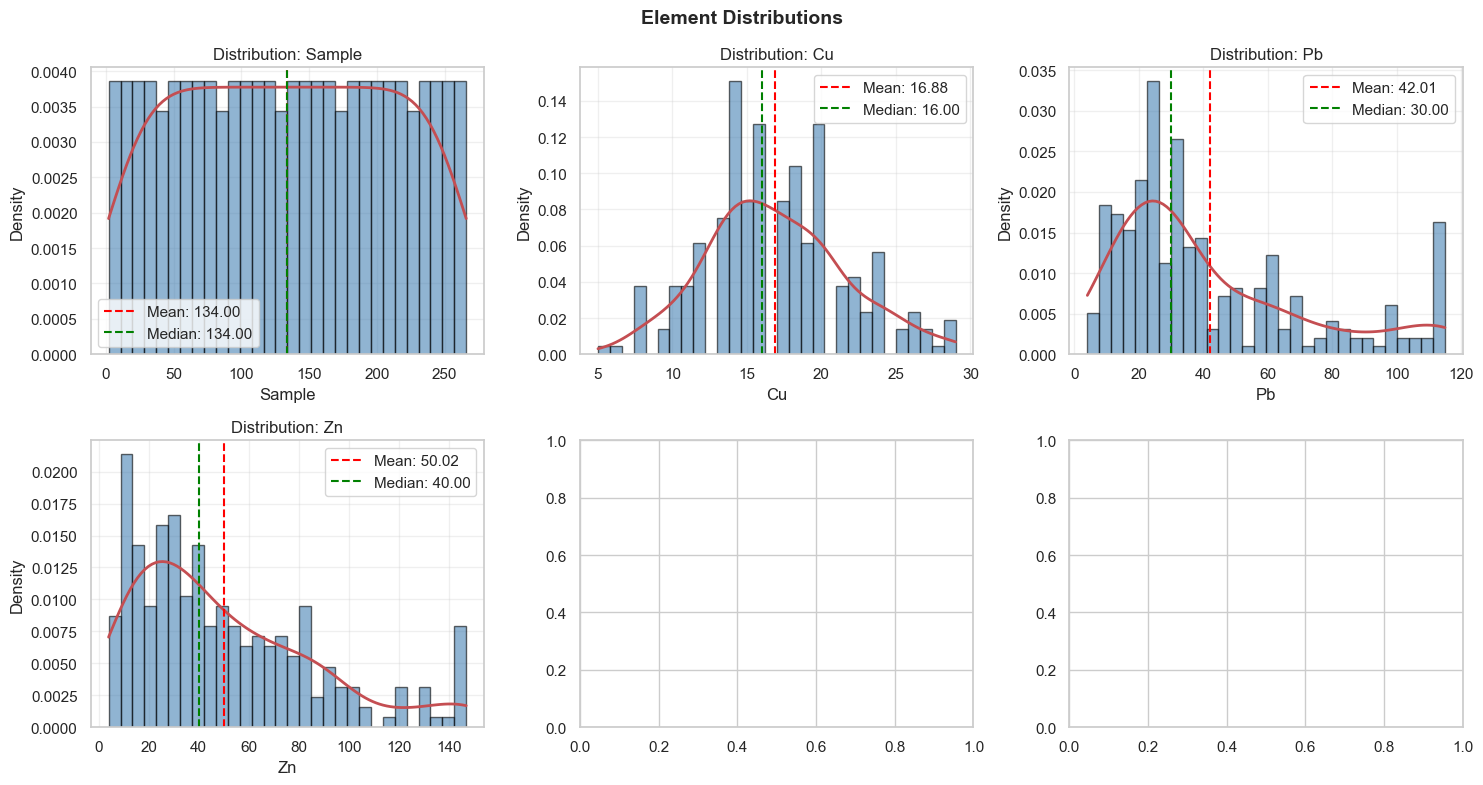

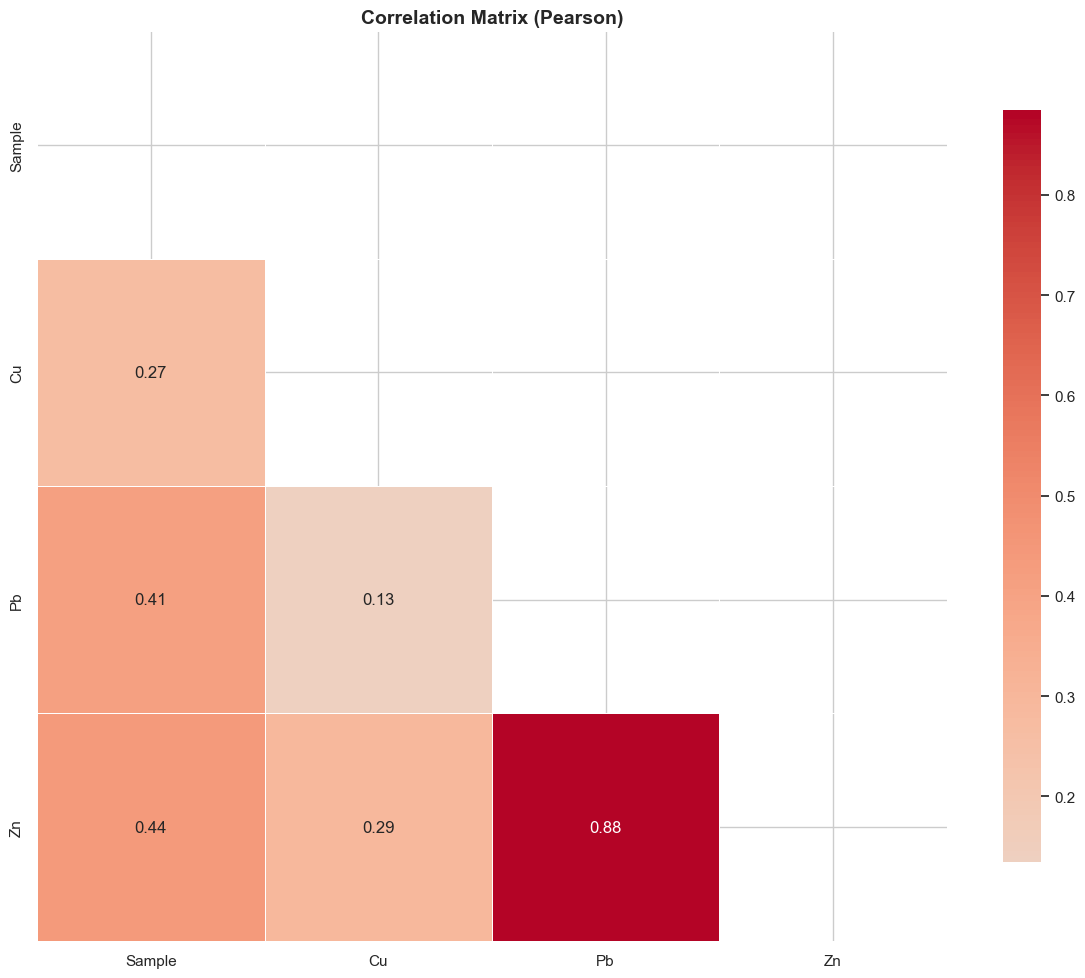

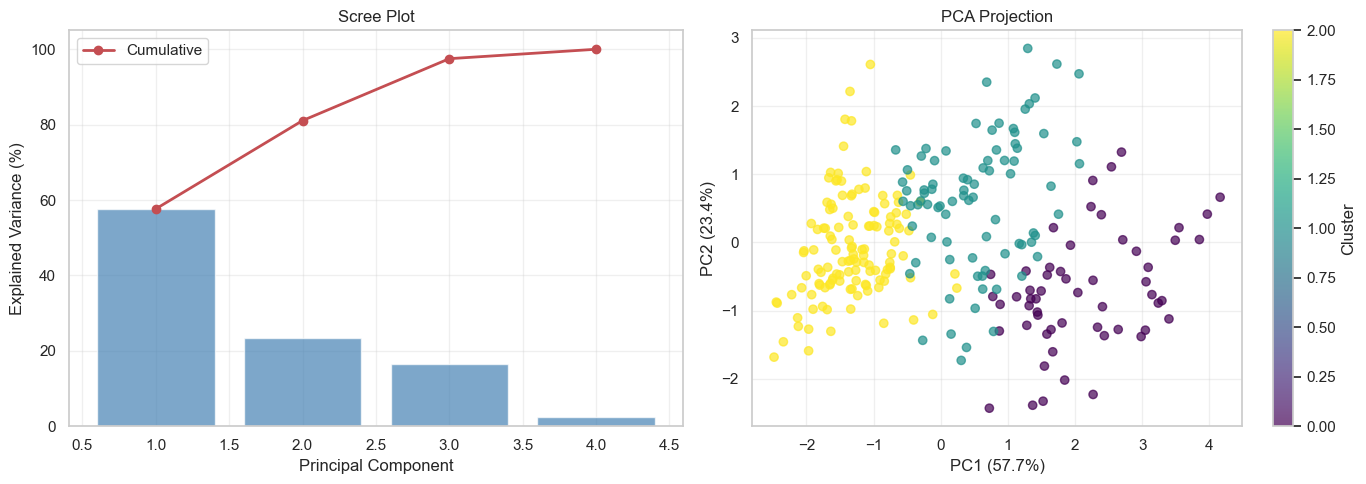

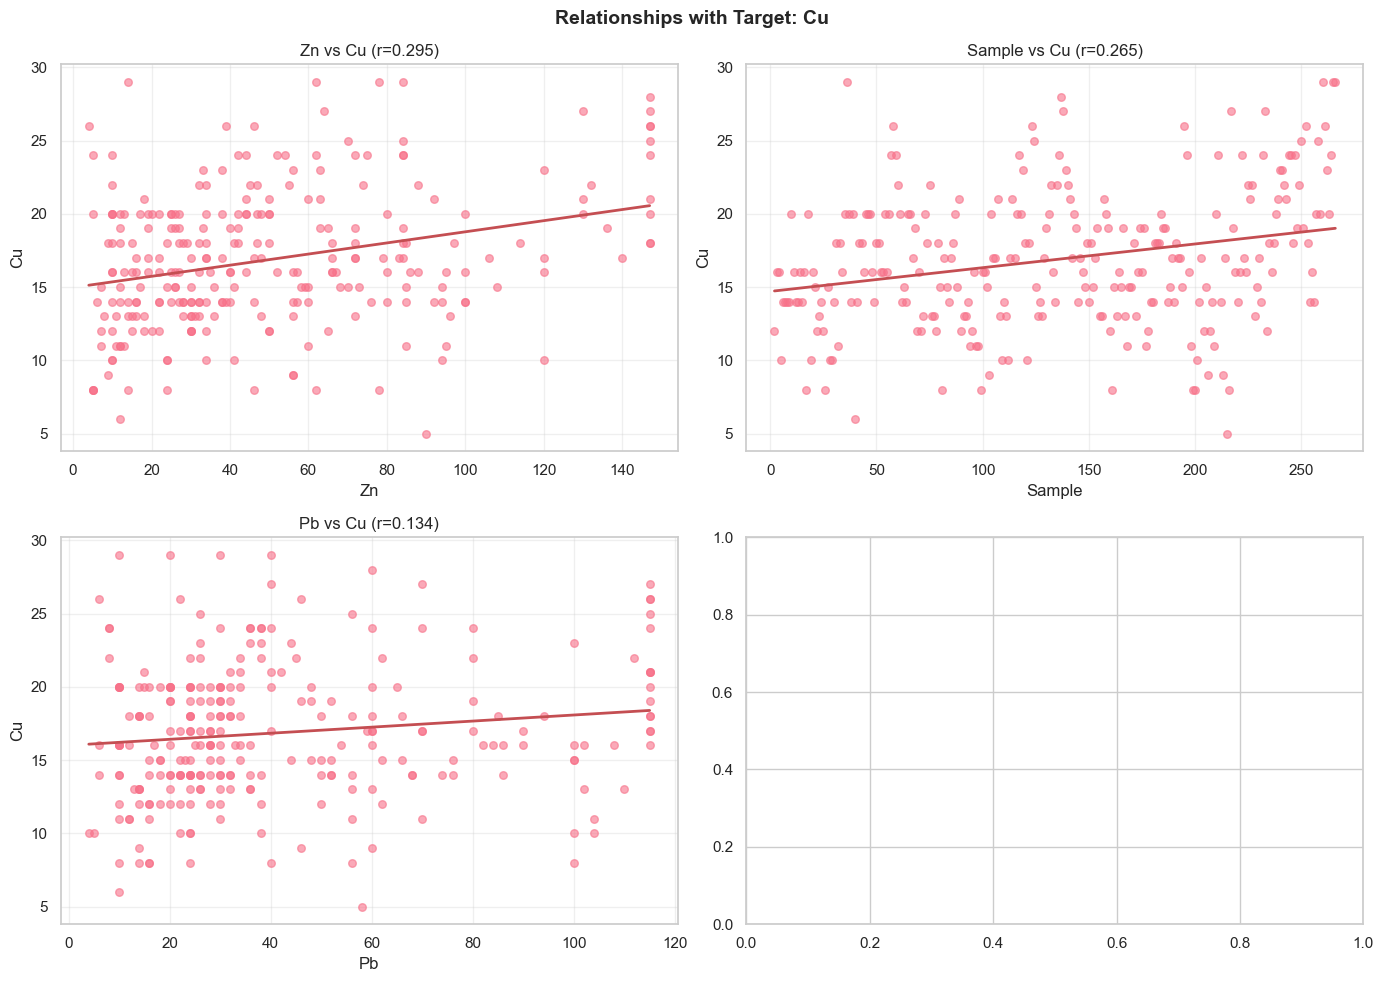

✅ Results exported to geochemical_analysis.xlsx


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# FIX: Set style with error handling
# ============================================================

try:
    plt.style.use('seaborn-v0-8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        try:
            plt.style.use('whitegrid')
        except OSError:
            print("⚠️ Using default matplotlib style")
            pass

try:
    sns.set_theme(style="whitegrid")
except:
    sns.set_style("whitegrid")

sns.set_palette("husl")

print("✅ Styles loaded successfully!")

class GeochemicalExplorer:
    """
    Complete Exploratory Geochemical Data Analysis
    """
    
    def __init__(self, df, element_columns=None, target=None):
        """
        Initialize the geochemical explorer.
        """
        self.df = df.copy()
        self.original_df = df.copy()
        self.element_columns = element_columns
        self.target = target
        self.results = {}
        
        # Clean data BEFORE identifying numeric columns
        self._clean_data_initial()
        
        # Identify numeric columns
        if self.element_columns is None:
            self.element_columns = self.df.select_dtypes(include=[np.number]).columns.tolist()
        
        # Extract data matrix
        if len(self.element_columns) > 0:
            self.X = self.df[self.element_columns].to_numpy(dtype=float)
        else:
            self.X = np.array([]).reshape(len(self.df), 0)
            print("⚠️ No numeric columns found!")
        
        self.n_samples, self.n_elements = self.X.shape if len(self.X) > 0 else (len(self.df), 0)
        
        print("=" * 70)
        print("🔬 GEOCHEMICAL EXPLORER INITIALIZED")
        print("=" * 70)
        print(f"   Samples: {self.n_samples}")
        print(f"   Elements: {self.n_elements}")
        print(f"   Columns: {self.element_columns}")
        print(f"   Target: {self.target}")
        print("-" * 60)
    
    def _clean_data_initial(self):
        """Initial data cleaning to handle 'ppm' strings."""
        for col in self.df.columns:
            if self.df[col].dtype == 'object':
                mask = self.df[col].astype(str).str.lower() == 'ppm'
                if mask.any():
                    self.df = self.df[~mask]
                    print(f"✅ Removed rows containing 'ppm' in column: {col}")
                    break
        
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        self.df = self.df.reset_index(drop=True)
    
    # ============================================================
    # 1. DATA CLEANING
    # ============================================================
    
    def clean_data(self, remove_first_row=True, handle_outliers=True):
        """
        Clean the geochemical data.
        """
        print("\n🧹 DATA CLEANING")
        print("=" * 60)
        
        if remove_first_row and len(self.df) > 0:
            self.df = self.df.iloc[1:].copy()
            self.df = self.df.reset_index(drop=True)
            print("✅ First row removed")
        
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        before = len(self.df)
        self.df = self.df.dropna()
        after = len(self.df)
        print(f"✅ Dropped {before - after} rows with missing values")
        
        if handle_outliers:
            for col in self.element_columns:
                if col in self.df.columns:
                    data = self.df[col]
                    Q1 = data.quantile(0.25)
                    Q3 = data.quantile(0.75)
                    IQR = Q3 - Q1
                    lower = Q1 - 1.5 * IQR
                    upper = Q3 + 1.5 * IQR
                    self.df[col] = data.clip(lower=lower, upper=upper)
            print("✅ Outliers capped")
        
        if len(self.element_columns) > 0:
            self.X = self.df[self.element_columns].to_numpy(dtype=float)
        else:
            self.X = np.array([]).reshape(len(self.df), 0)
        self.n_samples, self.n_elements = self.X.shape if len(self.X) > 0 else (len(self.df), 0)
        
        print(f"✅ Final shape: {self.n_samples} samples, {self.n_elements} elements")
        return self.df
    
    # ============================================================
    # 2. DESCRIPTIVE STATISTICS
    # ============================================================
    
    def descriptive_statistics(self):
        """
        Calculate comprehensive descriptive statistics.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return None
        
        print("\n📊 DESCRIPTIVE STATISTICS")
        print("=" * 60)
        
        stats_df = self.df[self.element_columns].describe().T
        stats_df['variance'] = self.df[self.element_columns].var()
        stats_df['skew'] = self.df[self.element_columns].skew()
        stats_df['kurtosis'] = self.df[self.element_columns].kurtosis()
        stats_df['cv'] = stats_df['std'] / stats_df['mean']
        
        self.results['descriptive_stats'] = stats_df
        print(stats_df.round(4))
        return stats_df
    
    # ============================================================
    # 3. VARIANCE ANALYSIS
    # ============================================================
    
    def variance_analysis(self):
        """
        Analyze variance of each element.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return None
        
        print("\n📈 VARIANCE ANALYSIS")
        print("=" * 60)
        
        variance = self.df[self.element_columns].var()
        std_dev = self.df[self.element_columns].std()
        cv = std_dev / self.df[self.element_columns].mean()
        
        variance_df = pd.DataFrame({
            'Variance': variance,
            'Std_Dev': std_dev,
            'CV': cv
        }).sort_values('Variance', ascending=False)
        
        self.results['variance'] = variance_df
        print(variance_df.round(4))
        
        high_var = variance_df[variance_df['CV'] > 1]
        if len(high_var) > 0:
            print("\n⚠️ High Variability Elements (CV > 1):")
            print(high_var)
        
        return variance_df
    
    # ============================================================
    # 4. COVARIANCE ANALYSIS
    # ============================================================
    
    def covariance_analysis(self):
        """
        Calculate covariance matrix.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for covariance analysis")
            return None
        
        print("\n📊 COVARIANCE MATRIX")
        print("=" * 60)
        
        cov_matrix = self.df[self.element_columns].cov()
        self.results['covariance'] = cov_matrix
        print(cov_matrix.round(4))
        
        strong_cov = []
        for i in range(len(cov_matrix.columns)):
            for j in range(i+1, len(cov_matrix.columns)):
                cov_val = cov_matrix.iloc[i, j]
                if abs(cov_val) > 1:
                    strong_cov.append({
                        'Elements': f"{cov_matrix.columns[i]} - {cov_matrix.columns[j]}",
                        'Covariance': cov_val
                    })
        
        if strong_cov:
            print("\n🔗 Strongest Covariances:")
            strong_df = pd.DataFrame(strong_cov).sort_values('Covariance', ascending=False)
            print(strong_df.head(5))
        
        return cov_matrix
    
    # ============================================================
    # 5. CORRELATION ANALYSIS
    # ============================================================
    
    def correlation_analysis(self):
        """
        Calculate correlations using multiple methods.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation analysis")
            return None, None, None
        
        print("\n🔗 CORRELATION ANALYSIS")
        print("=" * 60)
        
        pearson_corr = self.df[self.element_columns].corr(method='pearson')
        self.results['pearson_correlation'] = pearson_corr
        
        spearman_corr = self.df[self.element_columns].corr(method='spearman')
        self.results['spearman_correlation'] = spearman_corr
        
        kendall_corr = self.df[self.element_columns].corr(method='kendall')
        self.results['kendall_correlation'] = kendall_corr
        
        print("\n📊 Correlation Methods Comparison:")
        print(f"  Pearson:  Linear relationships (parametric)")
        print(f"  Spearman: Monotonic relationships (non-parametric)")
        print(f"  Kendall:  Ordinal relationships (non-parametric)")
        
        strong_pearson = self._find_strong_correlations(pearson_corr, 'Pearson')
        strong_spearman = self._find_strong_correlations(spearman_corr, 'Spearman')
        
        print("\n🔗 Strongest Correlations:")
        print("\nPearson (Linear):")
        for pair in strong_pearson[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        print("\nSpearman (Monotonic):")
        for pair in strong_spearman[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        return pearson_corr, spearman_corr, kendall_corr
    
    def _find_strong_correlations(self, corr_matrix, method):
        """Find strong correlations (|r| > 0.7)"""
        strong = []
        for i in range(len(corr_matrix.columns)):
            for j in range(i+1, len(corr_matrix.columns)):
                corr_val = corr_matrix.iloc[i, j]
                if abs(corr_val) > 0.7:
                    strong.append({
                        'Elements': f"{corr_matrix.columns[i]} - {corr_matrix.columns[j]}",
                        'Correlation': corr_val,
                        'Method': method
                    })
        return sorted(strong, key=lambda x: abs(x['Correlation']), reverse=True)
    
    # ============================================================
    # 6. TARGET CORRELATION
    # ============================================================
    
    def target_correlation(self, target=None):
        """
        Analyze correlations with a specific target element.
        """
        if target is None:
            target = self.target
        
        if target is None:
            print("⚠️ No target specified")
            return None
        
        if target not in self.element_columns:
            print(f"⚠️ Target '{target}' not found in data")
            return None
        
        print(f"\n🎯 TARGET CORRELATION: {target}")
        print("=" * 60)
        
        target_correlations = {}
        
        for col in self.element_columns:
            if col == target:
                continue
            pearson_r, pearson_p = pearsonr(self.df[target], self.df[col])
            spearman_r, spearman_p = spearmanr(self.df[target], self.df[col])
            kendall_r, kendall_p = kendalltau(self.df[target], self.df[col])
            
            target_correlations[col] = {
                'Pearson_r': pearson_r,
                'Pearson_p': pearson_p,
                'Spearman_r': spearman_r,
                'Spearman_p': spearman_p,
                'Kendall_r': kendall_r,
                'Kendall_p': kendall_p
            }
        
        corr_df = pd.DataFrame(target_correlations).T
        corr_df = corr_df.sort_values('Pearson_r', ascending=False)
        self.results['target_correlations'] = corr_df
        print(corr_df.round(4))
        
        strong_observers = corr_df[abs(corr_df['Pearson_r']) > 0.5]
        if len(strong_observers) > 0:
            print("\n👁️ Strong Observers (|r| > 0.5):")
            for col, row in strong_observers.iterrows():
                direction = "positive" if row['Pearson_r'] > 0 else "negative"
                print(f"  {col}: {row['Pearson_r']:.3f} ({direction})")
        
        return corr_df
    
    # ============================================================
    # 7. PCA (Principal Component Analysis)
    # ============================================================
    
    def pca_analysis(self, n_components=None):
        """
        Perform PCA for dimensionality reduction.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for PCA")
            return None, None
        
        print("\n🔄 PCA (Principal Component Analysis)")
        print("=" * 60)
        
        # Standardize data
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        if n_components is None:
            n_components = min(self.n_elements, 10)
        
        pca = PCA(n_components=n_components)
        X_pca = pca.fit_transform(X_scaled)
        
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = np.cumsum(explained_variance)
        
        self.results['pca'] = {
            'components': X_pca,
            'explained_variance': explained_variance,
            'cumulative_variance': cumulative_variance,
            'loadings': pca.components_,
            'n_components': n_components
        }
        
        print(f"\n📊 Explained Variance:")
        for i, (var, cum) in enumerate(zip(explained_variance, cumulative_variance)):
            print(f"  PC{i+1}: {var*100:.1f}% (cumulative: {cum*100:.1f}%)")
        
        n_optimal = np.argmax(cumulative_variance > 0.85) + 1
        print(f"\n🎯 Optimal number of components (85% variance): {n_optimal}")
        
        # 🔧 FIX: Convert numpy array to list for indexing
        print("\n🔍 PCA Component Interpretation (Top 3 components):")
        for i in range(min(3, n_components)):
            loadings = pca.components_[i]
            # Get indices of top 3 features
            top_indices = np.argsort(np.abs(loadings))[::-1][:3]
            # Convert indices to list of column names
            top_features = [self.element_columns[idx] for idx in top_indices]
            print(f"\n  PC{i+1}:")
            for feat in top_features:
                idx = self.element_columns.index(feat)
                print(f"    {feat}: {loadings[idx]:.3f}")
        
        return X_pca, pca
    
    # ============================================================
    # 8. CLUSTERING ANALYSIS
    # ============================================================
    
    def cluster_analysis(self, n_clusters=3):
        """
        Perform K-means clustering on the data.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for clustering")
            return None, None
        
        print(f"\n🧩 CLUSTERING ANALYSIS (K={n_clusters})")
        print("=" * 60)
        
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        clusters = kmeans.fit_predict(X_scaled)
        self.df['Cluster'] = clusters
        
        cluster_stats = self.df.groupby('Cluster')[self.element_columns].mean()
        print("\n📊 Cluster Characteristics:")
        print(cluster_stats.round(2))
        
        print("\n🔍 Distinct Element Signatures:")
        for cluster in range(n_clusters):
            cluster_data = self.df[self.df['Cluster'] == cluster][self.element_columns]
            cluster_means = cluster_data.mean()
            global_means = self.df[self.element_columns].mean()
            diff = cluster_means - global_means
            
            enriched = diff[diff > 0].sort_values(ascending=False).head(3)
            depleted = diff[diff < 0].sort_values(ascending=True).head(3)
            
            print(f"\n  Cluster {cluster} ({len(cluster_data)} samples):")
            if len(enriched) > 0:
                enriched_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in enriched.index])
                print(f"    Enriched: {enriched_str}")
            if len(depleted) > 0:
                depleted_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in depleted.index])
                print(f"    Depleted: {depleted_str}")
        
        self.results['clusters'] = kmeans
        return clusters, kmeans
    
    # ============================================================
    # 9. VISUALIZATION
    # ============================================================
    
    def plot_distributions(self, columns=None):
        """Plot distributions of elements."""
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to plot")
            return
        
        if columns is None:
            columns = self.element_columns[:6]
        
        n_cols = min(3, len(columns))
        n_rows = (len(columns) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        axes = axes.flatten() if n_rows * n_cols > 1 else [axes]
        
        for i, col in enumerate(columns):
            if i < len(axes):
                ax = axes[i]
                data = self.df[col].dropna()
                
                ax.hist(data, bins=30, density=True, alpha=0.6, color='steelblue', edgecolor='black')
                
                from scipy.stats import gaussian_kde
                if len(data) > 1:
                    kde = gaussian_kde(data)
                    x_range = np.linspace(data.min(), data.max(), 100)
                    ax.plot(x_range, kde(x_range), 'r-', linewidth=2)
                
                ax.axvline(data.mean(), color='red', linestyle='--', label=f'Mean: {data.mean():.2f}')
                ax.axvline(data.median(), color='green', linestyle='--', label=f'Median: {data.median():.2f}')
                ax.set_xlabel(col)
                ax.set_ylabel('Density')
                ax.set_title(f'Distribution: {col}')
                ax.legend()
                ax.grid(True, alpha=0.3)
        
        plt.suptitle('Element Distributions', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_correlation_matrix(self, method='pearson'):
        """Plot correlation matrix heatmap."""
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation plot")
            return
        
        corr_matrix = self.df[self.element_columns].corr(method=method)
        
        plt.figure(figsize=(12, 10))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
        sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
                   cmap='coolwarm', center=0, square=True,
                   linewidths=0.5, cbar_kws={"shrink": 0.8})
        plt.title(f'Correlation Matrix ({method.capitalize()})', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_pca(self):
        """Plot PCA results."""
        if 'pca' not in self.results:
            self.pca_analysis()
        
        if 'pca' not in self.results:
            return
        
        pca_data = self.results['pca']
        X_pca = pca_data['components']
        explained_variance = pca_data['explained_variance']
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        ax1 = axes[0]
        components = range(1, len(explained_variance) + 1)
        ax1.bar(components, explained_variance * 100, color='steelblue', alpha=0.7)
        ax1.plot(components, pca_data['cumulative_variance'] * 100, 
                'ro-', linewidth=2, label='Cumulative')
        ax1.set_xlabel('Principal Component')
        ax1.set_ylabel('Explained Variance (%)')
        ax1.set_title('Scree Plot')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        ax2 = axes[1]
        if X_pca.shape[1] >= 2:
            if 'Cluster' in self.df.columns:
                scatter = ax2.scatter(X_pca[:, 0], X_pca[:, 1], 
                                    c=self.df['Cluster'], cmap='viridis', alpha=0.7)
                plt.colorbar(scatter, ax=ax2, label='Cluster')
            else:
                ax2.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=30)
            ax2.set_xlabel(f'PC1 ({explained_variance[0]*100:.1f}%)')
            ax2.set_ylabel(f'PC2 ({explained_variance[1]*100:.1f}%)')
            ax2.set_title('PCA Projection')
            ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_target_relationships(self, target=None):
        """Plot relationships with target element."""
        if target is None:
            target = self.target
        
        if target is None or target not in self.element_columns:
            print("⚠️ No valid target specified")
            return
        
        if 'target_correlations' in self.results:
            corr_df = self.results['target_correlations']
            top_corr = corr_df.nlargest(4, 'Pearson_r').index.tolist()
        else:
            top_corr = [col for col in self.element_columns if col != target][:4]
        
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes = axes.flatten()
        
        for i, col in enumerate(top_corr[:4]):
            ax = axes[i]
            ax.scatter(self.df[col], self.df[target], alpha=0.6, s=30)
            
            z = np.polyfit(self.df[col], self.df[target], 1)
            p = np.poly1d(z)
            x_line = np.linspace(self.df[col].min(), self.df[col].max(), 100)
            ax.plot(x_line, p(x_line), 'r-', linewidth=2)
            
            corr = pearsonr(self.df[col], self.df[target])[0]
            ax.set_xlabel(col)
            ax.set_ylabel(target)
            ax.set_title(f'{col} vs {target} (r={corr:.3f})')
            ax.grid(True, alpha=0.3)
        
        plt.suptitle(f'Relationships with Target: {target}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    # ============================================================
    # 10. COMPLETE REPORT
    # ============================================================
    
    def full_report(self):
        """
        Generate a complete analysis report.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return
        
        print("\n" + "█" * 70)
        print("📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT")
        print("█" * 70)
        
        print("\n📁 DATASET OVERVIEW:")
        print(f"  Samples: {self.n_samples}")
        print(f"  Elements: {self.n_elements}")
        print(f"  Columns: {self.element_columns}")
        
        self.descriptive_statistics()
        self.variance_analysis()
        self.correlation_analysis()
        
        if self.target:
            self.target_correlation()
        
        self.pca_analysis()
        self.cluster_analysis()
        
        print("\n" + "█" * 70)
        print("✅ REPORT COMPLETE")
        print("█" * 70)
    
    # ============================================================
    # 11. EXPORT
    # ============================================================
    
    def export_results(self, filename="geochemical_analysis.xlsx"):
        """Export results to Excel."""
        with pd.ExcelWriter(filename) as writer:
            for key, value in self.results.items():
                if isinstance(value, pd.DataFrame):
                    value.to_excel(writer, sheet_name=key[:31])
        
        print(f"✅ Results exported to {filename}")


# ============================================================
# DEMONSTRATION
# ============================================================

if __name__ == "__main__":
    
    print("📊 Loading data...")
    df = pd.read_csv('Brazildata.csv', encoding='cp1252')
    
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print("\nFirst 5 rows:")
    print(df.head())
    
    # Initialize explorer
    explorer = GeochemicalExplorer(df, target='Cu')
    
    # Clean data
    explorer.clean_data(remove_first_row=True, handle_outliers=True)
    
    # Full analysis
    explorer.full_report()
    
    # Visualizations
    explorer.plot_distributions()
    explorer.plot_correlation_matrix('pearson')
    explorer.plot_pca()
    explorer.plot_target_relationships()
    
    # Export results
    explorer.export_results()

In [5]:
import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt - handle both PyQt5 and PyQt6
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

# ============================================================
# PART 1: UNIVERSAL DATA CLEANING ENGINE
# ============================================================

def clean_any_data(path, sheet_name=None, **kwargs):
    """Universal data cleaner that handles any file format and structure."""
    print(f"\n📁 READING FILE: {os.path.basename(path)}")
    print("=" * 70)
    
    file_ext = Path(path).suffix.lower()
    df = None
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        df = read_excel_file(path, sheet_name)
        if df is None:
            return None
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        df = read_text_file(path, encodings, **kwargs)
        if df is None or df.empty:
            df = manual_parse_text_file(path)
    else:
        print(f"⚠️ Unknown file type: {file_ext}")
        df = manual_parse_text_file(path)
    
    if df is None or df.empty:
        print("❌ Could not read file")
        return None
    
    print(f"📊 Raw data shape: {df.shape}")
    df = clean_dataframe(df)
    print(f"\n✅ Final shape: {df.shape}")
    return df

def read_excel_file(path, sheet_name):
    try:
        df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
        print("✅ Read as Excel file (openpyxl)")
        return df
    except:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
            print("✅ Read as Excel file (xlrd)")
            return df
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            return None

def read_text_file(path, encodings, **kwargs):
    delimiters = [';', ',', '\t', '|', ' ']
    for encoding in encodings:
        for delim in delimiters:
            try:
                df = pd.read_csv(path, sep=delim, encoding=encoding, engine='python', on_bad_lines='skip', **kwargs)
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except:
                continue
    return None

def manual_parse_text_file(path):
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        try:
            with open(path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
        except:
            return None
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return None
    
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        df = pd.DataFrame(data)
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    return None

def clean_dataframe(df):
    if df is None or df.empty:
        return df
    df = split_single_column(df)
    df = clean_column_names(df)
    df = remove_header_rows(df)
    df = standardize_missing_values(df)
    df = clean_numeric_columns(df)
    df = clean_text_columns(df)
    df = remove_empty(df)
    return df

def split_single_column(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col_name = df.columns[0]
    col_data = df[col_name].astype(str)
    sample = col_data.iloc[0] if len(col_data) > 0 else ''
    delimiters = [';', ',', '\t', '|']
    for delim in delimiters:
        if delim in sample:
            split_data = col_data.str.split(delim, expand=True)
            try:
                pd.to_numeric(split_data.iloc[0, 0])
                split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
            except:
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                headers = [str(h).strip() for h in headers]
                split_data.columns = headers
            return split_data.reset_index(drop=True)
    return df

def clean_column_names(df):
    if df is None or df.empty:
        return df
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$', na=False)]
    df.columns = [f'col_{i}' if str(col).strip() == '' or pd.isna(col) else col for i, col in enumerate(df.columns)]
    df.columns = [re.sub(r'[^a-zA-Z0-9_ ]', '_', str(col)).strip('_') for col in df.columns]
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

def remove_header_rows(df):
    if df is None or df.empty or len(df) == 0:
        return df
    first_row = df.iloc[0].astype(str)
    header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 'value', 'measurement', 'parameter', 'unit', 'ppm']
    header_score = sum(1 for val in first_row if any(keyword in str(val).lower() for keyword in header_keywords))
    if len(first_row) > 0 and header_score / len(first_row) > 0.3:
        df = df.iloc[1:].reset_index(drop=True)
    return df

def standardize_missing_values(df):
    if df is None or df.empty:
        return df
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    for col in df.columns:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
            df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    return df

def clean_numeric_columns(df):
    if df is None or df.empty:
        return df
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 'lithology', 'description', 'comment', 'remarks', 'unit', 'method', 'date', 'time']
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        x = re.sub(r'[^\d.\-eE+]', '', x)
        try:
            return float(x)
        except:
            return np.nan
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    return df

def clean_text_columns(df):
    if df is None or df.empty:
        return df
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    return df

def remove_empty(df):
    if df is None or df.empty:
        return df
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    return df

# ============================================================
# PART 2: STATISTICAL ANALYSIS ENGINE
# ============================================================

class StatisticalAnalyzer:
    """Comprehensive statistical analysis for geochemical data"""
    
    def __init__(self, df):
        self.df = df
        self.numeric_df = df.select_dtypes(include=[np.number])
        self.results = {}
        self.run_all_analyses()
    
    def run_all_analyses(self):
        """Run all statistical analyses"""
        self.calculate_variance()
        self.calculate_covariance()
        self.calculate_correlation()
        self.calculate_eigen()
        self.perform_pca()
        self.standardize_data()
        self.exploratory_analysis()
    
    def calculate_variance(self):
        """Calculate variance for all numeric columns"""
        self.results['variance'] = self.numeric_df.var()
        self.results['variance_dict'] = self.numeric_df.var().to_dict()
        self.results['std'] = self.numeric_df.std()
        self.results['mean'] = self.numeric_df.mean()
        self.results['median'] = self.numeric_df.median()
    
    def calculate_covariance(self):
        """Calculate covariance matrix"""
        self.results['covariance_matrix'] = self.numeric_df.cov()
        # Handle missing values by dropping rows with NaN
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['cov_matrix_clean'] = clean_data.cov()
        else:
            self.results['cov_matrix_clean'] = None
    
    def calculate_correlation(self):
        """Calculate correlation matrix"""
        self.results['correlation_matrix'] = self.numeric_df.corr()
        # Handle missing values
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['corr_matrix_clean'] = clean_data.corr()
        else:
            self.results['corr_matrix_clean'] = None
    
    def calculate_eigen(self):
        """Calculate eigenvalues and eigenvectors"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            self.results['eigenvalues'] = None
            self.results['eigenvectors'] = None
            return
        
        try:
            cov = clean_data.cov().values
            eigenvals, eigenvecs = np.linalg.eig(cov)
            
            # Sort by eigenvalues (largest first)
            idx = np.argsort(eigenvals)[::-1]
            eigenvals = eigenvals[idx]
            eigenvecs = eigenvecs[:, idx]
            
            self.results['eigenvalues'] = eigenvals
            self.results['eigenvectors'] = eigenvecs
            self.results['explained_variance'] = eigenvals / eigenvals.sum() * 100
        except Exception as e:
            self.results['eigenvalues'] = None
            self.results['eigenvectors'] = None
            print(f"⚠️ Eigen decomposition failed: {e}")
    
    def perform_pca(self):
        """Perform Principal Component Analysis"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2 or self.results['eigenvectors'] is None:
            self.results['pca_scores'] = None
            self.results['pca_loadings'] = None
            return
        
        try:
            # Center the data
            centered = clean_data - clean_data.mean()
            # Project data onto principal components
            pca_scores = centered @ self.results['eigenvectors']
            self.results['pca_scores'] = pca_scores
            self.results['pca_loadings'] = self.results['eigenvectors']
            self.results['pca_columns'] = [f'PC{i+1}' for i in range(pca_scores.shape[1])]
            self.results['pca_df'] = pd.DataFrame(pca_scores, columns=self.results['pca_columns'])
            
            # Add sample names if available
            if 'Sample' in self.df.columns:
                self.results['pca_df']['Sample'] = self.df['Sample'].iloc[clean_data.index].values
        except Exception as e:
            print(f"⚠️ PCA failed: {e}")
    
    def standardize_data(self):
        """Standardize data (Z-score normalization)"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 0:
            self.results['standardized'] = (clean_data - clean_data.mean()) / clean_data.std()
            self.results['min_max_scaled'] = (clean_data - clean_data.min()) / (clean_data.max() - clean_data.min())
    
    def exploratory_analysis(self):
        """Full exploratory data analysis"""
        clean_data = self.numeric_df.dropna()
        self.results['eda'] = {}
        
        # Shape info
        self.results['eda']['shape'] = self.df.shape
        self.results['eda']['numeric_shape'] = self.numeric_df.shape
        
        # Missing values
        self.results['eda']['missing'] = self.df.isnull().sum()
        self.results['eda']['missing_pct'] = self.df.isnull().sum() / len(self.df) * 100
        
        # Skewness and kurtosis
        self.results['eda']['skewness'] = self.numeric_df.skew()
        self.results['eda']['kurtosis'] = self.numeric_df.kurtosis()
        
        # Quantiles
        self.results['eda']['quantiles'] = self.numeric_df.quantile([0.25, 0.5, 0.75])
        
        # Correlation summary
        if len(self.numeric_df.columns) > 1:
            corr = self.numeric_df.corr()
            self.results['eda']['correlation_summary'] = {
                'max_corr': corr.max().max(),
                'min_corr': corr.min().min(),
                'high_corr_pairs': [(col1, col2, corr.loc[col1, col2]) 
                                   for i, col1 in enumerate(corr.columns)
                                   for col2 in corr.columns[i+1:]
                                   if abs(corr.loc[col1, col2]) > 0.7]
            }
    
    def get_summary(self):
        """Get summary statistics"""
        return {
            'variance': self.results.get('variance_dict', {}),
            'mean': self.results.get('mean', {}),
            'std': self.results.get('std', {}),
            'correlation_matrix': self.results.get('correlation_matrix', None),
            'eigenvalues': self.results.get('eigenvalues', None),
            'eigenvectors': self.results.get('eigenvectors', None),
            'explained_variance': self.results.get('explained_variance', None),
            'pca_scores': self.results.get('pca_df', None),
            'missing_values': self.results.get('eda', {}).get('missing', None),
            'skewness': self.results.get('eda', {}).get('skewness', None)
        }
    
    def get_pca_report(self, n_components=2):
        """Get a detailed PCA report"""
        if self.results['pca_scores'] is None:
            return "PCA could not be performed. Check your data."
        
        report = []
        report.append("="*70)
        report.append("PRINCIPAL COMPONENT ANALYSIS (PCA) REPORT")
        report.append("="*70)
        
        report.append(f"\nNumber of samples: {self.results['pca_scores'].shape[0]}")
        report.append(f"Number of variables: {self.results['pca_scores'].shape[1]}")
        
        report.append("\nEigenvalues and Explained Variance:")
        report.append("-"*40)
        for i in range(len(self.results['eigenvalues'])):
            ev = self.results['eigenvalues'][i]
            ev_pct = self.results['explained_variance'][i]
            cum_pct = self.results['explained_variance'][:i+1].sum()
            report.append(f"  PC{i+1}: λ = {ev:.4f}  ({ev_pct:.1f}%  cumulative: {cum_pct:.1f}%)")
        
        report.append("\nFirst 3 Principal Component Loadings:")
        report.append("-"*40)
        variables = self.numeric_df.dropna().columns.tolist()
        for i in range(min(3, self.results['eigenvectors'].shape[1])):
            report.append(f"  PC{i+1}:")
            for j, var in enumerate(variables):
                loading = self.results['eigenvectors'][j, i]
                report.append(f"    {var}: {loading:.4f}")
        
        return "\n".join(report)
    
    def get_eda_report(self):
        """Get a full EDA report"""
        if self.results['eda'] is None:
            return "EDA could not be performed. Check your data."
        
        report = []
        report.append("="*70)
        report.append("EXPLORATORY DATA ANALYSIS (EDA) REPORT")
        report.append("="*70)
        
        report.append(f"\nDataset Shape: {self.results['eda']['shape'][0]} rows × {self.results['eda']['shape'][1]} columns")
        report.append(f"Numeric Columns: {self.results['eda']['numeric_shape'][1]} columns")
        
        report.append("\nMissing Values Summary:")
        report.append("-"*40)
        missing = self.results['eda']['missing']
        missing_pct = self.results['eda']['missing_pct']
        for col in missing.index:
            if missing[col] > 0:
                report.append(f"  {col}: {missing[col]} ({missing_pct[col]:.1f}%)")
        
        report.append("\nSkewness (measure of asymmetry):")
        report.append("-"*40)
        skewness = self.results['eda']['skewness']
        for col, val in skewness.items():
            if not pd.isna(val):
                report.append(f"  {col}: {val:.4f} {'(highly skewed)' if abs(val) > 1 else '(moderately skewed)' if abs(val) > 0.5 else '(approximately symmetric)'}")
        
        report.append("\nKurtosis (measure of tailedness):")
        report.append("-"*40)
        kurtosis = self.results['eda']['kurtosis']
        for col, val in kurtosis.items():
            if not pd.isna(val):
                report.append(f"  {col}: {val:.4f} {'(heavy tails)' if val > 3 else '(light tails)'}")
        
        return "\n".join(report)

# ============================================================
# PART 3: GUI APPLICATION
# ============================================================

class GeochemicalCleaner(QMainWindow):
    """Main application window for geochemical data cleaning and analysis."""
    
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.current_file = None
        self.cleaning_log = []
        self.analyzer = None
        self.init_ui()
        self.init_analysis_tabs()
        
    def init_ui(self):
        self.setWindowTitle("🧪 Geochemical Data Cleaner Pro v3.0 - Full EDA & PCA")
        self.setGeometry(100, 100, 1400, 900)
        
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        main_layout = QVBoxLayout()
        central_widget.setLayout(main_layout)
        
        # Toolbar
        toolbar = self.addToolBar("Main")
        toolbar.setIconSize(QSize(32, 32))
        
        upload_action = QAction("📁 Upload", self)
        upload_action.triggered.connect(self.upload_file)
        toolbar.addAction(upload_action)
        
        clean_action = QAction("🧹 Clean", self)
        clean_action.triggered.connect(self.clean_data)
        toolbar.addAction(clean_action)
        
        analyze_action = QAction("📊 Analyze", self)
        analyze_action.triggered.connect(self.run_analysis)
        toolbar.addAction(analyze_action)
        
        export_action = QAction("💾 Export", self)
        export_action.triggered.connect(self.export_data)
        toolbar.addAction(export_action)
        
        toolbar.addSeparator()
        
        pca_action = QAction("📉 PCA Report", self)
        pca_action.triggered.connect(self.show_pca_report)
        toolbar.addAction(pca_action)
        
        eda_action = QAction("📈 EDA Report", self)
        eda_action.triggered.connect(self.show_eda_report)
        toolbar.addAction(eda_action)
        
        # Info label
        self.info_label = QLabel("📋 No data loaded. Click 'Upload' to begin.")
        self.info_label.setStyleSheet("font-size: 14px; font-weight: bold; padding: 15px; background-color: #f0f0f0; border-radius: 8px;")
        main_layout.addWidget(self.info_label)
        
        # Tab widget
        self.tab_widget = QTabWidget()
        main_layout.addWidget(self.tab_widget)
        
        # Data tab
        self.data_tab = QWidget()
        self.tab_widget.addTab(self.data_tab, "📊 Data")
        data_layout = QVBoxLayout()
        self.data_tab.setLayout(data_layout)
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.setSortingEnabled(True)
        data_layout.addWidget(self.table)
        
        # Column info tab
        self.col_tab = QWidget()
        self.tab_widget.addTab(self.col_tab, "📋 Column Info")
        col_layout = QVBoxLayout()
        self.col_tab.setLayout(col_layout)
        self.col_table = QTableWidget()
        col_layout.addWidget(self.col_table)
        
        # Log tab
        self.log_tab = QWidget()
        self.tab_widget.addTab(self.log_tab, "📝 Log")
        log_layout = QVBoxLayout()
        self.log_tab.setLayout(log_layout)
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        self.log_text.setFont(QFont("Consolas", 10))
        log_layout.addWidget(self.log_text)
        
        # Stats tab
        self.stats_tab = QWidget()
        self.tab_widget.addTab(self.stats_tab, "📊 Statistics")
        stats_layout = QVBoxLayout()
        self.stats_tab.setLayout(stats_layout)
        self.stats_text = QTextEdit()
        self.stats_text.setReadOnly(True)
        self.stats_text.setFont(QFont("Consolas", 10))
        stats_layout.addWidget(self.stats_text)
        
        # Status bar
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("✅ Ready")
        
        # Progress bar
        self.progress = QProgressBar()
        self.progress.setVisible(False)
        self.statusBar.addPermanentWidget(self.progress)
        
        self.setStyleSheet("""
            QMainWindow { background-color: #f5f5f5; }
            QTableWidget { background-color: white; gridline-color: #d0d0d0; alternate-background-color: #fafafa; }
            QTableWidget::item:selected { background-color: #4CAF50; color: white; }
            QHeaderView::section { background-color: #e0e0e0; padding: 5px; font-weight: bold; }
            QPushButton { background-color: #2196F3; color: white; padding: 8px 15px; border-radius: 4px; border: none; }
            QPushButton:hover { background-color: #1976D2; }
            QTabWidget::pane { border: 1px solid #d0d0d0; border-radius: 4px; }
            QTabBar::tab { padding: 8px 15px; margin-right: 2px; border-top-left-radius: 4px; border-top-right-radius: 4px; }
            QTabBar::tab:selected { background-color: #2196F3; color: white; }
        """)
        
        self.add_log("🔬 Geochemical Data Cleaner Pro v3.0 initialized")
        self.add_log("📌 Ready for data upload and full EDA")
    
    def init_analysis_tabs(self):
        # This will be populated when data is loaded
        pass
    
    def add_log(self, message):
        from datetime import datetime
        timestamp = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{timestamp}] {message}")
        self.cleaning_log.append(message)
    
    def upload_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt);;TSV (*.tsv)"
        )
        if file_path:
            self.current_file = file_path
            self.add_log(f"📁 Loading: {os.path.basename(file_path)}")
            self.statusBar.showMessage(f"Loading: {os.path.basename(file_path)}...")
            self.progress.setVisible(True)
            self.progress.setRange(0, 0)
            
            try:
                self.df = clean_any_data(file_path)
                self.progress.setVisible(False)
                
                if self.df is not None and not self.df.empty:
                    self.cleaned_df = self.df.copy()
                    self.display_data()
                    self.update_column_info()
                    self.show_basic_stats()
                    
                    self.add_log(f"✅ Loaded: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                    self.statusBar.showMessage(f"✅ Loaded: {os.path.basename(file_path)}")
                    self.info_label.setText(f"📊 Data loaded: {self.df.shape[0]} rows × {self.df.shape[1]} columns")
                    
                    QMessageBox.information(self, "Success", 
                        f"File loaded!\n\n📊 Shape: {self.df.shape[0]} rows × {self.df.shape[1]} columns\n"
                        f"📋 Numeric columns: {len(self.df.select_dtypes(include=[np.number]).columns)}")
                else:
                    self.add_log("❌ Failed to read file")
                    QMessageBox.warning(self, "Error", "No data could be read.")
                    self.statusBar.showMessage("❌ Error loading file")
                    
            except Exception as e:
                self.progress.setVisible(False)
                self.add_log(f"❌ Error: {str(e)}")
                QMessageBox.critical(self, "Error", f"Failed to load:\n{str(e)}")
                self.statusBar.showMessage("❌ Error loading file")
    
    def clean_data(self):
        if self.df is None or self.df.empty:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
        
        self.add_log("🧹 Starting data cleaning...")
        self.statusBar.showMessage("Cleaning data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            self.cleaned_df = clean_dataframe(self.df.copy())
            self.progress.setVisible(False)
            self.display_data(self.cleaned_df)
            self.update_column_info()
            self.show_basic_stats()
            
            rows_removed = len(self.df) - len(self.cleaned_df)
            self.add_log(f"✅ Cleaning complete: {len(self.cleaned_df)} rows, {len(self.cleaned_df.columns)} columns")
            self.add_log(f"🗑️ Removed {rows_removed} rows")
            self.statusBar.showMessage(f"✅ Cleaned: {len(self.cleaned_df)} rows")
            self.info_label.setText(f"🧹 Cleaned: {len(self.cleaned_df)} rows × {len(self.cleaned_df.columns)} columns")
            
            QMessageBox.information(self, "Success", 
                f"Cleaning complete!\n\n📊 Before: {len(self.df)} rows\n📊 After: {len(self.cleaned_df)} rows\n"
                f"🗑️ Removed: {rows_removed} rows")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Cleaning error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
    
    def run_analysis(self):
        """Run comprehensive statistical analysis"""
        if self.cleaned_df is None or self.cleaned_df.empty:
            if self.df is None or self.df.empty:
                QMessageBox.warning(self, "Warning", "Please load data first!")
                return
            df_to_analyze = self.df
        else:
            df_to_analyze = self.cleaned_df
        
        self.add_log("📊 Starting statistical analysis...")
        self.statusBar.showMessage("Analyzing data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            self.analyzer = StatisticalAnalyzer(df_to_analyze)
            self.progress.setVisible(False)
            
            # Display results
            self.display_statistics()
            self.display_pca_results()
            
            self.add_log("✅ Analysis complete!")
            self.statusBar.showMessage("✅ Analysis complete")
            
            QMessageBox.information(self, "Success", 
                "Statistical analysis completed!\n\n"
                f"📊 Numeric columns analyzed: {len(self.analyzer.numeric_df.columns)}\n"
                f"📈 Variance calculated\n"
                f"📉 Correlation matrix computed\n"
                f"📊 PCA performed\n"
                f"📋 Full EDA completed")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Analysis error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Analysis failed:\n{str(e)}")
    
    def display_data(self, df=None):
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
        
        display_limit = min(1000, len(df))
        self.table.setRowCount(display_limit)
        self.table.setColumnCount(len(df.columns))
        self.table.setHorizontalHeaderLabels(df.columns.astype(str))
        
        for i in range(display_limit):
            for j, col in enumerate(df.columns):
                val = df.iloc[i, j]
                if pd.isna(val):
                    self.table.setItem(i, j, QTableWidgetItem(""))
                else:
                    self.table.setItem(i, j, QTableWidgetItem(str(val)))
        
        self.table.resizeColumnsToContents()
    
    def update_column_info(self):
        if self.cleaned_df is None and self.df is None:
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        self.col_table.setRowCount(len(df.columns))
        self.col_table.setColumnCount(6)
        self.col_table.setHorizontalHeaderLabels(["Column", "Type", "Non-Null", "Null %", "Unique", "Sample"])
        
        for i, col in enumerate(df.columns):
            self.col_table.setItem(i, 0, QTableWidgetItem(str(col)))
            self.col_table.setItem(i, 1, QTableWidgetItem(str(df[col].dtype)))
            non_null = df[col].count()
            null_pct = (1 - non_null / len(df)) * 100
            self.col_table.setItem(i, 2, QTableWidgetItem(str(non_null)))
            self.col_table.setItem(i, 3, QTableWidgetItem(f"{null_pct:.1f}%"))
            self.col_table.setItem(i, 4, QTableWidgetItem(str(df[col].nunique())))
            if non_null > 0:
                sample = str(df[col].dropna().iloc[0]) if len(df[col].dropna()) > 0 else ""
                self.col_table.setItem(i, 5, QTableWidgetItem(sample[:50]))
            else:
                self.col_table.setItem(i, 5, QTableWidgetItem(""))
        
        self.col_table.resizeColumnsToContents()
    
    def show_basic_stats(self):
        """Display basic statistics"""
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        if df is None:
            return
        
        stats_text = f"📊 DATASET SUMMARY\n{'='*50}\n\n"
        stats_text += f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n"
        stats_text += f"Numeric columns: {len(df.select_dtypes(include=[np.number]).columns)}\n"
        stats_text += f"Text columns: {len(df.select_dtypes(include=['object']).columns)}\n\n"
        
        numeric_df = df.select_dtypes(include=[np.number])
        if len(numeric_df.columns) > 0:
            stats_text += f"NUMERIC STATISTICS:\n"
            stats_text += numeric_df.describe().to_string()
            stats_text += f"\n\nMissing values:\n"
            stats_text += numeric_df.isnull().sum().to_string()
        
        self.stats_text.setText(stats_text)
    
    def display_statistics(self):
        """Display detailed statistics in the stats tab"""
        if self.analyzer is None:
            return
        
        stats = []
        stats.append("="*70)
        stats.append("COMPREHENSIVE STATISTICAL ANALYSIS")
        stats.append("="*70)
        
        # Basic stats
        stats.append("\n📊 BASIC STATISTICS:")
        stats.append("-"*40)
        stats.append(f"Total samples: {len(self.analyzer.df)}")
        stats.append(f"Total variables: {len(self.analyzer.df.columns)}")
        stats.append(f"Numeric variables: {len(self.analyzer.numeric_df.columns)}")
        
        # Variance
        if self.analyzer.results.get('variance_dict'):
            stats.append("\n📈 VARIANCE (measure of spread):")
            stats.append("-"*40)
            for col, val in self.analyzer.results['variance_dict'].items():
                stats.append(f"  {col}: {val:.6f}")
        
        # Correlation matrix
        if self.analyzer.results.get('correlation_matrix') is not None:
            stats.append("\n📉 CORRELATION MATRIX (top 5 strong correlations):")
            stats.append("-"*40)
            corr = self.analyzer.results['correlation_matrix']
            correlations = []
            for i, col1 in enumerate(corr.columns):
                for col2 in corr.columns[i+1:]:
                    val = corr.loc[col1, col2]
                    if abs(val) > 0.5:
                        correlations.append((col1, col2, val))
            correlations.sort(key=lambda x: abs(x[2]), reverse=True)
            for col1, col2, val in correlations[:10]:
                strength = "strong" if abs(val) > 0.7 else "moderate"
                direction = "positive" if val > 0 else "negative"
                stats.append(f"  {col1} ↔ {col2}: {val:.4f} ({direction} {strength})")
        
        # Eigenvalues
        if self.analyzer.results.get('eigenvalues') is not None:
            stats.append("\n🎯 EIGENVALUES (variance captured):")
            stats.append("-"*40)
            for i, val in enumerate(self.analyzer.results['eigenvalues']):
                pct = self.analyzer.results['explained_variance'][i]
                stats.append(f"  PC{i+1}: {val:.4f} ({pct:.1f}% of variance)")
        
        # Skewness
        if self.analyzer.results.get('eda', {}).get('skewness') is not None:
            stats.append("\n📊 SKEWNESS (distribution asymmetry):")
            stats.append("-"*40)
            skew = self.analyzer.results['eda']['skewness']
            for col, val in skew.items():
                if not pd.isna(val):
                    shape = "highly skewed" if abs(val) > 1 else "moderately skewed" if abs(val) > 0.5 else "symmetric"
                    stats.append(f"  {col}: {val:.4f} ({shape})")
        
        self.stats_text.setText("\n".join(stats))
    
    def display_pca_results(self):
        """Display PCA results"""
        if self.analyzer is None or self.analyzer.results.get('pca_scores') is None:
            return
        
        pca_report = self.analyzer.get_pca_report()
        current_text = self.stats_text.toPlainText()
        self.stats_text.setText(current_text + "\n\n" + pca_report)
    
    def show_pca_report(self):
        """Show PCA report in a dialog"""
        if self.analyzer is None:
            QMessageBox.warning(self, "Warning", "Please run analysis first!")
            return
        
        report = self.analyzer.get_pca_report()
        dialog = QDialog(self)
        dialog.setWindowTitle("PCA Report")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 10))
        text_edit.setText(report)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def show_eda_report(self):
        """Show EDA report in a dialog"""
        if self.analyzer is None:
            QMessageBox.warning(self, "Warning", "Please run analysis first!")
            return
        
        report = self.analyzer.get_eda_report()
        dialog = QDialog(self)
        dialog.setWindowTitle("EDA Report")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 10))
        text_edit.setText(report)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def export_data(self):
        if self.cleaned_df is None and self.df is None:
            QMessageBox.warning(self, "Warning", "No data to export!")
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        file_path, _ = QFileDialog.getSaveFileName(
            self, "Save Data", "cleaned_geochemical_data.csv",
            "CSV (*.csv);;Excel (*.xlsx);;All Files (*)"
        )
        
        if file_path:
            try:
                if file_path.endswith('.csv'):
                    df.to_csv(file_path, sep=';', index=False, encoding='utf-8-sig')
                elif file_path.endswith('.xlsx'):
                    df.to_excel(file_path, index=False)
                else:
                    df.to_csv(file_path + '.csv', sep=';', index=False, encoding='utf-8-sig')
                
                self.add_log(f"✅ Exported: {file_path}")
                QMessageBox.information(self, "Success", f"Data exported to:\n{file_path}")
                self.statusBar.showMessage(f"✅ Exported: {os.path.basename(file_path)}")
                
            except Exception as e:
                QMessageBox.critical(self, "Error", f"Export failed:\n{str(e)}")

# ============================================================
# PART 4: RUN THE APPLICATION
# ============================================================

def launch_app():
    if QT_VERSION is None:
        print("❌ PyQt not installed. Install with: pip install PyQt5")
        return None, None
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    app.setStyle('Fusion')
    font = QFont("Segoe UI", 10)
    app.setFont(font)
    
    window = GeochemicalCleaner()
    window.show()
    
    return app, window

def main():
    app, window = launch_app()
    if not IN_JUPYTER:
        sys.exit(app.exec_())
    else:
        return app, window

if __name__ == '__main__':
    try:
        from IPython import get_ipython
        if 'IPKernelApp' in get_ipython().config:
            print("📓 Running in Jupyter Notebook")
            print("🚀 Launching application...")
            app, window = main()
            print("✅ Application launched! Close the window to stop.")
        else:
            main()
    except:
        main()

📓 Running in Jupyter Notebook
🚀 Launching application...
✅ Application launched! Close the window to stop.


In [7]:
geo = manual_parse_text_fil(df, path = 'manual_parse_text_fil')

NameError: name 'manual_parse_text_fil' is not defined

In [9]:
import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path
from typing import Optional, Dict, Any, Union

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt - handle both PyQt5 and PyQt6
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

# ============================================================
# PART 0: SIMPLIFIED FILE READING FUNCTION FOR JUPYTER
# ============================================================

def read_file_from_path(file_path: str, sheet_name: Optional[Union[str, int]] = None, 
                        force_reload: bool = False, **kwargs) -> Optional[pd.DataFrame]:
    """
    Read any file and return a cleaned DataFrame. Designed for easy use in Jupyter notebooks.
    
    Parameters:
    -----------
    file_path : str
        Path to the file (supports .csv, .xlsx, .xls, .txt, .tsv, .dat)
    sheet_name : str or int, optional
        For Excel files, specify the sheet name or index (default: None = first sheet)
    force_reload : bool, optional
        If True, re-read the file even if it was previously cached
    **kwargs : 
        Additional arguments passed to pd.read_csv() for text files
    
    Returns:
    --------
    pd.DataFrame or None
        Cleaned DataFrame if successful, None otherwise
    
    Examples:
    ---------
    >>> # In a Jupyter cell:
    >>> df = read_file_from_path('data/geochem_data.csv')
    >>> df = read_file_from_path('data/multiple_sheets.xlsx', sheet_name='Sheet2')
    >>> df = read_file_from_path('data/tab_separated.tsv', delimiter='\t')
    """
    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        print(f"   Current working directory: {os.getcwd()}")
        print(f"   Try using an absolute path or check relative path")
        return None
    
    print(f"\n{'='*70}")
    print(f"📁 READING FILE: {file_path}")
    print(f"{'='*70}")
    
    # Get file info
    file_size = os.path.getsize(file_path) / 1024  # KB
    file_ext = Path(file_path).suffix.lower()
    
    print(f"📊 File type: {file_ext}")
    print(f"💾 File size: {file_size:.1f} KB")
    
    # Read based on file type
    try:
        if file_ext in ['.xlsx', '.xls', '.xlsm']:
            df = read_file_from_path._read_excel(file_path, sheet_name)
        elif file_ext in ['.csv', '.txt', '.dat', '.tsv', '.tab']:
            df = read_file_from_path._read_text(file_path, **kwargs)
        else:
            print(f"⚠️ Unknown extension '{file_ext}', attempting generic text parsing...")
            df = read_file_from_path._read_text(file_path, **kwargs)
        
        if df is None or df.empty:
            print("❌ Could not read file with standard methods")
            print("🔄 Attempting manual parsing...")
            df = manual_parse_text_file(file_path)
            if df is None or df.empty:
                print("❌ All parsing methods failed")
                return None
        
        print(f"✅ Successfully read {len(df)} rows × {len(df.columns)} columns")
        
        # Clean the data
        print(f"\n🧹 Cleaning data...")
        df_clean = clean_dataframe(df.copy())
        print(f"✅ Cleaned: {len(df_clean)} rows × {len(df_clean.columns)} columns")
        
        # Show preview
        print(f"\n📊 Data Preview (first 5 rows):")
        print(df_clean.head())
        
        print(f"\n📋 Column Information:")
        for col in df_clean.columns:
            dtype = df_clean[col].dtype
            non_null = df_clean[col].count()
            null_pct = (1 - non_null / len(df_clean)) * 100
            print(f"  • {col}: {dtype} | {non_null} non-null ({null_pct:.1f}% missing)")
        
        print(f"\n💡 Tips:")
        print(f"  • Access data: df.head(), df.describe()")
        print(f"  • Check missing values: df.isnull().sum()")
        print(f"  • Get numeric columns: df.select_dtypes(include=[np.number])")
        print(f"  • Save cleaned data: df.to_csv('cleaned_data.csv', index=False)")
        
        return df_clean
        
    except Exception as e:
        print(f"❌ Error reading file: {str(e)}")
        import traceback
        traceback.print_exc()
        return None

# Helper functions for read_file_from_path
def _read_excel(self, file_path: str, sheet_name: Optional[Union[str, int]] = None) -> Optional[pd.DataFrame]:
    """Read Excel files with multiple engine attempts"""
    print(f"📗 Reading Excel file...")
    
    if sheet_name:
        print(f"   Sheet: '{sheet_name}'")
    
    engines = ['openpyxl', 'xlrd', None]
    for engine in engines:
        try:
            df = pd.read_excel(file_path, sheet_name=sheet_name, engine=engine)
            print(f"   ✅ Read with engine: {engine or 'default'}")
            return df
        except Exception as e:
            if engine != engines[-1]:  # Don't print error for last attempt
                continue
    
    print(f"   ⚠️ All Excel engines failed, trying without engine specification...")
    try:
        df = pd.read_excel(file_path, sheet_name=sheet_name)
        print(f"   ✅ Read with pandas default reader")
        return df
    except:
        return None

def _read_text(self, file_path: str, **kwargs) -> Optional[pd.DataFrame]:
    """Read text files with automatic delimiter detection"""
    print(f"📄 Reading text file...")
    
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    # If specific separator is provided, try it first
    if 'sep' in kwargs or 'delimiter' in kwargs:
        sep = kwargs.get('sep', kwargs.get('delimiter'))
        delimiters = [sep]
    else:
        # Auto-detect delimiter
        delimiters = _detect_delimiter(file_path)
        print(f"   Auto-detected delimiters to try: {[repr(d) for d in delimiters]}")
    
    for encoding in encodings:
        for delim in delimiters:
            try:
                read_kwargs = {
                    'sep': delim,
                    'encoding': encoding,
                    'engine': 'python',
                    'on_bad_lines': 'skip',
                    **kwargs
                }
                df = pd.read_csv(file_path, **read_kwargs)
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"   ✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except Exception:
                continue
    
    return None

def _detect_delimiter(file_path: str) -> list:
    """Detect the most likely delimiter for a text file"""
    delimiters = [';', ',', '\t', '|', ' ']
    
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            first_line = f.readline().strip()
            if not first_line:
                return delimiters
            
            # Count occurrences of each delimiter
            counts = {}
            for delim in delimiters:
                count = first_line.count(delim)
                if count > 0:
                    counts[delim] = count
            
            if counts:
                # Sort by count (highest first)
                sorted_delimiters = sorted(counts.keys(), key=lambda x: counts[x], reverse=True)
                return sorted_delimiters
    except:
        pass
    
    return delimiters

# Bind static methods
read_file_from_path._read_excel = staticmethod(_read_excel)
read_file_from_path._read_text = staticmethod(_read_text)

# ============================================================
# PART 1: UNIVERSAL DATA CLEANING ENGINE
# ============================================================

def clean_any_data(path, sheet_name=None, **kwargs):
    """Universal data cleaner that handles any file format and structure."""
    return read_file_from_path(path, sheet_name=sheet_name, **kwargs)

def read_excel_file(path, sheet_name):
    try:
        df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
        print("✅ Read as Excel file (openpyxl)")
        return df
    except:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
            print("✅ Read as Excel file (xlrd)")
            return df
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            return None

def read_text_file(path, encodings, **kwargs):
    delimiters = [';', ',', '\t', '|', ' ']
    for encoding in encodings:
        for delim in delimiters:
            try:
                df = pd.read_csv(path, sep=delim, encoding=encoding, engine='python', on_bad_lines='skip', **kwargs)
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except:
                continue
    return None

def manual_parse_text_file(path):
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        try:
            with open(path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
        except:
            return None
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return None
    
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        df = pd.DataFrame(data)
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    return None

def clean_dataframe(df):
    if df is None or df.empty:
        return df
    df = split_single_column(df)
    df = clean_column_names(df)
    df = remove_header_rows(df)
    df = standardize_missing_values(df)
    df = clean_numeric_columns(df)
    df = clean_text_columns(df)
    df = remove_empty(df)
    return df

def split_single_column(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col_name = df.columns[0]
    col_data = df[col_name].astype(str)
    sample = col_data.iloc[0] if len(col_data) > 0 else ''
    delimiters = [';', ',', '\t', '|']
    for delim in delimiters:
        if delim in sample:
            split_data = col_data.str.split(delim, expand=True)
            try:
                pd.to_numeric(split_data.iloc[0, 0])
                split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
            except:
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                headers = [str(h).strip() for h in headers]
                split_data.columns = headers
            return split_data.reset_index(drop=True)
    return df

def clean_column_names(df):
    if df is None or df.empty:
        return df
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$', na=False)]
    df.columns = [f'col_{i}' if str(col).strip() == '' or pd.isna(col) else col for i, col in enumerate(df.columns)]
    df.columns = [re.sub(r'[^a-zA-Z0-9_ ]', '_', str(col)).strip('_') for col in df.columns]
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

def remove_header_rows(df):
    if df is None or df.empty or len(df) == 0:
        return df
    first_row = df.iloc[0].astype(str)
    header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 'value', 'measurement', 'parameter', 'unit', 'ppm']
    header_score = sum(1 for val in first_row if any(keyword in str(val).lower() for keyword in header_keywords))
    if len(first_row) > 0 and header_score / len(first_row) > 0.3:
        df = df.iloc[1:].reset_index(drop=True)
    return df

def standardize_missing_values(df):
    if df is None or df.empty:
        return df
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    for col in df.columns:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
            df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    return df

def clean_numeric_columns(df):
    if df is None or df.empty:
        return df
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 'lithology', 'description', 'comment', 'remarks', 'unit', 'method', 'date', 'time']
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        x = re.sub(r'[^\d.\-eE+]', '', x)
        try:
            return float(x)
        except:
            return np.nan
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    return df

def clean_text_columns(df):
    if df is None or df.empty:
        return df
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    return df

def remove_empty(df):
    if df is None or df.empty:
        return df
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    return df

# ============================================================
# [PART 2: STATISTICAL ANALYSIS ENGINE - remains the same]
# ============================================================

class StatisticalAnalyzer:
    """Comprehensive statistical analysis for geochemical data"""
    
    def __init__(self, df):
        self.df = df
        self.numeric_df = df.select_dtypes(include=[np.number])
        self.results = {}
        self.run_all_analyses()
    
    def run_all_analyses(self):
        """Run all statistical analyses"""
        self.calculate_variance()
        self.calculate_covariance()
        self.calculate_correlation()
        self.calculate_eigen()
        self.perform_pca()
        self.standardize_data()
        self.exploratory_analysis()
    
    def calculate_variance(self):
        """Calculate variance for all numeric columns"""
        self.results['variance'] = self.numeric_df.var()
        self.results['variance_dict'] = self.numeric_df.var().to_dict()
        self.results['std'] = self.numeric_df.std()
        self.results['mean'] = self.numeric_df.mean()
        self.results['median'] = self.numeric_df.median()
    
    def calculate_covariance(self):
        """Calculate covariance matrix"""
        self.results['covariance_matrix'] = self.numeric_df.cov()
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['cov_matrix_clean'] = clean_data.cov()
        else:
            self.results['cov_matrix_clean'] = None
    
    def calculate_correlation(self):
        """Calculate correlation matrix"""
        self.results['correlation_matrix'] = self.numeric_df.corr()
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['corr_matrix_clean'] = clean_data.corr()
        else:
            self.results['corr_matrix_clean'] = None
    
    def calculate_eigen(self):
        """Calculate eigenvalues and eigenvectors"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            self.results['eigenvalues'] = None
            self.results['eigenvectors'] = None
            return
        
        try:
            cov = clean_data.cov().values
            eigenvals, eigenvecs = np.linalg.eig(cov)
            
            idx = np.argsort(eigenvals)[::-1]
            eigenvals = eigenvals[idx]
            eigenvecs = eigenvecs[:, idx]
            
            self.results['eigenvalues'] = eigenvals
            self.results['eigenvectors'] = eigenvecs
            self.results['explained_variance'] = eigenvals / eigenvals.sum() * 100
        except Exception as e:
            self.results['eigenvalues'] = None
            self.results['eigenvectors'] = None
            print(f"⚠️ Eigen decomposition failed: {e}")
    
    def perform_pca(self):
        """Perform Principal Component Analysis"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2 or self.results['eigenvectors'] is None:
            self.results['pca_scores'] = None
            self.results['pca_loadings'] = None
            return
        
        try:
            centered = clean_data - clean_data.mean()
            pca_scores = centered @ self.results['eigenvectors']
            self.results['pca_scores'] = pca_scores
            self.results['pca_loadings'] = self.results['eigenvectors']
            self.results['pca_columns'] = [f'PC{i+1}' for i in range(pca_scores.shape[1])]
            self.results['pca_df'] = pd.DataFrame(pca_scores, columns=self.results['pca_columns'])
            
            if 'Sample' in self.df.columns:
                self.results['pca_df']['Sample'] = self.df['Sample'].iloc[clean_data.index].values
        except Exception as e:
            print(f"⚠️ PCA failed: {e}")
    
    def standardize_data(self):
        """Standardize data (Z-score normalization)"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 0:
            self.results['standardized'] = (clean_data - clean_data.mean()) / clean_data.std()
            self.results['min_max_scaled'] = (clean_data - clean_data.min()) / (clean_data.max() - clean_data.min())
    
    def exploratory_analysis(self):
        """Full exploratory data analysis"""
        clean_data = self.numeric_df.dropna()
        self.results['eda'] = {}
        
        self.results['eda']['shape'] = self.df.shape
        self.results['eda']['numeric_shape'] = self.numeric_df.shape
        
        self.results['eda']['missing'] = self.df.isnull().sum()
        self.results['eda']['missing_pct'] = self.df.isnull().sum() / len(self.df) * 100
        
        self.results['eda']['skewness'] = self.numeric_df.skew()
        self.results['eda']['kurtosis'] = self.numeric_df.kurtosis()
        
        self.results['eda']['quantiles'] = self.numeric_df.quantile([0.25, 0.5, 0.75])
        
        if len(self.numeric_df.columns) > 1:
            corr = self.numeric_df.corr()
            self.results['eda']['correlation_summary'] = {
                'max_corr': corr.max().max(),
                'min_corr': corr.min().min(),
                'high_corr_pairs': [(col1, col2, corr.loc[col1, col2]) 
                                   for i, col1 in enumerate(corr.columns)
                                   for col2 in corr.columns[i+1:]
                                   if abs(corr.loc[col1, col2]) > 0.7]
            }
    
    def get_summary(self):
        """Get summary statistics"""
        return {
            'variance': self.results.get('variance_dict', {}),
            'mean': self.results.get('mean', {}),
            'std': self.results.get('std', {}),
            'correlation_matrix': self.results.get('correlation_matrix', None),
            'eigenvalues': self.results.get('eigenvalues', None),
            'eigenvectors': self.results.get('eigenvectors', None),
            'explained_variance': self.results.get('explained_variance', None),
            'pca_scores': self.results.get('pca_df', None),
            'missing_values': self.results.get('eda', {}).get('missing', None),
            'skewness': self.results.get('eda', {}).get('skewness', None)
        }
    
    def get_pca_report(self, n_components=2):
        """Get a detailed PCA report"""
        if self.results['pca_scores'] is None:
            return "PCA could not be performed. Check your data."
        
        report = []
        report.append("="*70)
        report.append("PRINCIPAL COMPONENT ANALYSIS (PCA) REPORT")
        report.append("="*70)
        
        report.append(f"\nNumber of samples: {self.results['pca_scores'].shape[0]}")
        report.append(f"Number of variables: {self.results['pca_scores'].shape[1]}")
        
        report.append("\nEigenvalues and Explained Variance:")
        report.append("-"*40)
        for i in range(len(self.results['eigenvalues'])):
            ev = self.results['eigenvalues'][i]
            ev_pct = self.results['explained_variance'][i]
            cum_pct = self.results['explained_variance'][:i+1].sum()
            report.append(f"  PC{i+1}: λ = {ev:.4f}  ({ev_pct:.1f}%  cumulative: {cum_pct:.1f}%)")
        
        report.append("\nFirst 3 Principal Component Loadings:")
        report.append("-"*40)
        variables = self.numeric_df.dropna().columns.tolist()
        for i in range(min(3, self.results['eigenvectors'].shape[1])):
            report.append(f"  PC{i+1}:")
            for j, var in enumerate(variables):
                loading = self.results['eigenvectors'][j, i]
                report.append(f"    {var}: {loading:.4f}")
        
        return "\n".join(report)
    
    def get_eda_report(self):
        """Get a full EDA report"""
        if self.results['eda'] is None:
            return "EDA could not be performed. Check your data."
        
        report = []
        report.append("="*70)
        report.append("EXPLORATORY DATA ANALYSIS (EDA) REPORT")
        report.append("="*70)
        
        report.append(f"\nDataset Shape: {self.results['eda']['shape'][0]} rows × {self.results['eda']['shape'][1]} columns")
        report.append(f"Numeric Columns: {self.results['eda']['numeric_shape'][1]} columns")
        
        report.append("\nMissing Values Summary:")
        report.append("-"*40)
        missing = self.results['eda']['missing']
        missing_pct = self.results['eda']['missing_pct']
        for col in missing.index:
            if missing[col] > 0:
                report.append(f"  {col}: {missing[col]} ({missing_pct[col]:.1f}%)")
        
        report.append("\nSkewness (measure of asymmetry):")
        report.append("-"*40)
        skewness = self.results['eda']['skewness']
        for col, val in skewness.items():
            if not pd.isna(val):
                report.append(f"  {col}: {val:.4f} {'(highly skewed)' if abs(val) > 1 else '(moderately skewed)' if abs(val) > 0.5 else '(approximately symmetric)'}")
        
        report.append("\nKurtosis (measure of tailedness):")
        report.append("-"*40)
        kurtosis = self.results['eda']['kurtosis']
        for col, val in kurtosis.items():
            if not pd.isna(val):
                report.append(f"  {col}: {val:.4f} {'(heavy tails)' if val > 3 else '(light tails)'}")
        
        return "\n".join(report)

# ============================================================
# [PART 3: GUI APPLICATION - remains the same]
# ============================================================

class GeochemicalCleaner(QMainWindow):
    """Main application window for geochemical data cleaning and analysis."""
    
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.current_file = None
        self.cleaning_log = []
        self.analyzer = None
        self.init_ui()
        self.init_analysis_tabs()
        
    def init_ui(self):
        self.setWindowTitle("🧪 Geochemical Data Cleaner Pro v3.0 - Full EDA & PCA")
        self.setGeometry(100, 100, 1400, 900)
        
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        main_layout = QVBoxLayout()
        central_widget.setLayout(main_layout)
        
        # Toolbar
        toolbar = self.addToolBar("Main")
        toolbar.setIconSize(QSize(32, 32))
        
        upload_action = QAction("📁 Upload", self)
        upload_action.triggered.connect(self.upload_file)
        toolbar.addAction(upload_action)
        
        clean_action = QAction("🧹 Clean", self)
        clean_action.triggered.connect(self.clean_data)
        toolbar.addAction(clean_action)
        
        analyze_action = QAction("📊 Analyze", self)
        analyze_action.triggered.connect(self.run_analysis)
        toolbar.addAction(analyze_action)
        
        export_action = QAction("💾 Export", self)
        export_action.triggered.connect(self.export_data)
        toolbar.addAction(export_action)
        
        toolbar.addSeparator()
        
        pca_action = QAction("📉 PCA Report", self)
        pca_action.triggered.connect(self.show_pca_report)
        toolbar.addAction(pca_action)
        
        eda_action = QAction("📈 EDA Report", self)
        eda_action.triggered.connect(self.show_eda_report)
        toolbar.addAction(eda_action)
        
        # Info label
        self.info_label = QLabel("📋 No data loaded. Click 'Upload' to begin.")
        self.info_label.setStyleSheet("font-size: 14px; font-weight: bold; padding: 15px; background-color: #f0f0f0; border-radius: 8px;")
        main_layout.addWidget(self.info_label)
        
        # Tab widget
        self.tab_widget = QTabWidget()
        main_layout.addWidget(self.tab_widget)
        
        # Data tab
        self.data_tab = QWidget()
        self.tab_widget.addTab(self.data_tab, "📊 Data")
        data_layout = QVBoxLayout()
        self.data_tab.setLayout(data_layout)
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.setSortingEnabled(True)
        data_layout.addWidget(self.table)
        
        # Column info tab
        self.col_tab = QWidget()
        self.tab_widget.addTab(self.col_tab, "📋 Column Info")
        col_layout = QVBoxLayout()
        self.col_tab.setLayout(col_layout)
        self.col_table = QTableWidget()
        col_layout.addWidget(self.col_table)
        
        # Log tab
        self.log_tab = QWidget()
        self.tab_widget.addTab(self.log_tab, "📝 Log")
        log_layout = QVBoxLayout()
        self.log_tab.setLayout(log_layout)
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        self.log_text.setFont(QFont("Consolas", 10))
        log_layout.addWidget(self.log_text)
        
        # Stats tab
        self.stats_tab = QWidget()
        self.tab_widget.addTab(self.stats_tab, "📊 Statistics")
        stats_layout = QVBoxLayout()
        self.stats_tab.setLayout(stats_layout)
        self.stats_text = QTextEdit()
        self.stats_text.setReadOnly(True)
        self.stats_text.setFont(QFont("Consolas", 10))
        stats_layout.addWidget(self.stats_text)
        
        # Status bar
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("✅ Ready")
        
        # Progress bar
        self.progress = QProgressBar()
        self.progress.setVisible(False)
        self.statusBar.addPermanentWidget(self.progress)
        
        self.setStyleSheet("""
            QMainWindow { background-color: #f5f5f5; }
            QTableWidget { background-color: white; gridline-color: #d0d0d0; alternate-background-color: #fafafa; }
            QTableWidget::item:selected { background-color: #4CAF50; color: white; }
            QHeaderView::section { background-color: #e0e0e0; padding: 5px; font-weight: bold; }
            QPushButton { background-color: #2196F3; color: white; padding: 8px 15px; border-radius: 4px; border: none; }
            QPushButton:hover { background-color: #1976D2; }
            QTabWidget::pane { border: 1px solid #d0d0d0; border-radius: 4px; }
            QTabBar::tab { padding: 8px 15px; margin-right: 2px; border-top-left-radius: 4px; border-top-right-radius: 4px; }
            QTabBar::tab:selected { background-color: #2196F3; color: white; }
        """)
        
        self.add_log("🔬 Geochemical Data Cleaner Pro v3.0 initialized")
        self.add_log("📌 Ready for data upload and full EDA")
    
    def init_analysis_tabs(self):
        pass
    
    def add_log(self, message):
        from datetime import datetime
        timestamp = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{timestamp}] {message}")
        self.cleaning_log.append(message)
    
    def upload_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt);;TSV (*.tsv)"
        )
        if file_path:
            self.current_file = file_path
            self.add_log(f"📁 Loading: {os.path.basename(file_path)}")
            self.statusBar.showMessage(f"Loading: {os.path.basename(file_path)}...")
            self.progress.setVisible(True)
            self.progress.setRange(0, 0)
            
            try:
                self.df = clean_any_data(file_path)
                self.progress.setVisible(False)
                
                if self.df is not None and not self.df.empty:
                    self.cleaned_df = self.df.copy()
                    self.display_data()
                    self.update_column_info()
                    self.show_basic_stats()
                    
                    self.add_log(f"✅ Loaded: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                    self.statusBar.showMessage(f"✅ Loaded: {os.path.basename(file_path)}")
                    self.info_label.setText(f"📊 Data loaded: {self.df.shape[0]} rows × {self.df.shape[1]} columns")
                    
                    QMessageBox.information(self, "Success", 
                        f"File loaded!\n\n📊 Shape: {self.df.shape[0]} rows × {self.df.shape[1]} columns\n"
                        f"📋 Numeric columns: {len(self.df.select_dtypes(include=[np.number]).columns)}")
                else:
                    self.add_log("❌ Failed to read file")
                    QMessageBox.warning(self, "Error", "No data could be read.")
                    self.statusBar.showMessage("❌ Error loading file")
                    
            except Exception as e:
                self.progress.setVisible(False)
                self.add_log(f"❌ Error: {str(e)}")
                QMessageBox.critical(self, "Error", f"Failed to load:\n{str(e)}")
                self.statusBar.showMessage("❌ Error loading file")
    
    def clean_data(self):
        if self.df is None or self.df.empty:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
        
        self.add_log("🧹 Starting data cleaning...")
        self.statusBar.showMessage("Cleaning data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            self.cleaned_df = clean_dataframe(self.df.copy())
            self.progress.setVisible(False)
            self.display_data(self.cleaned_df)
            self.update_column_info()
            self.show_basic_stats()
            
            rows_removed = len(self.df) - len(self.cleaned_df)
            self.add_log(f"✅ Cleaning complete: {len(self.cleaned_df)} rows, {len(self.cleaned_df.columns)} columns")
            self.add_log(f"🗑️ Removed {rows_removed} rows")
            self.statusBar.showMessage(f"✅ Cleaned: {len(self.cleaned_df)} rows")
            self.info_label.setText(f"🧹 Cleaned: {len(self.cleaned_df)} rows × {len(self.cleaned_df.columns)} columns")
            
            QMessageBox.information(self, "Success", 
                f"Cleaning complete!\n\n📊 Before: {len(self.df)} rows\n📊 After: {len(self.cleaned_df)} rows\n"
                f"🗑️ Removed: {rows_removed} rows")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Cleaning error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
    
    def run_analysis(self):
        """Run comprehensive statistical analysis"""
        if self.cleaned_df is None or self.cleaned_df.empty:
            if self.df is None or self.df.empty:
                QMessageBox.warning(self, "Warning", "Please load data first!")
                return
            df_to_analyze = self.df
        else:
            df_to_analyze = self.cleaned_df
        
        self.add_log("📊 Starting statistical analysis...")
        self.statusBar.showMessage("Analyzing data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            self.analyzer = StatisticalAnalyzer(df_to_analyze)
            self.progress.setVisible(False)
            
            self.display_statistics()
            self.display_pca_results()
            
            self.add_log("✅ Analysis complete!")
            self.statusBar.showMessage("✅ Analysis complete")
            
            QMessageBox.information(self, "Success", 
                "Statistical analysis completed!\n\n"
                f"📊 Numeric columns analyzed: {len(self.analyzer.numeric_df.columns)}\n"
                f"📈 Variance calculated\n"
                f"📉 Correlation matrix computed\n"
                f"📊 PCA performed\n"
                f"📋 Full EDA completed")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Analysis error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Analysis failed:\n{str(e)}")
    
    def display_data(self, df=None):
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
        
        display_limit = min(1000, len(df))
        self.table.setRowCount(display_limit)
        self.table.setColumnCount(len(df.columns))
        self.table.setHorizontalHeaderLabels(df.columns.astype(str))
        
        for i in range(display_limit):
            for j, col in enumerate(df.columns):
                val = df.iloc[i, j]
                if pd.isna(val):
                    self.table.setItem(i, j, QTableWidgetItem(""))
                else:
                    self.table.setItem(i, j, QTableWidgetItem(str(val)))
        
        self.table.resizeColumnsToContents()
    
    def update_column_info(self):
        if self.cleaned_df is None and self.df is None:
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        self.col_table.setRowCount(len(df.columns))
        self.col_table.setColumnCount(6)
        self.col_table.setHorizontalHeaderLabels(["Column", "Type", "Non-Null", "Null %", "Unique", "Sample"])
        
        for i, col in enumerate(df.columns):
            self.col_table.setItem(i, 0, QTableWidgetItem(str(col)))
            self.col_table.setItem(i, 1, QTableWidgetItem(str(df[col].dtype)))
            non_null = df[col].count()
            null_pct = (1 - non_null / len(df)) * 100
            self.col_table.setItem(i, 2, QTableWidgetItem(str(non_null)))
            self.col_table.setItem(i, 3, QTableWidgetItem(f"{null_pct:.1f}%"))
            self.col_table.setItem(i, 4, QTableWidgetItem(str(df[col].nunique())))
            if non_null > 0:
                sample = str(df[col].dropna().iloc[0]) if len(df[col].dropna()) > 0 else ""
                self.col_table.setItem(i, 5, QTableWidgetItem(sample[:50]))
            else:
                self.col_table.setItem(i, 5, QTableWidgetItem(""))
        
        self.col_table.resizeColumnsToContents()
    
    def show_basic_stats(self):
        """Display basic statistics"""
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        if df is None:
            return
        
        stats_text = f"📊 DATASET SUMMARY\n{'='*50}\n\n"
        stats_text += f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n"
        stats_text += f"Numeric columns: {len(df.select_dtypes(include=[np.number]).columns)}\n"
        stats_text += f"Text columns: {len(df.select_dtypes(include=['object']).columns)}\n\n"
        
        numeric_df = df.select_dtypes(include=[np.number])
        if len(numeric_df.columns) > 0:
            stats_text += f"NUMERIC STATISTICS:\n"
            stats_text += numeric_df.describe().to_string()
            stats_text += f"\n\nMissing values:\n"
            stats_text += numeric_df.isnull().sum().to_string()
        
        self.stats_text.setText(stats_text)
    
    def display_statistics(self):
        """Display detailed statistics in the stats tab"""
        if self.analyzer is None:
            return
        
        stats = []
        stats.append("="*70)
        stats.append("COMPREHENSIVE STATISTICAL ANALYSIS")
        stats.append("="*70)
        
        stats.append("\n📊 BASIC STATISTICS:")
        stats.append("-"*40)
        stats.append(f"Total samples: {len(self.analyzer.df)}")
        stats.append(f"Total variables: {len(self.analyzer.df.columns)}")
        stats.append(f"Numeric variables: {len(self.analyzer.numeric_df.columns)}")
        
        if self.analyzer.results.get('variance_dict'):
            stats.append("\n📈 VARIANCE (measure of spread):")
            stats.append("-"*40)
            for col, val in self.analyzer.results['variance_dict'].items():
                stats.append(f"  {col}: {val:.6f}")
        
        if self.analyzer.results.get('correlation_matrix') is not None:
            stats.append("\n📉 CORRELATION MATRIX (top 5 strong correlations):")
            stats.append("-"*40)
            corr = self.analyzer.results['correlation_matrix']
            correlations = []
            for i, col1 in enumerate(corr.columns):
                for col2 in corr.columns[i+1:]:
                    val = corr.loc[col1, col2]
                    if abs(val) > 0.5:
                        correlations.append((col1, col2, val))
            correlations.sort(key=lambda x: abs(x[2]), reverse=True)
            for col1, col2, val in correlations[:10]:
                strength = "strong" if abs(val) > 0.7 else "moderate"
                direction = "positive" if val > 0 else "negative"
                stats.append(f"  {col1} ↔ {col2}: {val:.4f} ({direction} {strength})")
        
        if self.analyzer.results.get('eigenvalues') is not None:
            stats.append("\n🎯 EIGENVALUES (variance captured):")
            stats.append("-"*40)
            for i, val in enumerate(self.analyzer.results['eigenvalues']):
                pct = self.analyzer.results['explained_variance'][i]
                stats.append(f"  PC{i+1}: {val:.4f} ({pct:.1f}% of variance)")
        
        if self.analyzer.results.get('eda', {}).get('skewness') is not None:
            stats.append("\n📊 SKEWNESS (distribution asymmetry):")
            stats.append("-"*40)
            skew = self.analyzer.results['eda']['skewness']
            for col, val in skew.items():
                if not pd.isna(val):
                    shape = "highly skewed" if abs(val) > 1 else "moderately skewed" if abs(val) > 0.5 else "symmetric"
                    stats.append(f"  {col}: {val:.4f} ({shape})")
        
        self.stats_text.setText("\n".join(stats))
    
    def display_pca_results(self):
        """Display PCA results"""
        if self.analyzer is None or self.analyzer.results.get('pca_scores') is None:
            return
        
        pca_report = self.analyzer.get_pca_report()
        current_text = self.stats_text.toPlainText()
        self.stats_text.setText(current_text + "\n\n" + pca_report)
    
    def show_pca_report(self):
        """Show PCA report in a dialog"""
        if self.analyzer is None:
            QMessageBox.warning(self, "Warning", "Please run analysis first!")
            return
        
        report = self.analyzer.get_pca_report()
        dialog = QDialog(self)
        dialog.setWindowTitle("PCA Report")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 10))
        text_edit.setText(report)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def show_eda_report(self):
        """Show EDA report in a dialog"""
        if self.analyzer is None:
            QMessageBox.warning(self, "Warning", "Please run analysis first!")
            return
        
        report = self.analyzer.get_eda_report()
        dialog = QDialog(self)
        dialog.setWindowTitle("EDA Report")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 10))
        text_edit.setText(report)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def export_data(self):
        if self.cleaned_df is None and self.df is None:
            QMessageBox.warning(self, "Warning", "No data to export!")
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        file_path, _ = QFileDialog.getSaveFileName(
            self, "Save Data", "cleaned_geochemical_data.csv",
            "CSV (*.csv);;Excel (*.xlsx);;All Files (*)"
        )
        
        if file_path:
            try:
                if file_path.endswith('.csv'):
                    df.to_csv(file_path, sep=';', index=False, encoding='utf-8-sig')
                elif file_path.endswith('.xlsx'):
                    df.to_excel(file_path, index=False)
                else:
                    df.to_csv(file_path + '.csv', sep=';', index=False, encoding='utf-8-sig')
                
                self.add_log(f"✅ Exported: {file_path}")
                QMessageBox.information(self, "Success", f"Data exported to:\n{file_path}")
                self.statusBar.showMessage(f"✅ Exported: {os.path.basename(file_path)}")
                
            except Exception as e:
                QMessageBox.critical(self, "Error", f"Export failed:\n{str(e)}")

# ============================================================
# PART 4: JUPYTER HELPER FUNCTIONS
# ============================================================

def quick_read(file_path: str, **kwargs) -> Optional[pd.DataFrame]:
    """
    Quick file reader for Jupyter notebooks. Just enter the path!
    
    Usage in a Jupyter cell:
    >>> df = quick_read('path/to/your/file.csv')
    >>> df = quick_read('data/geochem.xlsx')
    >>> df = quick_read('measurements.txt', sheet_name='Data')
    """
    return read_file_from_path(file_path, **kwargs)

def browse_and_read():
    """
    Open a file dialog to select a file and read it. Works in Jupyter!
    
    Usage in a Jupyter cell:
    >>> df = browse_and_read()
    """
    if QT_VERSION is None:
        print("❌ PyQt not installed. Install with: pip install PyQt5")
        print("   Or use quick_read('path/to/file') instead")
        return None
    
    from PyQt5.QtWidgets import QApplication, QFileDialog
    import sys
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    file_path, _ = QFileDialog.getOpenFileName(
        None, "Select File to Read", "",
        "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt *.tsv *.dat)"
    )
    
    if file_path:
        print(f"\n📁 Selected: {file_path}")
        return read_file_from_path(file_path)
    else:
        print("❌ No file selected")
        return None

# ============================================================
# PART 5: RUN THE APPLICATION
# ============================================================

def launch_app():
    if QT_VERSION is None:
        print("❌ PyQt not installed. Install with: pip install PyQt5")
        return None, None
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    app.setStyle('Fusion')
    font = QFont("Segoe UI", 10)
    app.setFont(font)
    
    window = GeochemicalCleaner()
    window.show()
    
    return app, window

def main():
    app, window = launch_app()
    if not IN_JUPYTER:
        sys.exit(app.exec_())
    else:
        return app, window

# Print help when imported
if __name__ != '__main__':
    print("\n" + "="*70)
    print("🧪 GEOCHEMICAL DATA CLEANER PRO v3.1")
    print("="*70)
    print("\n📓 Jupyter Notebook Usage:")
    print("  • quick_read('file_path') - Read and clean any file")
    print("  • browse_and_read()       - Open file dialog to select file")
    print("\n💡 Example:")
    print("  df = quick_read('data/geochem_data.csv')")
    print("  df = quick_read('data/multiple_sheets.xlsx', sheet_name='Sheet2')")
    print("\n📊 GUI Application:")
    print("  launch_app()  - Launch the full GUI application")
    print("="*70 + "\n")

if __name__ == '__main__':
    try:
        from IPython import get_ipython
        if 'IPKernelApp' in get_ipython().config:
            print("📓 Running in Jupyter Notebook")
            print("🚀 Use quick_read('file_path') to read files, or launch_app() for GUI")
            # Don't auto-launch GUI in Jupyter
        else:
            main()
    except:
        main()

📓 Running in Jupyter Notebook
🚀 Use quick_read('file_path') to read files, or launch_app() for GUI


In [11]:
# Cell 1: Import the module
import geochem_cleaner as gc

# Cell 2: Read a file by path
df = gc.quick_read('data/all_new_data(all_new_data).csv')

# Cell 3: Read an Excel file with specific sheet
df = gc.quick_read('data/multiple_sheets.xlsx', sheet_name='Sheet2')

# Cell 4: Use file browser
df = gc.browse_and_read()

# Cell 5: Analyze the data
from geochem_cleaner import StatisticalAnalyzer
analyzer = StatisticalAnalyzer(df)
print(analyzer.get_pca_report())

ModuleNotFoundError: No module named 'geochem_cleaner'

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path
from typing import Optional, Union

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
        print("✅ Running in Jupyter Notebook")
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt - handle both PyQt5 and PyQt6
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

# ============================================================
# SIMPLIFIED FILE READING FUNCTION FOR JUPYTER
# ============================================================

def read_file_from_path(file_path: str, sheet_name: Optional[Union[str, int]] = None, 
                        **kwargs) -> Optional[pd.DataFrame]:
    """
    Read any file and return a cleaned DataFrame. Designed for easy use in Jupyter notebooks.
    
    Parameters:
    -----------
    file_path : str
        Path to the file (supports .csv, .xlsx, .xls, .txt, .tsv, .dat)
    sheet_name : str or int, optional
        For Excel files, specify the sheet name or index (default: None = first sheet)
    
    Returns:
    --------
    pd.DataFrame or None
        Cleaned DataFrame if successful, None otherwise
    
    Examples:
    ---------
    >>> df = read_file_from_path('data/geochem_data.csv')
    >>> df = read_file_from_path('data/multiple_sheets.xlsx', sheet_name='Sheet2')
    """
    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        print(f"   Current working directory: {os.getcwd()}")
        print(f"   Try using an absolute path or check relative path")
        return None
    
    print(f"\n{'='*70}")
    print(f"📁 READING FILE: {file_path}")
    print(f"{'='*70}")
    
    # Get file info
    file_size = os.path.getsize(file_path) / 1024  # KB
    file_ext = Path(file_path).suffix.lower()
    
    print(f"📊 File type: {file_ext}")
    print(f"💾 File size: {file_size:.1f} KB")
    
    # Read based on file type
    try:
        if file_ext in ['.xlsx', '.xls', '.xlsm']:
            df = _read_excel(file_path, sheet_name)
        elif file_ext in ['.csv', '.txt', '.dat', '.tsv', '.tab']:
            df = _read_text(file_path, **kwargs)
        else:
            print(f"⚠️ Unknown extension '{file_ext}', attempting generic text parsing...")
            df = _read_text(file_path, **kwargs)
        
        if df is None or df.empty:
            print("❌ Could not read file with standard methods")
            print("🔄 Attempting manual parsing...")
            df = manual_parse_text_file(file_path)
            if df is None or df.empty:
                print("❌ All parsing methods failed")
                return None
        
        print(f"✅ Successfully read {len(df)} rows × {len(df.columns)} columns")
        
        # Clean the data
        print(f"\n🧹 Cleaning data...")
        df_clean = clean_dataframe(df.copy())
        print(f"✅ Cleaned: {len(df_clean)} rows × {len(df_clean.columns)} columns")
        
        # Show preview
        print(f"\n📊 Data Preview (first 5 rows):")
        print(df_clean.head())
        
        print(f"\n📋 Column Information:")
        for col in df_clean.columns:
            dtype = df_clean[col].dtype
            non_null = df_clean[col].count()
            null_pct = (1 - non_null / len(df_clean)) * 100
            print(f"  • {col}: {dtype} | {non_null} non-null ({null_pct:.1f}% missing)")
        
        return df_clean
        
    except Exception as e:
        print(f"❌ Error reading file: {str(e)}")
        import traceback
        traceback.print_exc()
        return None

def _read_excel(file_path: str, sheet_name: Optional[Union[str, int]] = None) -> Optional[pd.DataFrame]:
    """Read Excel files with multiple engine attempts"""
    print(f"📗 Reading Excel file...")
    
    if sheet_name:
        print(f"   Sheet: '{sheet_name}'")
    
    engines = ['openpyxl', 'xlrd', None]
    for engine in engines:
        try:
            df = pd.read_excel(file_path, sheet_name=sheet_name, engine=engine)
            print(f"   ✅ Read with engine: {engine or 'default'}")
            return df
        except Exception as e:
            if engine != engines[-1]:
                continue
    
    print(f"   ⚠️ All Excel engines failed, trying without engine specification...")
    try:
        df = pd.read_excel(file_path, sheet_name=sheet_name)
        print(f"   ✅ Read with pandas default reader")
        return df
    except:
        return None

def _read_text(file_path: str, **kwargs) -> Optional[pd.DataFrame]:
    """Read text files with automatic delimiter detection"""
    print(f"📄 Reading text file...")
    
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    # Auto-detect delimiter
    delimiters = _detect_delimiter(file_path)
    print(f"   Auto-detected delimiters to try: {[repr(d) for d in delimiters]}")
    
    for encoding in encodings:
        for delim in delimiters:
            try:
                read_kwargs = {
                    'sep': delim,
                    'encoding': encoding,
                    'engine': 'python',
                    'on_bad_lines': 'skip',
                    **kwargs
                }
                df = pd.read_csv(file_path, **read_kwargs)
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"   ✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except Exception:
                continue
    
    return None

def _detect_delimiter(file_path: str) -> list:
    """Detect the most likely delimiter for a text file"""
    delimiters = [';', ',', '\t', '|', ' ']
    
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            first_line = f.readline().strip()
            if not first_line:
                return delimiters
            
            # Count occurrences of each delimiter
            counts = {}
            for delim in delimiters:
                count = first_line.count(delim)
                if count > 0:
                    counts[delim] = count
            
            if counts:
                # Sort by count (highest first)
                sorted_delimiters = sorted(counts.keys(), key=lambda x: counts[x], reverse=True)
                return sorted_delimiters
    except:
        pass
    
    return delimiters

def manual_parse_text_file(path):
    """Manual parsing as fallback"""
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        try:
            with open(path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
        except:
            return None
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return None
    
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        df = pd.DataFrame(data)
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    return None

def clean_dataframe(df):
    """Clean the dataframe"""
    if df is None or df.empty:
        return df
    df = split_single_column(df)
    df = clean_column_names(df)
    df = remove_header_rows(df)
    df = standardize_missing_values(df)
    df = clean_numeric_columns(df)
    df = clean_text_columns(df)
    df = remove_empty(df)
    return df

def split_single_column(df):
    """Split single column into multiple columns if delimiter found"""
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col_name = df.columns[0]
    col_data = df[col_name].astype(str)
    sample = col_data.iloc[0] if len(col_data) > 0 else ''
    delimiters = [';', ',', '\t', '|']
    for delim in delimiters:
        if delim in sample:
            split_data = col_data.str.split(delim, expand=True)
            try:
                pd.to_numeric(split_data.iloc[0, 0])
                split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
            except:
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                headers = [str(h).strip() for h in headers]
                split_data.columns = headers
            return split_data.reset_index(drop=True)
    return df

def clean_column_names(df):
    """Clean column names"""
    if df is None or df.empty:
        return df
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$', na=False)]
    df.columns = [f'col_{i}' if str(col).strip() == '' or pd.isna(col) else col for i, col in enumerate(df.columns)]
    df.columns = [re.sub(r'[^a-zA-Z0-9_ ]', '_', str(col)).strip('_') for col in df.columns]
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

def remove_header_rows(df):
    """Remove rows that appear to be headers"""
    if df is None or df.empty or len(df) == 0:
        return df
    first_row = df.iloc[0].astype(str)
    header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 'value', 'measurement', 'parameter', 'unit', 'ppm']
    header_score = sum(1 for val in first_row if any(keyword in str(val).lower() for keyword in header_keywords))
    if len(first_row) > 0 and header_score / len(first_row) > 0.3:
        df = df.iloc[1:].reset_index(drop=True)
    return df

def standardize_missing_values(df):
    """Standardize missing values to NaN"""
    if df is None or df.empty:
        return df
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    for col in df.columns:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
            df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    return df

def clean_numeric_columns(df):
    """Clean numeric columns"""
    if df is None or df.empty:
        return df
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 'lithology', 'description', 'comment', 'remarks', 'unit', 'method', 'date', 'time']
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        x = re.sub(r'[^\d.\-eE+]', '', x)
        try:
            return float(x)
        except:
            return np.nan
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    return df

def clean_text_columns(df):
    """Clean text columns"""
    if df is None or df.empty:
        return df
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    return df

def remove_empty(df):
    """Remove empty rows and columns"""
    if df is None or df.empty:
        return df
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    return df

def browse_and_read():
    """Open a file dialog to select a file and read it. Works in Jupyter!"""
    if QT_VERSION is None:
        print("❌ PyQt not installed. Install with: pip install PyQt5")
        print("   Or use read_file_from_path('path/to/file') instead")
        return None
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    file_path, _ = QFileDialog.getOpenFileName(
        None, "Select File to Read", "",
        "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt *.tsv *.dat)"
    )
    
    if file_path:
        print(f"\n📁 Selected: {file_path}")
        return read_file_from_path(file_path)
    else:
        print("❌ No file selected")
        return None

# Success message
print("\n" + "="*70)
print("✅ GEOCHEMICAL DATA READY")
print("="*70)
print("\n📓 Usage in next cell:")
print("  df = read_file_from_path('your_file.csv')")
print("  df = read_file_from_path('your_file.xlsx', sheet_name='Sheet1')")
print("  df = browse_and_read()  # Opens file dialog")
print("="*70 + "\n")

✅ Running in Jupyter Notebook

✅ GEOCHEMICAL DATA READY

📓 Usage in next cell:
  df = read_file_from_path('your_file.csv')
  df = read_file_from_path('your_file.xlsx', sheet_name='Sheet1')
  df = browse_and_read()  # Opens file dialog



In [15]:
df = read_file_from_path('all_new_data(all_new_data).csv')


📁 READING FILE: all_new_data(all_new_data).csv
📊 File type: .csv
💾 File size: 10.2 KB
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "' '"]
   ✅ Read with delimiter: ';' (encoding: cp1252)
✅ Successfully read 32 rows × 67 columns

🧹 Cleaning data...
✅ Cleaned: 32 rows × 65 columns

📊 Data Preview (first 5 rows):
       ID        Lat       Long  Elevation     X_EOV     Y_EOV  \
0    KR-1  48.190272  21.305535      620.0  817885.0  318737.0   
1    KR-2  48.190254  21.305534      670.0  817885.0  318735.0   
2    PT-1  48.148880  21.372485      360.0  822998.0  314282.0   
3  RT-5-1  48.216387  21.247478      590.0  813488.0  321517.0   
4  RT-5-2  48.216659  21.246924      490.0  813446.0  321546.0   

            Name of Area                             Lithology  K_pct  U_ppm  \
0  Mad III (Király Hill)                     Altered ignmbrite   0.45   3.57   
1  Mad III (Király Hill)                     Altered ignmbrite   5.40   6.12   
2                  Lebuj    

In [3]:
df = read_file_from_path('rhesisals.csv')


📁 READING FILE: rhesisals.csv
📊 File type: .csv
💾 File size: 3.9 KB
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "','"]
   ✅ Read with delimiter: ';' (encoding: utf-8)
✅ Successfully read 13 rows × 57 columns

🧹 Cleaning data...
✅ Cleaned: 13 rows × 54 columns

📊 Data Preview (first 5 rows):
      point_ID          X          Y             lithology  Ag_ppm  As_ppm  \
0  230621-1-C1  818379.37  329449.61         silica sinter     NaN    10.0   
1  230621-1-C3  818382.40  329454.03         silica sinter     NaN    11.0   
2   230621-2-A  818385.71  329455.96         rhyolite tuff     6.0    31.0   
3  230621-2-B4  818388.47  329457.89  tuffaceous sandstone     NaN    25.0   
4  230621-2-B5  818390.67  329459.82         silica sinter     NaN   245.0   

   Ba_ppm  Be_ppm  Bi_ppm  Ca_pct  ...  Te_ppm  Th_ppm  Ti_pct  Tl_ppm  \
0    44.0     1.1     NaN     0.2  ...     0.7     1.1   0.012    0.89   
1    40.0     1.3     0.1     0.2  ...     0.9     1.0   0.006    0

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 54 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   point_ID   13 non-null     object 
 1   X          13 non-null     float64
 2   Y          13 non-null     float64
 3   lithology  13 non-null     object 
 4   Ag_ppm     2 non-null      float64
 5   As_ppm     13 non-null     float64
 6   Ba_ppm     13 non-null     float64
 7   Be_ppm     13 non-null     float64
 8   Bi_ppm     12 non-null     float64
 9   Ca_pct     13 non-null     float64
 10  Cd_ppm     1 non-null      float64
 11  Ce_ppm     13 non-null     float64
 12  Co_ppm     10 non-null     float64
 13  Cs_ppm     13 non-null     float64
 14  Cu_ppm     7 non-null      float64
 15  Dy_ppm     13 non-null     float64
 16  Er_ppm     13 non-null     float64
 17  Eu_ppm     13 non-null     float64
 18  Fe_pct     13 non-null     float64
 19  Ga_ppm     13 non-null     float64
 20  Gd_ppm     1

In [7]:
df.head(5)

,point_ID,X,Y,lithology,Ag_ppm,As_ppm,Ba_ppm,Be_ppm,Bi_ppm,Ca_pct,...,Te_ppm,Th_ppm,Ti_pct,Tl_ppm,Tm_ppm,U_ppm,V_ppm,W_ppm,Y_ppm,Yb_ppm
0,230621-1-C1,818379.37,329449.61,silica sinter,NaN,10.0,44.0,1.1,NaN,0.2,...,0.7,1.1,0.012,0.89,0.03,0.2,5.0,1.2,3.9,0.31
1,230621-1-C3,818382.40,329454.03,silica sinter,NaN,11.0,40.0,1.3,0.1,0.2,...,0.9,1.0,0.006,0.80,0.09,0.5,3.0,0.4,6.7,0.80
2,230621-2-A,818385.71,329455.96,rhyolite tuff,6.0,31.0,323.0,4.6,0.5,1.4,...,1.0,20.5,0.107,4.84,0.31,2.8,19.0,1.8,25.7,2.35
3,230621-2-B4,818388.47,329457.89,tuffaceous sandstone,NaN,25.0,359.0,3.6,0.4,0.4,...,0.7,14.9,0.090,0.90,0.50,3.7,17.0,2.7,32.4,3.54
4,230621-2-B5,818390.67,329459.82,silica sinter,NaN,245.0,615.0,5.9,0.5,0.5,...,NaN,17.4,0.153,0.95,0.55,3.9,37.0,3.2,42.9,4.28


In [19]:
df = read_file_from_path('Li pb la mg ce.csv')


📁 READING FILE: Li pb la mg ce.csv
📊 File type: .csv
💾 File size: 1.5 KB
📄 Reading text file...
   Auto-detected delimiters to try: ["','"]
   ✅ Read with delimiter: ',' (encoding: cp1252)
✅ Successfully read 36 rows × 7 columns

🧹 Cleaning data...
✅ Cleaned: 36 rows × 7 columns

📊 Data Preview (first 5 rows):
    Sample   MgO    Li     La    Th     Ce  Th_1
0  24044/1  0.55  39.5  40.81  29.7  85.78  29.7
1  24044/2  0.53  45.5  30.98  22.7  67.57  22.7
2  24044/3  0.68  52.1  33.43  20.1  66.50  20.1
3  24044/4  1.04  39.9  41.46  33.0  87.91  33.0
4  24044/5  0.55  49.8  44.96  32.9  93.17  32.9

📋 Column Information:
  • Sample: object | 36 non-null (0.0% missing)
  • MgO: float64 | 35 non-null (2.8% missing)
  • Li: float64 | 35 non-null (2.8% missing)
  • La: float64 | 35 non-null (2.8% missing)
  • Th: float64 | 35 non-null (2.8% missing)
  • Ce: float64 | 35 non-null (2.8% missing)
  • Th_1: float64 | 35 non-null (2.8% missing)


In [21]:
df.head()

,Sample,MgO,Li,La,Th,Ce,Th_1
0,24044/1,0.55,39.5,40.81,29.7,85.78,29.7
1,24044/2,0.53,45.5,30.98,22.7,67.57,22.7
2,24044/3,0.68,52.1,33.43,20.1,66.50,20.1
3,24044/4,1.04,39.9,41.46,33.0,87.91,33.0
4,24044/5,0.55,49.8,44.96,32.9,93.17,32.9


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Sample  36 non-null     object 
 1   MgO     35 non-null     float64
 2   Li      35 non-null     float64
 3   La      35 non-null     float64
 4   Th      35 non-null     float64
 5   Ce      35 non-null     float64
 6   Th_1    35 non-null     float64
dtypes: float64(6), object(1)
memory usage: 2.1+ KB


In [29]:
df = read_file_from_path('D.txt')


📁 READING FILE: D.txt
📊 File type: .txt
💾 File size: 0.0 KB
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "','", "'\\t'", "'|'", "' '"]
❌ Could not read file with standard methods
🔄 Attempting manual parsing...
❌ All parsing methods failed


In [31]:
print(df)

None


In [33]:
df = read_file_from_path('Schemaunderlag lp1 med moduler ht24.pdf')


📁 READING FILE: Schemaunderlag lp1 med moduler ht24.pdf
📊 File type: .pdf
💾 File size: 4.9 KB
⚠️ Unknown extension '.pdf', attempting generic text parsing...
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "','", "'\\t'", "'|'", "' '"]
❌ Could not read file with standard methods
🔄 Attempting manual parsing...
❌ All parsing methods failed


In [35]:
print(df)

None


In [37]:
df = read_file_from_path('Opera Browser.lnk')


📁 READING FILE: Opera Browser.lnk
📊 File type: .lnk
💾 File size: 1.3 KB
⚠️ Unknown extension '.lnk', attempting generic text parsing...
📄 Reading text file...
   Auto-detected delimiters to try: ["'\\t'", "' '", "'|'"]
   ✅ Read with delimiter: '	' (encoding: latin-1)
✅ Successfully read 1 rows × 7 columns

🧹 Cleaning data...
✅ Cleaned: 0 rows × 0 columns

📊 Data Preview (first 5 rows):
Empty DataFrame
Columns: []
Index: []

📋 Column Information:


In [39]:
print(df)

Empty DataFrame
Columns: []
Index: []


In [41]:
df = read_file_from_path('QGIS_ioGAS_Plugin-1.0.zip')


📁 READING FILE: QGIS_ioGAS_Plugin-1.0.zip
📊 File type: .zip
💾 File size: 955.3 KB
⚠️ Unknown extension '.zip', attempting generic text parsing...
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "','", "'\\t'", "'|'", "' '"]
❌ Could not read file with standard methods
🔄 Attempting manual parsing...
❌ All parsing methods failed


In [43]:
print(df)

None


In [45]:
df = read_file_from_path('rhesisals.csv')


📁 READING FILE: rhesisals.csv
📊 File type: .csv
💾 File size: 3.9 KB
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "','"]
   ✅ Read with delimiter: ';' (encoding: utf-8)
✅ Successfully read 13 rows × 57 columns

🧹 Cleaning data...
✅ Cleaned: 13 rows × 54 columns

📊 Data Preview (first 5 rows):
      point_ID          X          Y             lithology  Ag_ppm  As_ppm  \
0  230621-1-C1  818379.37  329449.61         silica sinter     NaN    10.0   
1  230621-1-C3  818382.40  329454.03         silica sinter     NaN    11.0   
2   230621-2-A  818385.71  329455.96         rhyolite tuff     6.0    31.0   
3  230621-2-B4  818388.47  329457.89  tuffaceous sandstone     NaN    25.0   
4  230621-2-B5  818390.67  329459.82         silica sinter     NaN   245.0   

   Ba_ppm  Be_ppm  Bi_ppm  Ca_pct  ...  Te_ppm  Th_ppm  Ti_pct  Tl_ppm  \
0    44.0     1.1     NaN     0.2  ...     0.7     1.1   0.012    0.89   
1    40.0     1.3     0.1     0.2  ...     0.9     1.0   0.006    0

df.shape

In [48]:
df.shape

(13, 54)

In [50]:
df.columns

Index(['point_ID', 'X', 'Y', 'lithology', 'Ag_ppm', 'As_ppm', 'Ba_ppm',
       'Be_ppm', 'Bi_ppm', 'Ca_pct', 'Cd_ppm', 'Ce_ppm', 'Co_ppm', 'Cs_ppm',
       'Cu_ppm', 'Dy_ppm', 'Er_ppm', 'Eu_ppm', 'Fe_pct', 'Ga_ppm', 'Gd_ppm',
       'Ge_ppm', 'Ho_ppm', 'K_pct', 'La_ppm', 'Li_ppm', 'Lu_ppm', 'Mg_pct',
       'Mn_ppm', 'Mo_ppm', 'Nb_ppm', 'Nd_ppm', 'Ni_ppm', 'Pb_ppm', 'Pr_ppm',
       'Rb_ppm', 'Re_ppm', 'Sb_ppm', 'Se_ppm', 'Sm_ppm', 'Sn_ppm', 'Sr_ppm',
       'Ta_ppm', 'Tb_ppm', 'Te_ppm', 'Th_ppm', 'Ti_pct', 'Tl_ppm', 'Tm_ppm',
       'U_ppm', 'V_ppm', 'W_ppm', 'Y_ppm', 'Yb_ppm'],
      dtype='object')

In [52]:
df.StatisticalAnalyzer()

AttributeError: 'DataFrame' object has no attribute 'StatisticalAnalyzer'

In [3]:
df = read_file_from_path('all_new_data(all_new_data).csv')


📁 READING FILE: all_new_data(all_new_data).csv
📊 File type: .csv
💾 File size: 10.2 KB
📄 Reading text file...
   Auto-detected delimiters to try: ["';'", "' '"]
   ✅ Read with delimiter: ';' (encoding: cp1252)
✅ Successfully read 32 rows × 67 columns

🧹 Cleaning data...
✅ Cleaned: 32 rows × 65 columns

📊 Data Preview (first 5 rows):
       ID        Lat       Long  Elevation     X_EOV     Y_EOV  \
0    KR-1  48.190272  21.305535      620.0  817885.0  318737.0   
1    KR-2  48.190254  21.305534      670.0  817885.0  318735.0   
2    PT-1  48.148880  21.372485      360.0  822998.0  314282.0   
3  RT-5-1  48.216387  21.247478      590.0  813488.0  321517.0   
4  RT-5-2  48.216659  21.246924      490.0  813446.0  321546.0   

            Name of Area                             Lithology  K_pct  U_ppm  \
0  Mad III (Király Hill)                     Altered ignmbrite   0.45   3.57   
1  Mad III (Király Hill)                     Altered ignmbrite   5.40   6.12   
2                  Lebuj    

In [1]:
class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()

NameError: name 'QMainWindow' is not defined

In [3]:
import os
import re
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd


def read_any_file(path, sheet_name=None, **kwargs):
    """Universal file reader robust against inconsistent column counts,

    trailing empty delimiters, and mixed tab/semicolon formatting.
    """
    if not os.path.exists(path):
        print(f"File not found: {path}")
        return None

    file_ext = Path(path).suffix.lower()
    print(f"Reading file: {path} (type: {file_ext})")

    try:
        # Excel files
        if file_ext in [".xlsx", ".xls", ".xlsm"]:
            for engine in ["openpyxl", "xlrd"]:
                try:
                    df = pd.read_excel(
                        path, sheet_name=sheet_name, engine=engine
                    )
                    return df
                except Exception:
                    continue
            return pd.read_excel(path, sheet_name=sheet_name)

        # CSV and Text files
        else:
            encodings = ["utf-8", "cp1252", "latin-1", "iso-8859-1"]

            for encoding in encodings:
                try:
                    with open(
                        path, "r", encoding=encoding, errors="ignore"
                    ) as f:
                        lines = f.readlines()

                    if not lines:
                        continue

                    # Step 1: Pre-clean raw lines
                    cleaned_lines = []
                    for line in lines:
                        l = line.strip()
                        # Strip trailing empty delimiters (e.g. ;;;;;;)
                        l = re.sub(r"[;\t,]+$", "", l)
                        if l:
                            cleaned_lines.append(l)

                    if not cleaned_lines:
                        continue

                    # Step 2: Detect primary delimiter
                    delimiters = _detect_delimiters_from_text(cleaned_lines[0])

                    for delim in delimiters:
                        try:
                            # Step 3: Normalize row lengths so pandas never drops rows or misaligns columns
                            max_cols = max(
                                line.count(delim) for line in cleaned_lines
                            )

                            balanced_lines = []
                            for line in cleaned_lines:
                                current_cols = line.count(delim)
                                if current_cols < max_cols:
                                    # Pad missing trailing columns
                                    line += delim * (max_cols - current_cols)
                                balanced_lines.append(line)

                            buffer = StringIO("\n".join(balanced_lines))

                            df = pd.read_csv(
                                buffer,
                                sep=delim,
                                engine="python",
                                dtype=str,
                                keep_default_na=False,
                            )

                            if (
                                df is not None
                                and not df.empty
                                and df.shape[1] >= 1
                            ):
                                print(
                                    f"Read with delim '{delim}' (encoding: {encoding}): {df.shape}"
                                )
                                return df
                        except Exception:
                            continue

                except Exception:
                    continue

            print("All reading attempts failed")
            return None

    except Exception as e:
        print(f"Error reading file: {e}")
        import traceback

        traceback.print_exc()
        return None


def _detect_delimiters_from_text(first_line):
    """Detect potential delimiters from the header text."""
    counts = {}
    for delim in [";", "\t", ",", "|"]:
        count = first_line.count(delim)
        if count > 0:
            counts[delim] = count

    if counts:
        return sorted(counts.keys(), key=lambda x: counts[x], reverse=True)
    return [";", "\t", ",", "|"]


def clean_dataframe(df):
    """Ultra-safe dataframe cleaner handling European decimals, text whitespace,

    and empty missing-value placeholders.
    """
    if df is None or df.empty:
        return df

    print(f"Starting cleaning: {df.shape[0]} rows × {df.shape[1]} columns")

    try:
        # Step 1: Clean column names safely
        new_columns = []
        for i, col in enumerate(df.columns):
            col_str = str(col).strip()
            if col_str == "" or col_str.lower() in ["nan", "unnamed"]:
                col_str = f"col_{i}"
            col_str = re.sub(r"[^a-zA-Z0-9_ ]", "_", col_str).strip("_")
            new_columns.append(col_str)

        # Handle duplicate column names
        seen = {}
        final_columns = []
        for col in new_columns:
            if col in seen:
                seen[col] += 1
                final_columns.append(f"{col}_{seen[col]}")
            else:
                seen[col] = 0
                final_columns.append(col)

        df.columns = final_columns
        df = df.loc[:, ~df.columns.duplicated()]

        # Step 2: Normalize missing values
        missing_values = [
            "",
            "nan",
            "NaN",
            "NAN",
            "null",
            "NULL",
            "None",
            "na",
            "NA",
            "-",
            "--",
            "---",
            "n/a",
            "N/A",
            "?",
        ]

        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = df[col].replace(missing_values, np.nan)

        # Step 3: Remove completely empty rows & columns
        df = df.dropna(how="all").dropna(axis=1, how="all")

        # Step 4: Convert non-text columns to numeric (with European decimal handling)
        text_indicators = [
            "sample",
            "point",
            "id",
            "name",
            "lithology",
            "description",
            "comment",
            "remarks",
            "unit",
            "method",
            "date",
            "time",
            "alteration",
            "area",
            "lat",
            "long",
            "elevation",
        ]

        for col in df.columns:
            col_lower = str(col).lower()
            is_text = any(
                indicator in col_lower for indicator in text_indicators
            )

            if not is_text and df[col].dtype == "object":
                try:
                    # Convert European decimal commas (e.g. "12,5" -> "12.5")
                    col_converted = df[col].astype(str).str.replace(",", ".")
                    numeric_vals = pd.to_numeric(col_converted, errors="coerce")

                    # Convert if >50% of valid non-NA values convert successfully
                    valid_count = df[col].notna().sum()
                    if (
                        valid_count > 0
                        and (numeric_vals.notna().sum() / valid_count) > 0.5
                    ):
                        df[col] = numeric_vals
                        print(f"  Converted '{col}' to numeric")
                except Exception:
                    pass

        # Step 5: Clean remaining string text
        for col in df.select_dtypes(include=["object"]).columns:
            df[col] = df[col].apply(
                lambda x: str(x).strip() if pd.notna(x) else x
            )

        df = df.reset_index(drop=True)
        print(f"Cleaning complete: {df.shape[0]} rows × {df.shape[1]} columns")
        return df

    except Exception as e:
        print(f"Error in clean_dataframe: {e}")
        import traceback

        traceback.print_exc()
        return df

In [1]:
# ============================================================
# ELEMENTAL SOCIETY ANALYSIS - PROFESSIONAL EDITION v2.0
# Project Code: 1010
# Developer: Mohamed Almoufty Abdoalmoutleb Abaker
# ============================================================
#
# v1.0 changes:
#   - Full visual redesign: dark sidebar navigation, card-based
#     content, consistent spacing/typography, subtle shadows.
#   - Custom vector icon set (drawn with QPainter, no external
#     icon packages required) replacing emoji glyphs everywhere:
#     toolbar, navigation, status, dialogs, window icon.
#   - Status panel now uses an icon + animated-style dot instead
#     of plain text, and a proper busy progress bar.
#   - Minor logic fixes: "before/after" counts in Clean no longer
#     collide because df is only swapped after the message is
#     built; `stats` dict no longer shadows the imported
#     scipy.stats module; safer division guards.
# ============================================================

import sys
import os
import re
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
from PyQt5.QtWidgets import *
from PyQt5.QtCore import *
from PyQt5.QtGui import *
import matplotlib
matplotlib.use("Qt5Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from matplotlib.figure import Figure
import seaborn as sns
from scipy import stats as scipy_stats
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# APPLICATION METADATA
# ============================================================

APP_NAME = "Elemental Society Analysis"
APP_VERSION = "1.0.0"
APP_CODE = "1010"
DEVELOPER = "Mohamed Almoufty Abdoalmoutleb Abaker"
EMAIL = "almoufty121@gmail.com"
BACKGROUND = "Exploration Geologist | Msc Earth Science Engineering"

# ============================================================
# DESIGN SYSTEM — colors, spacing, typography live here so the
# whole app can be re-themed from one place.
# ============================================================

class Palette:
    PRIMARY = "#4F46E5"       # Indigo — primary brand / actions
    PRIMARY_DARK = "#4338CA"
    PRIMARY_LIGHT = "#EEF2FF"
    SUCCESS = "#059669"
    SUCCESS_LIGHT = "#ECFDF5"
    WARNING = "#D97706"
    WARNING_LIGHT = "#FFFBEB"
    DANGER = "#DC2626"
    DANGER_LIGHT = "#FEF2F2"
    INFO = "#0284C7"

    SIDEBAR_BG = "#111827"
    SIDEBAR_BG_HOVER = "#1F2937"
    SIDEBAR_TEXT = "#9CA3AF"
    SIDEBAR_TEXT_ACTIVE = "#FFFFFF"

    BG = "#F3F4F6"
    SURFACE = "#FFFFFF"
    BORDER = "#E5E7EB"
    TEXT_PRIMARY = "#111827"
    TEXT_SECONDARY = "#6B7280"
    TEXT_MUTED = "#9CA3AF"


# ============================================================
# VECTOR ICON FACTORY
# Simple line-icon set drawn on the fly with QPainter so the
# app has a consistent, crisp icon language without bundling
# image assets or third-party icon fonts.
# ============================================================

class Icons:
    """Generates QIcon objects for a small line-icon set."""

    _cache = {}

    @classmethod
    def get(cls, name, color=Palette.TEXT_PRIMARY, size=20):
        key = (name, color, size)
        if key in cls._cache:
            return cls._cache[key]
        pix = QPixmap(size, size)
        pix.fill(Qt.transparent)
        p = QPainter(pix)
        p.setRenderHint(QPainter.Antialiasing)
        pen = QPen(QColor(color))
        pen.setWidthF(size / 11.0)
        pen.setCapStyle(Qt.RoundCap)
        pen.setJoinStyle(Qt.RoundJoin)
        p.setPen(pen)
        p.setBrush(Qt.NoBrush)
        m = size * 0.15  # margin
        s = size - 2 * m  # usable size
        draw = getattr(cls, f"_draw_{name}", None)
        if draw:
            draw(p, m, s, size, color)
        p.end()
        icon = QIcon(pix)
        cls._cache[key] = icon
        return icon

    # -- individual glyphs -----------------------------------
    @staticmethod
    def _draw_home(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.45)
        path.lineTo(size / 2, m)
        path.lineTo(m + s, m + s * 0.45)
        p.drawPath(path)
        p.drawRect(QRectF(m + s * 0.18, m + s * 0.45, s * 0.64, s * 0.55))
        p.drawRect(QRectF(m + s * 0.4, m + s * 0.62, s * 0.2, s * 0.38))

    @staticmethod
    def _draw_upload(p, m, s, size, center=None, color=None):
        cx = size / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.22)
        path.lineTo(cx, m)
        path.lineTo(cx + s * 0.25, m + s * 0.22)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m, m + s * 0.6))
        p.drawLine(QPointF(m + s, m + s * 0.85), QPointF(m + s, m + s * 0.6))

    @staticmethod
    def _draw_broom(p, m, s, size, color):
        p.drawLine(QPointF(m + s * 0.15, m), QPointF(m + s * 0.65, m + s * 0.55))
        path = QPainterPath()
        path.moveTo(m + s * 0.65, m + s * 0.55)
        path.lineTo(m + s, m + s * 0.35)
        path.lineTo(m + s * 0.95, m + s * 0.75)
        path.lineTo(m + s * 0.45, m + s)
        path.closeSubpath()
        p.drawPath(path)

    @staticmethod
    def _draw_chart(p, m, s, size, color):
        base = m + s
        p.drawLine(QPointF(m, m), QPointF(m, base))
        p.drawLine(QPointF(m, base), QPointF(m + s, base))
        bars = [0.25, 0.55, 0.4, 0.8]
        w = s * 0.15
        for i, h in enumerate(bars):
            x = m + s * 0.15 + i * (w + s * 0.08)
            p.drawLine(QPointF(x, base), QPointF(x, base - s * h))

    @staticmethod
    def _draw_download(p, m, s, size, color):
        cx = size / 2
        p.drawLine(QPointF(cx, m), QPointF(cx, m + s * 0.6))
        path = QPainterPath()
        path.moveTo(cx - s * 0.25, m + s * 0.38)
        path.lineTo(cx, m + s * 0.6)
        path.lineTo(cx + s * 0.25, m + s * 0.38)
        p.drawPath(path)
        p.drawLine(QPointF(m, m + s * 0.85), QPointF(m + s, m + s * 0.85))

    @staticmethod
    def _draw_document(p, m, s, size, color):
        w = s * 0.7
        path = QPainterPath()
        path.moveTo(m, m)
        path.lineTo(m + w, m)
        path.lineTo(m + s, m + s * 0.3)
        path.lineTo(m + s, m + s)
        path.lineTo(m, m + s)
        path.closeSubpath()
        p.drawPath(path)
        for i in range(3):
            y = m + s * (0.45 + i * 0.18)
            p.drawLine(QPointF(m + s * 0.18, y), QPointF(m + s * 0.75, y))

    @staticmethod
    def _draw_help(p, m, s, size, color):
        p.drawEllipse(QRectF(m, m, s, s))
        f = QFont()
        f.setBold(True)
        f.setPixelSize(int(s * 0.55))
        p.setFont(f)
        p.drawText(QRectF(m, m, s, s), Qt.AlignCenter, "?")

    @staticmethod
    def _draw_info(p, m, s, size, color):
        p.drawEllipse(QRectF(m, m, s, s))
        cx = size / 2
        p.drawLine(QPointF(cx, m + s * 0.32), QPointF(cx, m + s * 0.33))
        pen = p.pen()
        pen.setWidthF(pen.widthF() * 1.6)
        p.setPen(pen)
        p.drawPoint(QPointF(cx, m + s * 0.28))
        pen.setWidthF(pen.widthF() / 1.6)
        p.setPen(pen)
        p.drawLine(QPointF(cx, m + s * 0.45), QPointF(cx, m + s * 0.78))

    @staticmethod
    def _draw_table(p, m, s, size, color):
        p.drawRect(QRectF(m, m, s, s))
        p.drawLine(QPointF(m, m + s / 3), QPointF(m + s, m + s / 3))
        p.drawLine(QPointF(m, m + 2 * s / 3), QPointF(m + s, m + 2 * s / 3))
        p.drawLine(QPointF(m + s / 2, m), QPointF(m + s / 2, m + s))

    @staticmethod
    def _draw_trend(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.8)
        path.lineTo(m + s * 0.3, m + s * 0.45)
        path.lineTo(m + s * 0.55, m + s * 0.65)
        path.lineTo(m + s, m + s * 0.1)
        p.drawPath(path)
        path2 = QPainterPath()
        path2.moveTo(m + s * 0.78, m + s * 0.1)
        path2.lineTo(m + s, m + s * 0.1)
        path2.lineTo(m + s, m + s * 0.32)
        p.drawPath(path2)

    @staticmethod
    def _draw_flask(p, m, s, size, color):
        p.drawLine(QPointF(m + s * 0.38, m), QPointF(m + s * 0.38, m + s * 0.4))
        p.drawLine(QPointF(m + s * 0.62, m), QPointF(m + s * 0.62, m + s * 0.4))
        p.drawLine(QPointF(m + s * 0.3, m), QPointF(m + s * 0.7, m))
        path = QPainterPath()
        path.moveTo(m + s * 0.38, m + s * 0.4)
        path.lineTo(m + s * 0.1, m + s * 0.92)
        path.lineTo(m + s * 0.9, m + s * 0.92)
        path.lineTo(m + s * 0.62, m + s * 0.4)
        p.drawPath(path)
        p.drawLine(QPointF(m + s * 0.22, m + s * 0.68), QPointF(m + s * 0.78, m + s * 0.68))

    @staticmethod
    def _draw_list(p, m, s, size, color):
        for i in range(3):
            y = m + s * (0.15 + i * 0.35)
            p.drawEllipse(QPointF(m + s * 0.05, y), 1.2, 1.2)
            p.drawLine(QPointF(m + s * 0.2, y), QPointF(m + s, y))

    @staticmethod
    def _draw_trash(p, m, s, size, color):
        p.drawLine(QPointF(m + s * 0.15, m + s * 0.22), QPointF(m + s * 0.85, m + s * 0.22))
        p.drawLine(QPointF(m + s * 0.35, m + s * 0.22), QPointF(m + s * 0.4, m))
        p.drawLine(QPointF(m + s * 0.65, m + s * 0.22), QPointF(m + s * 0.6, m))
        p.drawLine(QPointF(m + s * 0.4, m), QPointF(m + s * 0.6, m))
        path = QPainterPath()
        path.moveTo(m + s * 0.22, m + s * 0.3)
        path.lineTo(m + s * 0.3, m + s)
        path.lineTo(m + s * 0.7, m + s)
        path.lineTo(m + s * 0.78, m + s * 0.3)
        p.drawPath(path)

    @staticmethod
    def _draw_pencil(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m + s * 0.1, m + s * 0.9)
        path.lineTo(m + s * 0.15, m + s * 0.65)
        path.lineTo(m + s * 0.68, m + s * 0.12)
        path.lineTo(m + s * 0.88, m + s * 0.32)
        path.lineTo(m + s * 0.35, m + s * 0.85)
        path.closeSubpath()
        p.drawPath(path)
        p.drawLine(QPointF(m + s * 0.6, m + s * 0.2), QPointF(m + s * 0.8, m + s * 0.4))

    @staticmethod
    def _draw_check(p, m, s, size, color):
        path = QPainterPath()
        path.moveTo(m, m + s * 0.55)
        path.lineTo(m + s * 0.4, m + s * 0.9)
        path.lineTo(m + s, m + s * 0.15)
        p.drawPath(path)

    @staticmethod
    def _draw_dot(p, m, s, size, color):
        p.setBrush(QColor(color))
        p.drawEllipse(QRectF(m, m, s, s))


def styled_button(text, icon_name=None, kind="default", tooltip=None, icon_color=None):
    """Factory for a consistently styled QPushButton with an optional icon."""
    btn = QPushButton(text)
    if icon_name:
        col = icon_color or ("#FFFFFF" if kind in ("primary", "success", "danger", "warning") else Palette.TEXT_SECONDARY)
        btn.setIcon(Icons.get(icon_name, color=col, size=16))
        btn.setIconSize(QSize(16, 16))
    if tooltip:
        btn.setToolTip(tooltip)
    btn.setProperty("kind", kind)
    btn.setCursor(Qt.PointingHandCursor)
    return btn


# ============================================================
# ELEMENT ALIAS MAPPING
# ============================================================

ELEMENT_ALIAS_MAP = {
    'K': 'K_pct', 'K2O': 'K_pct', 'K_PCT': 'K_pct', 'K%': 'K_pct',
    'MG': 'Mg_pct', 'MGO': 'Mg_pct', 'MG_PCT': 'Mg_pct', 'MG%': 'Mg_pct',
    'CA': 'Ca_pct', 'CAO': 'Ca_pct', 'CA_PCT': 'Ca_pct', 'CA%': 'Ca_pct',
    'NA': 'Na_pct', 'NA2O': 'Na_pct', 'NA_PCT': 'Na_pct', 'NA%': 'Na_pct',
    'FE': 'Fe_pct', 'FE2O3': 'Fe_pct', 'FEO': 'Fe_pct', 'FE_PCT': 'Fe_pct', 'FE%': 'Fe_pct',
    'AU': 'Au_ppm', 'AU_PPM': 'Au_ppm', 'AU_PPB': 'Au_ppm',
    'CU': 'Cu_ppm', 'CU_PPM': 'Cu_ppm', 'CU_PCT': 'Cu_ppm',
    'ZN': 'Zn_ppm', 'ZN_PPM': 'Zn_ppm',
    'PB': 'Pb_ppm', 'PB_PPM': 'Pb_ppm',
    'AG': 'Ag_ppm', 'AG_PPM': 'Ag_ppm',
    'AS': 'As_ppm', 'AS_PPM': 'As_ppm',
    'SB': 'Sb_ppm', 'SB_PPM': 'Sb_ppm',
    'MO': 'Mo_ppm', 'MO_PPM': 'Mo_ppm',
    'SIO2': 'SiO2_pct', 'SIO2_PCT': 'SiO2_pct', 'SIO2%': 'SiO2_pct',
    'AL': 'Al_pct', 'AL2O3': 'Al_pct', 'AL_PCT': 'Al_pct', 'AL%': 'Al_pct',
}

# ============================================================
# DATA CLEANING ENGINE
# ============================================================

def standardize_element_names(df):
    """Normalize chemical headers to canonical standard names."""
    renames = {}
    for col in df.columns:
        clean_col = re.sub(r'[^a-zA-Z0-9%_]', '', str(col)).upper()
        if clean_col in ELEMENT_ALIAS_MAP:
            renames[col] = ELEMENT_ALIAS_MAP[clean_col]
        else:
            for key, std in ELEMENT_ALIAS_MAP.items():
                if key in clean_col:
                    renames[col] = std
                    break
    return df.rename(columns=renames)


def clean_dataframe(df):
    """Universal cleaning routine for geochemical datasets."""
    if df is None or df.empty:
        return df

    df.columns = [str(c).strip() for c in df.columns]
    df = df.loc[:, ~df.columns.duplicated()]
    df = standardize_element_names(df)

    missing_vals = ['', 'nan', 'NaN', 'null', 'None', 'NA', '-', '--', 'n/a', '?']
    df = df.replace(missing_vals, np.nan)

    text_cols = ['sample', 'id', 'point', 'lithology', 'comments', 'unit', 'rock_type']
    for col in df.columns:
        is_text = any(t in col.lower() for t in text_cols)
        if not is_text:
            # SAFETY: If duplicate column names exist, df[col] returns DataFrame, not Series
            col_data = df[col]
            if isinstance(col_data, pd.DataFrame):
                col_data = col_data.iloc[:, 0]  # Take first column if duplicate
            
            cleaned_series = col_data.astype(str).str.replace(r'^[<>]', '', regex=True)
            cleaned_series = pd.to_numeric(cleaned_series.str.replace(',', '.'), errors='coerce')
            if cleaned_series.notna().sum() > 0:
                df[col] = cleaned_series

    df = df.dropna(how='all')
    return df


def read_any_file(path):
    """Read any tabular file format with auto-detection of encoding/separator."""
    ext = Path(path).suffix.lower()
    if ext in ['.xlsx', '.xls', '.xlsm']:
        return pd.read_excel(path)

    encodings = ["utf-8", "cp1252", "latin-1", "iso-8859-1", "utf-16"]
    seps = [";", ",", "\t", "|"]

    for enc in encodings:
        for sep in seps:
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc, engine="python", on_bad_lines="skip")
                if df.shape[1] > 1:
                    return df
            except Exception:
                pass

    try:
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            txt = f.read(3000)
        sep = max([";", ",", "\t", "|"], key=lambda d: txt.count(d))
        return pd.read_csv(path, sep=sep, engine="python", on_bad_lines="skip")
    except Exception:
        return pd.read_csv(path, engine="python", on_bad_lines="skip")


# ============================================================
# GEOCHEMISTRY ENGINE
# ============================================================

class GeochemistryEngine:
    """Smart geochemistry calculations with auto-detection of available fields."""

    @staticmethod
    def calculate_all(df):
        results = {
            'alteration_indices': {},
            'element_ratios': {},
            'mineralization_indices': {},
            'grade_stats': {},
            'available': {'alteration': False, 'ratios': False, 'mineralization': False, 'grades': False}
        }

        # 1. Alteration Indices
        if {'K_pct', 'Mg_pct', 'Ca_pct', 'Na_pct'}.issubset(df.columns):
            try:
                results['alteration_indices']['Ishikawa AI'] = 100 * (df['K_pct'] + df['Mg_pct']) / (
                    df['K_pct'] + df['Mg_pct'] + df['Ca_pct'] + df['Na_pct'] + 1e-6)
                results['available']['alteration'] = True
            except Exception:
                pass

        if {'Fe_pct', 'Mg_pct', 'Na_pct', 'K_pct'}.issubset(df.columns):
            try:
                results['alteration_indices']['CCPI'] = 100 * (df['Fe_pct'] + df['Mg_pct']) / (
                    df['Fe_pct'] + df['Mg_pct'] + df['Na_pct'] + df['K_pct'] + 1e-6)
                results['available']['alteration'] = True
            except Exception:
                pass

        if {'K_pct', 'Na_pct'}.issubset(df.columns):
            try:
                results['alteration_indices']['Sericite Index'] = df['K_pct'] / (df['K_pct'] + df['Na_pct'] + 1e-6)
                results['available']['alteration'] = True
            except Exception:
                pass

        # 2. Element Ratios
        ratio_pairs = [
            ('Au_ppm', 'Cu_ppm', 'Au/Cu'), ('Zn_ppm', 'Pb_ppm', 'Zn/Pb'),
            ('Cu_ppm', 'Zn_ppm', 'Cu/Zn'), ('Au_ppm', 'Ag_ppm', 'Au/Ag'),
            ('Au_ppm', 'As_ppm', 'Au/As'), ('Cu_ppm', 'Mo_ppm', 'Cu/Mo')
        ]
        for c1, c2, name in ratio_pairs:
            if c1 in df.columns and c2 in df.columns:
                try:
                    results['element_ratios'][name] = df[c1] / (df[c2] + 1e-6)
                    results['available']['ratios'] = True
                except Exception:
                    pass

        # 3. Mineralization Indices
        if 'Au_ppm' in df.columns:
            try:
                results['mineralization_indices']['Gold Index'] = df['Au_ppm'] * 100
                results['available']['mineralization'] = True
            except Exception:
                pass

        base_metals = [c for c in ['Cu_ppm', 'Zn_ppm', 'Pb_ppm'] if c in df.columns]
        if base_metals:
            try:
                results['mineralization_indices']['Base Metal Index'] = sum(df[c].fillna(0) for c in base_metals) / len(base_metals)
                results['available']['mineralization'] = True
            except Exception:
                pass

        pathfinders = [c for c in ['As_ppm', 'Sb_ppm', 'Mo_ppm'] if c in df.columns]
        if pathfinders:
            try:
                results['mineralization_indices']['Pathfinder Index'] = sum(df[c].fillna(0) for c in pathfinders) / len(pathfinders)
                results['available']['mineralization'] = True
            except Exception:
                pass

        # 4. Grade Statistics
        key_elements = ['Au_ppm', 'Cu_ppm', 'Zn_ppm', 'Pb_ppm', 'Ag_ppm', 'As_ppm']
        for elem in key_elements:
            if elem in df.columns:
                data = df[elem].dropna()
                if len(data) > 0:
                    threshold = data.quantile(0.75)
                    mean_val = data.mean()
                    results['grade_stats'][elem] = {
                        'Mean': mean_val, 'Median': data.median(), 'Std Dev': data.std(),
                        'Minimum': data.min(), 'Maximum': data.max(),
                        'N': len(data), 'Threshold': threshold,
                        'Above Threshold': (data > threshold).sum(),
                        '% Above Threshold': (data > threshold).sum() / len(data) * 100,
                        'Grade Class': 'HIGH' if threshold and mean_val > threshold * 2
                                       else 'MEDIUM' if threshold and mean_val > threshold
                                       else 'LOW'
                    }
                    results['available']['grades'] = True

        return results


# ============================================================
# REUSABLE UI COMPONENTS
# ============================================================

class Card(QFrame):
    """A elevated white panel used as the base content container."""

    def __init__(self, parent=None):
        super().__init__(parent)
        self.setObjectName("Card")
        effect = QGraphicsDropShadowEffect(self)
        effect.setBlurRadius(18)
        effect.setOffset(0, 2)
        effect.setColor(QColor(17, 24, 39, 35))
        self.setGraphicsEffect(effect)


class StatBadge(QFrame):
    """Small metric chip used for stat_boxes (mean/median/etc.)."""

    def __init__(self, label, value, parent=None):
        super().__init__(parent)
        self.setObjectName("StatBadge")
        layout = QVBoxLayout(self)
        layout.setContentsMargins(12, 6, 12, 6)
        layout.setSpacing(0)
        lbl = QLabel(label.upper())
        lbl.setObjectName("StatBadgeLabel")
        val = QLabel(str(value))
        val.setObjectName("StatBadgeValue")
        layout.addWidget(lbl)
        layout.addWidget(val)


class SectionTitle(QLabel):
    def __init__(self, text, parent=None):
        super().__init__(text, parent)
        self.setObjectName("SectionTitle")


# ============================================================
# MAIN APPLICATION WINDOW
# ============================================================

NAV_ITEMS = [
    ("home", "Overview"),
    ("table", "Dataset"),
    ("trend", "Distributions"),
    ("chart", "Analysis"),
    ("flask", "Geochemistry"),
    ("list", "Activity Log"),
]


class ElementalSocietyAnalysis(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.derived_df = None
        self.is_processing = False
        self.original_filename = None
        self.init_ui()

    # --------------------------------------------------------
    # UI CONSTRUCTION
    # --------------------------------------------------------

    def init_ui(self):
        self.setWindowTitle(f"{APP_NAME} — v{APP_VERSION}")
        self.setWindowIcon(Icons.get("flask", color=Palette.PRIMARY, size=32))
        self.setGeometry(50, 50, 1680, 980)
        self.setStyleSheet(self.get_stylesheet())

        central = QWidget()
        self.setCentralWidget(central)
        root = QHBoxLayout(central)
        root.setContentsMargins(0, 0, 0, 0)
        root.setSpacing(0)

        root.addWidget(self.build_sidebar())

        right = QWidget()
        right_layout = QVBoxLayout(right)
        right_layout.setContentsMargins(0, 0, 0, 0)
        right_layout.setSpacing(0)
        right_layout.addWidget(self.build_topbar())
        right_layout.addWidget(self.build_status_panel())
        self.stack = QStackedWidget()
        right_layout.addWidget(self.stack, 1)
        root.addWidget(right, 1)

        self.build_pages()

        self.statusBar = QStatusBar()
        self.statusBar.showMessage("Ready")
        self.setStatusBar(self.statusBar)

        self.log_message(f"{APP_NAME} v{APP_VERSION} initialized")
        self.log_message(f"Project Code: {APP_CODE}")

        self.nav_list.setCurrentRow(0)

    # -- sidebar ----------------------------------------------

    def build_sidebar(self):
        sidebar = QWidget()
        sidebar.setObjectName("Sidebar")
        sidebar.setFixedWidth(240)
        layout = QVBoxLayout(sidebar)
        layout.setContentsMargins(0, 0, 0, 0)
        layout.setSpacing(0)

        brand = QWidget()
        brand.setObjectName("Brand")
        brand_layout = QHBoxLayout(brand)
        brand_layout.setContentsMargins(20, 22, 20, 22)
        icon_lbl = QLabel()
        icon_lbl.setPixmap(Icons.get("flask", color="#FFFFFF", size=26).pixmap(26, 26))
        brand_layout.addWidget(icon_lbl)
        title_box = QVBoxLayout()
        title_box.setSpacing(0)
        name_lbl = QLabel("Elemental Society")
        name_lbl.setObjectName("BrandTitle")
        sub_lbl = QLabel(f"Analysis Suite · v{APP_VERSION}")
        sub_lbl.setObjectName("BrandSubtitle")
        title_box.addWidget(name_lbl)
        title_box.addWidget(sub_lbl)
        brand_layout.addLayout(title_box)
        brand_layout.addStretch()
        layout.addWidget(brand)

        self.nav_list = QListWidget()
        self.nav_list.setObjectName("NavList")
        self.nav_list.setFocusPolicy(Qt.NoFocus)
        self.nav_list.setIconSize(QSize(18, 18))
        for icon_name, label in NAV_ITEMS:
            item = QListWidgetItem(Icons.get(icon_name, color=Palette.SIDEBAR_TEXT, size=18), f"  {label}")
            item.setSizeHint(QSize(0, 44))
            self.nav_list.addItem(item)
        self.nav_list.currentRowChanged.connect(self.on_nav_changed)
        layout.addWidget(self.nav_list, 1)

        footer = QWidget()
        footer.setObjectName("SidebarFooter")
        footer_layout = QVBoxLayout(footer)
        footer_layout.setContentsMargins(20, 14, 20, 18)
        dev_lbl = QLabel(DEVELOPER)
        dev_lbl.setObjectName("SidebarFooterName")
        dev_lbl.setWordWrap(True)
        role_lbl = QLabel(BACKGROUND)
        role_lbl.setObjectName("SidebarFooterRole")
        role_lbl.setWordWrap(True)
        footer_layout.addWidget(dev_lbl)
        footer_layout.addWidget(role_lbl)
        layout.addWidget(footer)

        return sidebar

    def on_nav_changed(self, row):
        if row >= 0:
            self.stack.setCurrentIndex(row)
            self.page_title.setText(NAV_ITEMS[row][1])

    # -- top bar ------------------------------------------------

    def build_topbar(self):
        bar = QWidget()
        bar.setObjectName("TopBar")
        layout = QHBoxLayout(bar)
        layout.setContentsMargins(24, 14, 24, 14)
        layout.setSpacing(10)

        self.page_title = QLabel("Overview")
        self.page_title.setObjectName("PageTitle")
        layout.addWidget(self.page_title)

        self.file_info_label = QLabel("No file loaded")
        self.file_info_label.setObjectName("FileInfo")
        layout.addWidget(self.file_info_label)

        layout.addStretch()

        upload_btn = styled_button("Upload", "upload", "primary", "Upload a geochemical data file")
        upload_btn.clicked.connect(self.upload_file)
        clean_btn = styled_button("Clean", "broom", "warning", "Clean the loaded dataset")
        clean_btn.clicked.connect(self.clean_data)
        analyze_btn = styled_button("Analyze", "chart", "success", "Run comprehensive EDA")
        analyze_btn.clicked.connect(self.run_analysis)
        export_btn = styled_button("Export", "download", "default", "Export cleaned data")
        export_btn.clicked.connect(self.export_data)
        report_btn = styled_button("Report", "document", "default", "Jump to the geochemistry report")
        report_btn.clicked.connect(self.show_report)
        help_btn = styled_button("", "help", "ghost", "Help")
        help_btn.setFixedWidth(36)
        help_btn.clicked.connect(self.show_help)
        about_btn = styled_button("", "info", "ghost", "About")
        about_btn.setFixedWidth(36)
        about_btn.clicked.connect(self.show_about)

        for b in (upload_btn, clean_btn, analyze_btn, export_btn, report_btn, help_btn, about_btn):
            layout.addWidget(b)

        return bar

    # -- status panel -------------------------------------------

    def build_status_panel(self):
        widget = QWidget()
        widget.setObjectName("StatusPanel")
        layout = QHBoxLayout(widget)
        layout.setContentsMargins(24, 8, 24, 8)
        layout.setSpacing(10)

        self.status_dot = QLabel()
        self.status_dot.setPixmap(Icons.get("dot", color=Palette.TEXT_MUTED, size=12).pixmap(12, 12))
        layout.addWidget(self.status_dot)

        self.status_text = QLabel("Ready")
        self.status_text.setObjectName("StatusText")
        layout.addWidget(self.status_text)

        self.progress_bar = QProgressBar()
        self.progress_bar.setObjectName("StatusProgress")
        self.progress_bar.setVisible(False)
        self.progress_bar.setMaximumWidth(220)
        self.progress_bar.setTextVisible(False)
        layout.addWidget(self.progress_bar)

        layout.addStretch()

        self.process_info = QLabel("")
        self.process_info.setObjectName("ProcessInfo")
        layout.addWidget(self.process_info)

        return widget

    def set_status(self, status, message="", progress=False):
        status_map = {
            'idle': (Palette.TEXT_MUTED, 'Ready'),
            'processing': (Palette.WARNING, 'Processing…'),
            'success': (Palette.SUCCESS, 'Success'),
            'error': (Palette.DANGER, 'Error'),
        }
        color, default_text = status_map.get(status, status_map['idle'])
        self.status_dot.setPixmap(Icons.get("dot", color=color, size=12).pixmap(12, 12))
        self.status_text.setText(message if message else default_text)
        self.status_text.setStyleSheet(f"color: {color}; font-weight: 600;")

        show_progress = progress or status == 'processing'
        self.progress_bar.setVisible(show_progress)
        if show_progress:
            self.progress_bar.setRange(0, 0)
        if status == 'processing':
            QApplication.processEvents()

    def set_processing(self, active, message="", progress=False):
        self.is_processing = active
        if active:
            self.set_status('processing', message, progress)
            self.statusBar.showMessage(f"Processing: {message}")
        else:
            self.set_status('idle', 'Ready', False)
            self.process_info.setText("")
            self.statusBar.showMessage("Ready")

    def update_progress(self, message):
        self.process_info.setText(message)
        self.status_text.setText(message)
        self.log_message(message)
        QApplication.processEvents()

    # --------------------------------------------------------
    # PAGES
    # --------------------------------------------------------

    def build_pages(self):
        self.stack.addWidget(self.create_welcome_page())
        self.stack.addWidget(self.create_data_page())
        self.stack.addWidget(self.create_eda_page())
        self.stack.addWidget(self.create_analyze_page())
        self.stack.addWidget(self.create_geochemistry_page())
        self.stack.addWidget(self.create_log_page())

    def create_welcome_page(self):
        page = QWidget()
        outer = QVBoxLayout(page)
        outer.setContentsMargins(24, 20, 24, 24)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(32, 28, 32, 28)
        card_layout.setSpacing(6)

        title = QLabel("Welcome to Elemental Society Analysis")
        title.setObjectName("WelcomeTitle")
        subtitle = QLabel("A professional workflow for exploration geochemistry data")
        subtitle.setObjectName("WelcomeSubtitle")
        card_layout.addWidget(title)
        card_layout.addWidget(subtitle)
        card_layout.addSpacing(18)

        steps = [
            ("upload", "1. Upload", "Load a CSV or Excel dataset"),
            ("broom", "2. Clean", "Standardize headers and handle missing values"),
            ("chart", "3. Analyze", "Run a full exploratory statistical pass"),
            ("trend", "4. Visualize", "Distributions, correlations and PCA"),
            ("flask", "5. Geochemistry", "Alteration indices, ratios, grade statistics"),
            ("document", "6. Report", "Review and export the findings"),
        ]
        grid = QGridLayout()
        grid.setHorizontalSpacing(16)
        grid.setVerticalSpacing(14)
        for i, (icon_name, step_title, desc) in enumerate(steps):
            step_widget = QWidget()
            sl = QHBoxLayout(step_widget)
            sl.setContentsMargins(0, 0, 0, 0)
            icon_badge = QLabel()
            icon_badge.setObjectName("StepIcon")
            icon_badge.setFixedSize(36, 36)
            icon_badge.setAlignment(Qt.AlignCenter)
            icon_badge.setPixmap(Icons.get(icon_name, color=Palette.PRIMARY, size=18).pixmap(18, 18))
            text_box = QVBoxLayout()
            text_box.setSpacing(0)
            t = QLabel(step_title)
            t.setObjectName("StepTitle")
            d = QLabel(desc)
            d.setObjectName("StepDesc")
            d.setWordWrap(True)
            text_box.addWidget(t)
            text_box.addWidget(d)
            sl.addWidget(icon_badge)
            sl.addLayout(text_box, 1)
            grid.addWidget(step_widget, i // 2, i % 2)
        card_layout.addLayout(grid)

        card_layout.addSpacing(10)
        tip = QLabel("Tip: start by clicking <b>Upload</b> in the top bar.")
        tip.setObjectName("WelcomeTip")
        card_layout.addWidget(tip)

        outer.addWidget(card)
        outer.addStretch()
        return page

    def create_data_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        self.data_info = QLabel("No data loaded")
        self.data_info.setObjectName("MutedLabel")
        controls.addWidget(self.data_info)
        controls.addStretch()

        controls.addWidget(QLabel("Rows:"))
        self.row_limit = QSpinBox()
        self.row_limit.setRange(10, 5000)
        self.row_limit.setValue(500)
        self.row_limit.valueChanged.connect(self.refresh_data)
        controls.addWidget(self.row_limit)

        rename_btn = styled_button("Rename File", "pencil", "default")
        rename_btn.clicked.connect(self.rename_file)
        controls.addWidget(rename_btn)

        delete_btn = styled_button("Delete Selected", "trash", "danger")
        delete_btn.clicked.connect(self.delete_selected)
        controls.addWidget(delete_btn)

        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.data_table = QTableWidget()
        self.data_table.setAlternatingRowColors(True)
        self.data_table.setSortingEnabled(True)
        self.data_table.setSelectionBehavior(QTableWidget.SelectItems)
        self.data_table.setSelectionMode(QTableWidget.ExtendedSelection)
        card_layout.addWidget(self.data_table)
        layout.addWidget(card, 1)

        return page

    def create_eda_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        controls.addWidget(QLabel("Variable:"))
        self.eda_var = QComboBox()
        self.eda_var.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.eda_var)

        controls.addWidget(QLabel("Type:"))
        self.eda_type = QComboBox()
        self.eda_type.addItems(["Histogram", "PDF", "CDF", "Box Plot"])
        self.eda_type.currentTextChanged.connect(self.plot_distribution)
        controls.addWidget(self.eda_type)

        self.show_combined = QCheckBox("Show combined view")
        self.show_combined.toggled.connect(self.plot_distribution)
        controls.addWidget(self.show_combined)
        controls.addStretch()
        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        self.eda_figure = Figure(figsize=(10, 6))
        self.eda_canvas = FigureCanvas(self.eda_figure)
        card_layout.addWidget(self.eda_canvas)
        layout.addWidget(card, 1)

        return page

    def create_analyze_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        controls.addWidget(QLabel("Plot:"))
        self.plot_type = QComboBox()
        self.plot_type.addItems(["Correlation Matrix", "PCA Scores", "Scatter Plot", "All Plots Combined"])
        self.plot_type.currentTextChanged.connect(self.update_plot)
        controls.addWidget(self.plot_type)

        controls.addWidget(QLabel("X:"))
        self.analyze_x = QComboBox()
        controls.addWidget(self.analyze_x)

        controls.addWidget(QLabel("Y:"))
        self.analyze_y = QComboBox()
        controls.addWidget(self.analyze_y)

        plot_btn = styled_button("Generate", "trend", "primary")
        plot_btn.clicked.connect(self.update_plot)
        controls.addWidget(plot_btn)
        controls.addStretch()
        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        self.analyze_figure = Figure(figsize=(10, 6))
        self.analyze_canvas = FigureCanvas(self.analyze_figure)
        card_layout.addWidget(self.analyze_canvas)
        layout.addWidget(card, 1)

        return page

    def create_geochemistry_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.geochem_viewer = QTextEdit()
        self.geochem_viewer.setReadOnly(True)
        self.geochem_viewer.setFont(QFont("Segoe UI", 10))
        self.geochem_viewer.setFrameShape(QFrame.NoFrame)
        card_layout.addWidget(self.geochem_viewer)
        layout.addWidget(card, 1)
        return page

    def create_log_page(self):
        page = QWidget()
        layout = QVBoxLayout(page)
        layout.setContentsMargins(24, 20, 24, 24)
        layout.setSpacing(12)

        controls = QHBoxLayout()
        controls.addStretch()
        clear_btn = styled_button("Clear", "trash", "danger")
        clear_btn.clicked.connect(self.clear_log)
        controls.addWidget(clear_btn)
        layout.addLayout(controls)

        card = Card()
        card_layout = QVBoxLayout(card)
        card_layout.setContentsMargins(2, 2, 2, 2)
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        self.log_text.setFont(QFont("Consolas", 10))
        self.log_text.setFrameShape(QFrame.NoFrame)
        card_layout.addWidget(self.log_text)
        layout.addWidget(card, 1)

        return page

    # ============================================================
    # LOG FUNCTIONS
    # ============================================================

    def log_message(self, message):
        timestamp = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{timestamp}]  {message}")

    def clear_log(self):
        self.log_text.clear()
        self.log_message("Log cleared")

    # ============================================================
    # DATA FUNCTIONS
    # ============================================================

    def rename_file(self):
        if self.original_filename is None:
            QMessageBox.warning(self, "No File", "No file is currently loaded.")
            return

        new_name, ok = QInputDialog.getText(
            self, "Rename File", "Enter new filename:", QLineEdit.Normal, self.original_filename)

        if ok and new_name:
            self.original_filename = new_name
            self.file_info_label.setText(new_name)
            self.log_message(f"Renamed file to: {new_name}")
            self.set_status('success', f'Renamed to {new_name}')

    def delete_selected(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return

        selected = self.data_table.selectedIndexes()
        if not selected:
            QMessageBox.warning(self, "Nothing Selected", "Select one or more cells first.")
            return

        rows = set(index.row() for index in selected)
        cols = set(index.column() for index in selected)

        reply = QMessageBox.question(
            self, "Delete Selection",
            f"Delete {len(rows)} row(s) and {len(cols)} column(s)?",
            QMessageBox.Yes | QMessageBox.No)

        if reply == QMessageBox.Yes:
            for col in sorted(cols, reverse=True):
                self.df = self.df.drop(self.df.columns[col], axis=1)
            for row in sorted(rows, reverse=True):
                self.df = self.df.drop(self.df.index[row])

            self.df = self.df.reset_index(drop=True)
            self.display_data()
            self.log_message(f"Deleted {len(rows)} row(s) and {len(cols)} column(s)")
            self.set_status('success', f'Deleted {len(rows)} rows, {len(cols)} columns')

    def upload_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt)"
        )
        if not file_path:
            return

        self.original_filename = os.path.basename(file_path)
        self.set_processing(True, "Loading file…")
        self.log_message(f"Loading: {self.original_filename}")
        self.update_progress(f"Reading {self.original_filename}")

        try:
            self.df = read_any_file(file_path)

            if self.df is not None and not self.df.empty:
                self.df = clean_dataframe(self.df)
                self.cleaned_df = self.df.copy()
                self.derived_df = self.df.copy()
                self.display_data()
                self.file_info_label.setText(self.original_filename)

                numeric_cols = self.df.select_dtypes(include=[np.number]).columns
                self.eda_var.clear()
                self.eda_var.addItems(numeric_cols)
                self.analyze_x.clear()
                self.analyze_x.addItems(numeric_cols)
                self.analyze_y.clear()
                self.analyze_y.addItems(numeric_cols)

                self.log_message(f"Loaded {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                self.set_status('success', f'Loaded {self.df.shape[0]} rows')

                QMessageBox.information(
                    self, "File Loaded",
                    f"{self.df.shape[0]} rows × {self.df.shape[1]} columns loaded successfully.")
            else:
                QMessageBox.warning(self, "Read Error", "Could not read the selected file.")

        except Exception as e:
            self.log_message(f"Error: {str(e)}")
            self.set_status('error', 'Load failed')
            QMessageBox.critical(self, "Error", f"Failed to load file:\n{str(e)}")
        finally:
            self.set_processing(False)

    def clean_data(self):
        if self.df is None or self.df.empty:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return

        reply = QMessageBox.question(self, "Clean Data", "Clean the current dataset?", QMessageBox.Yes | QMessageBox.No)
        if reply != QMessageBox.Yes:
            return

        self.set_processing(True, "Cleaning data…")
        self.log_message("Cleaning data...")
        self.update_progress("Cleaning data...")

        try:
            rows_before = len(self.df)
            new_cleaned_df = clean_dataframe(self.df.copy())
            rows_after = len(new_cleaned_df)

            self.cleaned_df = new_cleaned_df
            self.derived_df = new_cleaned_df.copy()
            self.df = new_cleaned_df.copy()
            self.display_data()

            self.log_message(f"Cleaned dataset: {rows_after} rows remain")
            self.set_status('success', f'Cleaned: {rows_after} rows')

            QMessageBox.information(
                self, "Cleaning Complete",
                f"Before: {rows_before} rows\nAfter: {rows_after} rows")

        except Exception as e:
            self.log_message(f"Cleaning error: {str(e)}")
            self.set_status('error', 'Cleaning failed')
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
        finally:
            self.set_processing(False)

    def run_analysis(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "Please load data first.")
            return

        self.set_processing(True, "Running analysis…")
        self.log_message("Starting analysis...")
        self.update_progress("Running analysis...")

        try:
            self.update_progress("Generating statistics...")
            self.generate_statistics()

            self.update_progress("Creating visualizations...")
            self.plot_distribution()
            self.update_plot()

            self.update_progress("Calculating geochemistry...")
            self.calculate_geochemistry()

            self.log_message("Analysis complete")
            self.set_status('success', 'Analysis complete')

            QMessageBox.information(self, "Analysis Complete", "The analysis finished successfully.")

        except Exception as e:
            self.log_message(f"Analysis error: {str(e)}")
            self.set_status('error', 'Analysis failed')
            QMessageBox.critical(self, "Error", f"Analysis failed:\n{str(e)}")
        finally:
            self.set_processing(False)

    def display_data(self):
        if self.df is None:
            return

        display_limit = min(self.row_limit.value(), len(self.df))
        self.data_table.setRowCount(display_limit)
        self.data_table.setColumnCount(len(self.df.columns))
        self.data_table.setHorizontalHeaderLabels(self.df.columns.astype(str))

        for i in range(display_limit):
            for j, col in enumerate(self.df.columns):
                val = self.df.iloc[i, j]
                item = QTableWidgetItem("" if pd.isna(val) else str(val))
                self.data_table.setItem(i, j, item)

        self.data_table.resizeColumnsToContents()
        self.data_info.setText(f"{len(self.df)} rows × {len(self.df.columns)} columns")

    def refresh_data(self):
        self.display_data()

    # ============================================================
    # STATISTICS FUNCTIONS
    # ============================================================

    def generate_statistics(self):
        if self.df is None:
            return

        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.empty:
            return

        lines = []
        lines.append(f"Dataset: {len(self.df)} rows × {len(self.df.columns)} columns")
        lines.append(f"Numeric columns: {len(numeric_df.columns)}\n")

        lines.append("BASIC STATISTICS")
        lines.append("-" * 60)
        lines.append(numeric_df.describe().to_string())
        lines.append("")

        lines.append("VARIANCE")
        lines.append("-" * 60)
        lines.append(numeric_df.var().to_string())
        lines.append("")

        lines.append("SKEWNESS")
        lines.append("-" * 60)
        lines.append(numeric_df.skew().to_string())
        lines.append("")

        lines.append("KURTOSIS")
        lines.append("-" * 60)
        lines.append(numeric_df.kurtosis().to_string())

        self.log_message("Statistics generated")

    # ============================================================
    # PLOTTING FUNCTIONS
    # ============================================================

    def plot_distribution(self):
        if self.df is None:
            return

        var = self.eda_var.currentText()
        plot_type = self.eda_type.currentText()
        show_combined = self.show_combined.isChecked()

        if not var or var not in self.df.columns:
            return

        data = self.df[var].dropna()
        if len(data) < 2:
            return

        self.eda_figure.clear()

        if show_combined:
            axes = [self.eda_figure.add_subplot(2, 2, i + 1) for i in range(4)]
            plot_types = ["Histogram", "PDF", "CDF", "Box Plot"]
        else:
            axes = [self.eda_figure.add_subplot(111)]
            plot_types = [plot_type]

        accent = Palette.PRIMARY

        for ax, ptype in zip(axes, plot_types):
            if ptype == "Histogram":
                ax.hist(data, bins=20, density=True, alpha=0.75, color=accent, edgecolor='white')
                ax.axvline(data.mean(), color=Palette.DANGER, linestyle='--', label=f'Mean: {data.mean():.2f}')
                ax.axvline(data.median(), color=Palette.SUCCESS, linestyle='--', label=f'Median: {data.median():.2f}')
                ax.set_ylabel('Density')
                ax.legend(frameon=False, fontsize=8)

            elif ptype == "PDF":
                ax.hist(data, bins=20, density=True, alpha=0.35, color=accent)
                x = np.linspace(data.min(), data.max(), 100)
                mu, std = scipy_stats.norm.fit(data)
                pdf = scipy_stats.norm.pdf(x, mu, std)
                ax.plot(x, pdf, color=Palette.DANGER, linewidth=2, label='Normal fit')
                ax.set_ylabel('Density')
                ax.legend(frameon=False, fontsize=8)

            elif ptype == "CDF":
                sorted_data = np.sort(data)
                y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
                ax.plot(sorted_data, y, color=accent, linewidth=2)
                ax.set_ylabel('Cumulative Probability')

            elif ptype == "Box Plot":
                bp = ax.boxplot(data, vert=True, patch_artist=True)
                for box in bp['boxes']:
                    box.set(facecolor=accent, alpha=0.6)

            ax.set_title(f'{var} — {ptype}', fontweight='bold', fontsize=10)
            ax.set_xlabel(var if ptype != "Box Plot" else '')
            ax.grid(True, alpha=0.25)
            for spine in ('top', 'right'):
                ax.spines[spine].set_visible(False)

        self.eda_figure.tight_layout()
        self.eda_canvas.draw()

    def update_plot(self):
        if self.df is None:
            return

        plot_type = self.plot_type.currentText()
        self.analyze_figure.clear()
        numeric_df = self.df.select_dtypes(include=[np.number])

        def draw_correlation(ax):
            if len(numeric_df.columns) > 1:
                corr = numeric_df.corr()
                sns.heatmap(corr, annot=True, cmap='coolwarm', center=0,
                            fmt='.2f', square=True, linewidths=0.5, ax=ax, cbar=False)
                ax.set_title('Correlation Matrix', fontweight='bold', fontsize=10)

        def draw_pca(ax):
            if len(numeric_df.columns) >= 2:
                clean_data = numeric_df.dropna()
                if len(clean_data) > 1:
                    scaler = StandardScaler()
                    scaled = scaler.fit_transform(clean_data)
                    pca = SklearnPCA()
                    scores = pca.fit_transform(scaled)
                    explained = pca.explained_variance_ratio_
                    ax.scatter(scores[:, 0], scores[:, 1],
                               c=np.linalg.norm(scores[:, :2], axis=1),
                               cmap='viridis', alpha=0.7, edgecolors='white', linewidth=0.5)
                    ax.set_xlabel(f'PC1 ({explained[0] * 100:.1f}%)')
                    ax.set_ylabel(f'PC2 ({explained[1] * 100:.1f}%)')
                    ax.set_title('PCA Scores', fontweight='bold', fontsize=10)
                    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.4)
                    ax.axvline(x=0, color='gray', linestyle='--', alpha=0.4)

        def draw_scatter(ax):
            x_col = self.analyze_x.currentText()
            y_col = self.analyze_y.currentText()
            if x_col and y_col and x_col in self.df.columns and y_col in self.df.columns:
                data = self.df[[x_col, y_col]].dropna()
                ax.scatter(data[x_col], data[y_col], alpha=0.7, color=Palette.PRIMARY, edgecolors='white')
                ax.set_xlabel(x_col)
                ax.set_ylabel(y_col)
                ax.set_title('Scatter Plot', fontweight='bold', fontsize=10)

        def draw_distribution(ax):
            if len(numeric_df.columns) > 0:
                col = numeric_df.columns[0]
                data = numeric_df[col].dropna()
                if len(data) > 1:
                    ax.hist(data, bins=20, density=True, alpha=0.75, color=Palette.PRIMARY, edgecolor='white')
                    ax.set_title(f'Distribution: {col}', fontweight='bold', fontsize=10)
                    ax.set_xlabel(col)
                    ax.set_ylabel('Density')

        if plot_type == "All Plots Combined":
            ax1 = self.analyze_figure.add_subplot(2, 2, 1)
            ax2 = self.analyze_figure.add_subplot(2, 2, 2)
            ax3 = self.analyze_figure.add_subplot(2, 2, 3)
            ax4 = self.analyze_figure.add_subplot(2, 2, 4)
            draw_correlation(ax1)
            draw_pca(ax2)
            draw_scatter(ax3)
            draw_distribution(ax4)
            for ax in (ax2, ax3, ax4):
                ax.grid(True, alpha=0.25)
        elif plot_type == "Correlation Matrix":
            draw_correlation(self.analyze_figure.add_subplot(111))
        elif plot_type == "PCA Scores":
            ax = self.analyze_figure.add_subplot(111)
            draw_pca(ax)
            ax.grid(True, alpha=0.25)
        elif plot_type == "Scatter Plot":
            ax = self.analyze_figure.add_subplot(111)
            draw_scatter(ax)
            ax.grid(True, alpha=0.25)

        self.analyze_figure.tight_layout()
        self.analyze_canvas.draw()

    # ============================================================
    # GEOCHEMISTRY FUNCTIONS
    # ============================================================

    def calculate_geochemistry(self):
        if self.df is None:
            return

        geochem = GeochemistryEngine.calculate_all(self.df)

        html = []
        html.append("<html><head><style>")
        html.append(f"""
            body {{ font-family: 'Segoe UI', Arial, sans-serif; margin: 4px; color: {Palette.TEXT_PRIMARY}; }}
            h1 {{ color: {Palette.PRIMARY}; border-bottom: 2px solid {Palette.PRIMARY}; padding-bottom: 8px; font-size: 20px; }}
            h2 {{ color: {Palette.TEXT_PRIMARY}; margin-top: 22px; font-size: 15px; }}
            .card {{ background-color: {Palette.BG}; border-radius: 8px; padding: 15px; margin: 10px 0; border-left: 4px solid {Palette.PRIMARY}; }}
            .stat-box {{ display: inline-block; margin: 3px; padding: 8px 15px; background: white; border-radius: 6px; border: 1px solid {Palette.BORDER}; }}
            .stat-value {{ font-weight: bold; color: {Palette.PRIMARY}; font-size: 16px; }}
            .stat-label {{ font-size: 10px; color: {Palette.TEXT_SECONDARY}; }}
            .badge {{ display: inline-block; padding: 2px 10px; border-radius: 10px; font-size: 11px; font-weight: 600; }}
            .badge-high {{ background: {Palette.DANGER_LIGHT}; color: {Palette.DANGER}; }}
            .badge-medium {{ background: {Palette.WARNING_LIGHT}; color: {Palette.WARNING}; }}
            .badge-low {{ background: {Palette.SUCCESS_LIGHT}; color: {Palette.SUCCESS}; }}
            .badge-available {{ background: {Palette.SUCCESS_LIGHT}; color: {Palette.SUCCESS}; }}
            .badge-missing {{ background: {Palette.DANGER_LIGHT}; color: {Palette.DANGER}; }}
        """)
        html.append("</style></head><body>")

        html.append("<h1>Exploration Geochemistry Report</h1>")
        html.append(f"<p><b>Generated:</b> {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}</p>")
        html.append(f"<p><b>Dataset:</b> {len(self.df)} samples × {len(self.df.columns)} variables</p>")

        avail = geochem.get('available', {})
        html.append("<div class='card'>")
        html.append("<h3>Available Calculations</h3>")
        for key, val in avail.items():
            badge = "badge-available" if val else "badge-missing"
            status = "Available" if val else "Not Available"
            html.append(f"<span class='badge {badge}'>{key.replace('_', ' ').title()}: {status}</span> ")
        html.append("</div>")

        html.append("<h2>Alteration Indices</h2>")
        if geochem['alteration_indices']:
            html.append("<div class='card'>")
            for name, values in geochem['alteration_indices'].items():
                if isinstance(values, pd.Series) and len(values) > 0:
                    html.append(f"""
                    <div style='margin: 10px 0;'>
                        <b>{name}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{values.mean():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{values.median():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Range</div><div class='stat-value'>{values.min():.4f} - {values.max():.4f}</div></div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No alteration indices could be calculated.</p></div>")

        html.append("<h2>Element Ratios</h2>")
        if geochem['element_ratios']:
            html.append("<div class='card'>")
            for name, values in geochem['element_ratios'].items():
                if isinstance(values, pd.Series) and len(values) > 0:
                    html.append(f"""
                    <div style='margin: 10px 0;'>
                        <b>{name}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{values.mean():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{values.median():.4f}</div></div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No element ratios could be calculated.</p></div>")

        html.append("<h2>Mineralization Indices</h2>")
        if geochem['mineralization_indices']:
            html.append("<div class='card'>")
            for name, values in geochem['mineralization_indices'].items():
                if isinstance(values, pd.Series) and len(values) > 0:
                    html.append(f"""
                    <div style='margin: 10px 0;'>
                        <b>{name}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{values.mean():.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{values.median():.4f}</div></div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No mineralization indices could be calculated.</p></div>")

        html.append("<h2>Grade Statistics</h2>")
        if geochem['grade_stats']:
            html.append("<div class='card'>")
            for element, elem_stats in geochem['grade_stats'].items():
                if elem_stats:
                    grade_class = elem_stats.get('Grade Class', 'LOW')
                    badge_class = 'badge-high' if grade_class == 'HIGH' else 'badge-medium' if grade_class == 'MEDIUM' else 'badge-low'
                    html.append(f"""
                    <div style='margin: 10px 0; padding: 10px; background: white; border-radius: 6px; border: 1px solid {Palette.BORDER};'>
                        <b>{element}</b>
                        <div class='stat-box'><div class='stat-label'>Mean</div><div class='stat-value'>{elem_stats.get('Mean', 0):.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Median</div><div class='stat-value'>{elem_stats.get('Median', 0):.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Std Dev</div><div class='stat-value'>{elem_stats.get('Std Dev', 0):.4f}</div></div>
                        <div class='stat-box'><div class='stat-label'>Range</div><div class='stat-value'>{elem_stats.get('Minimum', 0):.4f} - {elem_stats.get('Maximum', 0):.4f}</div></div>
                        <div style='margin-top: 5px;'>
                            <span class='badge {badge_class}'>Grade: {grade_class}</span>
                            <span style='margin-left: 10px;'>Threshold: {elem_stats.get('Threshold', 0):.4f}</span>
                            <span style='margin-left: 10px;'>Above: {elem_stats.get('Above Threshold', 0)} ({elem_stats.get('% Above Threshold', 0):.1f}%)</span>
                        </div>
                    </div>
                    """)
            html.append("</div>")
        else:
            html.append(f"<div class='card'><p style='color:{Palette.TEXT_SECONDARY};'>No grade statistics could be calculated.</p></div>")

        html.append(f"""
        <div style='margin-top: 20px; padding: 15px; background-color: {Palette.PRIMARY_LIGHT}; border-radius: 8px;'>
            <p><b>Summary</b></p>
            <table style='width: auto;'>
        """)
        html.append(f"<tr><td>Total Samples</td><td><b>{len(self.df)}</b></td></tr>")
        html.append(f"<tr><td>Total Variables</td><td><b>{len(self.df.columns)}</b></td></tr>")
        html.append(f"<tr><td>Alteration Indices</td><td><b>{len(geochem['alteration_indices'])}</b></td></tr>")
        html.append(f"<tr><td>Element Ratios</td><td><b>{len(geochem['element_ratios'])}</b></td></tr>")
        html.append(f"<tr><td>Mineralization Indices</td><td><b>{len(geochem['mineralization_indices'])}</b></td></tr>")
        html.append(f"<tr><td>Grade Statistics</td><td><b>{len(geochem['grade_stats'])}</b></td></tr>")
        html.append("</table></div></body></html>")

        self.geochem_viewer.setHtml("\n".join(html))

    def show_report(self):
        self.nav_list.setCurrentRow(4)  # Geochemistry page

    # ============================================================
    # EXPORT FUNCTIONS
    # ============================================================

    def export_data(self):
        if self.df is None:
            QMessageBox.warning(self, "No Data", "There is no data to export.")
            return

        df = self.df

        formats = {
            "CSV (;)": "csv_semicolon",
            "CSV (,)": "csv_comma",
            "Excel (.xlsx)": "excel",
            "JSON": "json"
        }

        format_choice, ok = QInputDialog.getItem(
            self, "Export Format", "Select format:", list(formats.keys()), 0, False)
        if not ok:
            return

        file_ext_map = {
            "csv_semicolon": "csv",
            "csv_comma": "csv",
            "excel": "xlsx",
            "json": "json"
        }

        file_path, _ = QFileDialog.getSaveFileName(
            self, "Export Data", f"cleaned_data.{file_ext_map[formats[format_choice]]}",
            f"{format_choice} (*.{file_ext_map[formats[format_choice]]})")

        if file_path:
            try:
                self.set_processing(True, "Exporting…")
                self.update_progress(f"Exporting to {format_choice}...")

                fmt = formats[format_choice]
                if fmt == "csv_semicolon":
                    df.to_csv(file_path, sep=';', index=False, encoding='utf-8-sig')
                elif fmt == "csv_comma":
                    df.to_csv(file_path, sep=',', index=False, encoding='utf-8-sig')
                elif fmt == "excel":
                    df.to_excel(file_path, index=False)
                elif fmt == "json":
                    df.to_json(file_path, orient='records', indent=2)

                self.log_message(f"Exported: {file_path}")
                self.set_status('success', 'Export complete')
                QMessageBox.information(self, "Export Complete", f"Data exported to:\n{file_path}")
            except Exception as e:
                self.set_status('error', 'Export failed')
                QMessageBox.critical(self, "Error", f"Export failed:\n{str(e)}")
            finally:
                self.set_processing(False)

    # ============================================================
    # HELP AND ABOUT
    # ============================================================

    def show_help(self):
        help_text = f"""{APP_NAME} v{APP_VERSION}

Project Code: {APP_CODE}
Developer: {DEVELOPER}

QUICK START
1. Upload your data
2. Clean the data
3. Run analysis
4. Review visualizations
5. Check geochemistry
6. Generate report

FEATURES

Data Management
• Upload CSV/Excel files
• Clean data (missing values, outliers)
• Rename file
• Delete selected rows/columns

Statistics
• Mean, Median, Std Dev
• Variance, Skewness, Kurtosis
• Correlation Matrix

Visualization
• Correlation Heatmap
• PCA Scores
• Scatter Plot
• Combined view
• EDA: Histogram, PDF, CDF, Box Plot

Geochemistry
• Alteration Indices
• Element Ratios
• Mineralization Indices
• Grade Statistics

Export
• CSV, Excel, JSON

Copyright © 2026 {DEVELOPER}
"""
        QMessageBox.information(self, "Help", help_text)

    def show_about(self):
        about_text = f"""{APP_NAME}

Version: {APP_VERSION}
Project Code: {APP_CODE}

Developer: {DEVELOPER}
Email: {EMAIL}
{BACKGROUND}

Professional geochemical data cleaning and
exploratory data analysis suite for mineral
exploration and geochemistry.

Copyright © 2026 {DEVELOPER}
All rights reserved.
"""
        QMessageBox.about(self, "About", about_text)

    # --------------------------------------------------------
    # STYLESHEET
    # --------------------------------------------------------

    def get_stylesheet(self):
        P = Palette
        return f"""
            QMainWindow {{ background-color: {P.BG}; }}
            QWidget {{ font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px; color: {P.TEXT_PRIMARY}; }}

            /* -- Sidebar -- */
            #Sidebar {{ background-color: {P.SIDEBAR_BG}; }}
            #Brand {{ border-bottom: 1px solid #1F2937; }}
            #BrandTitle {{ color: {P.SIDEBAR_TEXT_ACTIVE}; font-size: 15px; font-weight: 700; }}
            #BrandSubtitle {{ color: {P.SIDEBAR_TEXT}; font-size: 11px; }}
            #NavList {{
                background-color: transparent;
                border: none;
                outline: none;
                padding: 8px;
            }}
            #NavList::item {{
                color: {P.SIDEBAR_TEXT};
                border-radius: 8px;
                padding-left: 10px;
                margin: 2px 4px;
            }}
            #NavList::item:hover {{ background-color: {P.SIDEBAR_BG_HOVER}; color: {P.SIDEBAR_TEXT_ACTIVE}; }}
            #NavList::item:selected {{ background-color: {P.PRIMARY}; color: {P.SIDEBAR_TEXT_ACTIVE}; }}
            #SidebarFooter {{ border-top: 1px solid #1F2937; }}
            #SidebarFooterName {{ color: {P.SIDEBAR_TEXT_ACTIVE}; font-size: 11px; font-weight: 600; }}
            #SidebarFooterRole {{ color: {P.SIDEBAR_TEXT}; font-size: 10px; }}

            /* -- Top bar / status -- */
            #TopBar {{ background-color: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
            #PageTitle {{ font-size: 17px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}
            #FileInfo {{ color: {P.TEXT_SECONDARY}; font-size: 12px; padding-left: 6px; }}
            #StatusPanel {{ background-color: {P.SURFACE}; border-bottom: 1px solid {P.BORDER}; }}
            #StatusText {{ color: {P.TEXT_SECONDARY}; font-size: 12px; }}
            #ProcessInfo {{ color: {P.TEXT_MUTED}; font-size: 11px; }}
            #StatusProgress {{
                border: none; border-radius: 3px; background-color: {P.BORDER}; height: 6px;
            }}
            #StatusProgress::chunk {{ background-color: {P.PRIMARY}; border-radius: 3px; }}

            /* -- Cards -- */
            #Card {{ background-color: {P.SURFACE}; border-radius: 12px; border: 1px solid {P.BORDER}; }}
            #StatBadge {{ background-color: {P.BG}; border-radius: 6px; }}
            #StatBadgeLabel {{ color: {P.TEXT_MUTED}; font-size: 9px; font-weight: 700; letter-spacing: 0.5px; }}
            #StatBadgeValue {{ color: {P.PRIMARY}; font-size: 15px; font-weight: 700; }}
            #SectionTitle {{ font-size: 14px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}

            /* -- Welcome page -- */
            #WelcomeTitle {{ font-size: 22px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}
            #WelcomeSubtitle {{ font-size: 13px; color: {P.TEXT_SECONDARY}; }}
            #StepIcon {{ background-color: {P.PRIMARY_LIGHT}; border-radius: 8px; }}
            #StepTitle {{ font-size: 13px; font-weight: 700; color: {P.TEXT_PRIMARY}; }}
            #StepDesc {{ font-size: 11px; color: {P.TEXT_SECONDARY}; }}
            #WelcomeTip {{ color: {P.TEXT_SECONDARY}; font-size: 12px; }}
            #MutedLabel {{ color: {P.TEXT_SECONDARY}; }}

            /* -- Buttons -- */
            QPushButton {{
                background-color: {P.SURFACE};
                color: {P.TEXT_PRIMARY};
                padding: 8px 16px;
                border: 1px solid {P.BORDER};
                border-radius: 6px;
                font-weight: 600;
                font-size: 12px;
            }}
            QPushButton:hover {{ background-color: {P.BG}; }}
            QPushButton[kind="primary"] {{ background-color: {P.PRIMARY}; color: white; border: none; }}
            QPushButton[kind="primary"]:hover {{ background-color: {P.PRIMARY_DARK}; }}
            QPushButton[kind="success"] {{ background-color: {P.SUCCESS}; color: white; border: none; }}
            QPushButton[kind="success"]:hover {{ background-color: #047857; }}
            QPushButton[kind="warning"] {{ background-color: {P.WARNING}; color: white; border: none; }}
            QPushButton[kind="warning"]:hover {{ background-color: #B45309; }}
            QPushButton[kind="danger"] {{ background-color: {P.DANGER}; color: white; border: none; }}
            QPushButton[kind="danger"]:hover {{ background-color: #B91C1C; }}
            QPushButton[kind="ghost"] {{ background-color: transparent; border: none; }}
            QPushButton[kind="ghost"]:hover {{ background-color: {P.BG}; }}

            /* -- Inputs -- */
            QComboBox, QSpinBox, QLineEdit {{
                padding: 6px 10px;
                border: 1px solid {P.BORDER};
                border-radius: 6px;
                background-color: {P.SURFACE};
                min-width: 110px;
            }}
            QCheckBox {{ spacing: 6px; }}

            /* -- Tables -- */
            QTableWidget {{
                background-color: {P.SURFACE};
                gridline-color: {P.BORDER};
                border: none;
                border-radius: 10px;
                alternate-background-color: {P.BG};
            }}
            QTableWidget::item {{ padding: 6px; }}
            QTableWidget::item:selected {{ background-color: {P.PRIMARY_LIGHT}; color: {P.PRIMARY}; }}
            QHeaderView::section {{
                background-color: {P.BG};
                padding: 10px;
                border: none;
                border-bottom: 2px solid {P.BORDER};
                font-weight: 700;
                color: {P.TEXT_SECONDARY};
                font-size: 11px;
            }}

            QTextEdit {{
                background-color: {P.SURFACE};
                border: none;
                padding: 12px;
            }}

            QStatusBar {{ background-color: {P.SURFACE}; color: {P.TEXT_SECONDARY}; border-top: 1px solid {P.BORDER}; }}
        """


# ============================================================
# MAIN APPLICATION
# ============================================================

def main():
    app = QApplication(sys.argv)
    app.setStyle('Fusion')
    app.setFont(QFont("Segoe UI", 10))
    window = ElementalSocietyAnalysis()
    window.show()
    sys.exit(app.exec_())


if __name__ == '__main__':
    main()

SystemExit: 0